In [2]:
%matplotlib inline  
#%matplotlib notebook
#%pylab
from __future__ import division
import numpy as np
import sys
import re
import os
import fileinput
from scipy.optimize import curve_fit
from scipy.interpolate import CubicSpline
import scipy.special as scs
from scipy.stats import norm
import operator
import math
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import pyplot as plt
import matplotlib.colors
import matplotlib.cm as cm
import matplotlib.colorbar as cobar

# Change font sizes to makes figure legends and axes labels bigger
# NOTE: 10 pt is the default standard font size
plt.rc('axes', labelsize=16)    # fontsize of the x and y labels
plt.rc('legend', fontsize=16)    # legend fontsize

# function to change OUTPUT file into space-separated float fields and parameterise the data using this new format
# line in 'with open' bit is type 'str'

# create a function to get spectral grid data

oldstr = ['0-','1-','2-','3-','4-','5-','6-','7-','8-','9-']
newstr = ['0 -','1 -','2 -','3 -','4 -','5 -','6 -','7 -','8 -','9 -']

def data_read_gaia(f):
    # GENERAL PYTHON DATA READ FUNCTION!!!
    missed_line_inds = []
    temp_data = []
    check = 0
    #number of lines to cut = number of line containing 'convective shell' label - (2 + any additional string lines)
    for line in f:
        for i in range(len(oldstr)):
            line = line.replace(oldstr[i],newstr[i])
        check = check + 1
        for x in range(10,1,-1):
            line = line.replace((x*' '),' ')
        line = line.replace('D','E')
        match_ast = re.search('[**]', line)
        match_inf = re.search('Infinity',line)
        match_hash = re.search('#',line)
        if match_ast or match_inf or match_hash or (line.strip()==''):
            missed_line_inds.append(check)
        else:
            file_data = np.array([float(parameter) for parameter in line.strip().split(' ')])
            temp_data.append(file_data)
    out_all_data = np.array(temp_data)

    print 'Total dataset: ',out_all_data.shape
    return out_all_data

# select the parameter (Teff or log(g) for each array(file)) with which to analyse the filter profiles,
# by setting the other to be constant, using the column number (integer)
def grid_vals_dict(input_arr,col_numb):
    col_vals = []
    col_var_arrs = {}
    # create list of values of the column NOT being examined
    for i in range(len(input_arr[:,(col_numb - 1)])):
        if (input_arr[i,(col_numb - 1)] not in col_vals):
            col_vals.append(input_arr[i,(col_numb - 1)])
    print 'Table column ',col_numb,' values list: ',col_vals
    # create arrays for fixed values of col_numb parameter
    for j in col_vals:
        temp_k_list = []
        for k in range(len(input_arr[:,(col_numb - 1)])):
            if (input_arr[k,(col_numb - 1)] == j):
                temp_k_list.append(input_arr[k,:])
        temp_k_array = np.array(temp_k_list)
        #print 'For column',col_numb,'value of',j,', the array has the following shape: ',temp_k_array.shape
        col_var_arrs[str(j)] = temp_k_array
    print 'Final dictionary length: ',len(col_var_arrs)
    return col_var_arrs

   
def diff_grid_dict(dict_Av0,dict_Avne0):
    diff_dict = {}
    # use sets to match keys in dictionaries
    combined_set = set(dict_Av0).intersection(set(dict_Avne0))
    print 'combined set size:',len(combined_set)
    for key_val in combined_set:
        #print key_val
        # use variables to store each key value
        Av0_arr_kv = dict_Av0[key_val]
        Avne0_arr_kv = dict_Avne0[key_val]
        # take the difference of the two sets of filter magnitudes for different calibrations of BCs
        # gives absolute extinction A(X) as numerical output
        diff_arr_kv = Av0_arr_kv - Avne0_arr_kv
        for n in range(len(diff_arr_kv[0,:])):
            if (n == 0 or n == 1):
                # these columns are Teff, log(g) - the inputs for the grid - need to reset these to recover grid
                diff_arr_kv[:,n] = Av0_arr_kv[:,n]
        diff_dict[key_val] = diff_arr_kv
        if (diff_arr_kv.shape != Avne0_arr_kv.shape):
            print 'shape error'
    print 'Raw A(X) dictionary complete'
    return diff_dict


# general fits write-out function

def general_fit_number_gen_write(f,func_type,func_coeffs,covar_matrix,filter_str,logg_val,avg_dict):
    frac_list = []
    output_names = ['    Fit coefficients (in order of functions'' arguments):','    Standard deviations:']
    f.write('Fitting results for ' + str(filter_str) + ' filter, with log(g) = ' + str(logg_val) + '\n')
    f.write('Function type:  ' + func_type + '\n')
    f.write(output_names[0] + '\n')
    f.write(str(func_coeffs) + '\n')
    f.write(output_names[1] + '\n')
    f.write(str(covar_matrix) + '\n')
    f.write('Fractional errors in fit coefficients = {E[(X(i)-E[X(i)])*(X(j)-E[X(j)])]}/{|E[X(i)]*E[X(j)]|}' + '\n')
    f.write('i.e., covariance(i,j)/{coef(i)*coef(j)}' + 2*'\n')
    f.write('Fractional error output:  ' + '\n')
    # write out errors as detailed above
    
    sum_y = 0
    yterm_count = 0
    for i in range(len(func_coeffs)):
        f.write('row ' + str(i+1) + 2*'\t')
        # use if statement to avoid repeating terms in symmetrical covariance matrix
        # should result in increasing number of entries for increasing row number
        y = abs(covar_matrix[i]/func_coeffs[i])
        f.write(str(y) + '\t')
        yterm_count += 1
        sum_y += y
        f.write('\n')
    f.write('\n')
    avg_y = sum_y/yterm_count
    avg_dict[func_type] = avg_y
    f.write('Average fractional error = ' + str(avg_y) + 2*'\n')
    print 'Average fractional error for ' + func_type + ' = ' + str(avg_y)
    
# Modelling functions below!!!

# linear function
def linear_func(xdata,a,b):
    y = (a*xdata) + b
    return y

# quadratic function
def quad_func(xdata,a,b,c):
    y = a*(xdata**2) + (b*xdata) + c
    return y

# single power-law term
def single_poly(xdata,Rv,a,b,c):
    y = (Rv/3.1)*(a*((1.0e-04*xdata)**b) + c)
    return y

# exponential function
def exp_func(xdata,Rv,a,b,c):
    y = (Rv/3.1)*(a*(np.exp(b*(1.0e-04*xdata))) + c)
    return y

# logarithmic function
def log_func(xdata,a,b,c):
    y = (a*(np.log10(b*xdata))) + c
    return y

# Teff & logg quadratic-like function
# Need y = 0 at Teff cut-off value -> put (Tcut-Tdata) at front
def Teff_logg_product_func(Tdata,Tcut,gdata,ind,a,b,c): #,d
    y = ((Tcut-Tdata)**ind)*(a*(5.0-gdata)**b) + c #*(5.0-gdata)**(b-1)) + d
    return y

#polyfit_coeffs,polyfit_cov = (Tdata-Tcut),Aratio_data,deg

# try to get compensatory functions
# To avoid non-convergence
def Teff_logg_polynomial(Tdata,Tcut,gdata,a,b,c=0.0,d=2):
    # note: want b (power) to be integer!
    y = ((a*(Tcut-Tdata)**d + b*(Tcut-Tdata)**(d-1))*(5.0-gdata)) + c
    return y

# Teff, metallicity & logg quadratic-like function
def Teff_logg_metal_product_func(Tdata,gdata,metal_val,a,b,c=0.0,d=2):
    # assuming Zsolar = 0.0172
    y = ((a*(Tcut-Tdata)**d + b*(Tcut-Tdata)**(d-1))*(5.0-gdata)) + c
    #y = a*(Tdata*gdata) + b*(gdata**2) + c + d*((0.0172 - metal_val)*Tdata)
    return y

# Full addition of exponential function to power-law
def full_pow_plus_exp_func(xdata,a,b,c,d,e):
    y = (d*(xdata**e)) + (a*(np.exp(b*xdata))) + c
    return y

"""
maybe use underdamped oscillation as solution? With log(g), Z related to the value of the damping ratio, G?
For underdamped systems, 0 < G < 1
Approach: change in Ax/Av, call x, has solution x = C*exp(st)
where s = -w_n * (G +/- i*sqrt(1 - G^2))
NumPy: 'j' is the character used for imaginary numbers
"""
# PROBLEM: if zeta2**2 > 1, gives nan rather than evaluating two imaginary numbers!
# Note: General solution is linear sum of terms!
def decay_coeff_nan_avoid(omega,zeta,RIF=1.0):
    if (abs(zeta) <= 1.0):
        s1 = -omega*( zeta + RIF*1.0j*np.sqrt(1-zeta**2) ) #r*
        s2 = -omega*( zeta - RIF*1.0j*np.sqrt(1-zeta**2) )
    else:
        s1 = -omega*( zeta - RIF*np.sqrt((zeta**2) - 1) ) #r* #r*
        s2 = -omega*( zeta + RIF*np.sqrt((zeta**2) - 1) )
    return s1,s2


# low-Teff: log(g) affects A(filter)/A(V), i.e. A(Teff) becomes A(Teff,log(g))
# -> find law for log(g) effects
# N.B.: log(g) = consts. x (M(R*)/(R*)^2)
# Linear? Girardi et al. (2008) use giant Teff law: Teff(log(g)) = 3250 + 500log(g)
# For my values of log(g) (= 0 to 5), this gives a range of (3250 <= Teff <= 5750)
# Take our working definition of 0.01 'error' as a limit on log(g) effects


# need to combine some effects of Teff, log(g)
# use Teff-keyed dictionaries as the dataset
def from_keys_get_numerical_data(input_dict):
    key_vals_list = []
    for key in sorted(input_dict.iterkeys()):
        float_key = float(key)
        key_vals_list.append(float_key)
    
    key_vals_arr = np.array(key_vals_list)
    print 'Array of key values: ', key_vals_arr.shape
    return key_vals_arr


# try a function to reduce oppportunities for error for stuff below
# during curve fitting - tests, plots & writes out figure, writes out results of covariance matrix analysis

# define the actual load-up of the functions to be fitted separately
def functions_loadup(function,Rv,x_coords_fit,y_coords_fit,bounds_list,coeffs_list,stdev_list,sigma_val,abs_sig='n',p0_opt=None,niter=10000):
    # functions_list, bounds_list MUST MATCH in their orders!! (functions and coefficient bounds, respectively)
    #for a in functions_list: # iterate between function types
    
    ab_s_val = False
    if (abs_sig != 'n'):
        ab_s_val = True
    if (sigma_val is not None):
        sigmas = np.full(len(x_coords_fit),sigma_val)
    else:
        sigmas = None 
    #function_coeffs,covarr = curve_fit(function,x_coords_fit,y_coords_fit, p0=p0_opt, sigma=sigmas,bounds=bounds_list,\
    #                                   absolute_sigma=ab_s_val,max_nfev=niter)
    function_coeffs,covarr = curve_fit(lambda x,*alist: function(x,Rv,*alist),x_coords_fit,y_coords_fit, \
                                       p0=p0_opt, sigma=sigmas,bounds=bounds_list,absolute_sigma=ab_s_val,max_nfev=niter)
    
    # extract the standard deviation
    stdev = np.sqrt(np.diag(covarr))
    
    coeffs_list.append(function_coeffs)
    # cov_arr_list.append(covarr)
    stdev_list.append(stdev)
    return coeffs_list,stdev_list #,cov_arr_list

# Function to extract (unique) values of Ax/Av to place in a 2D-grid system
def one_filter_get_grid(inarr,filter_column,Teff_grid,Teff_grid_vals,logg_grid,logg_grid_vals,grids_list,zero_fill='y'):
    p = 0
    if (zero_fill == 'y'):
        Afilter_grid = np.zeros((len(Teff_grid_vals),len(logg_grid_vals)))
    else:
        Afilter_grid = np.full((len(Teff_grid_vals),len(logg_grid_vals)),np.nan)
        #(max(inarr[:,filter_column])+0.00001)
        
    # Iterate through the grid elements, [i,j]
    for i in range(len(Teff_grid[:,0])):
        for j in range(len(logg_grid[0,:])):
            T_i = Teff_grid[i,0]
            g_j = logg_grid[0,j]
            # go through the input Ax/Av array [k,x]
            for k in range(len(inarr[:,0])):
                T_k = inarr[k,0]
                g_k = inarr[k,1]
                # find matching Teff-log(g) pairs to keep Ax/Av data in the right place
                if ( T_i == T_k and g_j == g_k ):
                    p += 1
                    Afilter_grid[i,j] = np.copy(inarr[k,filter_column])
    Afilter_grid = np.around(Afilter_grid,decimals=5)
    #print Afilter_grid[0,:]
    grids_list.append(Afilter_grid)
    return p

def TgZ_2D_grid_plot(xgrid,ygrid,Afilters_list,details,z_Tcut_specifiers,fig_size):
    fig,conax = plt.subplots(nrows=4,ncols=4,figsize=(fig_size, fig_size))
    conax = conax.ravel()

    cmap = cm.viridis # set colormap
    #norm = plt.Normalize(min(np.amin(x) for x in Afilters_list),max(np.amax(x) for x in Afilters_list))

    # NOTE: can treat conax[i] as with any other canvas!
    for i in range(len(Afilters_list)):
        #max_abs = max(abs(np.amin(Afilters_list[i])),abs(np.amax(Afilters_list[i])))
        #norm = plt.Normalize(-max_abs,max_abs)
        norm = plt.Normalize(np.amin(Afilters_list[i]),np.amax(Afilters_list[i]))
        cont_i = conax[i].contourf(xgrid,ygrid,Afilters_list[i],cmap=cmap,norm=norm)
        cbar = plt.colorbar(cont_i,ax=conax[i])
        cbar.set_label(var_names_comb[i+2] + ' - $A_{1}(T_{eff})$')
        #fig.colorbar(cont_i, ax=conax[i])
        conax[i].set_xlim(4500,15000)
        fig.tight_layout()
    plt.show()
    fig.savefig(details + z_Tcut_specifiers + '.pdf')
    print 'Figure saved!'

# curve fitting function
def filter_curve_fit(dict_chosen,Rv,key,exp_bounds,pow_bounds,logis_bounds,plog_bounds,filter_str,sigma_value=None,abs_sigma_yn='n',p0_opt_logis=None,p0_opt_plog=None,niter=10000):
    A_X_chosen = dict_chosen[key]
    if (key == '5.0'):
        # curve-fitting commands - for log(g) = 5.0 ONLY - apply results to other log(g) values
        # store using the following lists:
        exp_fit_A_logg5_list = []
        stdev_A_logg5_ef_list = []
        pow_fit_A_logg5_list = []
        stdev_A_logg5_pow_list = []
        # add logistic fit
        logis_fit_A_logg5_list = []
        stdev_A_logg5_logis_list = []
        # add power-law logistic fit
        plog_fit_A_logg5_list = []
        stdev_A_logg5_plog_list = []
        
        exp_comb5_fits_dict = {}
        exp_comb5_stdev_dict = {}
        pow_comb5_fits_dict = {}
        pow_comb5_stdev_dict = {}
        logis_comb5_fits_dict = {}
        logis_comb5_stdev_dict = {}
        plog_comb5_fits_dict = {}
        plog_comb5_stdev_dict = {}
        
        # *** NOTE: 'functions_loadup' is where curve_fit is employed ***
        for i in range(2,len(A_X_chosen[0,:])):
            functions_loadup(exp_func,Rv,A_X_chosen[:,0],A_X_chosen[:,i],exp_bounds[i-2],exp_fit_A_logg5_list,stdev_A_logg5_ef_list,sigma_value,abs_sigma_yn,niter=niter)
            functions_loadup(single_poly,Rv,A_X_chosen[:,0],A_X_chosen[:,i],pow_bounds[i-2],pow_fit_A_logg5_list,stdev_A_logg5_pow_list,sigma_value,abs_sigma_yn,niter=niter)
            functions_loadup(R1_logistic_func,Rv,A_X_chosen[:,0],A_X_chosen[:,i],logis_bounds[i-2],logis_fit_A_logg5_list,stdev_A_logg5_logis_list,sigma_value,abs_sigma_yn,p0_opt=p0_opt_logis,niter=niter)
            functions_loadup(R1_log_normal_func,Rv,A_X_chosen[:,0],A_X_chosen[:,i],plog_bounds[i-2],plog_fit_A_logg5_list,stdev_A_logg5_plog_list,sigma_value,abs_sigma_yn,p0_opt=p0_opt_plog,niter=niter)
            
            #exp_fit_A_logg5, covarr_A_logg5_ef = curve_fit(exp_func,A_X_chosen[:,0],A_X_chosen[:,i], p0=None, sigma=None,bounds=exp_bounds[i-2])
            #pow_fit_A_logg5, covarr_A_logg5_pow = curve_fit(single_poly,A_X_chosen[:,0],A_X_chosen[:,i], p0=None, sigma=None,bounds=pow_bounds[i-2])
            #spp_exp_fit_A_logg5, covarr_A_logg5_spp = curve_fit(single_poly_plus_exp_func,A_X_chosen[:,0],A_X_chosen[:,i], p0=None, sigma=None,bounds=spp_bounds[i-2])

            exp_fit_A_logg5 = exp_fit_A_logg5_list[i-2]
            stdev_A_logg5_ef = stdev_A_logg5_ef_list[i-2]
            pow_fit_A_logg5 = pow_fit_A_logg5_list[i-2]
            stdev_A_logg5_pow = stdev_A_logg5_pow_list[i-2]
            logis_fit_A_logg5 = logis_fit_A_logg5_list[i-2]
            stdev_A_logg5_logis = stdev_A_logg5_logis_list[i-2]
            plog_fit_A_logg5 = plog_fit_A_logg5_list[i-2]
            stdev_A_logg5_plog = stdev_A_logg5_plog_list[i-2]
            
            # print fitting results
            print 'Calculating coefficients & covariance matrices for ' + filter_str[i-2] + ' filter'
            
            print 'Exponential fit coefficients: '
            print exp_fit_A_logg5
            print 'Standard deviations: '
            print stdev_A_logg5_ef
            
            exp_comb5_fits_dict[filter_str[i-2]] = exp_fit_A_logg5
            exp_comb5_stdev_dict[filter_str[i-2]] = stdev_A_logg5_ef
            
            print 'Teff^(n) fit coefficients: '
            print pow_fit_A_logg5
            print 'Standard deviations: '
            print stdev_A_logg5_pow
            
            pow_comb5_fits_dict[filter_str[i-2]] = pow_fit_A_logg5
            pow_comb5_stdev_dict[filter_str[i-2]] = stdev_A_logg5_pow

            print 'Logistic fit coefficients: '
            print logis_fit_A_logg5
            print 'Standard deviations: '
            print stdev_A_logg5_logis
            
            logis_comb5_fits_dict[filter_str[i-2]] = logis_fit_A_logg5
            logis_comb5_stdev_dict[filter_str[i-2]] = stdev_A_logg5_logis
            
            print 'Teff log-normal fit coefficients: '
            print plog_fit_A_logg5
            print 'Standard deviations: '
            print stdev_A_logg5_plog
            
            plog_comb5_fits_dict[filter_str[i-2]] = plog_fit_A_logg5
            plog_comb5_stdev_dict[filter_str[i-2]] = stdev_A_logg5_plog
            
            print 2*'\n'
            
        print 'Number of fit operations = ', len(exp_fit_A_logg5_list)
        print 'List object type: ', type(exp_fit_A_logg5_list)
        # combine lists to store for log(g) != 5.0 function runs
        combined_list = [exp_fit_A_logg5_list,stdev_A_logg5_ef_list,pow_fit_A_logg5_list,stdev_A_logg5_pow_list,\
                         logis_fit_A_logg5_list,stdev_A_logg5_logis_list,plog_fit_A_logg5_list,stdev_A_logg5_plog_list]
        
        comb_dict_list = [exp_comb5_fits_dict,exp_comb5_stdev_dict,pow_comb5_fits_dict,pow_comb5_stdev_dict,\
                          logis_comb5_fits_dict,logis_comb5_stdev_dict,plog_comb5_fits_dict,plog_comb5_stdev_dict]
        #print combined_list
    print '\n         FITTING OPERATION COMPLETE \n'
    return combined_list,comb_dict_list


# plot & write results
def filter_curve_plot_write(dict_chosen,combined_list,key,Rv,metal,extras,filter_str,var_names_comb,sig_val,folder,graph_fold,casa_opt,multiplot_file,plot_diff='n',coef_cut='',write_stuff='n',save_stuff='y',zoom_min=None,zoom_max=None):
    A_X_chosen = dict_chosen[key]
    Rv_str = Rv.replace('.','p')
    metal_str = metal.replace('.','p')
    if ('-' in metal_str):
        metal_str = metal_str.replace('-','m')
    if (zoom_min is not None and zoom_max is not None):
        extras += ('_zoom_' + str(int(zoom_min)) + 'K_' + str(int(zoom_max)) + 'K')
    
    # Hubble data: easier to use subplots -> add option
    if (multiplot_file == 'y'):
        plot_dir_str_i = None
        data_dir_str_i = None
        if (len(A_X_chosen[0,:]) > 11):
            fig, axs = plt.subplots(nrows=4,ncols=4,figsize=(16, 16))
            Nrows = 4
            Ncols = 4
        else:
            fig, axs = plt.subplots(nrows=3,ncols=3,figsize=(16, 16))
            Nrows = 3
            Ncols = 3
            
        axs = axs.ravel()
        # Write out to new file: first 'with' statement empties the file to be written into later
        
        data_dir_str_i = folder + '/Ax_Av_Teff_fit_logg=' + key + '_FeH' + metal_str + '_Rv' + Rv_str + '_' + extras + '_numbers.txt'
        if (write_stuff == 'y' and key == '5.0' and metal == '0.0'):
            with open (data_dir_str_i,'w') as f:
                f.close()
        # Iteration for changes BETWEEN filters !!!
        for i in range(2,len(A_X_chosen[0,:])):
            # curve-fitting commands - for log(g) = 5.0 ONLY - apply results to other log(g) values
            # use lists filled in before (for log(g) = 5.0) to provide fit-curve data
            exp_fit_A_logg5 = (combined_list[0])[i-2]
            stdev_A_logg5_ef = (combined_list[1])[i-2]
            pow_fit_A_logg5 = (combined_list[2])[i-2]
            stdev_A_logg5_pow = (combined_list[3])[i-2]
            logis_fit_A_logg5 = (combined_list[4])[i-2]
            stdev_A_logg5_logis = (combined_list[5])[i-2]
            plog_fit_A_logg5 = (combined_list[6])[i-2]
            stdev_A_logg5_plog = (combined_list[7])[i-2]
            
            # check that fitting numbers are retained
            if (i == 2 and key != '5.0'):
                print 'Exponential fit coefficients (should be reused): '
                print exp_fit_A_logg5
                print 'Standard deviations (should be reused): '
                print stdev_A_logg5_ef

                print 'Teff^(n) fit coefficients (should be reused): '
                print pow_fit_A_logg5
                print 'Standard deviations (should be reused): '
                print stdev_A_logg5_pow

                print 'Logistic fit coefficients: '
                print logis_fit_A_logg5
                print 'Standard deviations: '
                print stdev_A_logg5_logis
                
                print 'Teff log-normal fit coefficients: '
                print plog_fit_A_logg5
                print 'Standard deviations: '
                print stdev_A_logg5_plog
                
                print 2*'\n'
            
            
            if (write_stuff == 'y' and key == '5.0' and metal == '0.0'):
                avg_dict = {}
                with open (data_dir_str_i,'a') as f:
                    print '\n    Writing log(g)=' + key + ', FeH = ' + metal_str + ', Rv = ' + Rv_str + ' model for ' + filter_str[i-2] + ' filter'
                    general_fit_number_gen_write(f,fit_types[0],exp_fit_A_logg5, stdev_A_logg5_ef,filter_str[i-2],float(key),avg_dict)
                    general_fit_number_gen_write(f,fit_types[1],pow_fit_A_logg5, stdev_A_logg5_pow,filter_str[i-2],float(key),avg_dict)
                    #general_fit_number_gen_write(f,fit_types[2],logis_fit_A_logg5, stdev_A_logg5_logis,filter_str[i-2],float(key),avg_dict)
                    #general_fit_number_gen_write(f,fit_types[3],plog_fit_A_logg5, stdev_A_logg5_plog,filter_str[i-2],float(key),avg_dict)

                    # write results of comparison of averages
                    sorted_avg = sorted(avg_dict.items(), key=operator.itemgetter(1))
                    f.write('RANKED MEAN FRACTIONAL ERRORS (best to worst) :   ' + '\n')
                    for j in sorted_avg:
                        f.write("{: <40}".format(str(j[0])) + 2*'\t' + str(j[1]) + '\n')
                    f.close()
                    #_0.02
                
            axs[i-2].set_xlabel(var_names_comb[0])
            axs[i-2].set_ylabel(var_names_comb[i])
            # - 0.01 (data - 0.01) *max(A_X_chosen[:,i])*max(data)
            # + 0.01 (data + 0.01) *max(A_X_chosen[:,i])*max(data)
            if (plot_diff == 'y'):
                axs[i-2].axhline(y=0,color='k',label='Data')
                axs[i-2].axhline(y=-sig_val,color='k',linestyle='--',label='Data lower accuracy limit (data - '+str(sig_val)+')')
                axs[i-2].axhline(y=sig_val,color='k',linestyle='--',label='Data upper accuracy limit (data + '+str(sig_val)+')')
                #axs[i-2].plot(A_X_chosen[:,0],(A_X_chosen[:,i] - 0.02),'k',linestyle='-.',label='Data lower accuracy limit (data - 0.02)')
                #axs[i-2].plot(A_X_chosen[:,0],(A_X_chosen[:,i] + 0.02),'k',linestyle='-.',label='Data upper accuracy limit (data + 0.02)')
                axs[i-2].plot(A_X_chosen[:,0],(A_X_chosen[:,i] - exp_func(A_X_chosen[:,0],Rv,*exp_fit_A_logg5)),'m',marker='x',label=fit_types[0])
                axs[i-2].plot(A_X_chosen[:,0],(A_X_chosen[:,i] - single_poly(A_X_chosen[:,0],Rv,*pow_fit_A_logg5)),'g',marker='x',label=fit_types[1])
                #axs[i-2].plot(A_X_chosen[:,0],(A_X_chosen[:,i] - R1_logistic_func(A_X_chosen[:,0],*logis_fit_A_logg5)),'r',marker='x',label=fit_types[2])
                #axs[i-2].plot(A_X_chosen[:,0],(A_X_chosen[:,i] - R1_log_normal_func(A_X_chosen[:,0],*plog_fit_A_logg5)),'b',marker='x',label=fit_types[3])
            else:
                axs[i-2].plot(A_X_chosen[:,0],A_X_chosen[:,i],'k',marker='x',linestyle='',label='Data')
                axs[i-2].plot(A_X_chosen[:,0],(A_X_chosen[:,i] - sig_val),'k',linestyle='--',label='Data lower accuracy limit (data - '+str(sig_val)+')')
                axs[i-2].plot(A_X_chosen[:,0],(A_X_chosen[:,i] + sig_val),'k',linestyle='--',label='Data upper accuracy limit (data + '+str(sig_val)+')')
                #axs[i-2].plot(A_X_chosen[:,0],(A_X_chosen[:,i] - 0.02),'k',linestyle='-.',label='Data lower accuracy limit (data - 0.02)')
                #axs[i-2].plot(A_X_chosen[:,0],(A_X_chosen[:,i] + 0.02),'k',linestyle='-.',label='Data upper accuracy limit (data + 0.02)')
                axs[i-2].plot(A_X_chosen[:,0],exp_func(A_X_chosen[:,0],Rv,*exp_fit_A_logg5),'m',label=fit_types[0])
                axs[i-2].plot(A_X_chosen[:,0],single_poly(A_X_chosen[:,0],Rv,*pow_fit_A_logg5),'g',label=fit_types[1])
                #axs[i-2].plot(A_X_chosen[:,0],R1_logistic_func(A_X_chosen[:,0],*logis_fit_A_logg5),'r',label=fit_types[2])
                #axs[i-2].plot(A_X_chosen[:,0],R1_log_normal_func(A_X_chosen[:,0],*plog_fit_A_logg5),'b',label=fit_types[3])
            if (zoom_min is not None and zoom_max is not None and (max(A_X_chosen[:,0]) >= zoom_max)):
                axs[i-2].set_xlim(zoom_min,zoom_max)
            title_str = filter_str[i-2] + ' filter'
            #axs[i-2].set_title(title_str, y=1.02)
        if ( (len(A_X_chosen[0,:]) - 2) < (Nrows*Ncols) ):
            print 'Deleting missing subplots - discrepancy between ' + str(len(A_X_chosen[0,:]) - 2) + ' and ' + str(Nrows*Ncols)
            for d in range((len(A_X_chosen[0,:]) - 2),(Nrows*Ncols)):
                fig.delaxes(axs[d])
        if (plot_diff == 'y'):
            plot_dir_str_i = folder + '/' + graph_fold + '/diff_AHub_logg=' + key + '_FeH' + metal_str + '_Rv' + Rv_str + '_' + extras + '_Teff_fit_plot'+coef_cut+'.pdf'
        else:
            plot_dir_str_i = folder + '/' + graph_fold + '/AHub_logg=' + key + '_FeH' + metal_str + '_Rv' + Rv_str + '_' + extras + '_Teff_fit_plot'+coef_cut+'.pdf'

        sup_title_str = 'Extinction plots for log(g) = ' + key + ', FeH = ' + metal_str
        #fig.suptitle(sup_title_str,size=16)
        fig.tight_layout()
        fig.subplots_adjust(top=0.92) # 0.88
        plt.show()
        if(save_stuff == 'y'):
            fig.savefig(plot_dir_str_i, bbox_inches='tight')

    else:
        # Iteration for changes BETWEEN filters !!!
        # i.e., should produce 3 versions of each output each time the function is called
        for i in range(2,len(A_X_chosen[0,:])):
            # empty directory string - avoid potential concatonation
            plot_dir_str_i = None
            data_dir_str_i = None
            # curve-fitting commands
            exp_fit_A_logg5 = (combined_list[0])[i-2]
            stdev_A_logg5_ef = (combined_list[1])[i-2]
            pow_fit_A_logg5 = (combined_list[2])[i-2]
            stdev_A_logg5_pow = (combined_list[3])[i-2]
            logis_fit_A_logg5 = (combined_list[4])[i-2]
            stdev_A_logg5_logis = (combined_list[5])[i-2]

            # check that fitting numbers are retained
            if (i == 2):
                print 'Exponential fit coefficients (should be reused): '
                print exp_fit_A_logg5
                print 'Standard deviations (should be reused): '
                print stdev_A_logg5_ef

                print 'Teff^(n) fit coefficients (should be reused): '
                print pow_fit_A_logg5
                print 'Standard deviations (should be reused): '
                print stdev_A_logg5_pow

                #print 'Logistic fit coefficients: '
                #print logis_fit_A_logg5
                #print 'Standard deviations: '
                #print stdev_A_logg5_logis
                
                print 2*'\n'

            # Construct directories, files to save plots,data - i.e. construct strings
            # String format should be: 'gaia_spectra/gaia_graphs/AGrp_logg=5.0_Teff_fit_plot.pdf' (example case)
            if (casa_opt == 'y' and i == 2):
                folder += '_casa'
                graph_fold += '_casa'

            plot_dir_str_i = folder + '/' + graph_fold + '/A' + filter_str[i-2] + '_logg=' + key + '_' + metal_str + '_' + extras + '_Teff_fit_plot'
            data_dir_str_i = folder + '/Teff_A' + filter_str[i-2] + '_gen_fit_logg=' + key + '_' + metal_str + '_' + extras + '_numbers'
            # separate Casagrande data
            if (casa_opt == 'y'): # and i == 2
                plot_dir_str_i += '_casa'
                data_dir_str_i += '_casa'
            plot_dir_str_i += '.pdf'
            data_dir_str_i += '.txt'
            
            # plot commands
            fig, ax = plt.subplots()
            ax.set_xlabel(var_names[0])
            ax.set_ylabel(var_names[i])
            if (casa_opt == 'y'):
                ax.plot(A_X_chosen[:,0],A_X_chosen[:,i],'k',marker='x',linestyle='-',label='Data')
                ax.plot(A_X_chosen[:,0],(A_X_chosen[:,i] - 0.01),'k',linestyle='-.',label='Data lower accuracy limit (data - 0.01)')
                ax.plot(A_X_chosen[:,0],(A_X_chosen[:,i] + 0.01),'k',linestyle='--',label='Data upper accuracy limit (data + 0.01)')
                ax.plot(casa_chosen[:,0],casa_chosen[:,i],'b',marker='x',linestyle='-',label='Casagrande data')
                if (zoom_min is not None and zoom_max is not None):
                    ax.set_xlim(zoom_min,zoom_max)
            else:
                # - 0.01 (data - 0.01) *max(A_X_chosen[:,i])*max(data)
                # + 0.01 (data + 0.01) *max(A_X_chosen[:,i])*max(data)
                ax.plot(A_X_chosen[:,0],A_X_chosen[:,i],'k',marker='x',linestyle='',label='Data')
                ax.plot(A_X_chosen[:,0],(A_X_chosen[:,i] - 0.01),'k',linestyle='-.',label='Data lower accuracy limit (data - 0.01)')
                ax.plot(A_X_chosen[:,0],(A_X_chosen[:,i] + 0.01),'k',linestyle='--',label='Data upper accuracy limit (data + 0.01)')
                ax.plot(A_X_chosen[:,0],exp_func(A_X_chosen[:,0],Rv,*exp_fit_A_logg5),'m',label=fit_types[0])
                ax.plot(A_X_chosen[:,0],single_poly(A_X_chosen[:,0],Rv,*pow_fit_A_logg5),'g',label=fit_types[1])
                #ax.plot(A_X_chosen[:,0],R1_logistic_func(A_X_chosen[:,0],*logis_fit_A_logg5),'r',label=fit_types[2])
                #ax.plot(A_X_chosen[:,0],R1_log_normal_func(A_X_chosen[:,0],*plog_fit_A_logg5),'b',label=fit_types[3])
                if (zoom_min is not None and zoom_max is not None):
                    ax.set_xlim(zoom_min,zoom_max)
            
            plt.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))
            plt.show()
            if (save_stuff == 'y'):
                fig.savefig(plot_dir_str_i, bbox_inches='tight')

            # data file write commands
            
            avg_dict = {}
            if (write_stuff == 'y'):
                with open (data_dir_str_i,'w') as f:
                    print '\n    Writing log(g)=' + key + ', FeH = ' + metal_str + ' model'
                    general_fit_number_gen_write(f,fit_types[0],exp_fit_A_logg5, stdev_A_logg5_ef,filter_str[i-2],float(key),avg_dict)
                    general_fit_number_gen_write(f,fit_types[1],pow_fit_A_logg5, stdev_A_logg5_pow,filter_str[i-2],float(key),avg_dict)
                    #general_fit_number_gen_write(f,fit_types[2],logis_fit_A_logg5, stdev_A_logg5_logis,filter_str[i-2],float(key),avg_dict)
                    #general_fit_number_gen_write(f,fit_types[3],plog_fit_A_logg5, stdev_A_logg5_plog,filter_str[i-2],float(key),avg_dict)

                    # write results of comparison of averages
                    sorted_avg = sorted(avg_dict.items(), key=operator.itemgetter(1))
                    f.write('RANKED MEAN FRACTIONAL ERRORS (best to worst) :   \n')
                    for j in sorted_avg:
                        f.write("{: <40}".format(str(j[0])) + 2*'\t' + str(j[1]) + '\n')
                    f.close()

                #with open (folder + '/coeffs_summary_cas.txt','a') as sf:
                    #sf.write('Fit coefficients summary')
                    #sf.write('log(g) = ' + key + ', Z = ' + metal_str + ', ' + filter_str[i-2] + ' filter ' + 3*'\t' + str(pow_fit_A_logg5) + '\n')
                #sf.close()
            print 'Writing complete for ' + filter_str[i-2] + ' filter'
    print '\n    Writing complete for log(g) = ' + key + ', Z = ' + metal_str + ' configuration, END OF FUNCTION WRITING!!!'

def combine_filter_systems_dict(Afirst,Asecond):
    comb_dict = {}
    for key in sorted(Afirst.iterkeys()):
        #print key
        first_arr = Afirst[key]
        second_arr = Asecond[key]
        nfilters_second = (len(second_arr[0,:]) - 2)

        comb_arr = np.zeros((len(first_arr[:,0]),(len(first_arr[0,:]) + nfilters_second)))
        comb_arr[:,:-nfilters_second] = np.copy(first_arr)
        comb_arr[:,-nfilters_second:] = np.copy(second_arr[:,2:len(second_arr[0,:])])
        #comb_arr_zs = np.append(first_arr_zs,second_arr_zs[:,2:5])
        comb_dict[key] = comb_arr
        #print nfilters_second,len(comb_arr[0,:])
    return comb_dict

# extract coefficients into a summary file
def make_coeffs_summary(directory,infile,outfile,filter_names,logg_val,metal,writing_type):
    locin = directory + infile
    locout = directory + outfile

    with open(locin,'r') as inputf, open(locout,writing_type) as outputf:
        n = 0
        copy_bool = False
        #outputf.write('Coefficients for Teff power law: \n\n')
        #if (n <= (len(filter_names)-1)):
        #copy_bool = False
        for line in inputf:
            #if ('Fitting results for' in line.strip()): == '    Covariance matrix:'
                #outputf.write(line)
            if (line.strip() == 'Function type:  Power law of Teff, fitted'):
                copy_bool = True
                n += 1
            elif ('Covariance' in line.strip()):
                copy_bool = False
            elif copy_bool:
                if ('Fit coefficients (in order of functions arguments)' in line.strip()):
                    continue
                else:
                    print n
                    outputf.write(filter_names[n-1] + ' filter, with  log(g) = ' + logg_val + ' and FeH = ' + metal_str + ': \t\t' + line)
                    

        outputf.write('#\n#\n')
        inputf.close()
        outputf.close()

# Cutoff - tailflick evasion for fixed-log(g) dictionaries
def Teff_cutoff_fix_logg_dict(old_dict,criterion):
    new_dict = {}
    x = 0
    print 'Cutoff - tailflick evasion for fixed-log(g) dictionaries'
    for key in sorted(old_dict.iterkeys()):
        temp_arr_list = []
        #print new_dict[key].shape
        for i in range(len(old_dict[key][:,0])):
            if (old_dict[key][i,0] >= criterion):
                temp_arr_list.append(old_dict[key][i,:])
                #print 'Teff value too low: ',new_dict[key][i,0]
            elif(x == 0 and old_dict[key][i,0] < criterion):
                print old_dict[key][i,0]
        new_dict[key] = np.array(temp_arr_list)
        x += 1
    print x
    return new_dict

# High-Teff cutoff for log(g) effect modelling for fixed-Teff dictionaries
def Teff_cutoff_fix_Teff_dict(old_dict,lower_lim,upper_lim=50000.0):
    new_dict = {}
    #print 'High-Teff cutoff for log(g) effect modelling for fixed-Teff dictionaries'
    
    for key in sorted(old_dict.iterkeys()):
        float_key_val = float(key)
        #print float_key_val
        if (lower_lim <= float_key_val <= upper_lim):
            new_dict[key] = old_dict[key]
            #print float_key_val
            
    print 'Dictionary size (number of Teff values, full dictionary then cutoff-limited): '
    print len(old_dict),len(new_dict)
    return new_dict


# function to generate difference dictionaries, with arrays of varying log(g) for fitting (Teff-value keys)
def diff_from_ref_Teff_key(input_dict,Teff_max_lim=None):
    out_dict = {}
    for key in sorted(input_dict.iterkeys()):
        if (Teff_max_lim is not None and float(key) <= Teff_max_lim):
            holder_arr = (input_dict[key])
            i_list = []
            for i in range(len(holder_arr[:,0])): # iterate over rows
                j_list = []
                for j in range(len(holder_arr[0,:])): # iterate over columns in row
                    if (j==0 or j==1):
                        j_val = holder_arr[i,j]
                    else:
                        j_val = (holder_arr[i,j] - holder_arr[-1,j])
                    j_list.append(j_val)
                i_list.append(j_list)
            out_dict[key] = np.array(i_list)
            #print 'Teff cut check for key = '+key,out_dict[key].shape
            # current layout: only difference values for Teff < Teff_max_lim
    return out_dict

# function to generate difference dictionaries, with arrays of varying Teff for fitting (log(g) values as keys, same as final plot format)
def diff_from_ref_logg_key(input_dict,R1_sim_dict,Teff_max_lim=None,ref_sim_yn='n'):
    out_dict = {}
    for key in sorted(input_dict.iterkeys()):
        holder_arr = input_dict[key]
        # ref_sim_yn indicates whether the reference dictionary to be used is a dictionary of data
        # generated using the R1 coefficients or the dictionary's own data using log(g)=5.0
        if (ref_sim_yn == 'n'):
            ref_arr = input_dict['5.0']
        else:
            ref_arr = R1_sim_dict[key]
        i_list = []
        for i in range(len(holder_arr[:,0])): # iterate over rows
            if (Teff_max_lim is not None and holder_arr[i,0] <= Teff_max_lim):
                j_list = []
                for j in range(len(holder_arr[0,:])): # iterate over columns in row
                    if (j==0 or j==1):
                        j_val = holder_arr[i,j]
                    else:
                        j_val = (holder_arr[i,j] - ref_arr[i,j])
                    j_list.append(j_val)
                i_list.append(j_list)
        if (i_list != []):
            out_dict[key] = np.array(i_list)
            #print 'Teff cut check for key = '+key,out_dict[key].shape
    return out_dict

# for Teff-only functions, create dictionary to store data from results of round 1 coefficient fitting
def make_sim_Teff_R1_array(input_dict,best_fits_filterwise):
    out_dict = {}
    for key in sorted(input_dict.iterkeys()):
        holder_arr = np.copy(input_dict[key])
        i_list = []
        for i in range(len(holder_arr[:,0])): # iterate over rows
            j_list = []
            for j in range(len(holder_arr[0,:])): # iterate over columns in row
                if (j==0 or j==1):
                    j_val = holder_arr[i,j]
                else:
                    if (best_fits_filterwise[j-2] == 'exp'):
                        j_val = exp_func(holder_arr[i,0], *exp_Teff_coef_4500K_logg_5[j-2])
                    elif (best_fits_filterwise[j-2] == 'plpe'):
                        j_val = full_pow_plus_exp_func(holder_arr[i,0], *plpe_Teff_coef_4500K_logg_5[j-2])
                    else: # treat 'pow' as the standard
                        j_val = single_poly(holder_arr[i,0], *pow_Teff_coef_4500K_logg_5[j-2])
                j_list.append(j_val)
            i_list.append(j_list)
        out_dict[key] = np.array(i_list)
    return out_dict
def folder_read_in(dir_str,dir_list,metal_str_convert,Av_non0_val=1.0):
    count_obj = 0
    folder_Av0_dict = {}
    folder_Av1_dict = {}
    sys_key_str = ''
    for atmos_file in dir_list:
        # avoid the folder with 'just_' in its name
        if ('OUTPUT_' in atmos_file and '_3dp' not in atmos_file):
            count_obj += 1
            # Rv value
            find_Rv_val = re.search('_Rv(.+?)_Av',atmos_file)
            if find_Rv_val:
                found_Rv = float(find_Rv_val.group(1))
            else:
                found_Rv = 3.1
            # Av value
            find_Av_val = re.search('_Av(.+?)_z',atmos_file)
            if find_Av_val:
                found_Av = float(find_Av_val.group(1))
            # metallicity
            find_metal = re.search('_z(.*)',atmos_file)
            if find_metal:
                temp_key = str(find_metal.group(1))
                found_metal = metal_str_convert[temp_key]
            # Photometric system
            # ACS
            if 'ACS_OUTPUT' in atmos_file:
                sys_key_str = 'acs'
            # WFC3
            elif 'H_OUTPUT' in atmos_file:
                sys_key_str = 'wfc3'
            # Gaia (all other files)
            else:
                sys_key_str = 'gaia'

            with open(dir_str+atmos_file,'r') as data_file:
                temp_store = data_read_gaia(data_file)
                data_file.close()
            #FORMAT: test_dict_4key = '6.0,1.0 FeH-2.0 - gaia'
            print count_obj,'Av = '+str(found_Av),'keys: ',str(found_Rv),str(found_metal),sys_key_str
            if (found_Av == 0.0):
                folder_Av0_dict[str(found_Rv)+',FeH'+str(found_metal)+':'+sys_key_str] = temp_store
            elif (found_Av == Av_non0_val):
                folder_Av1_dict[str(found_Rv)+',FeH'+str(found_metal)+':'+sys_key_str] = temp_store
            else:
                print 'Error! Check process again'
    print 'Av = 0 dictionary length: ', len(folder_Av0_dict),', non-zero Av dictionary length: ', len(folder_Av1_dict)
    for key in folder_Av0_dict.keys(): 
        if not key in folder_Av1_dict:
            print 'Key missing for non-zero Av dictionary:',key
    for key in folder_Av1_dict.keys(): 
        if not key in folder_Av0_dict:
            print 'Key missing for Av = 0 dictionary:',key
    print '\n***********************'
    return folder_Av0_dict,folder_Av1_dict

def extract_params_from_4key(test_dict):
    params_dict = {}
    for test_dict_4key in test_dict:
        print test_dict_4key
        params_4key = []
        print 'extracting Rv, Av, [Fe/H] and system from key'
        find_Rv = re.search('(.*),',test_dict_4key)
        if (find_Rv):
            found_Rv = float(find_Rv.group(1))
            params_4key.append(found_Rv)
        find_Av = re.search(',(.+?) FeH',test_dict_4key)
        if (find_Av):
            found_Av = float(find_Av.group(1))
            params_4key.append(found_Av)
        find_metal = re.search('FeH(.+?) -',test_dict_4key)
        if (find_metal):
            found_metal = float(find_metal.group(1))
            params_4key.append(found_metal)
        find_sys = re.search(' - (.*)',test_dict_4key)
        if (find_sys):
            found_sys = str(find_sys.group(1))
            params_4key.append(found_sys)
        print 'Parameters found in key (should be 3):',params_4key
        params_dict[test_dict_4key] = params_4key
    return params_dict

def R1_TgZ_logistic_func(input_params,a,b,c,d,e,f,minA,maxA):# e1,e2
    #a1,a2,b1,b2
    Tdata,gdata,zdata = input_params
    # NOTE: can ignore div-by-zeros in array like so:
    # c = np.divide(a, abs(a)**0.5, out=np.zeros_like(a), where=(a!=0.))
    # this gives z/(sqrt(abs(z)))
    zdata_zdiv = np.divide(zdata**1.0, abs(zdata)**0.5, out=np.zeros_like(zdata), where=(zdata != 0.))
    #Tref = a*(gdata**1.0) + b*zdata_zdiv + c
    Tref = a*(gdata**0.5) + b*zdata_zdiv + c
    #Tref = a1*(gdata**2.0) + a2*(gdata**1.0) + b1*zdata + b2*zdata_zdiv + c
    #k = d*(gdata**1.0) + e*zdata_zdiv + f 
    k = d*(gdata**0.5) + e*zdata_zdiv + f 
    
    y = ( 1.0 /( 1.0 + np.exp(-k*1.0e-4*(Tdata-Tref)) ) )*(maxA-minA) + minA #_g
    return y


def just_fortran_data_plot(input_dict,Rv_metal_key,var_names_comb,folder,graph_fold='',extras='',save_stuff='y',zoom_min=None,zoom_max=None):
    data_dict = input_dict[Rv_metal_key]
    find_Rv = re.search('(.*),',Rv_metal_key)
    if find_Rv:
        Rv = str(find_Rv.group(1))
    find_metal = re.search(',(.*)',Rv_metal_key)
    if find_metal:
        metal = str(find_metal.group(1))
    Rv = Rv.replace('.','p')
    metal = metal.replace('.','p')
    if ('-' in metal):
        metal = metal.replace('-','m')
    if ( (zoom_min is not None) and (zoom_max is not None)):
        plot_dir_str_metal = folder + '/' + graph_fold + '/Ax_Av_Rv'+Rv+'_FeH' + metal + '_just_Teff_plot_' + str(zoom_min) + '_' + str(zoom_max) + extras + '.pdf'
    else:
        plot_dir_str_metal = folder + '/' + graph_fold + '/Ax_Av_Rv'+Rv+'_FeH' + metal + '_just_Teff_plot' + extras + '.pdf'
    if (len(data_dict['5.0'][0,:]) > 11):
        fig, axs = plt.subplots(nrows=4,ncols=4,figsize=(16, 16))
        Nrows = 4
        Ncols = 4
    else:
        fig, axs = plt.subplots(nrows=3,ncols=3,figsize=(16, 16))
        Nrows = 3
        Ncols = 3
    axs = axs.ravel()
    # Write out to new file: first 'with' statement empties the file to be written into later
    # Iteration for changes BETWEEN filters !!!
    for i in range(2,len(data_dict['5.0'][0,:])):
        axs[i-2].set_xlabel(var_names_comb[0])
        axs[i-2].set_ylabel(var_names_comb[i])
        for keyval in reversed(sorted(data_dict.iterkeys())):
            A_X_chosen = data_dict[keyval]
            axs[i-2].plot(A_X_chosen[:,0],A_X_chosen[:,i],marker='',linestyle='-',label='log(g) = '+keyval)#,marker='x',linestyle='--'
            if ( (zoom_min is not None) and (zoom_max is not None)):
                axs[i-2].set_xlim(zoom_min,zoom_max)
    if ( (len(data_dict['5.0'][0,:]) - 2) < (Nrows*Ncols) ):
        print 'Deleting missing subplots - discrepancy between ' + str(len(data_dict['5.0'][0,:]) - 2) + ' and ' + str(Nrows*Ncols)
        for d in range((len(data_dict['5.0'][0,:]) - 2),(Nrows*Ncols)):
            fig.delaxes(axs[d])
    plt.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))
    plt.show()
    fig.tight_layout()
    if (save_stuff == 'y'):
        fig.savefig(plot_dir_str_metal, bbox_inches='tight')

# logistic function for fitting
# These functions are modifiedto include Rv
def R1_logistic_func(Tdata,Tref,k,b,c):
    y = (Rv/3.1)*(( 1.0 /( 1.0 + np.exp(-k*1.0e-4*(Tdata-Tref)) ) )*(b-c) + c)
    return y

# power-law logistic-type function
def R1_power_logistic(Tdata,Tref,k,b,c):
    y = (Rv/3.1)*(( 1.0 /( 1.0 + (1.0e-4*(Tdata-Tref) + 1.0)**(-k) ) )*(b-c) + c)
    return y

def R1_log_normal_func(Tdata,Tref,sigma,b,c):
    T4 = 1.0e-4*Tdata
    #x = (np.log(T4) - Tref)/(sigma * np.sqrt(2.0))
    x = (np.log(T4))/(sigma * np.sqrt(2.0))
    y = (Rv/3.1)*((1.0 + scs.erf(x))*(b-c) + c)
    return y
    
def R1_TgZ_lognormal_func(input_params,a,b,c,d,e,f,minA,maxA):
    Tdata,gdata,zdata = input_params
    zdata_zdiv = np.divide(zdata, abs(zdata)**0.0, out=np.zeros_like(zdata), where=(zdata != 0.))
    Tref = a*(gdata**1.0) + b*zdata_zdiv + c # b*zdata   b*(zdata)**2
    sigma = d*gdata + e*zdata_zdiv + f # e*zdata   e*(zdata)**2
    
    #x = (np.log(1.0e-4*(Tdata-Tref)))/(sigma * np.sqrt(2.0))
    x = (1.0e-4*(Tdata-Tref))/(sigma * np.sqrt(2.0))
    y = (1.0 + scs.erf(x))*(maxA-minA) + minA #_g
    return y


def R1_TgZ_logis_simpTref(input_params,a,c,d,e,f,minA,maxA): #(input_params,a,b,c,d,e,f,g,h,i,maxA):
    Tdata,gdata,zdata = input_params
    # NOTE: can ignore div-by-zeros in array like so:
    # c = np.divide(a, abs(a)**0.5, out=np.zeros_like(a), where=(a!=0.))
    # this gives z/(sqrt(abs(z)))
    zdata_zdiv = np.divide(zdata, abs(zdata)**0.5, out=np.zeros_like(zdata), where=(zdata != 0.))
    Tref = a*(gdata**1.0) + c # b*zdata   b*(zdata)**2
    k = d*gdata + e*(zdata) + f # e*zdata   e*(zdata)**2
    #minA = g*gdata + h*(zdata) + i # h*zdata   h*(zdata)**2
    y = ( 1.0 /( 1.0 + np.exp(-k*1.0e-4*(Tdata-Tref)) ) )*(maxA-minA) + minA
    return y


print 'functions, modules done'


functions, modules done


In [3]:
# list of line-of-sight Rv values for the sources listed in Cardelli et al. (1989)
Rv_list_CCM89 = [2.85,3.42,5.60,5.50,5.23,5.10,4.11,5.30,3.12,3.52,3.39,3.92,4.98,4.04,4.13,4.20,4.34,3.09,3.15,\
                 5.30,3.48,3.05,2.60,3.12,3.33,2.75,4.17,2.84,3.71,3.33]

print min(Rv_list_CCM89),3.1,max(Rv_list_CCM89)
print 1.0/min(Rv_list_CCM89),1.0/3.1,1.0/max(Rv_list_CCM89)

# N.B.: using cgs units

# change nummpy print options from default
np.set_printoptions(precision=4)
    
print 'Gaia data read '
print '\n'

dir_str = 'Rv_varied/'
dir_list = os.listdir(dir_str)

dir_str_3p1_gaia = 'gaia_spectra/'
dir_list_3p1_gaia = os.listdir(dir_str_3p1_gaia)

dir_str_3p1_wfc3 = 'HubWFC/'
dir_list_3p1_wfc3 = os.listdir(dir_str_3p1_wfc3)

dir_str_3p1_acs = 'ACS_hubble/'
dir_list_3p1_acs = os.listdir(dir_str_3p1_acs)

metal_str_convert = {
    '10+half' : 0.5,
    '10-1' : -1.0,
    '10-2' : -2.0,
    'solar' : 0.0
}

# read in first from variable-Rv folder
all_combs_Av0_dict,all_combs_Av1_dict = folder_read_in(dir_str,dir_list,metal_str_convert)
# next, read in from the 3 different folders containing the Rv = 3.1 data used previously 
all_combs_Rv_3p1_gaia_Av0_dict,all_combs_Rv_3p1_gaia_Av1_dict = folder_read_in(dir_str_3p1_gaia,dir_list_3p1_gaia,metal_str_convert)
all_combs_Rv_3p1_wfc3_Av0_dict,all_combs_Rv_3p1_wfc3_Av1_dict = folder_read_in(dir_str_3p1_wfc3,dir_list_3p1_wfc3,metal_str_convert)
all_combs_Rv_3p1_acs_Av0_dict,all_combs_Rv_3p1_acs_Av1_dict = folder_read_in(dir_str_3p1_acs,dir_list_3p1_acs,metal_str_convert)

# add the results from the Rv = 3.1 data to those for other Rv values
for folder_dict in (all_combs_Rv_3p1_gaia_Av0_dict,all_combs_Rv_3p1_wfc3_Av0_dict,all_combs_Rv_3p1_acs_Av0_dict):
    all_combs_Av0_dict.update(folder_dict)

for folder_dict in (all_combs_Rv_3p1_gaia_Av1_dict,all_combs_Rv_3p1_wfc3_Av1_dict,all_combs_Rv_3p1_acs_Av1_dict):
    all_combs_Av1_dict.update(folder_dict)

print len(all_combs_Av0_dict)
for key in sorted(all_combs_Av0_dict.iterkeys()):
    print key
print '\n'
print len(all_combs_Av1_dict)
for key in sorted(all_combs_Av1_dict.iterkeys()):
    print key
    
#print '\n'
#all_param_combs = extract_params_from_4key(all_combs_dict)
print '\n done'

2.6 3.1 5.6
0.384615384615 0.322580645161 0.178571428571
Gaia data read 


Total dataset:  (476L, 9L)
1 Av = 0.0 keys:  2.0 0.5 acs
Total dataset:  (476L, 9L)
2 Av = 0.0 keys:  2.0 -1.0 acs
Total dataset:  (476L, 9L)
3 Av = 0.0 keys:  2.0 -2.0 acs
Total dataset:  (476L, 9L)
4 Av = 0.0 keys:  2.0 0.0 acs
Total dataset:  (476L, 9L)
5 Av = 1.0 keys:  2.0 0.5 acs
Total dataset:  (476L, 9L)
6 Av = 1.0 keys:  2.0 -1.0 acs
Total dataset:  (476L, 9L)
7 Av = 1.0 keys:  2.0 -2.0 acs
Total dataset:  (476L, 9L)
8 Av = 1.0 keys:  2.0 0.0 acs
Total dataset:  (476L, 9L)
9 Av = 0.0 keys:  6.0 0.5 acs
Total dataset:  (476L, 9L)
10 Av = 0.0 keys:  6.0 -1.0 acs
Total dataset:  (476L, 9L)
11 Av = 0.0 keys:  6.0 -2.0 acs
Total dataset:  (476L, 9L)
12 Av = 0.0 keys:  6.0 0.0 acs
Total dataset:  (476L, 9L)
13 Av = 1.0 keys:  6.0 0.5 acs
Total dataset:  (476L, 9L)
14 Av = 1.0 keys:  6.0 -1.0 acs
Total dataset:  (476L, 9L)
15 Av = 1.0 keys:  6.0 -2.0 acs
Total dataset:  (476L, 9L)
16 Av = 1.0 keys:  6.0 0.0 ac

In [4]:
"""
# Rv value
find_Rv_val = re.search('_Rv(.+?)_Av',atmos_file)
if find_Rv_val:
    found_Rv = float(find_Rv_val.group(1))
# Av value
find_Av_val = re.search('_Av(.+?)_z',atmos_file)
if find_Av_val:
    found_Av = float(find_Av_val.group(1))
# metallicity
find_metal = re.search('_z(.*)',atmos_file)
if find_metal:
    temp_key = str(find_metal.group(1))
    found_metal = metal_str_convert[temp_key]
# Photometric system
# ACS
if 'ACS_OUTPUT' in atmos_file:
    sys_key_str = 'acs'
# WFC3
elif 'H_OUTPUT' in atmos_file:
    sys_key_str = 'wfc3'
# Gaia (all other files)
else:
    sys_key_str = 'gaia'


# DEFAULT numpy print settings
#np.set_printoptions(edgeitems=3,infstr='inf',linewidth=75, nanstr='nan', precision=8,suppress=False, \
#                    threshold=1000, formatter=None)

"""

# dictionaries (Cardelli et al. variable Rv value)
# Note: Teff is column 1, log(g) is column 2
print '****Creating arrays****'
print '****Separating data into arrays by log(g) values****'

all_combs_Ax_Av_dict = {}
for dataset_key in all_combs_Av0_dict:
    Av0_logg_fix = grid_vals_dict(all_combs_Av0_dict[dataset_key],2)
    Av1_logg_fix = grid_vals_dict(all_combs_Av1_dict[dataset_key],2)
    all_combs_Ax_Av_dict[dataset_key] = diff_grid_dict(Av0_logg_fix,Av1_logg_fix)
    print dataset_key, type(key)
    
print '\n'
for key in all_combs_Ax_Av_dict['3.1,FeH0.0:acs']:
    print key, type(all_combs_Ax_Av_dict['3.1,FeH0.0:acs']),type(all_combs_Ax_Av_dict['3.1,FeH0.0:acs'][key])

# key style: '3.1,FeH-2.0,acs'
ACS_Ax_Av_dict = {}
comb_Ax_Av_dict = {}

ACS_Ax_Av_dict_4500K = {}
comb_Ax_Av_dict_4500K = {}

for key in all_combs_Ax_Av_dict:
    find_Rv_val = re.search('(.*),FeH',key)
    if find_Rv_val:
        found_Rv = str(find_Rv_val.group(1))
    find_metal = re.search(',FeH(.+?):',key)
    if find_metal:
        found_metal = str(find_metal.group(1))
    find_sys = re.search(':(.*)',key)
    if find_sys:
        found_sys = str(find_sys.group(1))
    
    if (found_sys == 'acs'):
        ACS_Ax_Av_dict[found_Rv+','+found_metal] = all_combs_Ax_Av_dict[key]
        ACS_Ax_Av_dict_4500K[found_Rv+','+found_metal] = Teff_cutoff_fix_logg_dict(ACS_Ax_Av_dict[found_Rv+','+found_metal],4500.0)
    else:
        comb_Ax_Av_dict[found_Rv+','+found_metal] = \
        combine_filter_systems_dict(all_combs_Ax_Av_dict[found_Rv+',FeH'+found_metal+':wfc3']\
                                    ,all_combs_Ax_Av_dict[found_Rv+',FeH'+found_metal+':gaia'])
        comb_Ax_Av_dict_4500K[found_Rv+','+found_metal] = Teff_cutoff_fix_logg_dict(comb_Ax_Av_dict[found_Rv+','+found_metal],4500.0)

for key in comb_Ax_Av_dict:
    print key, type(comb_Ax_Av_dict[key])
print len(comb_Ax_Av_dict)
print len(ACS_Ax_Av_dict)

#print '****Finished arrays****'

# strings describing functions being fitted to the data
fit_types = []

fit_types.append('Exponential function of Teff, fitted')
fit_types.append('Power law of Teff, fitted')
#fit_types.append('Power law + exponential function of Teff, fitted')
fit_types.append('Logistic function of Teff, fitted')
fit_types.append('Log-normal function of Teff, fitted')

var_names = ['$T_{eff}$ / K','log($g$ / cm s$^{-2}$)','$A(f218w)/A(V)$','$A(f225w)/A(V)$','$A(f275w)/A(V)$','$A(f300x)/A(V)$','$A(f336w)/A(V)$','$A(f390w)/A(V)$','$A(f438w)/A(V)$','$A(f475w)/A(V)$','$A(f555w)/A(V)$','$A(f606w)/A(V)$','$A(f625w)/A(V)$','$A(f775w)/A(V)$','$A(f814w)/A(V)$']

# 'log($T_{eff}$ / K)'

# filter string names
wfc3_filter_str = ['f218w','f225w','f275w','f300x','f336w','f390w','f438w','f475w','f555w','f606w','f625w','f775w','f814w']
gaia_filter_str = ['G','Gbp','Grp']
comb_filter_str = wfc3_filter_str + gaia_filter_str
print 'WFC3+gaia filter labels length: ',len(comb_filter_str)

var_names_comb = ['$T_{eff}$ / K','log($g$ / cm s$^{-2}$)','$A(f218w)/A(V)$','$A(f225w)/A(V)$','$A(f275w)/A(V)$',\
                  '$A(f300x)/A(V)$','$A(f336w)/A(V)$','$A(f390w)/A(V)$','$A(f438w)/A(V)$','$A(f475w)/A(V)$',\
                  '$A(f555w)/A(V)$','$A(f606w)/A(V)$','$A(f625w)/A(V)$','$A(f775w)/A(V)$','$A(f814w)/A(V)$',\
                  '$A(G)/A(V)$','$A(G_{bp})/A(V)$','$A(G_{rp})/A(V)$']
var_names_ACS = ['$T_{eff}$ / K','log($g$ / cm s$^{-2}$)','$A(f435w)/A(V)$','$A(f475w)/A(V)$','$A(f555w)/A(V)$',\
                 '$A(f606w)/A(V)$','$A(f625w)/A(V)$','$A(f775w)/A(V)$','$A(f814w)/A(V)$']


acs_filter_str = ['f435w ACS','f475w ACS','f555w ACS','f606w ACS','f625w ACS','f775w ACS','f814w ACS']
print 'ACS filter labels length: ',len(acs_filter_str)

print 'Variable data arrays organized'

****Creating arrays****
****Separating data into arrays by log(g) values****
Table column  2  values list:  [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
Final dictionary length:  11
Table column  2  values list:  [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
Final dictionary length:  11
combined set size: 11
Raw A(X) dictionary complete
2.0,FeH-2.0:wfc3 <type 'str'>
Table column  2  values list:  [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
Final dictionary length:  11
Table column  2  values list:  [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
Final dictionary length:  11
combined set size: 11
Raw A(X) dictionary complete
6.0,FeH0.0:wfc3 <type 'str'>
Table column  2  values list:  [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
Final dictionary length:  11
Table column  2  values list:  [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
Final dictionary length:  11
combined set size: 11
Raw A(X) dictionary complete
6.0,FeH-1.0:wfc

Cutoff - tailflick evasion for fixed-log(g) dictionaries
3500.0
3750.0
4000.0
4250.0
11
Cutoff - tailflick evasion for fixed-log(g) dictionaries
3500.0
3750.0
4000.0
4250.0
11
Cutoff - tailflick evasion for fixed-log(g) dictionaries
3500.0
3750.0
4000.0
4250.0
11
Cutoff - tailflick evasion for fixed-log(g) dictionaries
3500.0
3750.0
4000.0
4250.0
11
Cutoff - tailflick evasion for fixed-log(g) dictionaries
3500.0
3750.0
4000.0
4250.0
11
Cutoff - tailflick evasion for fixed-log(g) dictionaries
3500.0
3750.0
4000.0
4250.0
11
Cutoff - tailflick evasion for fixed-log(g) dictionaries
3500.0
3750.0
4000.0
4250.0
11
Cutoff - tailflick evasion for fixed-log(g) dictionaries
3500.0
3750.0
4000.0
4250.0
11
Cutoff - tailflick evasion for fixed-log(g) dictionaries
3500.0
3750.0
4000.0
4250.0
11
Cutoff - tailflick evasion for fixed-log(g) dictionaries
3500.0
3750.0
4000.0
4250.0
11
Cutoff - tailflick evasion for fixed-log(g) dictionaries
3500.0
3750.0
4000.0
4250.0
11
Cutoff - tailflick evasion for f

In [5]:
print len(comb_Ax_Av_dict['6.0,0.0']['0.0'][0,:]), len(ACS_Ax_Av_dict['6.0,0.0']['0.0'][0,:])
print comb_Ax_Av_dict['6.0,0.0']['0.0']

18 9
[[  3.5000e+03   0.0000e+00   9.1683e-01   6.7894e-01   8.0363e-01
    1.1425e+00   1.2655e+00   1.2002e+00   1.1606e+00   1.0675e+00
    9.8907e-01   9.0805e-01   8.8479e-01   7.1482e-01   6.6149e-01
    7.3738e-01   9.6549e-01   6.7001e-01]
 [  3.7500e+03   0.0000e+00   9.7078e-01   7.1555e-01   8.5394e-01
    1.1623e+00   1.2656e+00   1.1989e+00   1.1580e+00   1.0682e+00
    9.9049e-01   9.1245e-01   8.8883e-01   7.2034e-01   6.7041e-01
    7.7486e-01   9.6736e-01   6.9023e-01]
 [  4.0000e+03   0.0000e+00   1.0190e+00   7.4255e-01   9.0415e-01
    1.1971e+00   1.2672e+00   1.2002e+00   1.1590e+00   1.0706e+00
    9.9553e-01   9.1795e-01   8.9115e-01   7.2298e-01   6.7481e-01
    7.9549e-01   9.7416e-01   6.9939e-01]
 [  4.2500e+03   0.0000e+00   1.0570e+00   7.7612e-01   1.0450e+00
    1.2261e+00   1.2677e+00   1.2032e+00   1.1607e+00   1.0735e+00
    9.9977e-01   9.2248e-01   8.9292e-01   7.2431e-01   6.7739e-01
    8.0988e-01   9.8066e-01   7.0469e-01]
 [  4.5000e+03   0.0000

6.0,-2.0


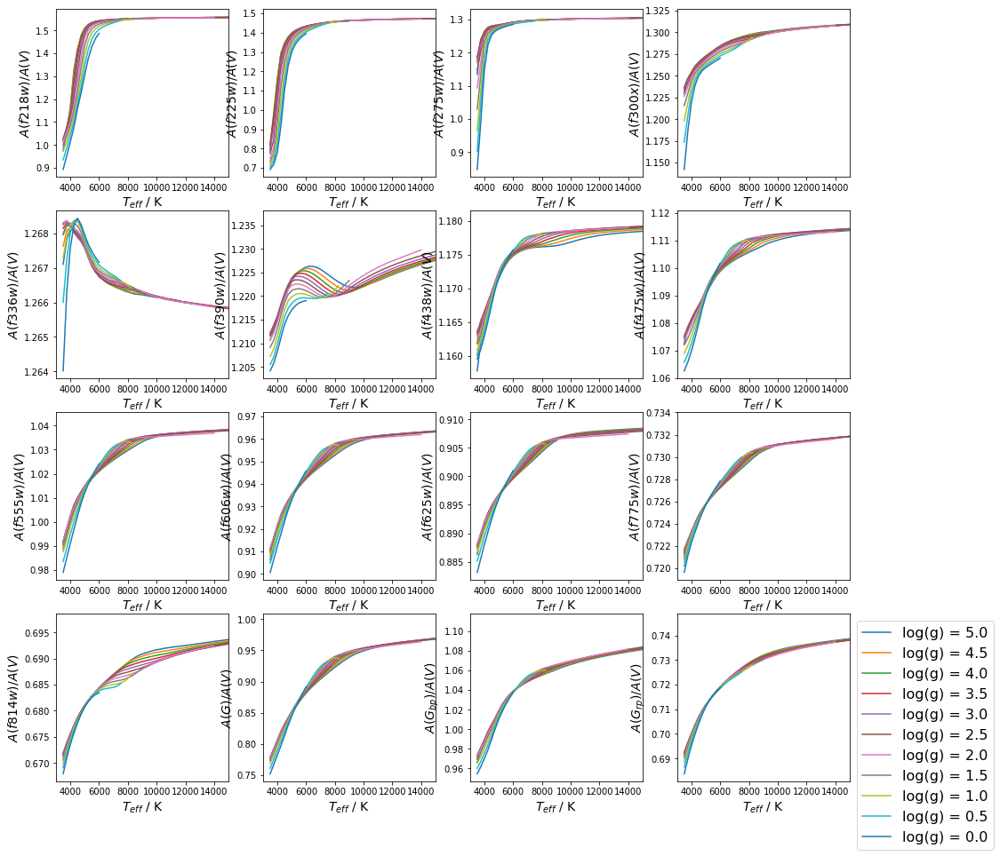

Deleting missing subplots - discrepancy between 7 and 9


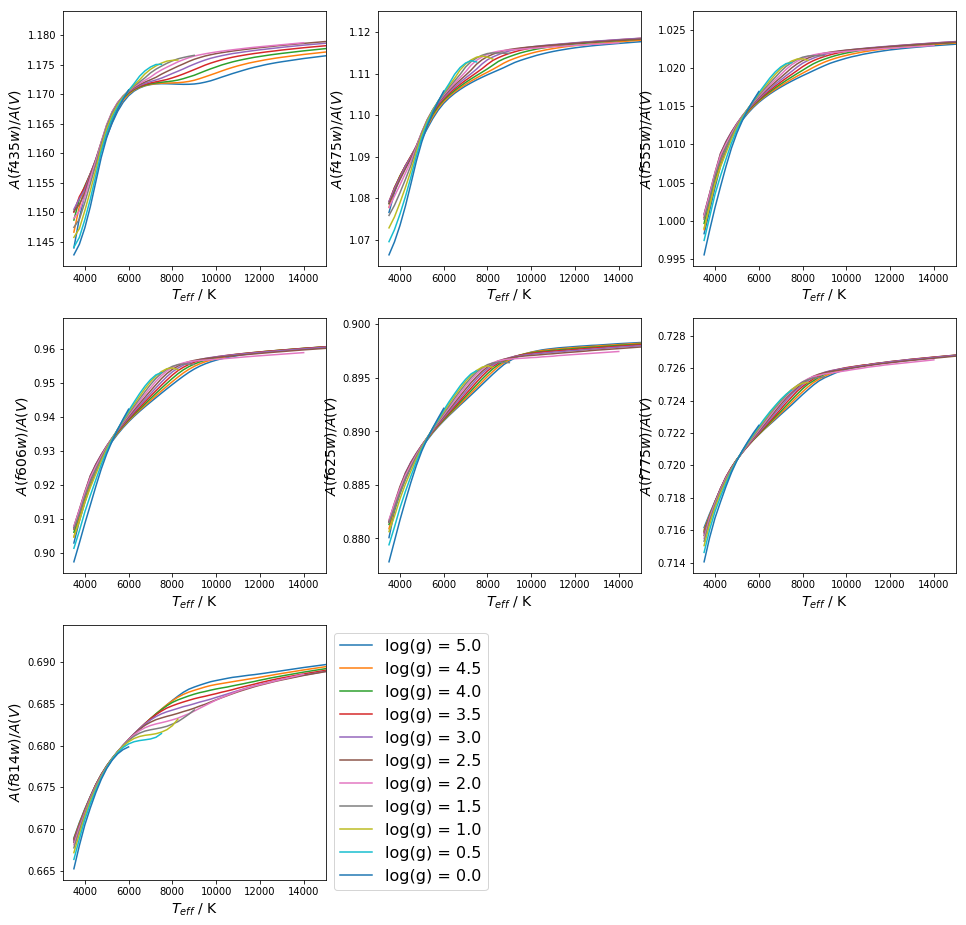

3.1,-2.0


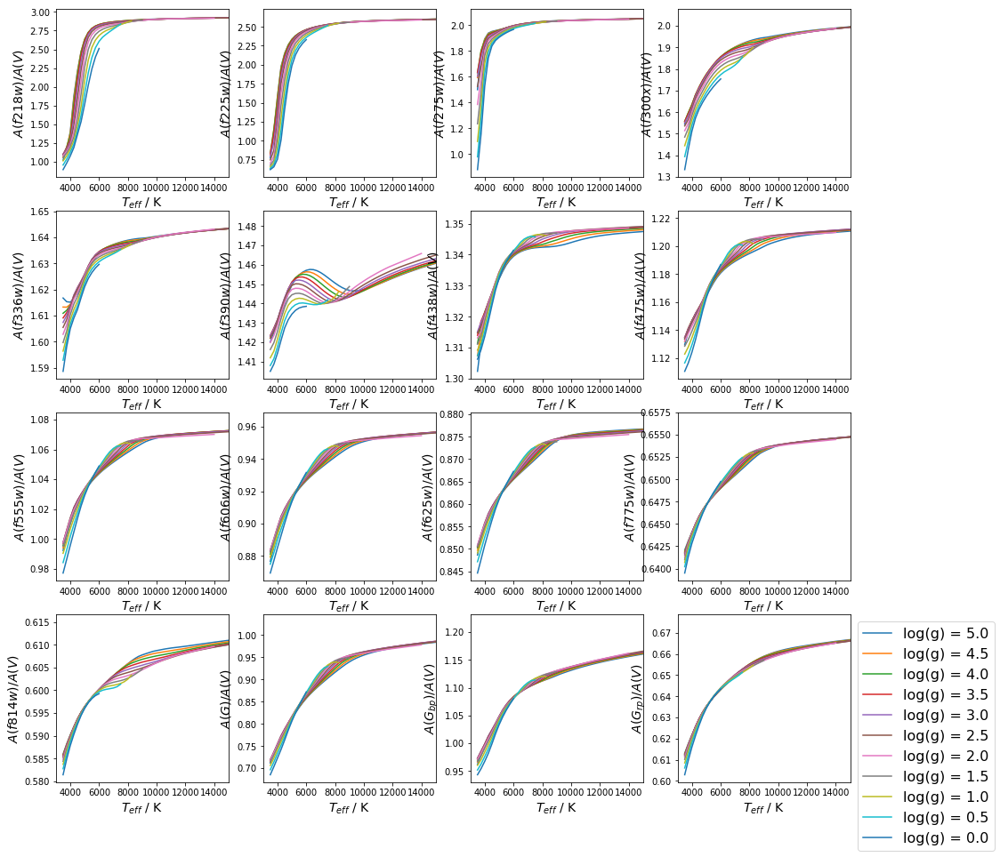

Deleting missing subplots - discrepancy between 7 and 9


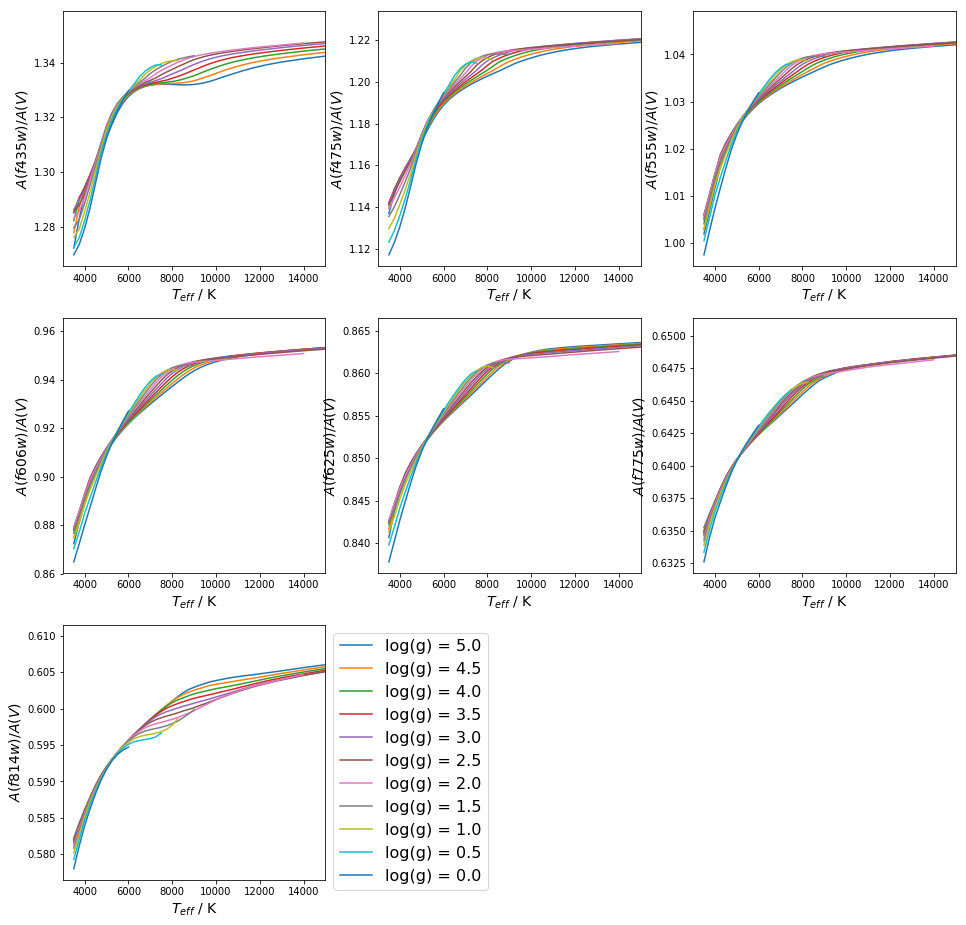

3.1,-1.0


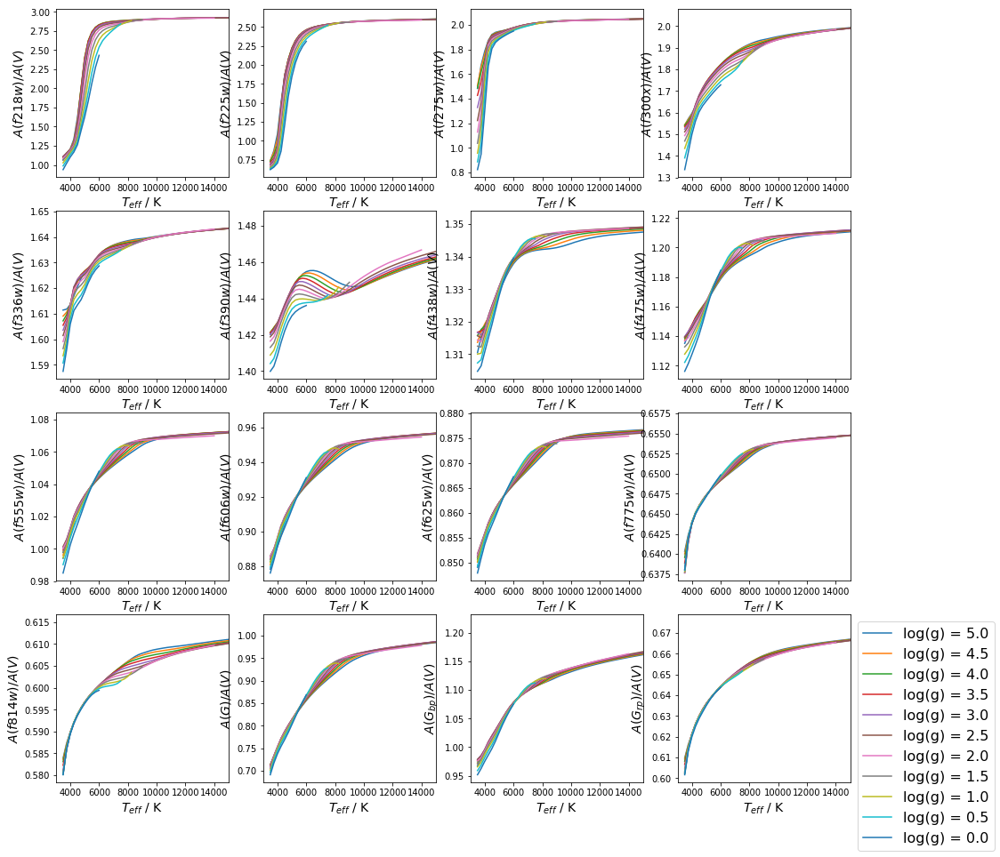

Deleting missing subplots - discrepancy between 7 and 9


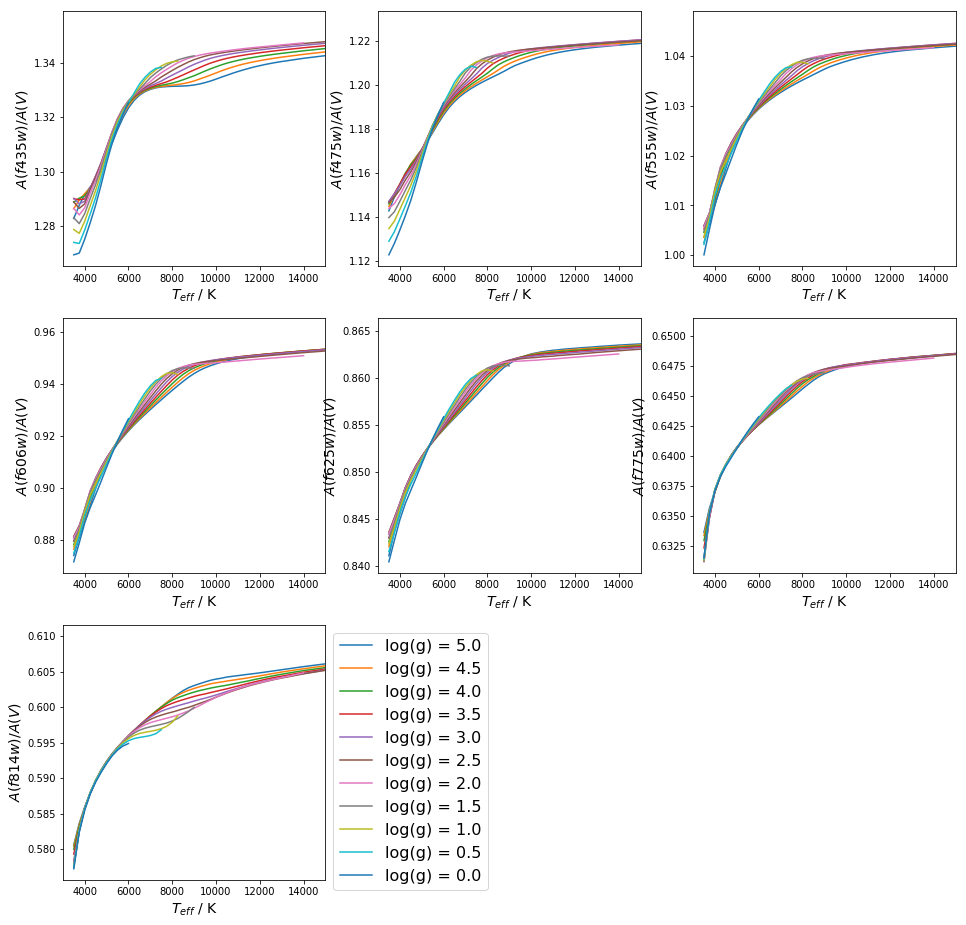

6.0,-1.0


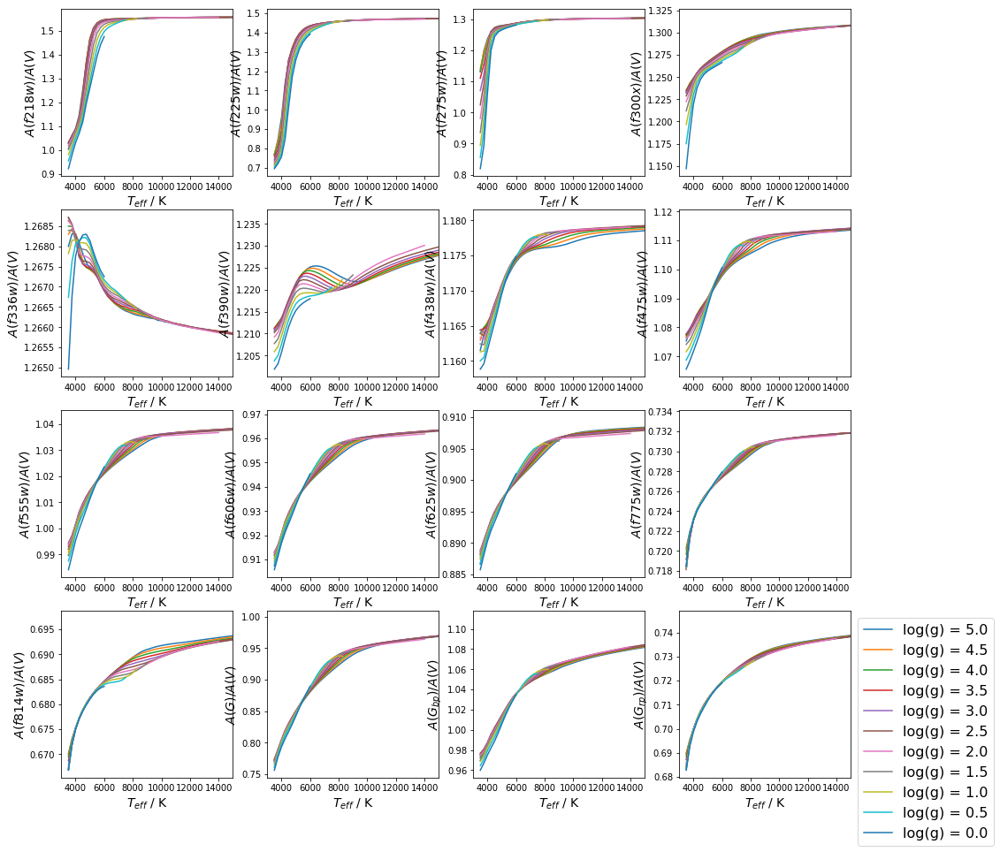

Deleting missing subplots - discrepancy between 7 and 9


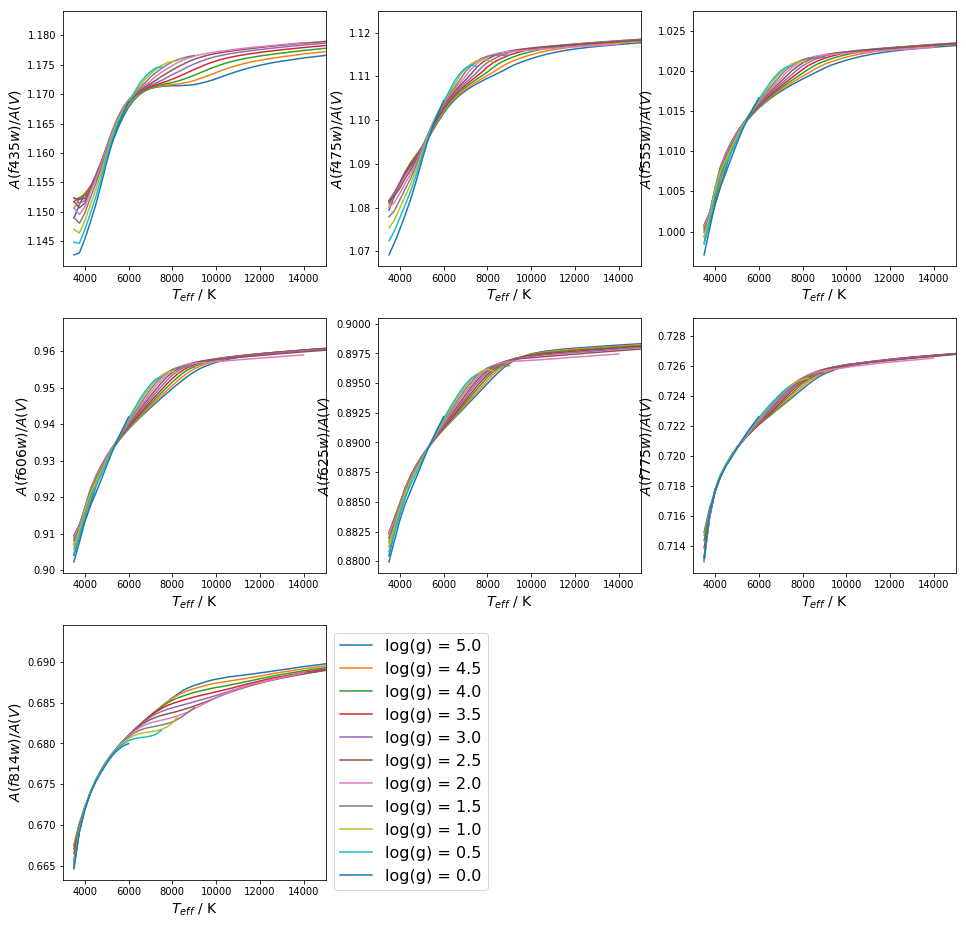

6.0,0.0


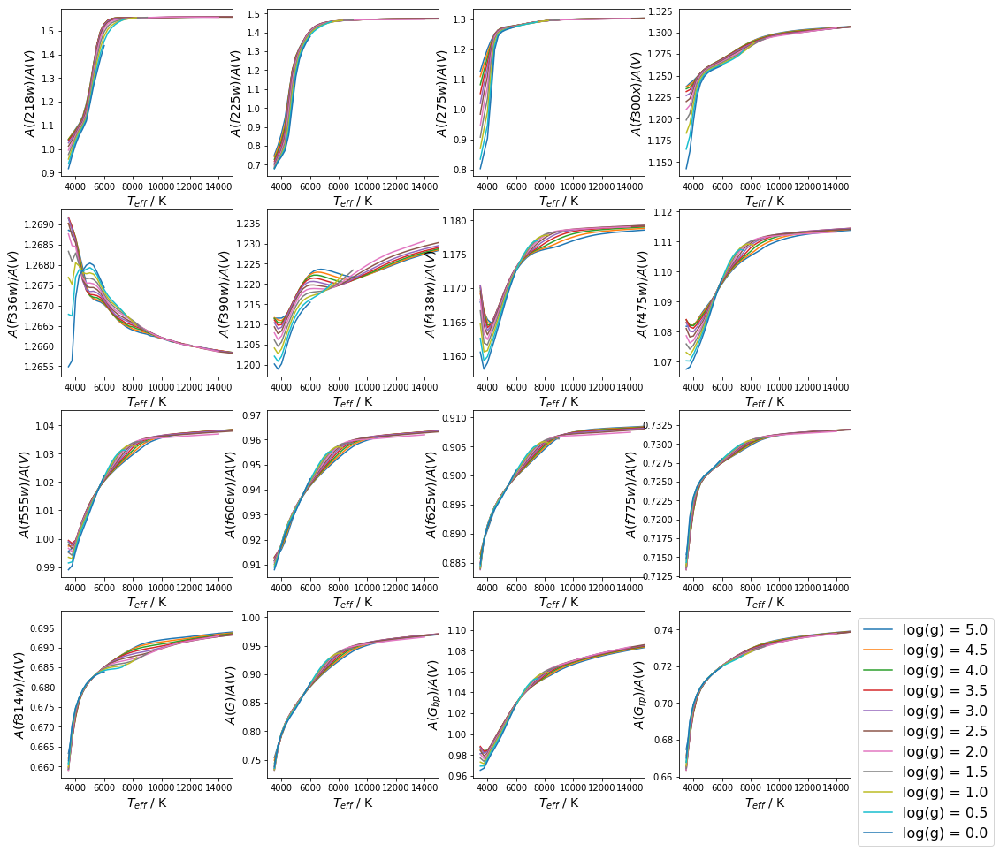

Deleting missing subplots - discrepancy between 7 and 9


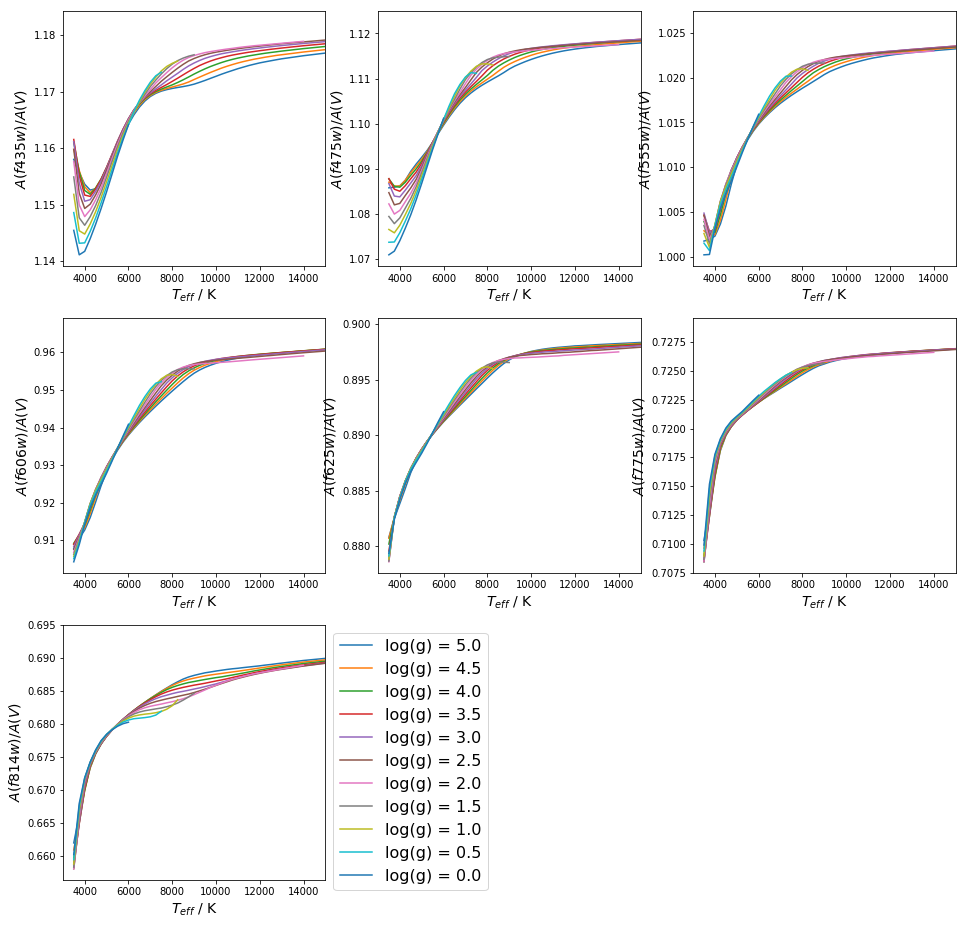

2.0,-1.0


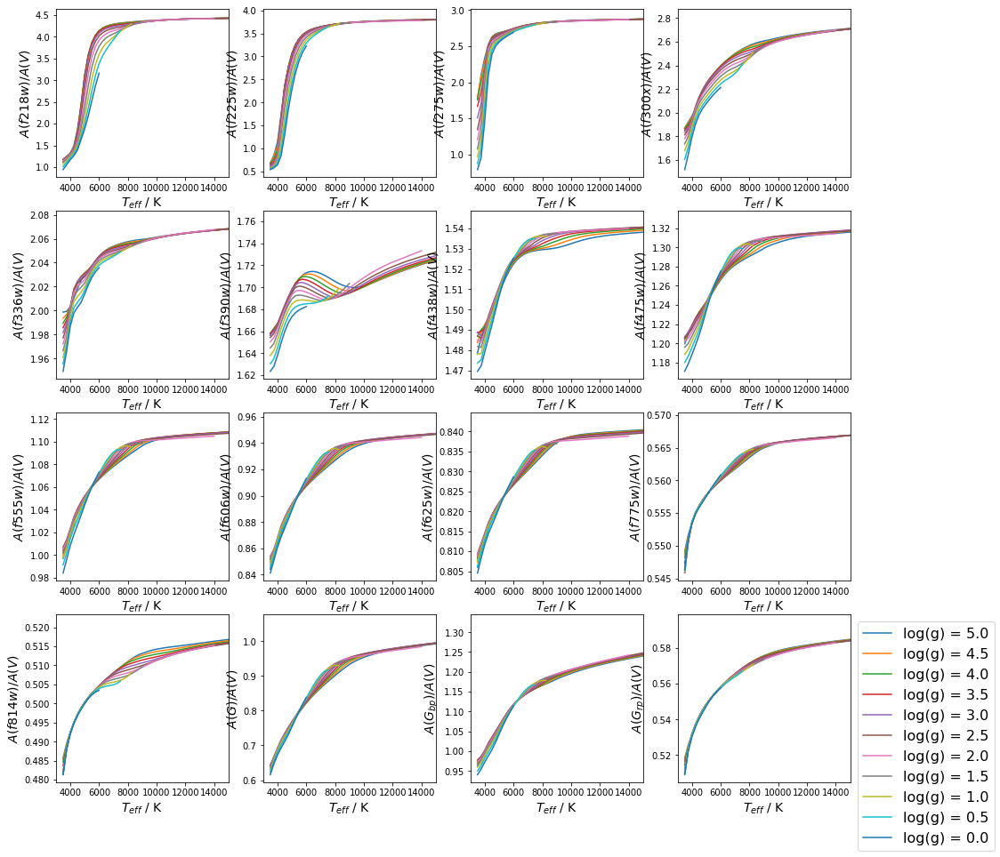

Deleting missing subplots - discrepancy between 7 and 9


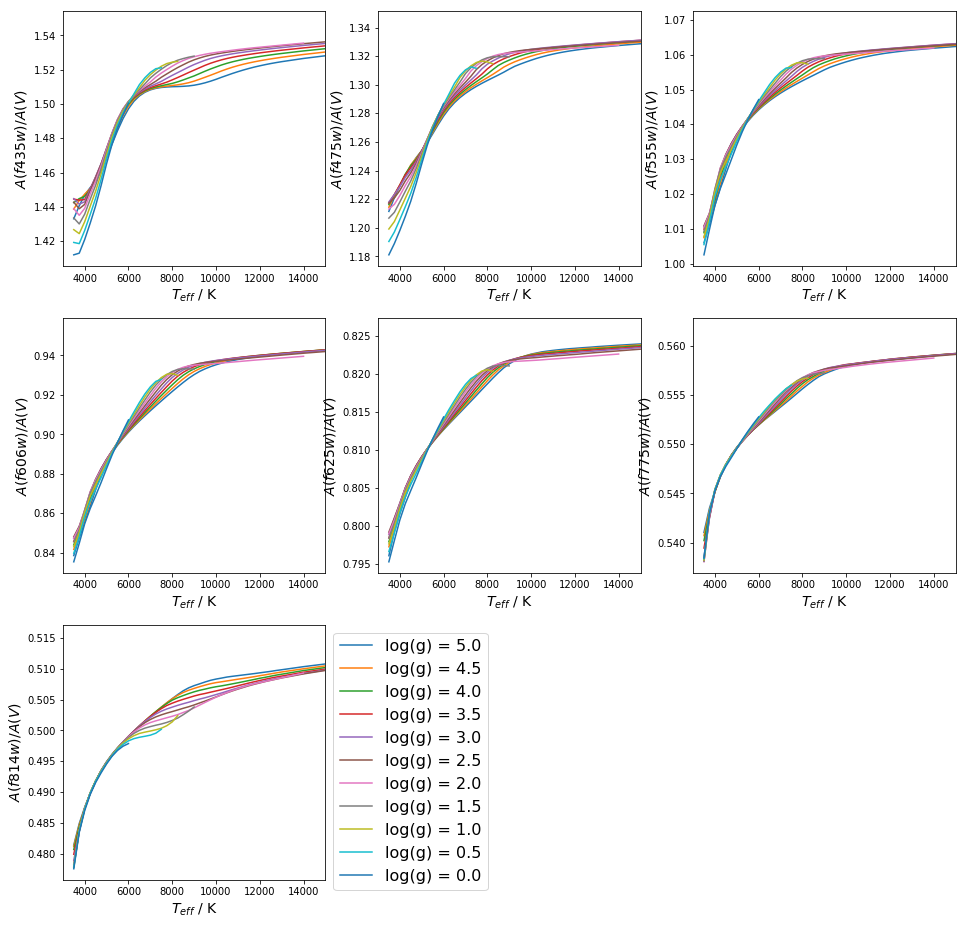

3.1,0.5


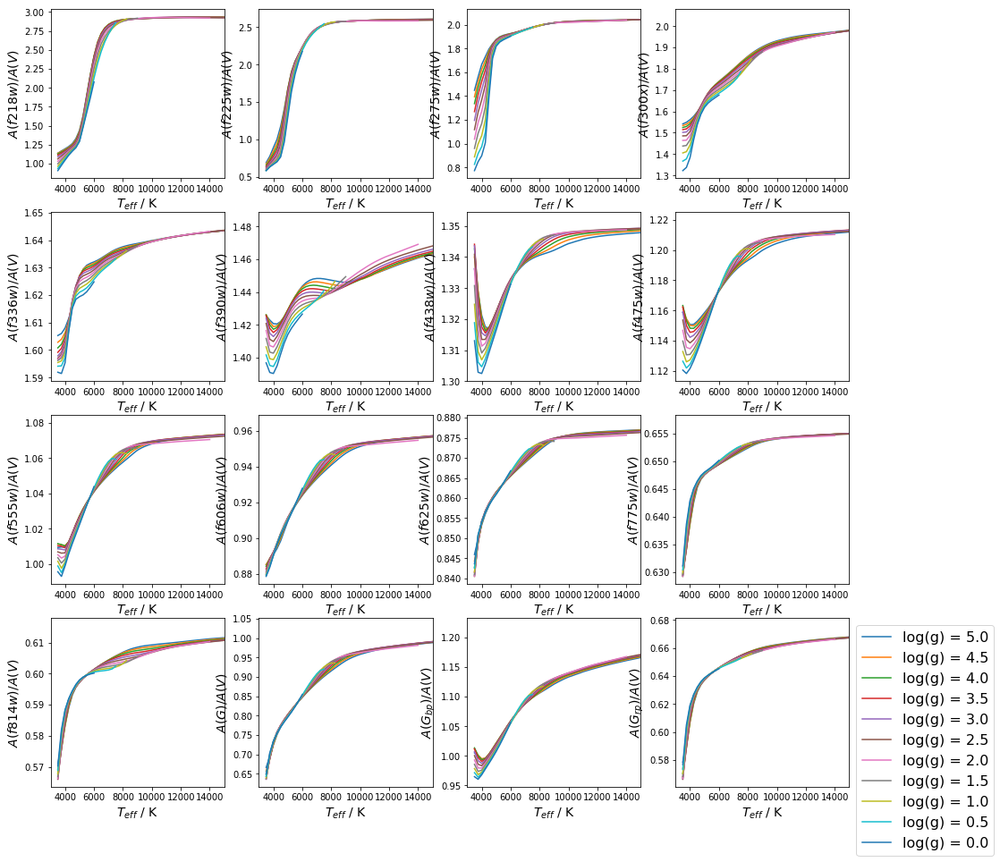

Deleting missing subplots - discrepancy between 7 and 9


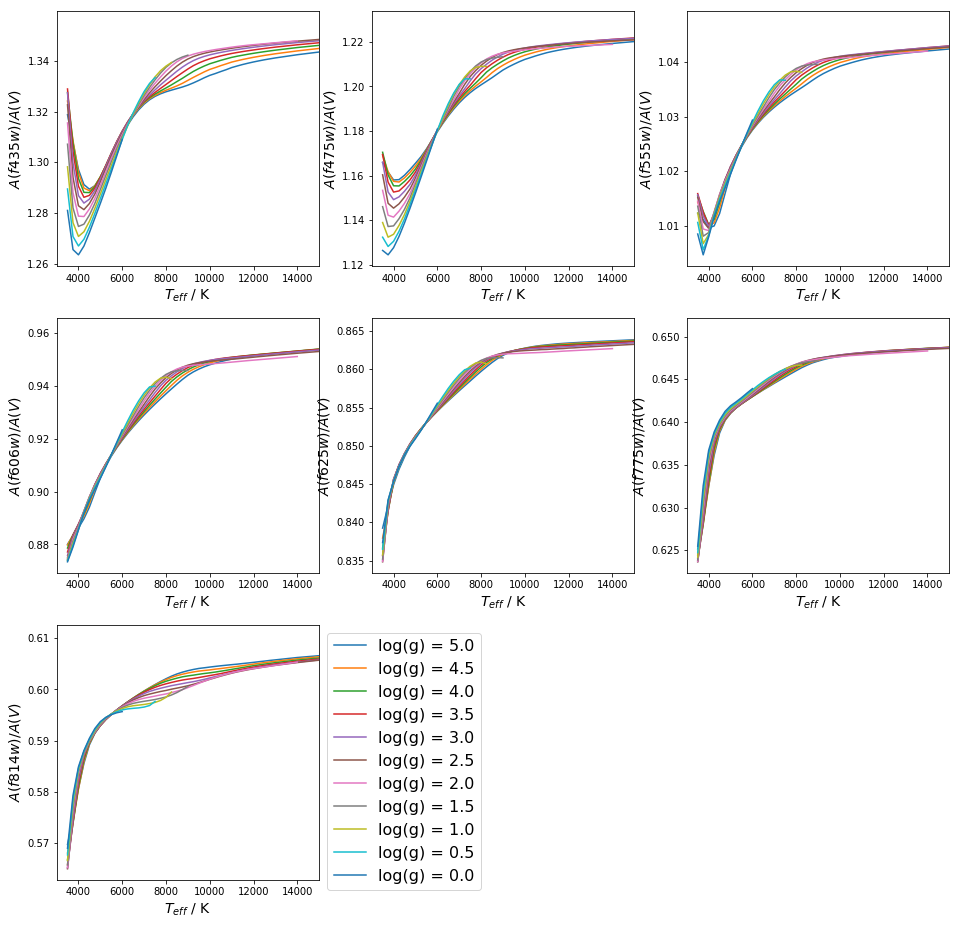

6.0,0.5


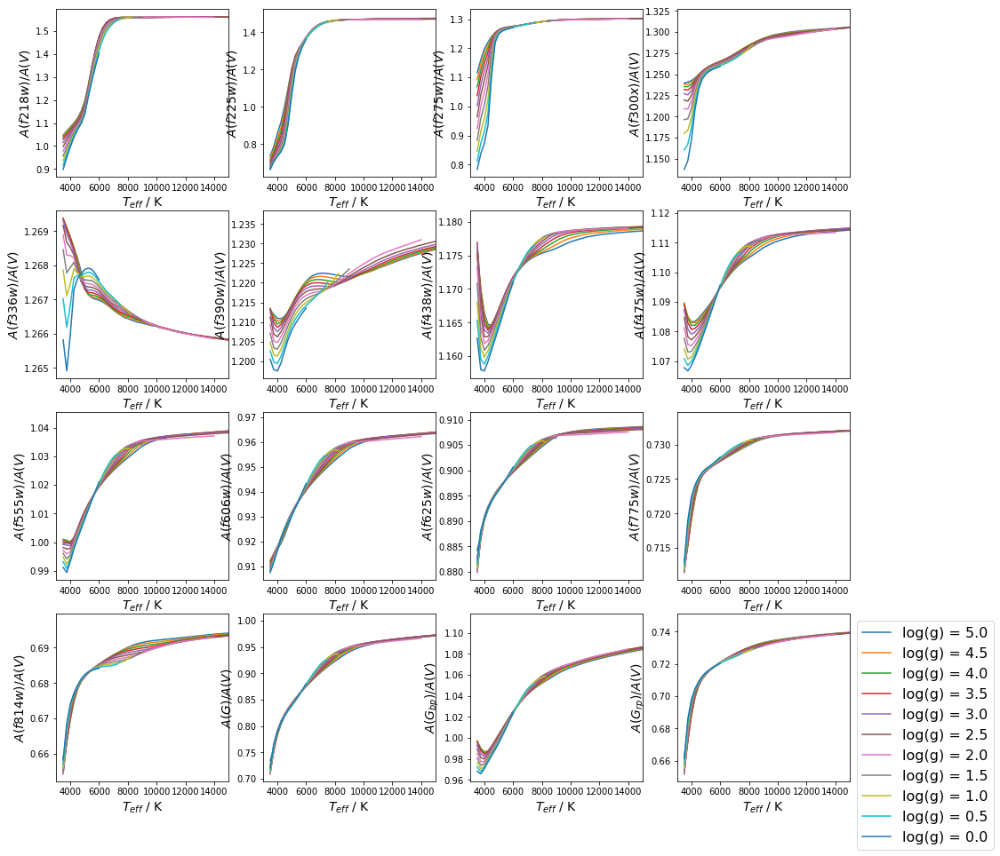

Deleting missing subplots - discrepancy between 7 and 9


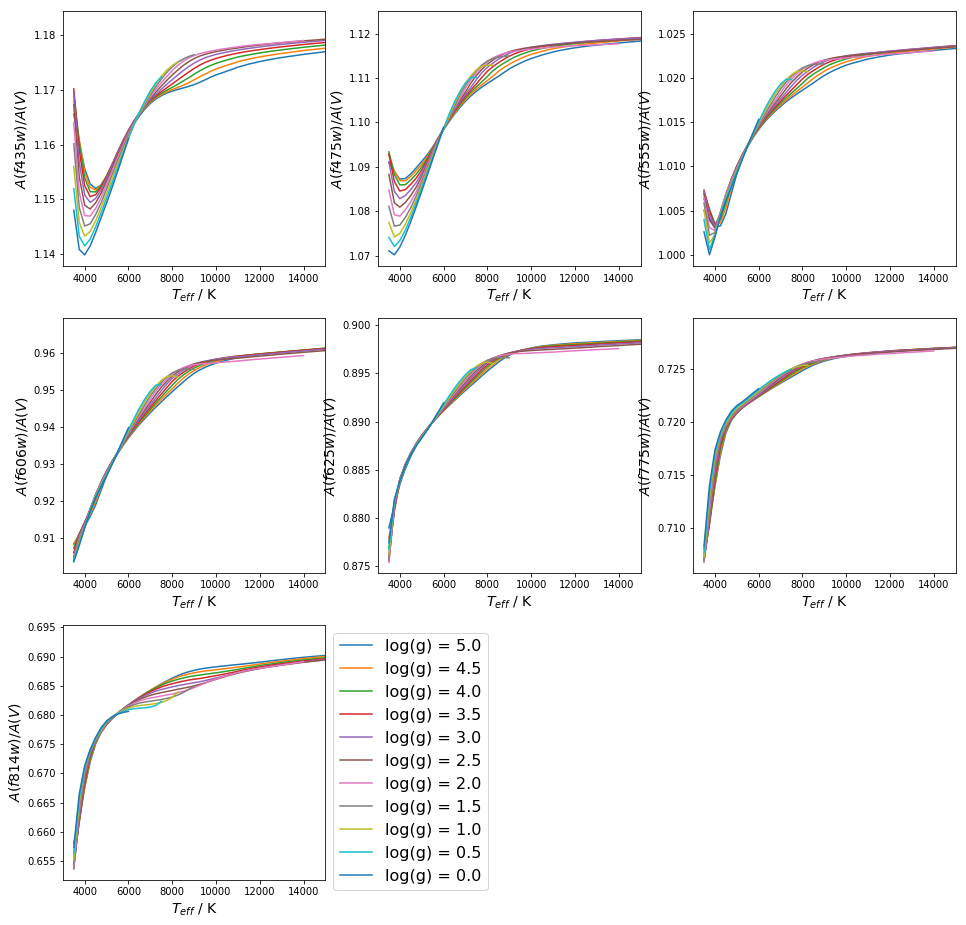

2.0,0.0


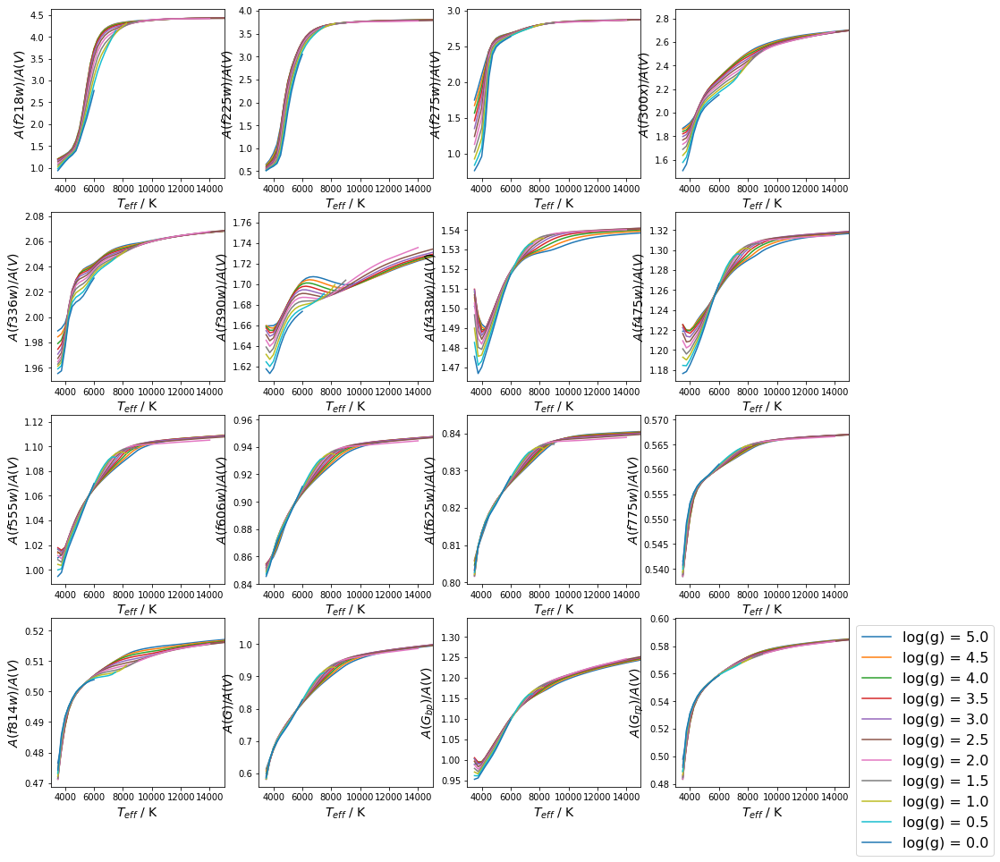

Deleting missing subplots - discrepancy between 7 and 9


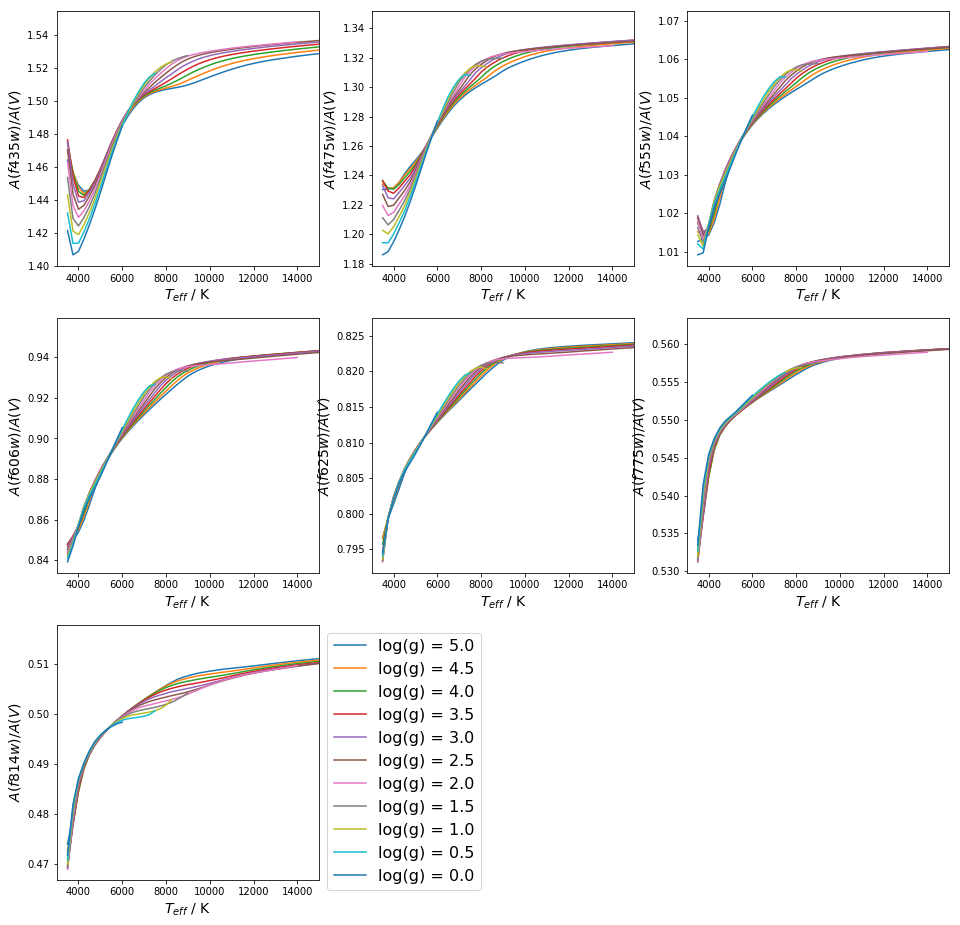

2.0,-2.0


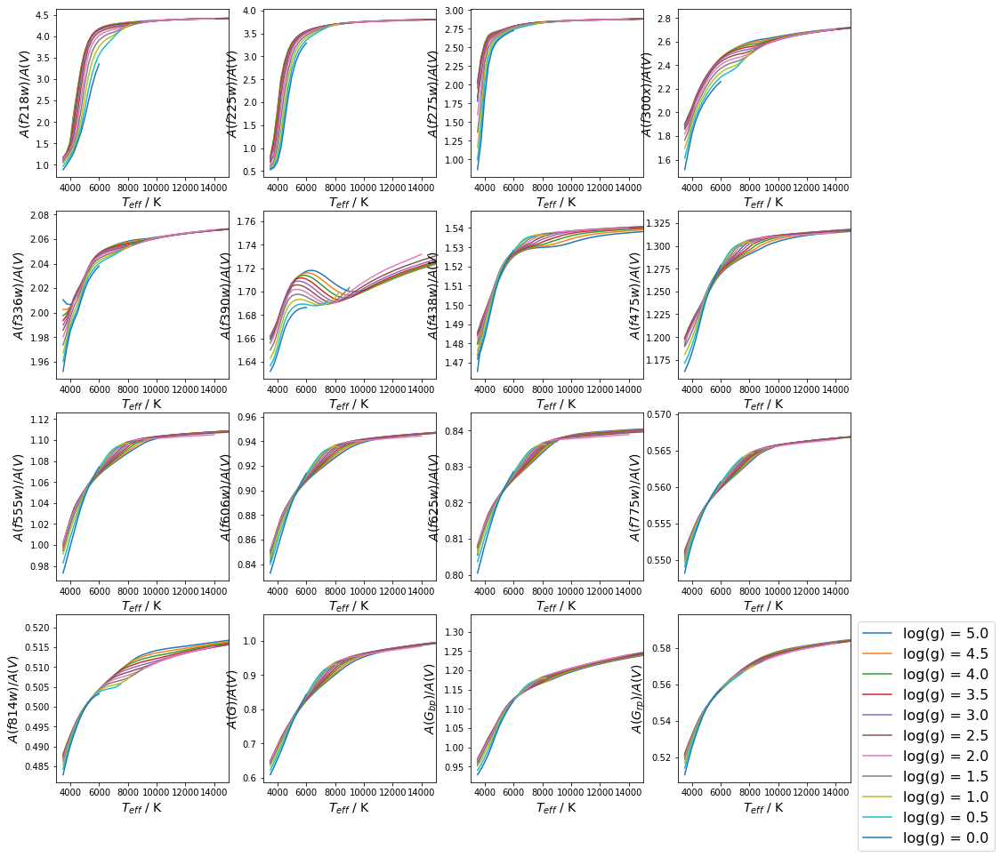

Deleting missing subplots - discrepancy between 7 and 9


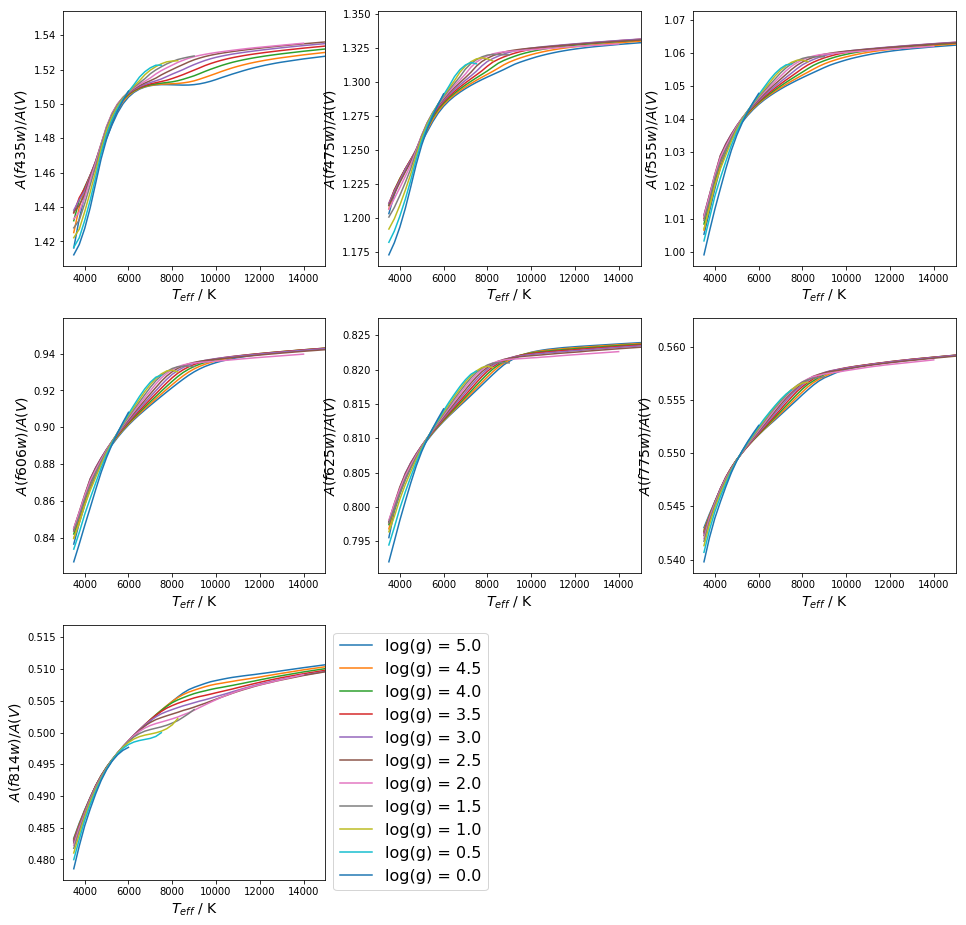

2.0,0.5


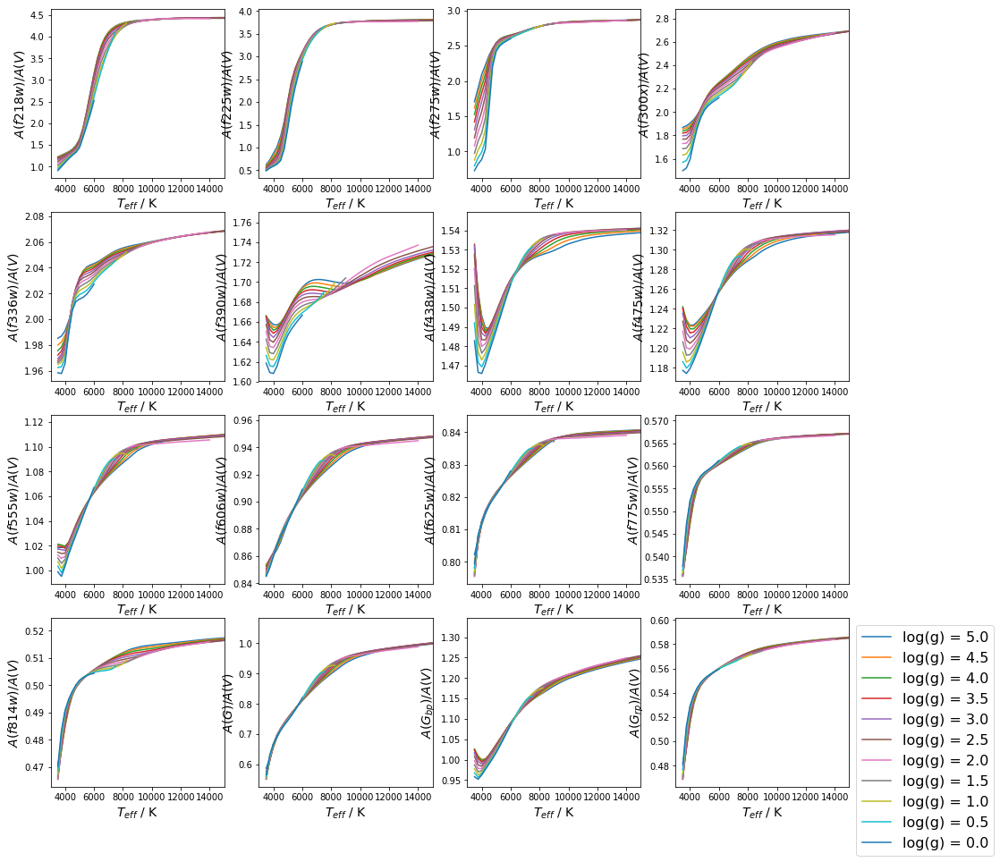

Deleting missing subplots - discrepancy between 7 and 9


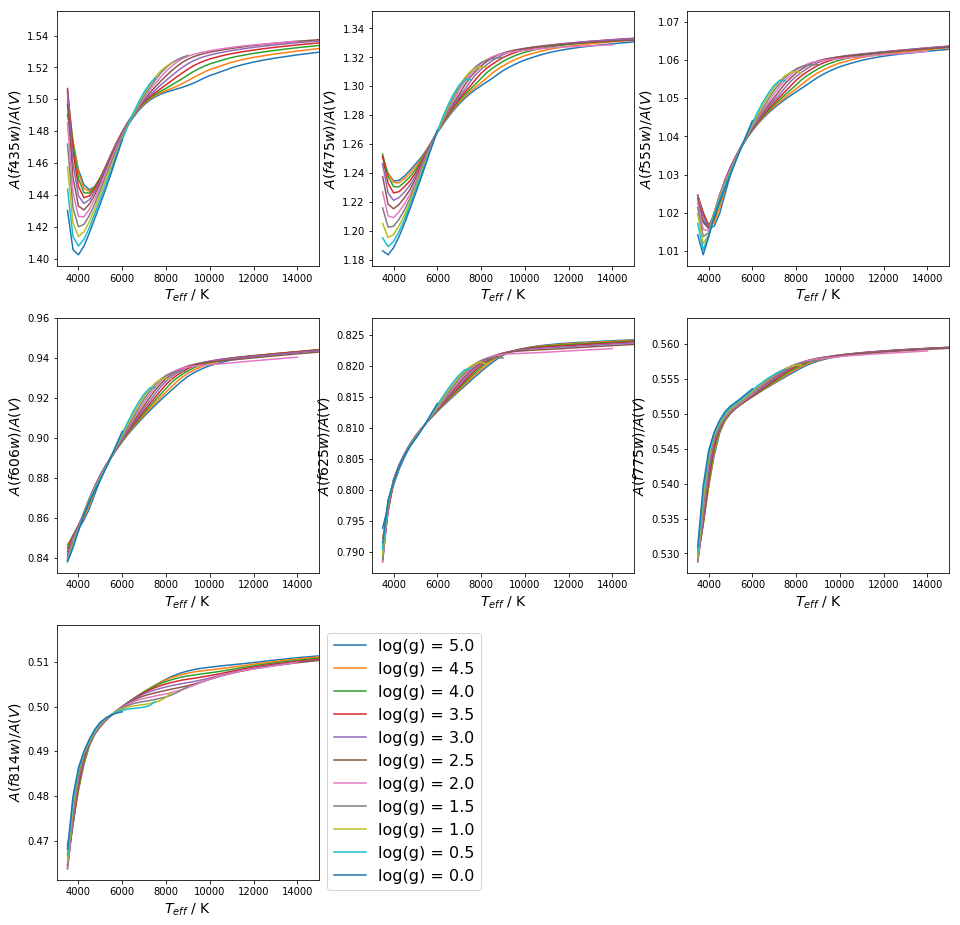

3.1,0.0


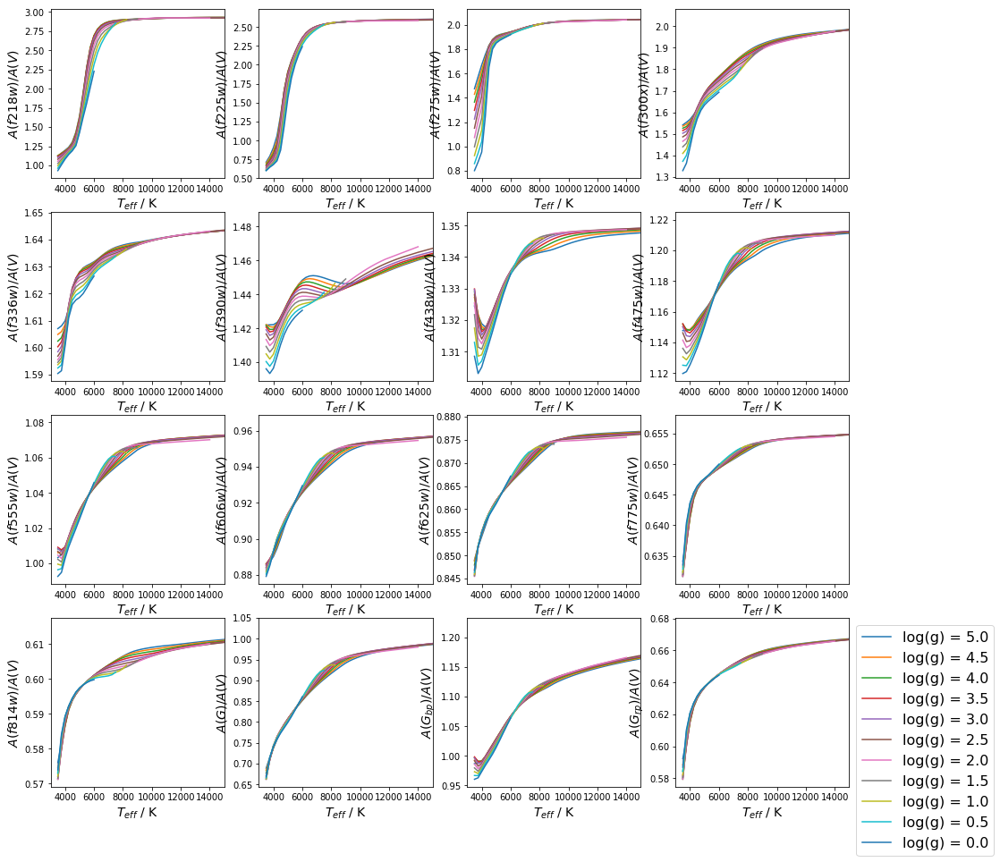

Deleting missing subplots - discrepancy between 7 and 9


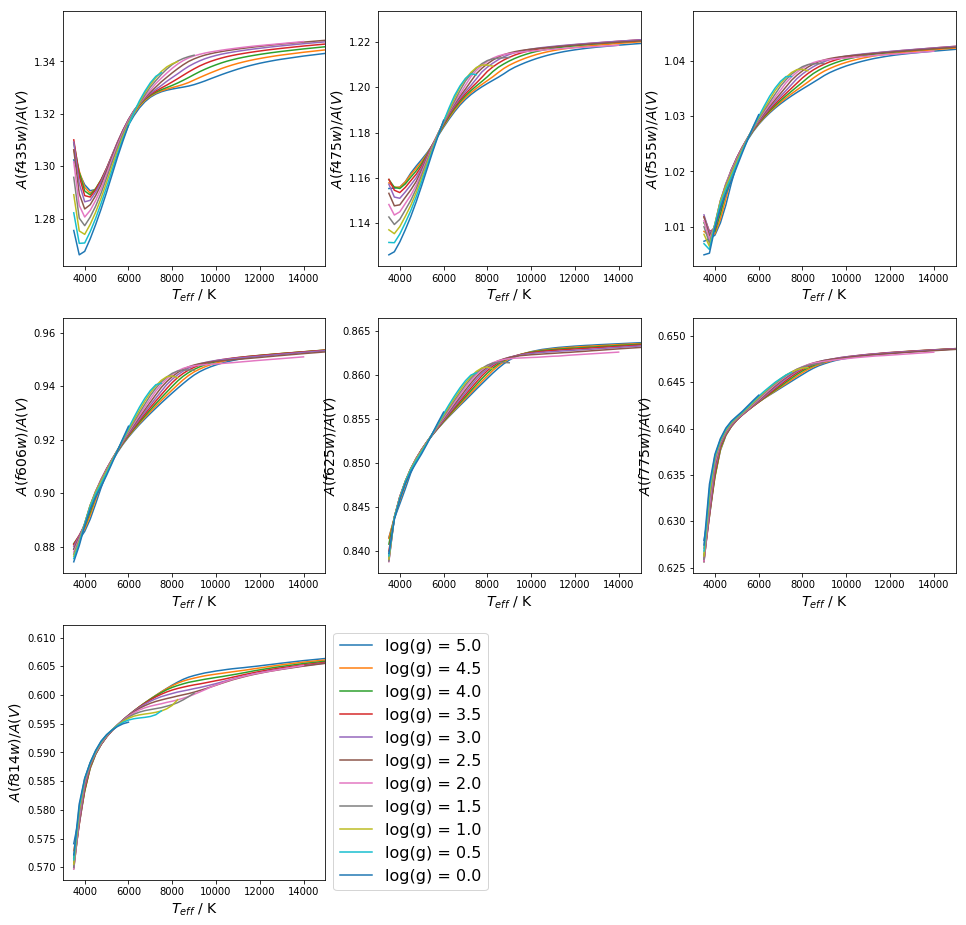

In [33]:
# APRIL 2019: for thesis, just need data: no fits!
# Change font sizes to makes figure legends and axes labels bigger
# NOTE: 10 pt is the default standard font size
plt.rc('axes', labelsize=14)    # fontsize of the x and y labels
plt.rc('legend', fontsize=16)    # legend fontsize

folder_str = 'Rv_varied'
for Rz_key in comb_Ax_Av_dict:
    print Rz_key
    just_fortran_data_plot(comb_Ax_Av_dict,Rz_key,var_names_comb,folder_str+'/just_full_data',graph_fold='/comb',extras='_comb_lines',zoom_min=3000,zoom_max=15000)
    just_fortran_data_plot(ACS_Ax_Av_dict,Rz_key,var_names_ACS,folder_str+'/just_full_data',graph_fold='/ACS',extras='_ACS_lines',zoom_min=3000,zoom_max=15000)
    #,save_stuff='n'

In [11]:
# 4500K Teff data cutoff HUBBLE FILTER PLOTTING
# NOTE: added Rv coefficient bounds to the FRONT of the coefficient lists

# curve fitting: coefficients' bounds
exp_bounds_f218w = ([-1000., -100., -5.], [1., 100., 5.])
pow_bounds_f218w = ([-1.0e+03, -7., -5.], [1., 7., 5.])
# Logistic coefficient format: [Tref,k,b,c]
logis_bounds_f218w = ([-10000., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_f218w = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_f225w = ([-1000., -100., -5.], [1., 100., 5.])
pow_bounds_f225w = ([-1.0e+02, -7., -5.], [1., 7., 5.])
logis_bounds_f225w = ([-10000., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_f225w = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_f275w = ([-1000., -100., -5.], [0., 10., 5.])
pow_bounds_f275w = ([-1.0e+02, -3., -5.], [1., 3., 5.])
logis_bounds_f275w = ([-10000., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_f275w = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_f300x = ([-1000., -100., -5.], [0., 100., 5.])
pow_bounds_f300x = ([-1.0e+02, -2., -5.], [1., 2., 5.])
logis_bounds_f300x = ([-10000., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_f300x = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_f336w = ([-100., -10., -5.], [0., 10., 5.])
pow_bounds_f336w = ([-1.0e+02, -3., -5.], [1., 3., 5.])
logis_bounds_f336w = ([-10000., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_f336w = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_f390w = ([-100., -10., -5.], [0., 10., 5.])
pow_bounds_f390w = ([-1.0e+03, -2., 1.], [1., 2., 3.])
logis_bounds_f390w = ([-10000., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_f390w = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_f438w = ([-100., -10., -3.], [1., 10., 3.])
pow_bounds_f438w = ([-1.0e+02, -2., -5.], [1., 2., 5.])
logis_bounds_f438w = ([-10000., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_f438w = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_f475w = ([-100., -100., -5.], [0., 100., 5.])
pow_bounds_f475w = ([-1.0e+02, -2., -5.], [1., 2., 5.])
logis_bounds_f475w = ([-10000., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_f475w = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_f555w = ([-100., -10., -5.], [0., 10., 5.])
pow_bounds_f555w = ([-1.0e+02, -3., -5.], [1., 1., 5.])
logis_bounds_f555w = ([-10000., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_f555w = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_f606w = ([-100., -10., -5.], [0., 10., 5.])
pow_bounds_f606w = ([-1.0e+02, -3., -5.], [1., 3., 5.])
logis_bounds_f606w = ([-10000., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_f606w = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_f625w = ([-100., -100., -5.], [1., 100., 5.])
pow_bounds_f625w = ([-1.0e+01, -3., -5.], [1., 3., 5.])
logis_bounds_f625w = ([-10000., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_f625w = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_f775w = ([-100., -10., -5.], [1., 10., 5.])
pow_bounds_f775w = ([-1.0e+01, -3., -5.], [1., 3., 5.])
logis_bounds_f775w = ([-10000., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_f775w = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_f814w = ([-100., -100., -5.], [1., 100., 5.])
pow_bounds_f814w = ([-1.0e+01, -3., -5.], [1., 3., 5.])
logis_bounds_f814w = ([0., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_f814w = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_G = ([-100., -10., -5.], [1., 10., 5.])
pow_bounds_G = ([-1.0e+01, -3., -5.], [1., 3., 5.])
logis_bounds_G = ([0.,  0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_G = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_Gbp = ([-100., -10., -5.], [1., 10., 5.])
pow_bounds_Gbp = ([-1.0e+01, -3., -5.], [1., 3., 5.])
logis_bounds_Gbp = ([0., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_Gbp = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

exp_bounds_Grp = ([-100., -10., -5.], [1., 10., 5.])
pow_bounds_Grp = ([-1.0e+01, -3., -5.], [1., 3., 5.])
logis_bounds_Grp = ([0., 0., 0., -5.], [10000., 1000., 3.00, 2.])
plog_bounds_Grp = ([-10., 0., 0., -5.], [2., 10., 10., 2.])

# make array of bounds
exp_bounds = [exp_bounds_f218w,exp_bounds_f225w,exp_bounds_f275w,exp_bounds_f300x,exp_bounds_f336w,exp_bounds_f390w,\
              exp_bounds_f438w,exp_bounds_f475w,exp_bounds_f555w,exp_bounds_f606w,exp_bounds_f625w,exp_bounds_f775w,\
              exp_bounds_f814w,exp_bounds_G,exp_bounds_Gbp,exp_bounds_Grp]
pow_bounds = [pow_bounds_f218w,pow_bounds_f225w,pow_bounds_f275w,pow_bounds_f300x,pow_bounds_f336w,pow_bounds_f390w,\
              pow_bounds_f438w,pow_bounds_f475w,pow_bounds_f555w,pow_bounds_f606w,pow_bounds_f625w,pow_bounds_f775w,\
              pow_bounds_f814w,pow_bounds_G,pow_bounds_Gbp,pow_bounds_Grp]
logis_bounds = [logis_bounds_f218w,logis_bounds_f225w,logis_bounds_f275w,logis_bounds_f300x,logis_bounds_f336w,\
                logis_bounds_f390w,logis_bounds_f438w,logis_bounds_f475w,logis_bounds_f555w,logis_bounds_f606w,\
                logis_bounds_f625w,logis_bounds_f775w,logis_bounds_f814w,logis_bounds_G,logis_bounds_Gbp,logis_bounds_Grp]
plog_bounds = [plog_bounds_f218w,plog_bounds_f225w,plog_bounds_f275w,plog_bounds_f300x,plog_bounds_f336w,\
               plog_bounds_f390w,plog_bounds_f438w,plog_bounds_f475w,plog_bounds_f555w,plog_bounds_f606w,\
               plog_bounds_f625w,plog_bounds_f775w,plog_bounds_f814w,plog_bounds_G,plog_bounds_Gbp,plog_bounds_Grp]

# produce fitting results - leave key at '5.0'!!!

print 'SOLAR METALLICITY FITTING'
sigma_val = 0.01
p0_logis_45 = [5000.0, 25., 2.93, 1.1]
p0_plog_45 = [0., 1., 2.93, 1.1]

#keyvals = '6.0,0.0'
combined_list_coef_stdev_zs_4500K = {}
comb_dict_list_coef_stdev_zs_4500K = {}
for keyvals in sorted(comb_Ax_Av_dict_4500K.iterkeys()):
    print keyvals
    find_metal = re.search(',(.*)',keyvals)
    if find_metal:
        metal = float(find_metal.group(1))
    find_Rv = re.search('(.*),',keyvals)
    if find_Rv:
        Rv = float(find_Rv.group(1))
    combined_list_coef_stdev_zs_4500K[keyvals],comb_dict_list_coef_stdev_zs_4500K[keyvals] = filter_curve_fit(comb_Ax_Av_dict_4500K[keyvals],Rv,'5.0',exp_bounds,pow_bounds,logis_bounds,\
                                                                                            plog_bounds,comb_filter_str,sigma_val,'y',p0_opt_logis=p0_logis_45,\
                                                                                            p0_opt_plog=p0_plog_45,niter=10000*len(comb_Ax_Av_dict_4500K[keyvals]['5.0'][:,0]))
    print 'List of lists of arrays, length ',len(combined_list_coef_stdev_zs_4500K[keyvals]),len(comb_dict_list_coef_stdev_zs_4500K[keyvals])
print 'Number of Rv,metallicity combinations processed',len(combined_list_coef_stdev_zs_4500K),len(comb_dict_list_coef_stdev_zs_4500K)

SOLAR METALLICITY FITTING
2.0,-1.0
Calculating coefficients & covariance matrices for f218w filter
Exponential fit coefficients: 
[-1000.      -13.2337    4.4251]
Standard deviations: 
[  3.6042e+01   7.5932e-02   1.2931e-03]
Teff^(n) fit coefficients: 
[-0.0112 -6.847   4.4306]
Standard deviations: 
[ 0.0003  0.0372  0.0013]
Logistic fit coefficients: 
[  4.7523e+03   5.0021e+02   3.0000e+00   1.8696e+00]
Standard deviations: 
[  3.9122e+02   8.5772e+04   1.2039e-03   1.2815e-02]
Teff log-normal fit coefficients: 
[ 0.      5.4426  4.1479  2.    ]
Standard deviations: 
[  0.0000e+00   3.0231e+00   1.4294e-03   1.1724e+00]



Calculating coefficients & covariance matrices for f225w filter
Exponential fit coefficients: 
[-116.2507   -9.8614    3.8171]
Standard deviations: 
[  5.4616e+00   9.6789e-02   1.3394e-03]
Teff^(n) fit coefficients: 
[-0.0269 -4.9516  3.8278]
Standard deviations: 
[ 0.0009  0.0452  0.0014]
Logistic fit coefficients: 
[  4.5886e+03   8.4979e+01   3.0000e+00   2.00

[  0.0000e+00   1.4652e+01   1.4292e-03   3.9702e+00]



Calculating coefficients & covariance matrices for f225w filter
Exponential fit coefficients: 
[-10.4496  -5.7293   3.832 ]
Standard deviations: 
[ 0.4382  0.0818  0.0015]
Teff^(n) fit coefficients: 
[-0.0651 -3.2078  3.8444]
Standard deviations: 
[ 0.002   0.0422  0.0017]
Logistic fit coefficients: 
[  4.4181e+03   4.0662e+02   3.0000e+00  -1.9948e-01]
Standard deviations: 
[  7.7769e+08   4.7785e+07   1.2039e-03   9.6472e+07]
Teff log-normal fit coefficients: 
[ 0.      7.3574  3.6639  2.    ]
Standard deviations: 
[  0.0000e+00   1.2910e+01   1.4293e-03   2.8917e+00]



Calculating coefficients & covariance matrices for f275w filter
Exponential fit coefficients: 
[-337.3036  -62.9084    2.8645]
Standard deviations: 
[ 0.      0.      0.0012]
Teff^(n) fit coefficients: 
[-0.0499 -1.8669  2.9089]
Standard deviations: 
[ 0.0034  0.0925  0.0024]
Logistic fit coefficients: 
[ -7.7310e+03   2.9923e+00   2.9010e+00  -5.0000e+00]
Stan

Calculating coefficients & covariance matrices for f225w filter
Exponential fit coefficients: 
[-197.3477   -9.8742    3.8233]
Standard deviations: 
[  5.5018e+00   5.7441e-02   1.3392e-03]
Teff^(n) fit coefficients: 
[-0.0397 -5.1286  3.8362]
Standard deviations: 
[ 0.0008  0.0279  0.0014]
Logistic fit coefficients: 
[  4.8268e+03   5.1782e+01   3.0000e+00   1.2145e+00]
Standard deviations: 
[  9.8581e+00   1.4676e+00   1.2233e-03   3.2962e-02]
Teff log-normal fit coefficients: 
[ 0.      3.3318  3.5072  2.    ]
Standard deviations: 
[ 0.      0.6263  0.0014  0.2707]



Calculating coefficients & covariance matrices for f275w filter
Exponential fit coefficients: 
[-2.0997 -3.7579  2.8971]
Standard deviations: 
[ 0.1102  0.0965  0.0016]
Teff^(n) fit coefficients: 
[-0.0659 -2.3304  2.9062]
Standard deviations: 
[ 0.0028  0.0584  0.002 ]
Logistic fit coefficients: 
[ -3.2152e+03   3.8514e+00   2.8969e+00  -5.0000e+00]
Standard deviations: 
[  8.5132e+03   3.0400e-01   1.7093e-03   2.306

Calculating coefficients & covariance matrices for f225w filter
Exponential fit coefficients: 
[-119.0151   -8.4434    3.8342]
Standard deviations: 
[  2.3810e+00   4.0647e-02   1.3718e-03]
Teff^(n) fit coefficients: 
[-0.0742 -4.5276  3.8517]
Standard deviations: 
[ 0.0011  0.0204  0.0015]
Logistic fit coefficients: 
[  5.0224e+03   4.3362e+01   3.0000e+00   1.0952e+00]
Standard deviations: 
[  7.6088e+00   9.1041e-01   1.2353e-03   2.0975e-02]
Teff log-normal fit coefficients: 
[ 0.      2.4824  3.4286  2.    ]
Standard deviations: 
[ 0.      0.2128  0.0014  0.113 ]



Calculating coefficients & covariance matrices for f275w filter
Exponential fit coefficients: 
[-2.5208 -3.7809  2.8963]
Standard deviations: 
[ 0.1121  0.0818  0.0016]
Teff^(n) fit coefficients: 
[-0.0768 -2.3561  2.9066]
Standard deviations: 
[ 0.0027  0.0497  0.002 ]
Logistic fit coefficients: 
[-2671.5312     3.891      2.896     -5.    ]
Standard deviations: 
[  6.0279e+03   2.5808e-01   1.7061e-03   1.6230e+01]
T

Calculating coefficients & covariance matrices for f225w filter
Exponential fit coefficients: 
[-49.6102  -9.5023   2.6075]
Standard deviations: 
[  4.4373e+00   1.8368e-01   1.3466e-03]
Teff^(n) fit coefficients: 
[-0.0155 -4.7792  2.6134]
Standard deviations: 
[ 0.001   0.0857  0.0014]
Logistic fit coefficients: 
[ 2186.349     10.0031     2.607     -5.    ]
Standard deviations: 
[  1.3651e+03   5.8438e-01   1.3902e-03   8.6226e+00]
Teff log-normal fit coefficients: 
[ 0.      3.3255  2.5055  2.    ]
Standard deviations: 
[  0.0000e+00   1.8534e+00   1.4301e-03   2.6915e-01]



Calculating coefficients & covariance matrices for f275w filter
Exponential fit coefficients: 
[-0.534  -3.0697  2.0612]
Standard deviations: 
[ 0.065   0.2162  0.0017]
Teff^(n) fit coefficients: 
[-0.032  -1.9205  2.0662]
Standard deviations: 
[ 0.0033  0.141   0.0023]
Logistic fit coefficients: 
[ -8.2214e+03   3.1019e+00   2.0612e+00  -5.0000e+00]
Standard deviations: 
[  7.4321e+04   7.0862e-01   1.7905e-0

Calculating coefficients & covariance matrices for f275w filter
Exponential fit coefficients: 
[-0.3933 -2.8969  2.0616]
Standard deviations: 
[ 0.0567  0.2534  0.0017]
Teff^(n) fit coefficients: 
[-0.0276 -1.8324  2.066 ]
Standard deviations: 
[ 0.0034  0.1697  0.0024]
Logistic fit coefficients: 
[ -9.8044e+03   2.9207e+00   2.0616e+00  -5.0000e+00]
Standard deviations: 
[  1.2368e+05   8.4370e-01   1.8174e-03   2.4355e+02]
Teff log-normal fit coefficients: 
[ 0.      0.4471  2.0276  1.9887]
Standard deviations: 
[ 0.      0.0705  0.0015  0.0036]



Calculating coefficients & covariance matrices for f300x filter
Exponential fit coefficients: 
[-0.8876 -2.5433  2.0318]
Standard deviations: 
[ 0.0427  0.0824  0.0018]
Teff^(n) fit coefficients: 
[-0.0855 -1.6589  2.046 ]
Standard deviations: 
[ 0.0038  0.0589  0.0027]
Logistic fit coefficients: 
[ -7.7391e+03   2.5967e+00   2.0316e+00  -5.0000e+00]
Standard deviations: 
[  2.0515e+04   2.8700e-01   1.8817e-03   3.3808e+01]
Teff log-norma

... (2 outputs left out)

Calculating coefficients & covariance matrices for f300x filter
Exponential fit coefficients: 
[-0.1521 -2.2992  1.3163]
Standard deviations: 
[ 0.0349  0.3863  0.0018]
Teff^(n) fit coefficients: 
[-0.019  -1.4817  1.3199]
Standard deviations: 
[ 0.0042  0.2888  0.0031]
Logistic fit coefficients: 
[ -1.0000e+04   2.3513e+00   1.3163e+00  -3.6893e-01]
Standard deviations: 
[  1.4708e+05   1.3876e+00   1.9479e-03   5.3410e+01]
Teff log-normal fit coefficients: 
[ 0.      0.471   1.2963  1.2745]
Standard deviations: 
[ 0.      0.1334  0.0015  0.0037]



Calculating coefficients & covariance matrices for f336w filter
Exponential fit coefficients: 
[ -8.8229e-16  -1.0000e+01   1.2660e+00]
Standard deviations: 
[ 0.5991  0.      0.0013]
Teff^(n) fit coefficients: 
[ -3.7337e+00   1.9671e-04   5.0000e+00]
Standard deviations: 
[  1.2710e+05   6.6954e+00   1.2710e+05]
Logistic fit coefficients: 
[ -1.0000e+04   2.2896e+00   1.2655e+00   1.3247e+00]
Standard deviations: 
[  3.6310e+06   3.5451e

Calculating coefficients & covariance matrices for f300x filter
Exponential fit coefficients: 
[-0.1269 -2.2121  1.3164]
Standard deviations: 
[ 0.0324  0.4275  0.0018]
Teff^(n) fit coefficients: 
[-0.0171 -1.4409  1.3197]
Standard deviations: 
[ 0.0044  0.3261  0.0032]
Logistic fit coefficients: 
[ -1.0000e+04   2.2699e+00   1.3164e+00   1.1750e-02]
Standard deviations: 
[  1.5751e+05   1.5541e+00   1.9760e-03   4.2378e+01]
Teff log-normal fit coefficients: 
[ 0.      0.4951  1.2986  1.2791]
Standard deviations: 
[ 0.      0.1588  0.0015  0.0038]



Calculating coefficients & covariance matrices for f336w filter
Exponential fit coefficients: 
[ -6.1169e-10  -1.0000e+01   1.2660e+00]
Standard deviations: 
[ 0.5991  0.      0.0013]
Teff^(n) fit coefficients: 
[ -3.7337e+00   1.9775e-04   5.0000e+00]
Standard deviations: 
[  1.2900e+05   6.8320e+00   1.2900e+05]
Logistic fit coefficients: 
[ -1.0000e+04   2.6493e+00   1.2655e+00   1.3702e+00]
Standard deviations: 
[  4.7963e+06   3.7585e

Calculating coefficients & covariance matrices for f336w filter
Exponential fit coefficients: 
[ -2.7155e-15  -1.0000e+01   1.2660e+00]
Standard deviations: 
[ 0.5991  0.      0.0013]
Teff^(n) fit coefficients: 
[ -3.7336e+00   1.9966e-04   5.0000e+00]
Standard deviations: 
[  1.2380e+05   6.6195e+00   1.2380e+05]
Logistic fit coefficients: 
[ -1.0000e+04   2.0604e+00   1.2655e+00   1.3075e+00]
Standard deviations: 
[  3.0522e+06   3.3347e+01   2.0680e-03   2.3379e+01]
Teff log-normal fit coefficients: 
[ 0.      0.5645  1.2663  1.2672]
Standard deviations: 
[  0.0000e+00   4.0727e+00   1.4690e-03   4.1653e-03]



Calculating coefficients & covariance matrices for f390w filter
Exponential fit coefficients: 
[-0.0277 -0.6823  1.238 ]
Standard deviations: 
[ 0.0061  0.4573  0.0046]
Teff^(n) fit coefficients: 
[-0.0712 -0.1302  1.2956]
Standard deviations: 
[ 0.3188  0.6178  0.3179]
Logistic fit coefficients: 
[  6.3636e+03   1.1600e+00   1.2368e+00   1.2036e+00]
Standard deviations: 
[  

Calculating coefficients & covariance matrices for f390w filter
Exponential fit coefficients: 
[-0.0322 -0.8616  1.2373]
Standard deviations: 
[ 0.0083  0.459   0.0034]
Teff^(n) fit coefficients: 
[-0.0308 -0.3601  1.255 ]
Standard deviations: 
[ 0.042   0.557   0.0409]
Logistic fit coefficients: 
[ -1.0000e+04   9.9273e-01   1.2370e+00   1.1258e+00]
Standard deviations: 
[  1.6566e+05   1.8284e+00   4.6367e-03   1.2773e+00]
Teff log-normal fit coefficients: 
[ 0.      1.0252  1.2238  1.2087]
Standard deviations: 
[ 0.      0.9298  0.0014  0.0099]



Calculating coefficients & covariance matrices for f438w filter
Exponential fit coefficients: 
[-0.0598 -3.1385  1.1799]
Standard deviations: 
[  6.8648e-02   2.0473e+00   1.6866e-03]
Teff^(n) fit coefficients: 
[-0.0033 -1.9693  1.1804]
Standard deviations: 
[ 0.0032  1.322   0.0023]
Logistic fit coefficients: 
[ -1.0000e+04   3.1623e+00   1.1799e+00  -2.6100e-01]
Standard deviations: 
[  1.2447e+06   6.6620e+00   1.7815e-03   5.4884e+02]



2.0,-1.0 , 5.0


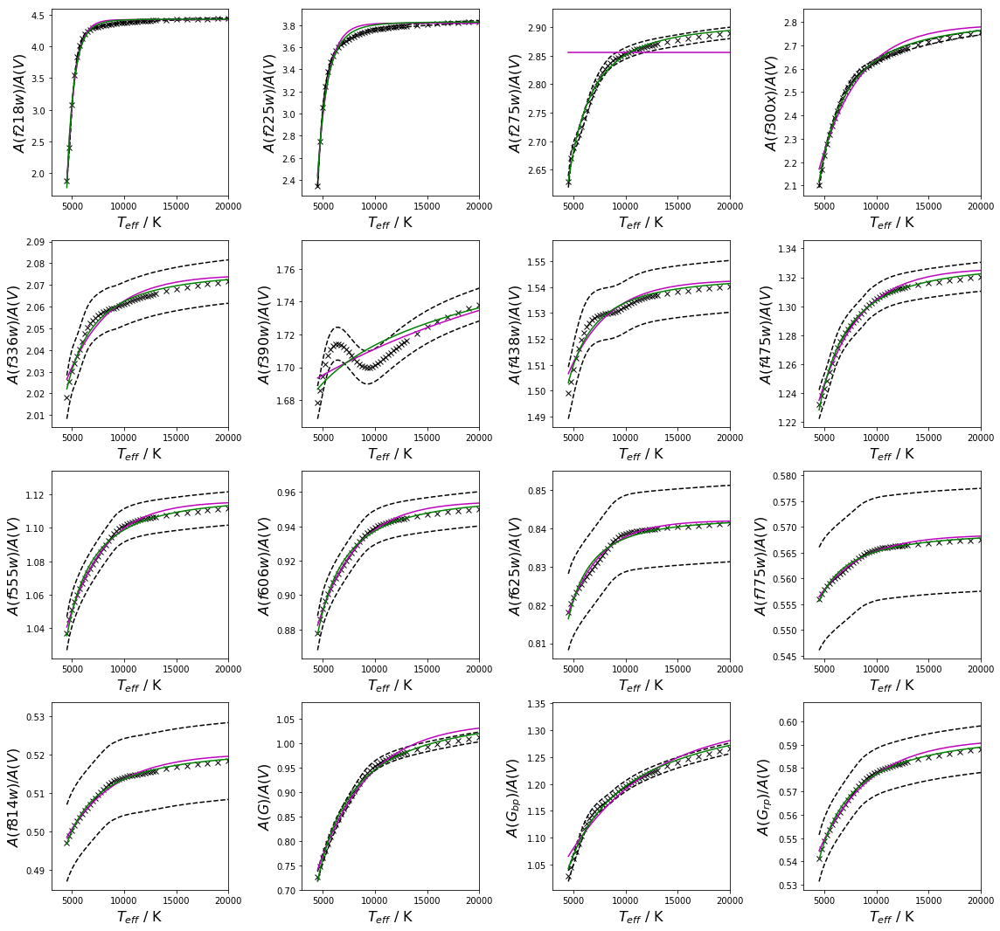


    Writing complete for log(g) = 5.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 4.5
Exponential fit coefficients (should be reused): 
[-1000.      -13.2337    4.4251]
Standard deviations (should be reused): 
[  3.6042e+01   7.5932e-02   1.2931e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.847   4.4306]
Standard deviations (should be reused): 
[ 0.0003  0.0372  0.0013]
Logistic fit coefficients: 
[  4.7523e+03   5.0021e+02   3.0000e+00   1.8696e+00]
Standard deviations: 
[  3.9122e+02   8.5772e+04   1.2039e-03   1.2815e-02]
Teff log-normal fit coefficients: 
[ 0.      5.4426  4.1479  2.    ]
Standard deviations: 
[  0.0000e+00   3.0231e+00   1.4294e-03   1.1724e+00]





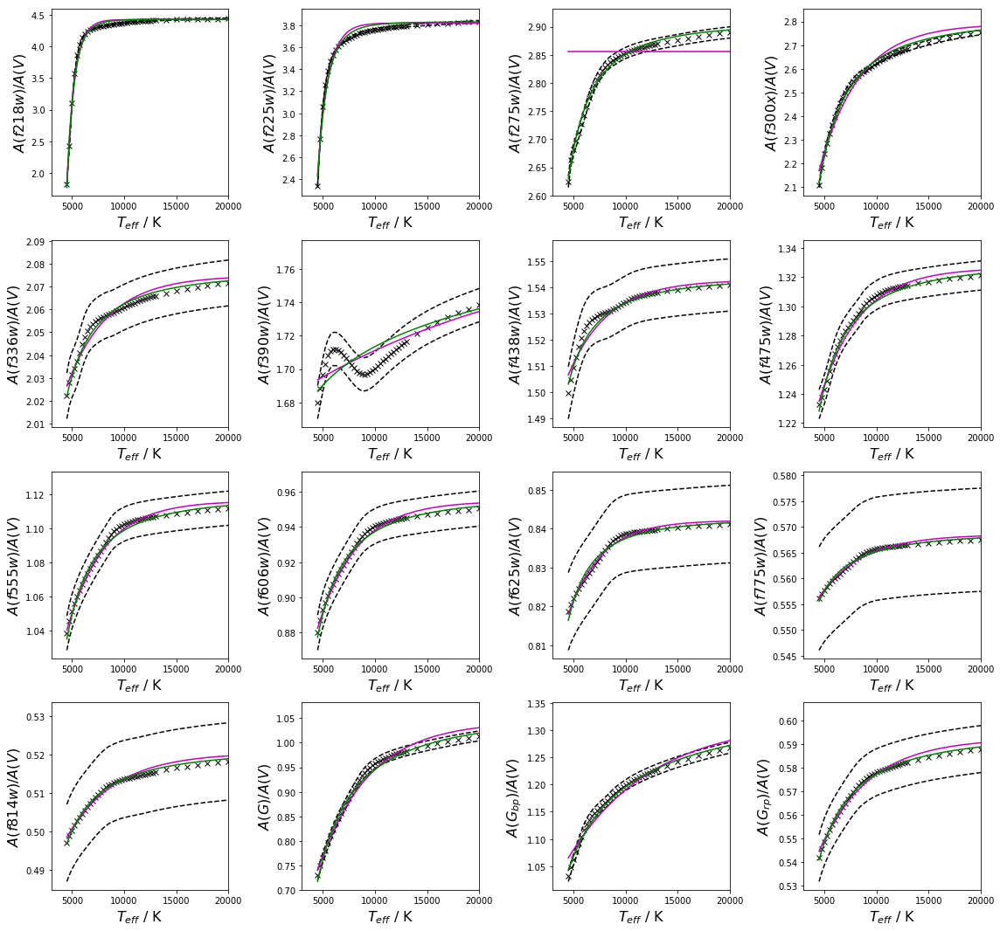


    Writing complete for log(g) = 4.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 4.0
Exponential fit coefficients (should be reused): 
[-1000.      -13.2337    4.4251]
Standard deviations (should be reused): 
[  3.6042e+01   7.5932e-02   1.2931e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.847   4.4306]
Standard deviations (should be reused): 
[ 0.0003  0.0372  0.0013]
Logistic fit coefficients: 
[  4.7523e+03   5.0021e+02   3.0000e+00   1.8696e+00]
Standard deviations: 
[  3.9122e+02   8.5772e+04   1.2039e-03   1.2815e-02]
Teff log-normal fit coefficients: 
[ 0.      5.4426  4.1479  2.    ]
Standard deviations: 
[  0.0000e+00   3.0231e+00   1.4294e-03   1.1724e+00]





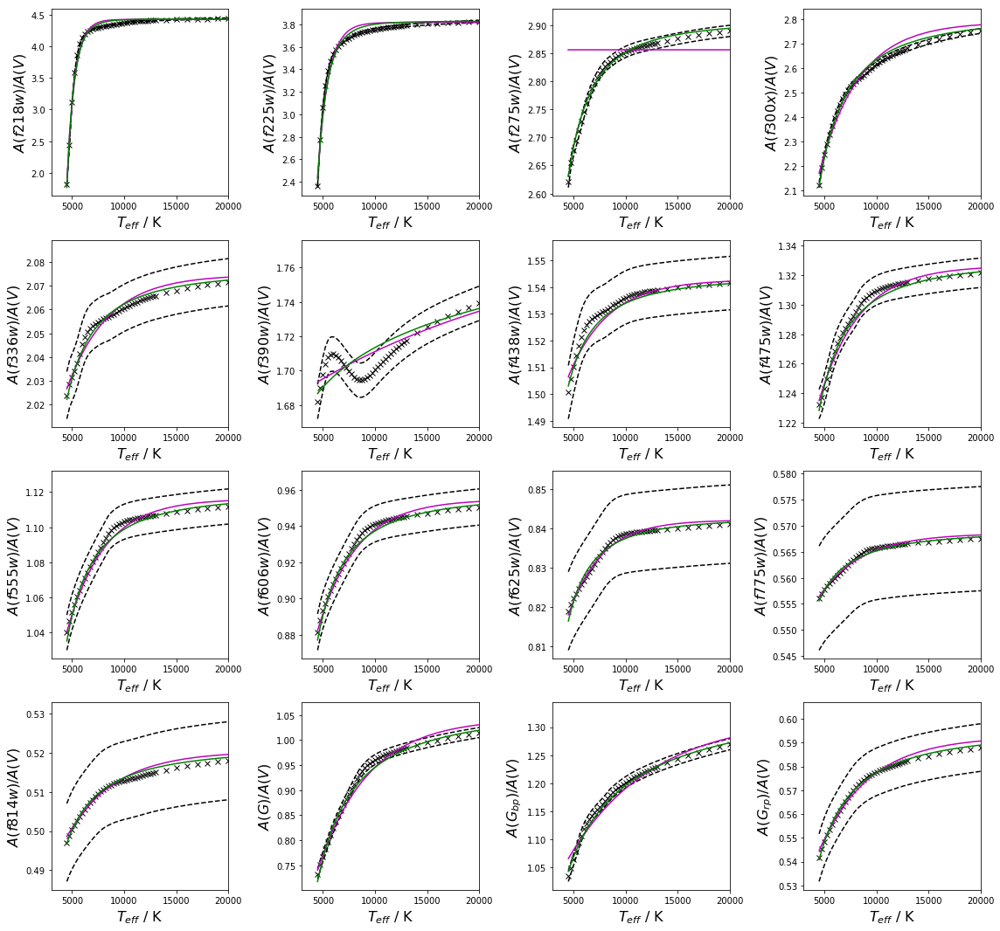


    Writing complete for log(g) = 4.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 3.5
Exponential fit coefficients (should be reused): 
[-1000.      -13.2337    4.4251]
Standard deviations (should be reused): 
[  3.6042e+01   7.5932e-02   1.2931e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.847   4.4306]
Standard deviations (should be reused): 
[ 0.0003  0.0372  0.0013]
Logistic fit coefficients: 
[  4.7523e+03   5.0021e+02   3.0000e+00   1.8696e+00]
Standard deviations: 
[  3.9122e+02   8.5772e+04   1.2039e-03   1.2815e-02]
Teff log-normal fit coefficients: 
[ 0.      5.4426  4.1479  2.    ]
Standard deviations: 
[  0.0000e+00   3.0231e+00   1.4294e-03   1.1724e+00]





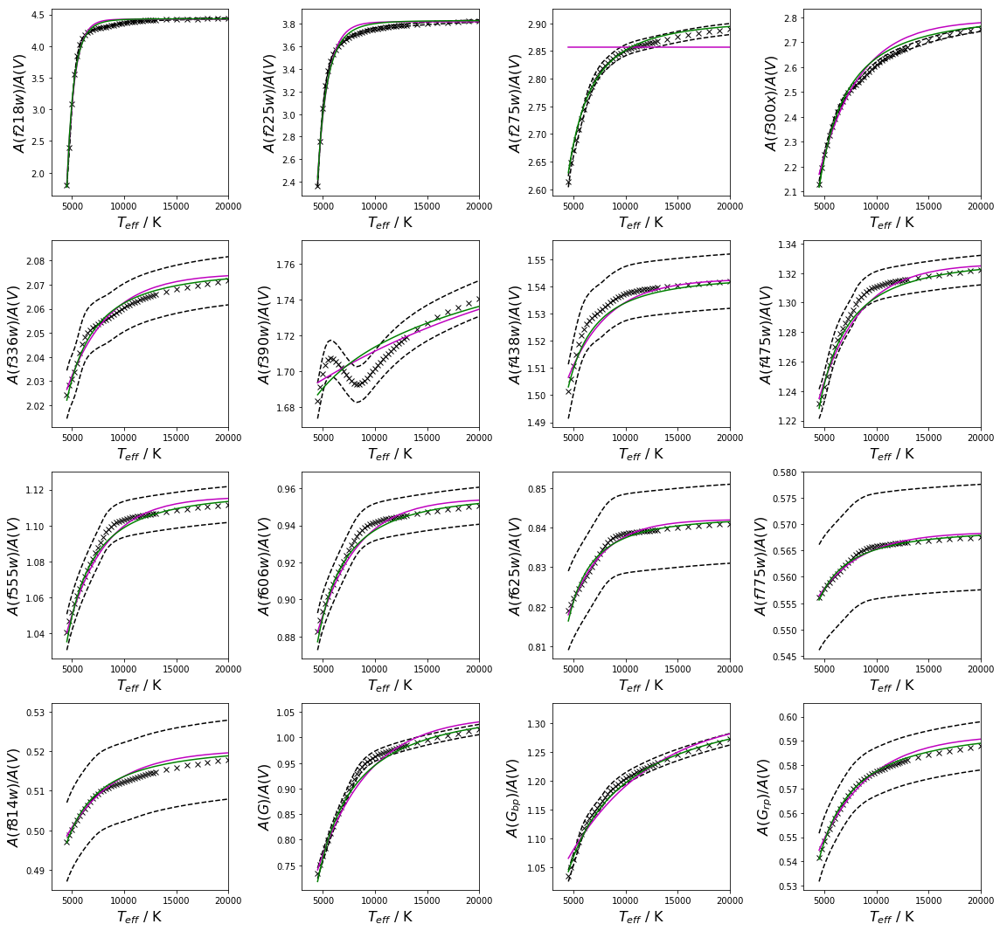


    Writing complete for log(g) = 3.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 3.0
Exponential fit coefficients (should be reused): 
[-1000.      -13.2337    4.4251]
Standard deviations (should be reused): 
[  3.6042e+01   7.5932e-02   1.2931e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.847   4.4306]
Standard deviations (should be reused): 
[ 0.0003  0.0372  0.0013]
Logistic fit coefficients: 
[  4.7523e+03   5.0021e+02   3.0000e+00   1.8696e+00]
Standard deviations: 
[  3.9122e+02   8.5772e+04   1.2039e-03   1.2815e-02]
Teff log-normal fit coefficients: 
[ 0.      5.4426  4.1479  2.    ]
Standard deviations: 
[  0.0000e+00   3.0231e+00   1.4294e-03   1.1724e+00]





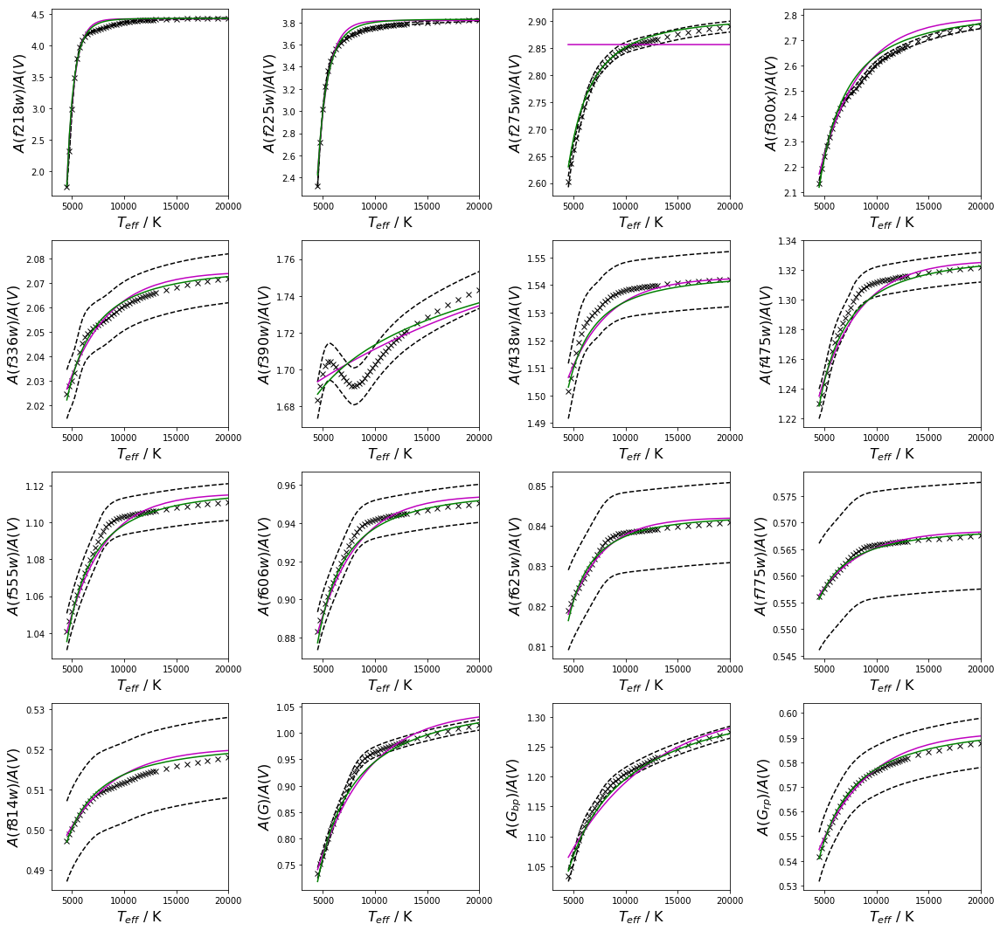


    Writing complete for log(g) = 3.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 2.5
Exponential fit coefficients (should be reused): 
[-1000.      -13.2337    4.4251]
Standard deviations (should be reused): 
[  3.6042e+01   7.5932e-02   1.2931e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.847   4.4306]
Standard deviations (should be reused): 
[ 0.0003  0.0372  0.0013]
Logistic fit coefficients: 
[  4.7523e+03   5.0021e+02   3.0000e+00   1.8696e+00]
Standard deviations: 
[  3.9122e+02   8.5772e+04   1.2039e-03   1.2815e-02]
Teff log-normal fit coefficients: 
[ 0.      5.4426  4.1479  2.    ]
Standard deviations: 
[  0.0000e+00   3.0231e+00   1.4294e-03   1.1724e+00]





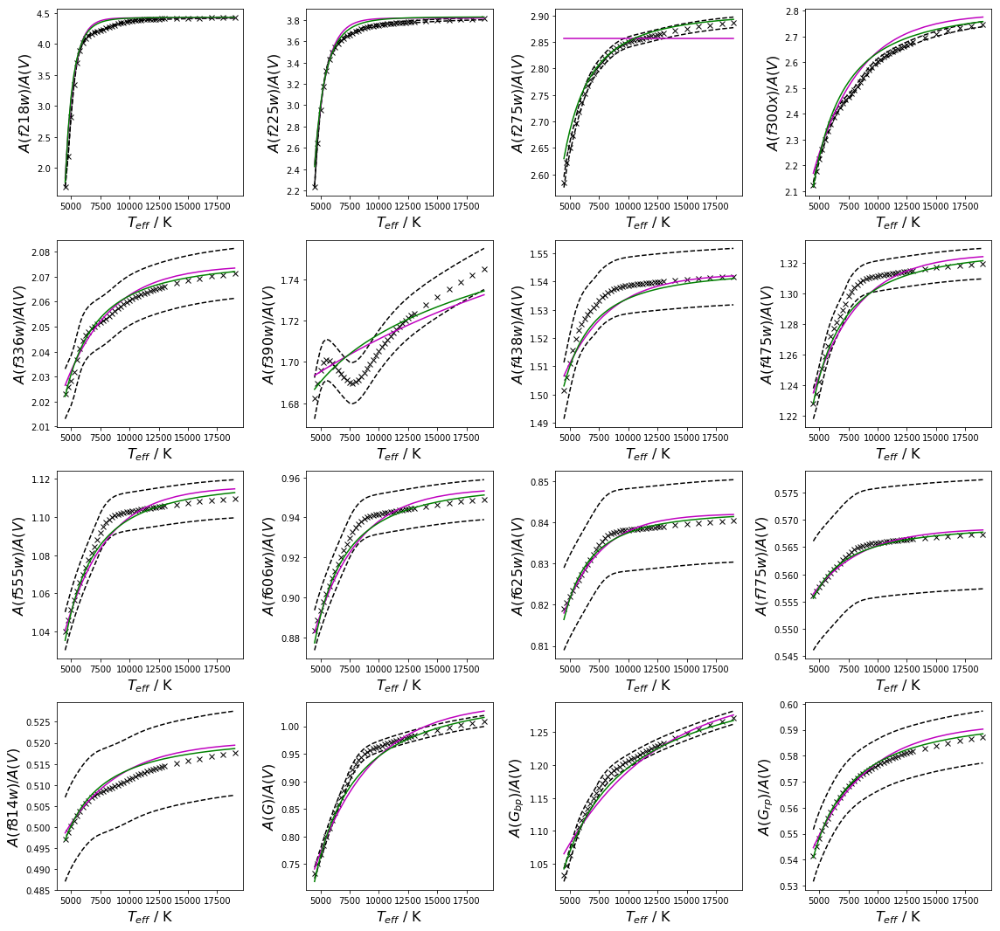


    Writing complete for log(g) = 2.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 2.0
Exponential fit coefficients (should be reused): 
[-1000.      -13.2337    4.4251]
Standard deviations (should be reused): 
[  3.6042e+01   7.5932e-02   1.2931e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.847   4.4306]
Standard deviations (should be reused): 
[ 0.0003  0.0372  0.0013]
Logistic fit coefficients: 
[  4.7523e+03   5.0021e+02   3.0000e+00   1.8696e+00]
Standard deviations: 
[  3.9122e+02   8.5772e+04   1.2039e-03   1.2815e-02]
Teff log-normal fit coefficients: 
[ 0.      5.4426  4.1479  2.    ]
Standard deviations: 
[  0.0000e+00   3.0231e+00   1.4294e-03   1.1724e+00]





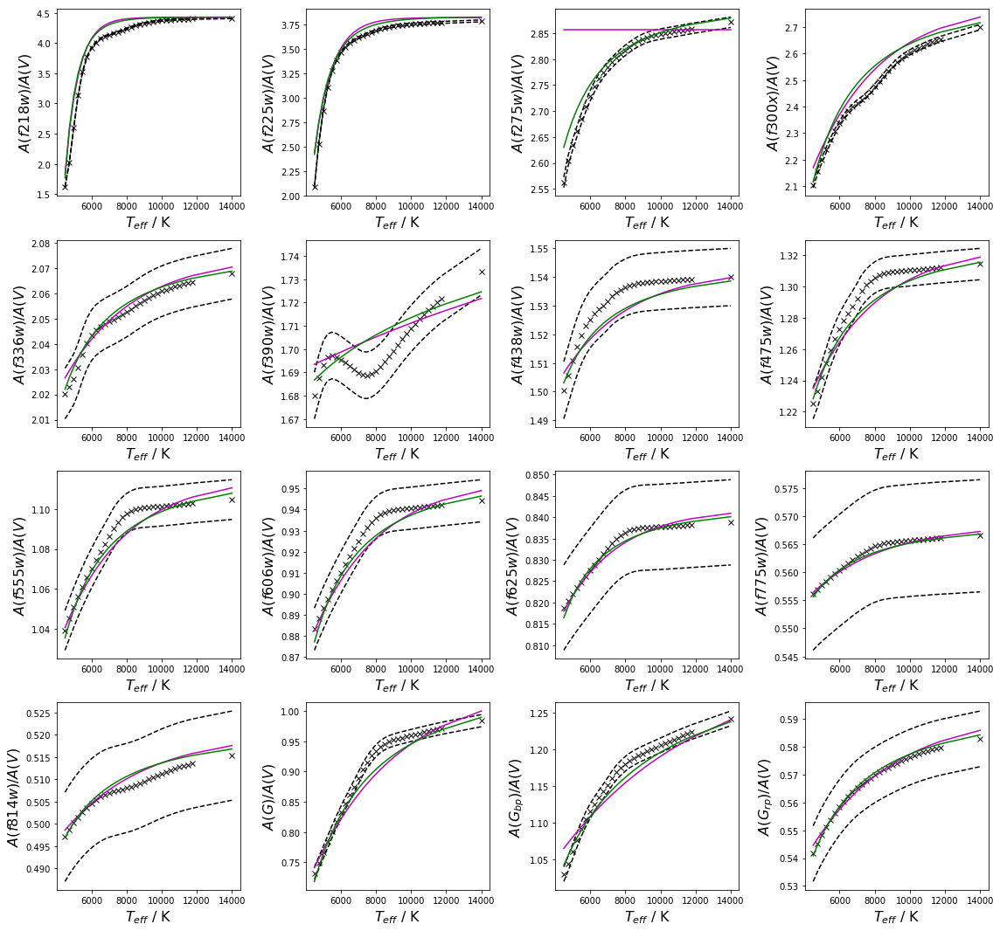


    Writing complete for log(g) = 2.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 1.5
Exponential fit coefficients (should be reused): 
[-1000.      -13.2337    4.4251]
Standard deviations (should be reused): 
[  3.6042e+01   7.5932e-02   1.2931e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.847   4.4306]
Standard deviations (should be reused): 
[ 0.0003  0.0372  0.0013]
Logistic fit coefficients: 
[  4.7523e+03   5.0021e+02   3.0000e+00   1.8696e+00]
Standard deviations: 
[  3.9122e+02   8.5772e+04   1.2039e-03   1.2815e-02]
Teff log-normal fit coefficients: 
[ 0.      5.4426  4.1479  2.    ]
Standard deviations: 
[  0.0000e+00   3.0231e+00   1.4294e-03   1.1724e+00]





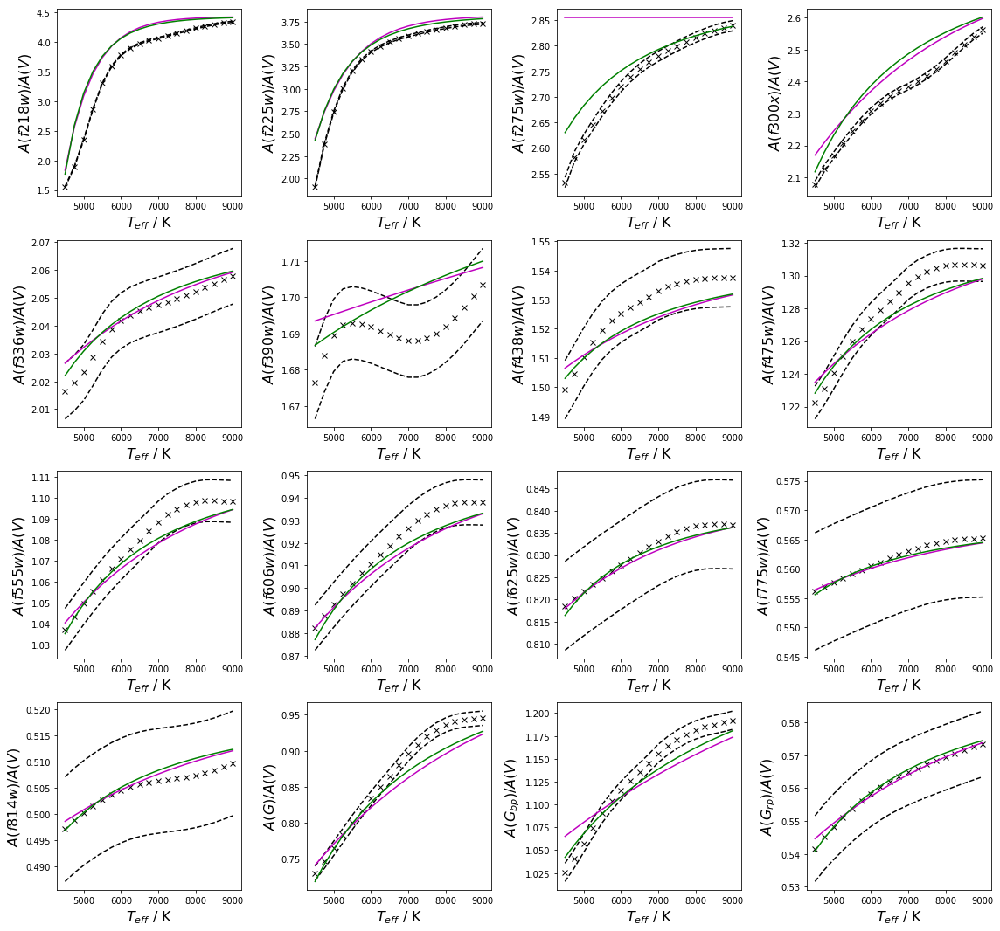


    Writing complete for log(g) = 1.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 1.0
Exponential fit coefficients (should be reused): 
[-1000.      -13.2337    4.4251]
Standard deviations (should be reused): 
[  3.6042e+01   7.5932e-02   1.2931e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.847   4.4306]
Standard deviations (should be reused): 
[ 0.0003  0.0372  0.0013]
Logistic fit coefficients: 
[  4.7523e+03   5.0021e+02   3.0000e+00   1.8696e+00]
Standard deviations: 
[  3.9122e+02   8.5772e+04   1.2039e-03   1.2815e-02]
Teff log-normal fit coefficients: 
[ 0.      5.4426  4.1479  2.    ]
Standard deviations: 
[  0.0000e+00   3.0231e+00   1.4294e-03   1.1724e+00]





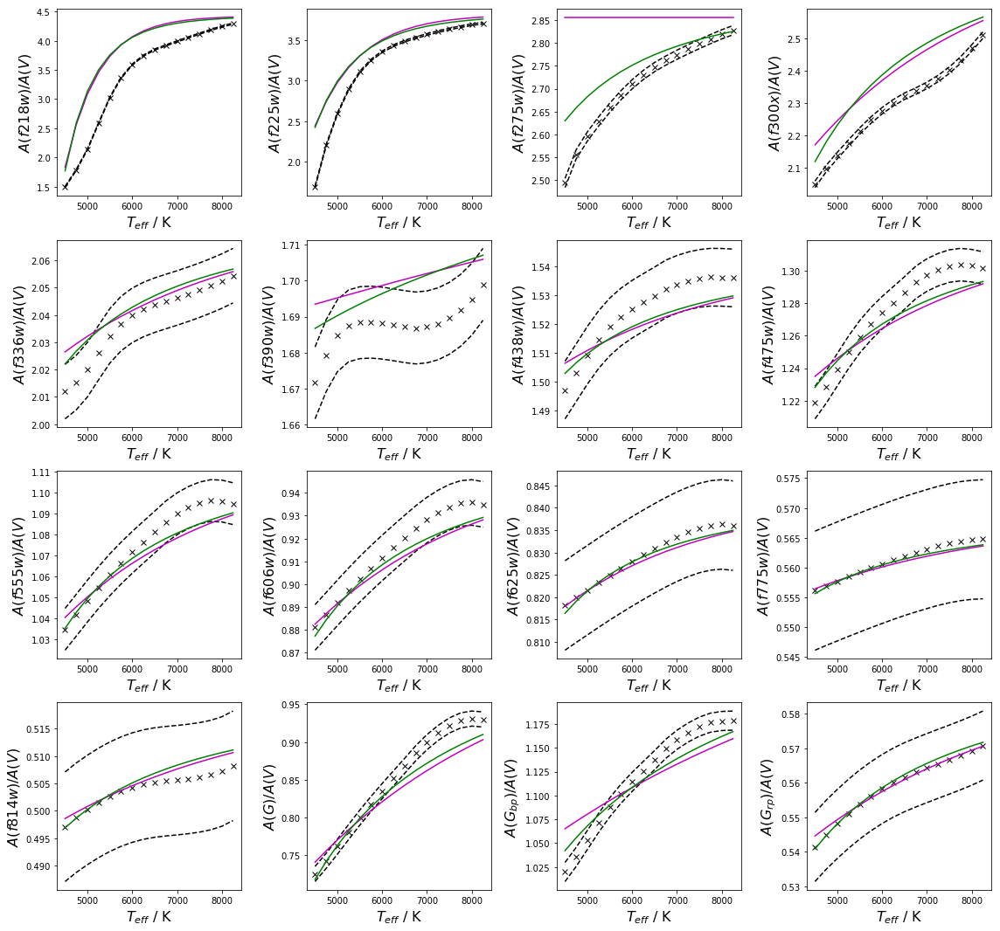


    Writing complete for log(g) = 1.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 0.5
Exponential fit coefficients (should be reused): 
[-1000.      -13.2337    4.4251]
Standard deviations (should be reused): 
[  3.6042e+01   7.5932e-02   1.2931e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.847   4.4306]
Standard deviations (should be reused): 
[ 0.0003  0.0372  0.0013]
Logistic fit coefficients: 
[  4.7523e+03   5.0021e+02   3.0000e+00   1.8696e+00]
Standard deviations: 
[  3.9122e+02   8.5772e+04   1.2039e-03   1.2815e-02]
Teff log-normal fit coefficients: 
[ 0.      5.4426  4.1479  2.    ]
Standard deviations: 
[  0.0000e+00   3.0231e+00   1.4294e-03   1.1724e+00]





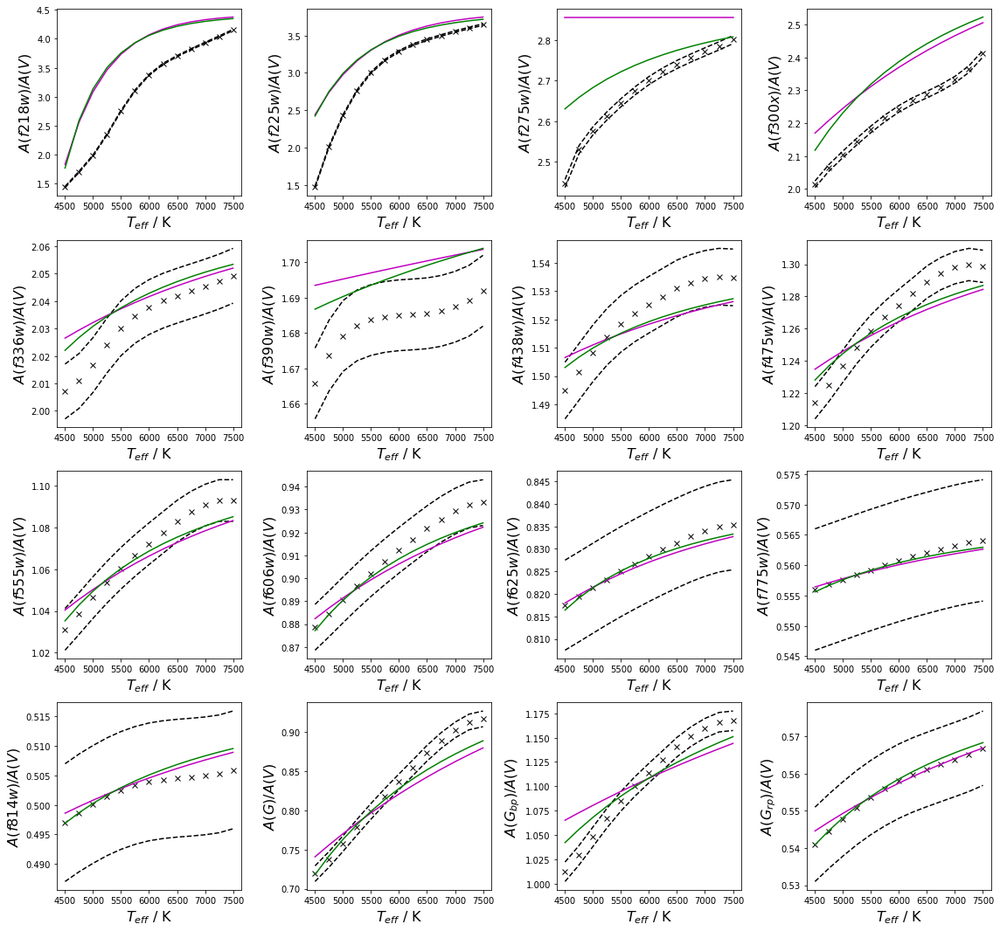


    Writing complete for log(g) = 0.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 0.0
Exponential fit coefficients (should be reused): 
[-1000.      -13.2337    4.4251]
Standard deviations (should be reused): 
[  3.6042e+01   7.5932e-02   1.2931e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.847   4.4306]
Standard deviations (should be reused): 
[ 0.0003  0.0372  0.0013]
Logistic fit coefficients: 
[  4.7523e+03   5.0021e+02   3.0000e+00   1.8696e+00]
Standard deviations: 
[  3.9122e+02   8.5772e+04   1.2039e-03   1.2815e-02]
Teff log-normal fit coefficients: 
[ 0.      5.4426  4.1479  2.    ]
Standard deviations: 
[  0.0000e+00   3.0231e+00   1.4294e-03   1.1724e+00]





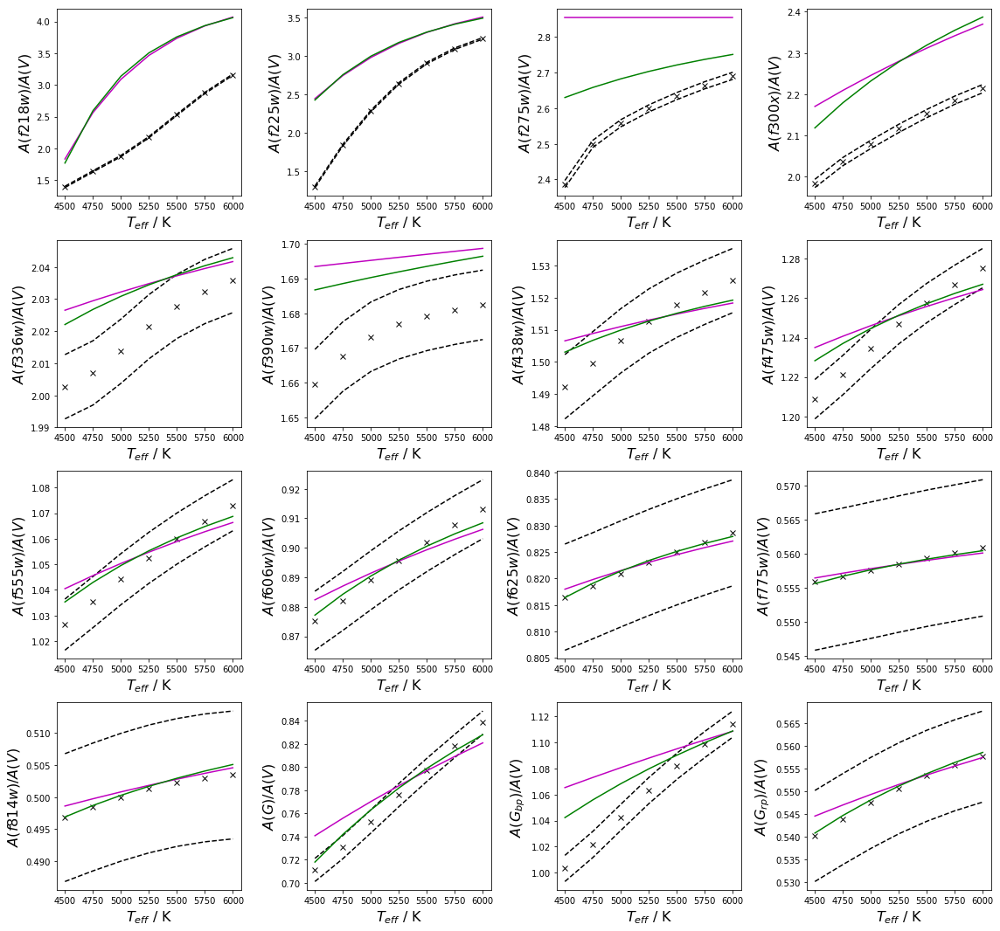


    Writing complete for log(g) = 0.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 5.0


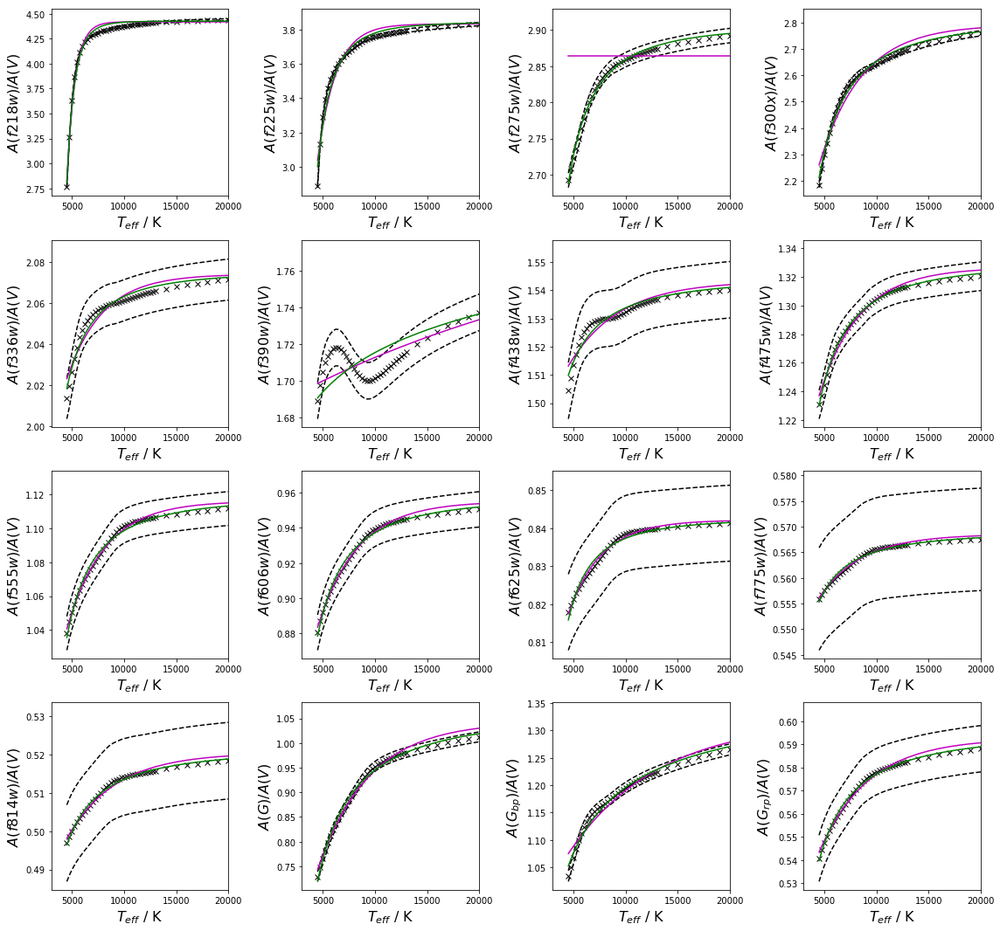


    Writing complete for log(g) = 5.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 4.5
Exponential fit coefficients (should be reused): 
[-469.4942  -12.6355    4.4189]
Standard deviations (should be reused): 
[  2.5969e+01   1.1616e-01   1.2993e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.2303  4.4261]
Standard deviations (should be reused): 
[ 0.0005  0.0538  0.0014]
Logistic fit coefficients: 
[  4.4245e+03   4.4139e+02   3.0000e+00  -3.7473e+00]
Standard deviations: 
[  1.7628e+06   1.1156e+05   4.2114e-03   5.0488e+05]
Teff log-normal fit coefficients: 
[ 0.      8.1782  4.2333  2.    ]
Standard deviations: 
[  0.0000e+00   1.4652e+01   1.4292e-03   3.9702e+00]





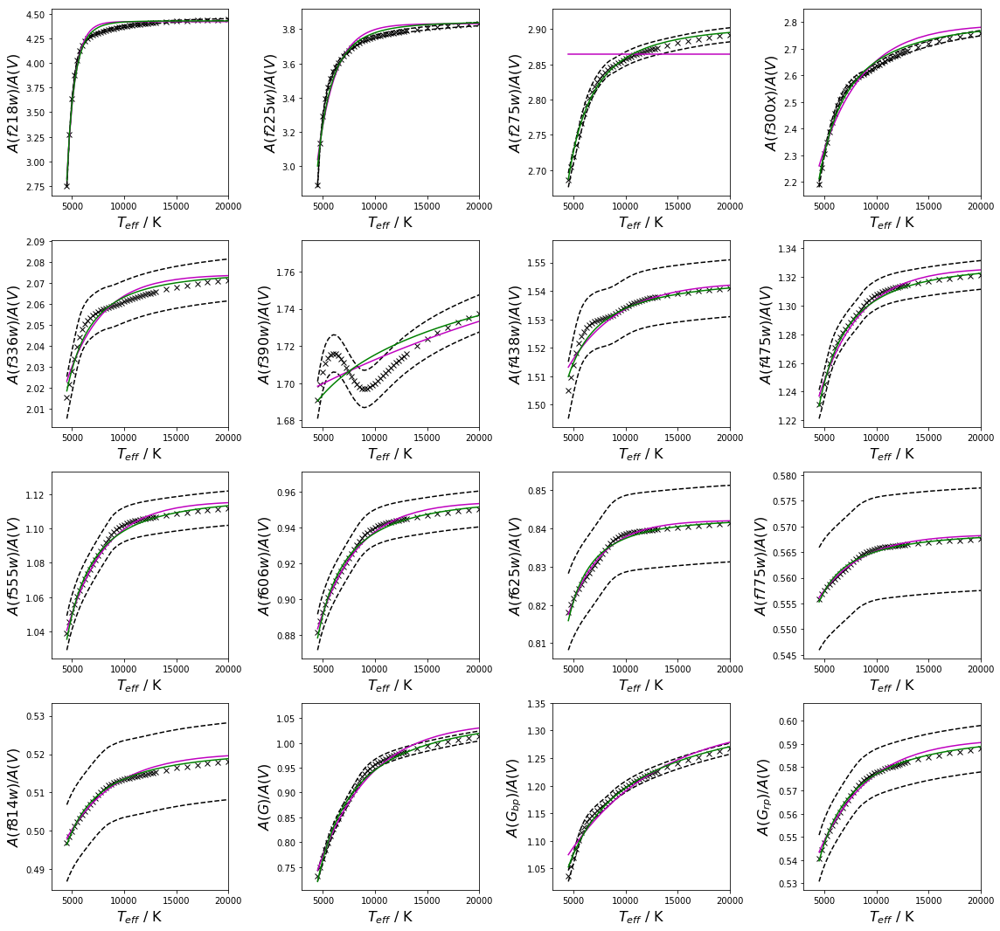


    Writing complete for log(g) = 4.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 4.0
Exponential fit coefficients (should be reused): 
[-469.4942  -12.6355    4.4189]
Standard deviations (should be reused): 
[  2.5969e+01   1.1616e-01   1.2993e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.2303  4.4261]
Standard deviations (should be reused): 
[ 0.0005  0.0538  0.0014]
Logistic fit coefficients: 
[  4.4245e+03   4.4139e+02   3.0000e+00  -3.7473e+00]
Standard deviations: 
[  1.7628e+06   1.1156e+05   4.2114e-03   5.0488e+05]
Teff log-normal fit coefficients: 
[ 0.      8.1782  4.2333  2.    ]
Standard deviations: 
[  0.0000e+00   1.4652e+01   1.4292e-03   3.9702e+00]





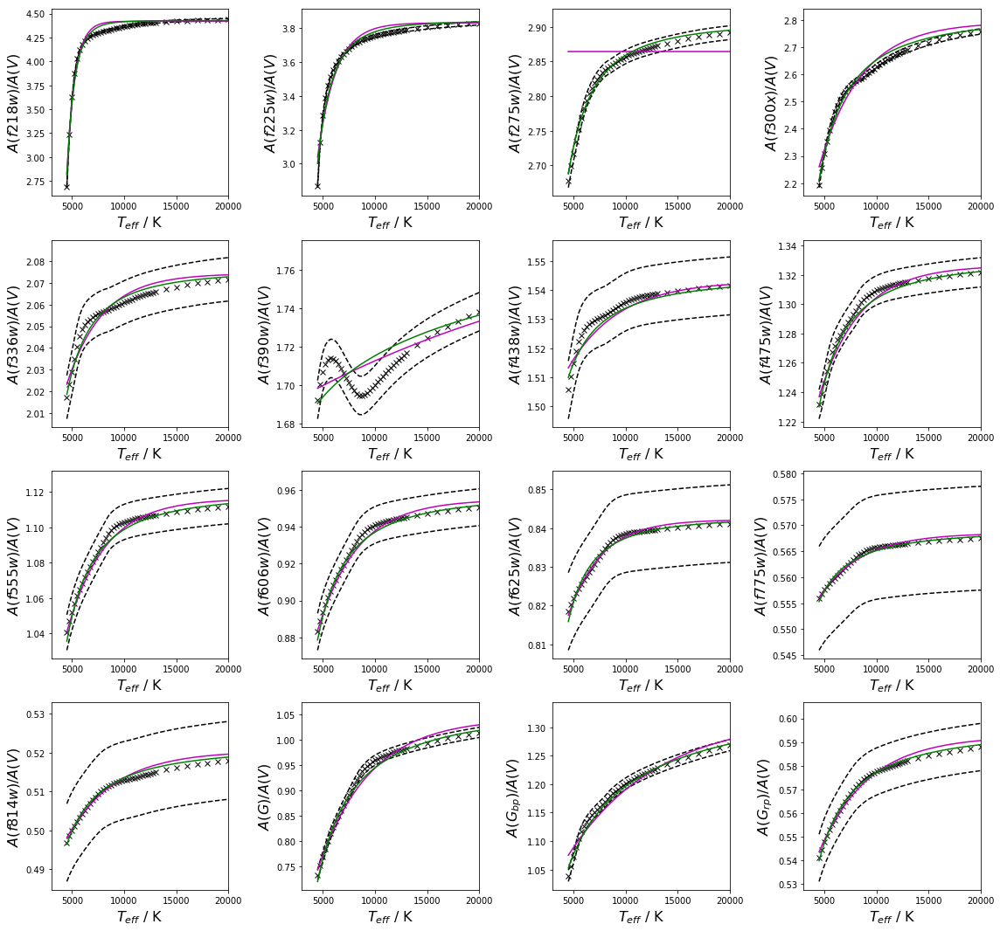


    Writing complete for log(g) = 4.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 3.5
Exponential fit coefficients (should be reused): 
[-469.4942  -12.6355    4.4189]
Standard deviations (should be reused): 
[  2.5969e+01   1.1616e-01   1.2993e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.2303  4.4261]
Standard deviations (should be reused): 
[ 0.0005  0.0538  0.0014]
Logistic fit coefficients: 
[  4.4245e+03   4.4139e+02   3.0000e+00  -3.7473e+00]
Standard deviations: 
[  1.7628e+06   1.1156e+05   4.2114e-03   5.0488e+05]
Teff log-normal fit coefficients: 
[ 0.      8.1782  4.2333  2.    ]
Standard deviations: 
[  0.0000e+00   1.4652e+01   1.4292e-03   3.9702e+00]





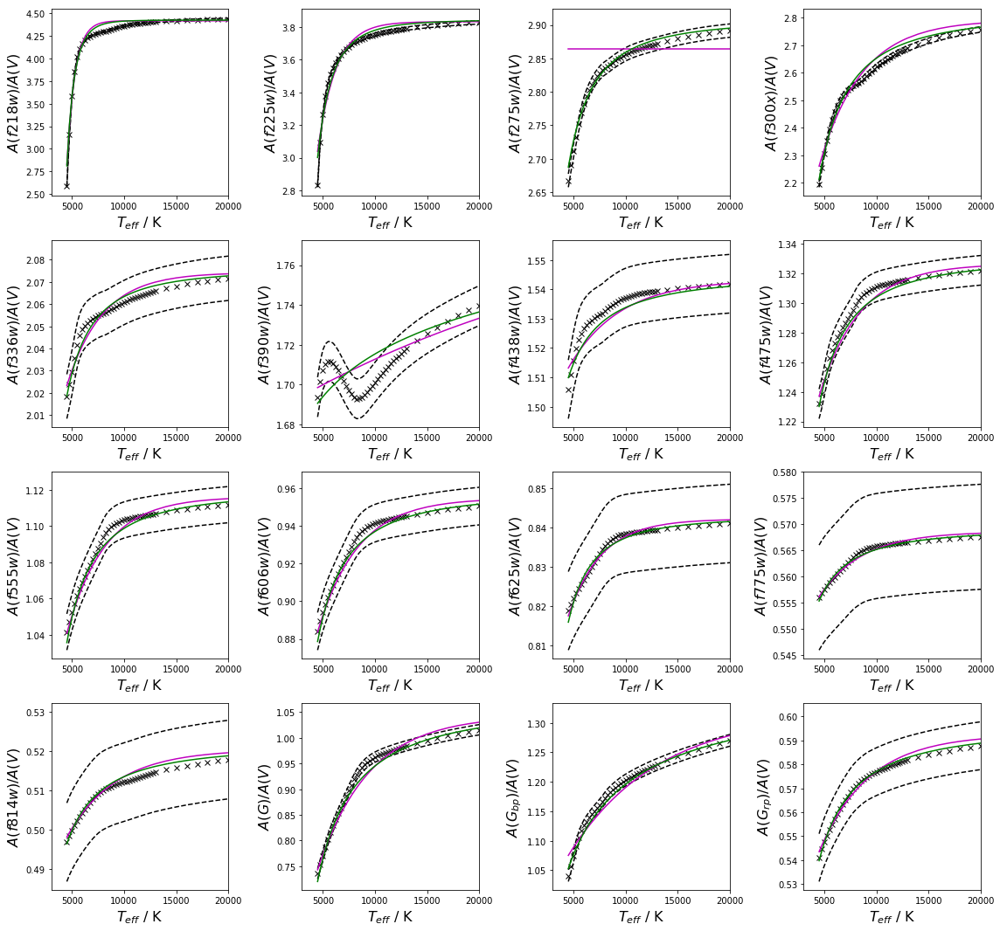


    Writing complete for log(g) = 3.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 3.0
Exponential fit coefficients (should be reused): 
[-469.4942  -12.6355    4.4189]
Standard deviations (should be reused): 
[  2.5969e+01   1.1616e-01   1.2993e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.2303  4.4261]
Standard deviations (should be reused): 
[ 0.0005  0.0538  0.0014]
Logistic fit coefficients: 
[  4.4245e+03   4.4139e+02   3.0000e+00  -3.7473e+00]
Standard deviations: 
[  1.7628e+06   1.1156e+05   4.2114e-03   5.0488e+05]
Teff log-normal fit coefficients: 
[ 0.      8.1782  4.2333  2.    ]
Standard deviations: 
[  0.0000e+00   1.4652e+01   1.4292e-03   3.9702e+00]





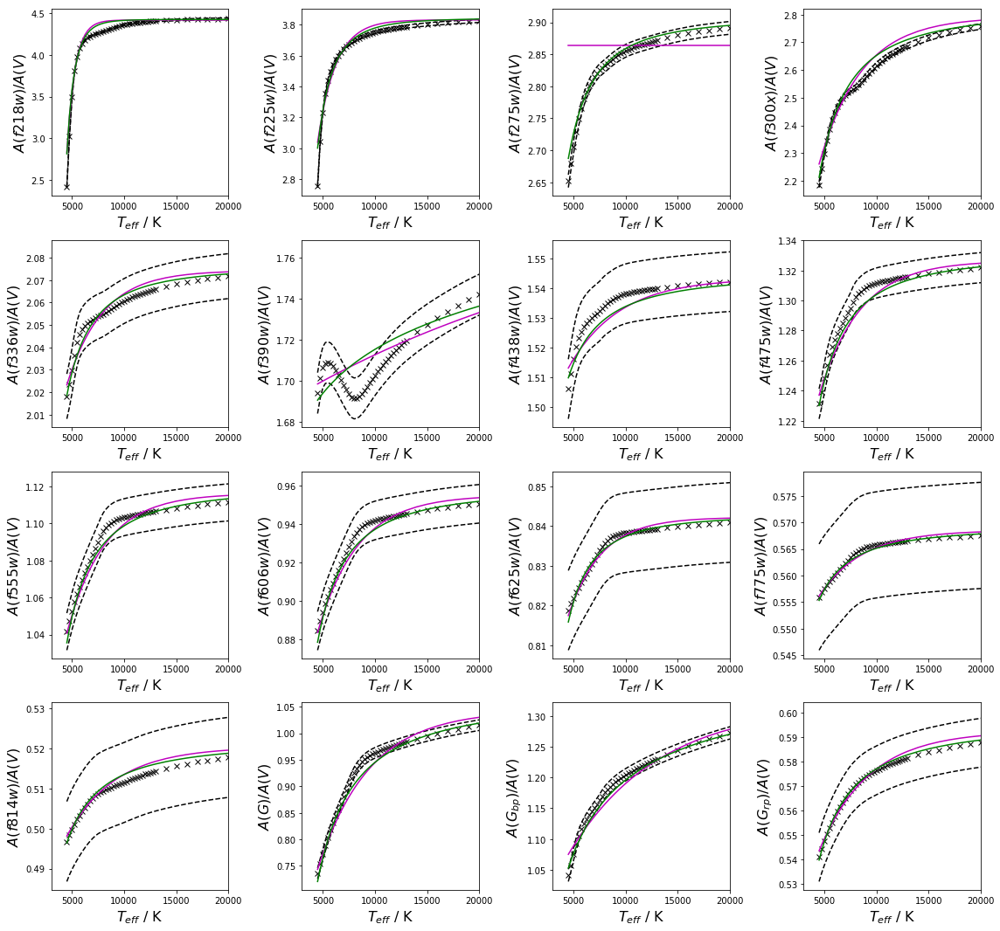


    Writing complete for log(g) = 3.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 2.5
Exponential fit coefficients (should be reused): 
[-469.4942  -12.6355    4.4189]
Standard deviations (should be reused): 
[  2.5969e+01   1.1616e-01   1.2993e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.2303  4.4261]
Standard deviations (should be reused): 
[ 0.0005  0.0538  0.0014]
Logistic fit coefficients: 
[  4.4245e+03   4.4139e+02   3.0000e+00  -3.7473e+00]
Standard deviations: 
[  1.7628e+06   1.1156e+05   4.2114e-03   5.0488e+05]
Teff log-normal fit coefficients: 
[ 0.      8.1782  4.2333  2.    ]
Standard deviations: 
[  0.0000e+00   1.4652e+01   1.4292e-03   3.9702e+00]





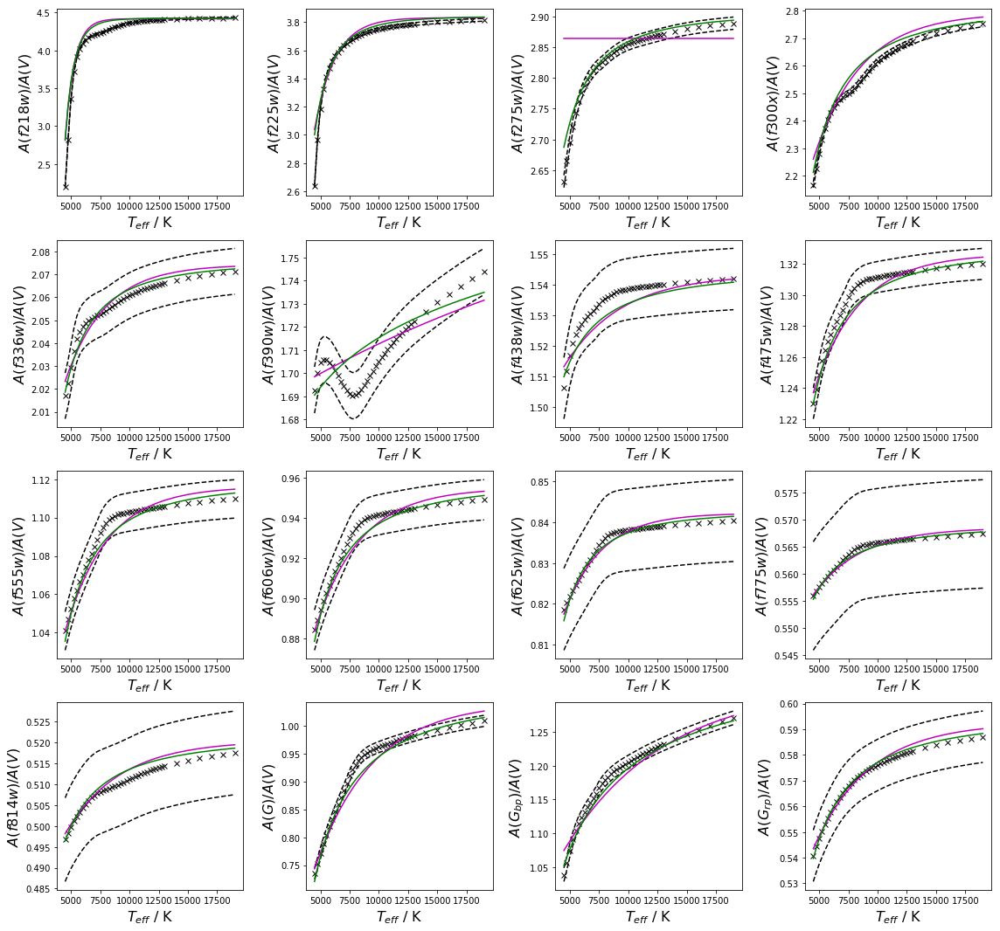


    Writing complete for log(g) = 2.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 2.0
Exponential fit coefficients (should be reused): 
[-469.4942  -12.6355    4.4189]
Standard deviations (should be reused): 
[  2.5969e+01   1.1616e-01   1.2993e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.2303  4.4261]
Standard deviations (should be reused): 
[ 0.0005  0.0538  0.0014]
Logistic fit coefficients: 
[  4.4245e+03   4.4139e+02   3.0000e+00  -3.7473e+00]
Standard deviations: 
[  1.7628e+06   1.1156e+05   4.2114e-03   5.0488e+05]
Teff log-normal fit coefficients: 
[ 0.      8.1782  4.2333  2.    ]
Standard deviations: 
[  0.0000e+00   1.4652e+01   1.4292e-03   3.9702e+00]





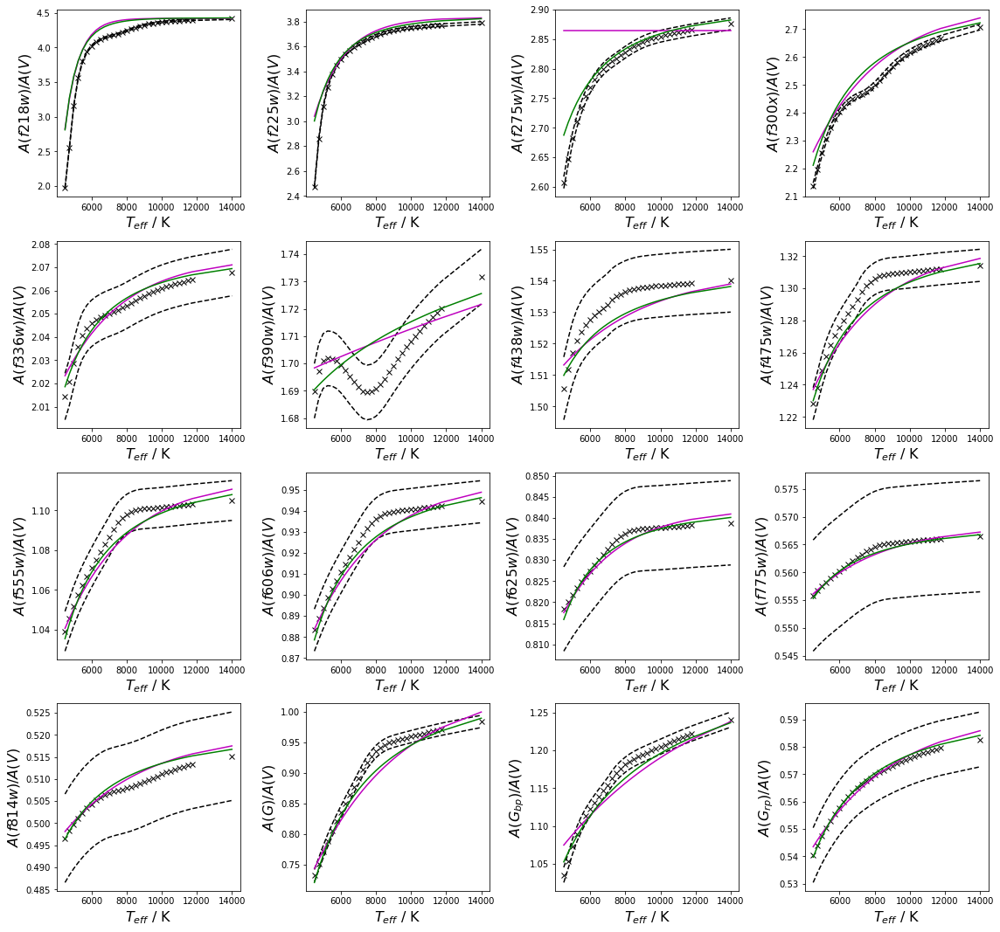


    Writing complete for log(g) = 2.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 1.5
Exponential fit coefficients (should be reused): 
[-469.4942  -12.6355    4.4189]
Standard deviations (should be reused): 
[  2.5969e+01   1.1616e-01   1.2993e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.2303  4.4261]
Standard deviations (should be reused): 
[ 0.0005  0.0538  0.0014]
Logistic fit coefficients: 
[  4.4245e+03   4.4139e+02   3.0000e+00  -3.7473e+00]
Standard deviations: 
[  1.7628e+06   1.1156e+05   4.2114e-03   5.0488e+05]
Teff log-normal fit coefficients: 
[ 0.      8.1782  4.2333  2.    ]
Standard deviations: 
[  0.0000e+00   1.4652e+01   1.4292e-03   3.9702e+00]





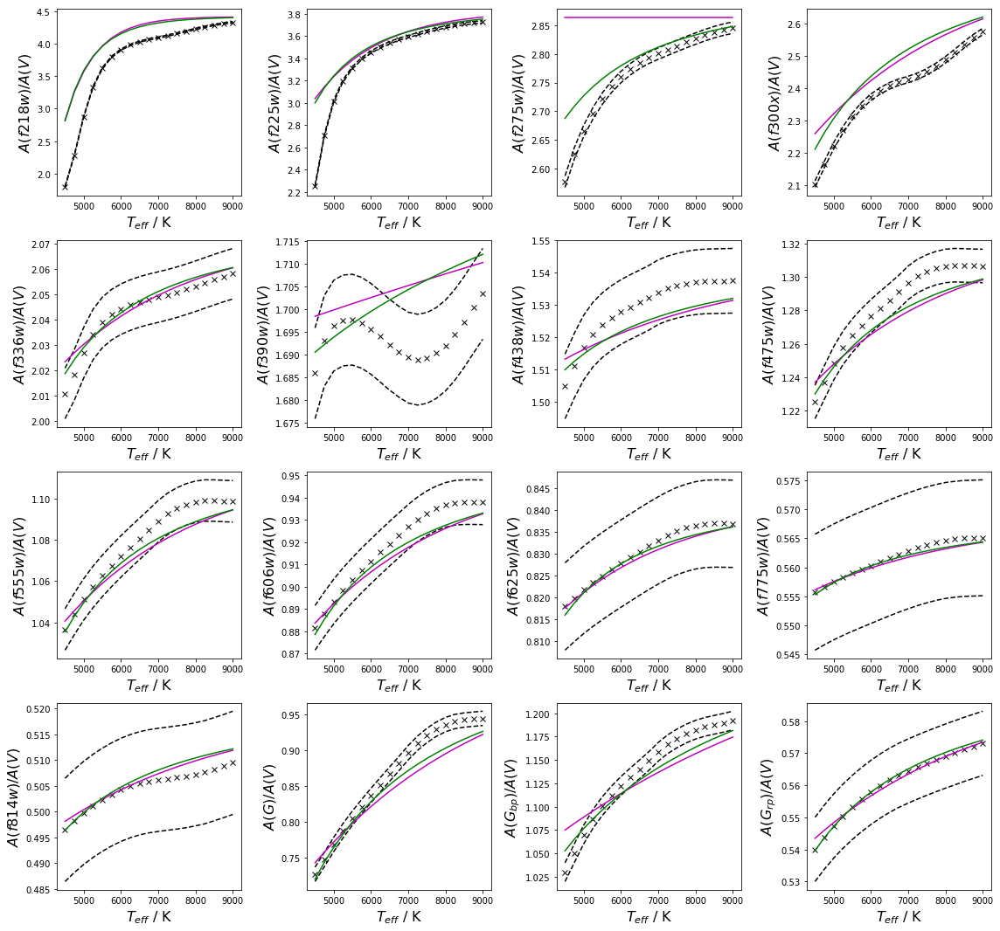


    Writing complete for log(g) = 1.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 1.0
Exponential fit coefficients (should be reused): 
[-469.4942  -12.6355    4.4189]
Standard deviations (should be reused): 
[  2.5969e+01   1.1616e-01   1.2993e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.2303  4.4261]
Standard deviations (should be reused): 
[ 0.0005  0.0538  0.0014]
Logistic fit coefficients: 
[  4.4245e+03   4.4139e+02   3.0000e+00  -3.7473e+00]
Standard deviations: 
[  1.7628e+06   1.1156e+05   4.2114e-03   5.0488e+05]
Teff log-normal fit coefficients: 
[ 0.      8.1782  4.2333  2.    ]
Standard deviations: 
[  0.0000e+00   1.4652e+01   1.4292e-03   3.9702e+00]





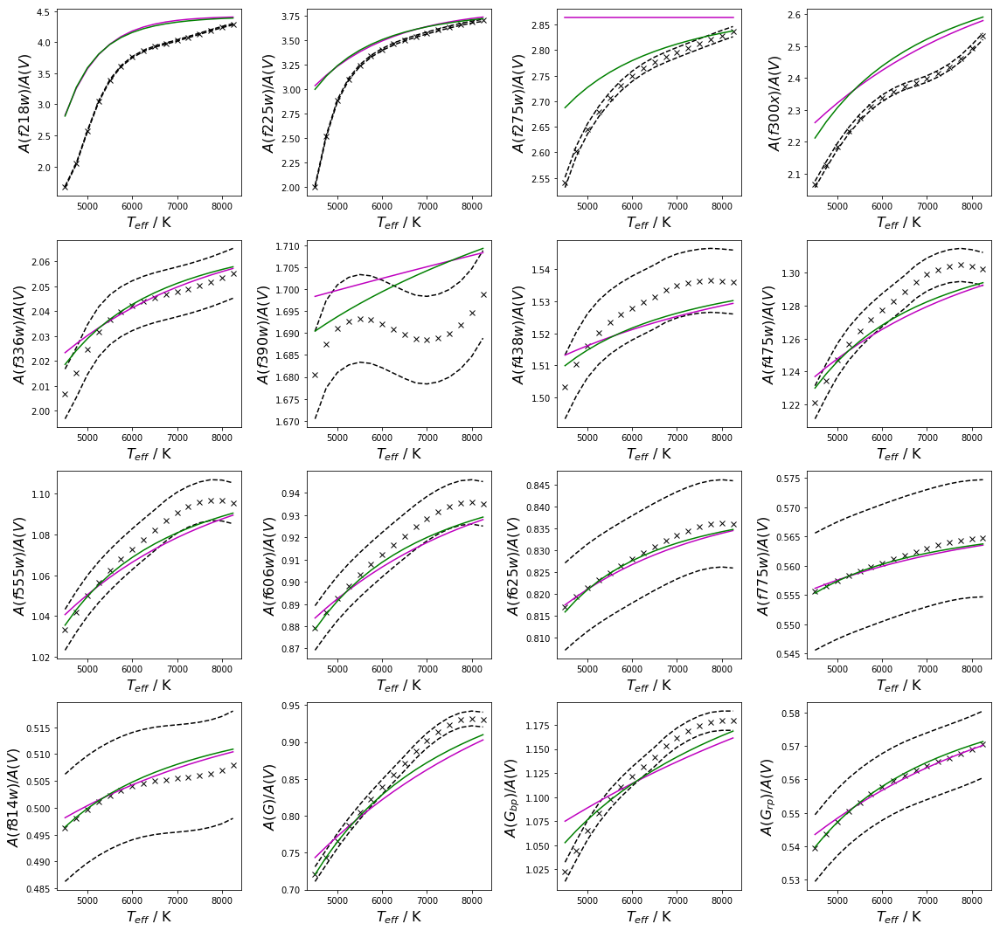


    Writing complete for log(g) = 1.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 0.5
Exponential fit coefficients (should be reused): 
[-469.4942  -12.6355    4.4189]
Standard deviations (should be reused): 
[  2.5969e+01   1.1616e-01   1.2993e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.2303  4.4261]
Standard deviations (should be reused): 
[ 0.0005  0.0538  0.0014]
Logistic fit coefficients: 
[  4.4245e+03   4.4139e+02   3.0000e+00  -3.7473e+00]
Standard deviations: 
[  1.7628e+06   1.1156e+05   4.2114e-03   5.0488e+05]
Teff log-normal fit coefficients: 
[ 0.      8.1782  4.2333  2.    ]
Standard deviations: 
[  0.0000e+00   1.4652e+01   1.4292e-03   3.9702e+00]





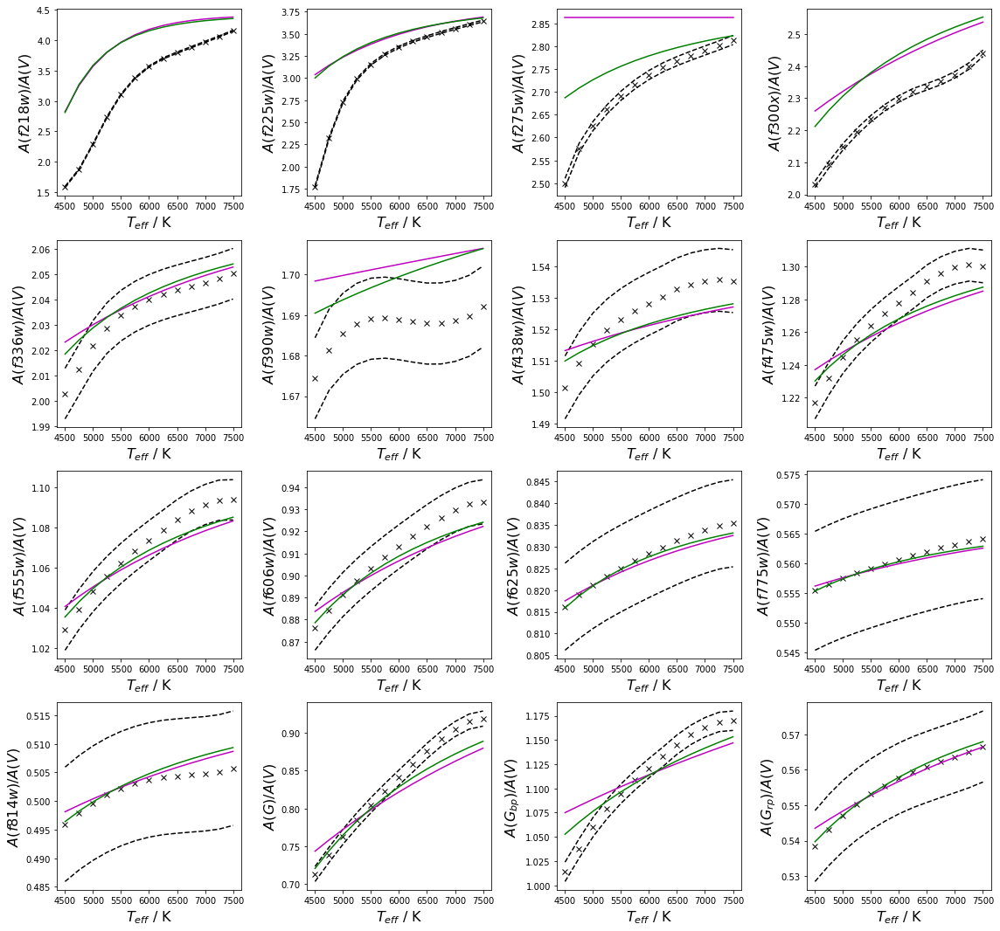


    Writing complete for log(g) = 0.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 0.0
Exponential fit coefficients (should be reused): 
[-469.4942  -12.6355    4.4189]
Standard deviations (should be reused): 
[  2.5969e+01   1.1616e-01   1.2993e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -6.2303  4.4261]
Standard deviations (should be reused): 
[ 0.0005  0.0538  0.0014]
Logistic fit coefficients: 
[  4.4245e+03   4.4139e+02   3.0000e+00  -3.7473e+00]
Standard deviations: 
[  1.7628e+06   1.1156e+05   4.2114e-03   5.0488e+05]
Teff log-normal fit coefficients: 
[ 0.      8.1782  4.2333  2.    ]
Standard deviations: 
[  0.0000e+00   1.4652e+01   1.4292e-03   3.9702e+00]





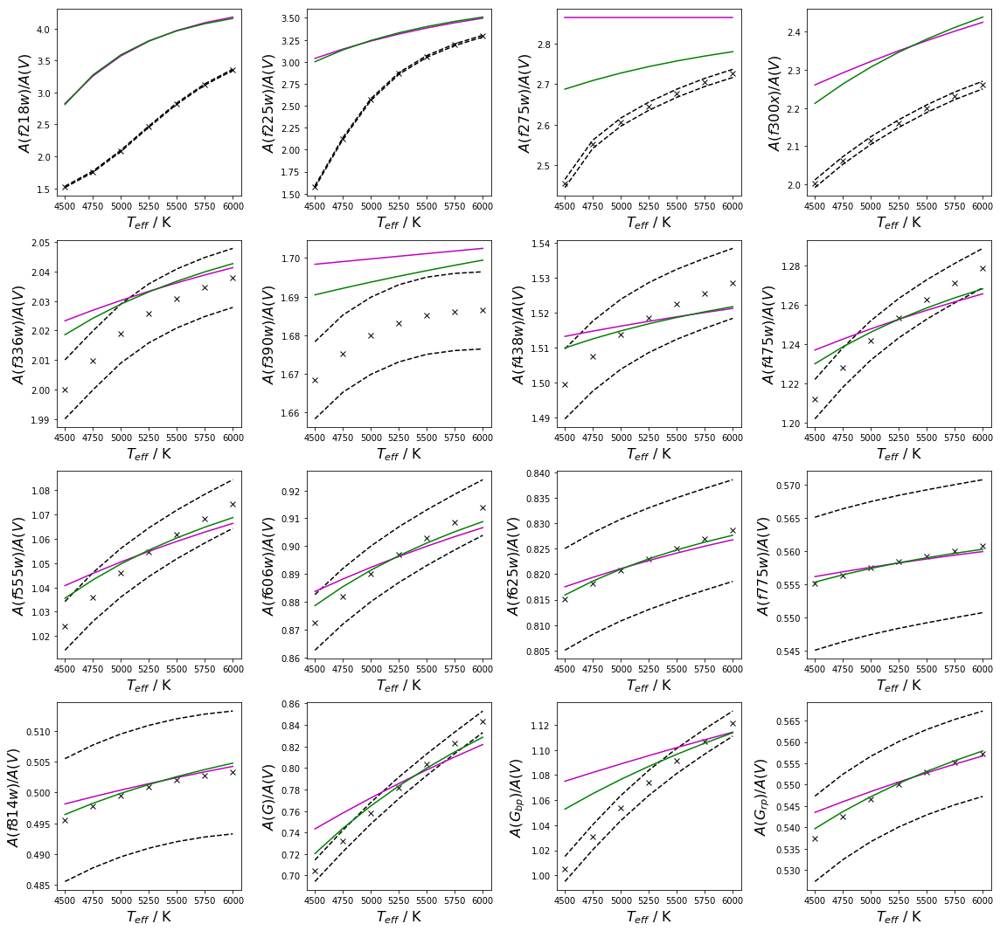


    Writing complete for log(g) = 0.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 5.0

    Writing log(g)=5.0, FeH = 0p0, Rv = 2p0 model for f218w filter
Average fractional error for Exponential function of Teff, fitted = 0.00700069649522
Average fractional error for Power law of Teff, fitted = 0.00554759718059

    Writing log(g)=5.0, FeH = 0p0, Rv = 2p0 model for f225w filter
Average fractional error for Exponential function of Teff, fitted = 0.0113486719365
Average fractional error for Power law of Teff, fitted = 0.00884071907646

    Writing log(g)=5.0, FeH = 0p0, Rv = 2p0 model for f275w filter
Average fractional error for Exponential function of Teff, fitted = 0.0262448389374
Average fractional error for Power law of Teff, fitted = 0.0225683055746

    Writing log(g)=5.0, FeH = 0p0, Rv = 2p0 model for f300x filter
Average fractional error for Exponential function of Teff, fitted = 0.0104541959142
Average fractional error for Power law of Teff, fitted = 0.0105

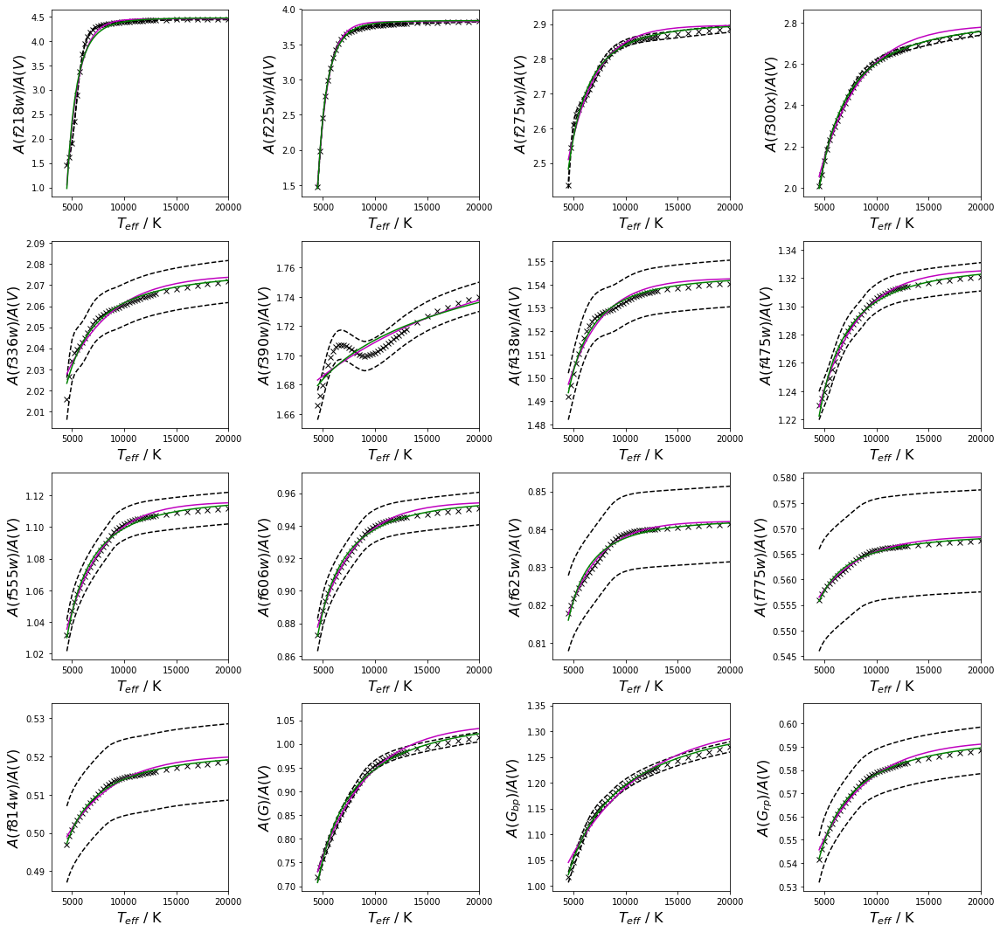


    Writing complete for log(g) = 5.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 4.5
Exponential fit coefficients (should be reused): 
[-190.4307   -8.9475    4.4505]
Standard deviations (should be reused): 
[  3.2087e+00   3.4419e-02   1.3590e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0779 -4.7618  4.4692]
Standard deviations (should be reused): 
[ 0.001   0.0172  0.0014]
Logistic fit coefficients: 
[  5.1844e+03   7.6818e+01   3.0000e+00   1.5307e+00]
Standard deviations: 
[  3.8279e+00   1.8931e+00   1.2235e-03   8.6585e-03]
Teff log-normal fit coefficients: 
[ 0.      3.0437  3.9741  2.    ]
Standard deviations: 
[ 0.      0.3367  0.0014  0.2068]





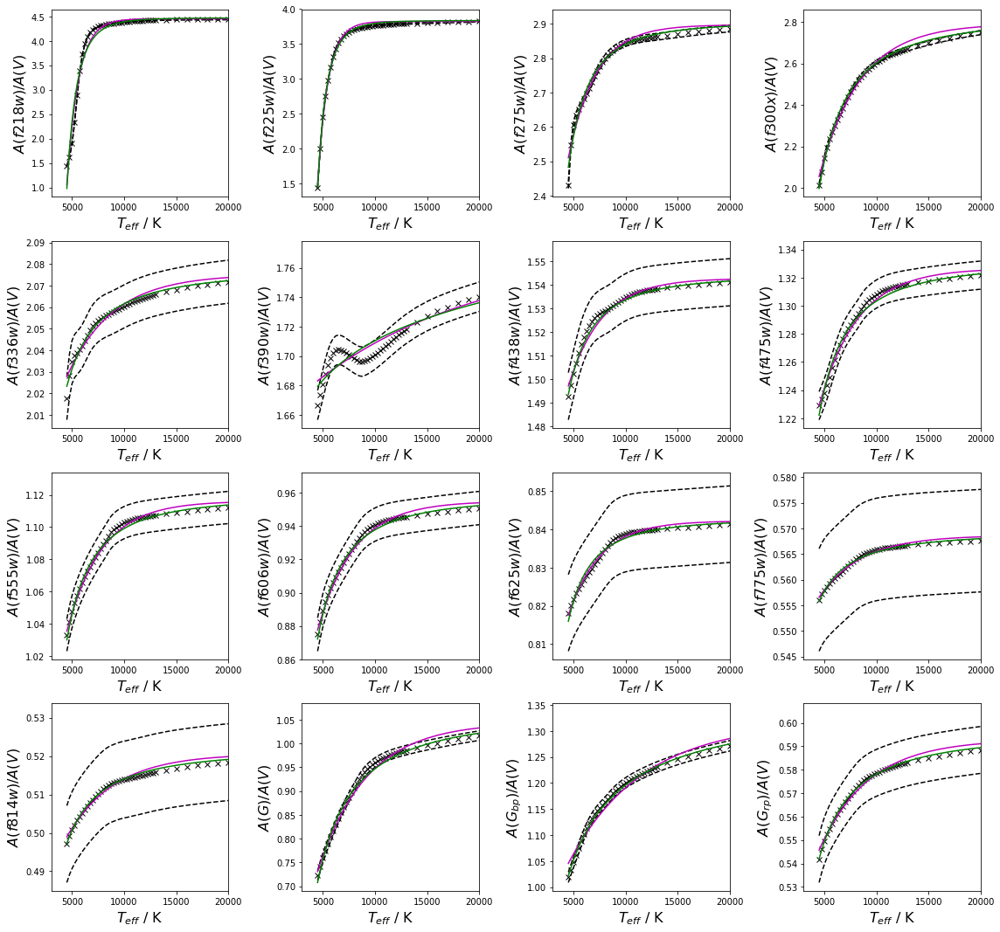


    Writing complete for log(g) = 4.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 4.0
Exponential fit coefficients (should be reused): 
[-190.4307   -8.9475    4.4505]
Standard deviations (should be reused): 
[  3.2087e+00   3.4419e-02   1.3590e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0779 -4.7618  4.4692]
Standard deviations (should be reused): 
[ 0.001   0.0172  0.0014]
Logistic fit coefficients: 
[  5.1844e+03   7.6818e+01   3.0000e+00   1.5307e+00]
Standard deviations: 
[  3.8279e+00   1.8931e+00   1.2235e-03   8.6585e-03]
Teff log-normal fit coefficients: 
[ 0.      3.0437  3.9741  2.    ]
Standard deviations: 
[ 0.      0.3367  0.0014  0.2068]





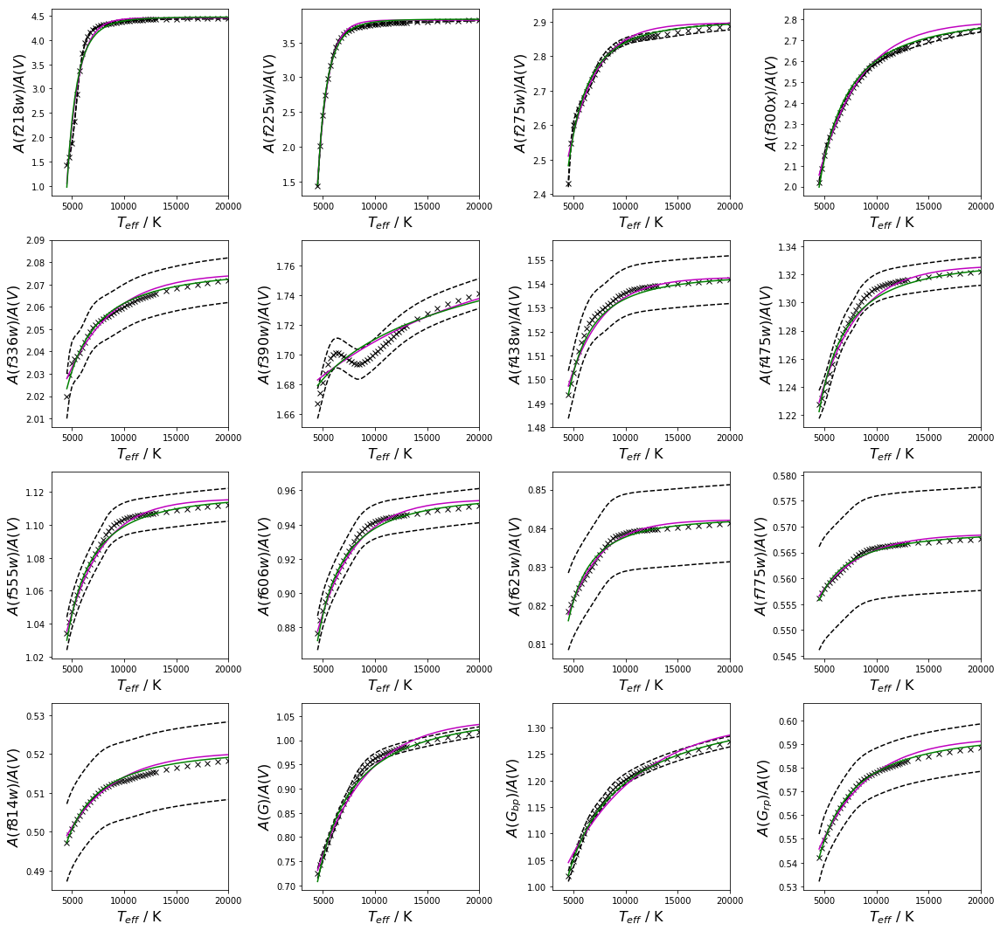


    Writing complete for log(g) = 4.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 3.5
Exponential fit coefficients (should be reused): 
[-190.4307   -8.9475    4.4505]
Standard deviations (should be reused): 
[  3.2087e+00   3.4419e-02   1.3590e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0779 -4.7618  4.4692]
Standard deviations (should be reused): 
[ 0.001   0.0172  0.0014]
Logistic fit coefficients: 
[  5.1844e+03   7.6818e+01   3.0000e+00   1.5307e+00]
Standard deviations: 
[  3.8279e+00   1.8931e+00   1.2235e-03   8.6585e-03]
Teff log-normal fit coefficients: 
[ 0.      3.0437  3.9741  2.    ]
Standard deviations: 
[ 0.      0.3367  0.0014  0.2068]





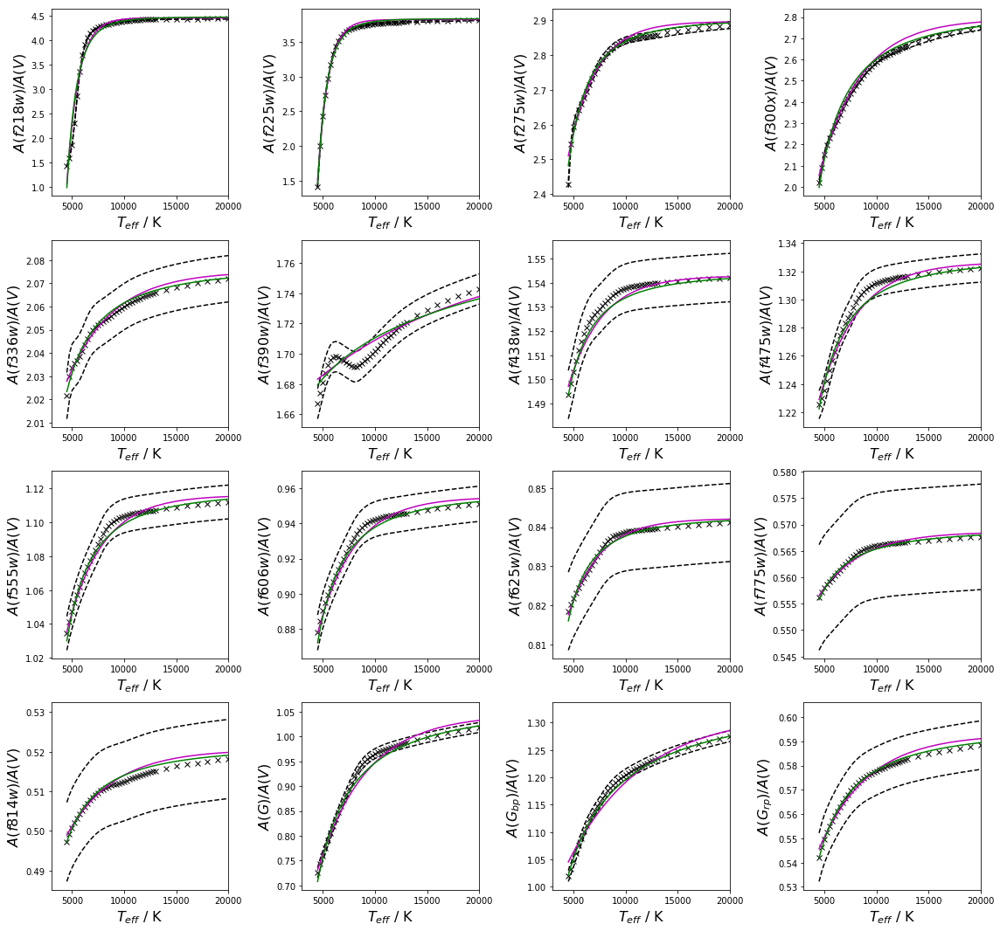


    Writing complete for log(g) = 3.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 3.0
Exponential fit coefficients (should be reused): 
[-190.4307   -8.9475    4.4505]
Standard deviations (should be reused): 
[  3.2087e+00   3.4419e-02   1.3590e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0779 -4.7618  4.4692]
Standard deviations (should be reused): 
[ 0.001   0.0172  0.0014]
Logistic fit coefficients: 
[  5.1844e+03   7.6818e+01   3.0000e+00   1.5307e+00]
Standard deviations: 
[  3.8279e+00   1.8931e+00   1.2235e-03   8.6585e-03]
Teff log-normal fit coefficients: 
[ 0.      3.0437  3.9741  2.    ]
Standard deviations: 
[ 0.      0.3367  0.0014  0.2068]





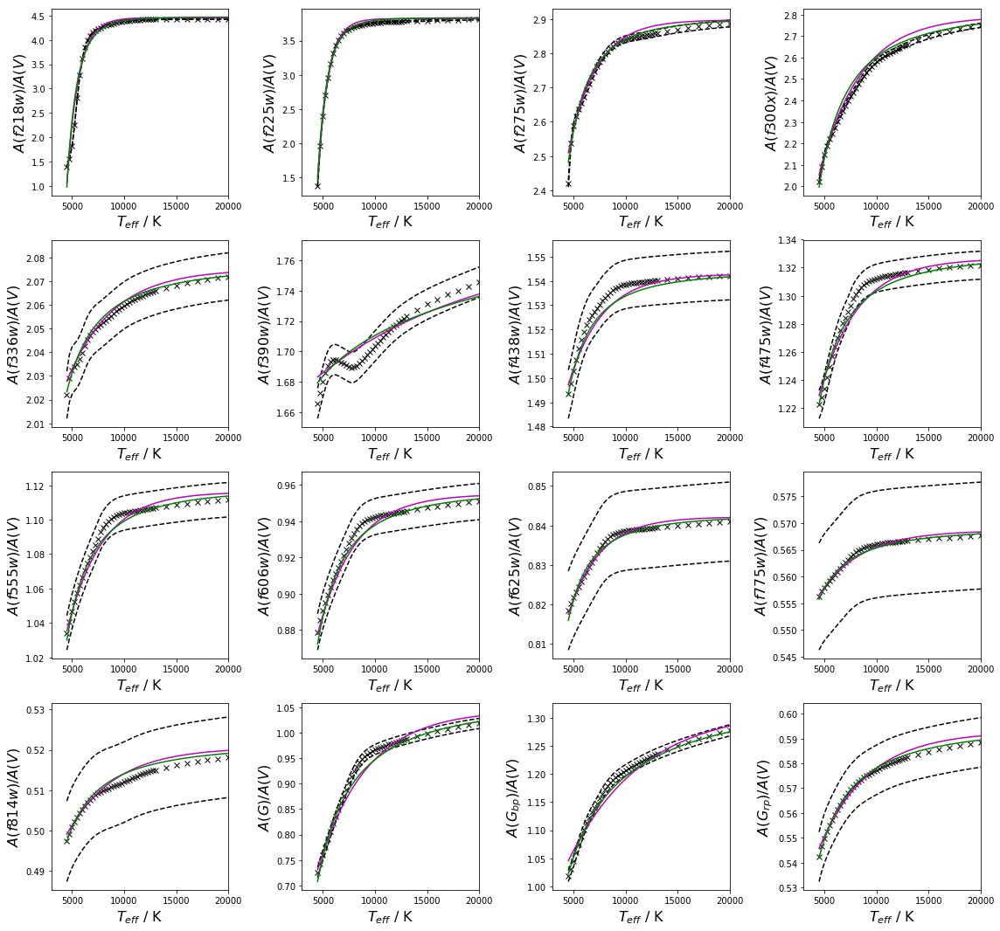


    Writing complete for log(g) = 3.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 2.5
Exponential fit coefficients (should be reused): 
[-190.4307   -8.9475    4.4505]
Standard deviations (should be reused): 
[  3.2087e+00   3.4419e-02   1.3590e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0779 -4.7618  4.4692]
Standard deviations (should be reused): 
[ 0.001   0.0172  0.0014]
Logistic fit coefficients: 
[  5.1844e+03   7.6818e+01   3.0000e+00   1.5307e+00]
Standard deviations: 
[  3.8279e+00   1.8931e+00   1.2235e-03   8.6585e-03]
Teff log-normal fit coefficients: 
[ 0.      3.0437  3.9741  2.    ]
Standard deviations: 
[ 0.      0.3367  0.0014  0.2068]





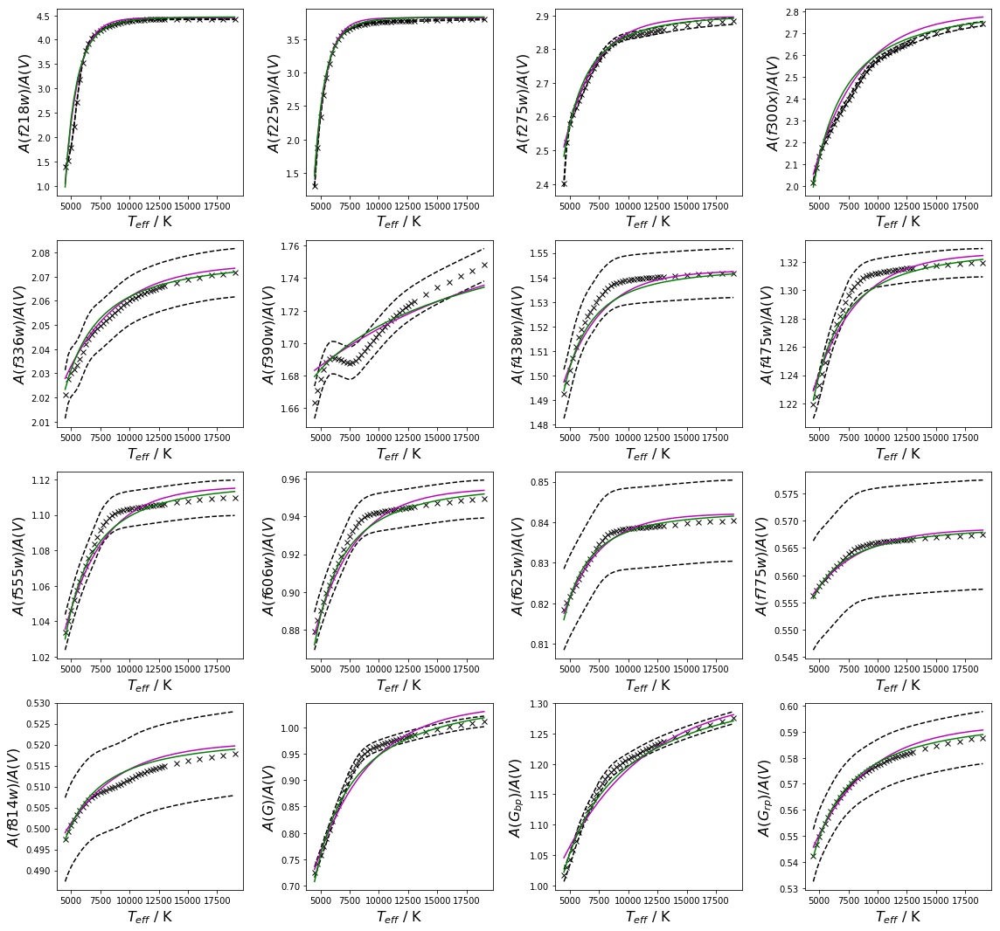


    Writing complete for log(g) = 2.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 2.0
Exponential fit coefficients (should be reused): 
[-190.4307   -8.9475    4.4505]
Standard deviations (should be reused): 
[  3.2087e+00   3.4419e-02   1.3590e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0779 -4.7618  4.4692]
Standard deviations (should be reused): 
[ 0.001   0.0172  0.0014]
Logistic fit coefficients: 
[  5.1844e+03   7.6818e+01   3.0000e+00   1.5307e+00]
Standard deviations: 
[  3.8279e+00   1.8931e+00   1.2235e-03   8.6585e-03]
Teff log-normal fit coefficients: 
[ 0.      3.0437  3.9741  2.    ]
Standard deviations: 
[ 0.      0.3367  0.0014  0.2068]





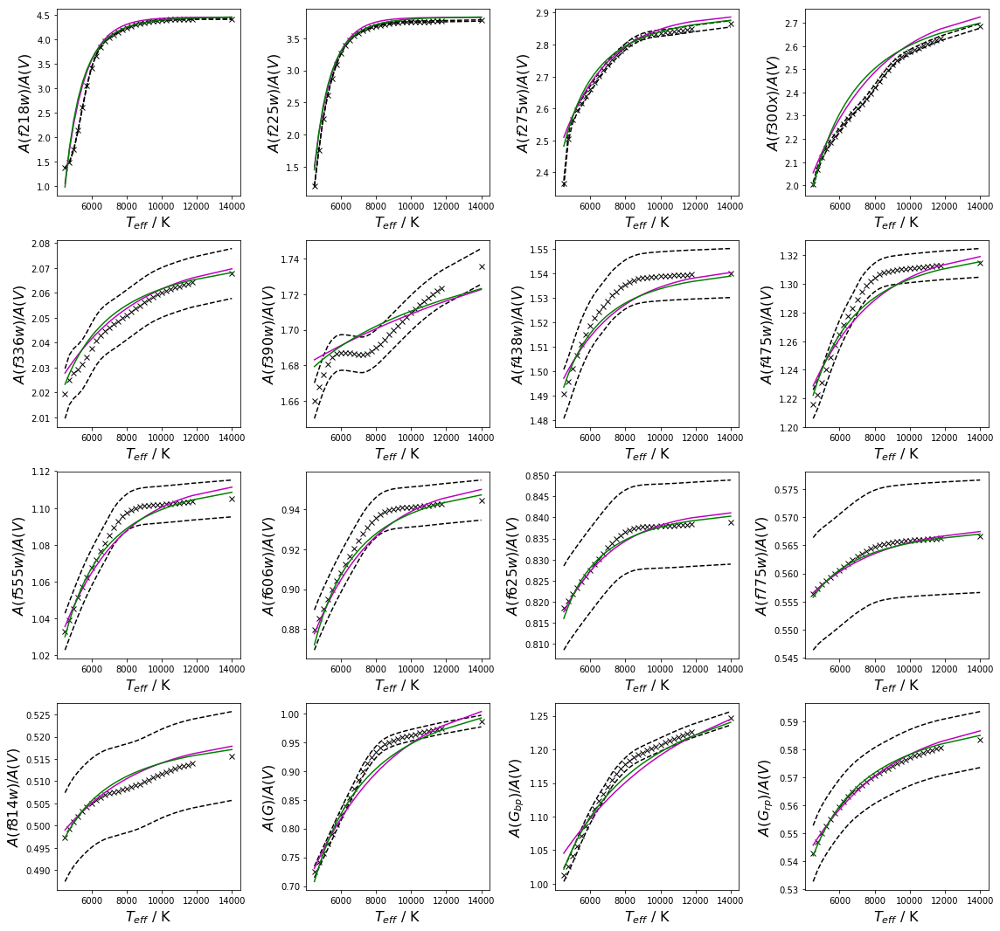


    Writing complete for log(g) = 2.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 1.5
Exponential fit coefficients (should be reused): 
[-190.4307   -8.9475    4.4505]
Standard deviations (should be reused): 
[  3.2087e+00   3.4419e-02   1.3590e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0779 -4.7618  4.4692]
Standard deviations (should be reused): 
[ 0.001   0.0172  0.0014]
Logistic fit coefficients: 
[  5.1844e+03   7.6818e+01   3.0000e+00   1.5307e+00]
Standard deviations: 
[  3.8279e+00   1.8931e+00   1.2235e-03   8.6585e-03]
Teff log-normal fit coefficients: 
[ 0.      3.0437  3.9741  2.    ]
Standard deviations: 
[ 0.      0.3367  0.0014  0.2068]





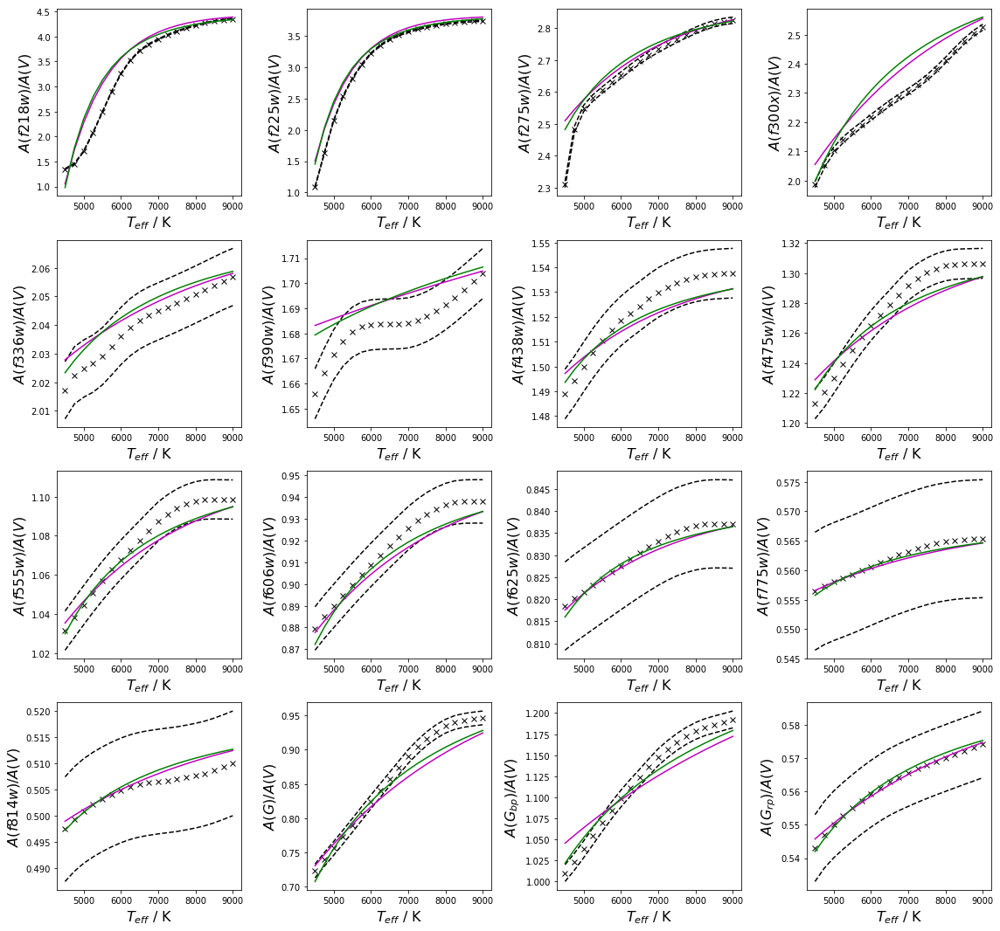


    Writing complete for log(g) = 1.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 1.0
Exponential fit coefficients (should be reused): 
[-190.4307   -8.9475    4.4505]
Standard deviations (should be reused): 
[  3.2087e+00   3.4419e-02   1.3590e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0779 -4.7618  4.4692]
Standard deviations (should be reused): 
[ 0.001   0.0172  0.0014]
Logistic fit coefficients: 
[  5.1844e+03   7.6818e+01   3.0000e+00   1.5307e+00]
Standard deviations: 
[  3.8279e+00   1.8931e+00   1.2235e-03   8.6585e-03]
Teff log-normal fit coefficients: 
[ 0.      3.0437  3.9741  2.    ]
Standard deviations: 
[ 0.      0.3367  0.0014  0.2068]





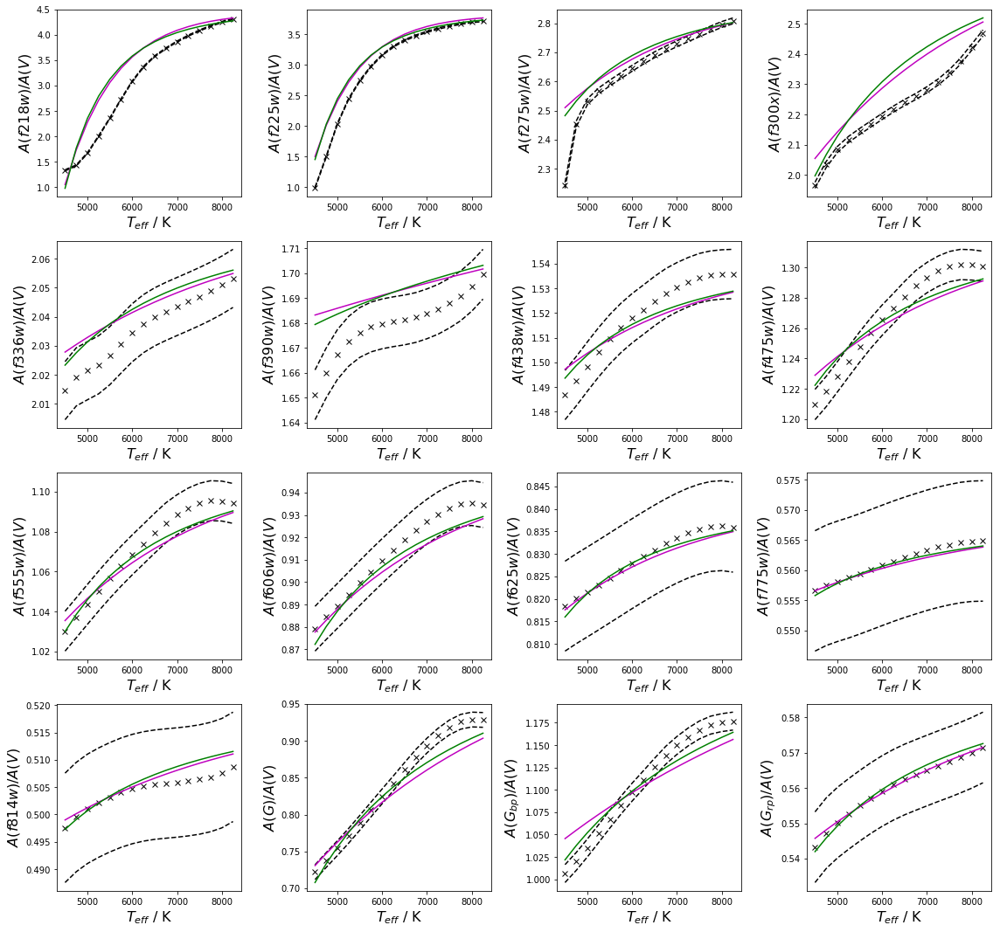


    Writing complete for log(g) = 1.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 0.5
Exponential fit coefficients (should be reused): 
[-190.4307   -8.9475    4.4505]
Standard deviations (should be reused): 
[  3.2087e+00   3.4419e-02   1.3590e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0779 -4.7618  4.4692]
Standard deviations (should be reused): 
[ 0.001   0.0172  0.0014]
Logistic fit coefficients: 
[  5.1844e+03   7.6818e+01   3.0000e+00   1.5307e+00]
Standard deviations: 
[  3.8279e+00   1.8931e+00   1.2235e-03   8.6585e-03]
Teff log-normal fit coefficients: 
[ 0.      3.0437  3.9741  2.    ]
Standard deviations: 
[ 0.      0.3367  0.0014  0.2068]





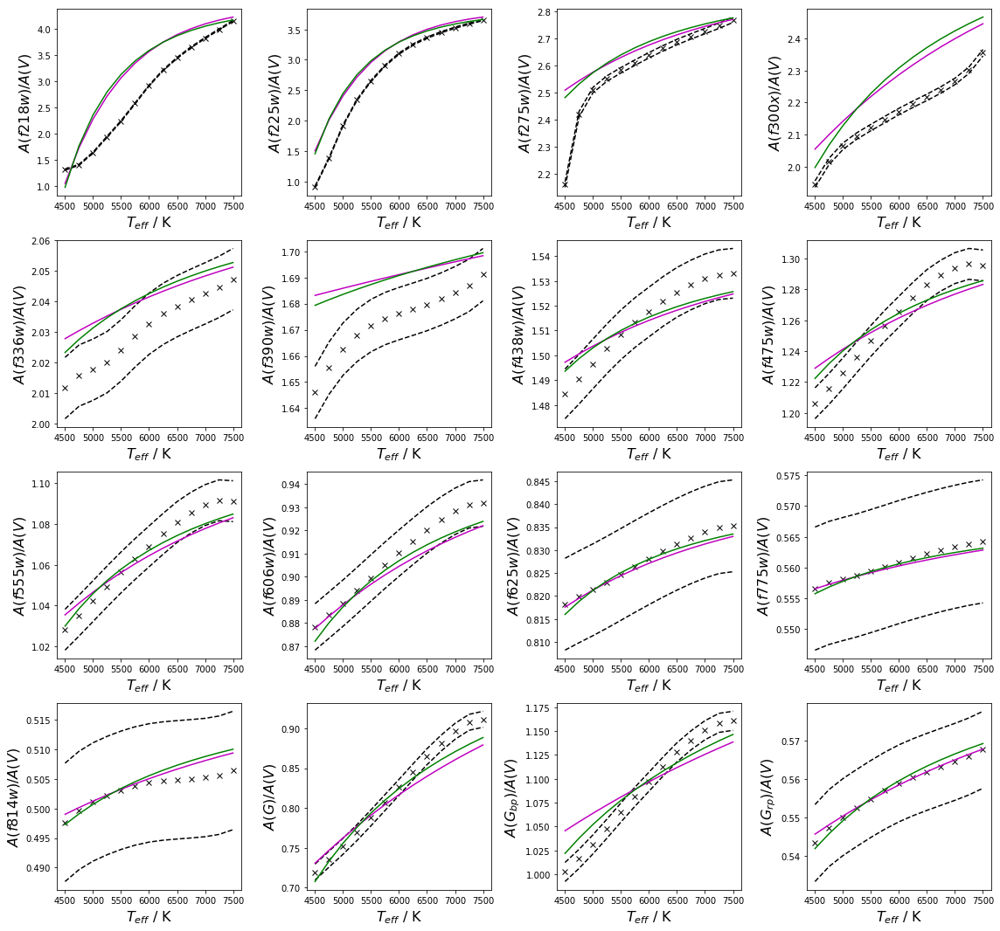


    Writing complete for log(g) = 0.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 0.0
Exponential fit coefficients (should be reused): 
[-190.4307   -8.9475    4.4505]
Standard deviations (should be reused): 
[  3.2087e+00   3.4419e-02   1.3590e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0779 -4.7618  4.4692]
Standard deviations (should be reused): 
[ 0.001   0.0172  0.0014]
Logistic fit coefficients: 
[  5.1844e+03   7.6818e+01   3.0000e+00   1.5307e+00]
Standard deviations: 
[  3.8279e+00   1.8931e+00   1.2235e-03   8.6585e-03]
Teff log-normal fit coefficients: 
[ 0.      3.0437  3.9741  2.    ]
Standard deviations: 
[ 0.      0.3367  0.0014  0.2068]





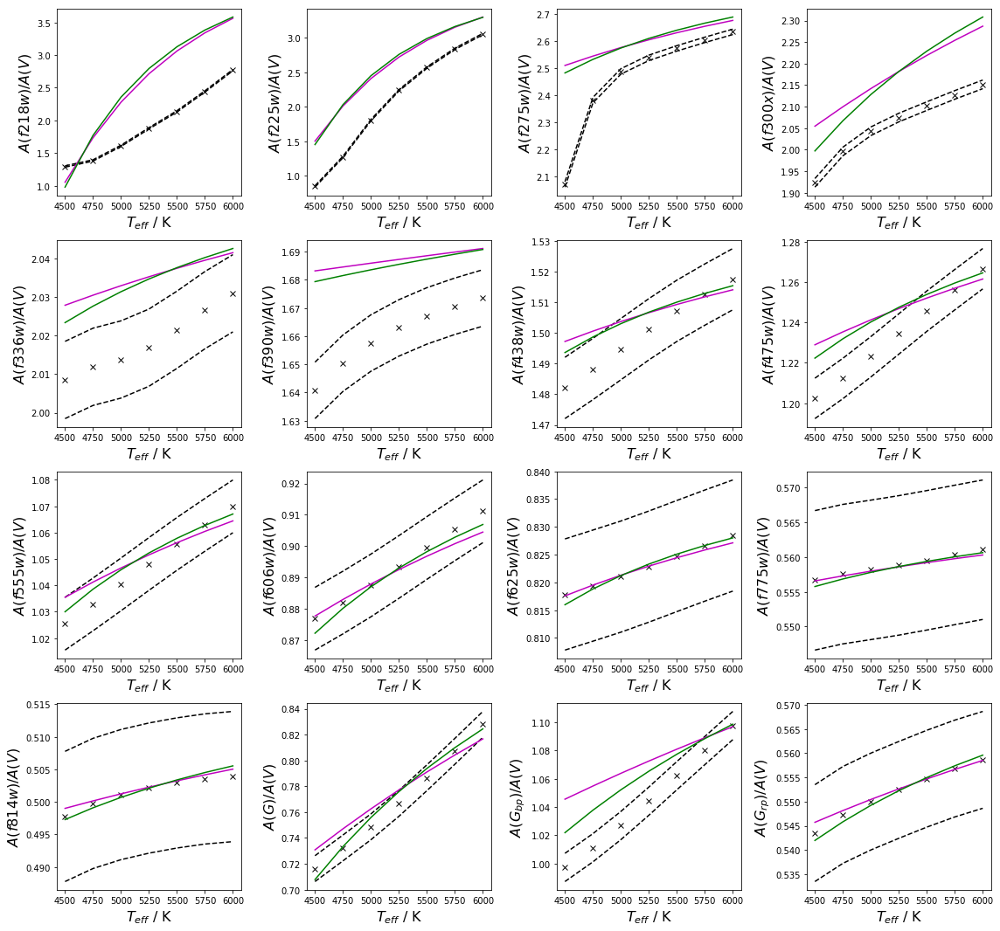


    Writing complete for log(g) = 0.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 5.0


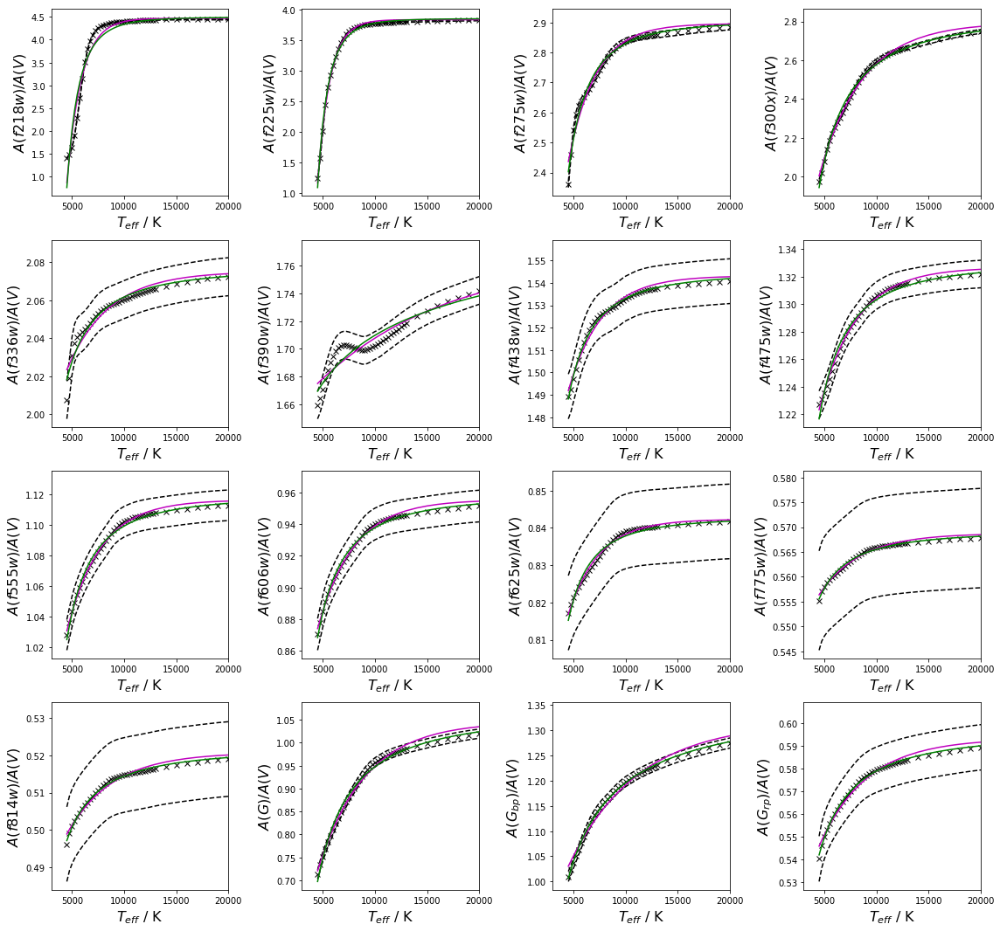


    Writing complete for log(g) = 5.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 4.5
Exponential fit coefficients (should be reused): 
[-88.0896  -7.1033   4.4706]
Standard deviations (should be reused): 
[ 1.0545  0.0239  0.0014]
Teff^(n) fit coefficients (should be reused): 
[-0.1604 -3.9428  4.4974]
Standard deviations (should be reused): 
[ 0.0015  0.0124  0.0015]
Logistic fit coefficients: 
[  5.4456e+03   6.1963e+01   3.0000e+00   1.4764e+00]
Standard deviations: 
[  3.9657e+00   1.2905e+00   1.2378e-03   7.1786e-03]
Teff log-normal fit coefficients: 
[ 0.      2.2475  3.8614  2.    ]
Standard deviations: 
[ 0.      0.1121  0.0014  0.0843]





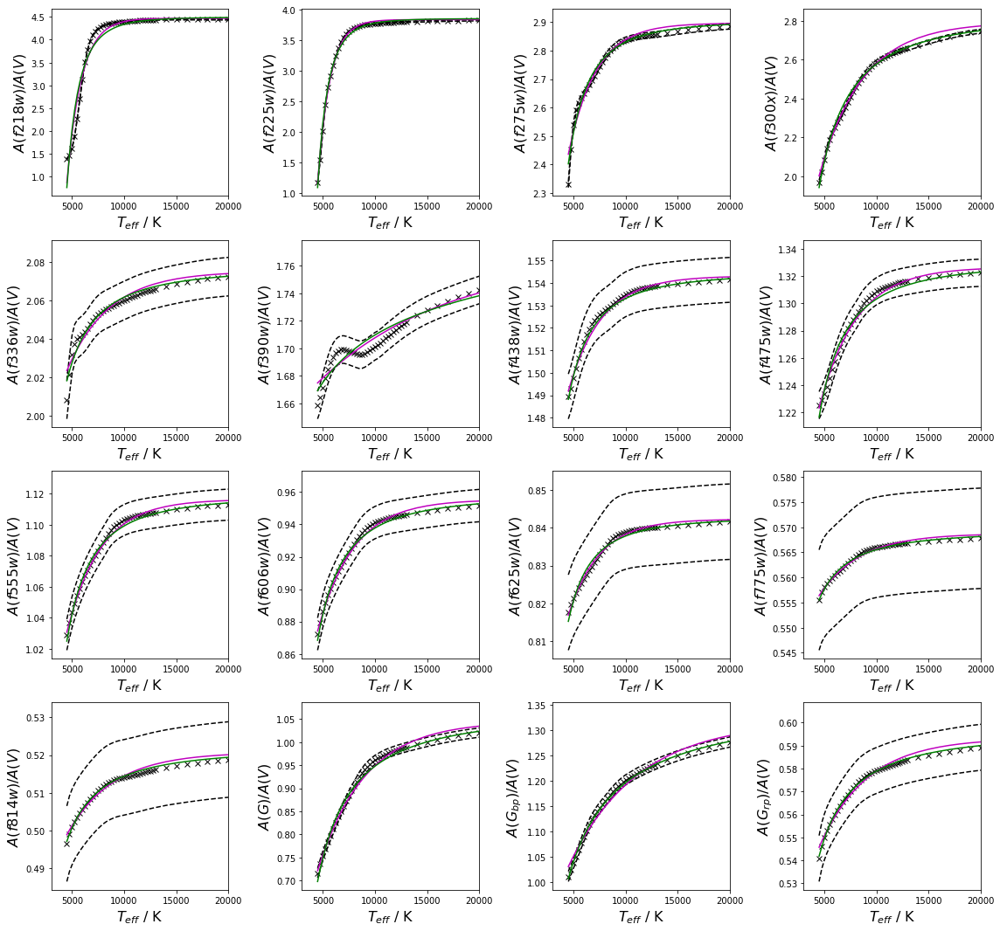


    Writing complete for log(g) = 4.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 4.0
Exponential fit coefficients (should be reused): 
[-88.0896  -7.1033   4.4706]
Standard deviations (should be reused): 
[ 1.0545  0.0239  0.0014]
Teff^(n) fit coefficients (should be reused): 
[-0.1604 -3.9428  4.4974]
Standard deviations (should be reused): 
[ 0.0015  0.0124  0.0015]
Logistic fit coefficients: 
[  5.4456e+03   6.1963e+01   3.0000e+00   1.4764e+00]
Standard deviations: 
[  3.9657e+00   1.2905e+00   1.2378e-03   7.1786e-03]
Teff log-normal fit coefficients: 
[ 0.      2.2475  3.8614  2.    ]
Standard deviations: 
[ 0.      0.1121  0.0014  0.0843]





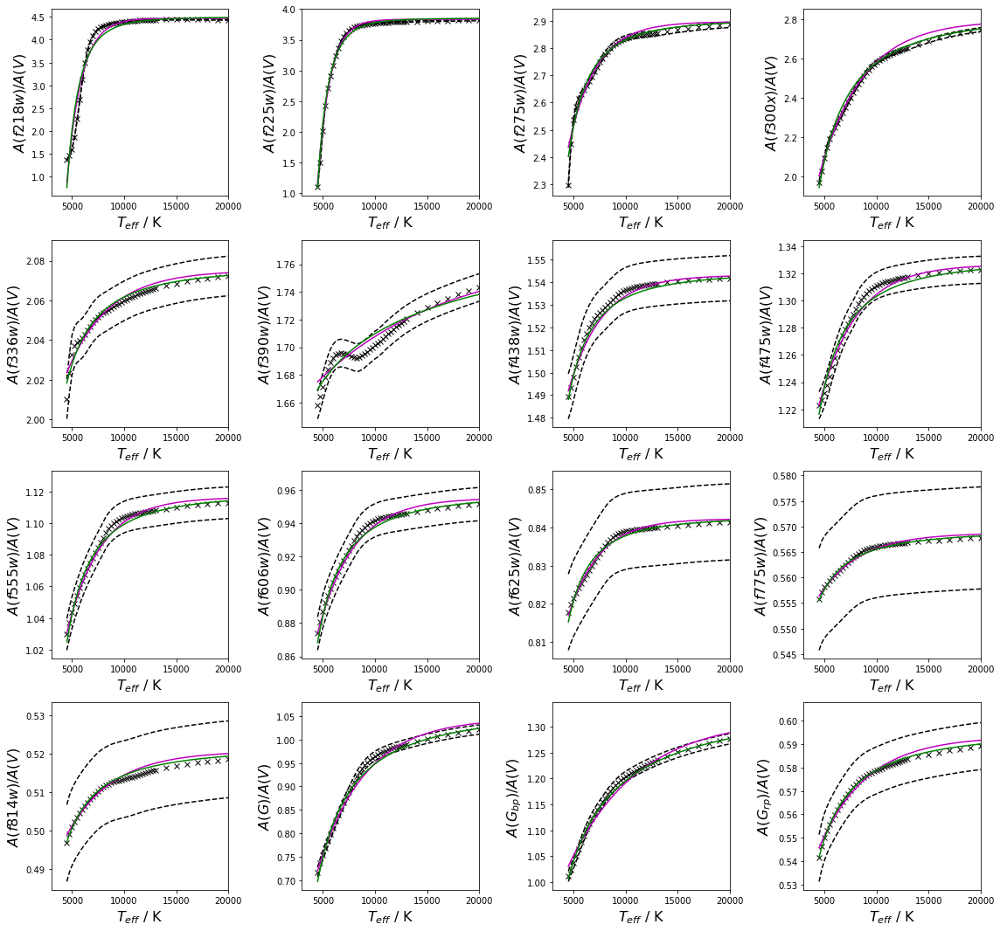


    Writing complete for log(g) = 4.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 3.5
Exponential fit coefficients (should be reused): 
[-88.0896  -7.1033   4.4706]
Standard deviations (should be reused): 
[ 1.0545  0.0239  0.0014]
Teff^(n) fit coefficients (should be reused): 
[-0.1604 -3.9428  4.4974]
Standard deviations (should be reused): 
[ 0.0015  0.0124  0.0015]
Logistic fit coefficients: 
[  5.4456e+03   6.1963e+01   3.0000e+00   1.4764e+00]
Standard deviations: 
[  3.9657e+00   1.2905e+00   1.2378e-03   7.1786e-03]
Teff log-normal fit coefficients: 
[ 0.      2.2475  3.8614  2.    ]
Standard deviations: 
[ 0.      0.1121  0.0014  0.0843]





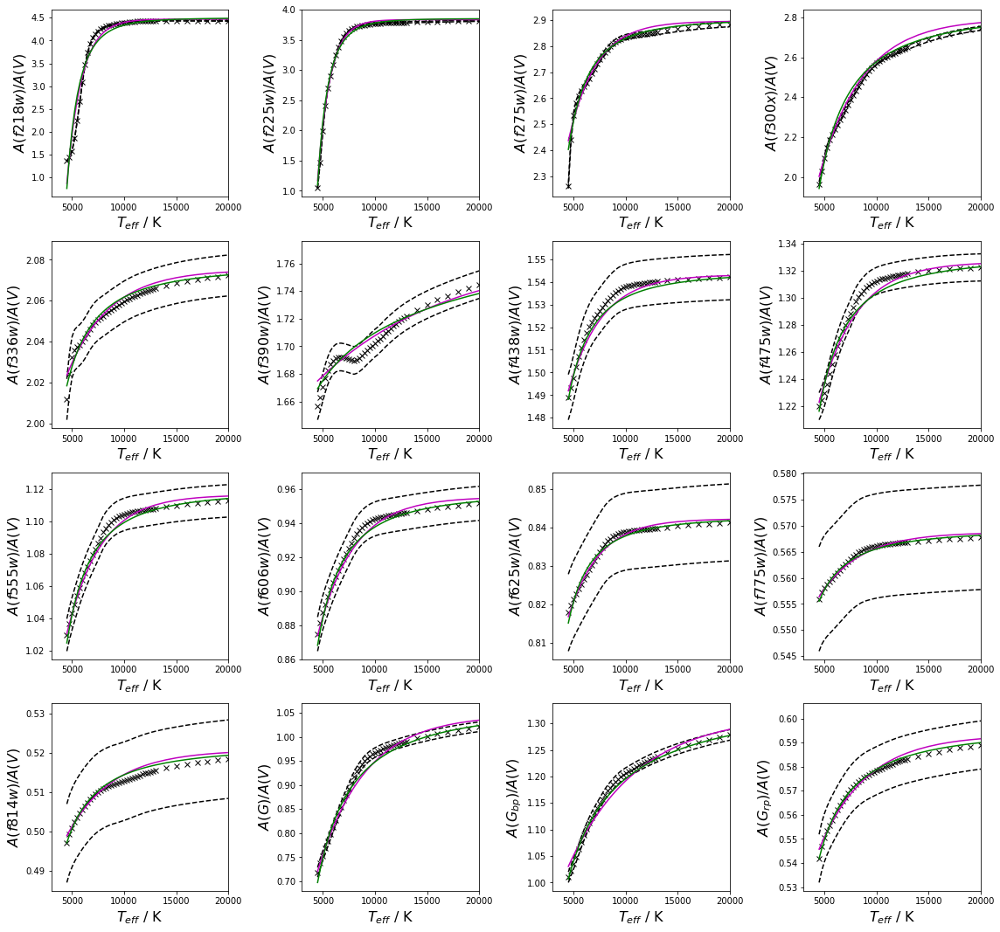


    Writing complete for log(g) = 3.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 3.0
Exponential fit coefficients (should be reused): 
[-88.0896  -7.1033   4.4706]
Standard deviations (should be reused): 
[ 1.0545  0.0239  0.0014]
Teff^(n) fit coefficients (should be reused): 
[-0.1604 -3.9428  4.4974]
Standard deviations (should be reused): 
[ 0.0015  0.0124  0.0015]
Logistic fit coefficients: 
[  5.4456e+03   6.1963e+01   3.0000e+00   1.4764e+00]
Standard deviations: 
[  3.9657e+00   1.2905e+00   1.2378e-03   7.1786e-03]
Teff log-normal fit coefficients: 
[ 0.      2.2475  3.8614  2.    ]
Standard deviations: 
[ 0.      0.1121  0.0014  0.0843]





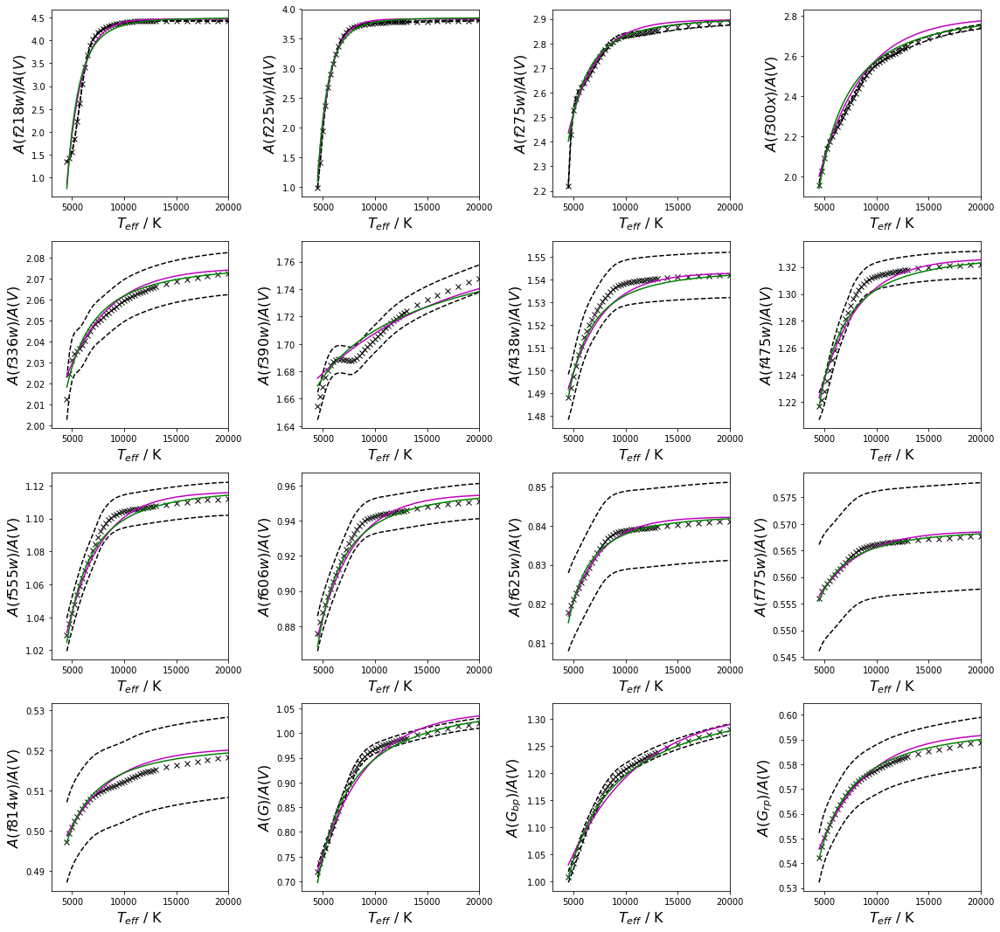


    Writing complete for log(g) = 3.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 2.5
Exponential fit coefficients (should be reused): 
[-88.0896  -7.1033   4.4706]
Standard deviations (should be reused): 
[ 1.0545  0.0239  0.0014]
Teff^(n) fit coefficients (should be reused): 
[-0.1604 -3.9428  4.4974]
Standard deviations (should be reused): 
[ 0.0015  0.0124  0.0015]
Logistic fit coefficients: 
[  5.4456e+03   6.1963e+01   3.0000e+00   1.4764e+00]
Standard deviations: 
[  3.9657e+00   1.2905e+00   1.2378e-03   7.1786e-03]
Teff log-normal fit coefficients: 
[ 0.      2.2475  3.8614  2.    ]
Standard deviations: 
[ 0.      0.1121  0.0014  0.0843]





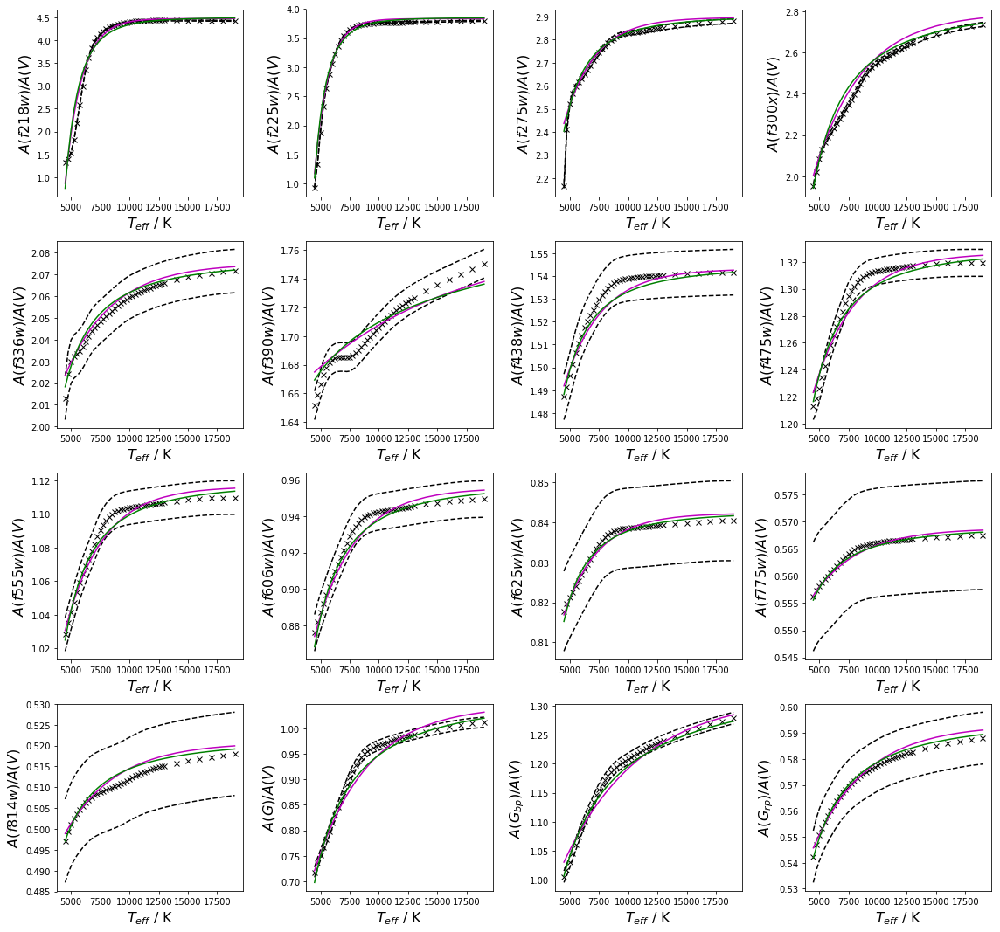


    Writing complete for log(g) = 2.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 2.0
Exponential fit coefficients (should be reused): 
[-88.0896  -7.1033   4.4706]
Standard deviations (should be reused): 
[ 1.0545  0.0239  0.0014]
Teff^(n) fit coefficients (should be reused): 
[-0.1604 -3.9428  4.4974]
Standard deviations (should be reused): 
[ 0.0015  0.0124  0.0015]
Logistic fit coefficients: 
[  5.4456e+03   6.1963e+01   3.0000e+00   1.4764e+00]
Standard deviations: 
[  3.9657e+00   1.2905e+00   1.2378e-03   7.1786e-03]
Teff log-normal fit coefficients: 
[ 0.      2.2475  3.8614  2.    ]
Standard deviations: 
[ 0.      0.1121  0.0014  0.0843]





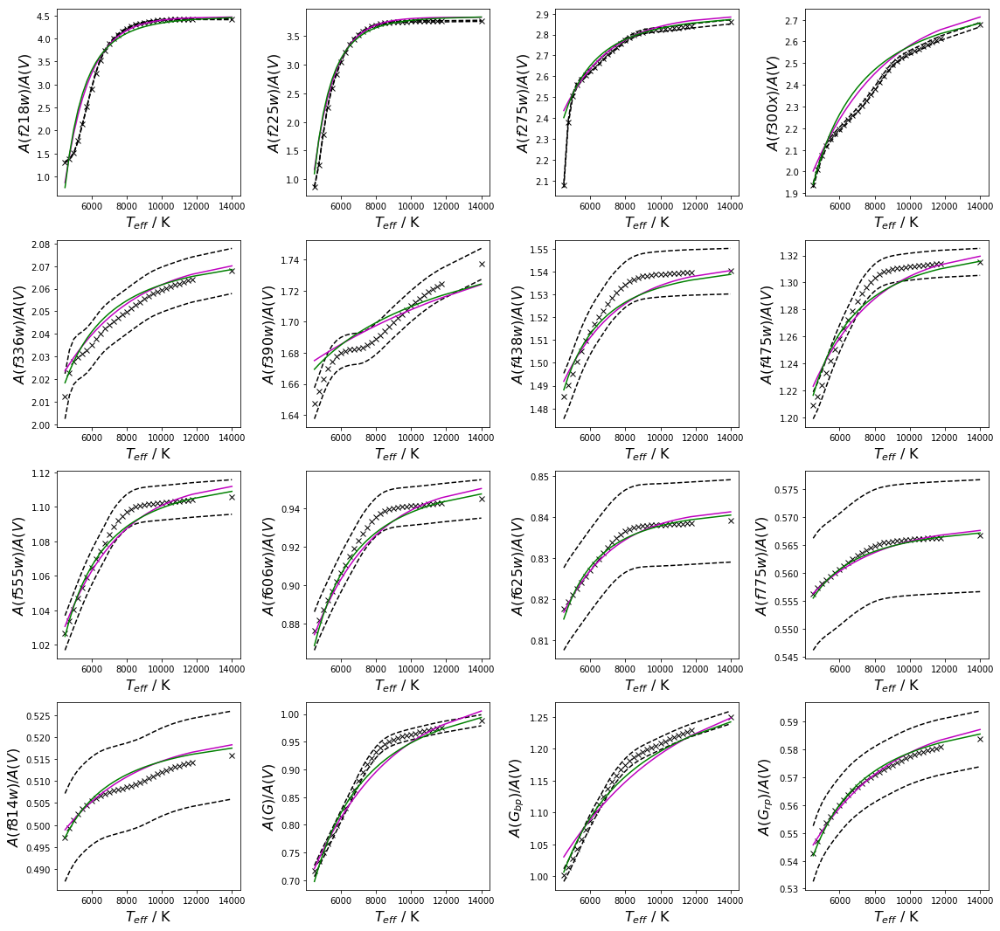


    Writing complete for log(g) = 2.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 1.5
Exponential fit coefficients (should be reused): 
[-88.0896  -7.1033   4.4706]
Standard deviations (should be reused): 
[ 1.0545  0.0239  0.0014]
Teff^(n) fit coefficients (should be reused): 
[-0.1604 -3.9428  4.4974]
Standard deviations (should be reused): 
[ 0.0015  0.0124  0.0015]
Logistic fit coefficients: 
[  5.4456e+03   6.1963e+01   3.0000e+00   1.4764e+00]
Standard deviations: 
[  3.9657e+00   1.2905e+00   1.2378e-03   7.1786e-03]
Teff log-normal fit coefficients: 
[ 0.      2.2475  3.8614  2.    ]
Standard deviations: 
[ 0.      0.1121  0.0014  0.0843]





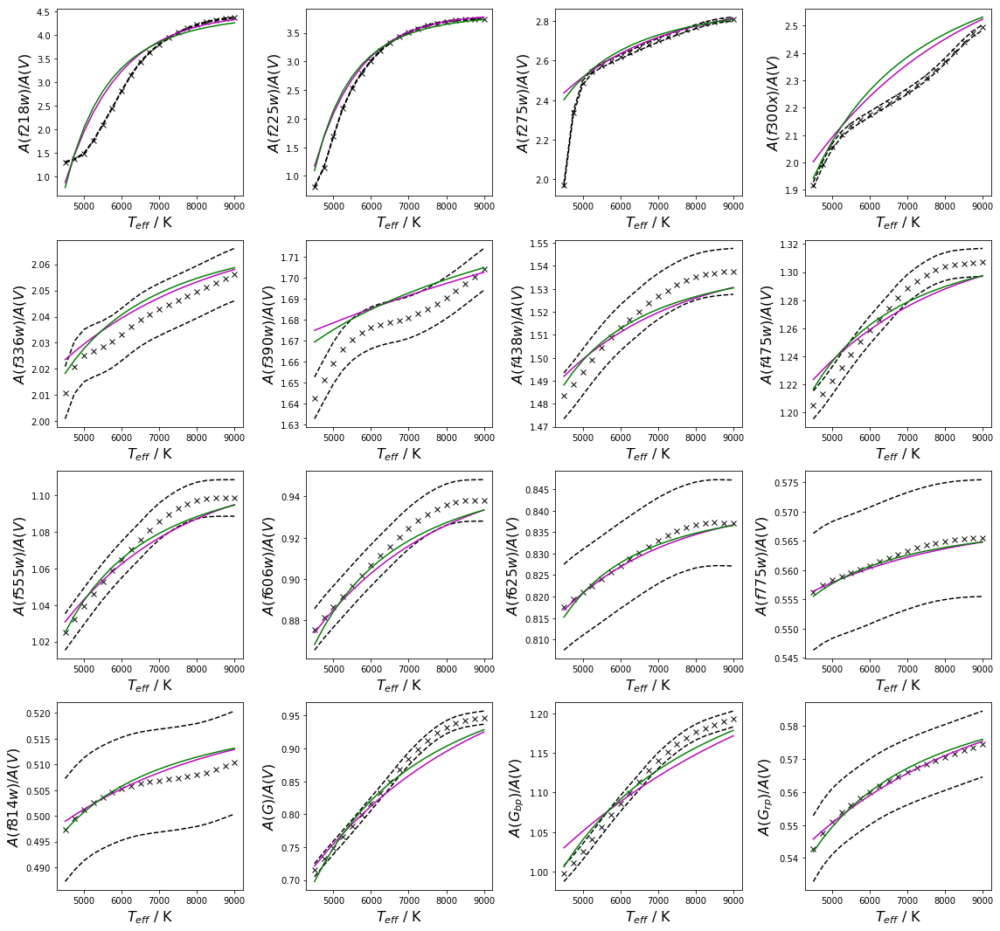


    Writing complete for log(g) = 1.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 1.0
Exponential fit coefficients (should be reused): 
[-88.0896  -7.1033   4.4706]
Standard deviations (should be reused): 
[ 1.0545  0.0239  0.0014]
Teff^(n) fit coefficients (should be reused): 
[-0.1604 -3.9428  4.4974]
Standard deviations (should be reused): 
[ 0.0015  0.0124  0.0015]
Logistic fit coefficients: 
[  5.4456e+03   6.1963e+01   3.0000e+00   1.4764e+00]
Standard deviations: 
[  3.9657e+00   1.2905e+00   1.2378e-03   7.1786e-03]
Teff log-normal fit coefficients: 
[ 0.      2.2475  3.8614  2.    ]
Standard deviations: 
[ 0.      0.1121  0.0014  0.0843]





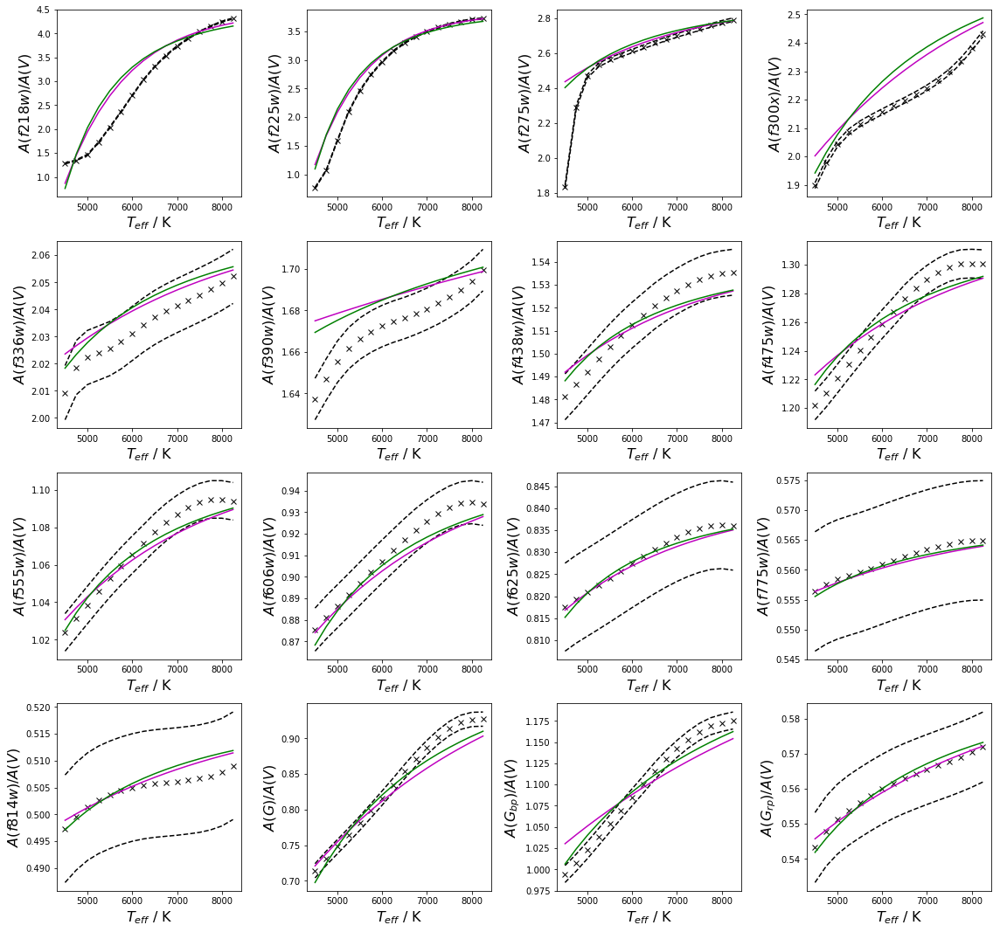


    Writing complete for log(g) = 1.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 0.5
Exponential fit coefficients (should be reused): 
[-88.0896  -7.1033   4.4706]
Standard deviations (should be reused): 
[ 1.0545  0.0239  0.0014]
Teff^(n) fit coefficients (should be reused): 
[-0.1604 -3.9428  4.4974]
Standard deviations (should be reused): 
[ 0.0015  0.0124  0.0015]
Logistic fit coefficients: 
[  5.4456e+03   6.1963e+01   3.0000e+00   1.4764e+00]
Standard deviations: 
[  3.9657e+00   1.2905e+00   1.2378e-03   7.1786e-03]
Teff log-normal fit coefficients: 
[ 0.      2.2475  3.8614  2.    ]
Standard deviations: 
[ 0.      0.1121  0.0014  0.0843]





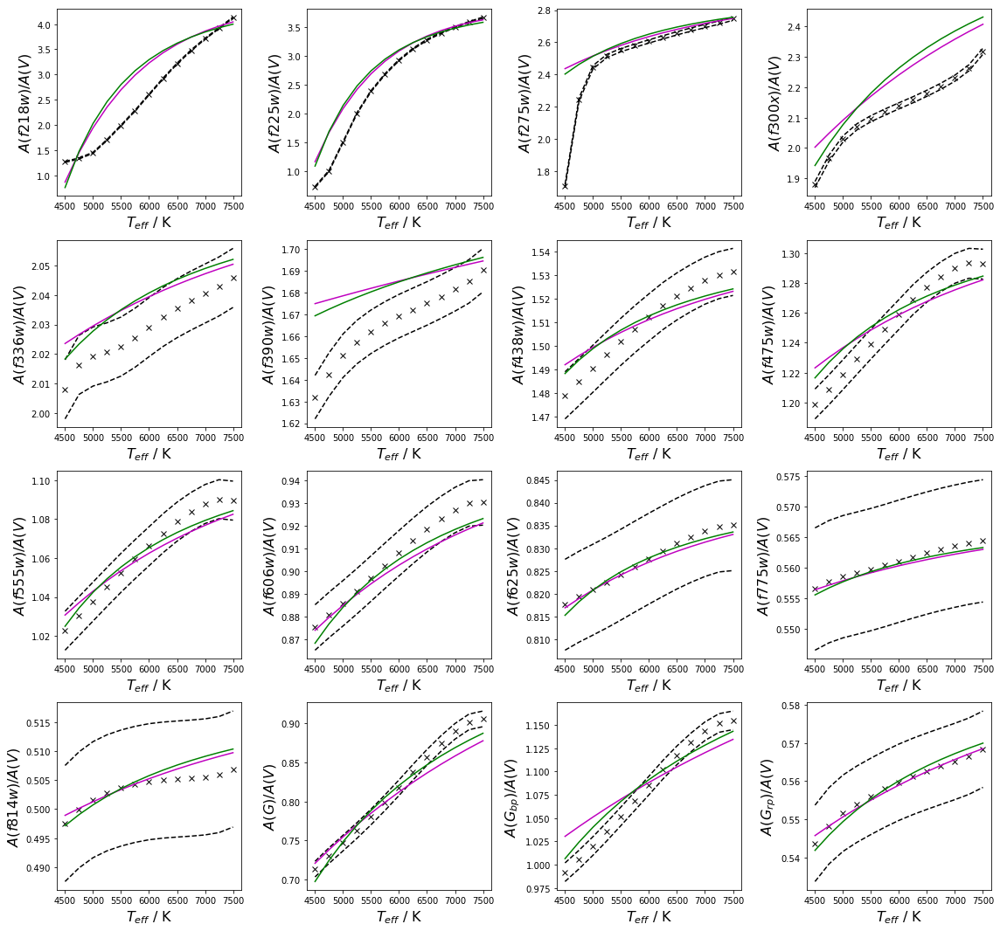


    Writing complete for log(g) = 0.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 0.0
Exponential fit coefficients (should be reused): 
[-88.0896  -7.1033   4.4706]
Standard deviations (should be reused): 
[ 1.0545  0.0239  0.0014]
Teff^(n) fit coefficients (should be reused): 
[-0.1604 -3.9428  4.4974]
Standard deviations (should be reused): 
[ 0.0015  0.0124  0.0015]
Logistic fit coefficients: 
[  5.4456e+03   6.1963e+01   3.0000e+00   1.4764e+00]
Standard deviations: 
[  3.9657e+00   1.2905e+00   1.2378e-03   7.1786e-03]
Teff log-normal fit coefficients: 
[ 0.      2.2475  3.8614  2.    ]
Standard deviations: 
[ 0.      0.1121  0.0014  0.0843]





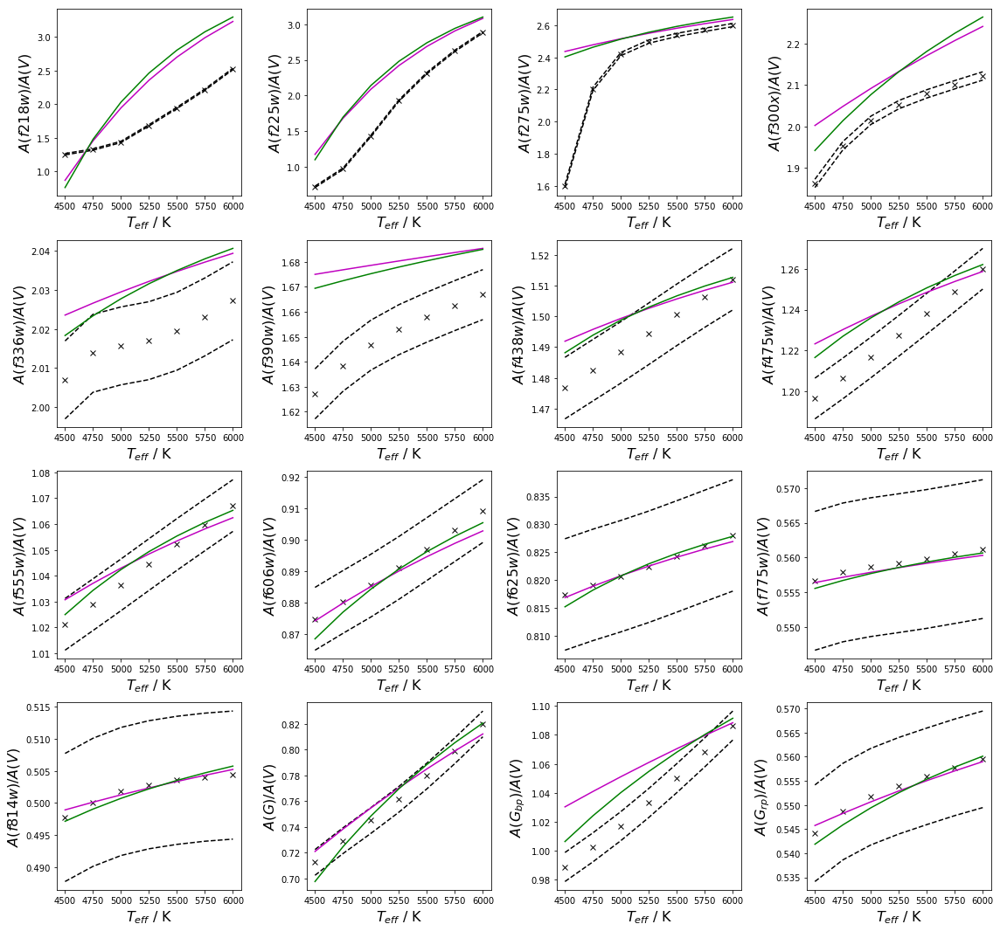


    Writing complete for log(g) = 0.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 5.0


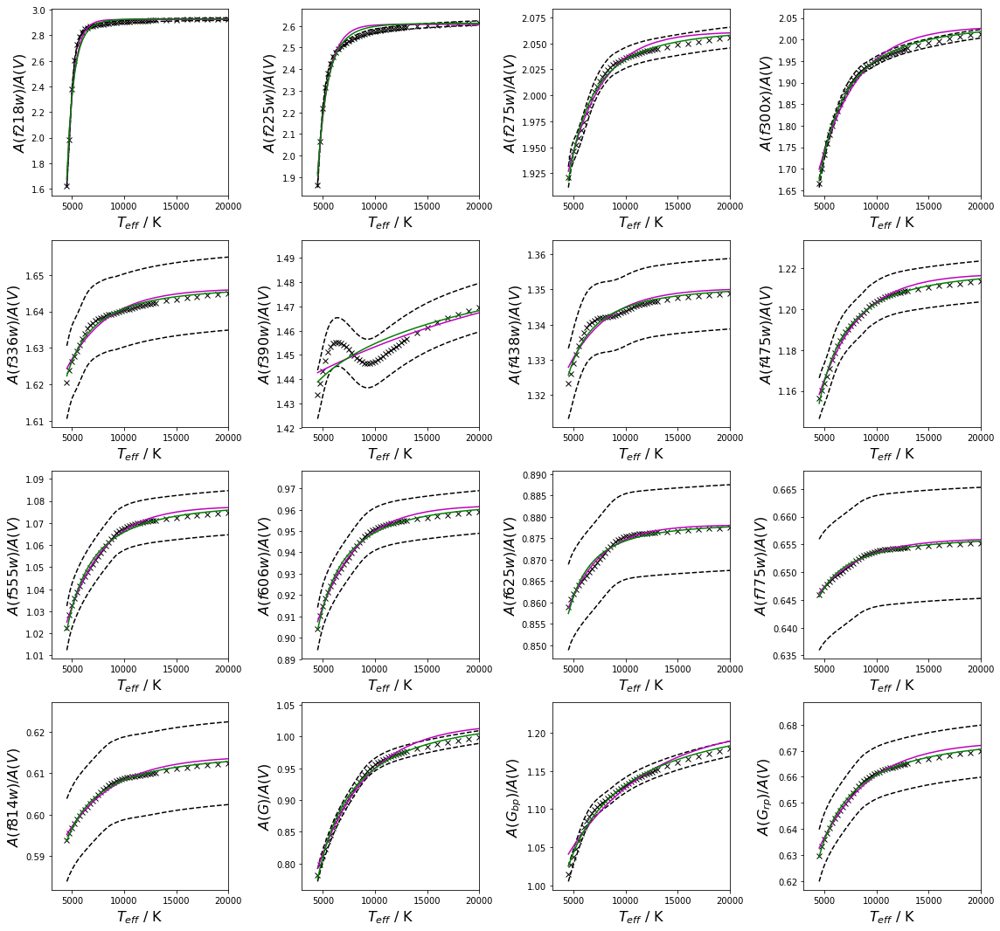


    Writing complete for log(g) = 5.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 4.5
Exponential fit coefficients (should be reused): 
[-1000.      -14.8476    2.9241]
Standard deviations (should be reused): 
[  8.6241e+01   1.8304e-01   1.2793e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6864e-03  -7.0000e+00   2.9294e+00]
Standard deviations (should be reused): 
[ 0.0003  0.0814  0.0013]
Logistic fit coefficients: 
[  4.0435e+03   2.1045e+01   2.9184e+00  -1.8391e+00]
Standard deviations: 
[  1.4038e+02   7.7965e-01   1.2716e-03   9.1516e-01]
Teff log-normal fit coefficients: 
[ 0.      4.7935  2.8046  2.    ]
Standard deviations: 
[  0.0000e+00   4.8850e+00   1.4296e-03   8.0175e-01]





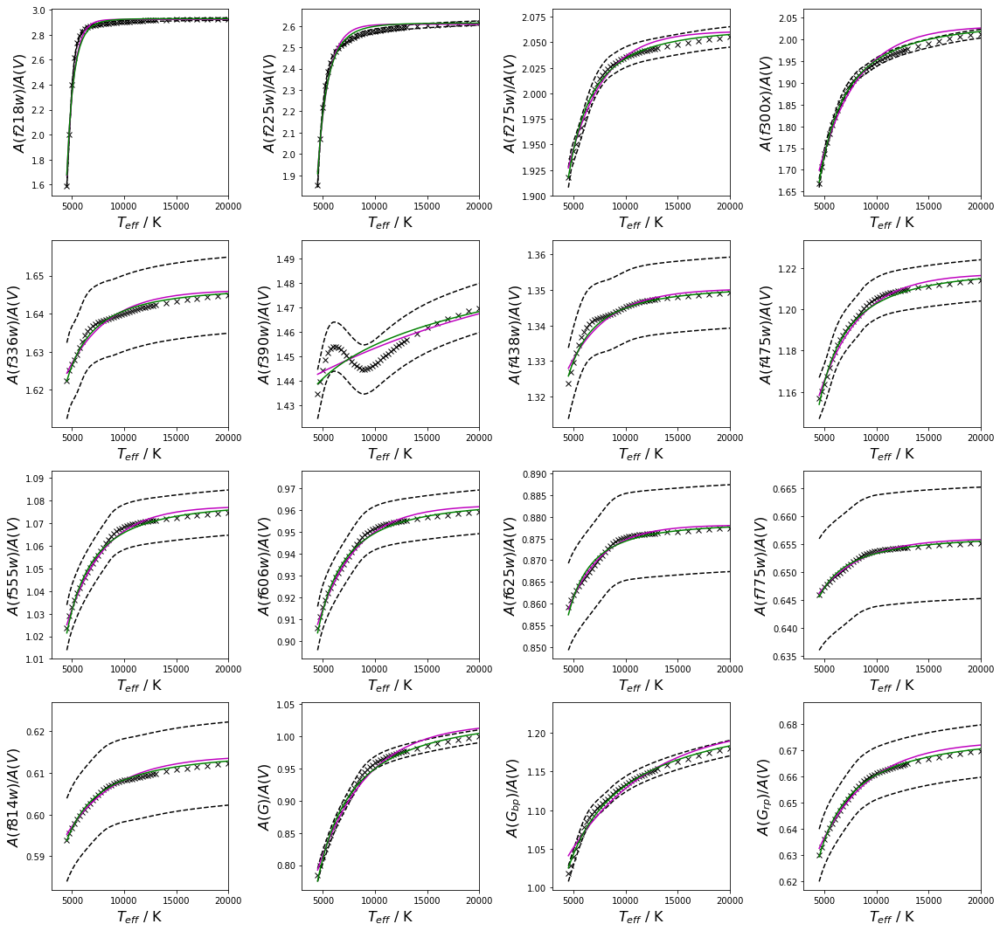


    Writing complete for log(g) = 4.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 4.0
Exponential fit coefficients (should be reused): 
[-1000.      -14.8476    2.9241]
Standard deviations (should be reused): 
[  8.6241e+01   1.8304e-01   1.2793e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6864e-03  -7.0000e+00   2.9294e+00]
Standard deviations (should be reused): 
[ 0.0003  0.0814  0.0013]
Logistic fit coefficients: 
[  4.0435e+03   2.1045e+01   2.9184e+00  -1.8391e+00]
Standard deviations: 
[  1.4038e+02   7.7965e-01   1.2716e-03   9.1516e-01]
Teff log-normal fit coefficients: 
[ 0.      4.7935  2.8046  2.    ]
Standard deviations: 
[  0.0000e+00   4.8850e+00   1.4296e-03   8.0175e-01]





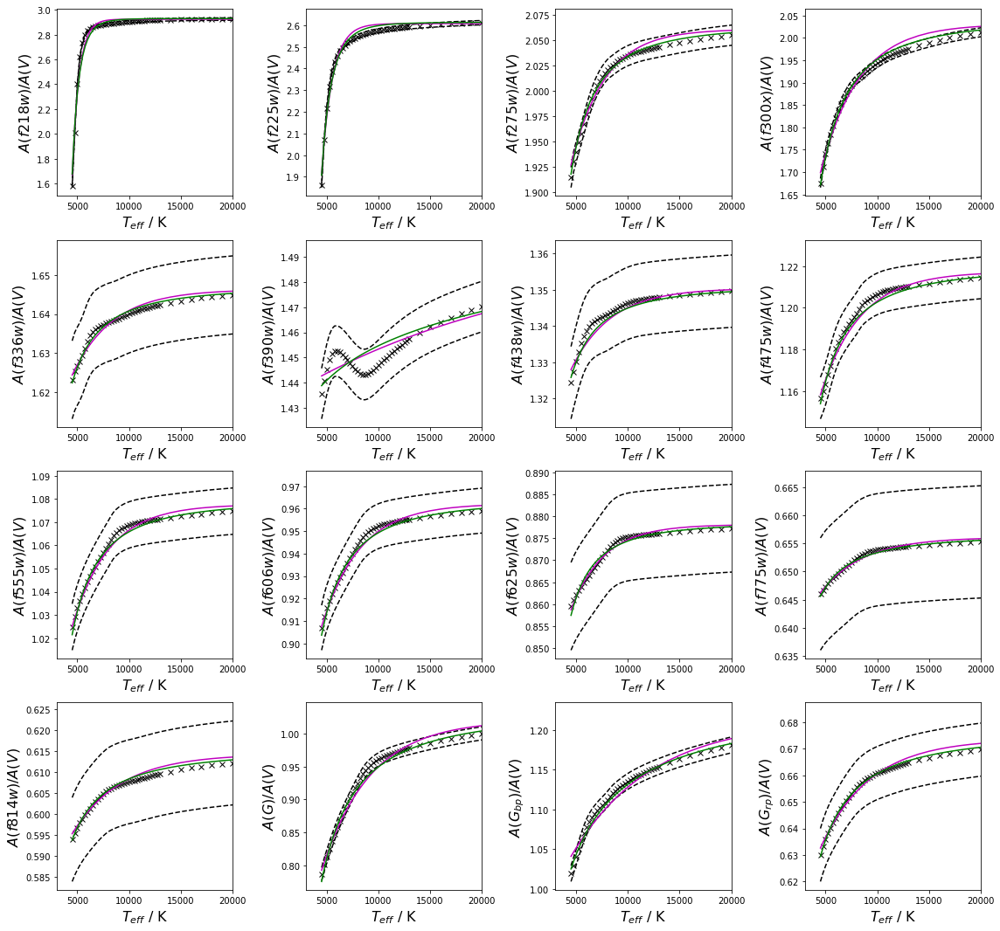


    Writing complete for log(g) = 4.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 3.5
Exponential fit coefficients (should be reused): 
[-1000.      -14.8476    2.9241]
Standard deviations (should be reused): 
[  8.6241e+01   1.8304e-01   1.2793e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6864e-03  -7.0000e+00   2.9294e+00]
Standard deviations (should be reused): 
[ 0.0003  0.0814  0.0013]
Logistic fit coefficients: 
[  4.0435e+03   2.1045e+01   2.9184e+00  -1.8391e+00]
Standard deviations: 
[  1.4038e+02   7.7965e-01   1.2716e-03   9.1516e-01]
Teff log-normal fit coefficients: 
[ 0.      4.7935  2.8046  2.    ]
Standard deviations: 
[  0.0000e+00   4.8850e+00   1.4296e-03   8.0175e-01]





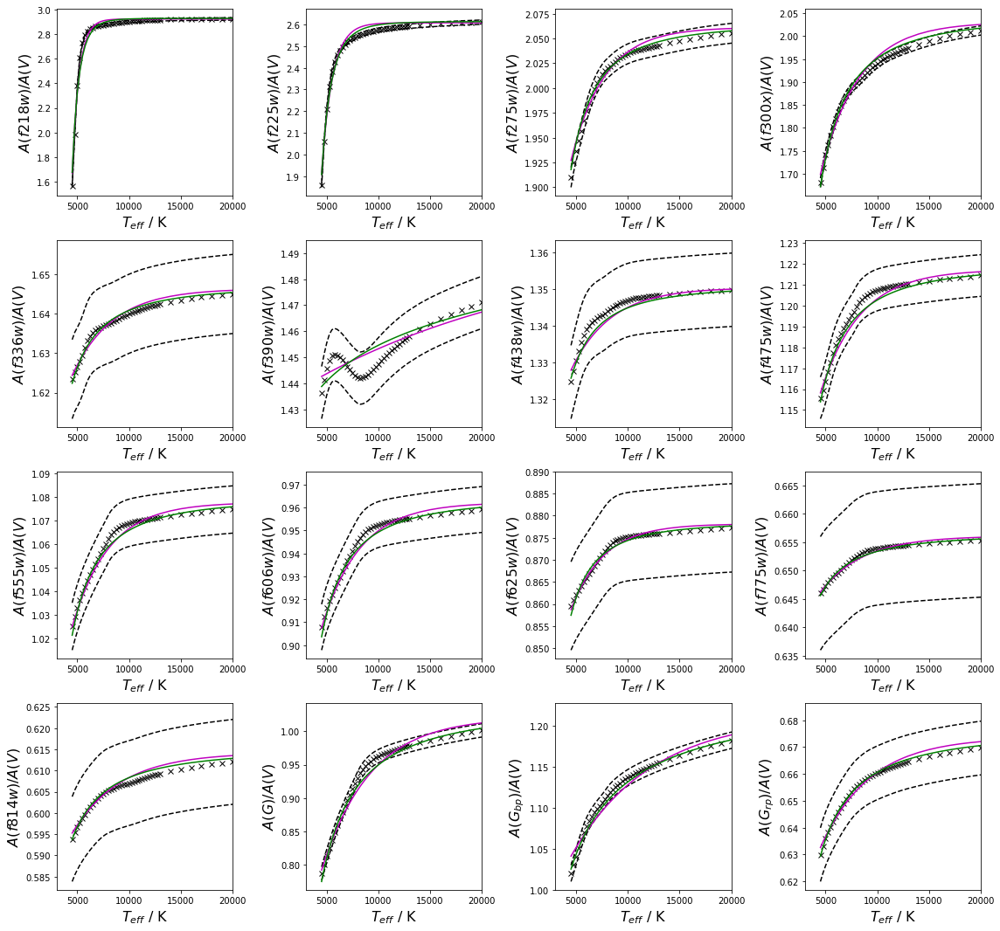


    Writing complete for log(g) = 3.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 3.0
Exponential fit coefficients (should be reused): 
[-1000.      -14.8476    2.9241]
Standard deviations (should be reused): 
[  8.6241e+01   1.8304e-01   1.2793e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6864e-03  -7.0000e+00   2.9294e+00]
Standard deviations (should be reused): 
[ 0.0003  0.0814  0.0013]
Logistic fit coefficients: 
[  4.0435e+03   2.1045e+01   2.9184e+00  -1.8391e+00]
Standard deviations: 
[  1.4038e+02   7.7965e-01   1.2716e-03   9.1516e-01]
Teff log-normal fit coefficients: 
[ 0.      4.7935  2.8046  2.    ]
Standard deviations: 
[  0.0000e+00   4.8850e+00   1.4296e-03   8.0175e-01]





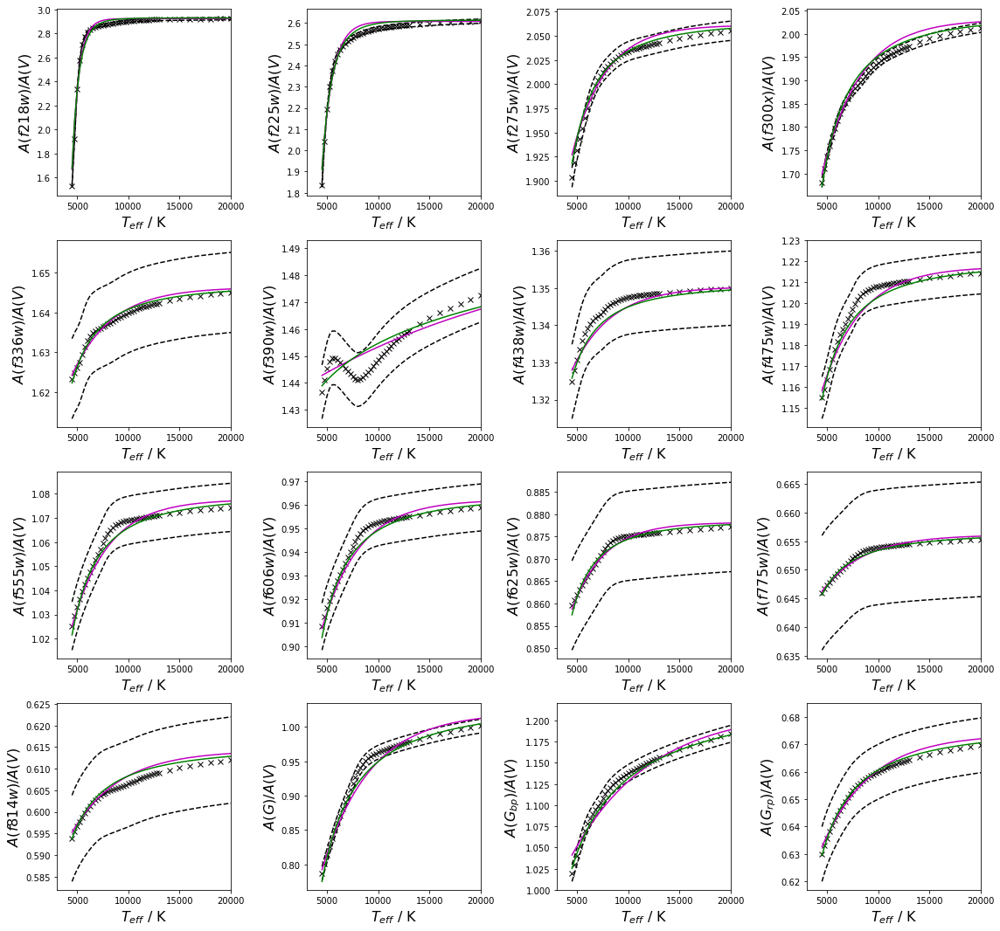


    Writing complete for log(g) = 3.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 2.5
Exponential fit coefficients (should be reused): 
[-1000.      -14.8476    2.9241]
Standard deviations (should be reused): 
[  8.6241e+01   1.8304e-01   1.2793e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6864e-03  -7.0000e+00   2.9294e+00]
Standard deviations (should be reused): 
[ 0.0003  0.0814  0.0013]
Logistic fit coefficients: 
[  4.0435e+03   2.1045e+01   2.9184e+00  -1.8391e+00]
Standard deviations: 
[  1.4038e+02   7.7965e-01   1.2716e-03   9.1516e-01]
Teff log-normal fit coefficients: 
[ 0.      4.7935  2.8046  2.    ]
Standard deviations: 
[  0.0000e+00   4.8850e+00   1.4296e-03   8.0175e-01]





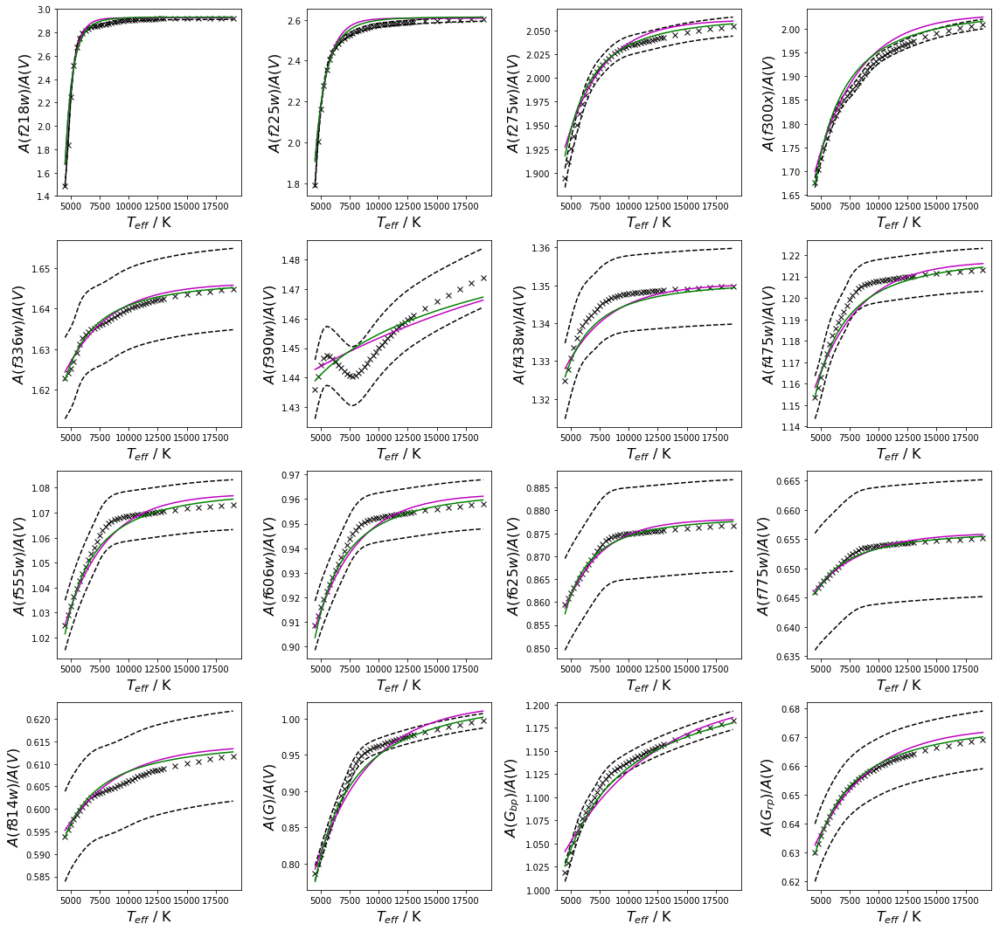


    Writing complete for log(g) = 2.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 2.0
Exponential fit coefficients (should be reused): 
[-1000.      -14.8476    2.9241]
Standard deviations (should be reused): 
[  8.6241e+01   1.8304e-01   1.2793e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6864e-03  -7.0000e+00   2.9294e+00]
Standard deviations (should be reused): 
[ 0.0003  0.0814  0.0013]
Logistic fit coefficients: 
[  4.0435e+03   2.1045e+01   2.9184e+00  -1.8391e+00]
Standard deviations: 
[  1.4038e+02   7.7965e-01   1.2716e-03   9.1516e-01]
Teff log-normal fit coefficients: 
[ 0.      4.7935  2.8046  2.    ]
Standard deviations: 
[  0.0000e+00   4.8850e+00   1.4296e-03   8.0175e-01]





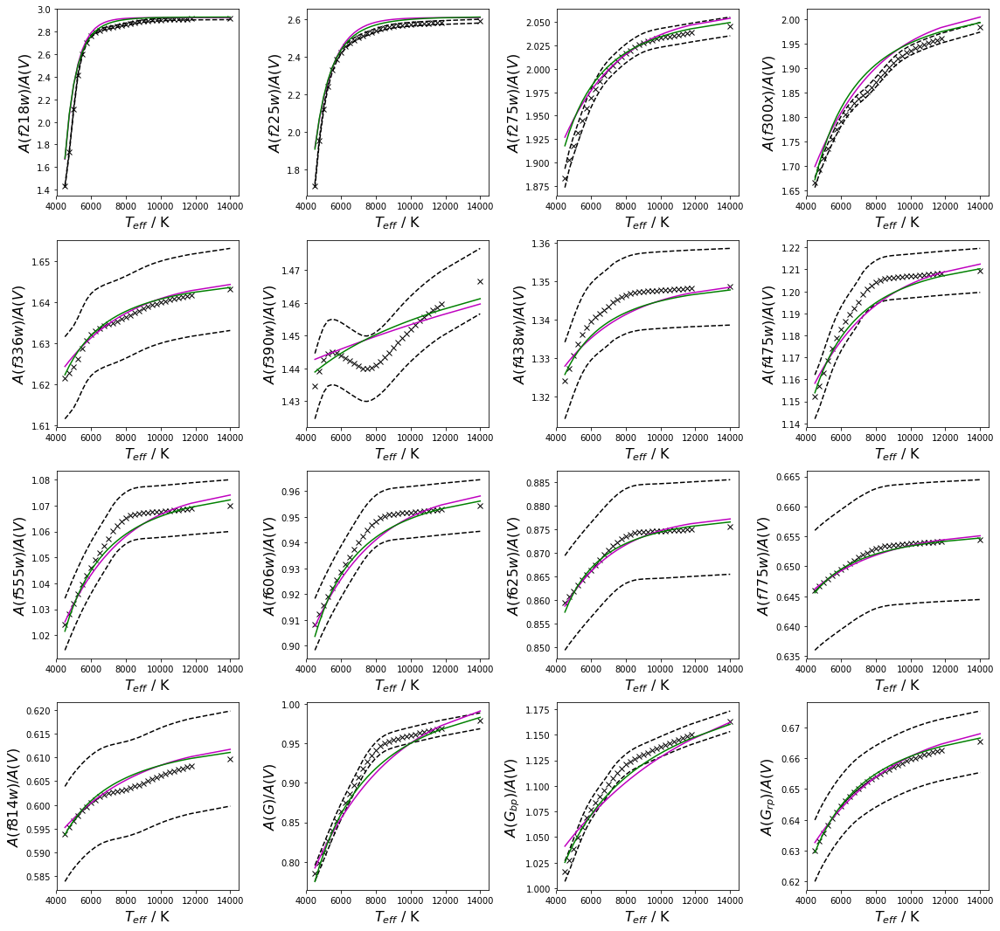


    Writing complete for log(g) = 2.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 1.5
Exponential fit coefficients (should be reused): 
[-1000.      -14.8476    2.9241]
Standard deviations (should be reused): 
[  8.6241e+01   1.8304e-01   1.2793e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6864e-03  -7.0000e+00   2.9294e+00]
Standard deviations (should be reused): 
[ 0.0003  0.0814  0.0013]
Logistic fit coefficients: 
[  4.0435e+03   2.1045e+01   2.9184e+00  -1.8391e+00]
Standard deviations: 
[  1.4038e+02   7.7965e-01   1.2716e-03   9.1516e-01]
Teff log-normal fit coefficients: 
[ 0.      4.7935  2.8046  2.    ]
Standard deviations: 
[  0.0000e+00   4.8850e+00   1.4296e-03   8.0175e-01]





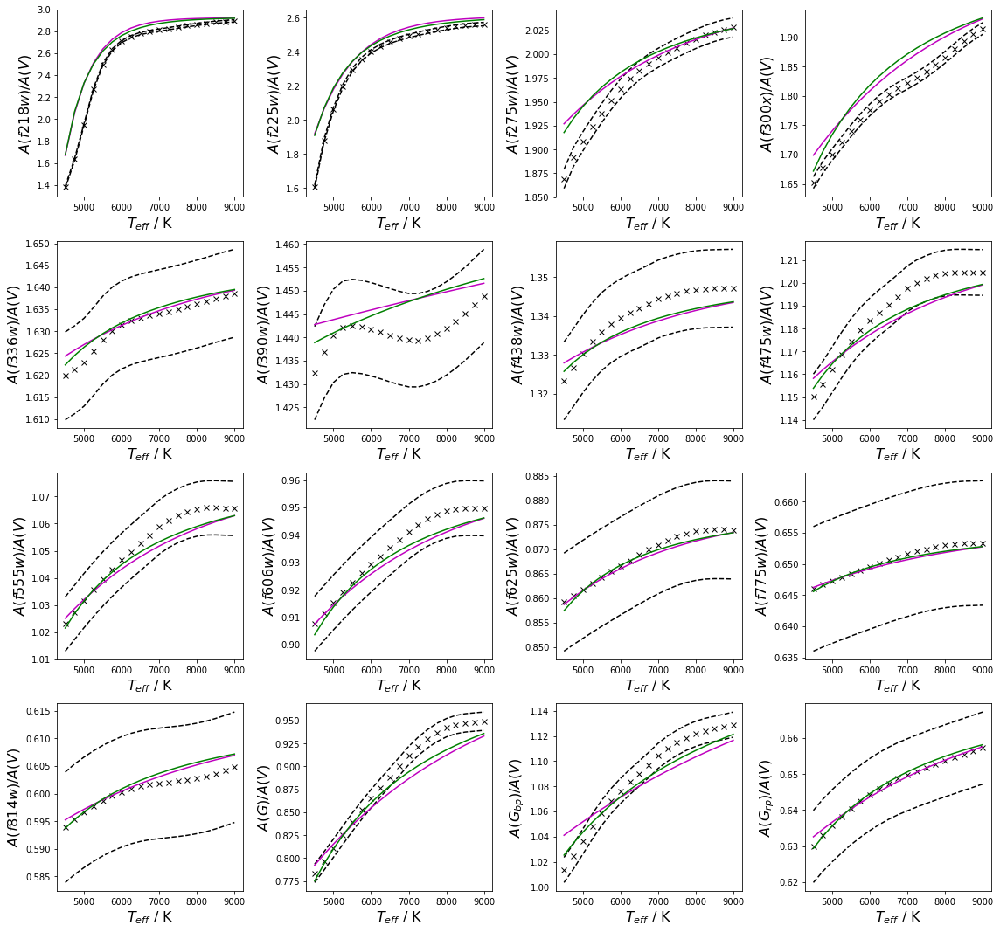


    Writing complete for log(g) = 1.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 1.0
Exponential fit coefficients (should be reused): 
[-1000.      -14.8476    2.9241]
Standard deviations (should be reused): 
[  8.6241e+01   1.8304e-01   1.2793e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6864e-03  -7.0000e+00   2.9294e+00]
Standard deviations (should be reused): 
[ 0.0003  0.0814  0.0013]
Logistic fit coefficients: 
[  4.0435e+03   2.1045e+01   2.9184e+00  -1.8391e+00]
Standard deviations: 
[  1.4038e+02   7.7965e-01   1.2716e-03   9.1516e-01]
Teff log-normal fit coefficients: 
[ 0.      4.7935  2.8046  2.    ]
Standard deviations: 
[  0.0000e+00   4.8850e+00   1.4296e-03   8.0175e-01]





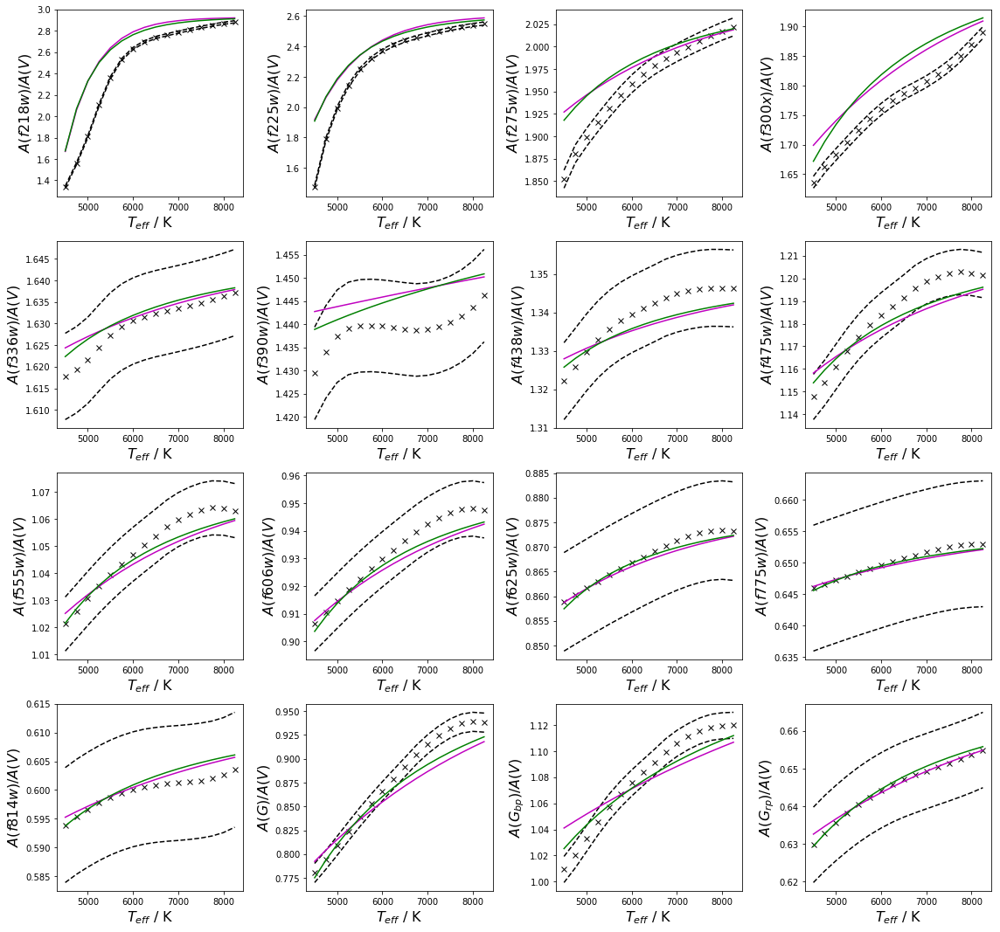


    Writing complete for log(g) = 1.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 0.5
Exponential fit coefficients (should be reused): 
[-1000.      -14.8476    2.9241]
Standard deviations (should be reused): 
[  8.6241e+01   1.8304e-01   1.2793e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6864e-03  -7.0000e+00   2.9294e+00]
Standard deviations (should be reused): 
[ 0.0003  0.0814  0.0013]
Logistic fit coefficients: 
[  4.0435e+03   2.1045e+01   2.9184e+00  -1.8391e+00]
Standard deviations: 
[  1.4038e+02   7.7965e-01   1.2716e-03   9.1516e-01]
Teff log-normal fit coefficients: 
[ 0.      4.7935  2.8046  2.    ]
Standard deviations: 
[  0.0000e+00   4.8850e+00   1.4296e-03   8.0175e-01]





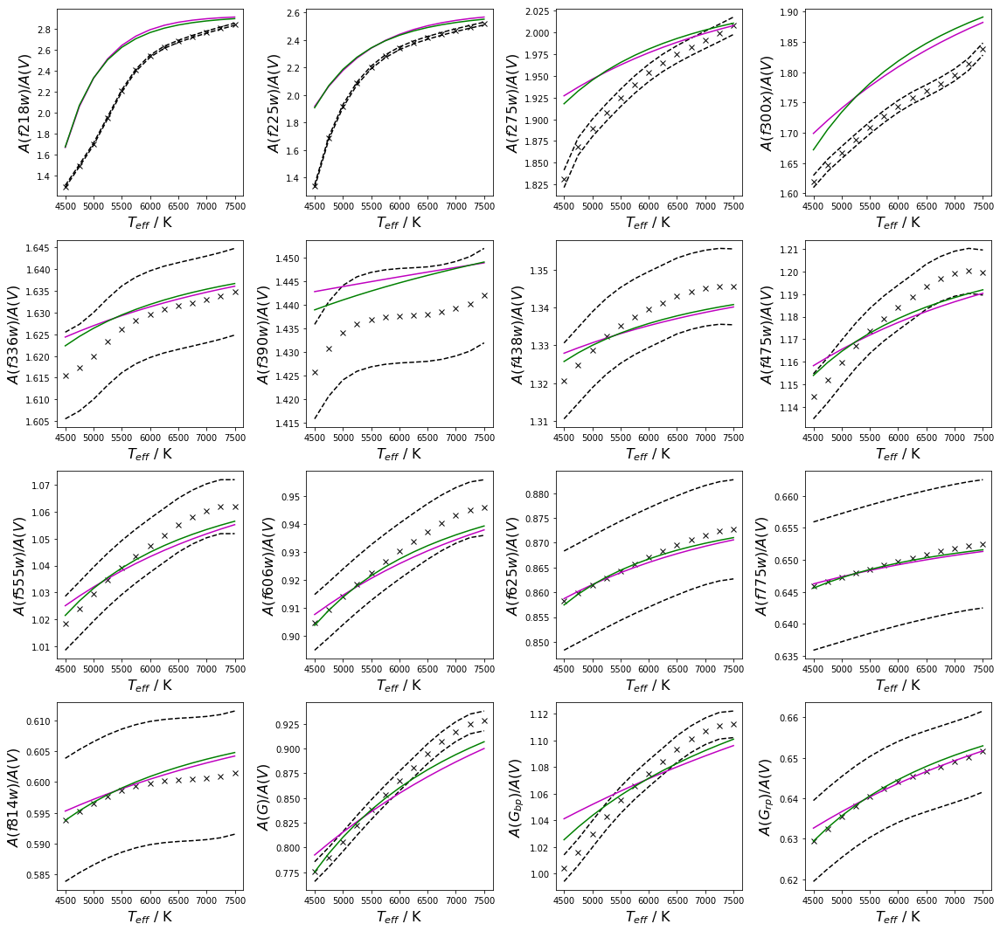


    Writing complete for log(g) = 0.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 0.0
Exponential fit coefficients (should be reused): 
[-1000.      -14.8476    2.9241]
Standard deviations (should be reused): 
[  8.6241e+01   1.8304e-01   1.2793e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6864e-03  -7.0000e+00   2.9294e+00]
Standard deviations (should be reused): 
[ 0.0003  0.0814  0.0013]
Logistic fit coefficients: 
[  4.0435e+03   2.1045e+01   2.9184e+00  -1.8391e+00]
Standard deviations: 
[  1.4038e+02   7.7965e-01   1.2716e-03   9.1516e-01]
Teff log-normal fit coefficients: 
[ 0.      4.7935  2.8046  2.    ]
Standard deviations: 
[  0.0000e+00   4.8850e+00   1.4296e-03   8.0175e-01]





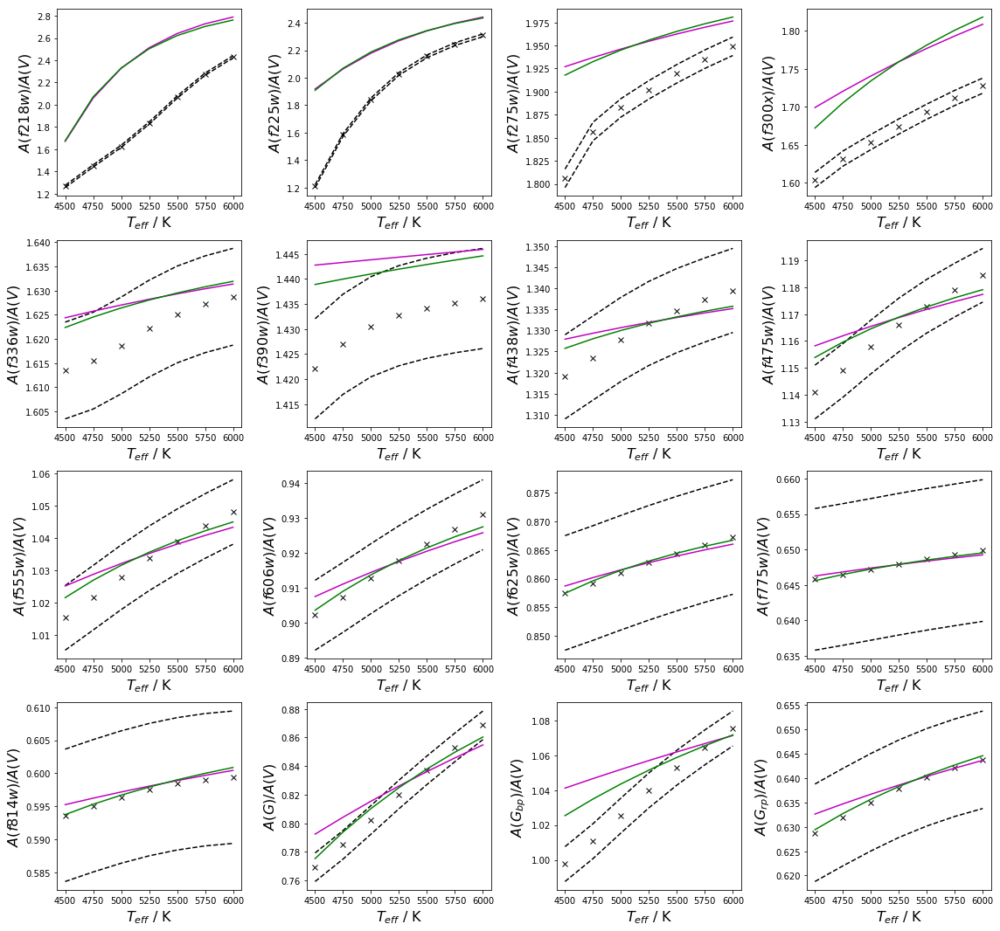


    Writing complete for log(g) = 0.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 5.0


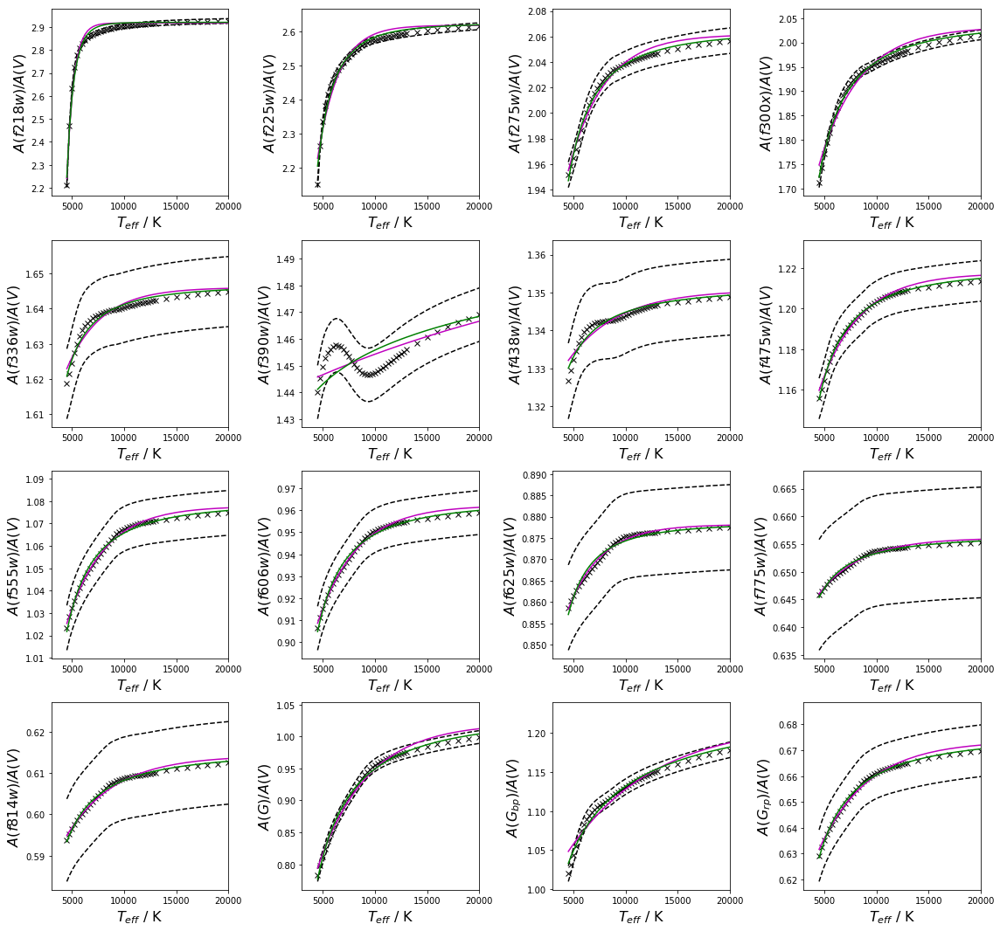


    Writing complete for log(g) = 5.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 4.5
Exponential fit coefficients (should be reused): 
[-574.8245  -14.987     2.9176]
Standard deviations (should be reused): 
[  9.2924e+01   3.4330e-01   1.2783e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.5244e-03  -7.0000e+00   2.9206e+00]
Standard deviations (should be reused): 
[ 0.0003  0.1511  0.0013]
Logistic fit coefficients: 
[  2.9922e+03   1.5753e+01   2.9173e+00  -5.0000e+00]
Standard deviations: 
[  1.0885e+03   1.1180e+00   1.3027e-03   1.1310e+01]
Teff log-normal fit coefficients: 
[ 0.      8.0141  2.8473  2.    ]
Standard deviations: 
[  0.0000e+00   3.5626e+01   1.4293e-03   3.7361e+00]





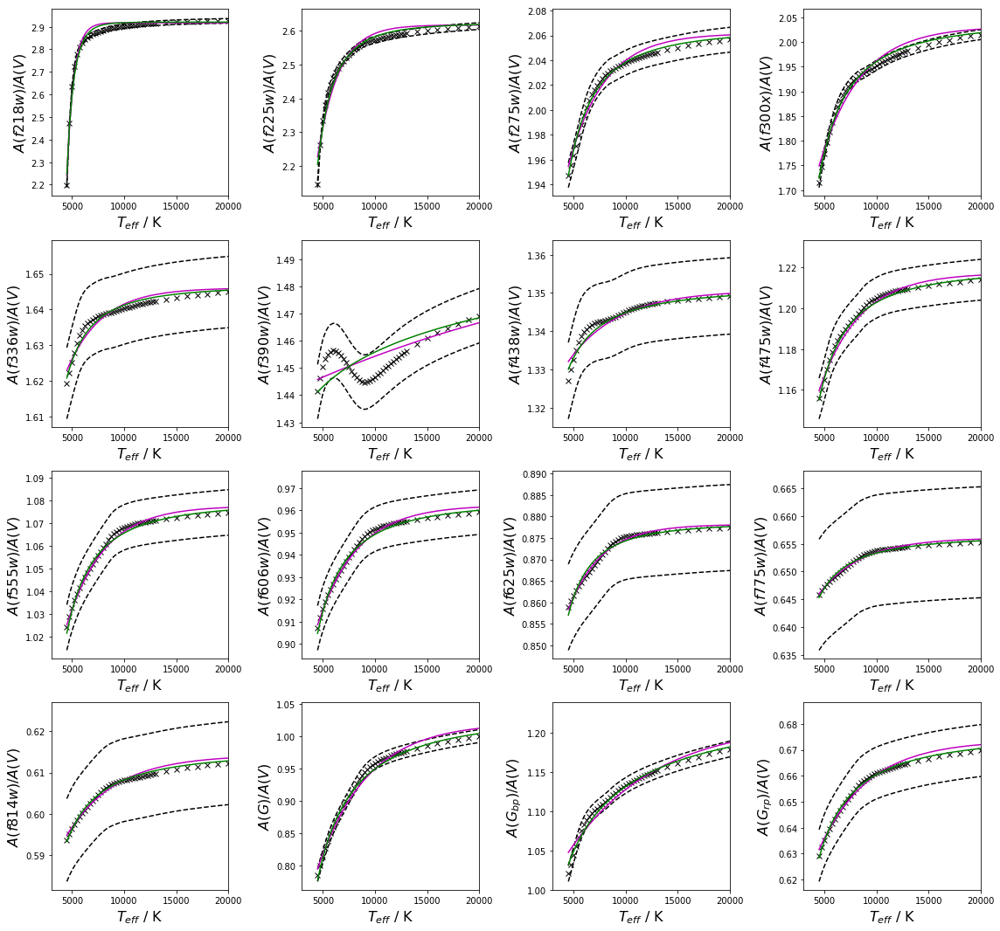


    Writing complete for log(g) = 4.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 4.0
Exponential fit coefficients (should be reused): 
[-574.8245  -14.987     2.9176]
Standard deviations (should be reused): 
[  9.2924e+01   3.4330e-01   1.2783e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.5244e-03  -7.0000e+00   2.9206e+00]
Standard deviations (should be reused): 
[ 0.0003  0.1511  0.0013]
Logistic fit coefficients: 
[  2.9922e+03   1.5753e+01   2.9173e+00  -5.0000e+00]
Standard deviations: 
[  1.0885e+03   1.1180e+00   1.3027e-03   1.1310e+01]
Teff log-normal fit coefficients: 
[ 0.      8.0141  2.8473  2.    ]
Standard deviations: 
[  0.0000e+00   3.5626e+01   1.4293e-03   3.7361e+00]





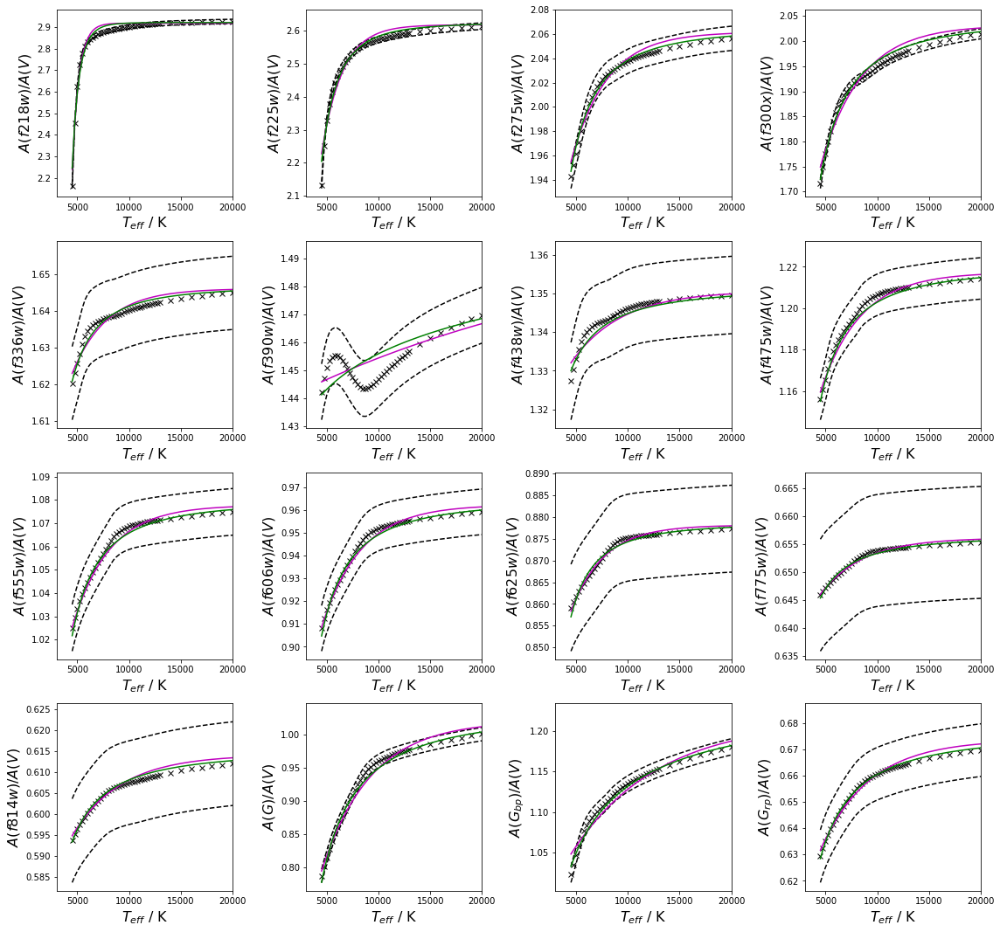


    Writing complete for log(g) = 4.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 3.5
Exponential fit coefficients (should be reused): 
[-574.8245  -14.987     2.9176]
Standard deviations (should be reused): 
[  9.2924e+01   3.4330e-01   1.2783e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.5244e-03  -7.0000e+00   2.9206e+00]
Standard deviations (should be reused): 
[ 0.0003  0.1511  0.0013]
Logistic fit coefficients: 
[  2.9922e+03   1.5753e+01   2.9173e+00  -5.0000e+00]
Standard deviations: 
[  1.0885e+03   1.1180e+00   1.3027e-03   1.1310e+01]
Teff log-normal fit coefficients: 
[ 0.      8.0141  2.8473  2.    ]
Standard deviations: 
[  0.0000e+00   3.5626e+01   1.4293e-03   3.7361e+00]





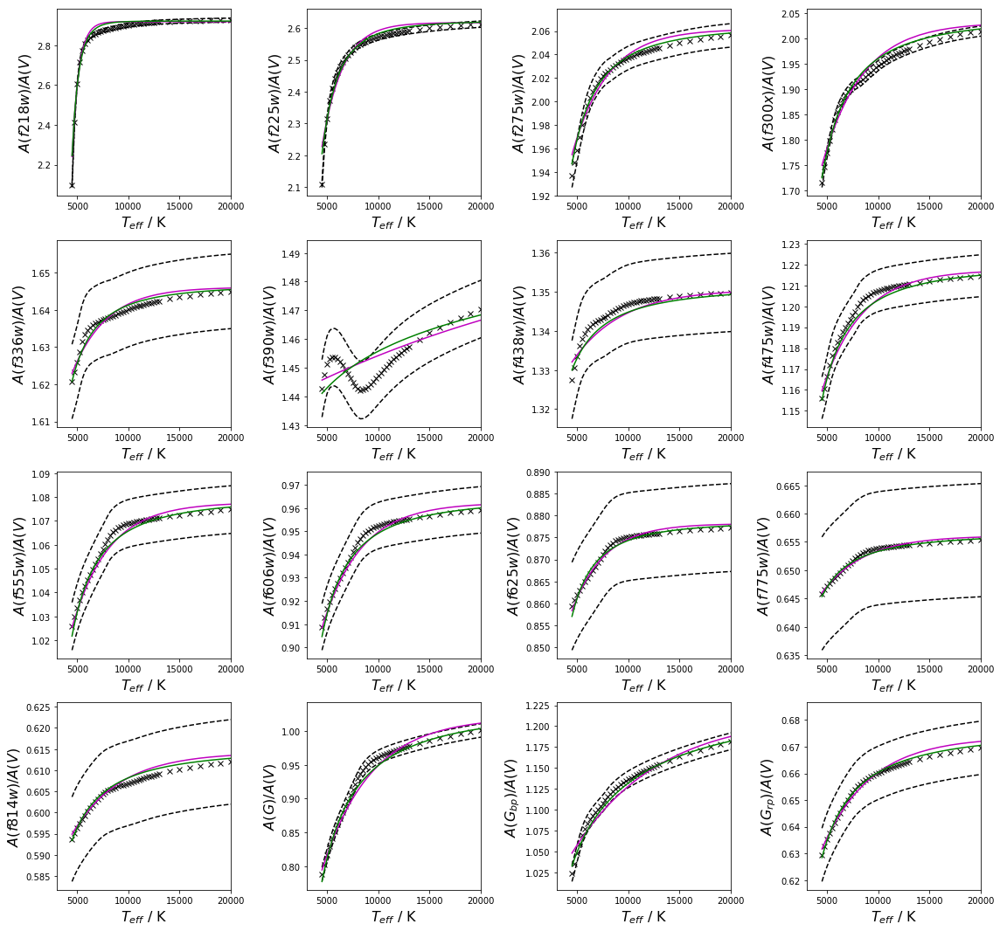


    Writing complete for log(g) = 3.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 3.0
Exponential fit coefficients (should be reused): 
[-574.8245  -14.987     2.9176]
Standard deviations (should be reused): 
[  9.2924e+01   3.4330e-01   1.2783e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.5244e-03  -7.0000e+00   2.9206e+00]
Standard deviations (should be reused): 
[ 0.0003  0.1511  0.0013]
Logistic fit coefficients: 
[  2.9922e+03   1.5753e+01   2.9173e+00  -5.0000e+00]
Standard deviations: 
[  1.0885e+03   1.1180e+00   1.3027e-03   1.1310e+01]
Teff log-normal fit coefficients: 
[ 0.      8.0141  2.8473  2.    ]
Standard deviations: 
[  0.0000e+00   3.5626e+01   1.4293e-03   3.7361e+00]





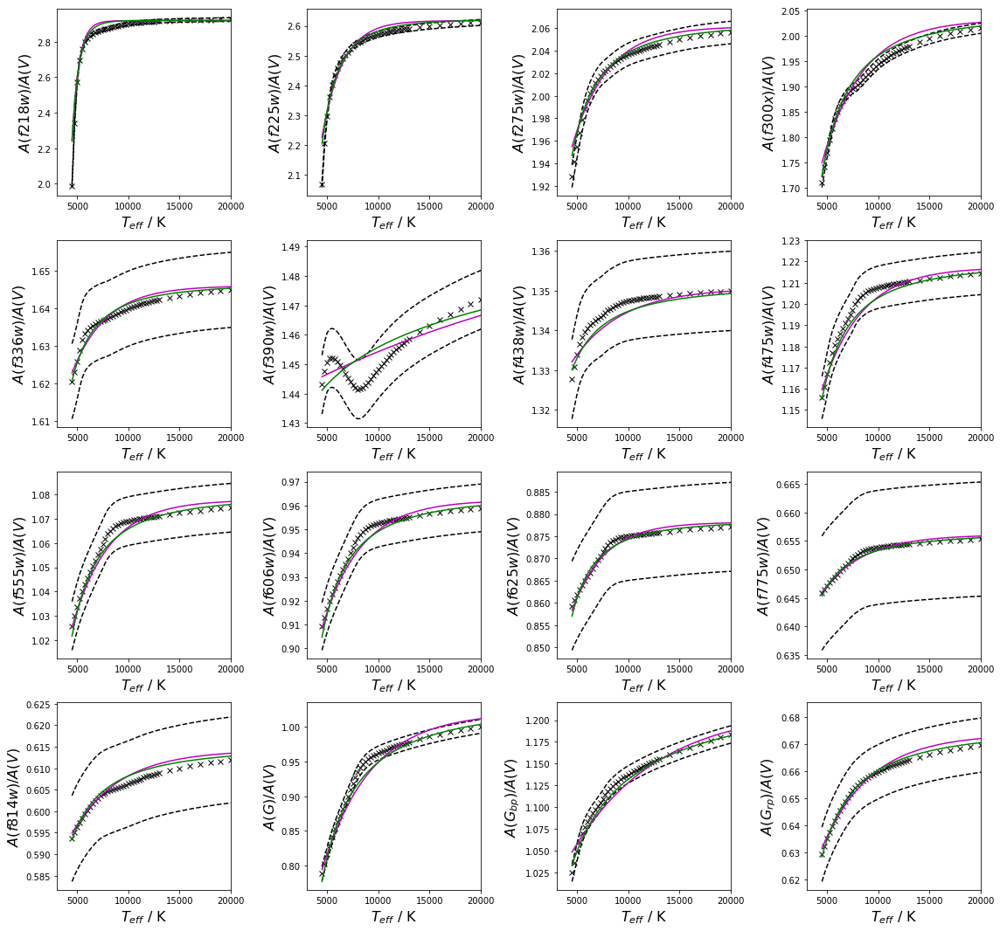


    Writing complete for log(g) = 3.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 2.5
Exponential fit coefficients (should be reused): 
[-574.8245  -14.987     2.9176]
Standard deviations (should be reused): 
[  9.2924e+01   3.4330e-01   1.2783e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.5244e-03  -7.0000e+00   2.9206e+00]
Standard deviations (should be reused): 
[ 0.0003  0.1511  0.0013]
Logistic fit coefficients: 
[  2.9922e+03   1.5753e+01   2.9173e+00  -5.0000e+00]
Standard deviations: 
[  1.0885e+03   1.1180e+00   1.3027e-03   1.1310e+01]
Teff log-normal fit coefficients: 
[ 0.      8.0141  2.8473  2.    ]
Standard deviations: 
[  0.0000e+00   3.5626e+01   1.4293e-03   3.7361e+00]





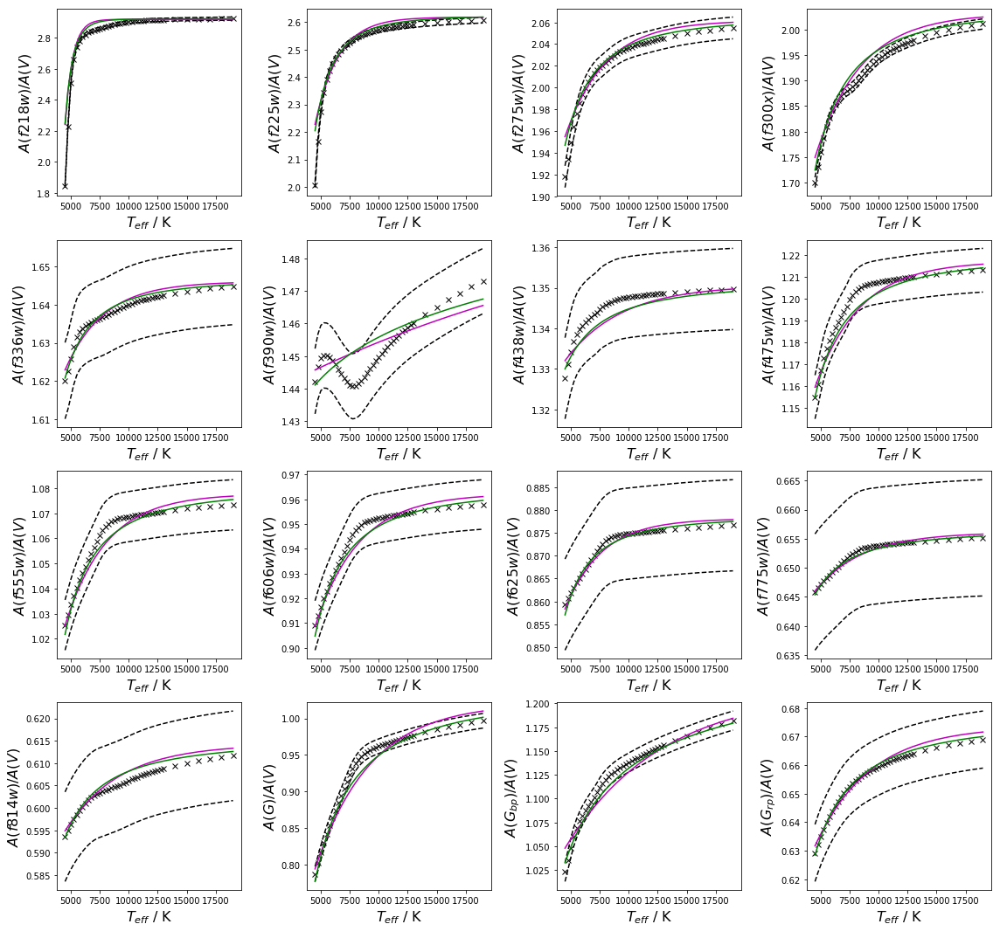


    Writing complete for log(g) = 2.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 2.0
Exponential fit coefficients (should be reused): 
[-574.8245  -14.987     2.9176]
Standard deviations (should be reused): 
[  9.2924e+01   3.4330e-01   1.2783e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.5244e-03  -7.0000e+00   2.9206e+00]
Standard deviations (should be reused): 
[ 0.0003  0.1511  0.0013]
Logistic fit coefficients: 
[  2.9922e+03   1.5753e+01   2.9173e+00  -5.0000e+00]
Standard deviations: 
[  1.0885e+03   1.1180e+00   1.3027e-03   1.1310e+01]
Teff log-normal fit coefficients: 
[ 0.      8.0141  2.8473  2.    ]
Standard deviations: 
[  0.0000e+00   3.5626e+01   1.4293e-03   3.7361e+00]





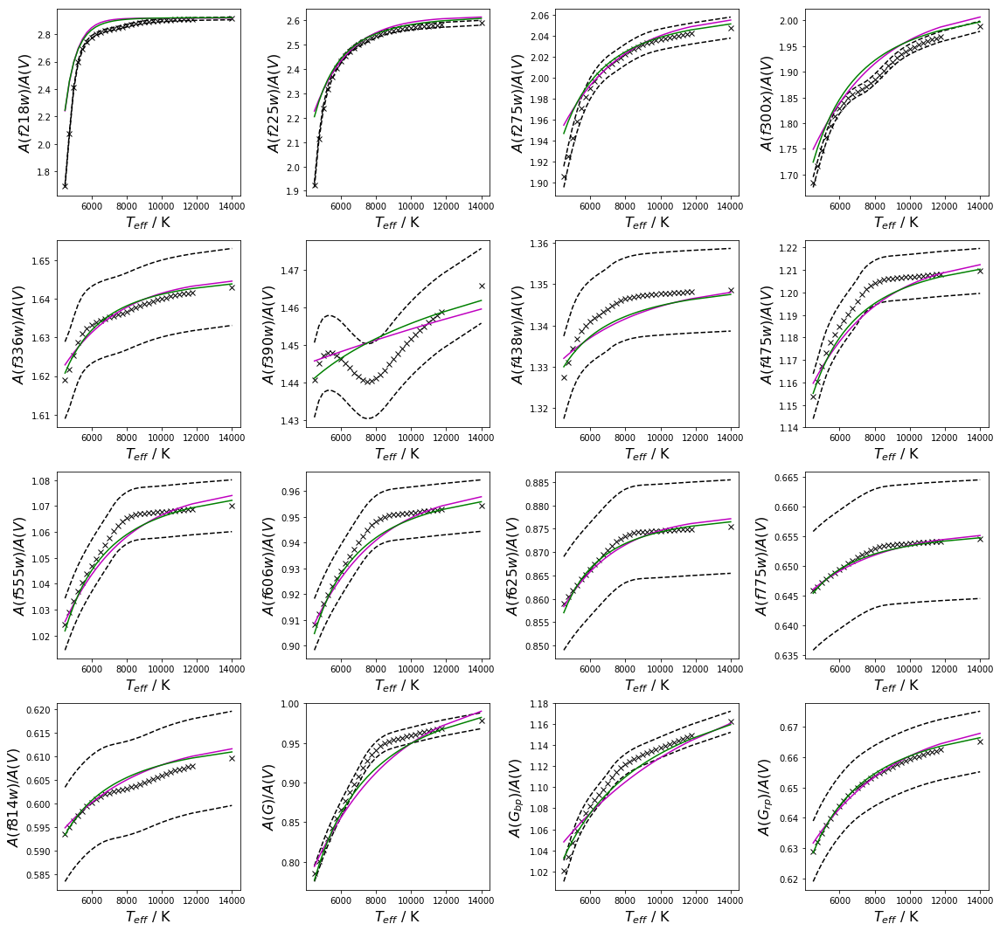


    Writing complete for log(g) = 2.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 1.5
Exponential fit coefficients (should be reused): 
[-574.8245  -14.987     2.9176]
Standard deviations (should be reused): 
[  9.2924e+01   3.4330e-01   1.2783e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.5244e-03  -7.0000e+00   2.9206e+00]
Standard deviations (should be reused): 
[ 0.0003  0.1511  0.0013]
Logistic fit coefficients: 
[  2.9922e+03   1.5753e+01   2.9173e+00  -5.0000e+00]
Standard deviations: 
[  1.0885e+03   1.1180e+00   1.3027e-03   1.1310e+01]
Teff log-normal fit coefficients: 
[ 0.      8.0141  2.8473  2.    ]
Standard deviations: 
[  0.0000e+00   3.5626e+01   1.4293e-03   3.7361e+00]





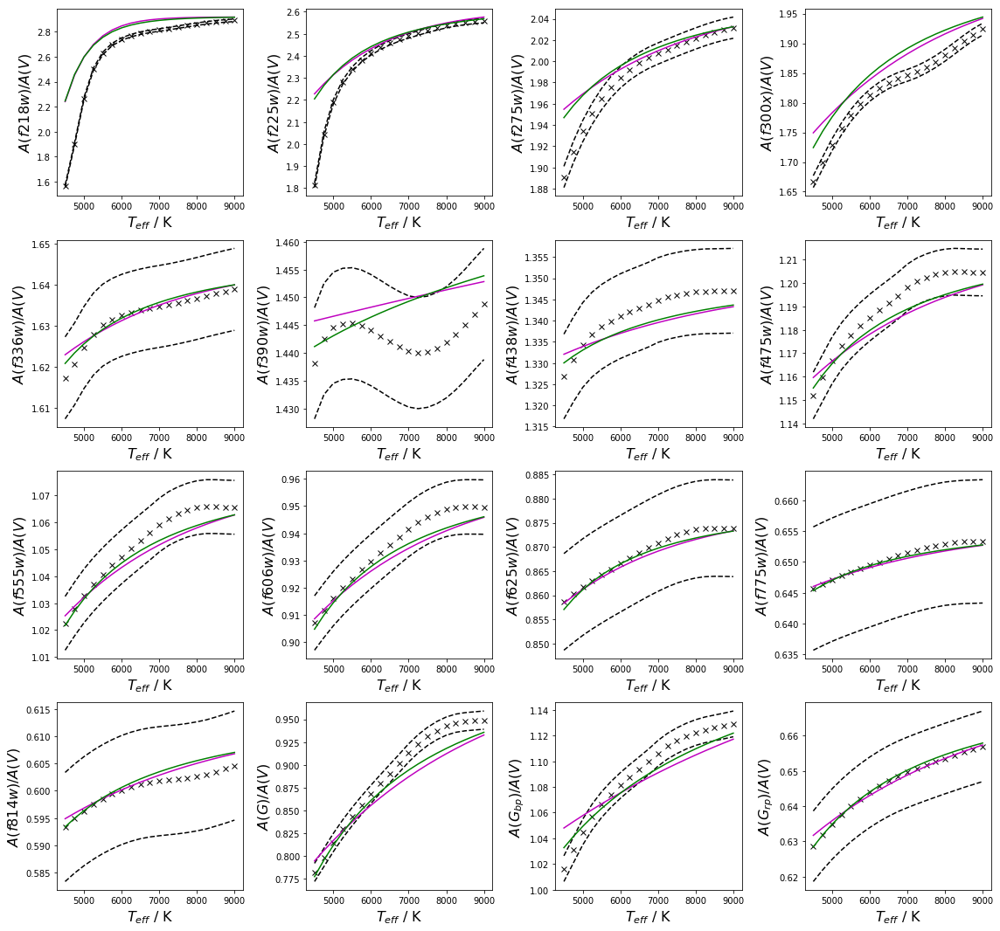


    Writing complete for log(g) = 1.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 1.0
Exponential fit coefficients (should be reused): 
[-574.8245  -14.987     2.9176]
Standard deviations (should be reused): 
[  9.2924e+01   3.4330e-01   1.2783e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.5244e-03  -7.0000e+00   2.9206e+00]
Standard deviations (should be reused): 
[ 0.0003  0.1511  0.0013]
Logistic fit coefficients: 
[  2.9922e+03   1.5753e+01   2.9173e+00  -5.0000e+00]
Standard deviations: 
[  1.0885e+03   1.1180e+00   1.3027e-03   1.1310e+01]
Teff log-normal fit coefficients: 
[ 0.      8.0141  2.8473  2.    ]
Standard deviations: 
[  0.0000e+00   3.5626e+01   1.4293e-03   3.7361e+00]





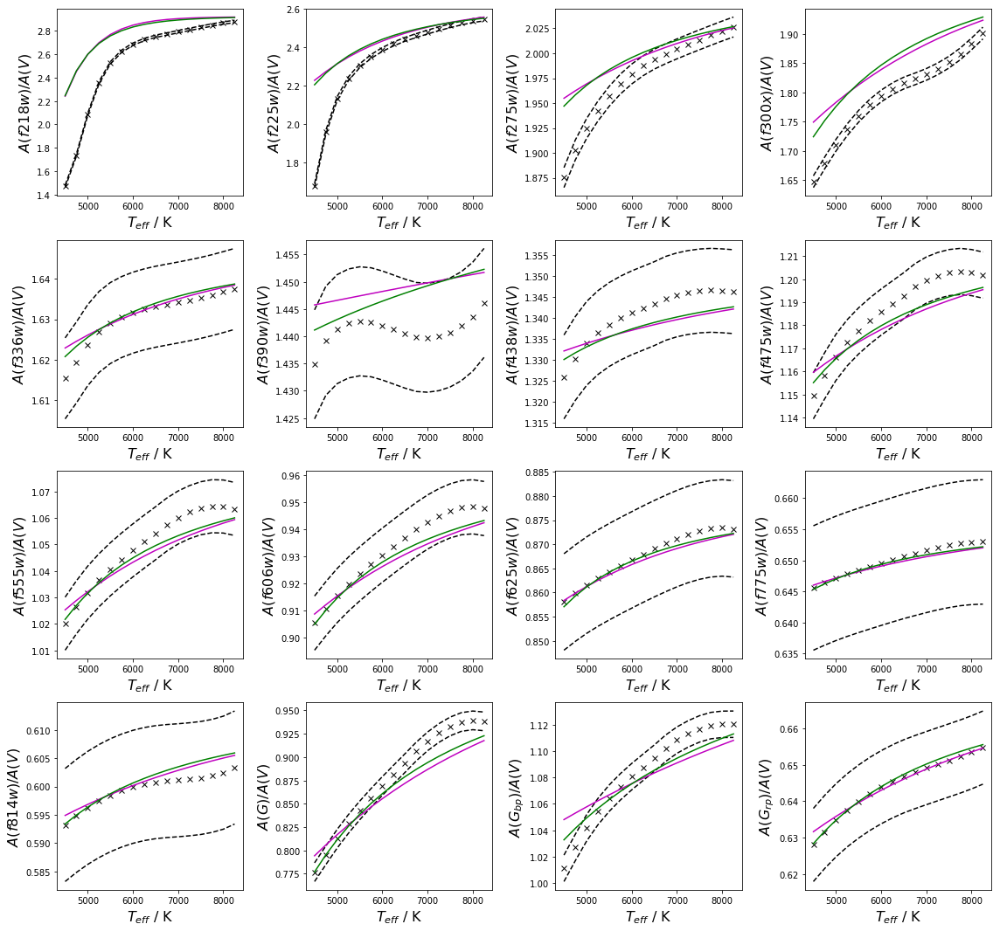


    Writing complete for log(g) = 1.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 0.5
Exponential fit coefficients (should be reused): 
[-574.8245  -14.987     2.9176]
Standard deviations (should be reused): 
[  9.2924e+01   3.4330e-01   1.2783e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.5244e-03  -7.0000e+00   2.9206e+00]
Standard deviations (should be reused): 
[ 0.0003  0.1511  0.0013]
Logistic fit coefficients: 
[  2.9922e+03   1.5753e+01   2.9173e+00  -5.0000e+00]
Standard deviations: 
[  1.0885e+03   1.1180e+00   1.3027e-03   1.1310e+01]
Teff log-normal fit coefficients: 
[ 0.      8.0141  2.8473  2.    ]
Standard deviations: 
[  0.0000e+00   3.5626e+01   1.4293e-03   3.7361e+00]





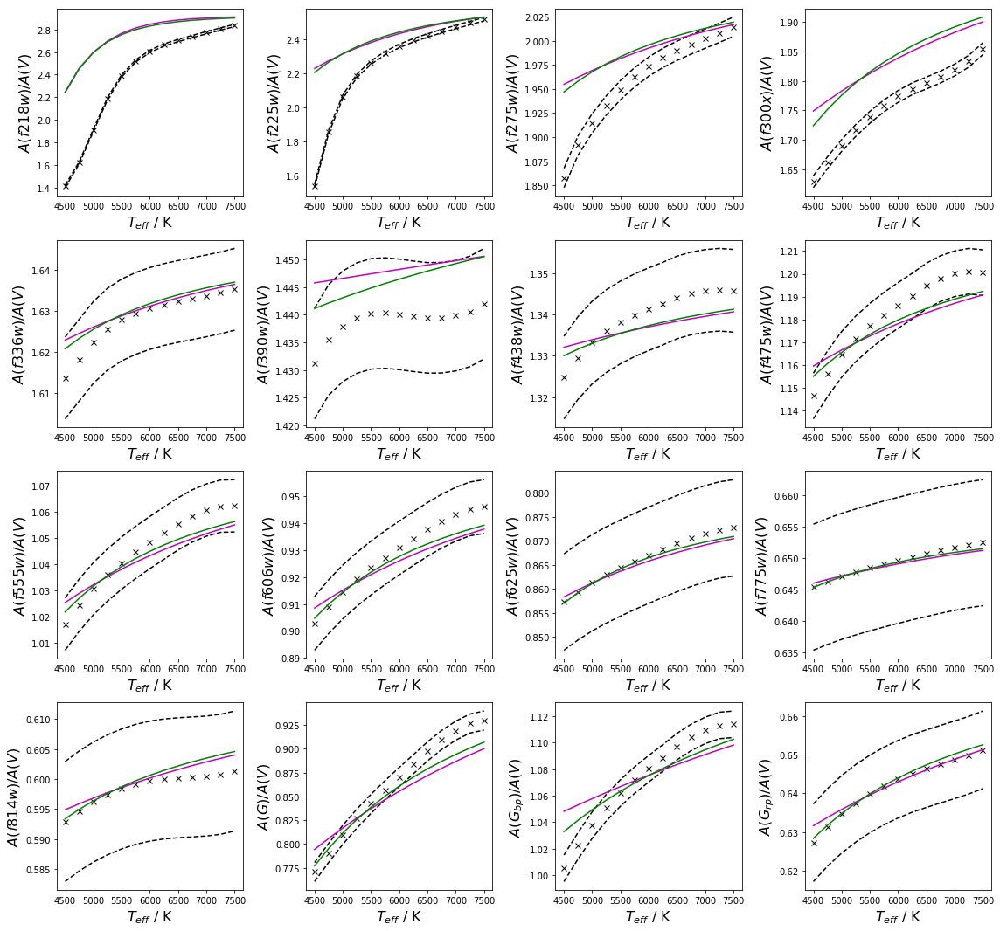


    Writing complete for log(g) = 0.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 0.0
Exponential fit coefficients (should be reused): 
[-574.8245  -14.987     2.9176]
Standard deviations (should be reused): 
[  9.2924e+01   3.4330e-01   1.2783e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.5244e-03  -7.0000e+00   2.9206e+00]
Standard deviations (should be reused): 
[ 0.0003  0.1511  0.0013]
Logistic fit coefficients: 
[  2.9922e+03   1.5753e+01   2.9173e+00  -5.0000e+00]
Standard deviations: 
[  1.0885e+03   1.1180e+00   1.3027e-03   1.1310e+01]
Teff log-normal fit coefficients: 
[ 0.      8.0141  2.8473  2.    ]
Standard deviations: 
[  0.0000e+00   3.5626e+01   1.4293e-03   3.7361e+00]





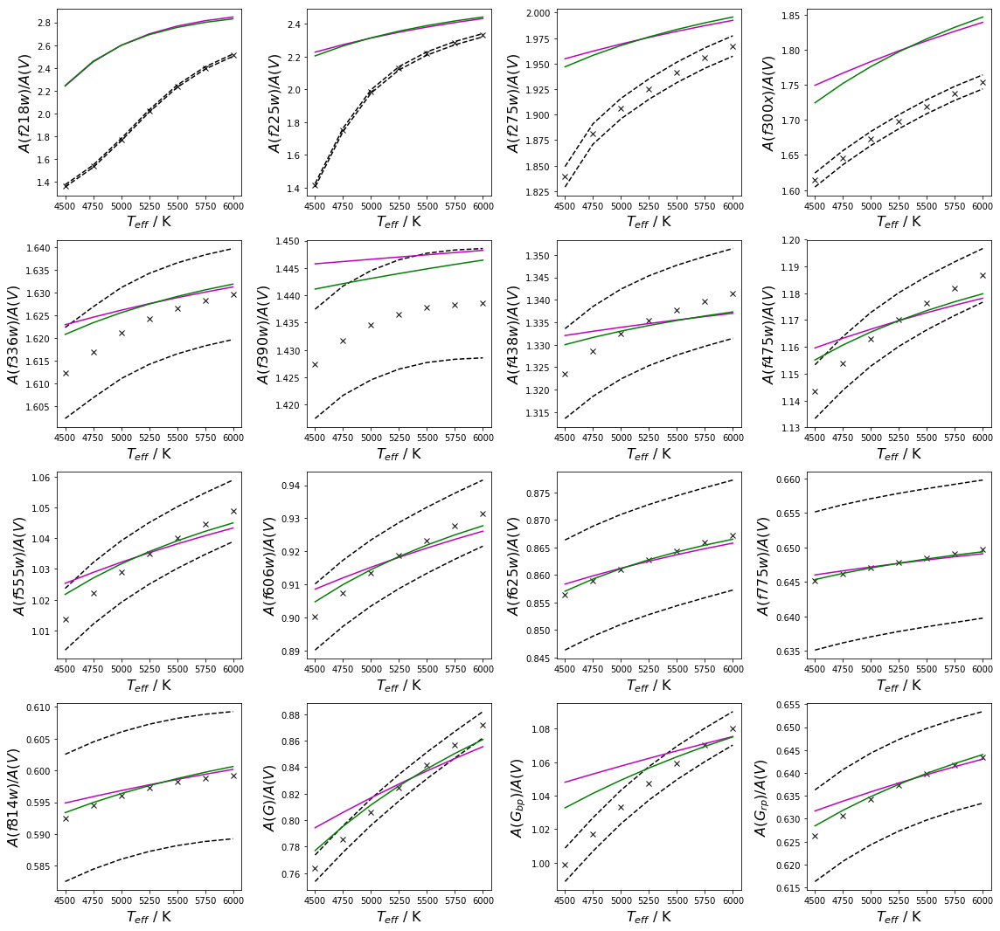


    Writing complete for log(g) = 0.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 5.0

    Writing log(g)=5.0, FeH = 0p0, Rv = 3p1 model for f218w filter
Average fractional error for Exponential function of Teff, fitted = 0.015787292941
Average fractional error for Power law of Teff, fitted = 0.0125443791378

    Writing log(g)=5.0, FeH = 0p0, Rv = 3p1 model for f225w filter
Average fractional error for Exponential function of Teff, fitted = 0.0221559061029
Average fractional error for Power law of Teff, fitted = 0.0172633590485

    Writing log(g)=5.0, FeH = 0p0, Rv = 3p1 model for f275w filter
Average fractional error for Exponential function of Teff, fitted = 0.0480964847989
Average fractional error for Power law of Teff, fitted = 0.0422100303583

    Writing log(g)=5.0, FeH = 0p0, Rv = 3p1 model for f300x filter
Average fractional error for Exponential function of Teff, fitted = 0.0196340904827
Average fractional error for Power law of Teff, fitted = 0.01959948

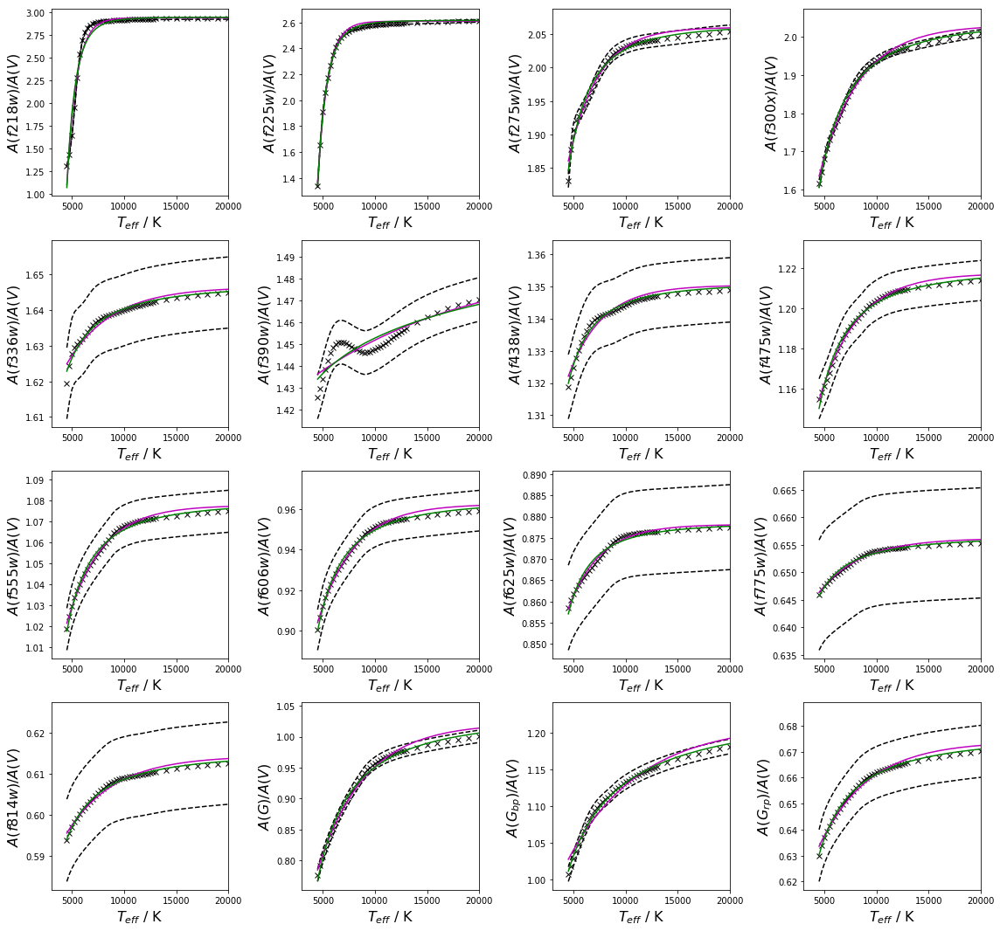


    Writing complete for log(g) = 5.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 4.5
Exponential fit coefficients (should be reused): 
[-232.252   -10.762     2.9334]
Standard deviations (should be reused): 
[  9.1340e+00   8.1606e-02   1.3238e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0214 -5.6005  2.9402]
Standard deviations (should be reused): 
[ 0.0006  0.0402  0.0014]
Logistic fit coefficients: 
[  5.2878e+03   2.6575e+01   2.9219e+00   1.0856e+00]
Standard deviations: 
[  1.2000e+01   4.9631e-01   1.2711e-03   2.0796e-02]
Teff log-normal fit coefficients: 
[ 0.      2.2513  2.7104  2.    ]
Standard deviations: 
[ 0.      0.2957  0.0014  0.0848]





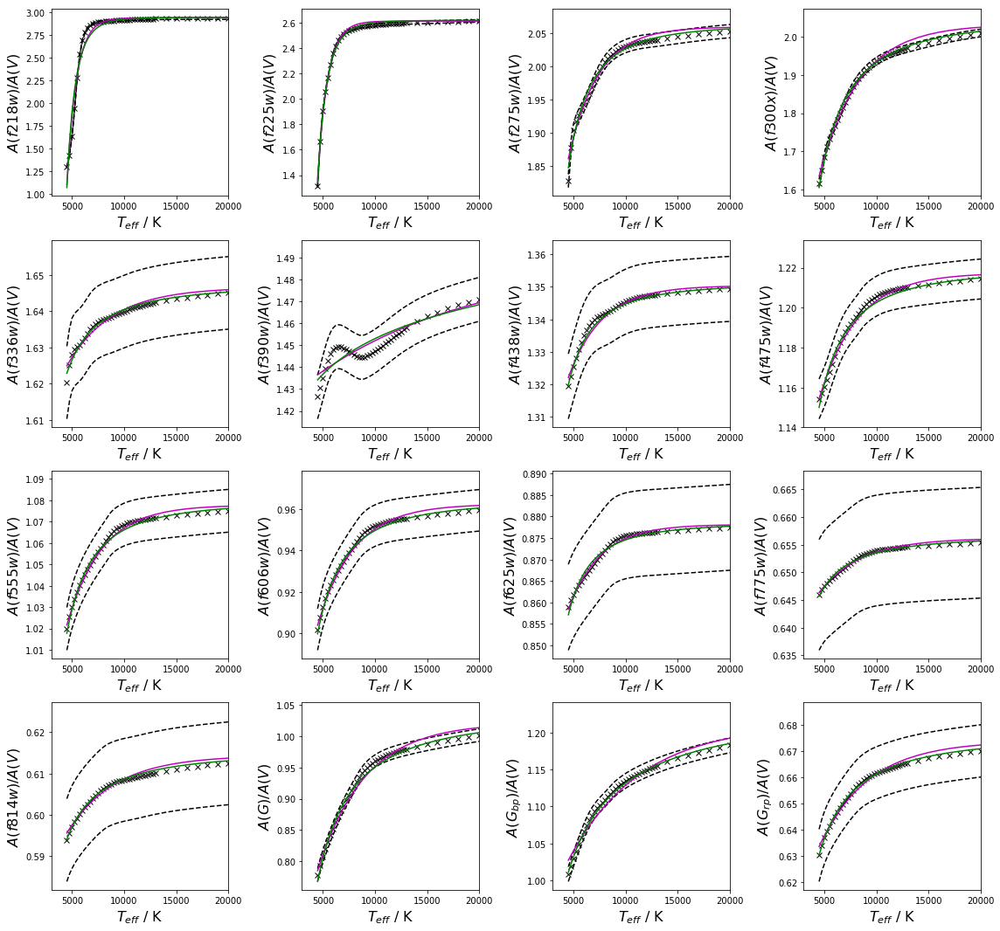


    Writing complete for log(g) = 4.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 4.0
Exponential fit coefficients (should be reused): 
[-232.252   -10.762     2.9334]
Standard deviations (should be reused): 
[  9.1340e+00   8.1606e-02   1.3238e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0214 -5.6005  2.9402]
Standard deviations (should be reused): 
[ 0.0006  0.0402  0.0014]
Logistic fit coefficients: 
[  5.2878e+03   2.6575e+01   2.9219e+00   1.0856e+00]
Standard deviations: 
[  1.2000e+01   4.9631e-01   1.2711e-03   2.0796e-02]
Teff log-normal fit coefficients: 
[ 0.      2.2513  2.7104  2.    ]
Standard deviations: 
[ 0.      0.2957  0.0014  0.0848]





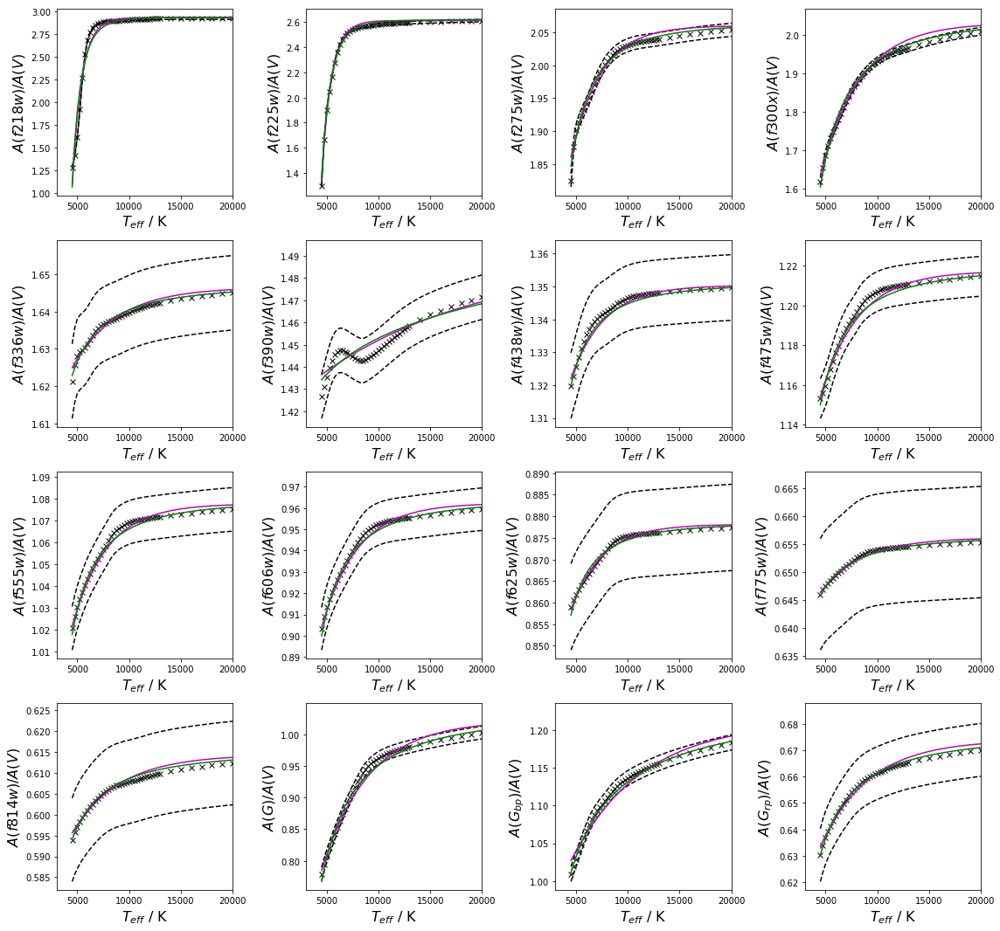


    Writing complete for log(g) = 4.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 3.5
Exponential fit coefficients (should be reused): 
[-232.252   -10.762     2.9334]
Standard deviations (should be reused): 
[  9.1340e+00   8.1606e-02   1.3238e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0214 -5.6005  2.9402]
Standard deviations (should be reused): 
[ 0.0006  0.0402  0.0014]
Logistic fit coefficients: 
[  5.2878e+03   2.6575e+01   2.9219e+00   1.0856e+00]
Standard deviations: 
[  1.2000e+01   4.9631e-01   1.2711e-03   2.0796e-02]
Teff log-normal fit coefficients: 
[ 0.      2.2513  2.7104  2.    ]
Standard deviations: 
[ 0.      0.2957  0.0014  0.0848]





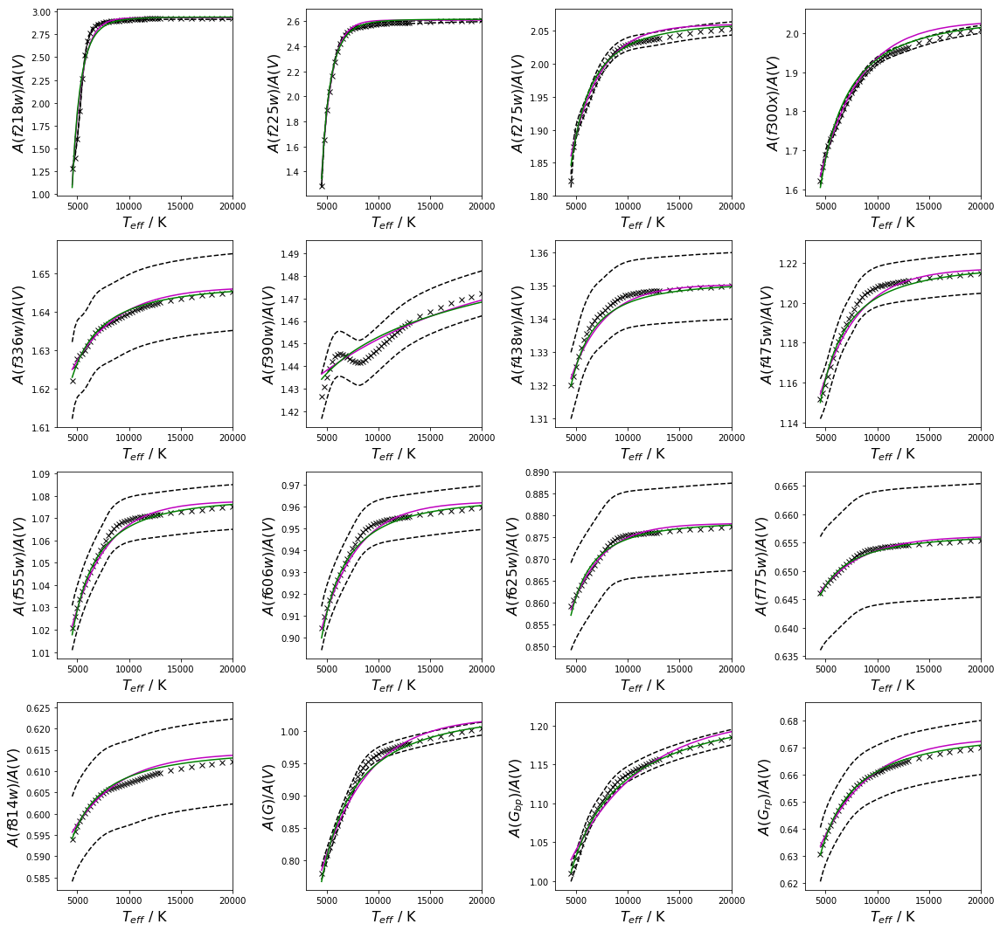


    Writing complete for log(g) = 3.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 3.0
Exponential fit coefficients (should be reused): 
[-232.252   -10.762     2.9334]
Standard deviations (should be reused): 
[  9.1340e+00   8.1606e-02   1.3238e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0214 -5.6005  2.9402]
Standard deviations (should be reused): 
[ 0.0006  0.0402  0.0014]
Logistic fit coefficients: 
[  5.2878e+03   2.6575e+01   2.9219e+00   1.0856e+00]
Standard deviations: 
[  1.2000e+01   4.9631e-01   1.2711e-03   2.0796e-02]
Teff log-normal fit coefficients: 
[ 0.      2.2513  2.7104  2.    ]
Standard deviations: 
[ 0.      0.2957  0.0014  0.0848]





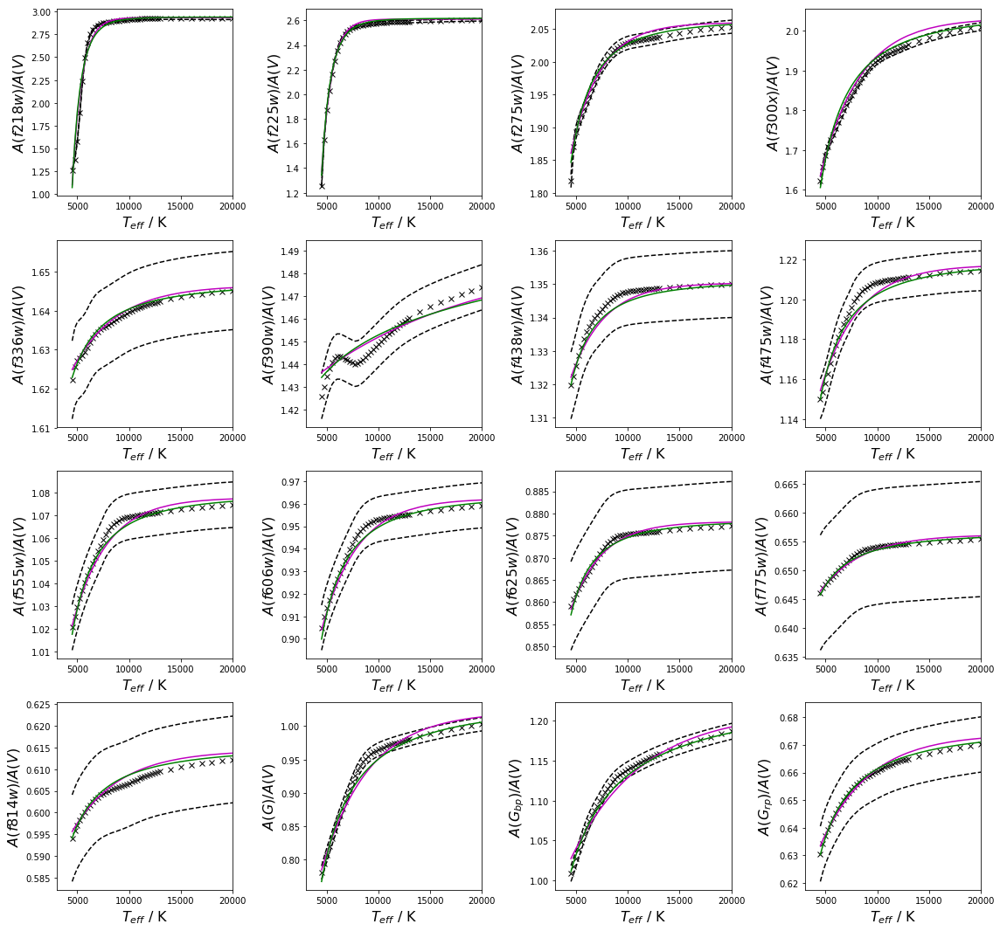


    Writing complete for log(g) = 3.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 2.5
Exponential fit coefficients (should be reused): 
[-232.252   -10.762     2.9334]
Standard deviations (should be reused): 
[  9.1340e+00   8.1606e-02   1.3238e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0214 -5.6005  2.9402]
Standard deviations (should be reused): 
[ 0.0006  0.0402  0.0014]
Logistic fit coefficients: 
[  5.2878e+03   2.6575e+01   2.9219e+00   1.0856e+00]
Standard deviations: 
[  1.2000e+01   4.9631e-01   1.2711e-03   2.0796e-02]
Teff log-normal fit coefficients: 
[ 0.      2.2513  2.7104  2.    ]
Standard deviations: 
[ 0.      0.2957  0.0014  0.0848]





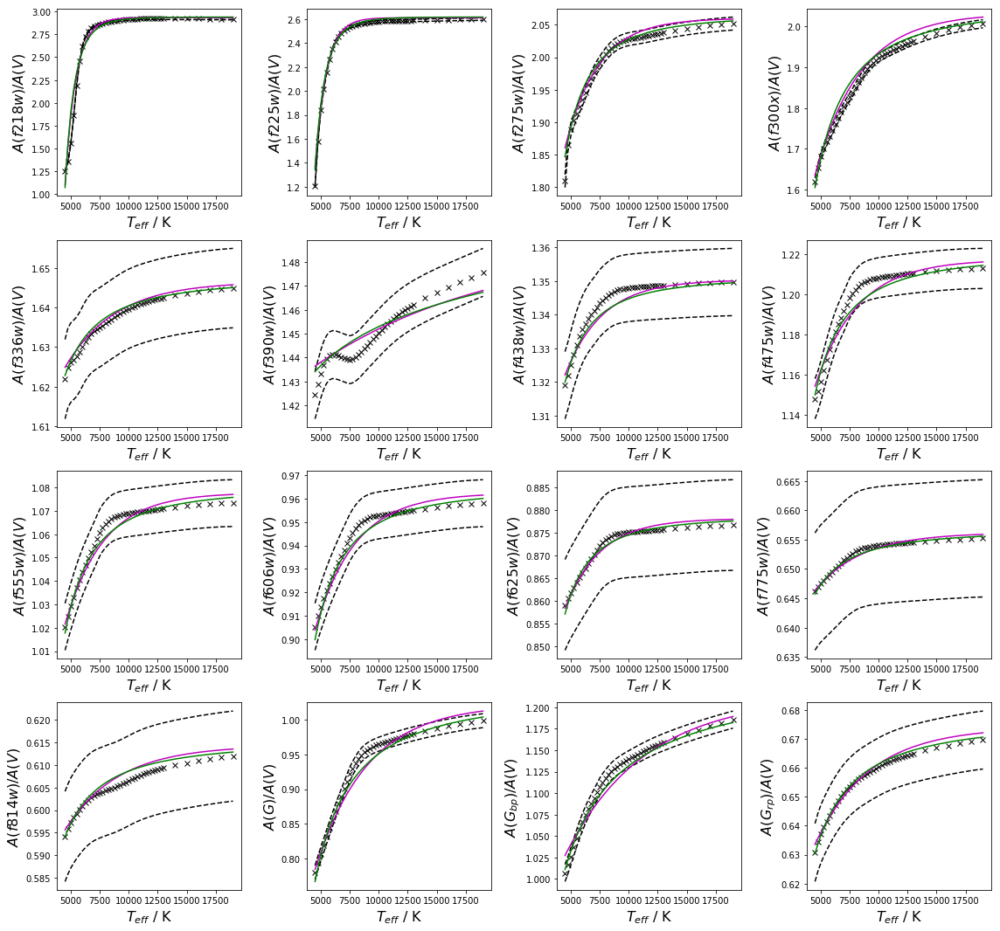


    Writing complete for log(g) = 2.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 2.0
Exponential fit coefficients (should be reused): 
[-232.252   -10.762     2.9334]
Standard deviations (should be reused): 
[  9.1340e+00   8.1606e-02   1.3238e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0214 -5.6005  2.9402]
Standard deviations (should be reused): 
[ 0.0006  0.0402  0.0014]
Logistic fit coefficients: 
[  5.2878e+03   2.6575e+01   2.9219e+00   1.0856e+00]
Standard deviations: 
[  1.2000e+01   4.9631e-01   1.2711e-03   2.0796e-02]
Teff log-normal fit coefficients: 
[ 0.      2.2513  2.7104  2.    ]
Standard deviations: 
[ 0.      0.2957  0.0014  0.0848]





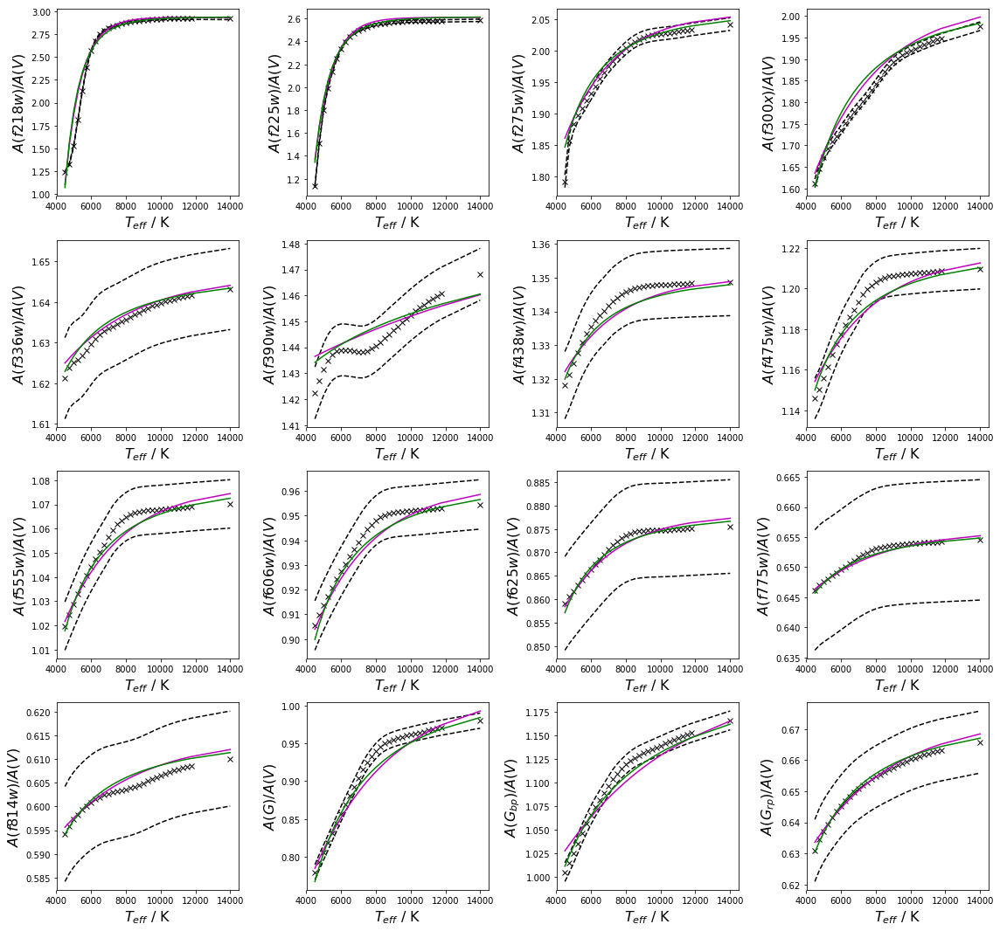


    Writing complete for log(g) = 2.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 1.5
Exponential fit coefficients (should be reused): 
[-232.252   -10.762     2.9334]
Standard deviations (should be reused): 
[  9.1340e+00   8.1606e-02   1.3238e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0214 -5.6005  2.9402]
Standard deviations (should be reused): 
[ 0.0006  0.0402  0.0014]
Logistic fit coefficients: 
[  5.2878e+03   2.6575e+01   2.9219e+00   1.0856e+00]
Standard deviations: 
[  1.2000e+01   4.9631e-01   1.2711e-03   2.0796e-02]
Teff log-normal fit coefficients: 
[ 0.      2.2513  2.7104  2.    ]
Standard deviations: 
[ 0.      0.2957  0.0014  0.0848]





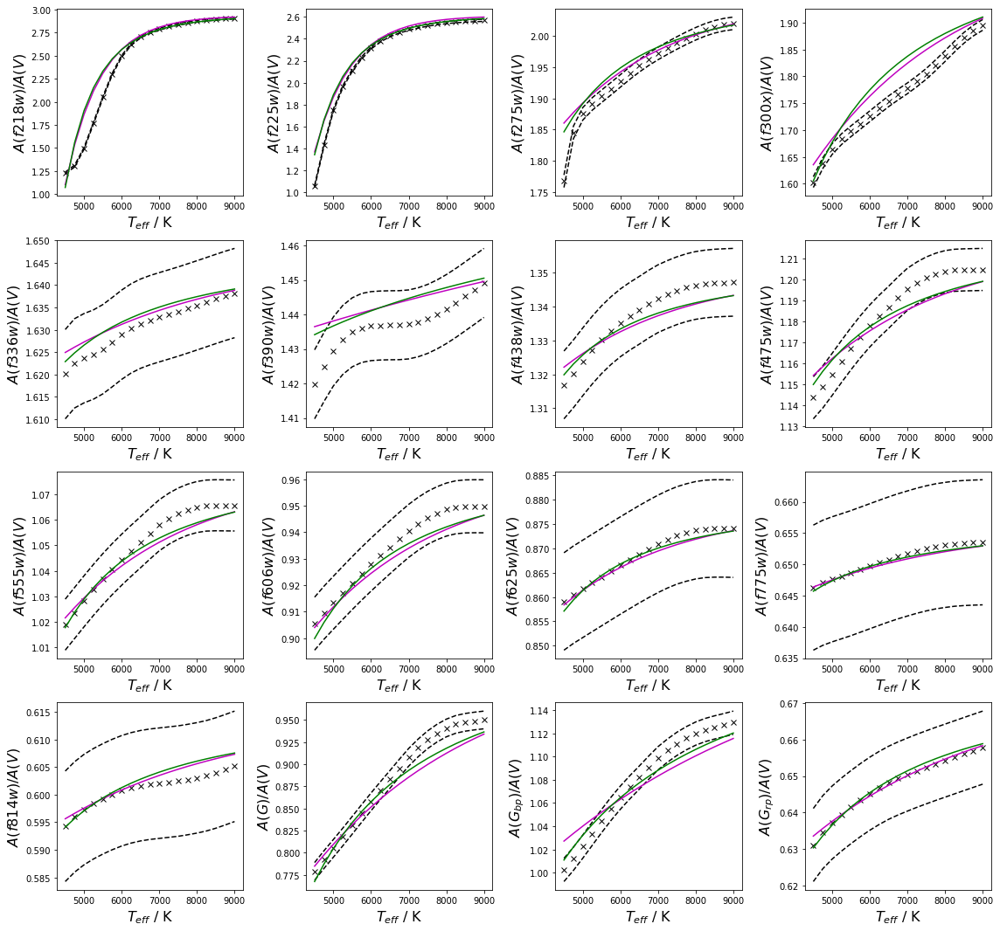


    Writing complete for log(g) = 1.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 1.0
Exponential fit coefficients (should be reused): 
[-232.252   -10.762     2.9334]
Standard deviations (should be reused): 
[  9.1340e+00   8.1606e-02   1.3238e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0214 -5.6005  2.9402]
Standard deviations (should be reused): 
[ 0.0006  0.0402  0.0014]
Logistic fit coefficients: 
[  5.2878e+03   2.6575e+01   2.9219e+00   1.0856e+00]
Standard deviations: 
[  1.2000e+01   4.9631e-01   1.2711e-03   2.0796e-02]
Teff log-normal fit coefficients: 
[ 0.      2.2513  2.7104  2.    ]
Standard deviations: 
[ 0.      0.2957  0.0014  0.0848]





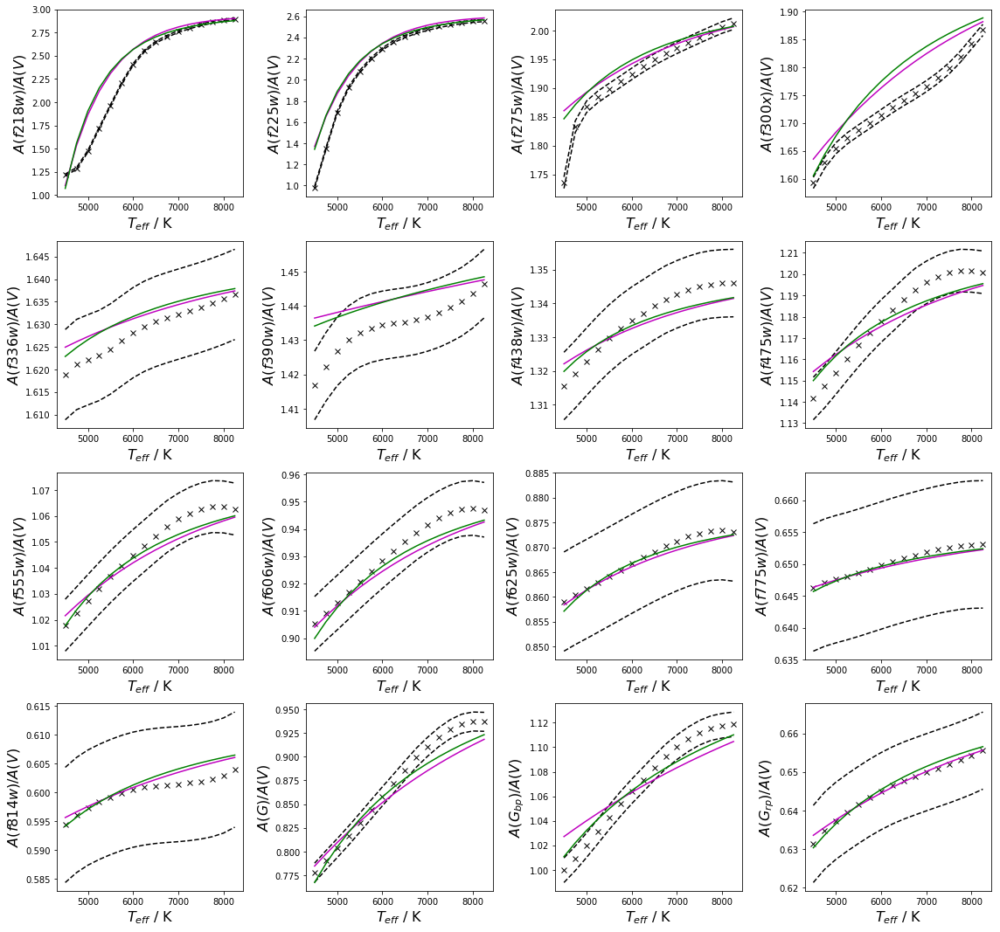


    Writing complete for log(g) = 1.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 0.5
Exponential fit coefficients (should be reused): 
[-232.252   -10.762     2.9334]
Standard deviations (should be reused): 
[  9.1340e+00   8.1606e-02   1.3238e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0214 -5.6005  2.9402]
Standard deviations (should be reused): 
[ 0.0006  0.0402  0.0014]
Logistic fit coefficients: 
[  5.2878e+03   2.6575e+01   2.9219e+00   1.0856e+00]
Standard deviations: 
[  1.2000e+01   4.9631e-01   1.2711e-03   2.0796e-02]
Teff log-normal fit coefficients: 
[ 0.      2.2513  2.7104  2.    ]
Standard deviations: 
[ 0.      0.2957  0.0014  0.0848]





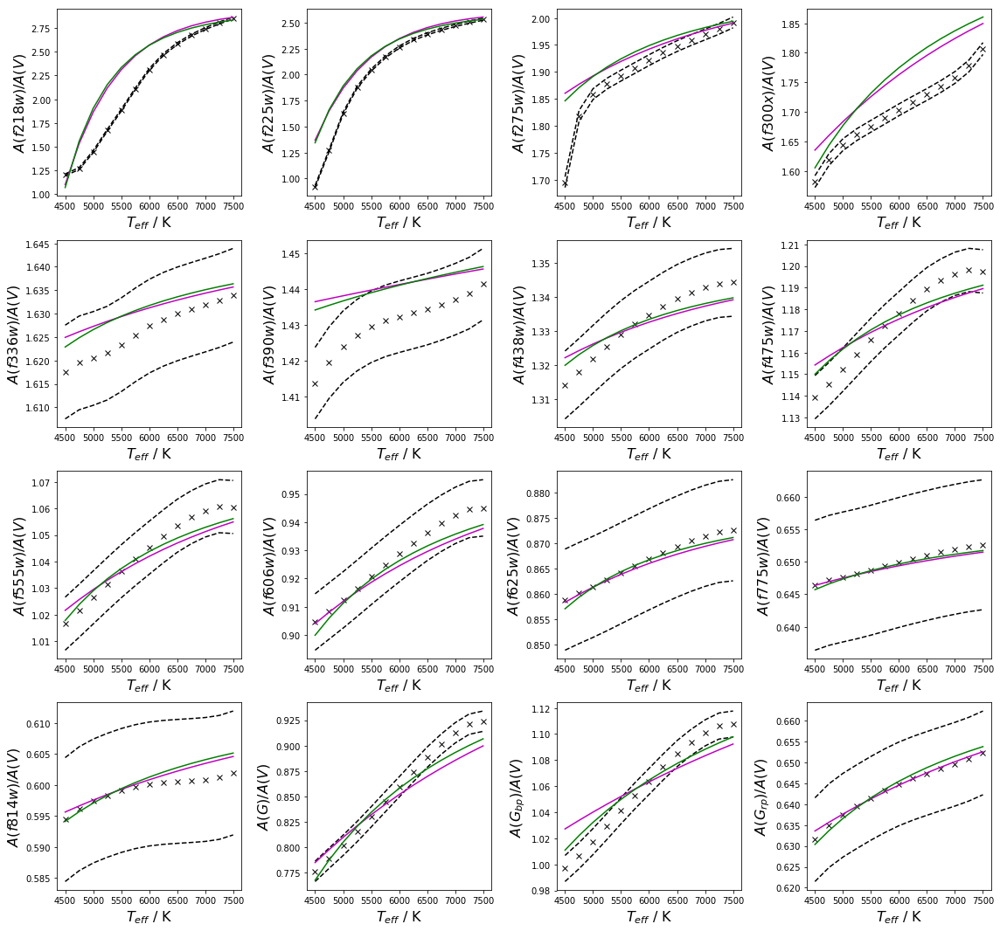


    Writing complete for log(g) = 0.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 0.0
Exponential fit coefficients (should be reused): 
[-232.252   -10.762     2.9334]
Standard deviations (should be reused): 
[  9.1340e+00   8.1606e-02   1.3238e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0214 -5.6005  2.9402]
Standard deviations (should be reused): 
[ 0.0006  0.0402  0.0014]
Logistic fit coefficients: 
[  5.2878e+03   2.6575e+01   2.9219e+00   1.0856e+00]
Standard deviations: 
[  1.2000e+01   4.9631e-01   1.2711e-03   2.0796e-02]
Teff log-normal fit coefficients: 
[ 0.      2.2513  2.7104  2.    ]
Standard deviations: 
[ 0.      0.2957  0.0014  0.0848]





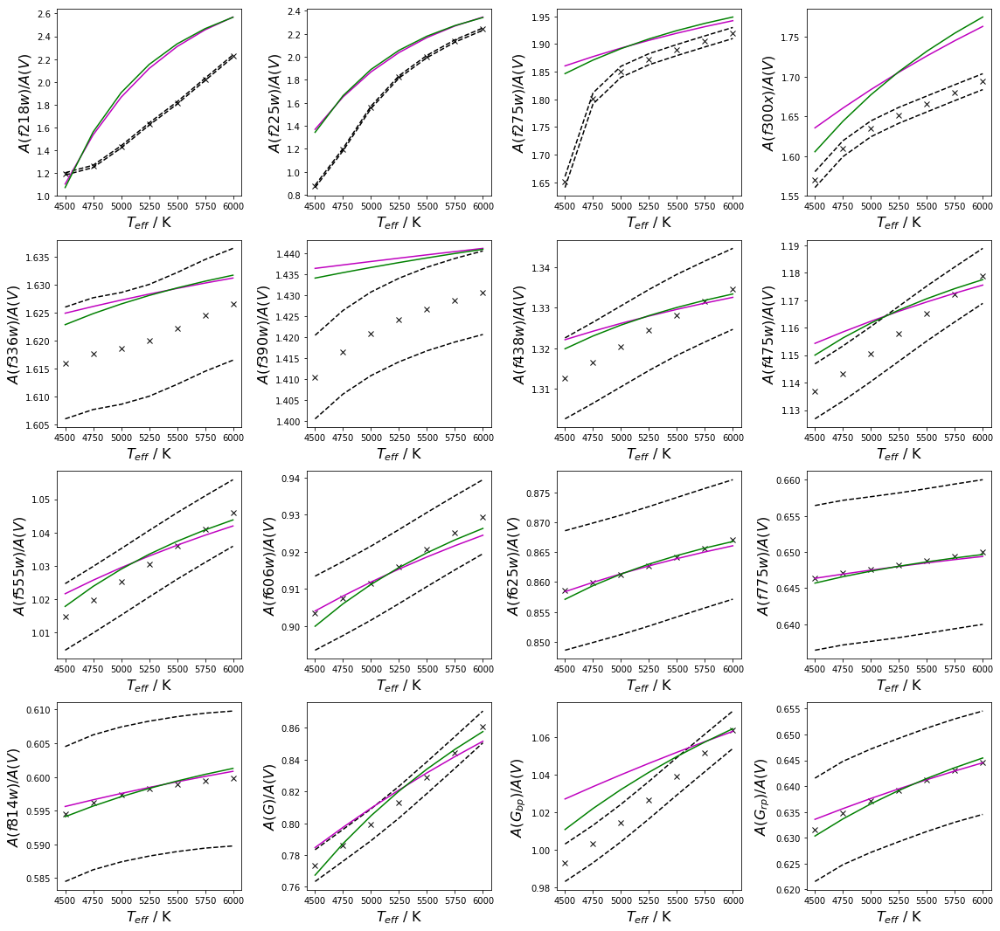


    Writing complete for log(g) = 0.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 5.0


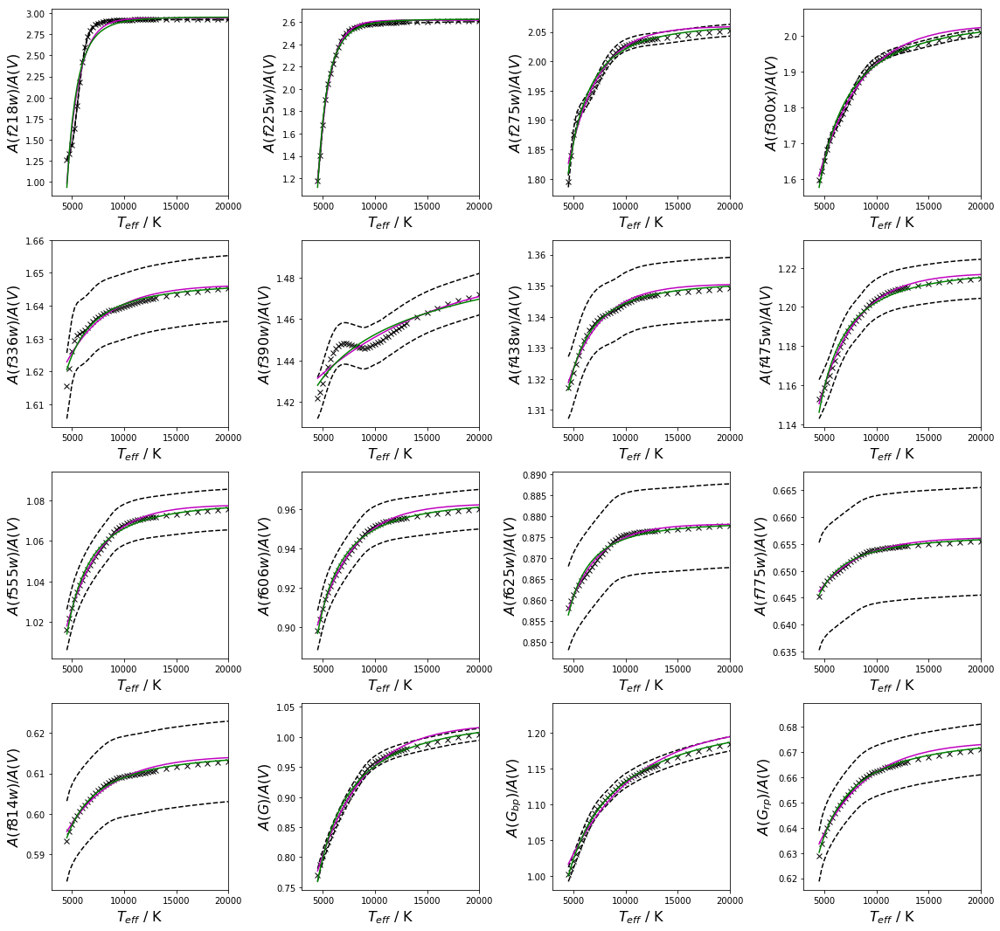


    Writing complete for log(g) = 5.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 4.5
Exponential fit coefficients (should be reused): 
[-84.8536  -8.3764   2.9428]
Standard deviations (should be reused): 
[  2.2878e+00   5.4740e-02   1.3736e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0539 -4.5361  2.9536]
Standard deviations (should be reused): 
[ 0.0011  0.0279  0.0015]
Logistic fit coefficients: 
[  5.6146e+03   2.3222e+01   2.9260e+00   1.1157e+00]
Standard deviations: 
[  1.0380e+01   3.6752e-01   1.2925e-03   1.4388e-02]
Teff log-normal fit coefficients: 
[ 0.      1.3765  2.6392  2.    ]
Standard deviations: 
[ 0.      0.056   0.0014  0.0208]





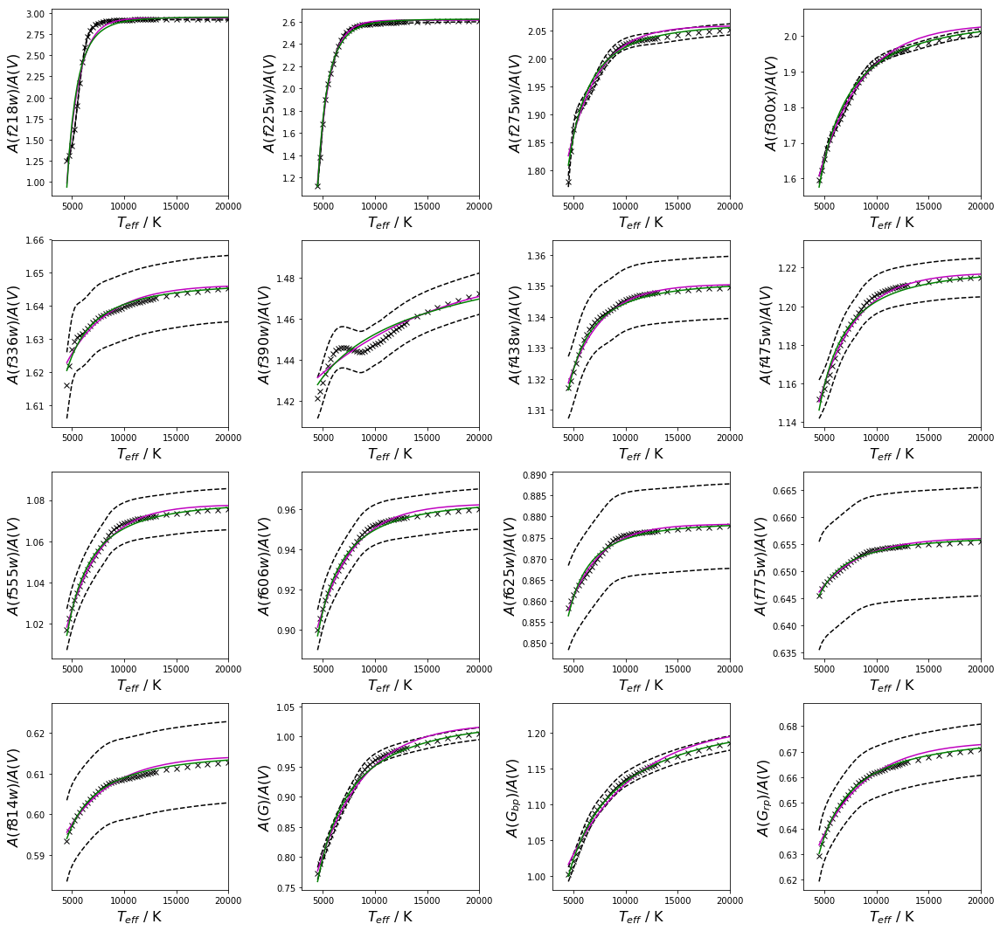


    Writing complete for log(g) = 4.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 4.0
Exponential fit coefficients (should be reused): 
[-84.8536  -8.3764   2.9428]
Standard deviations (should be reused): 
[  2.2878e+00   5.4740e-02   1.3736e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0539 -4.5361  2.9536]
Standard deviations (should be reused): 
[ 0.0011  0.0279  0.0015]
Logistic fit coefficients: 
[  5.6146e+03   2.3222e+01   2.9260e+00   1.1157e+00]
Standard deviations: 
[  1.0380e+01   3.6752e-01   1.2925e-03   1.4388e-02]
Teff log-normal fit coefficients: 
[ 0.      1.3765  2.6392  2.    ]
Standard deviations: 
[ 0.      0.056   0.0014  0.0208]





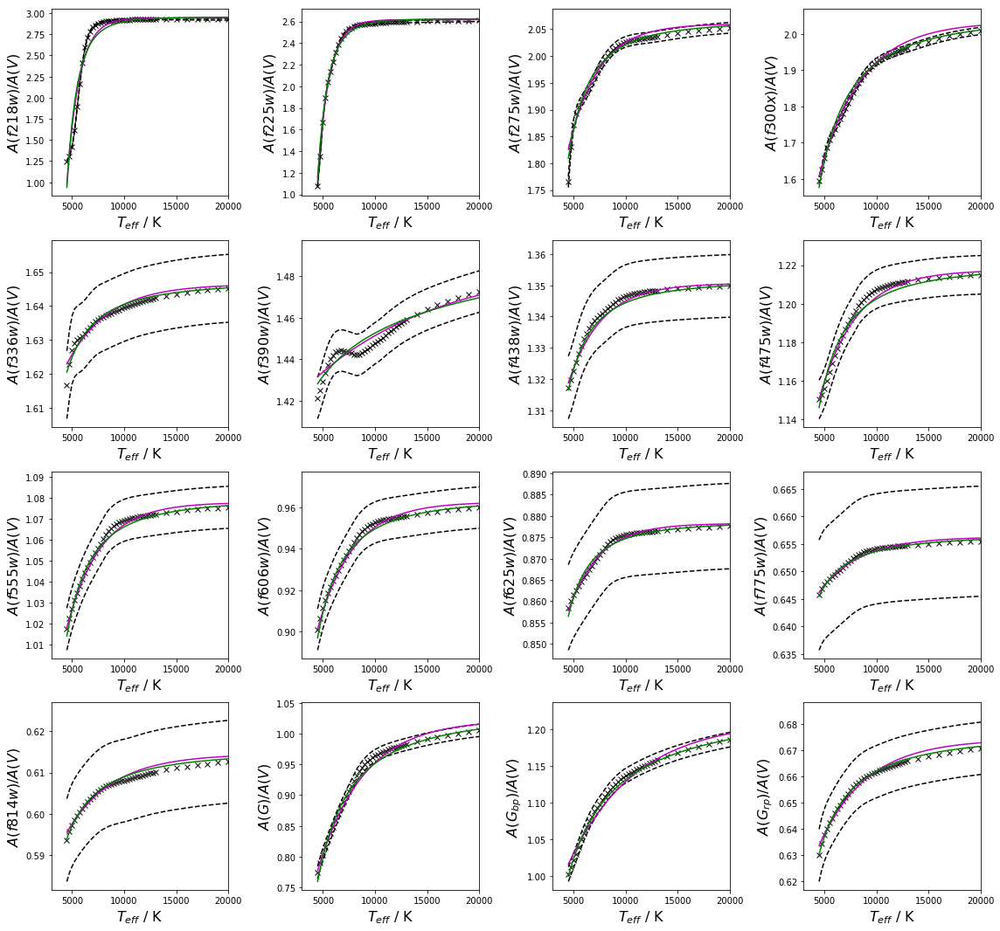


    Writing complete for log(g) = 4.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 3.5
Exponential fit coefficients (should be reused): 
[-84.8536  -8.3764   2.9428]
Standard deviations (should be reused): 
[  2.2878e+00   5.4740e-02   1.3736e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0539 -4.5361  2.9536]
Standard deviations (should be reused): 
[ 0.0011  0.0279  0.0015]
Logistic fit coefficients: 
[  5.6146e+03   2.3222e+01   2.9260e+00   1.1157e+00]
Standard deviations: 
[  1.0380e+01   3.6752e-01   1.2925e-03   1.4388e-02]
Teff log-normal fit coefficients: 
[ 0.      1.3765  2.6392  2.    ]
Standard deviations: 
[ 0.      0.056   0.0014  0.0208]





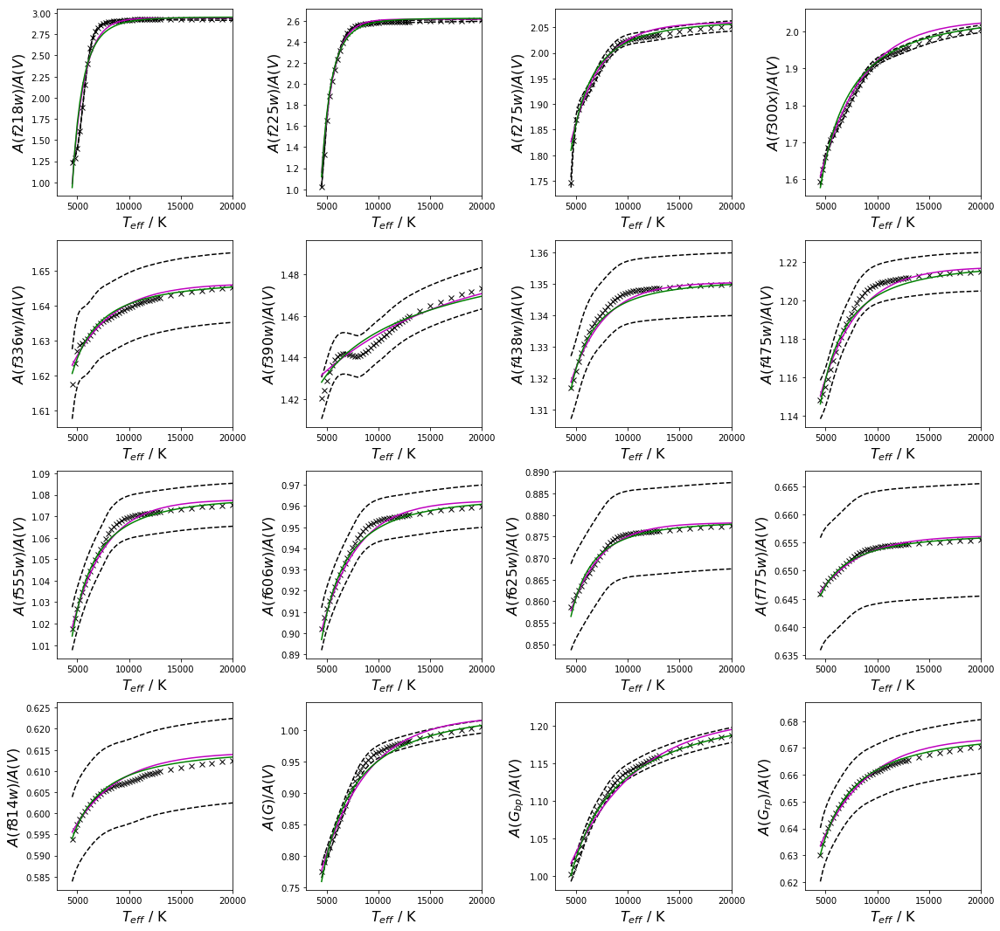


    Writing complete for log(g) = 3.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 3.0
Exponential fit coefficients (should be reused): 
[-84.8536  -8.3764   2.9428]
Standard deviations (should be reused): 
[  2.2878e+00   5.4740e-02   1.3736e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0539 -4.5361  2.9536]
Standard deviations (should be reused): 
[ 0.0011  0.0279  0.0015]
Logistic fit coefficients: 
[  5.6146e+03   2.3222e+01   2.9260e+00   1.1157e+00]
Standard deviations: 
[  1.0380e+01   3.6752e-01   1.2925e-03   1.4388e-02]
Teff log-normal fit coefficients: 
[ 0.      1.3765  2.6392  2.    ]
Standard deviations: 
[ 0.      0.056   0.0014  0.0208]





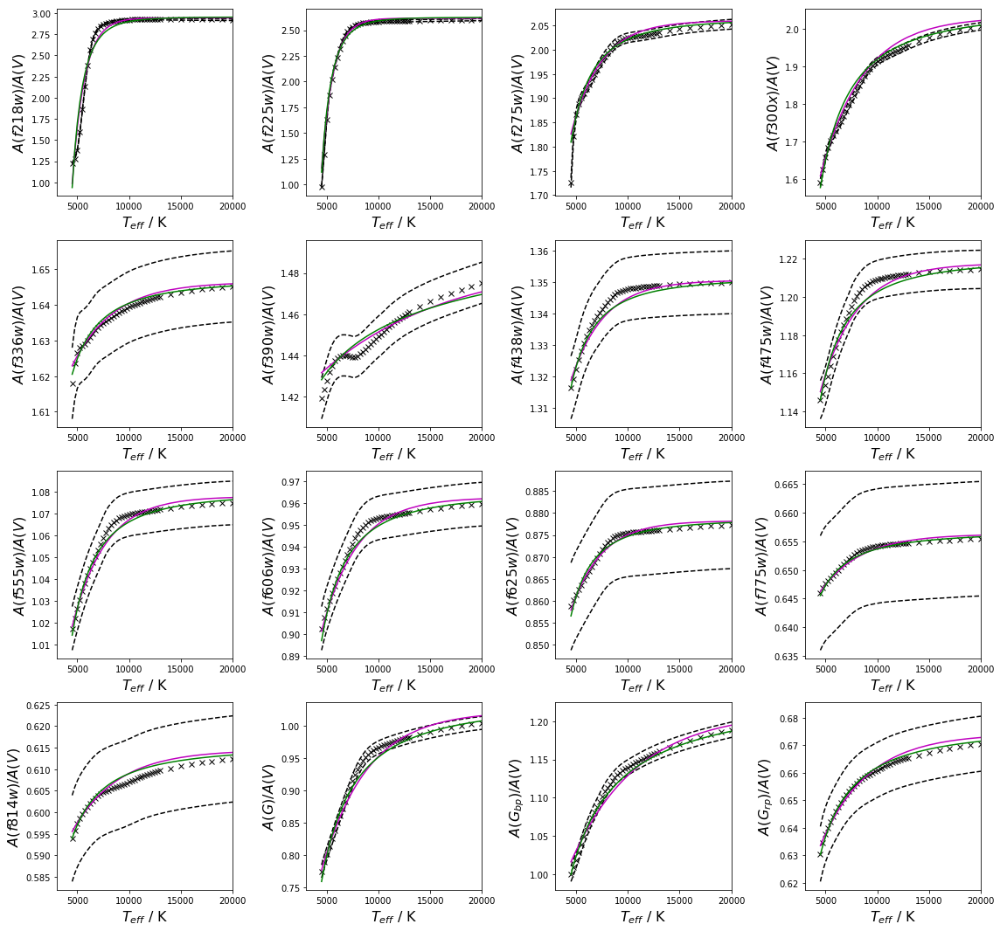


    Writing complete for log(g) = 3.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 2.5
Exponential fit coefficients (should be reused): 
[-84.8536  -8.3764   2.9428]
Standard deviations (should be reused): 
[  2.2878e+00   5.4740e-02   1.3736e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0539 -4.5361  2.9536]
Standard deviations (should be reused): 
[ 0.0011  0.0279  0.0015]
Logistic fit coefficients: 
[  5.6146e+03   2.3222e+01   2.9260e+00   1.1157e+00]
Standard deviations: 
[  1.0380e+01   3.6752e-01   1.2925e-03   1.4388e-02]
Teff log-normal fit coefficients: 
[ 0.      1.3765  2.6392  2.    ]
Standard deviations: 
[ 0.      0.056   0.0014  0.0208]





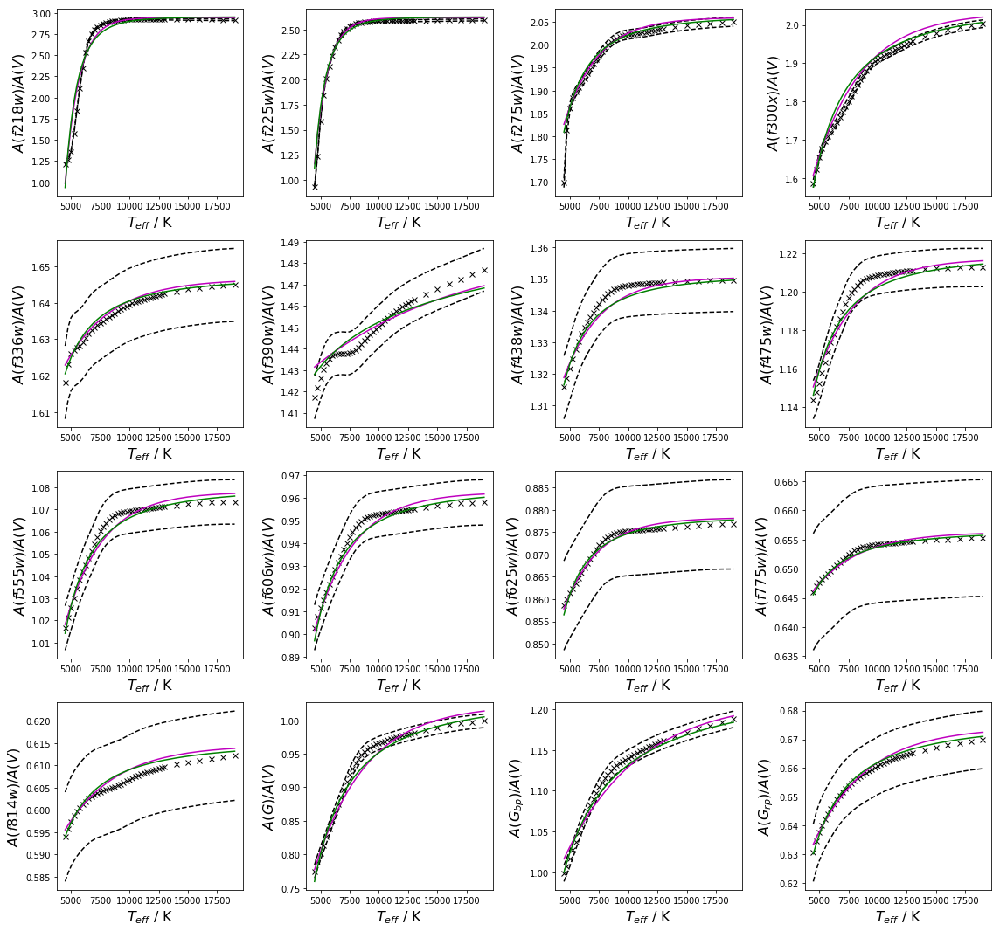


    Writing complete for log(g) = 2.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 2.0
Exponential fit coefficients (should be reused): 
[-84.8536  -8.3764   2.9428]
Standard deviations (should be reused): 
[  2.2878e+00   5.4740e-02   1.3736e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0539 -4.5361  2.9536]
Standard deviations (should be reused): 
[ 0.0011  0.0279  0.0015]
Logistic fit coefficients: 
[  5.6146e+03   2.3222e+01   2.9260e+00   1.1157e+00]
Standard deviations: 
[  1.0380e+01   3.6752e-01   1.2925e-03   1.4388e-02]
Teff log-normal fit coefficients: 
[ 0.      1.3765  2.6392  2.    ]
Standard deviations: 
[ 0.      0.056   0.0014  0.0208]





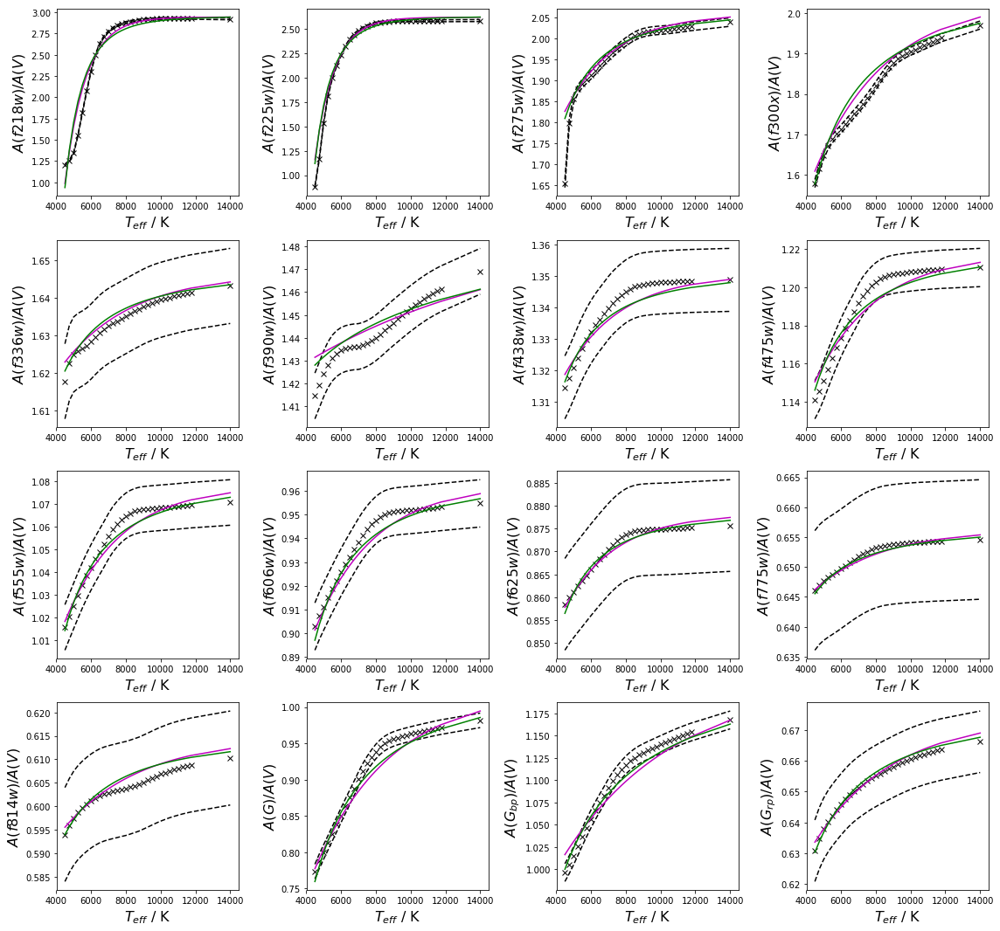


    Writing complete for log(g) = 2.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 1.5
Exponential fit coefficients (should be reused): 
[-84.8536  -8.3764   2.9428]
Standard deviations (should be reused): 
[  2.2878e+00   5.4740e-02   1.3736e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0539 -4.5361  2.9536]
Standard deviations (should be reused): 
[ 0.0011  0.0279  0.0015]
Logistic fit coefficients: 
[  5.6146e+03   2.3222e+01   2.9260e+00   1.1157e+00]
Standard deviations: 
[  1.0380e+01   3.6752e-01   1.2925e-03   1.4388e-02]
Teff log-normal fit coefficients: 
[ 0.      1.3765  2.6392  2.    ]
Standard deviations: 
[ 0.      0.056   0.0014  0.0208]





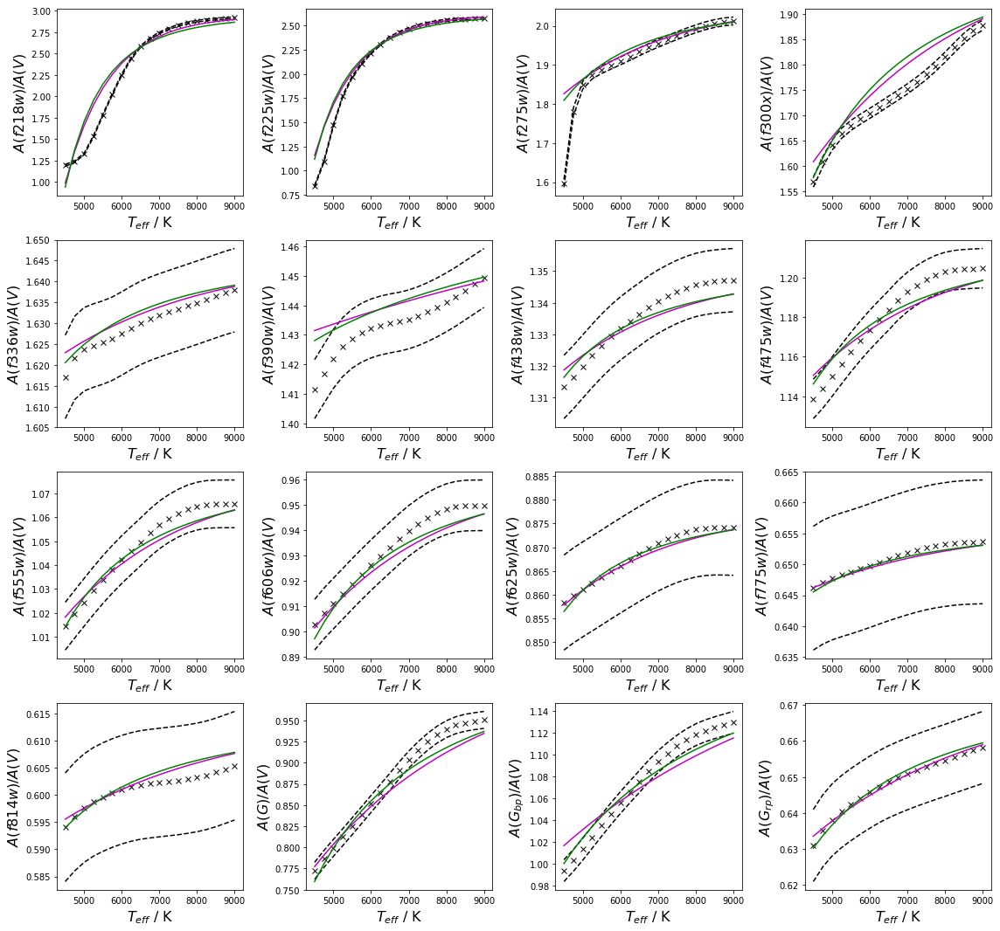


    Writing complete for log(g) = 1.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 1.0
Exponential fit coefficients (should be reused): 
[-84.8536  -8.3764   2.9428]
Standard deviations (should be reused): 
[  2.2878e+00   5.4740e-02   1.3736e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0539 -4.5361  2.9536]
Standard deviations (should be reused): 
[ 0.0011  0.0279  0.0015]
Logistic fit coefficients: 
[  5.6146e+03   2.3222e+01   2.9260e+00   1.1157e+00]
Standard deviations: 
[  1.0380e+01   3.6752e-01   1.2925e-03   1.4388e-02]
Teff log-normal fit coefficients: 
[ 0.      1.3765  2.6392  2.    ]
Standard deviations: 
[ 0.      0.056   0.0014  0.0208]





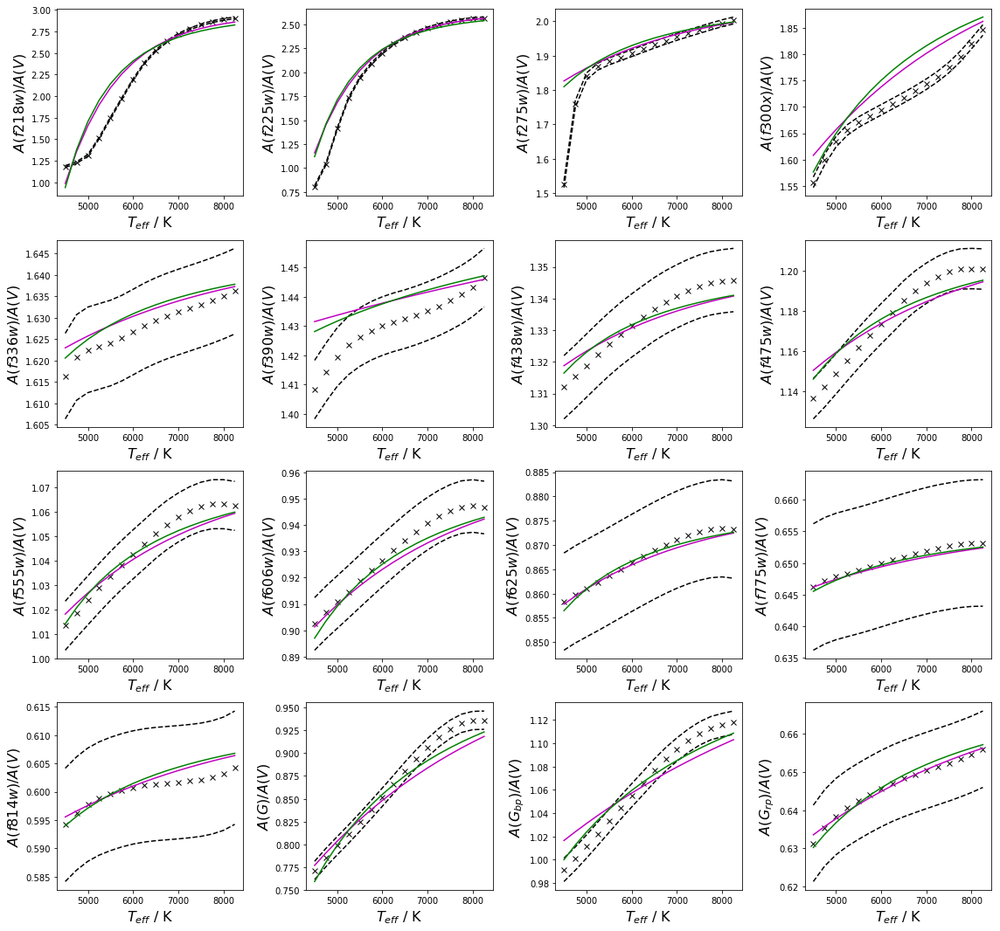


    Writing complete for log(g) = 1.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 0.5
Exponential fit coefficients (should be reused): 
[-84.8536  -8.3764   2.9428]
Standard deviations (should be reused): 
[  2.2878e+00   5.4740e-02   1.3736e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0539 -4.5361  2.9536]
Standard deviations (should be reused): 
[ 0.0011  0.0279  0.0015]
Logistic fit coefficients: 
[  5.6146e+03   2.3222e+01   2.9260e+00   1.1157e+00]
Standard deviations: 
[  1.0380e+01   3.6752e-01   1.2925e-03   1.4388e-02]
Teff log-normal fit coefficients: 
[ 0.      1.3765  2.6392  2.    ]
Standard deviations: 
[ 0.      0.056   0.0014  0.0208]





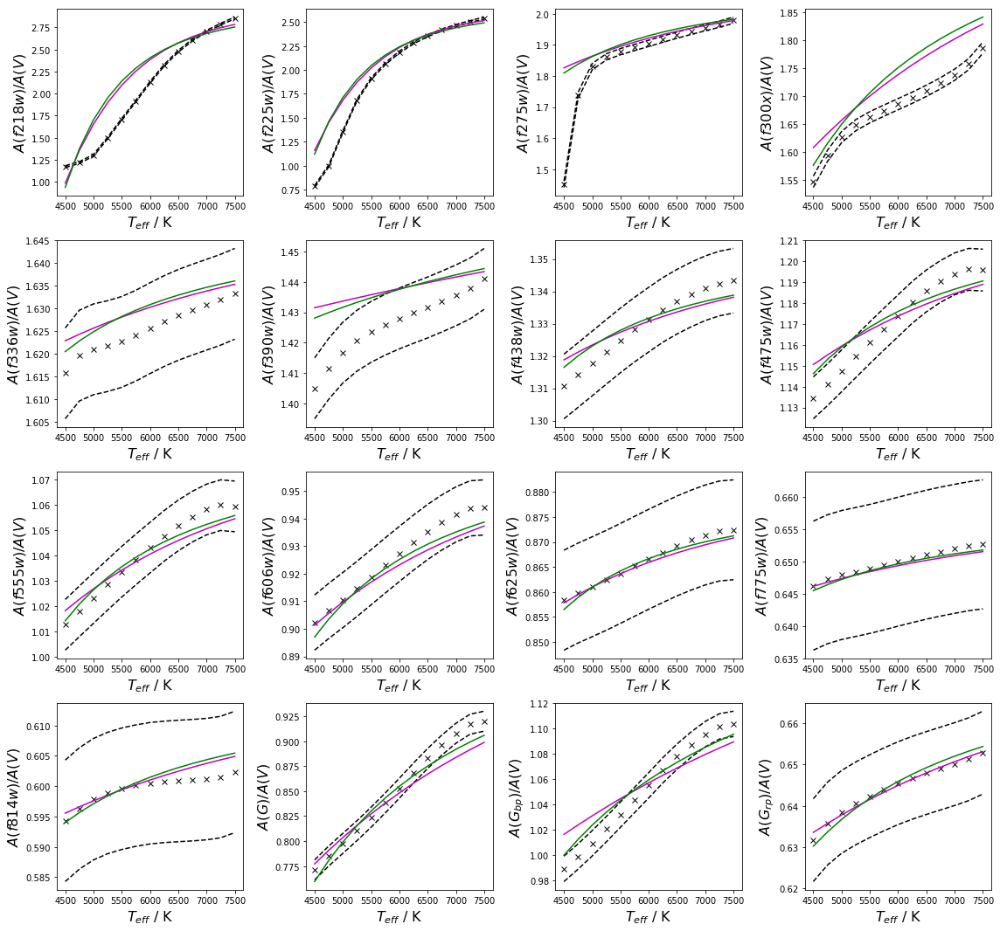


    Writing complete for log(g) = 0.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 0.0
Exponential fit coefficients (should be reused): 
[-84.8536  -8.3764   2.9428]
Standard deviations (should be reused): 
[  2.2878e+00   5.4740e-02   1.3736e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0539 -4.5361  2.9536]
Standard deviations (should be reused): 
[ 0.0011  0.0279  0.0015]
Logistic fit coefficients: 
[  5.6146e+03   2.3222e+01   2.9260e+00   1.1157e+00]
Standard deviations: 
[  1.0380e+01   3.6752e-01   1.2925e-03   1.4388e-02]
Teff log-normal fit coefficients: 
[ 0.      1.3765  2.6392  2.    ]
Standard deviations: 
[ 0.      0.056   0.0014  0.0208]





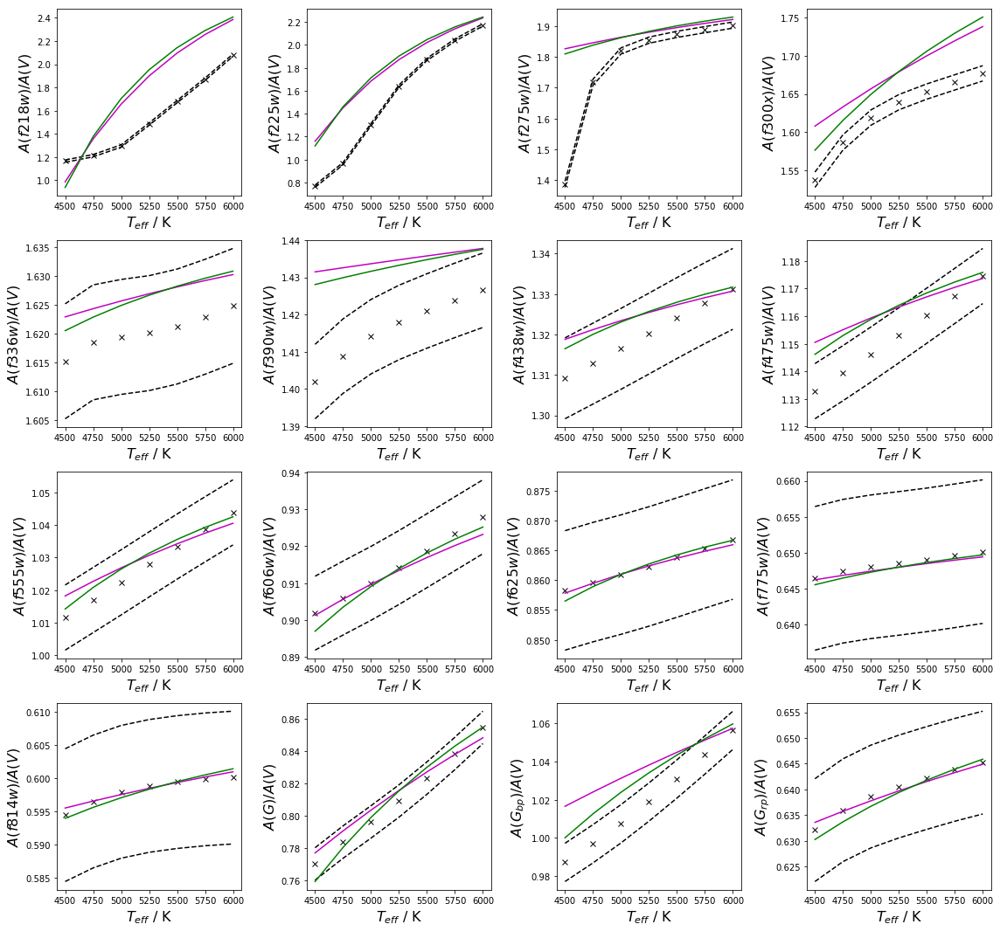


    Writing complete for log(g) = 0.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 5.0


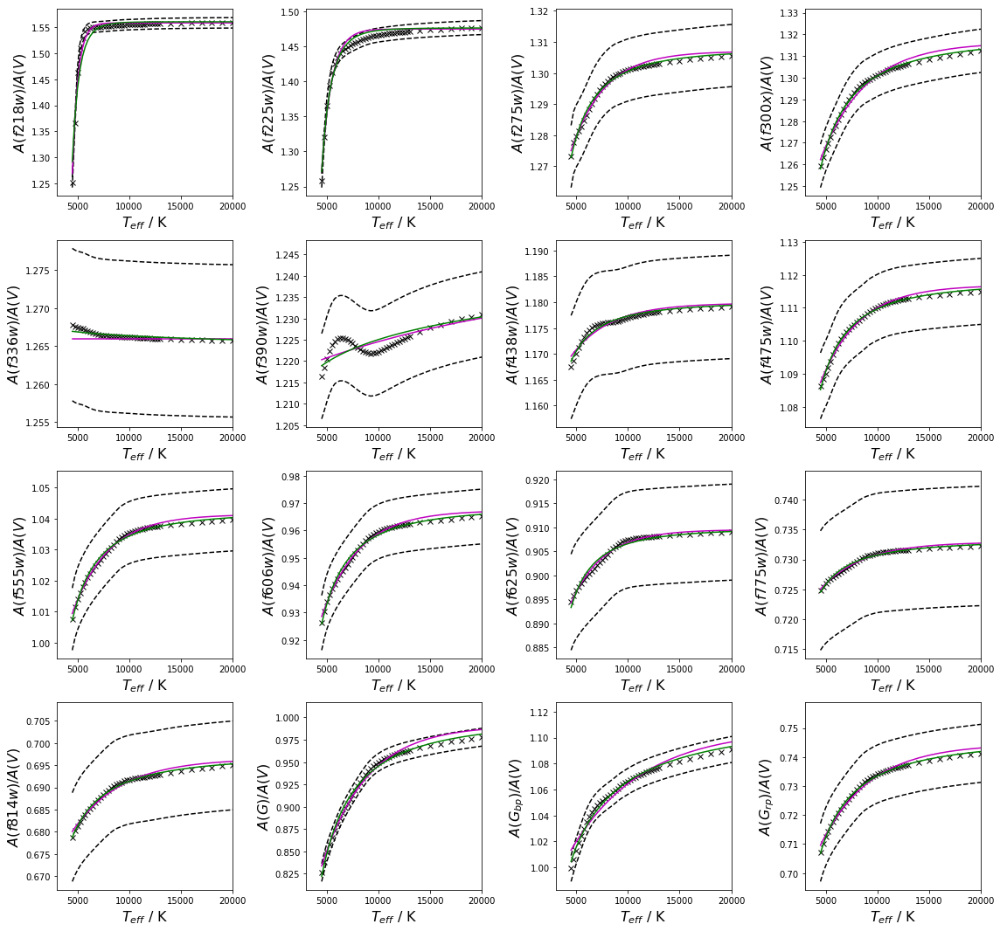


    Writing complete for log(g) = 5.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 4.5
Exponential fit coefficients (should be reused): 
[-1000.      -18.1076    1.5584]
Standard deviations (should be reused): 
[  4.8219e+02   1.0348e+00   1.2597e-03]
Teff^(n) fit coefficients (should be reused): 
[ -1.0035e-03  -7.0000e+00   1.5605e+00]
Standard deviations (should be reused): 
[  2.8921e-04   3.8012e-01   1.3231e-03]
Logistic fit coefficients: 
[  4.4187e+03   3.0775e+01   1.5570e+00   8.5664e-01]
Standard deviations: 
[  2.7300e+02   5.2671e+00   1.2433e-03   3.2332e-01]
Teff log-normal fit coefficients: 
[ 0.      0.4906  1.5361  1.5048]
Standard deviations: 
[ 0.      0.0979  0.0015  0.0038]





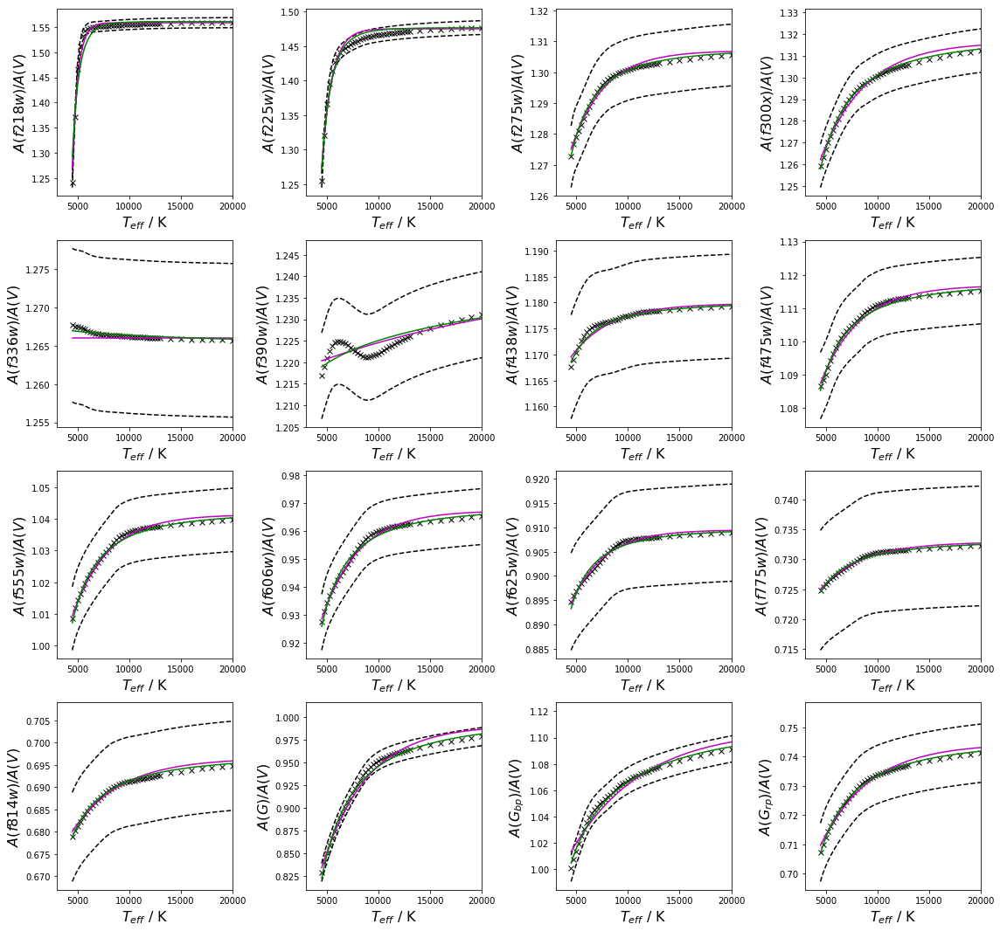


    Writing complete for log(g) = 4.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 4.0
Exponential fit coefficients (should be reused): 
[-1000.      -18.1076    1.5584]
Standard deviations (should be reused): 
[  4.8219e+02   1.0348e+00   1.2597e-03]
Teff^(n) fit coefficients (should be reused): 
[ -1.0035e-03  -7.0000e+00   1.5605e+00]
Standard deviations (should be reused): 
[  2.8921e-04   3.8012e-01   1.3231e-03]
Logistic fit coefficients: 
[  4.4187e+03   3.0775e+01   1.5570e+00   8.5664e-01]
Standard deviations: 
[  2.7300e+02   5.2671e+00   1.2433e-03   3.2332e-01]
Teff log-normal fit coefficients: 
[ 0.      0.4906  1.5361  1.5048]
Standard deviations: 
[ 0.      0.0979  0.0015  0.0038]





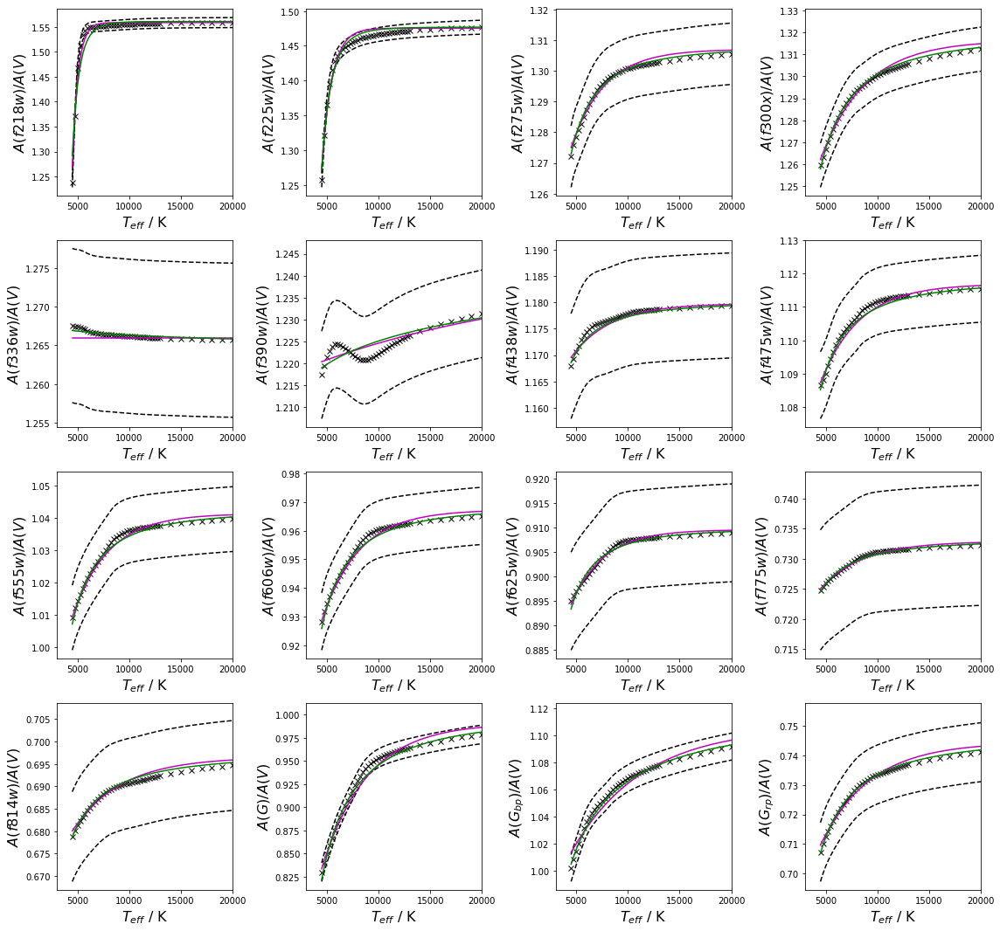


    Writing complete for log(g) = 4.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 3.5
Exponential fit coefficients (should be reused): 
[-1000.      -18.1076    1.5584]
Standard deviations (should be reused): 
[  4.8219e+02   1.0348e+00   1.2597e-03]
Teff^(n) fit coefficients (should be reused): 
[ -1.0035e-03  -7.0000e+00   1.5605e+00]
Standard deviations (should be reused): 
[  2.8921e-04   3.8012e-01   1.3231e-03]
Logistic fit coefficients: 
[  4.4187e+03   3.0775e+01   1.5570e+00   8.5664e-01]
Standard deviations: 
[  2.7300e+02   5.2671e+00   1.2433e-03   3.2332e-01]
Teff log-normal fit coefficients: 
[ 0.      0.4906  1.5361  1.5048]
Standard deviations: 
[ 0.      0.0979  0.0015  0.0038]





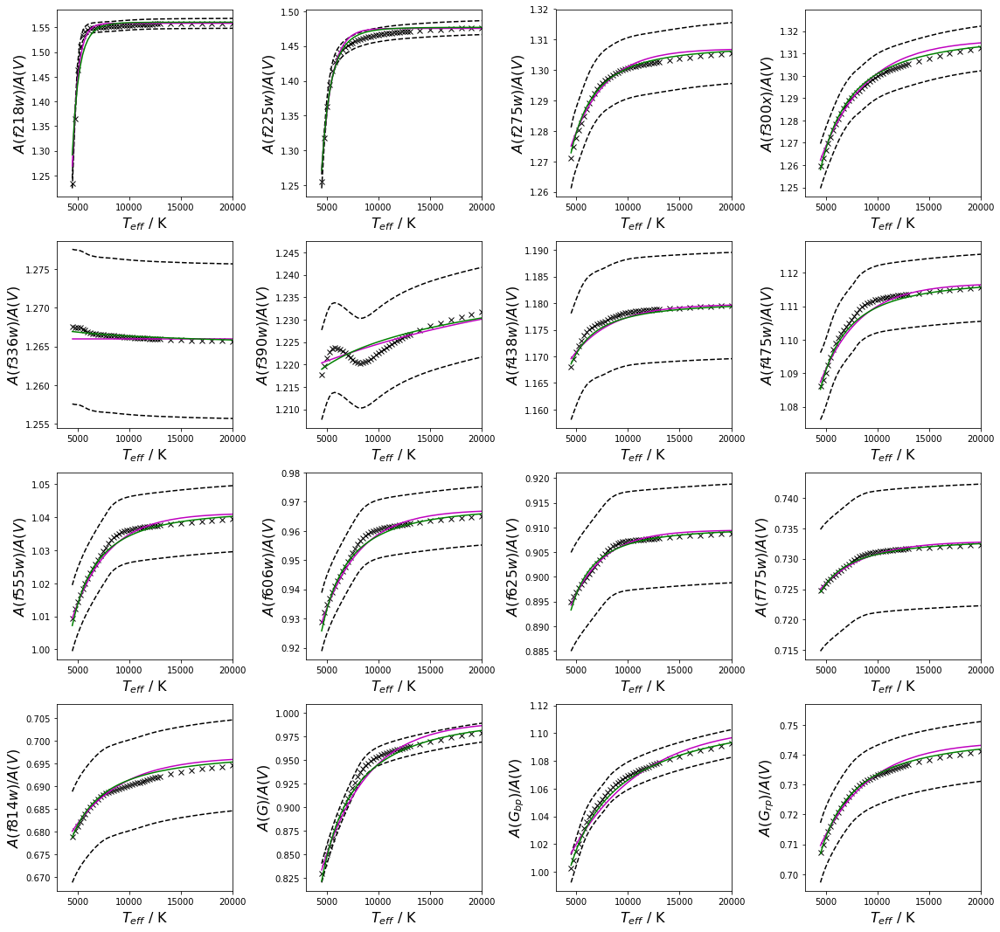


    Writing complete for log(g) = 3.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 3.0
Exponential fit coefficients (should be reused): 
[-1000.      -18.1076    1.5584]
Standard deviations (should be reused): 
[  4.8219e+02   1.0348e+00   1.2597e-03]
Teff^(n) fit coefficients (should be reused): 
[ -1.0035e-03  -7.0000e+00   1.5605e+00]
Standard deviations (should be reused): 
[  2.8921e-04   3.8012e-01   1.3231e-03]
Logistic fit coefficients: 
[  4.4187e+03   3.0775e+01   1.5570e+00   8.5664e-01]
Standard deviations: 
[  2.7300e+02   5.2671e+00   1.2433e-03   3.2332e-01]
Teff log-normal fit coefficients: 
[ 0.      0.4906  1.5361  1.5048]
Standard deviations: 
[ 0.      0.0979  0.0015  0.0038]





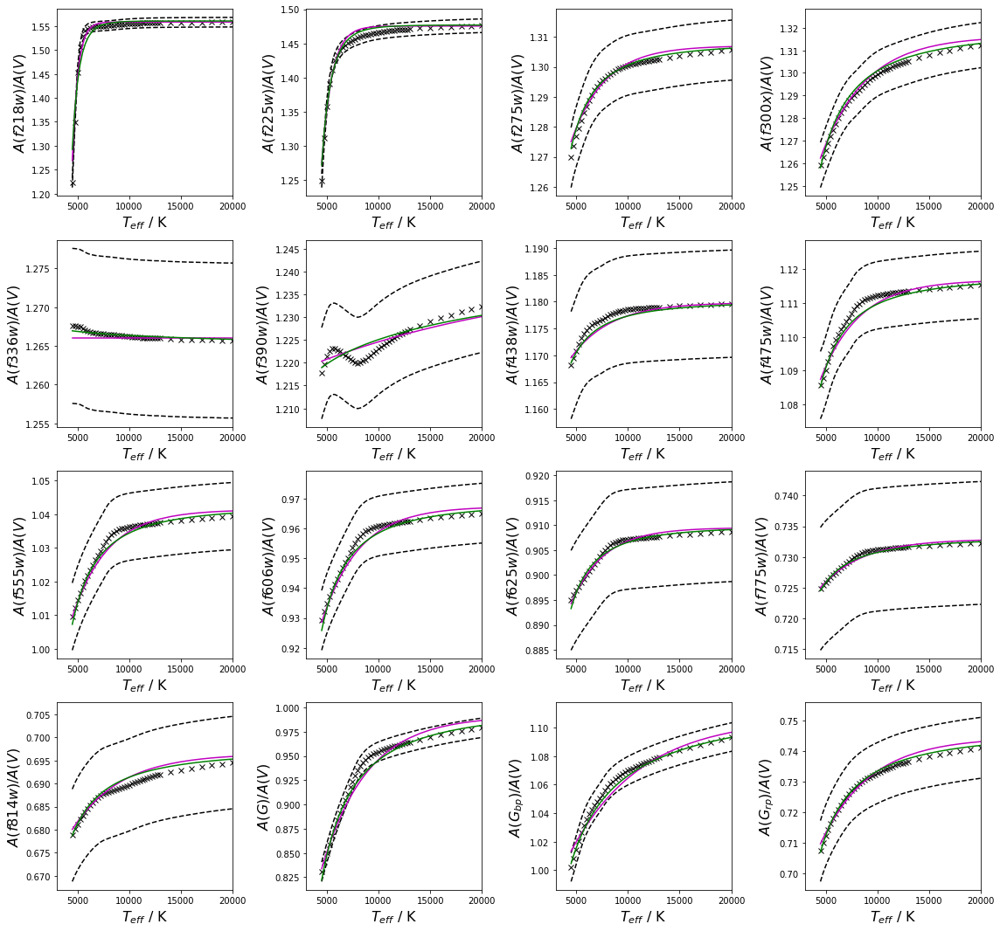


    Writing complete for log(g) = 3.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 2.5
Exponential fit coefficients (should be reused): 
[-1000.      -18.1076    1.5584]
Standard deviations (should be reused): 
[  4.8219e+02   1.0348e+00   1.2597e-03]
Teff^(n) fit coefficients (should be reused): 
[ -1.0035e-03  -7.0000e+00   1.5605e+00]
Standard deviations (should be reused): 
[  2.8921e-04   3.8012e-01   1.3231e-03]
Logistic fit coefficients: 
[  4.4187e+03   3.0775e+01   1.5570e+00   8.5664e-01]
Standard deviations: 
[  2.7300e+02   5.2671e+00   1.2433e-03   3.2332e-01]
Teff log-normal fit coefficients: 
[ 0.      0.4906  1.5361  1.5048]
Standard deviations: 
[ 0.      0.0979  0.0015  0.0038]





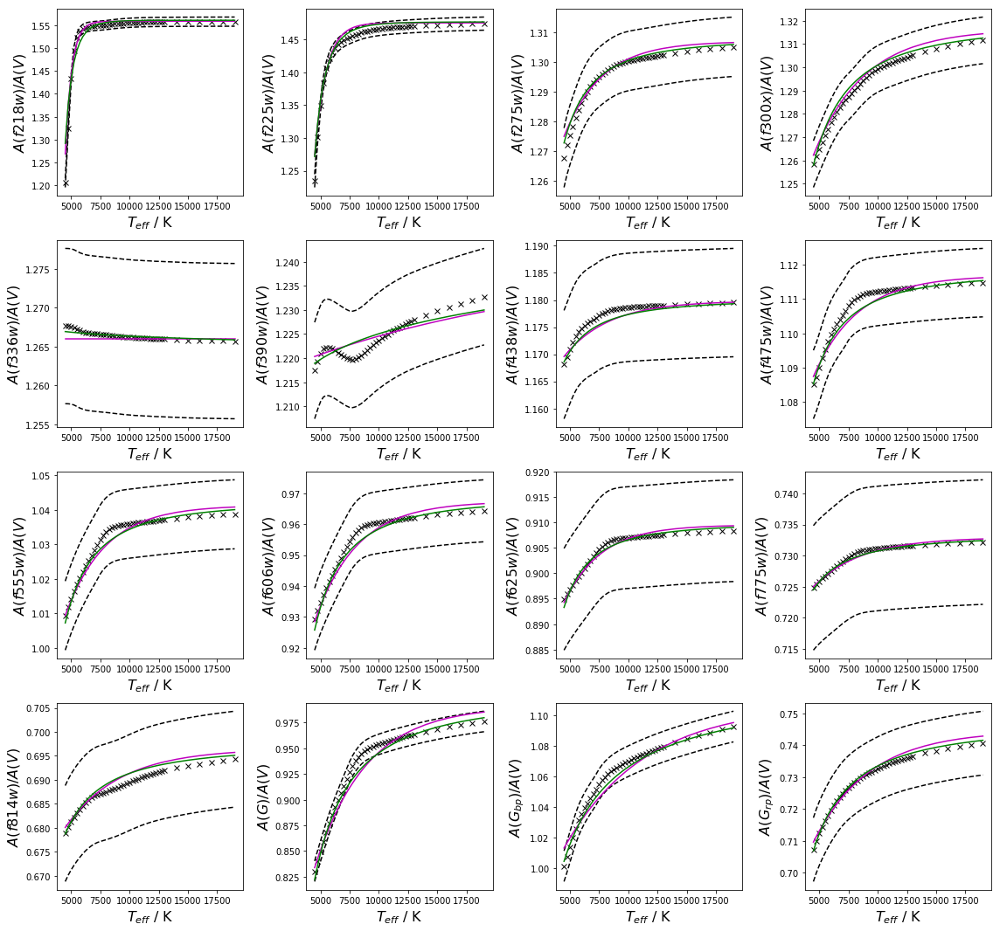


    Writing complete for log(g) = 2.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 2.0
Exponential fit coefficients (should be reused): 
[-1000.      -18.1076    1.5584]
Standard deviations (should be reused): 
[  4.8219e+02   1.0348e+00   1.2597e-03]
Teff^(n) fit coefficients (should be reused): 
[ -1.0035e-03  -7.0000e+00   1.5605e+00]
Standard deviations (should be reused): 
[  2.8921e-04   3.8012e-01   1.3231e-03]
Logistic fit coefficients: 
[  4.4187e+03   3.0775e+01   1.5570e+00   8.5664e-01]
Standard deviations: 
[  2.7300e+02   5.2671e+00   1.2433e-03   3.2332e-01]
Teff log-normal fit coefficients: 
[ 0.      0.4906  1.5361  1.5048]
Standard deviations: 
[ 0.      0.0979  0.0015  0.0038]





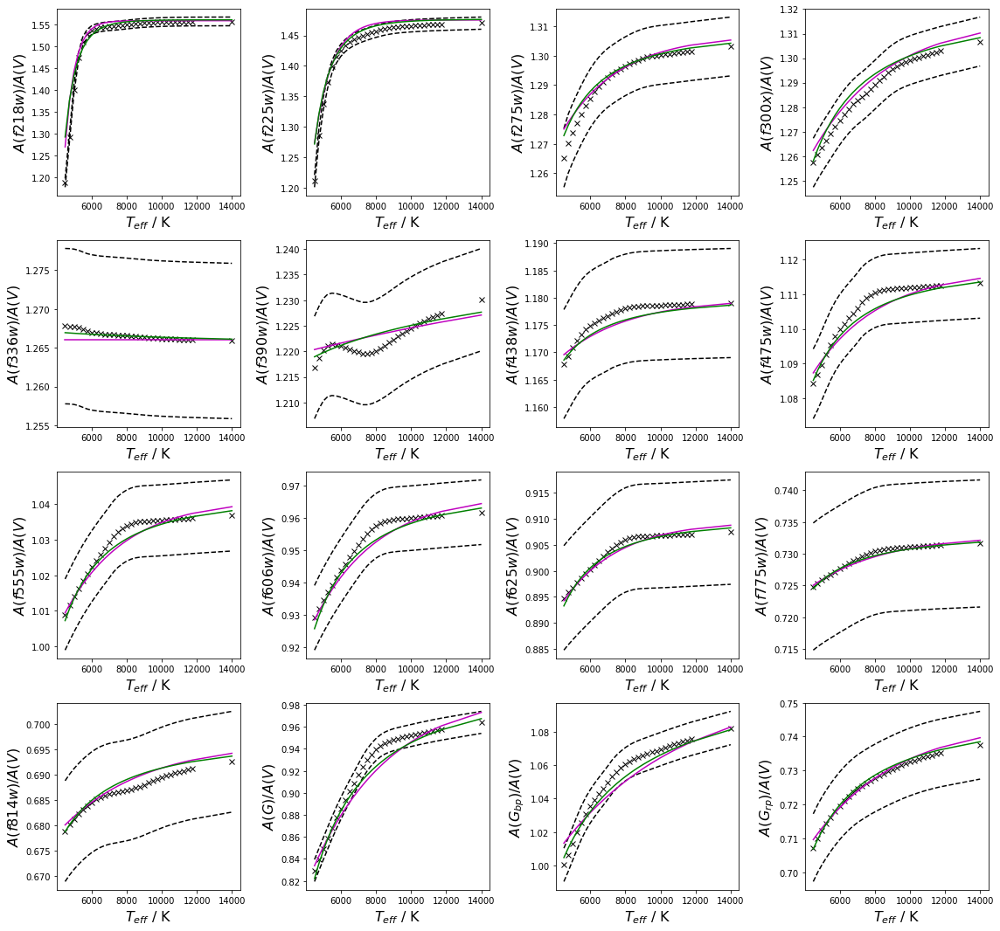


    Writing complete for log(g) = 2.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 1.5
Exponential fit coefficients (should be reused): 
[-1000.      -18.1076    1.5584]
Standard deviations (should be reused): 
[  4.8219e+02   1.0348e+00   1.2597e-03]
Teff^(n) fit coefficients (should be reused): 
[ -1.0035e-03  -7.0000e+00   1.5605e+00]
Standard deviations (should be reused): 
[  2.8921e-04   3.8012e-01   1.3231e-03]
Logistic fit coefficients: 
[  4.4187e+03   3.0775e+01   1.5570e+00   8.5664e-01]
Standard deviations: 
[  2.7300e+02   5.2671e+00   1.2433e-03   3.2332e-01]
Teff log-normal fit coefficients: 
[ 0.      0.4906  1.5361  1.5048]
Standard deviations: 
[ 0.      0.0979  0.0015  0.0038]





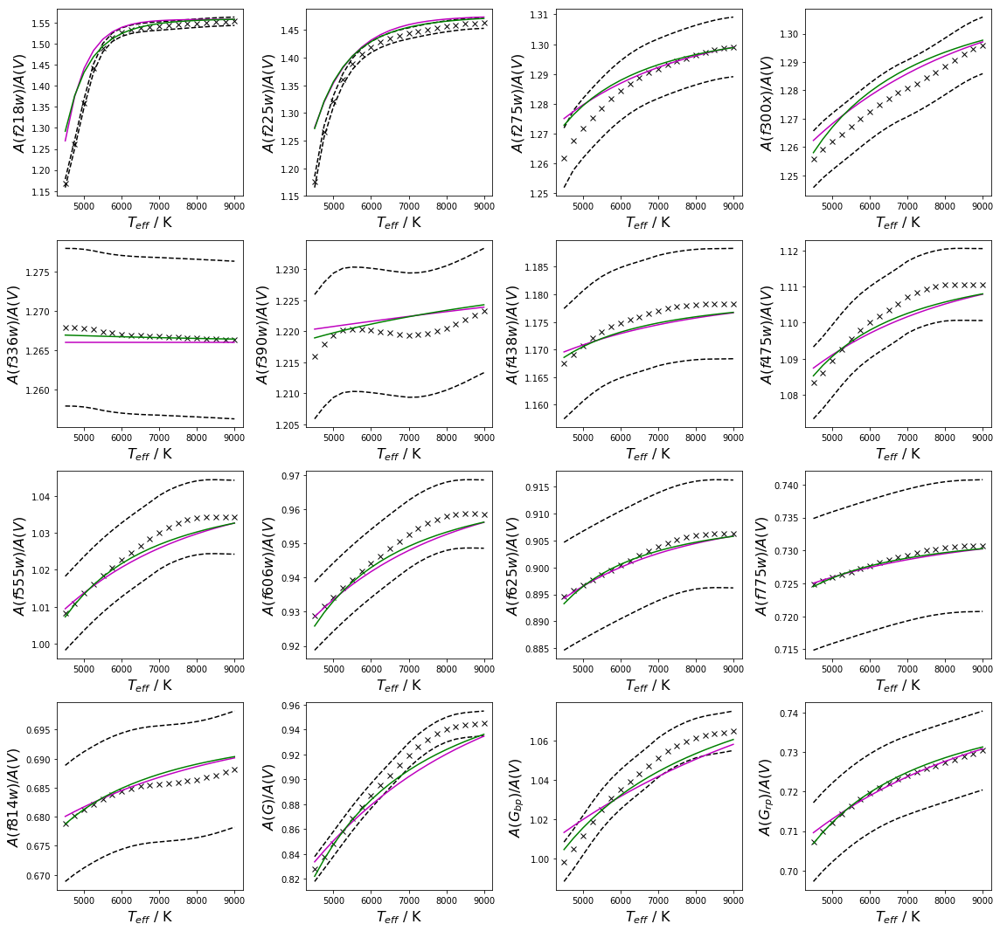


    Writing complete for log(g) = 1.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 1.0
Exponential fit coefficients (should be reused): 
[-1000.      -18.1076    1.5584]
Standard deviations (should be reused): 
[  4.8219e+02   1.0348e+00   1.2597e-03]
Teff^(n) fit coefficients (should be reused): 
[ -1.0035e-03  -7.0000e+00   1.5605e+00]
Standard deviations (should be reused): 
[  2.8921e-04   3.8012e-01   1.3231e-03]
Logistic fit coefficients: 
[  4.4187e+03   3.0775e+01   1.5570e+00   8.5664e-01]
Standard deviations: 
[  2.7300e+02   5.2671e+00   1.2433e-03   3.2332e-01]
Teff log-normal fit coefficients: 
[ 0.      0.4906  1.5361  1.5048]
Standard deviations: 
[ 0.      0.0979  0.0015  0.0038]





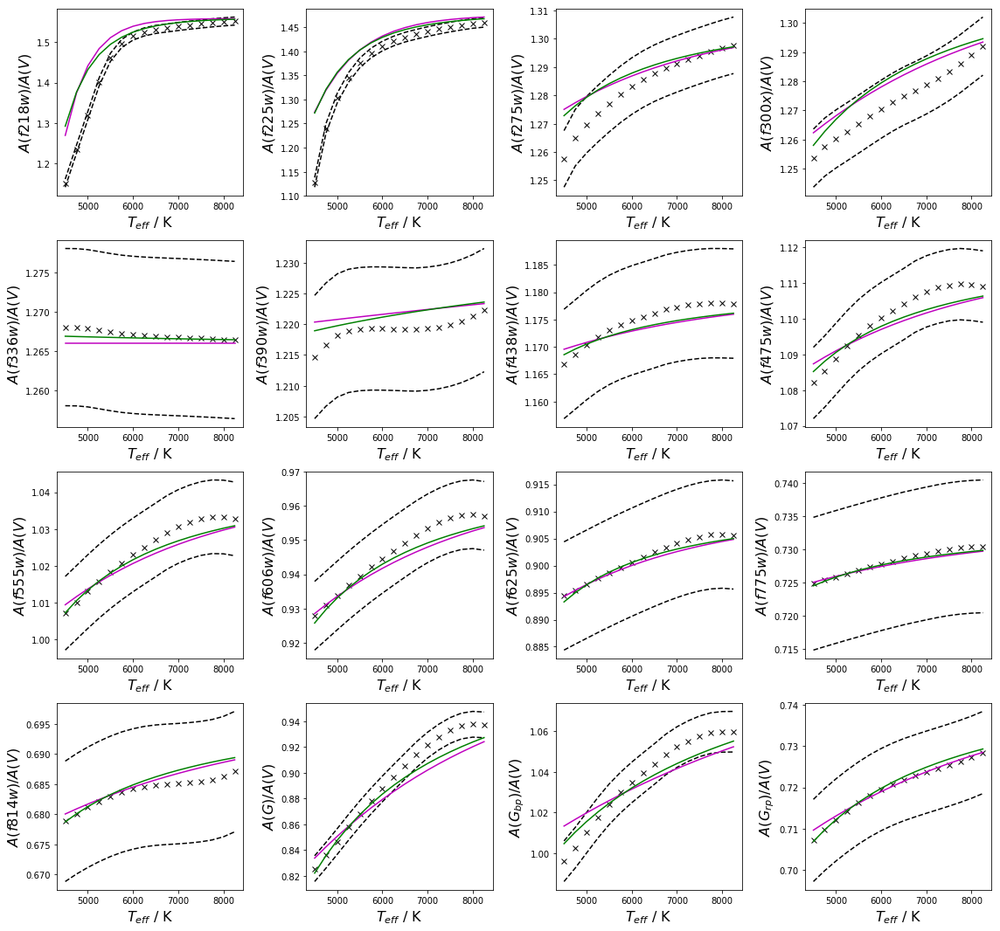


    Writing complete for log(g) = 1.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 0.5
Exponential fit coefficients (should be reused): 
[-1000.      -18.1076    1.5584]
Standard deviations (should be reused): 
[  4.8219e+02   1.0348e+00   1.2597e-03]
Teff^(n) fit coefficients (should be reused): 
[ -1.0035e-03  -7.0000e+00   1.5605e+00]
Standard deviations (should be reused): 
[  2.8921e-04   3.8012e-01   1.3231e-03]
Logistic fit coefficients: 
[  4.4187e+03   3.0775e+01   1.5570e+00   8.5664e-01]
Standard deviations: 
[  2.7300e+02   5.2671e+00   1.2433e-03   3.2332e-01]
Teff log-normal fit coefficients: 
[ 0.      0.4906  1.5361  1.5048]
Standard deviations: 
[ 0.      0.0979  0.0015  0.0038]





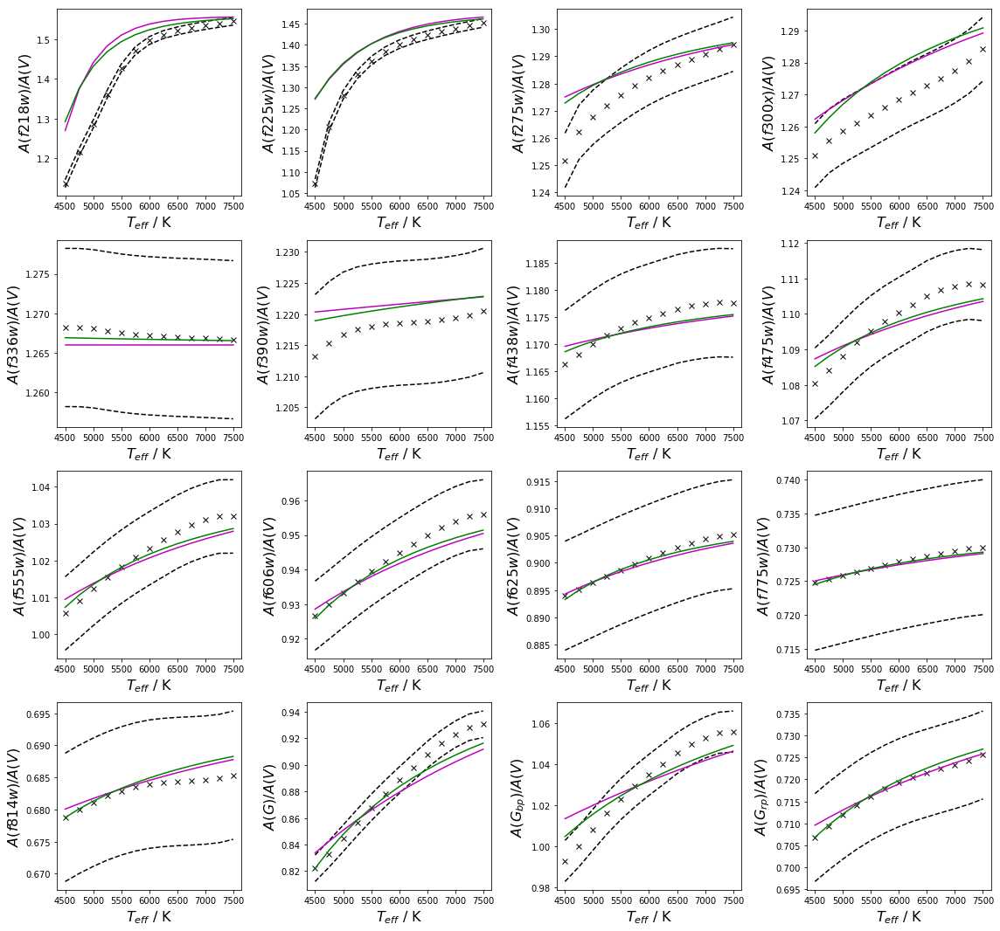


    Writing complete for log(g) = 0.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 0.0
Exponential fit coefficients (should be reused): 
[-1000.      -18.1076    1.5584]
Standard deviations (should be reused): 
[  4.8219e+02   1.0348e+00   1.2597e-03]
Teff^(n) fit coefficients (should be reused): 
[ -1.0035e-03  -7.0000e+00   1.5605e+00]
Standard deviations (should be reused): 
[  2.8921e-04   3.8012e-01   1.3231e-03]
Logistic fit coefficients: 
[  4.4187e+03   3.0775e+01   1.5570e+00   8.5664e-01]
Standard deviations: 
[  2.7300e+02   5.2671e+00   1.2433e-03   3.2332e-01]
Teff log-normal fit coefficients: 
[ 0.      0.4906  1.5361  1.5048]
Standard deviations: 
[ 0.      0.0979  0.0015  0.0038]





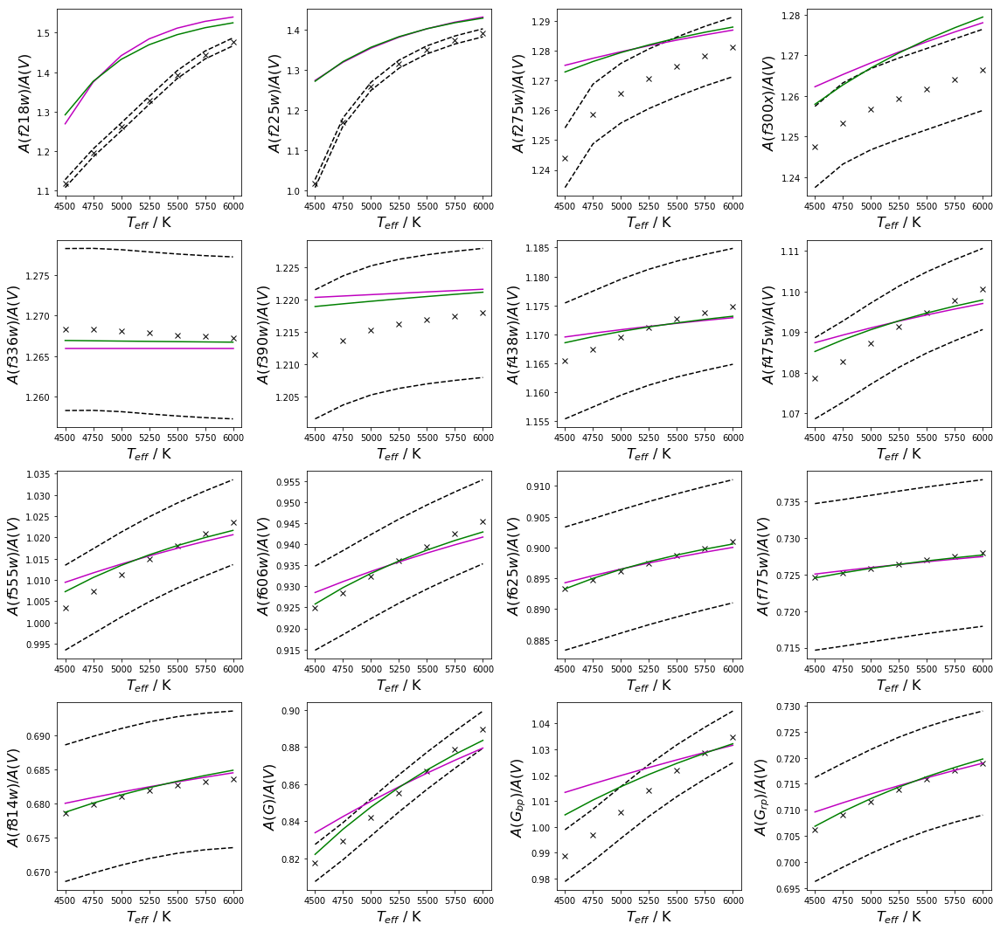


    Writing complete for log(g) = 0.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 5.0


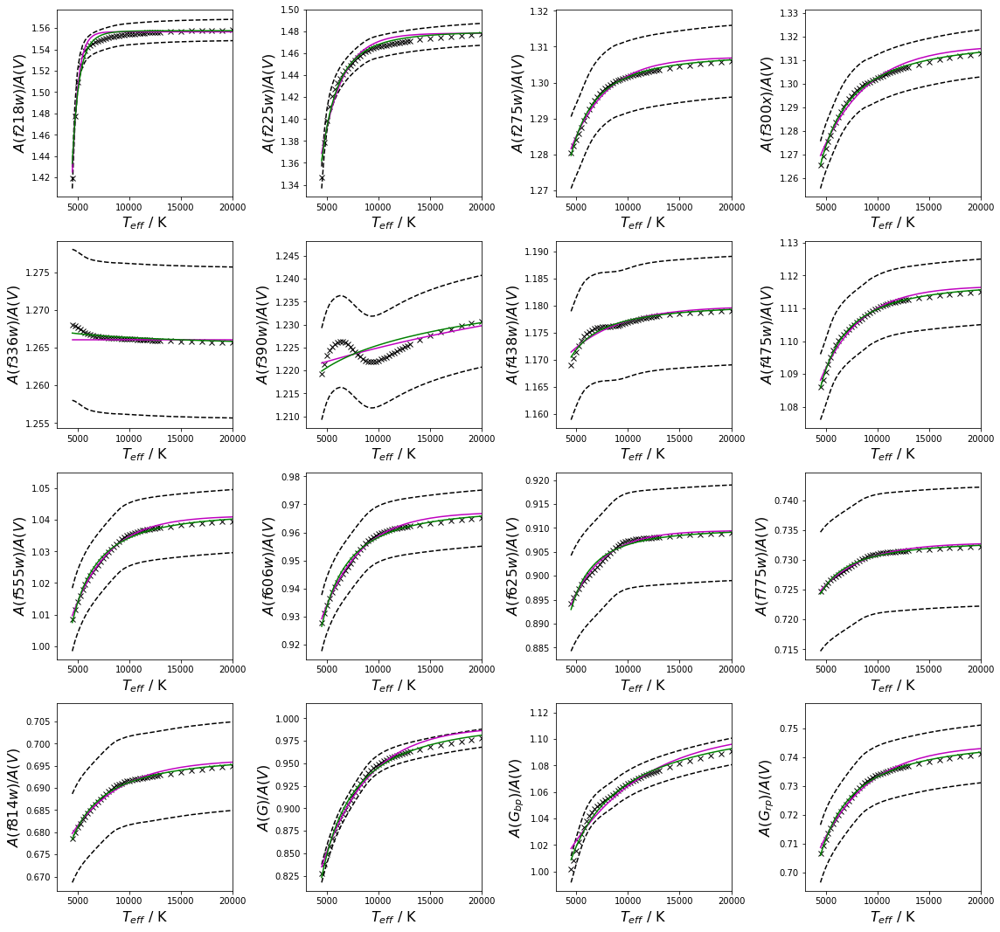


    Writing complete for log(g) = 5.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 4.5
Exponential fit coefficients (should be reused): 
[-390.4734  -17.7717    1.5566]
Standard deviations (should be reused): 
[  4.0468e+02   2.2220e+00   1.2614e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6468e-04  -7.0000e+00   1.5576e+00]
Standard deviations (should be reused): 
[  2.8921e-04   8.2092e-01   1.3231e-03]
Logistic fit coefficients: 
[  2.3359e+03   1.7980e+01   1.5566e+00  -5.0000e+00]
Standard deviations: 
[  2.0984e+04   7.1786e+00   1.2851e-03   2.3313e+02]
Teff log-normal fit coefficients: 
[ 0.      0.4646  1.545   1.527 ]
Standard deviations: 
[ 0.      0.1594  0.0015  0.0037]





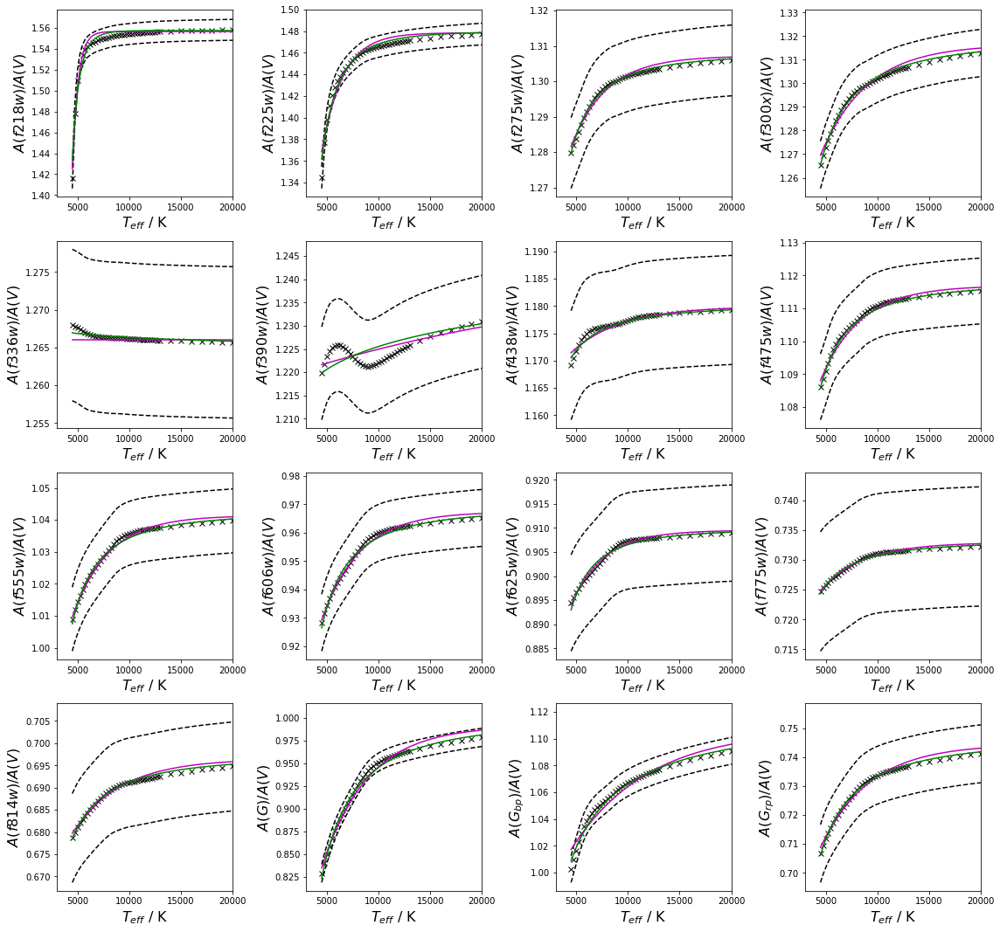


    Writing complete for log(g) = 4.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 4.0
Exponential fit coefficients (should be reused): 
[-390.4734  -17.7717    1.5566]
Standard deviations (should be reused): 
[  4.0468e+02   2.2220e+00   1.2614e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6468e-04  -7.0000e+00   1.5576e+00]
Standard deviations (should be reused): 
[  2.8921e-04   8.2092e-01   1.3231e-03]
Logistic fit coefficients: 
[  2.3359e+03   1.7980e+01   1.5566e+00  -5.0000e+00]
Standard deviations: 
[  2.0984e+04   7.1786e+00   1.2851e-03   2.3313e+02]
Teff log-normal fit coefficients: 
[ 0.      0.4646  1.545   1.527 ]
Standard deviations: 
[ 0.      0.1594  0.0015  0.0037]





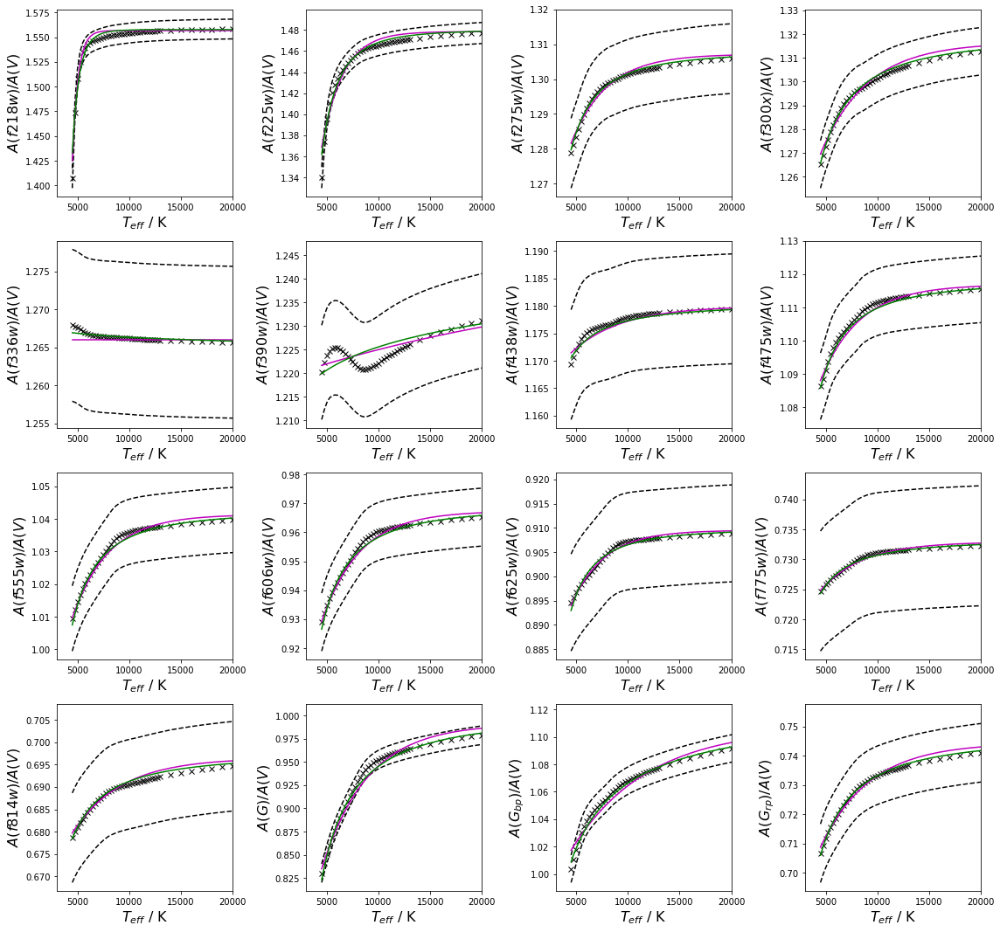


    Writing complete for log(g) = 4.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 3.5
Exponential fit coefficients (should be reused): 
[-390.4734  -17.7717    1.5566]
Standard deviations (should be reused): 
[  4.0468e+02   2.2220e+00   1.2614e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6468e-04  -7.0000e+00   1.5576e+00]
Standard deviations (should be reused): 
[  2.8921e-04   8.2092e-01   1.3231e-03]
Logistic fit coefficients: 
[  2.3359e+03   1.7980e+01   1.5566e+00  -5.0000e+00]
Standard deviations: 
[  2.0984e+04   7.1786e+00   1.2851e-03   2.3313e+02]
Teff log-normal fit coefficients: 
[ 0.      0.4646  1.545   1.527 ]
Standard deviations: 
[ 0.      0.1594  0.0015  0.0037]





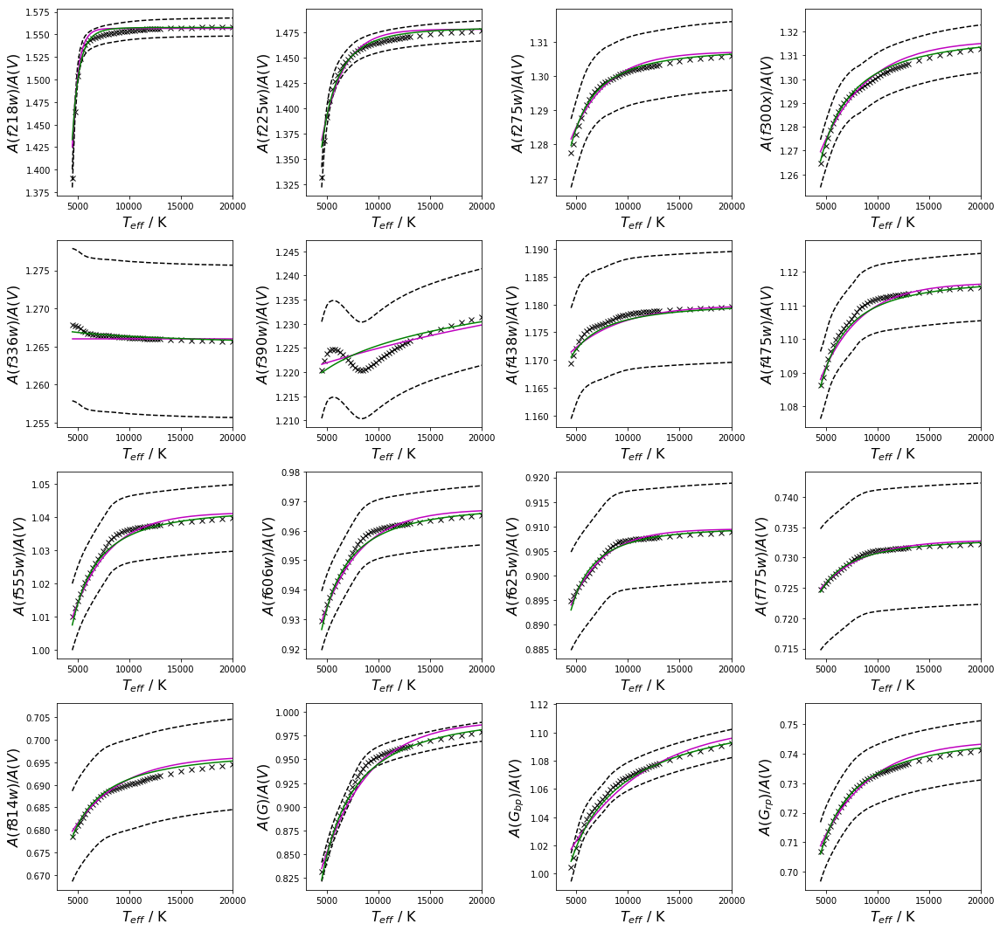


    Writing complete for log(g) = 3.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 3.0
Exponential fit coefficients (should be reused): 
[-390.4734  -17.7717    1.5566]
Standard deviations (should be reused): 
[  4.0468e+02   2.2220e+00   1.2614e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6468e-04  -7.0000e+00   1.5576e+00]
Standard deviations (should be reused): 
[  2.8921e-04   8.2092e-01   1.3231e-03]
Logistic fit coefficients: 
[  2.3359e+03   1.7980e+01   1.5566e+00  -5.0000e+00]
Standard deviations: 
[  2.0984e+04   7.1786e+00   1.2851e-03   2.3313e+02]
Teff log-normal fit coefficients: 
[ 0.      0.4646  1.545   1.527 ]
Standard deviations: 
[ 0.      0.1594  0.0015  0.0037]





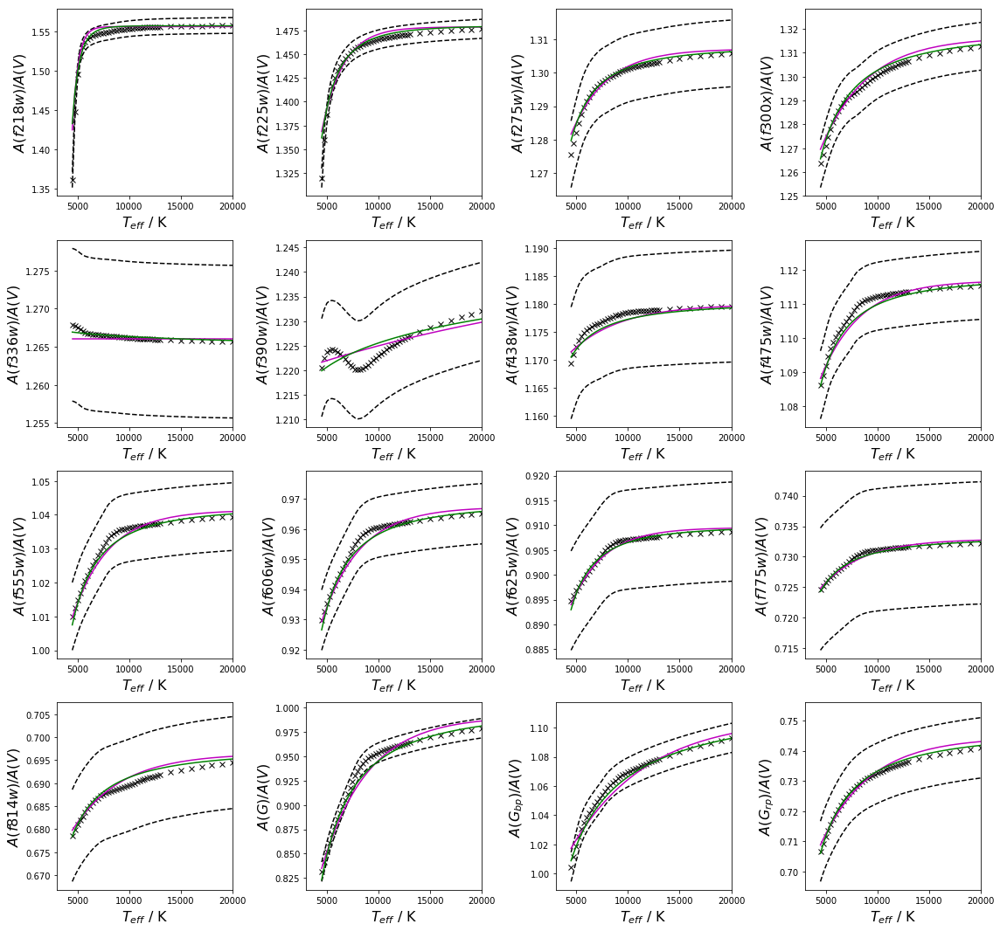


    Writing complete for log(g) = 3.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 2.5
Exponential fit coefficients (should be reused): 
[-390.4734  -17.7717    1.5566]
Standard deviations (should be reused): 
[  4.0468e+02   2.2220e+00   1.2614e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6468e-04  -7.0000e+00   1.5576e+00]
Standard deviations (should be reused): 
[  2.8921e-04   8.2092e-01   1.3231e-03]
Logistic fit coefficients: 
[  2.3359e+03   1.7980e+01   1.5566e+00  -5.0000e+00]
Standard deviations: 
[  2.0984e+04   7.1786e+00   1.2851e-03   2.3313e+02]
Teff log-normal fit coefficients: 
[ 0.      0.4646  1.545   1.527 ]
Standard deviations: 
[ 0.      0.1594  0.0015  0.0037]





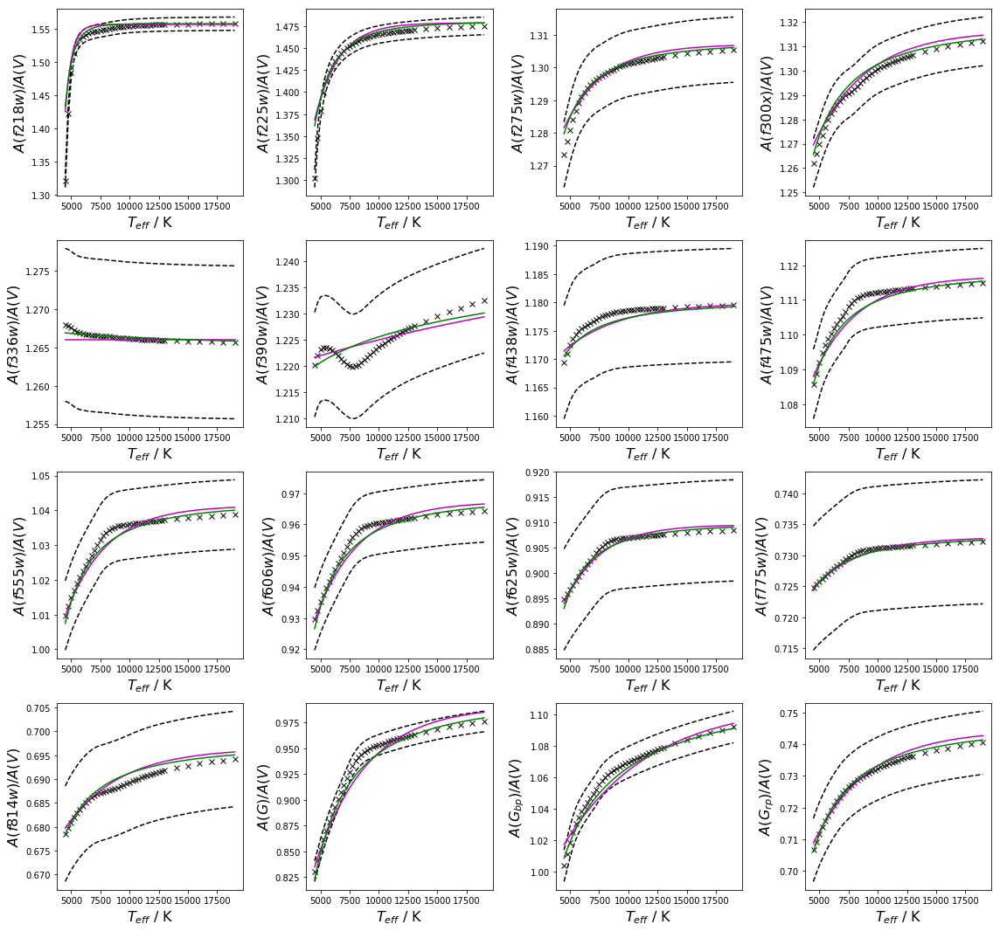


    Writing complete for log(g) = 2.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 2.0
Exponential fit coefficients (should be reused): 
[-390.4734  -17.7717    1.5566]
Standard deviations (should be reused): 
[  4.0468e+02   2.2220e+00   1.2614e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6468e-04  -7.0000e+00   1.5576e+00]
Standard deviations (should be reused): 
[  2.8921e-04   8.2092e-01   1.3231e-03]
Logistic fit coefficients: 
[  2.3359e+03   1.7980e+01   1.5566e+00  -5.0000e+00]
Standard deviations: 
[  2.0984e+04   7.1786e+00   1.2851e-03   2.3313e+02]
Teff log-normal fit coefficients: 
[ 0.      0.4646  1.545   1.527 ]
Standard deviations: 
[ 0.      0.1594  0.0015  0.0037]





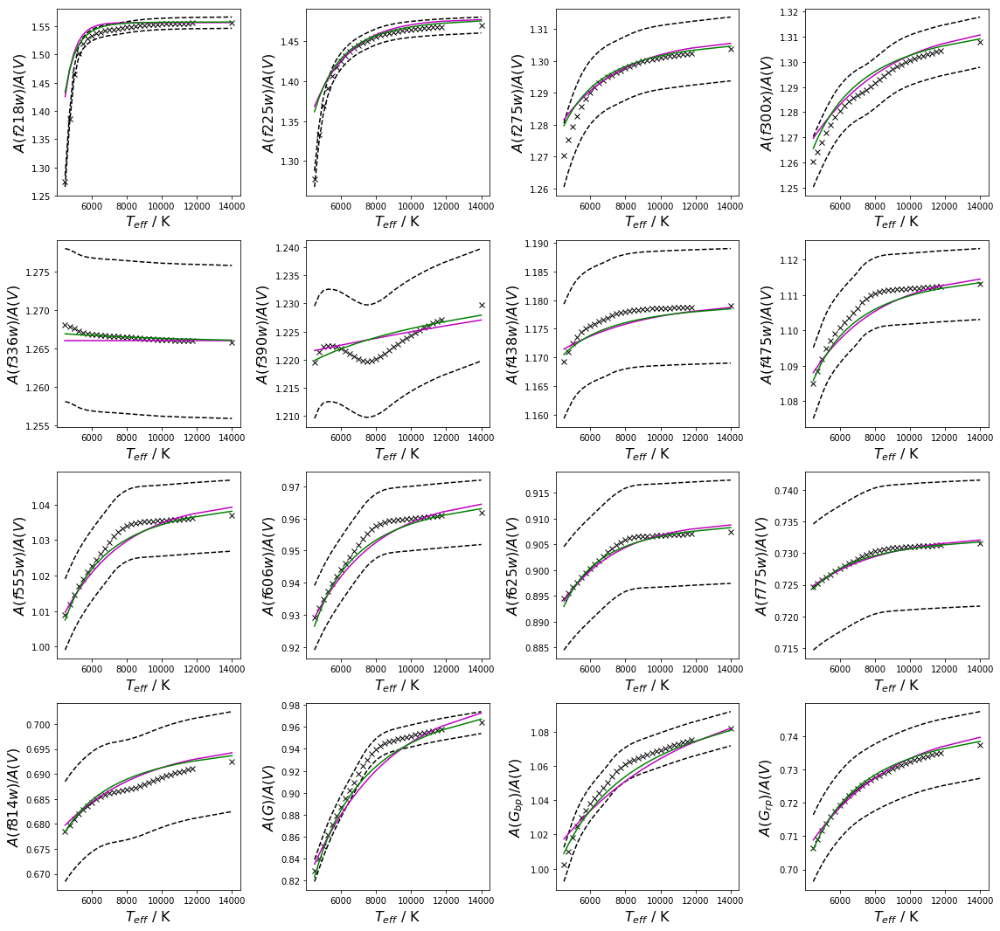


    Writing complete for log(g) = 2.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 1.5
Exponential fit coefficients (should be reused): 
[-390.4734  -17.7717    1.5566]
Standard deviations (should be reused): 
[  4.0468e+02   2.2220e+00   1.2614e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6468e-04  -7.0000e+00   1.5576e+00]
Standard deviations (should be reused): 
[  2.8921e-04   8.2092e-01   1.3231e-03]
Logistic fit coefficients: 
[  2.3359e+03   1.7980e+01   1.5566e+00  -5.0000e+00]
Standard deviations: 
[  2.0984e+04   7.1786e+00   1.2851e-03   2.3313e+02]
Teff log-normal fit coefficients: 
[ 0.      0.4646  1.545   1.527 ]
Standard deviations: 
[ 0.      0.1594  0.0015  0.0037]





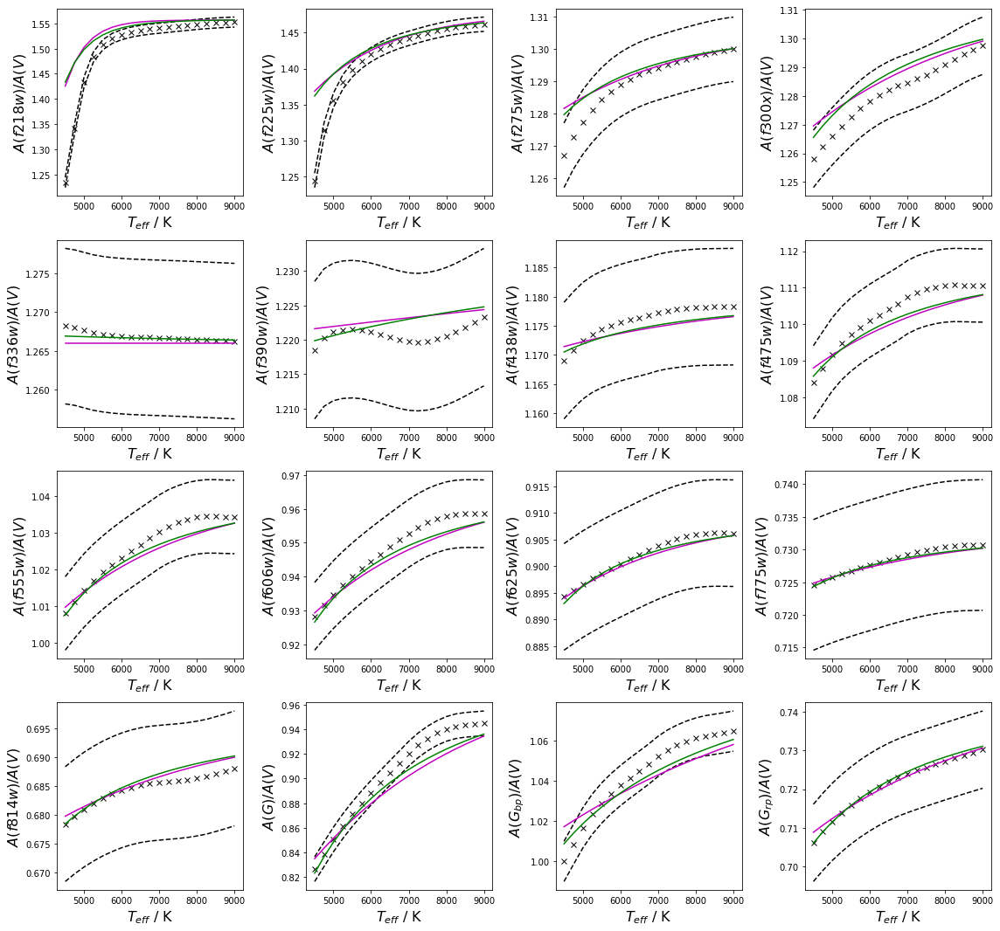


    Writing complete for log(g) = 1.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 1.0
Exponential fit coefficients (should be reused): 
[-390.4734  -17.7717    1.5566]
Standard deviations (should be reused): 
[  4.0468e+02   2.2220e+00   1.2614e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6468e-04  -7.0000e+00   1.5576e+00]
Standard deviations (should be reused): 
[  2.8921e-04   8.2092e-01   1.3231e-03]
Logistic fit coefficients: 
[  2.3359e+03   1.7980e+01   1.5566e+00  -5.0000e+00]
Standard deviations: 
[  2.0984e+04   7.1786e+00   1.2851e-03   2.3313e+02]
Teff log-normal fit coefficients: 
[ 0.      0.4646  1.545   1.527 ]
Standard deviations: 
[ 0.      0.1594  0.0015  0.0037]





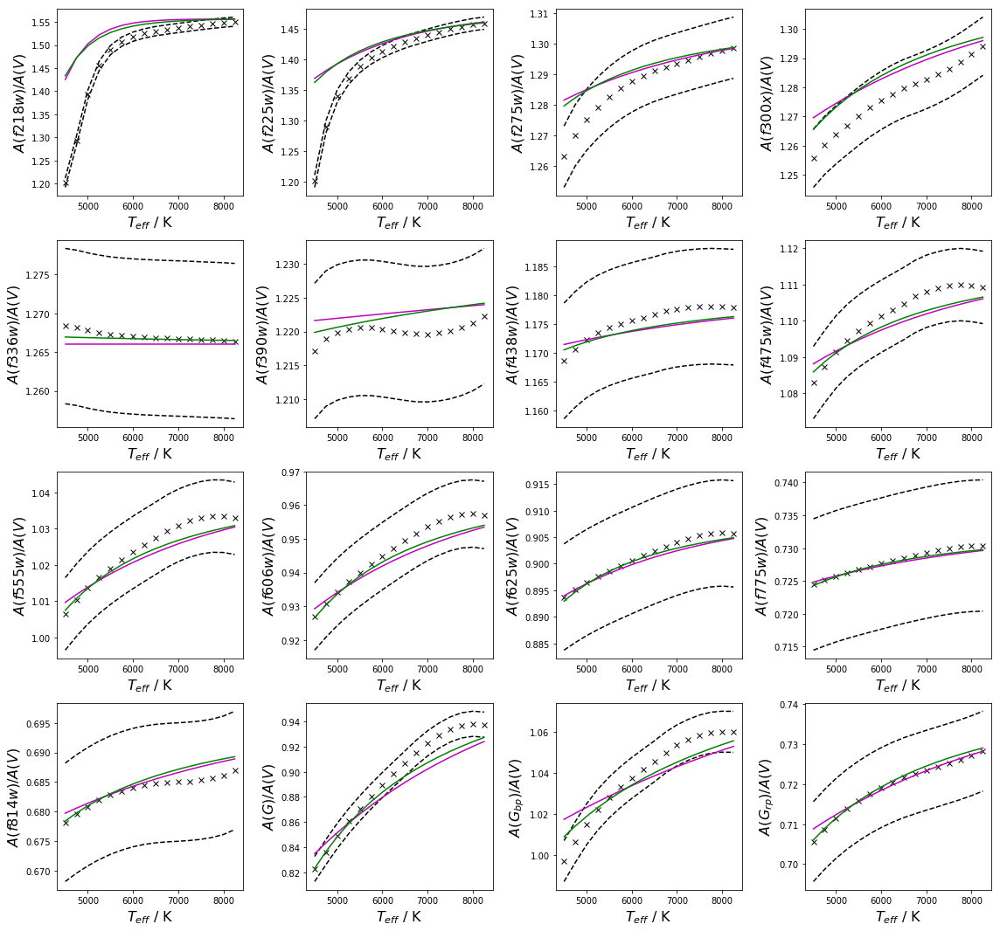


    Writing complete for log(g) = 1.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 0.5
Exponential fit coefficients (should be reused): 
[-390.4734  -17.7717    1.5566]
Standard deviations (should be reused): 
[  4.0468e+02   2.2220e+00   1.2614e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6468e-04  -7.0000e+00   1.5576e+00]
Standard deviations (should be reused): 
[  2.8921e-04   8.2092e-01   1.3231e-03]
Logistic fit coefficients: 
[  2.3359e+03   1.7980e+01   1.5566e+00  -5.0000e+00]
Standard deviations: 
[  2.0984e+04   7.1786e+00   1.2851e-03   2.3313e+02]
Teff log-normal fit coefficients: 
[ 0.      0.4646  1.545   1.527 ]
Standard deviations: 
[ 0.      0.1594  0.0015  0.0037]





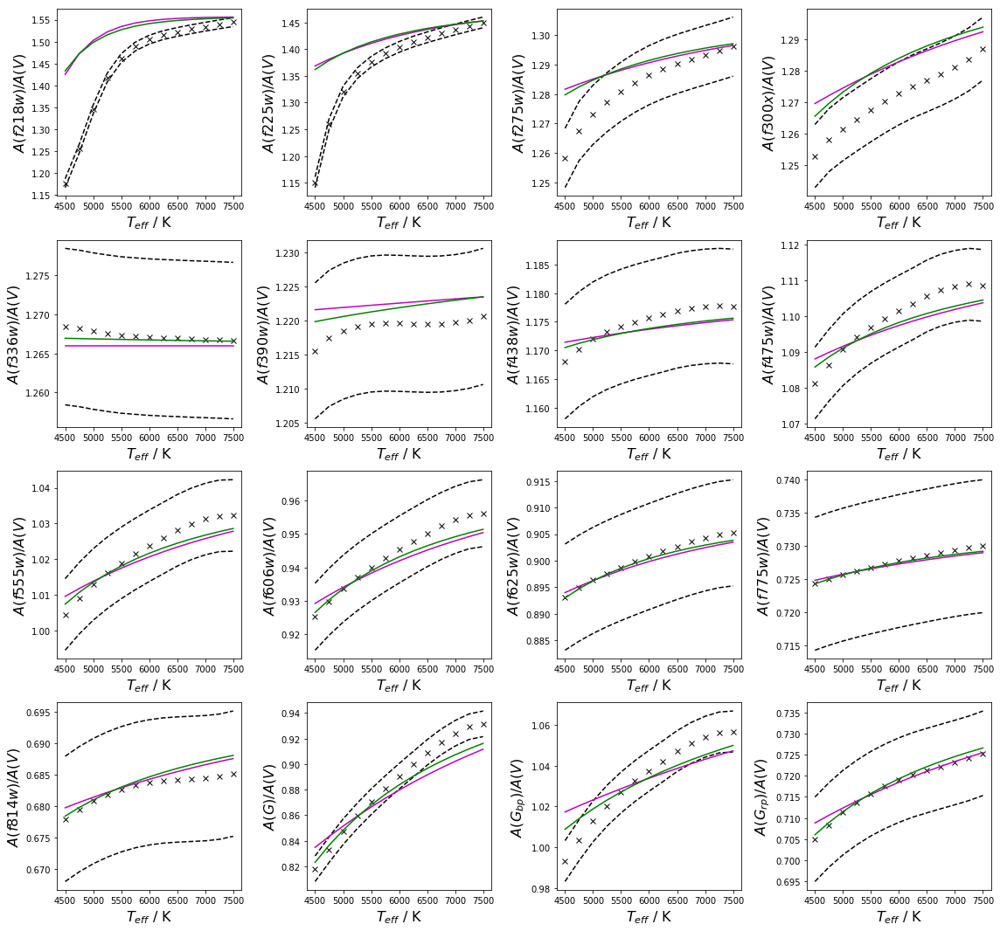


    Writing complete for log(g) = 0.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 0.0
Exponential fit coefficients (should be reused): 
[-390.4734  -17.7717    1.5566]
Standard deviations (should be reused): 
[  4.0468e+02   2.2220e+00   1.2614e-03]
Teff^(n) fit coefficients (should be reused): 
[ -4.6468e-04  -7.0000e+00   1.5576e+00]
Standard deviations (should be reused): 
[  2.8921e-04   8.2092e-01   1.3231e-03]
Logistic fit coefficients: 
[  2.3359e+03   1.7980e+01   1.5566e+00  -5.0000e+00]
Standard deviations: 
[  2.0984e+04   7.1786e+00   1.2851e-03   2.3313e+02]
Teff log-normal fit coefficients: 
[ 0.      0.4646  1.545   1.527 ]
Standard deviations: 
[ 0.      0.1594  0.0015  0.0037]





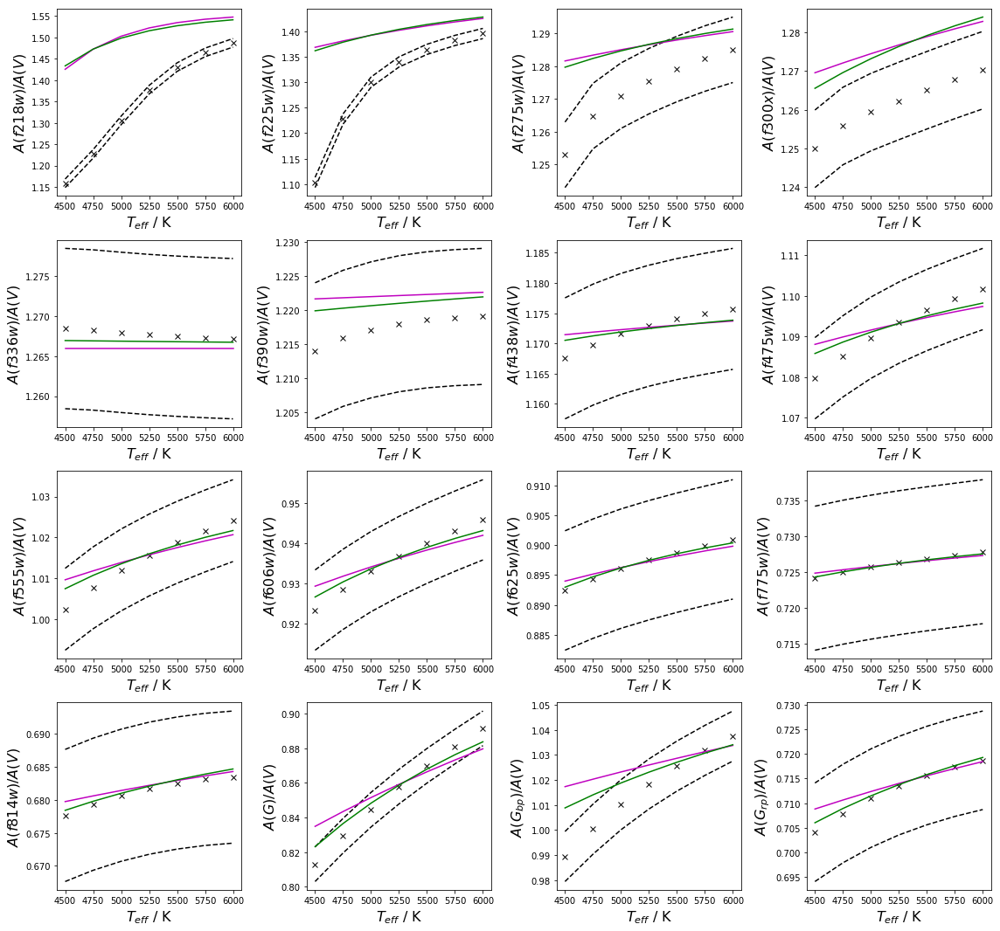


    Writing complete for log(g) = 0.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 5.0

    Writing log(g)=5.0, FeH = 0p0, Rv = 6p0 model for f218w filter
Average fractional error for Exponential function of Teff, fitted = 0.0768739332254
Average fractional error for Power law of Teff, fitted = 0.061383701072

    Writing log(g)=5.0, FeH = 0p0, Rv = 6p0 model for f225w filter
Average fractional error for Exponential function of Teff, fitted = 0.0799998809474
Average fractional error for Power law of Teff, fitted = 0.062458557071

    Writing log(g)=5.0, FeH = 0p0, Rv = 6p0 model for f275w filter
Average fractional error for Exponential function of Teff, fitted = 0.204338334545
Average fractional error for Power law of Teff, fitted = 0.178028531926

    Writing log(g)=5.0, FeH = 0p0, Rv = 6p0 model for f300x filter
Average fractional error for Exponential function of Teff, fitted = 0.110917434057
Average fractional error for Power law of Teff, fitted = 0.121714990327

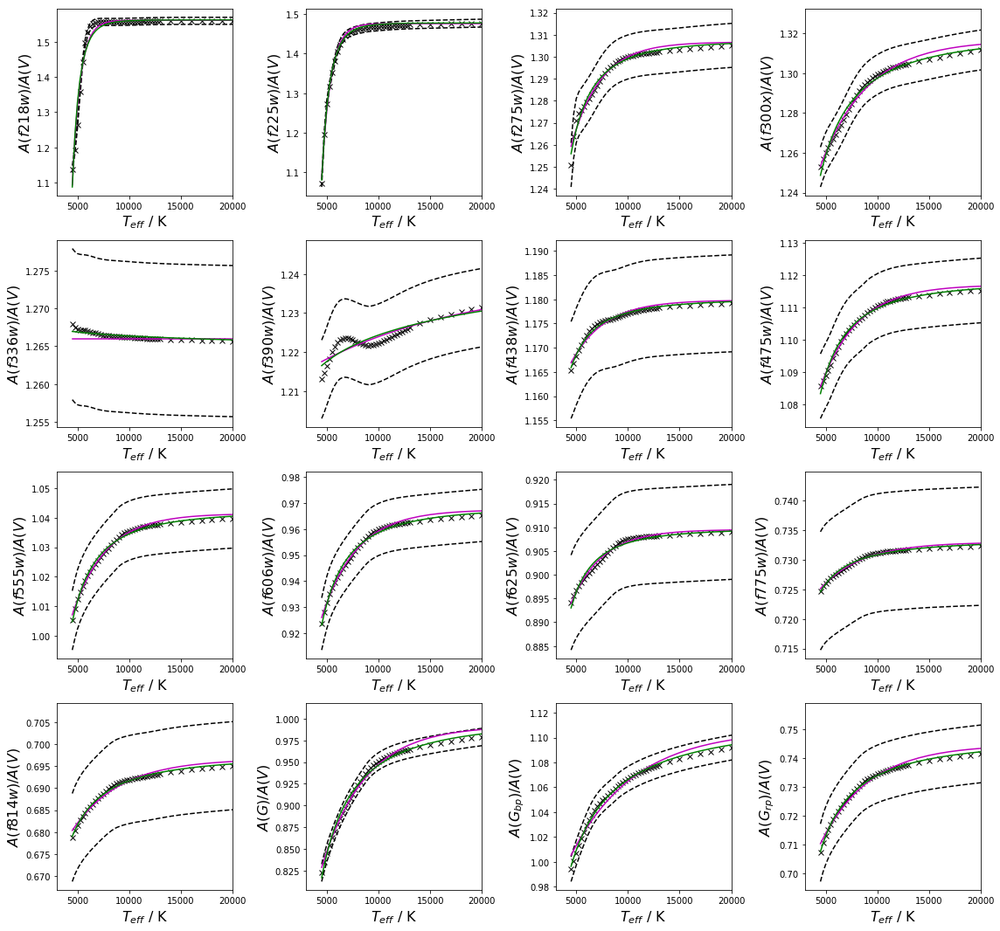


    Writing complete for log(g) = 5.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 4.5
Exponential fit coefficients (should be reused): 
[-171.361   -13.1233    1.5605]
Standard deviations (should be reused): 
[  3.3933e+01   4.1695e-01   1.2942e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.2632e-03  -6.6929e+00   1.5616e+00]
Standard deviations (should be reused): 
[ 0.0003  0.2025  0.0013]
Logistic fit coefficients: 
[  5.1541e+03   3.1749e+01   1.5584e+00   1.0864e+00]
Standard deviations: 
[  4.1901e+01   2.4925e+00   1.2550e-03   2.2123e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4593  1.5154  1.455 ]
Standard deviations: 
[ 0.      0.0468  0.0015  0.0037]





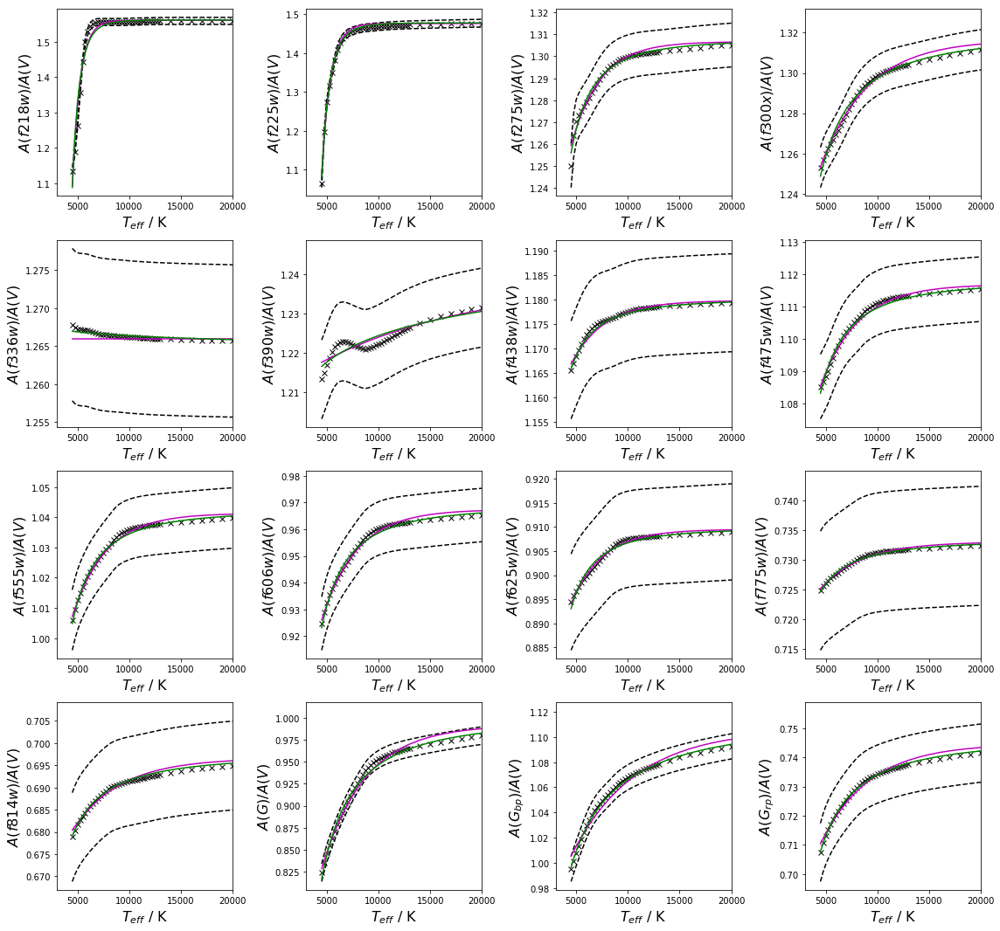


    Writing complete for log(g) = 4.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 4.0
Exponential fit coefficients (should be reused): 
[-171.361   -13.1233    1.5605]
Standard deviations (should be reused): 
[  3.3933e+01   4.1695e-01   1.2942e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.2632e-03  -6.6929e+00   1.5616e+00]
Standard deviations (should be reused): 
[ 0.0003  0.2025  0.0013]
Logistic fit coefficients: 
[  5.1541e+03   3.1749e+01   1.5584e+00   1.0864e+00]
Standard deviations: 
[  4.1901e+01   2.4925e+00   1.2550e-03   2.2123e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4593  1.5154  1.455 ]
Standard deviations: 
[ 0.      0.0468  0.0015  0.0037]





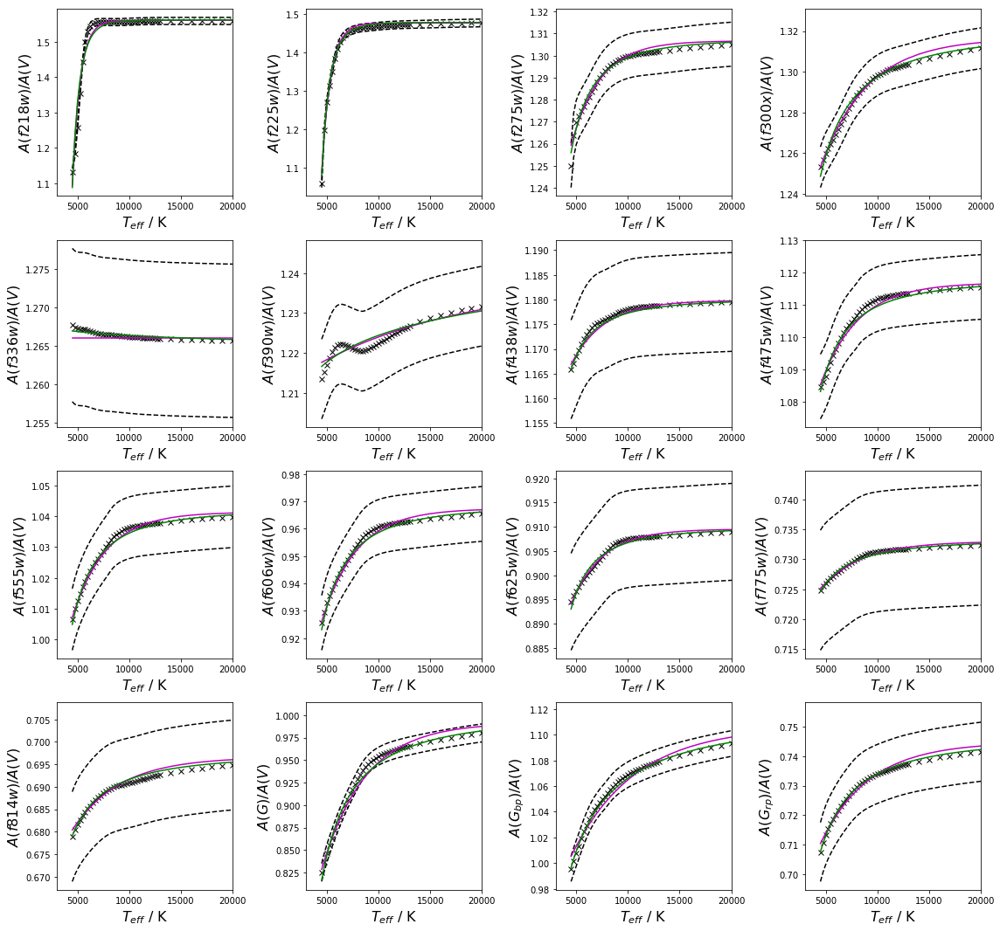


    Writing complete for log(g) = 4.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 3.5
Exponential fit coefficients (should be reused): 
[-171.361   -13.1233    1.5605]
Standard deviations (should be reused): 
[  3.3933e+01   4.1695e-01   1.2942e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.2632e-03  -6.6929e+00   1.5616e+00]
Standard deviations (should be reused): 
[ 0.0003  0.2025  0.0013]
Logistic fit coefficients: 
[  5.1541e+03   3.1749e+01   1.5584e+00   1.0864e+00]
Standard deviations: 
[  4.1901e+01   2.4925e+00   1.2550e-03   2.2123e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4593  1.5154  1.455 ]
Standard deviations: 
[ 0.      0.0468  0.0015  0.0037]





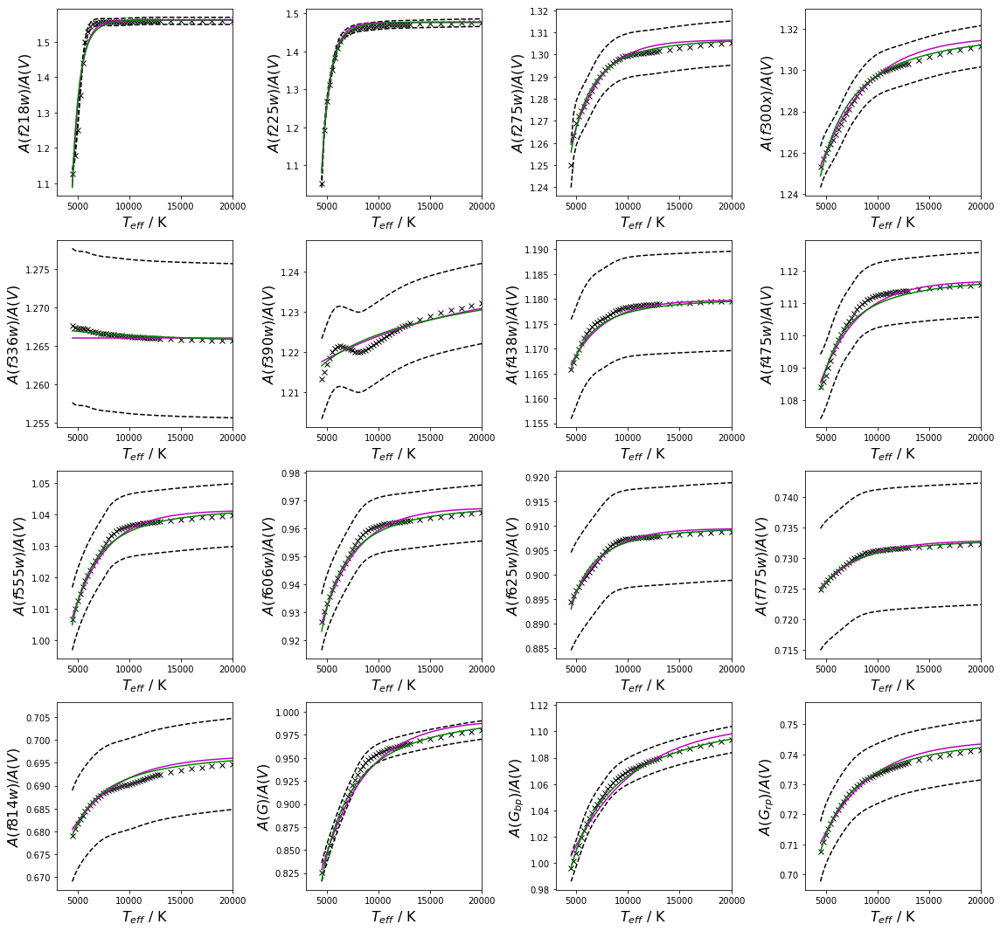


    Writing complete for log(g) = 3.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 3.0
Exponential fit coefficients (should be reused): 
[-171.361   -13.1233    1.5605]
Standard deviations (should be reused): 
[  3.3933e+01   4.1695e-01   1.2942e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.2632e-03  -6.6929e+00   1.5616e+00]
Standard deviations (should be reused): 
[ 0.0003  0.2025  0.0013]
Logistic fit coefficients: 
[  5.1541e+03   3.1749e+01   1.5584e+00   1.0864e+00]
Standard deviations: 
[  4.1901e+01   2.4925e+00   1.2550e-03   2.2123e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4593  1.5154  1.455 ]
Standard deviations: 
[ 0.      0.0468  0.0015  0.0037]





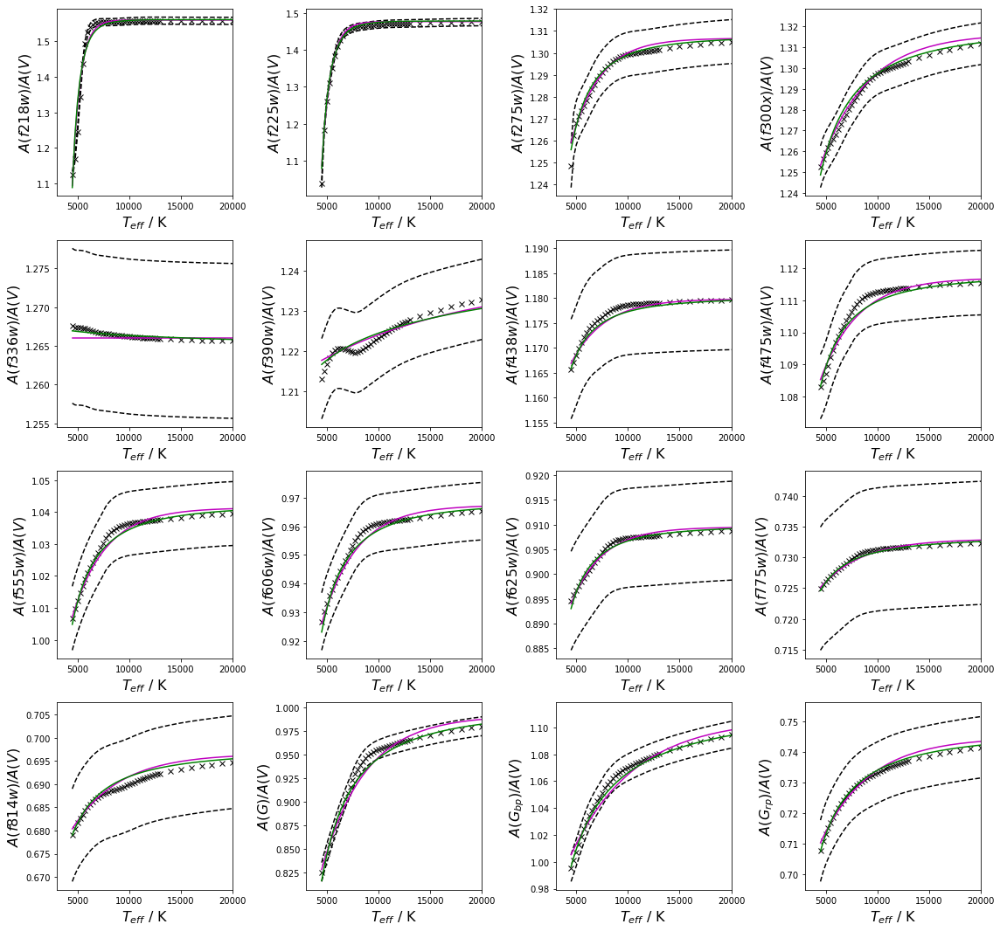


    Writing complete for log(g) = 3.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 2.5
Exponential fit coefficients (should be reused): 
[-171.361   -13.1233    1.5605]
Standard deviations (should be reused): 
[  3.3933e+01   4.1695e-01   1.2942e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.2632e-03  -6.6929e+00   1.5616e+00]
Standard deviations (should be reused): 
[ 0.0003  0.2025  0.0013]
Logistic fit coefficients: 
[  5.1541e+03   3.1749e+01   1.5584e+00   1.0864e+00]
Standard deviations: 
[  4.1901e+01   2.4925e+00   1.2550e-03   2.2123e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4593  1.5154  1.455 ]
Standard deviations: 
[ 0.      0.0468  0.0015  0.0037]





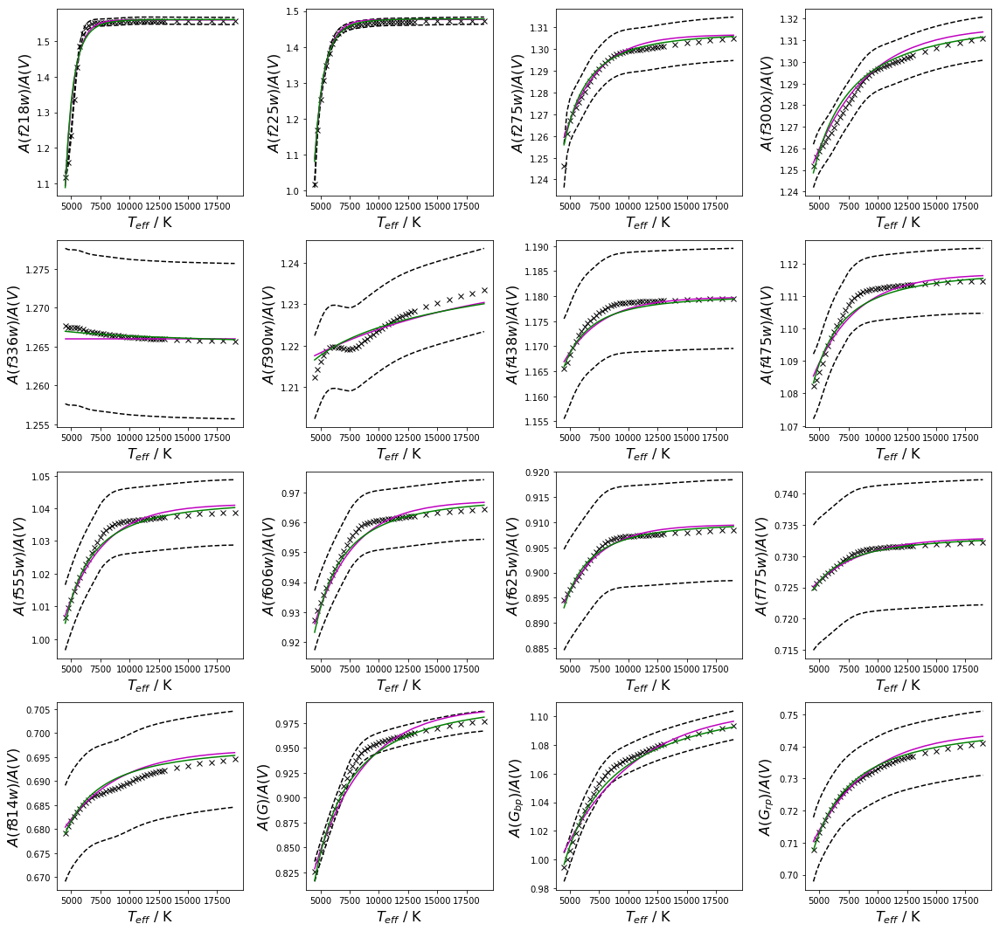


    Writing complete for log(g) = 2.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 2.0
Exponential fit coefficients (should be reused): 
[-171.361   -13.1233    1.5605]
Standard deviations (should be reused): 
[  3.3933e+01   4.1695e-01   1.2942e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.2632e-03  -6.6929e+00   1.5616e+00]
Standard deviations (should be reused): 
[ 0.0003  0.2025  0.0013]
Logistic fit coefficients: 
[  5.1541e+03   3.1749e+01   1.5584e+00   1.0864e+00]
Standard deviations: 
[  4.1901e+01   2.4925e+00   1.2550e-03   2.2123e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4593  1.5154  1.455 ]
Standard deviations: 
[ 0.      0.0468  0.0015  0.0037]





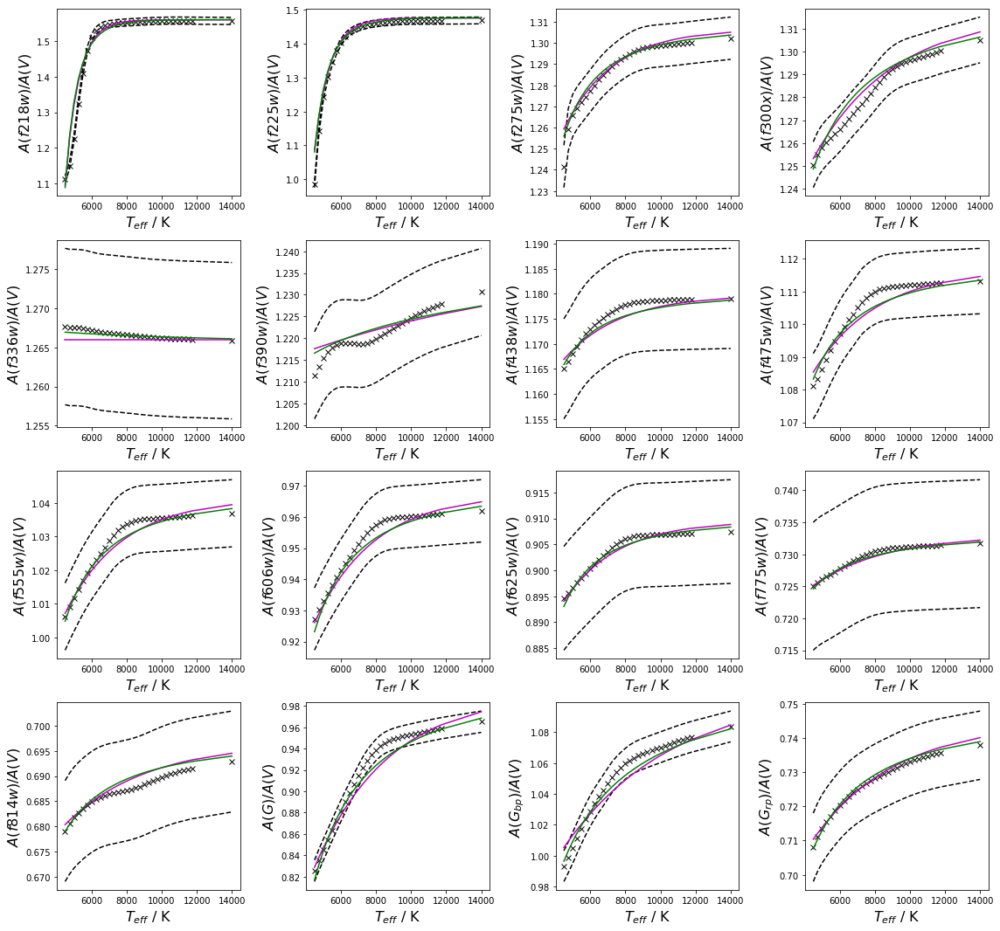


    Writing complete for log(g) = 2.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 1.5
Exponential fit coefficients (should be reused): 
[-171.361   -13.1233    1.5605]
Standard deviations (should be reused): 
[  3.3933e+01   4.1695e-01   1.2942e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.2632e-03  -6.6929e+00   1.5616e+00]
Standard deviations (should be reused): 
[ 0.0003  0.2025  0.0013]
Logistic fit coefficients: 
[  5.1541e+03   3.1749e+01   1.5584e+00   1.0864e+00]
Standard deviations: 
[  4.1901e+01   2.4925e+00   1.2550e-03   2.2123e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4593  1.5154  1.455 ]
Standard deviations: 
[ 0.      0.0468  0.0015  0.0037]





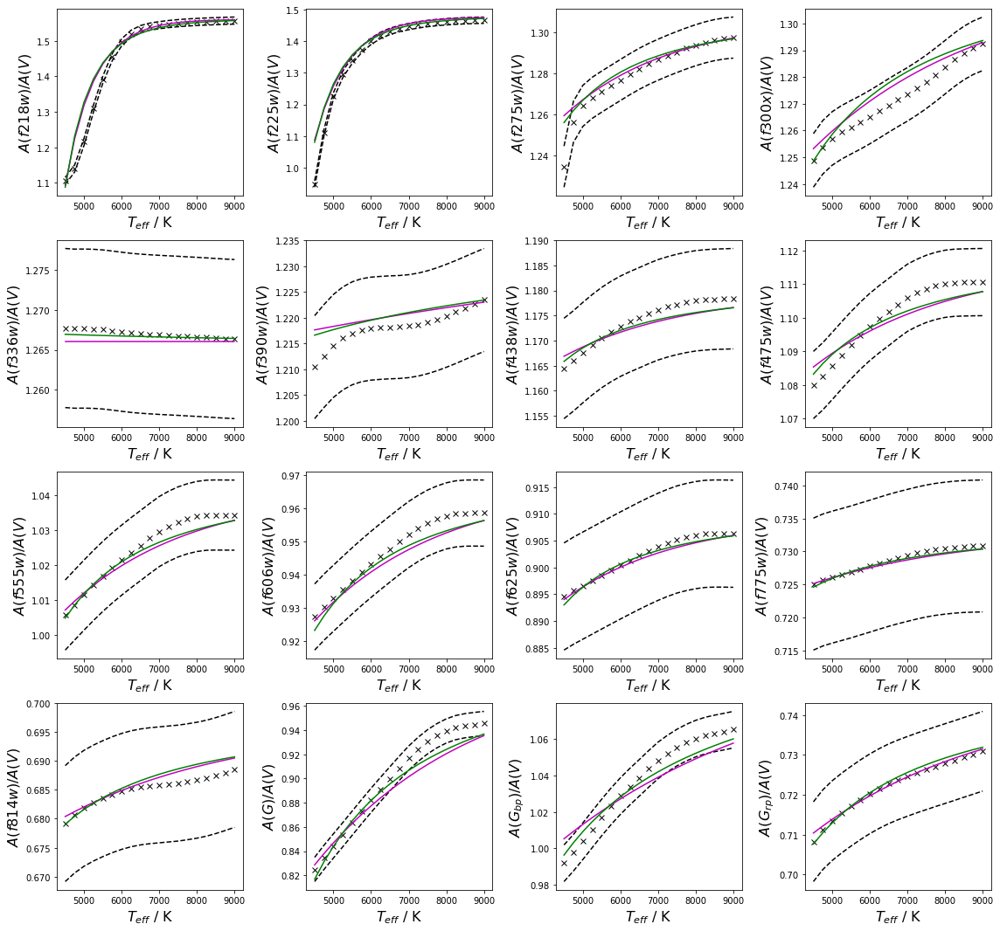


    Writing complete for log(g) = 1.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 1.0
Exponential fit coefficients (should be reused): 
[-171.361   -13.1233    1.5605]
Standard deviations (should be reused): 
[  3.3933e+01   4.1695e-01   1.2942e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.2632e-03  -6.6929e+00   1.5616e+00]
Standard deviations (should be reused): 
[ 0.0003  0.2025  0.0013]
Logistic fit coefficients: 
[  5.1541e+03   3.1749e+01   1.5584e+00   1.0864e+00]
Standard deviations: 
[  4.1901e+01   2.4925e+00   1.2550e-03   2.2123e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4593  1.5154  1.455 ]
Standard deviations: 
[ 0.      0.0468  0.0015  0.0037]





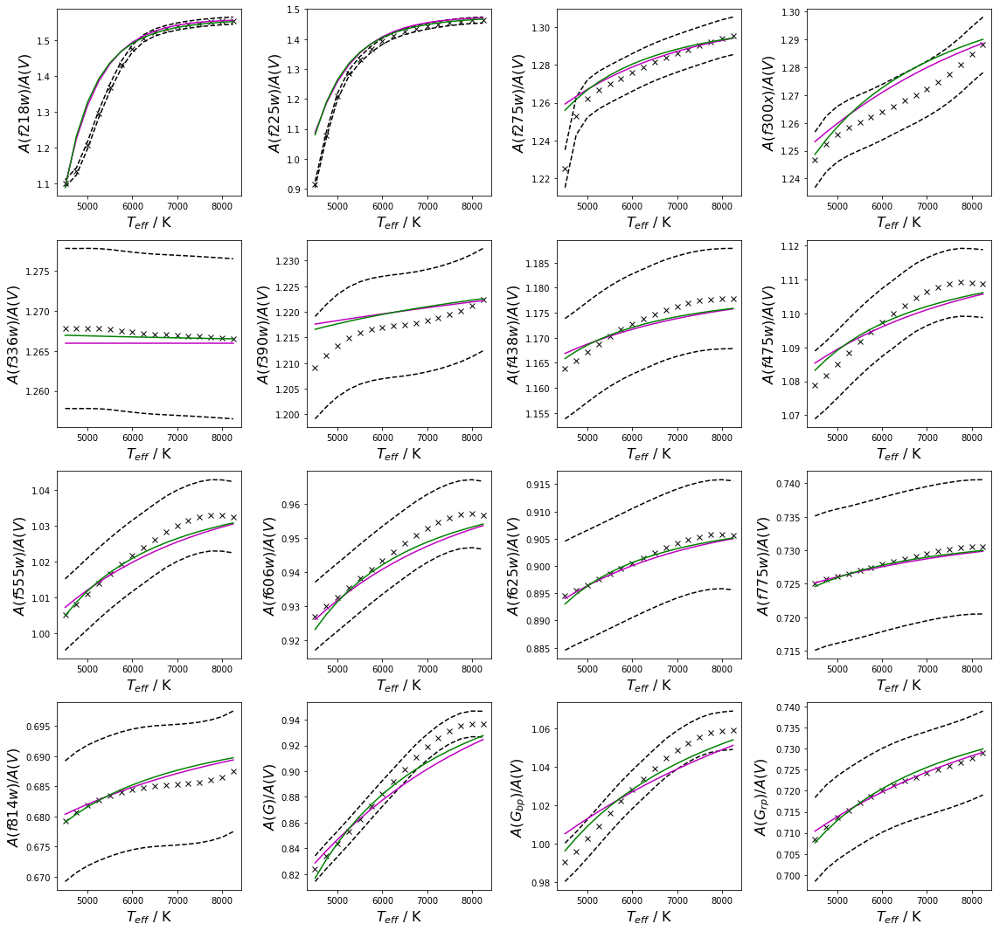


    Writing complete for log(g) = 1.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 0.5
Exponential fit coefficients (should be reused): 
[-171.361   -13.1233    1.5605]
Standard deviations (should be reused): 
[  3.3933e+01   4.1695e-01   1.2942e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.2632e-03  -6.6929e+00   1.5616e+00]
Standard deviations (should be reused): 
[ 0.0003  0.2025  0.0013]
Logistic fit coefficients: 
[  5.1541e+03   3.1749e+01   1.5584e+00   1.0864e+00]
Standard deviations: 
[  4.1901e+01   2.4925e+00   1.2550e-03   2.2123e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4593  1.5154  1.455 ]
Standard deviations: 
[ 0.      0.0468  0.0015  0.0037]





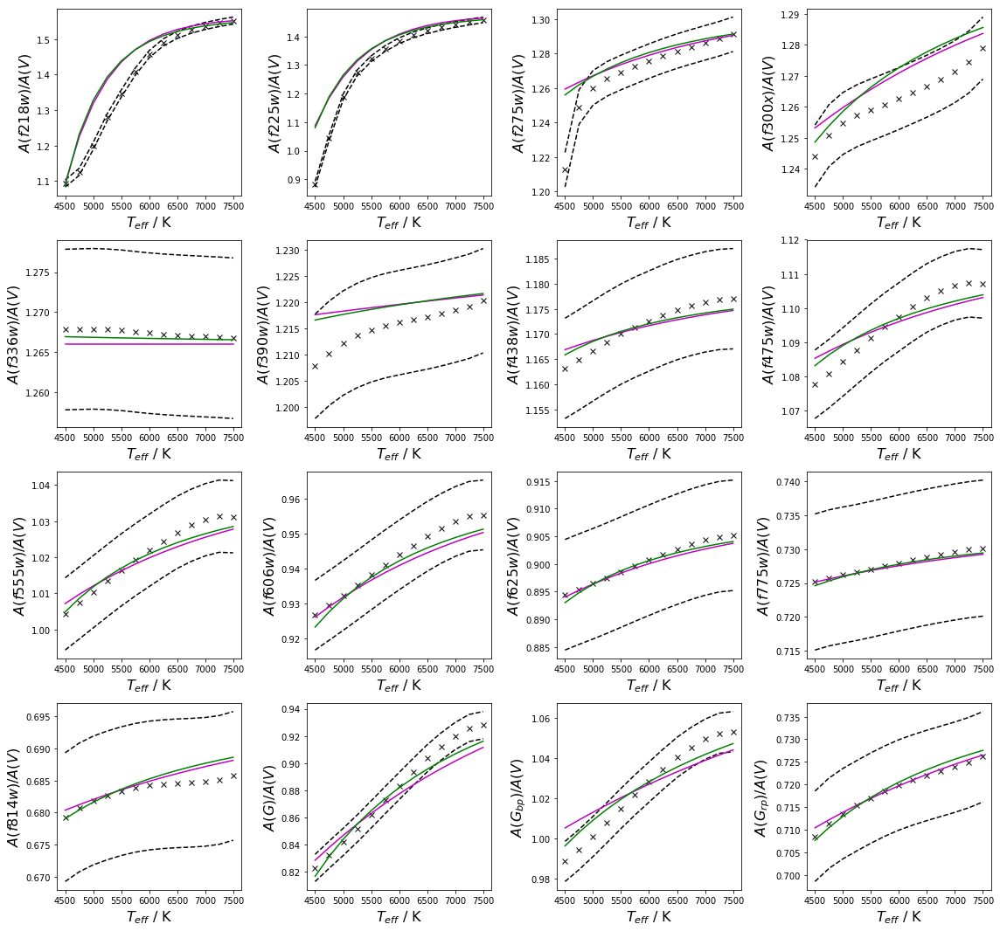


    Writing complete for log(g) = 0.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 0.0
Exponential fit coefficients (should be reused): 
[-171.361   -13.1233    1.5605]
Standard deviations (should be reused): 
[  3.3933e+01   4.1695e-01   1.2942e-03]
Teff^(n) fit coefficients (should be reused): 
[ -2.2632e-03  -6.6929e+00   1.5616e+00]
Standard deviations (should be reused): 
[ 0.0003  0.2025  0.0013]
Logistic fit coefficients: 
[  5.1541e+03   3.1749e+01   1.5584e+00   1.0864e+00]
Standard deviations: 
[  4.1901e+01   2.4925e+00   1.2550e-03   2.2123e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4593  1.5154  1.455 ]
Standard deviations: 
[ 0.      0.0468  0.0015  0.0037]





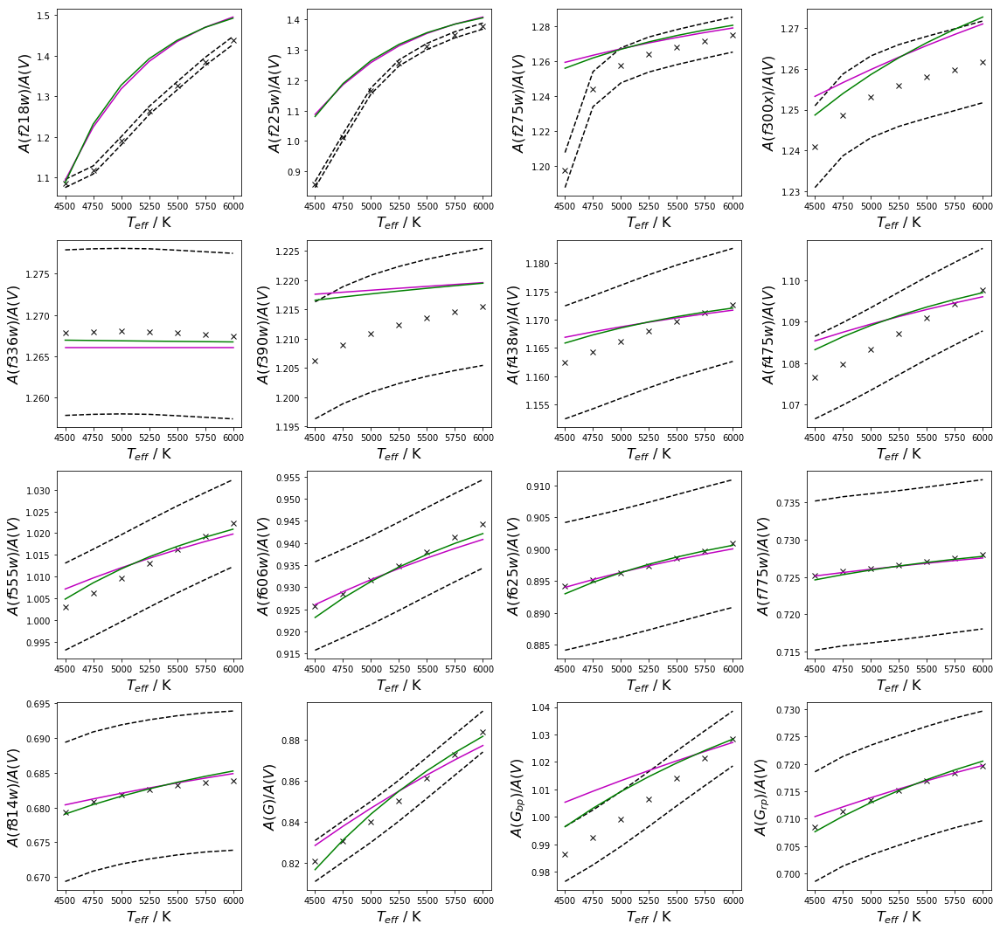


    Writing complete for log(g) = 0.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 5.0


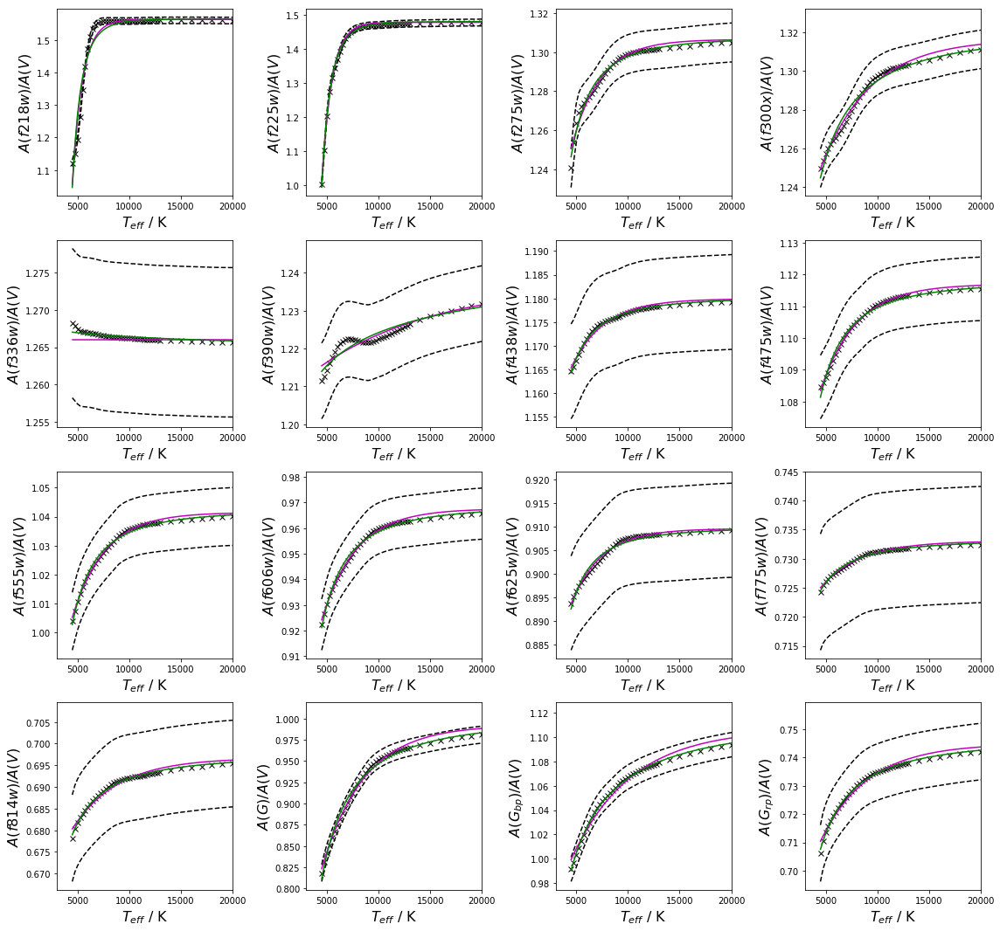


    Writing complete for log(g) = 5.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 4.5
Exponential fit coefficients (should be reused): 
[-46.5132 -10.0448   1.5626]
Standard deviations (should be reused): 
[  6.0688e+00   2.6922e-01   1.3360e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0075 -5.3093  1.5646]
Standard deviations (should be reused): 
[ 0.0007  0.1346  0.0014]
Logistic fit coefficients: 
[  5.4333e+03   2.6930e+01   1.5594e+00   1.0846e+00]
Standard deviations: 
[  3.7310e+01   1.7588e+00   1.2746e-03   1.5797e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4312  1.5028  1.4254]
Standard deviations: 
[ 0.      0.034   0.0015  0.0036]





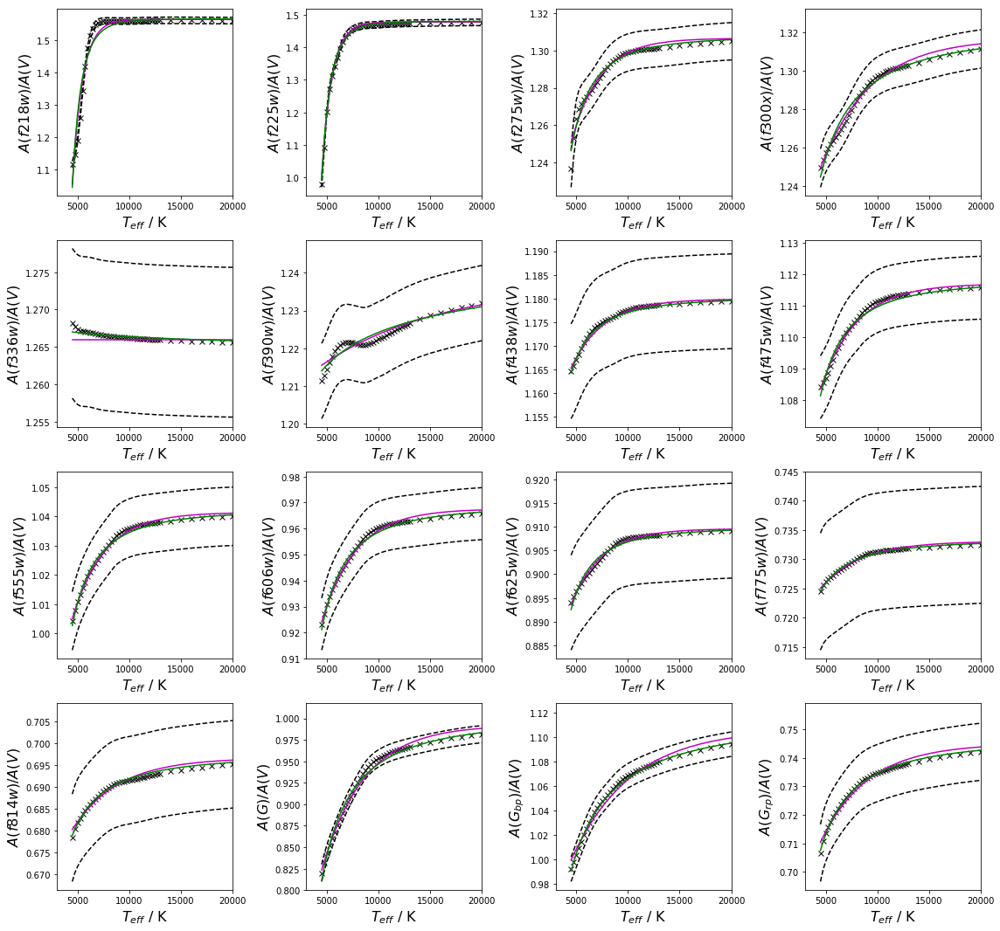


    Writing complete for log(g) = 4.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 4.0
Exponential fit coefficients (should be reused): 
[-46.5132 -10.0448   1.5626]
Standard deviations (should be reused): 
[  6.0688e+00   2.6922e-01   1.3360e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0075 -5.3093  1.5646]
Standard deviations (should be reused): 
[ 0.0007  0.1346  0.0014]
Logistic fit coefficients: 
[  5.4333e+03   2.6930e+01   1.5594e+00   1.0846e+00]
Standard deviations: 
[  3.7310e+01   1.7588e+00   1.2746e-03   1.5797e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4312  1.5028  1.4254]
Standard deviations: 
[ 0.      0.034   0.0015  0.0036]





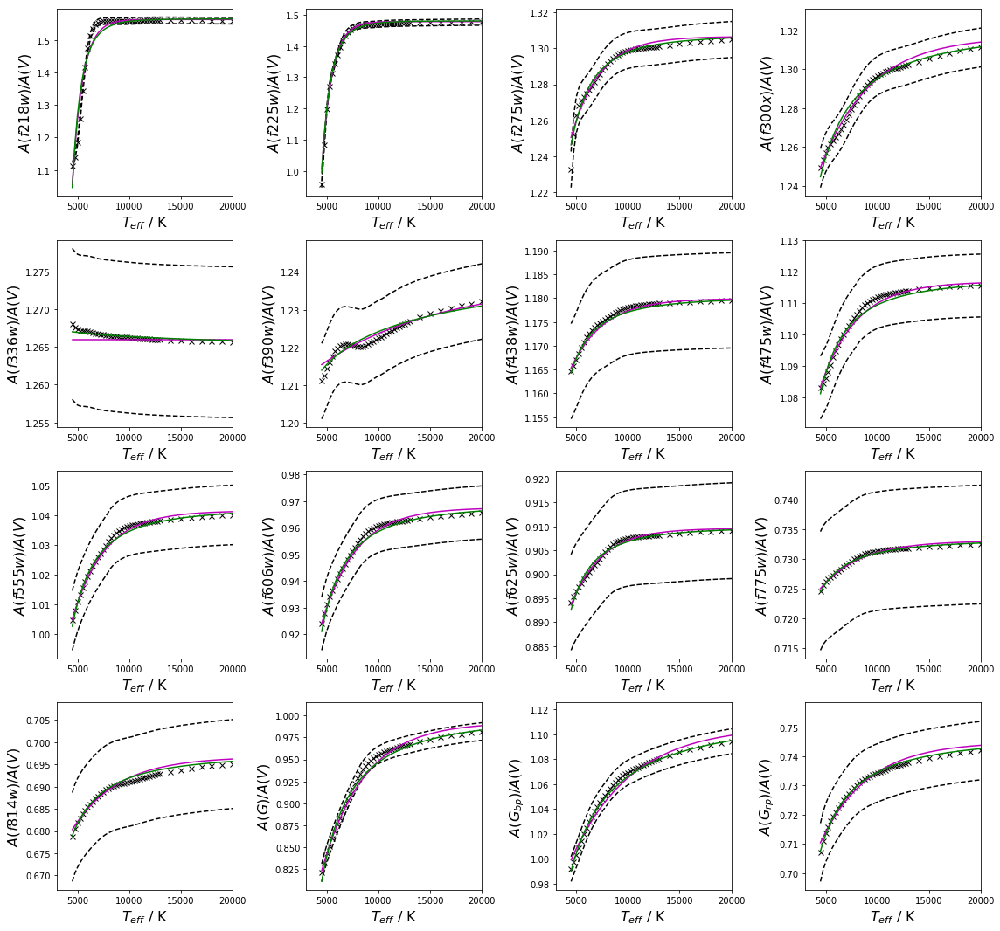


    Writing complete for log(g) = 4.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 3.5
Exponential fit coefficients (should be reused): 
[-46.5132 -10.0448   1.5626]
Standard deviations (should be reused): 
[  6.0688e+00   2.6922e-01   1.3360e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0075 -5.3093  1.5646]
Standard deviations (should be reused): 
[ 0.0007  0.1346  0.0014]
Logistic fit coefficients: 
[  5.4333e+03   2.6930e+01   1.5594e+00   1.0846e+00]
Standard deviations: 
[  3.7310e+01   1.7588e+00   1.2746e-03   1.5797e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4312  1.5028  1.4254]
Standard deviations: 
[ 0.      0.034   0.0015  0.0036]





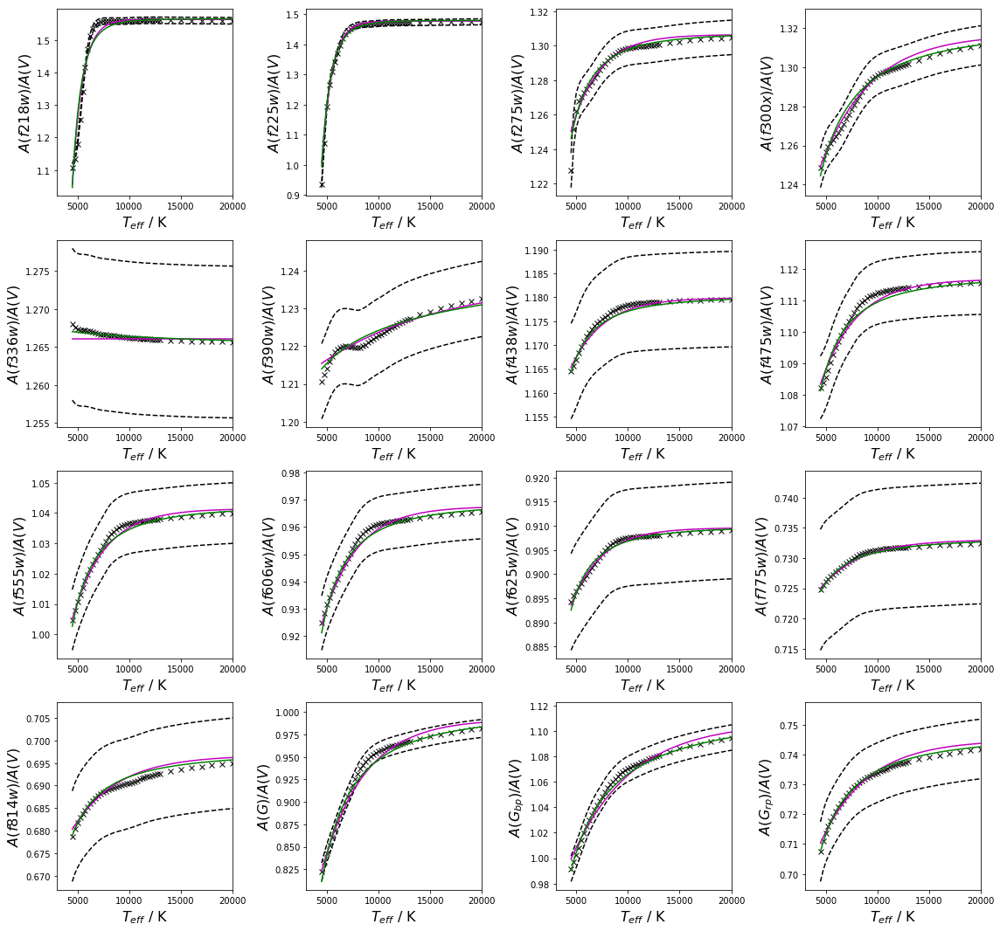


    Writing complete for log(g) = 3.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 3.0
Exponential fit coefficients (should be reused): 
[-46.5132 -10.0448   1.5626]
Standard deviations (should be reused): 
[  6.0688e+00   2.6922e-01   1.3360e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0075 -5.3093  1.5646]
Standard deviations (should be reused): 
[ 0.0007  0.1346  0.0014]
Logistic fit coefficients: 
[  5.4333e+03   2.6930e+01   1.5594e+00   1.0846e+00]
Standard deviations: 
[  3.7310e+01   1.7588e+00   1.2746e-03   1.5797e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4312  1.5028  1.4254]
Standard deviations: 
[ 0.      0.034   0.0015  0.0036]





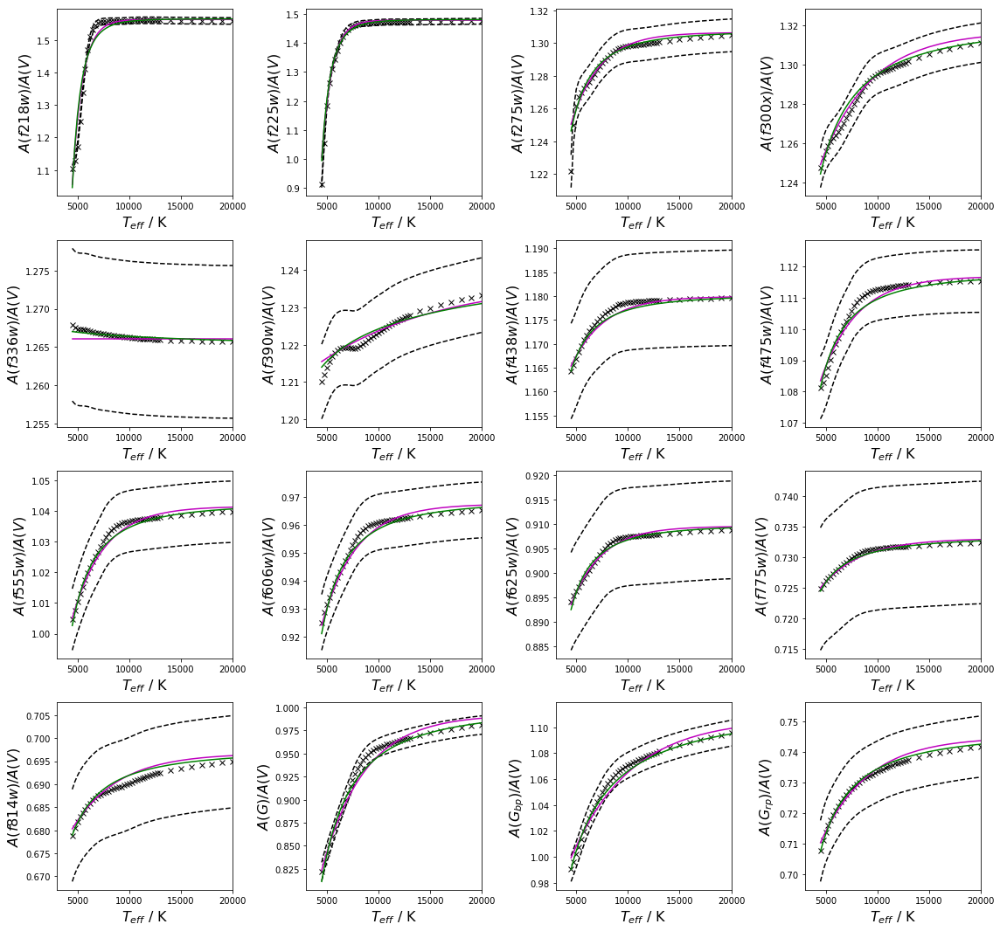


    Writing complete for log(g) = 3.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 2.5
Exponential fit coefficients (should be reused): 
[-46.5132 -10.0448   1.5626]
Standard deviations (should be reused): 
[  6.0688e+00   2.6922e-01   1.3360e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0075 -5.3093  1.5646]
Standard deviations (should be reused): 
[ 0.0007  0.1346  0.0014]
Logistic fit coefficients: 
[  5.4333e+03   2.6930e+01   1.5594e+00   1.0846e+00]
Standard deviations: 
[  3.7310e+01   1.7588e+00   1.2746e-03   1.5797e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4312  1.5028  1.4254]
Standard deviations: 
[ 0.      0.034   0.0015  0.0036]





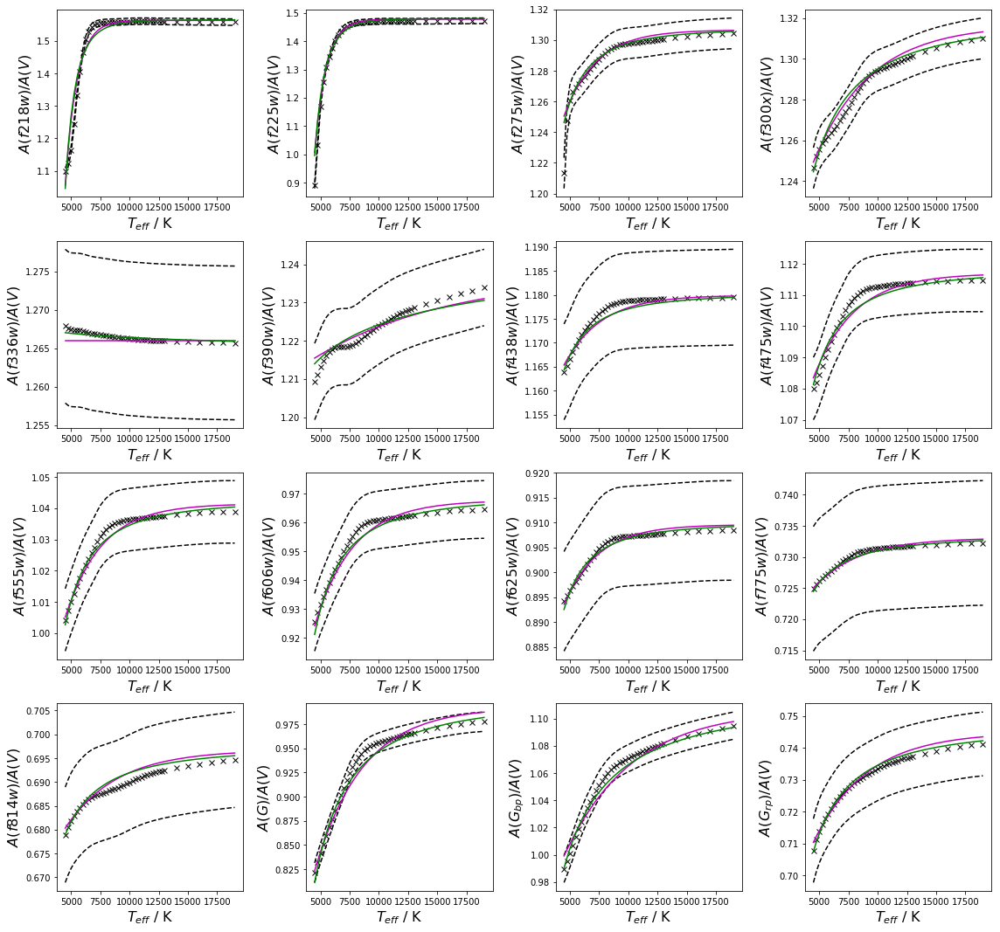


    Writing complete for log(g) = 2.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 2.0
Exponential fit coefficients (should be reused): 
[-46.5132 -10.0448   1.5626]
Standard deviations (should be reused): 
[  6.0688e+00   2.6922e-01   1.3360e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0075 -5.3093  1.5646]
Standard deviations (should be reused): 
[ 0.0007  0.1346  0.0014]
Logistic fit coefficients: 
[  5.4333e+03   2.6930e+01   1.5594e+00   1.0846e+00]
Standard deviations: 
[  3.7310e+01   1.7588e+00   1.2746e-03   1.5797e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4312  1.5028  1.4254]
Standard deviations: 
[ 0.      0.034   0.0015  0.0036]





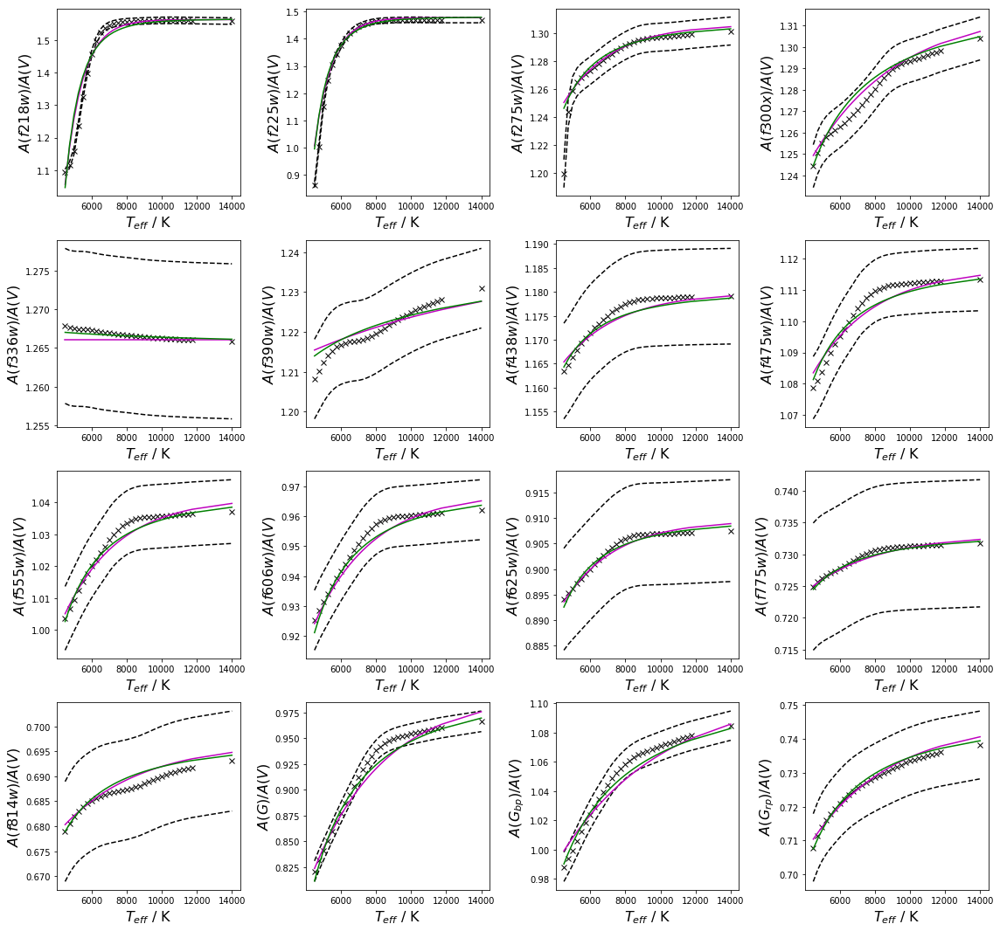


    Writing complete for log(g) = 2.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 1.5
Exponential fit coefficients (should be reused): 
[-46.5132 -10.0448   1.5626]
Standard deviations (should be reused): 
[  6.0688e+00   2.6922e-01   1.3360e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0075 -5.3093  1.5646]
Standard deviations (should be reused): 
[ 0.0007  0.1346  0.0014]
Logistic fit coefficients: 
[  5.4333e+03   2.6930e+01   1.5594e+00   1.0846e+00]
Standard deviations: 
[  3.7310e+01   1.7588e+00   1.2746e-03   1.5797e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4312  1.5028  1.4254]
Standard deviations: 
[ 0.      0.034   0.0015  0.0036]





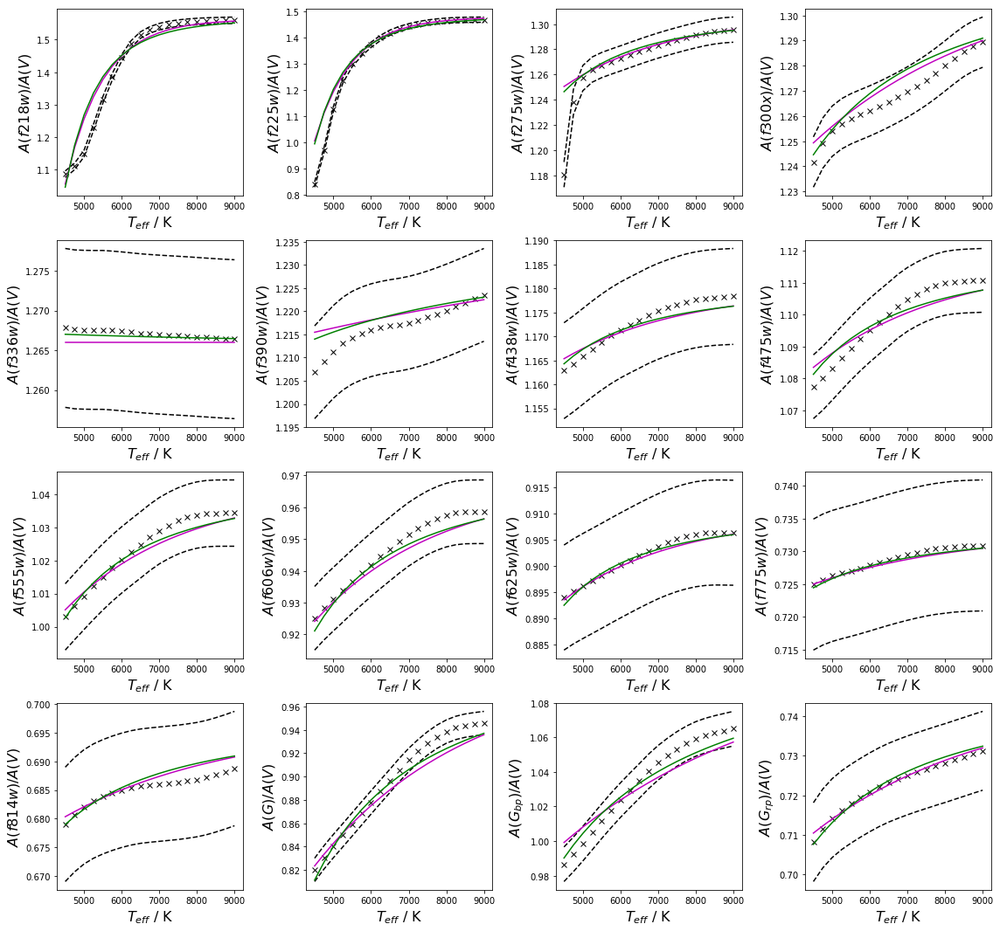


    Writing complete for log(g) = 1.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 1.0
Exponential fit coefficients (should be reused): 
[-46.5132 -10.0448   1.5626]
Standard deviations (should be reused): 
[  6.0688e+00   2.6922e-01   1.3360e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0075 -5.3093  1.5646]
Standard deviations (should be reused): 
[ 0.0007  0.1346  0.0014]
Logistic fit coefficients: 
[  5.4333e+03   2.6930e+01   1.5594e+00   1.0846e+00]
Standard deviations: 
[  3.7310e+01   1.7588e+00   1.2746e-03   1.5797e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4312  1.5028  1.4254]
Standard deviations: 
[ 0.      0.034   0.0015  0.0036]





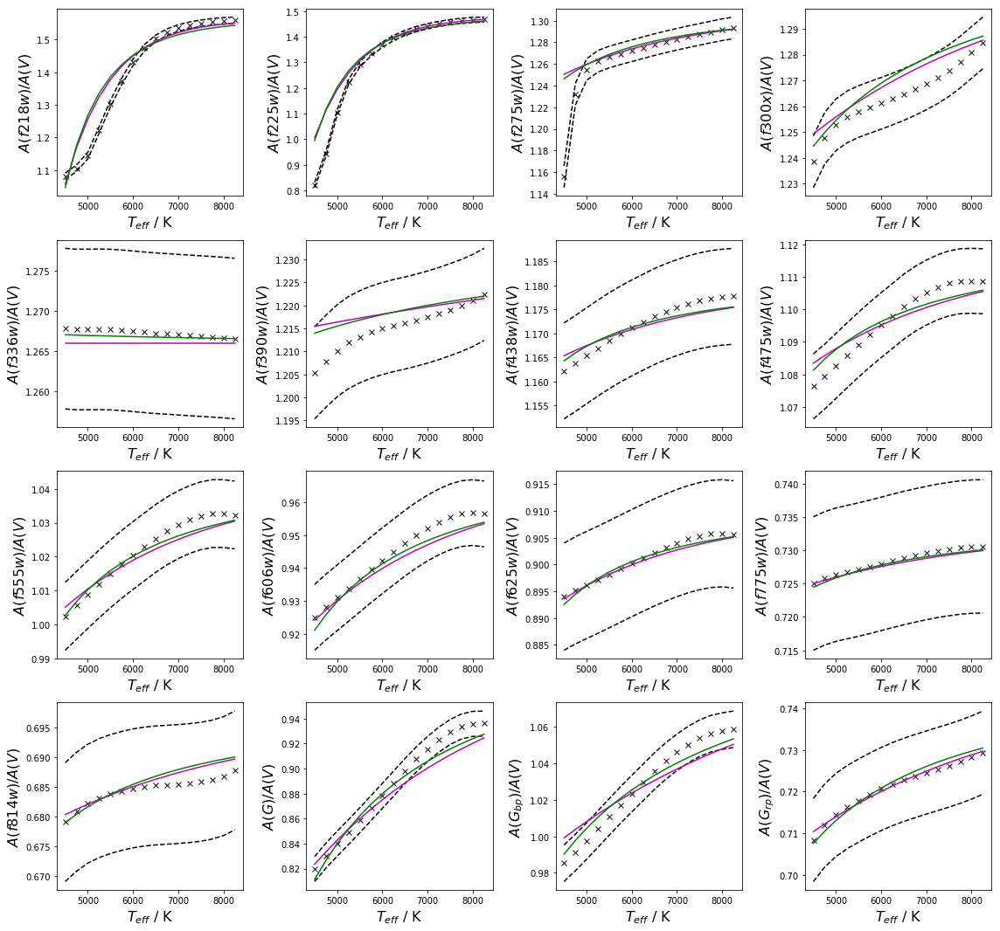


    Writing complete for log(g) = 1.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 0.5
Exponential fit coefficients (should be reused): 
[-46.5132 -10.0448   1.5626]
Standard deviations (should be reused): 
[  6.0688e+00   2.6922e-01   1.3360e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0075 -5.3093  1.5646]
Standard deviations (should be reused): 
[ 0.0007  0.1346  0.0014]
Logistic fit coefficients: 
[  5.4333e+03   2.6930e+01   1.5594e+00   1.0846e+00]
Standard deviations: 
[  3.7310e+01   1.7588e+00   1.2746e-03   1.5797e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4312  1.5028  1.4254]
Standard deviations: 
[ 0.      0.034   0.0015  0.0036]





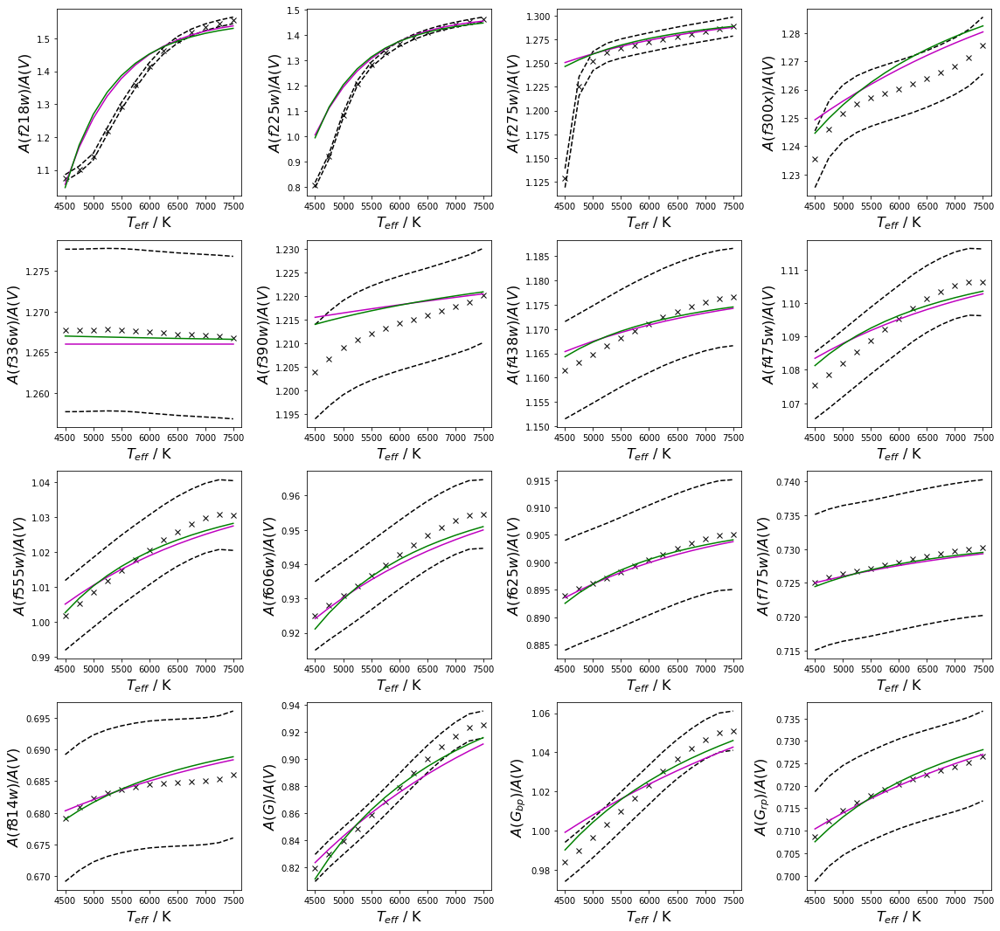


    Writing complete for log(g) = 0.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 0.0
Exponential fit coefficients (should be reused): 
[-46.5132 -10.0448   1.5626]
Standard deviations (should be reused): 
[  6.0688e+00   2.6922e-01   1.3360e-03]
Teff^(n) fit coefficients (should be reused): 
[-0.0075 -5.3093  1.5646]
Standard deviations (should be reused): 
[ 0.0007  0.1346  0.0014]
Logistic fit coefficients: 
[  5.4333e+03   2.6930e+01   1.5594e+00   1.0846e+00]
Standard deviations: 
[  3.7310e+01   1.7588e+00   1.2746e-03   1.5797e-02]
Teff log-normal fit coefficients: 
[ 0.      0.4312  1.5028  1.4254]
Standard deviations: 
[ 0.      0.034   0.0015  0.0036]





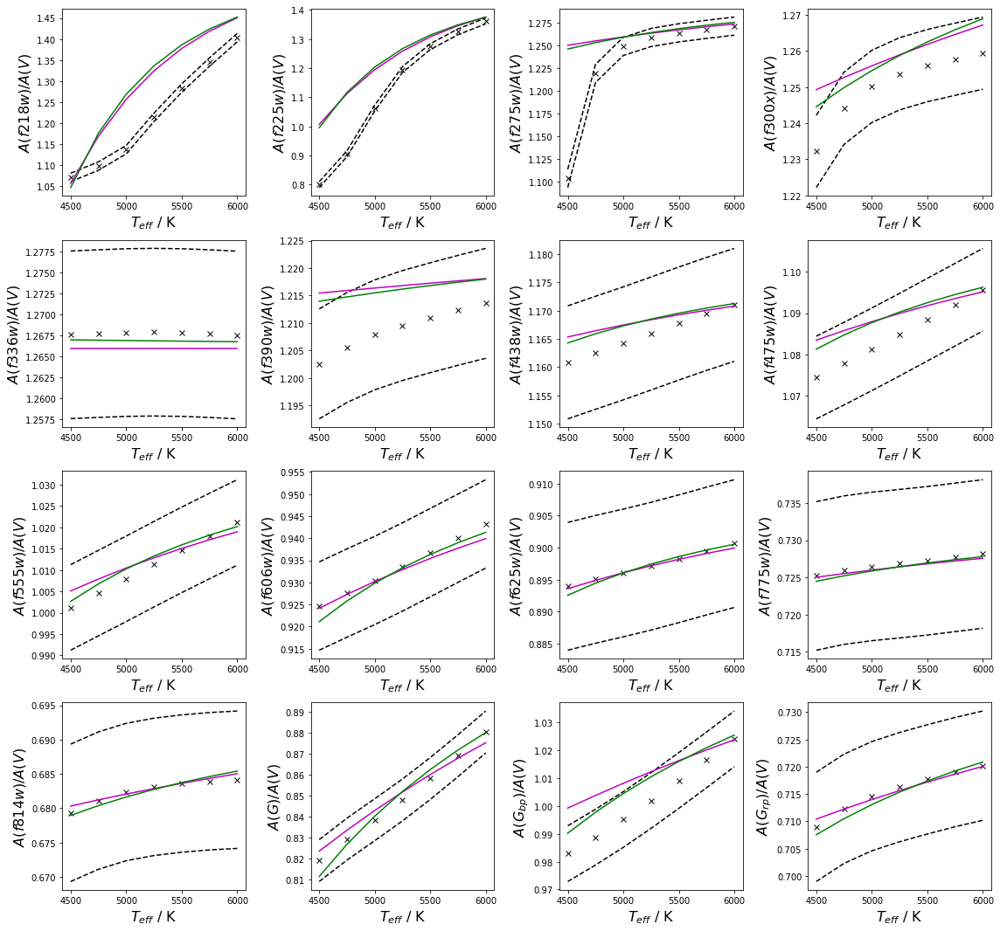


    Writing complete for log(g) = 0.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!
plotter writer complete


In [10]:
# If finished fitting (i.e. log(g) not equal to 5.0), DON'T run previous cell!!!

add_string = 'abs_sigmas_'+str(sigma_val)+'_0.01_bounds'
# 4500K_
# Test solar metallicity fit on ALL metallicity scenarios
for keyvals in sorted(comb_Ax_Av_dict_4500K.iterkeys()):
    find_metal = re.search(',(.*)',keyvals)
    if find_metal:
        metal = str(find_metal.group(1))
    find_Rv = re.search('(.*),',keyvals)
    if find_Rv:
        Rv = str(find_Rv.group(1))
    for gkey in reversed(sorted(comb_Ax_Av_dict_4500K[keyvals].iterkeys())):
        print '\n'
        print keyvals+' , '+gkey
        filter_curve_plot_write(comb_Ax_Av_dict_4500K[keyvals],combined_list_coef_stdev_zs_4500K[keyvals],gkey,Rv,metal,add_string,\
                                comb_filter_str,var_names_comb,sigma_val,'Rv_varied/models_fit/comb','','n','y',\
                                zoom_min=3000,zoom_max=20000,coef_cut='_4500',write_stuff='y',save_stuff='n')#,plot_diff='y')#
#  ,write_stuff='y'
#,4000,15000
#,4400,6000
print 'plotter writer complete'

In [34]:
# ACS FILTER R1 FITTING

exp_bounds_ACS_f435w = ([-100., -100., -3.], [1., 100., 3.])
pow_bounds_ACS_f435w = ([-1.0e+03, -2., -5.], [1., 2., 5.])
logis_bounds_ACS_f435w = ([0.,  0., 0., 0.], [10000., 1000., 2.00, 2.])
plog_bounds_ACS_f435w = ([-10., 0., 0., -2.], [2., 10., 3.00, 2.])

exp_bounds_ACS_f475w = ([-100., -100., -5.], [0., 100., 5.])
pow_bounds_ACS_f475w = ([-1.0e+03, -2., -5.], [1., 2., 5.])
logis_bounds_ACS_f475w = ([0.,  0., 0., 0.], [10000., 1000., 3.00, 2.])
plog_bounds_ACS_f475w = ([-10., 0., 0., -2.], [2., 10., 3.00, 2.])

exp_bounds_ACS_f555w = ([-100., -100., -5.], [0., 100., 5.])
pow_bounds_ACS_f555w = ([-1.0e+03, -3., -5.], [1., 1., 5.])
logis_bounds_ACS_f555w = ([0.,  0., 0., 0.], [10000., 1000., 3.00, 2.])
plog_bounds_ACS_f555w = ([-10., 0., 0., -2.], [2., 10., 3.00, 2.])

exp_bounds_ACS_f606w = ([-100., -100., -5.], [0., 100., 5.])
pow_bounds_ACS_f606w = ([-1.0e+03, -2., -5.], [1., 2., 5.])
logis_bounds_ACS_f606w = ([0.,  0., 0., 0.], [10000., 1000., 3.00, 2.])
plog_bounds_ACS_f606w = ([-10., 0., 0., -2.], [2., 10., 3.00, 2.])

exp_bounds_ACS_f625w = ([-10., -10., -5.], [0., 1., 5.])
pow_bounds_ACS_f625w = ([-1.0e+02, -5., -5.], [1., 5., 5.])
logis_bounds_ACS_f625w = ([0.,  0., 0., 0.], [10000., 1000., 3.00, 2.])
plog_bounds_ACS_f625w = ([-10., 0., 0., -2.], [2., 10., 3.00, 2.])

exp_bounds_ACS_f775w = ([-10., -10., -5.], [0., 1., 5.])
pow_bounds_ACS_f775w = ([-1.0e+02, -3., -5.], [1., 3., 5.])
logis_bounds_ACS_f775w = ([0.,  0., 0., 0.], [10000., 1000., 3.00, 2.])
plog_bounds_ACS_f775w = ([-10., 0., 0., -2.], [2., 10., 3.00, 2.])

exp_bounds_ACS_f814w = ([-10., -10., -5.], [0., 1., 5.])
pow_bounds_ACS_f814w = ([-1.0e+02, -3., -5.], [1., 3., 5.])
logis_bounds_ACS_f814w = ([0.,  0., 0., 0.], [10000., 1000., 3.00, 2.])
plog_bounds_ACS_f814w = ([-10., 0., 0., -2.], [2., 10., 3.00, 2.])

# make array of bounds
exp_bounds_ACS = [exp_bounds_ACS_f435w,exp_bounds_ACS_f475w,exp_bounds_ACS_f555w,exp_bounds_ACS_f606w,\
                  exp_bounds_ACS_f625w,exp_bounds_ACS_f775w,exp_bounds_ACS_f814w]
pow_bounds_ACS = [pow_bounds_ACS_f435w,pow_bounds_ACS_f475w,pow_bounds_ACS_f555w,pow_bounds_ACS_f606w,\
                  pow_bounds_ACS_f625w,pow_bounds_ACS_f775w,pow_bounds_ACS_f814w]
logis_bounds_ACS = [logis_bounds_ACS_f435w,logis_bounds_ACS_f475w,logis_bounds_ACS_f555w,logis_bounds_ACS_f606w,\
                    logis_bounds_ACS_f625w,logis_bounds_ACS_f775w,logis_bounds_ACS_f814w]
plog_bounds_ACS = [plog_bounds_ACS_f435w,plog_bounds_ACS_f475w,plog_bounds_ACS_f555w,plog_bounds_ACS_f606w,\
                   plog_bounds_ACS_f625w,plog_bounds_ACS_f775w,plog_bounds_ACS_f814w]
# produce fitting results - leave key at '5.0'!!!


print len(exp_bounds_ACS), len(acs_filter_str)
print 'SOLAR METALLICITY ACS FITTING'

ACS_sigma_val = 0.01
p0_logis = [5250.0,25.0,1.5,1.1]
p0_plog = [-2., 5., 1.5, 1.1]

ACS_list_coef_stdev_zs_4500K = {}
ACS_dict_list_coef_stdev_zs_4500K = {}
for keyvals in sorted(ACS_Ax_Av_dict_4500K.iterkeys()):
    print keyvals
    ACS_list_coef_stdev_zs_4500K[keyvals],ACS_dict_list_coef_stdev_zs_4500K[keyvals] = filter_curve_fit(ACS_Ax_Av_dict_4500K[keyvals],Rv,'5.0',exp_bounds_ACS,pow_bounds_ACS,logis_bounds_ACS,\
                                                                                      plog_bounds_ACS,acs_filter_str,ACS_sigma_val,'y',p0_opt_logis=p0_logis,\
                                                                                      p0_opt_plog=p0_plog,niter=10000*len(ACS_Ax_Av_dict_4500K[keyvals]['5.0'][:,0]))#,'y'
    print 'List of lists of arrays, length ',len(ACS_list_coef_stdev_zs_4500K[keyvals]),len(ACS_dict_list_coef_stdev_zs_4500K[keyvals])
print 'Number of Rv,metallicity combinations processed',len(ACS_list_coef_stdev_zs_4500K),len(ACS_dict_list_coef_stdev_zs_4500K)

7 7
SOLAR METALLICITY ACS FITTING
2.0,-1.0
Calculating coefficients & covariance matrices for f435w ACS filter
Exponential fit coefficients: 
[-0.1565 -1.7579  1.5435]
Standard deviations: 
[ 0.0219  0.2264  0.002 ]
Teff^(n) fit coefficients: 
[-0.0332 -1.1946  1.5509]
Standard deviations: 
[ 0.0055  0.1931  0.0042]
Logistic fit coefficients: 
[  5.2441e-18   2.1280e+00   1.5429e+00   1.2950e+00]
Standard deviations: 
[  1.5215e+04   9.1909e-01   2.0710e-03   5.2472e-01]
Teff log-normal fit coefficients: 
[-2.      0.6932  1.5121  1.476 ]
Standard deviations: 
[ 0.      0.1474  0.0015  0.005 ]



Calculating coefficients & covariance matrices for f475w ACS filter
Exponential fit coefficients: 
[-0.2927 -2.5348  1.34  ]
Standard deviations: 
[ 0.0424  0.2481  0.0018]
Teff^(n) fit coefficients: 
[-0.0291 -1.6132  1.3451]
Standard deviations: 
[ 0.0039  0.1766  0.0028]
Logistic fit coefficients: 
[  1.8752e-14   2.9088e+00   1.3395e+00   9.0801e-01]
Standard deviations: 
[  1.0954e+04   9

Calculating coefficients & covariance matrices for f475w ACS filter
Exponential fit coefficients: 
[-0.3277 -2.6376  1.3401]
Standard deviations: 
[ 0.0461  0.2427  0.0018]
Teff^(n) fit coefficients: 
[-0.0297 -1.6629  1.3452]
Standard deviations: 
[ 0.0038  0.1695  0.0027]
Logistic fit coefficients: 
[  4.1037e-12   3.0042e+00   1.3397e+00   8.6201e-01]
Standard deviations: 
[  1.0236e+04   8.6725e-01   1.8117e-03   1.0484e+00]
Teff log-normal fit coefficients: 
[-2.      0.4104  1.3065  1.2696]
Standard deviations: 
[ 0.      0.0674  0.0015  0.0035]



Calculating coefficients & covariance matrices for f555w ACS filter
Exponential fit coefficients: 
[-0.129  -2.6474  1.0673]
Standard deviations: 
[ 0.0464  0.622   0.0018]
Teff^(n) fit coefficients: 
[-0.0115 -1.6844  1.0693]
Standard deviations: 
[ 0.0037  0.4324  0.0027]
Logistic fit coefficients: 
[  1.9773e-14   3.0240e+00   1.0671e+00   8.7864e-01]
Standard deviations: 
[  2.5838e+04   2.2068e+00   1.8080e-03   1.0524e+00]
Teff l

Calculating coefficients & covariance matrices for f555w ACS filter
Exponential fit coefficients: 
[-0.0713 -2.3855  1.0454]
Standard deviations: 
[ 0.0375  0.8904  0.0018]
Teff^(n) fit coefficients: 
[-0.0083 -1.5233  1.047 ]
Standard deviations: 
[ 0.0041  0.6501  0.003 ]
Logistic fit coefficients: 
[  4.6380e-11   2.7668e+00   1.0453e+00   9.3844e-01]
Standard deviations: 
[  4.1813e+04   3.3380e+00   1.8845e-03   8.6063e-01]
Teff log-normal fit coefficients: 
[-2.      0.5059  1.0365  1.0266]
Standard deviations: 
[ 0.      0.32    0.0015  0.0039]



Calculating coefficients & covariance matrices for f606w ACS filter
Exponential fit coefficients: 
[-0.1914 -2.708   0.9591]
Standard deviations: 
[ 0.0488  0.4419  0.0017]
Teff^(n) fit coefficients: 
[-0.0161 -1.7159  0.9618]
Standard deviations: 
[ 0.0037  0.3058  0.0026]
Logistic fit coefficients: 
[  1.4032e-11   3.0699e+00   9.5891e-01   6.8208e-01]
Standard deviations: 
[  1.7866e+04   1.5471e+00   1.8006e-03   1.0896e+00]
Teff l

Calculating coefficients & covariance matrices for f555w ACS filter
Exponential fit coefficients: 
[-0.0914 -2.6767  1.0454]
Standard deviations: 
[ 0.0476  0.9009  0.0017]
Teff^(n) fit coefficients: 
[-0.0079 -1.7017  1.0468]
Standard deviations: 
[ 0.0037  0.6231  0.0026]
Logistic fit coefficients: 
[  2.4284e-11   3.0526e+00   1.0453e+00   9.1217e-01]
Standard deviations: 
[  3.8049e+04   3.2913e+00   1.8189e-03   1.1073e+00]
Teff log-normal fit coefficients: 
[-2.      0.4895  1.0362  1.0256]
Standard deviations: 
[ 0.      0.2884  0.0015  0.0038]



Calculating coefficients & covariance matrices for f606w ACS filter
Exponential fit coefficients: 
[-0.2183 -2.8668  0.9592]
Standard deviations: 
[ 0.0554  0.4449  0.0017]
Teff^(n) fit coefficients: 
[-0.0157 -1.8101  0.9618]
Standard deviations: 
[ 0.0035  0.3     0.0025]
Logistic fit coefficients: 
[  9.6222e-12   3.2238e+00   9.5904e-01   6.4802e-01]
Standard deviations: 
[  1.7117e+04   1.5420e+00   1.7830e-03   1.2485e+00]
Teff l

Calculating coefficients & covariance matrices for f606w ACS filter
Exponential fit coefficients: 
[-0.139  -2.7693  0.9647]
Standard deviations: 
[ 0.0512  0.6421  0.0017]
Teff^(n) fit coefficients: 
[-0.011  -1.7533  0.9665]
Standard deviations: 
[ 0.0036  0.4401  0.0025]
Logistic fit coefficients: 
[  1.4499e-08   3.1284e+00   9.6460e-01   7.6484e-01]
Standard deviations: 
[  2.6011e+04   2.2768e+00   1.7934e-03   1.1735e+00]
Teff log-normal fit coefficients: 
[-2.      0.4067  0.9518  0.9373]
Standard deviations: 
[ 0.      0.1707  0.0015  0.0035]



Calculating coefficients & covariance matrices for f625w ACS filter
Exponential fit coefficients: 
[-0.0526 -3.1899  0.8992]
Standard deviations: 
[  7.1455e-02   2.4289e+00   1.6807e-03]
Teff^(n) fit coefficients: 
[-0.0027 -2.019   0.8995]
Standard deviations: 
[ 0.0031  1.5868  0.0022]
Logistic fit coefficients: 
[  2.9078e+03   3.9584e+00   8.9910e-01   8.6436e-01]
Standard deviations: 
[  3.6026e+04   8.6132e+00   1.7165e-03   3.0

Calculating coefficients & covariance matrices for f606w ACS filter
Exponential fit coefficients: 
[-0.1587 -2.9311  0.9648]
Standard deviations: 
[ 0.0583  0.6466  0.0017]
Teff^(n) fit coefficients: 
[-0.0108 -1.8485  0.9665]
Standard deviations: 
[ 0.0034  0.4319  0.0024]
Logistic fit coefficients: 
[  1.3570e-11   3.2849e+00   9.6469e-01   7.3996e-01]
Standard deviations: 
[  2.4312e+04   2.2200e+00   1.7750e-03   1.3130e+00]
Teff log-normal fit coefficients: 
[-2.      0.4052  0.9516  0.9366]
Standard deviations: 
[ 0.      0.1642  0.0015  0.0035]



Calculating coefficients & covariance matrices for f625w ACS filter
Exponential fit coefficients: 
[-0.057  -3.339   0.8992]
Standard deviations: 
[  8.0208e-02   2.5366e+00   1.6641e-03]
Teff^(n) fit coefficients: 
[-0.0026 -2.1057  0.8995]
Standard deviations: 
[ 0.003   1.6277  0.0021]
Logistic fit coefficients: 
[  2.6624e+03   4.0606e+00   8.9910e-01   8.6097e-01]
Standard deviations: 
[  3.8025e+04   8.8402e+00   1.7060e-03   3.7



2.0,-1.0 , 5.0
Deleting missing subplots - discrepancy between 7 and 9


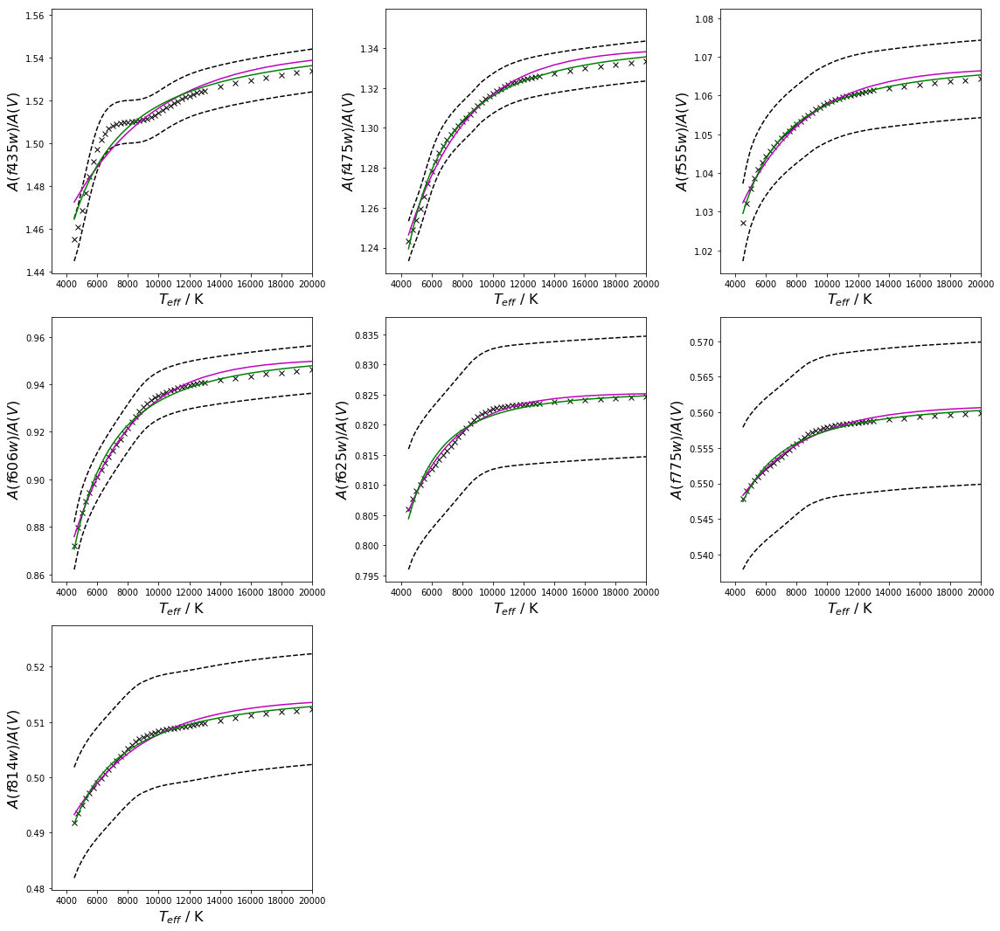


    Writing complete for log(g) = 5.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 4.5
Exponential fit coefficients (should be reused): 
[-0.1565 -1.7579  1.5435]
Standard deviations (should be reused): 
[ 0.0219  0.2264  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0332 -1.1946  1.5509]
Standard deviations (should be reused): 
[ 0.0055  0.1931  0.0042]
Logistic fit coefficients: 
[  5.2441e-18   2.1280e+00   1.5429e+00   1.2950e+00]
Standard deviations: 
[  1.5215e+04   9.1909e-01   2.0710e-03   5.2472e-01]
Teff log-normal fit coefficients: 
[-2.      0.6932  1.5121  1.476 ]
Standard deviations: 
[ 0.      0.1474  0.0015  0.005 ]



Deleting missing subplots - discrepancy between 7 and 9


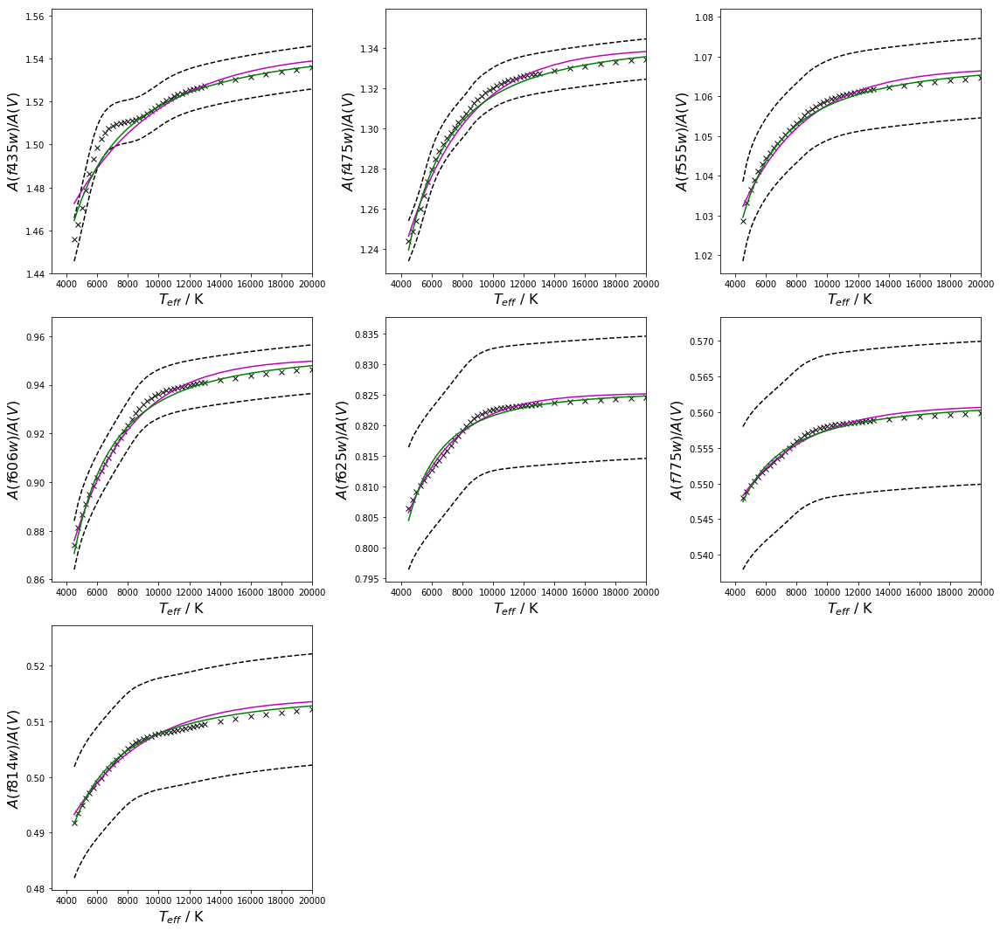


    Writing complete for log(g) = 4.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 4.0
Exponential fit coefficients (should be reused): 
[-0.1565 -1.7579  1.5435]
Standard deviations (should be reused): 
[ 0.0219  0.2264  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0332 -1.1946  1.5509]
Standard deviations (should be reused): 
[ 0.0055  0.1931  0.0042]
Logistic fit coefficients: 
[  5.2441e-18   2.1280e+00   1.5429e+00   1.2950e+00]
Standard deviations: 
[  1.5215e+04   9.1909e-01   2.0710e-03   5.2472e-01]
Teff log-normal fit coefficients: 
[-2.      0.6932  1.5121  1.476 ]
Standard deviations: 
[ 0.      0.1474  0.0015  0.005 ]



Deleting missing subplots - discrepancy between 7 and 9


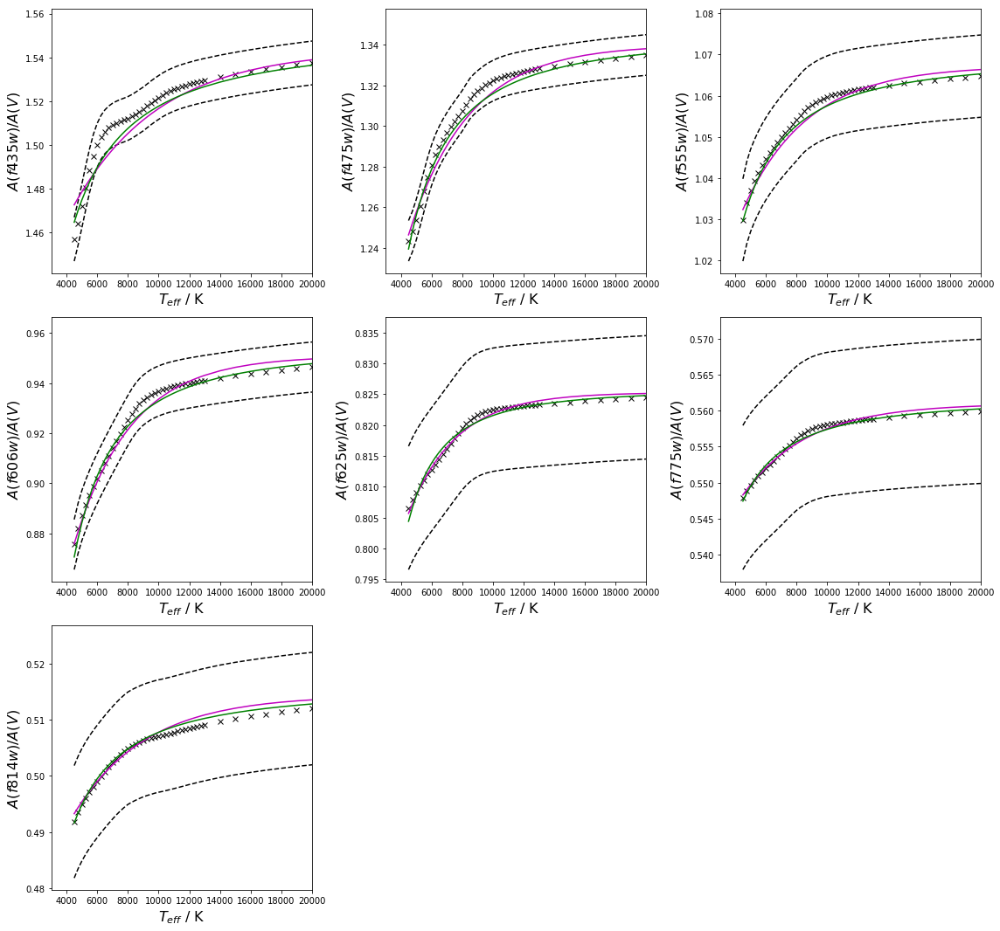


    Writing complete for log(g) = 4.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 3.5
Exponential fit coefficients (should be reused): 
[-0.1565 -1.7579  1.5435]
Standard deviations (should be reused): 
[ 0.0219  0.2264  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0332 -1.1946  1.5509]
Standard deviations (should be reused): 
[ 0.0055  0.1931  0.0042]
Logistic fit coefficients: 
[  5.2441e-18   2.1280e+00   1.5429e+00   1.2950e+00]
Standard deviations: 
[  1.5215e+04   9.1909e-01   2.0710e-03   5.2472e-01]
Teff log-normal fit coefficients: 
[-2.      0.6932  1.5121  1.476 ]
Standard deviations: 
[ 0.      0.1474  0.0015  0.005 ]



Deleting missing subplots - discrepancy between 7 and 9


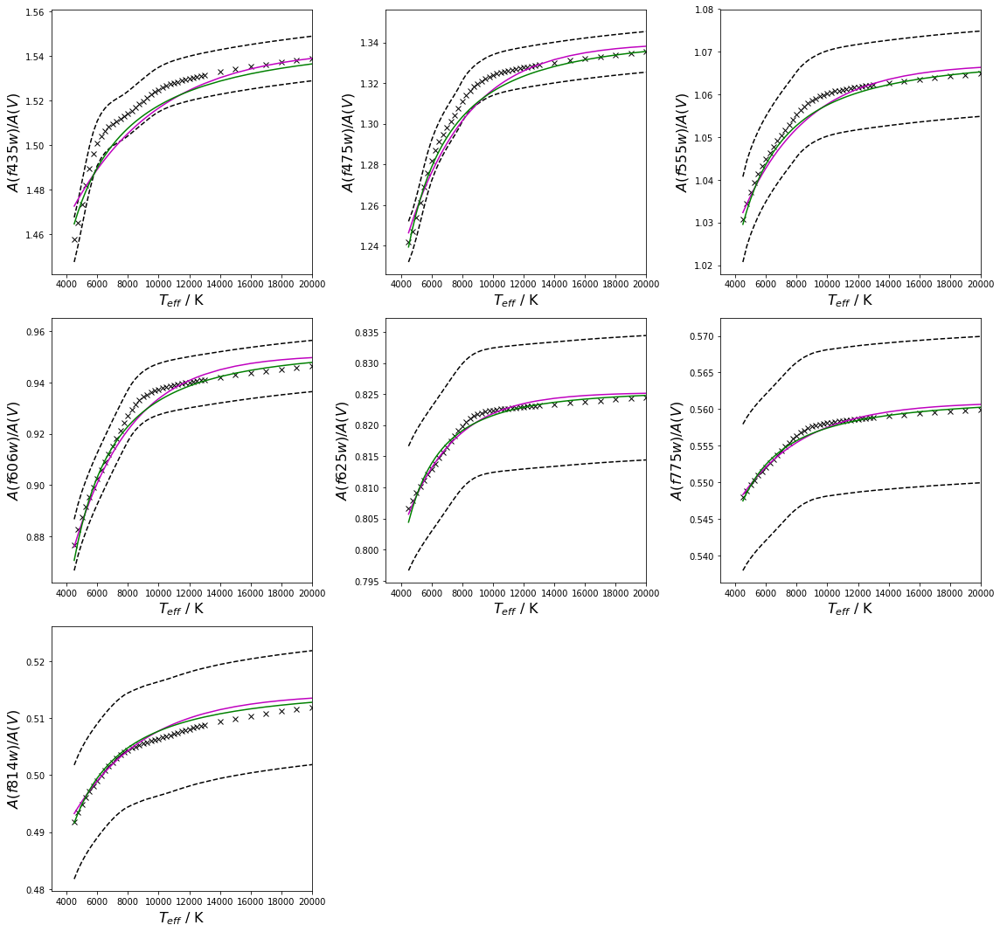


    Writing complete for log(g) = 3.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 3.0
Exponential fit coefficients (should be reused): 
[-0.1565 -1.7579  1.5435]
Standard deviations (should be reused): 
[ 0.0219  0.2264  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0332 -1.1946  1.5509]
Standard deviations (should be reused): 
[ 0.0055  0.1931  0.0042]
Logistic fit coefficients: 
[  5.2441e-18   2.1280e+00   1.5429e+00   1.2950e+00]
Standard deviations: 
[  1.5215e+04   9.1909e-01   2.0710e-03   5.2472e-01]
Teff log-normal fit coefficients: 
[-2.      0.6932  1.5121  1.476 ]
Standard deviations: 
[ 0.      0.1474  0.0015  0.005 ]



Deleting missing subplots - discrepancy between 7 and 9


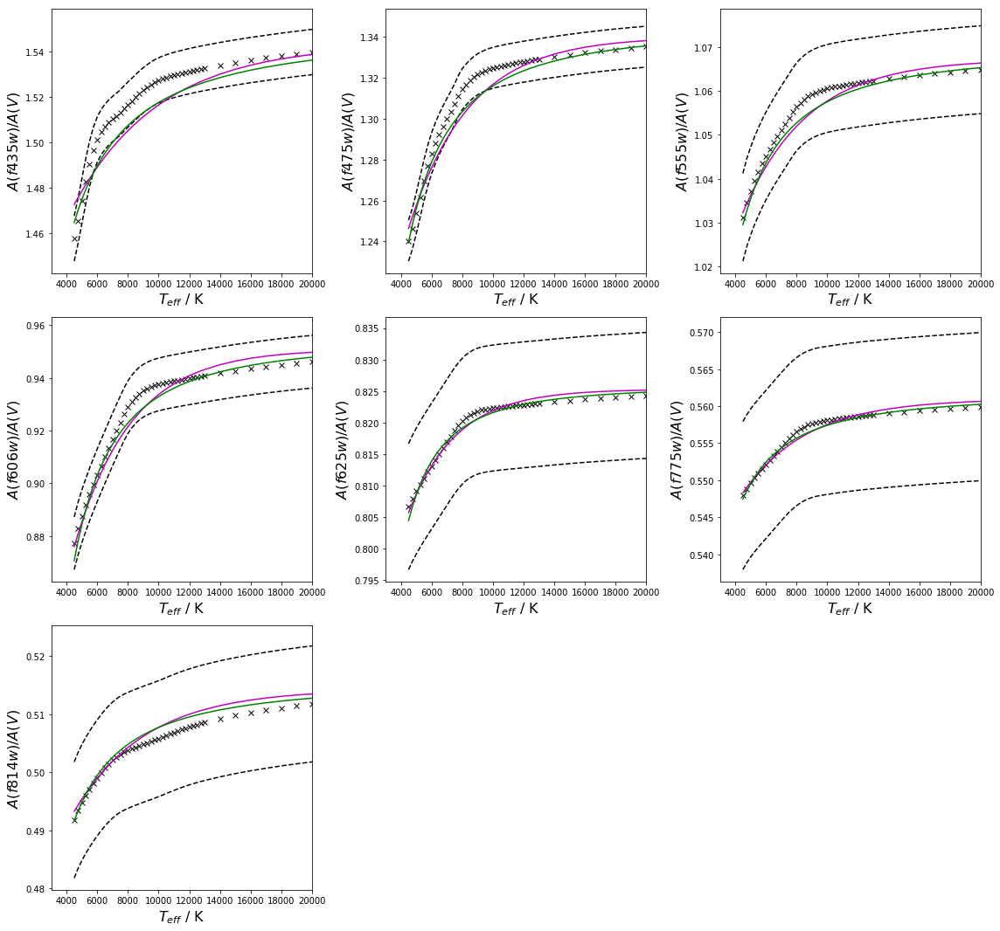


    Writing complete for log(g) = 3.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 2.5
Exponential fit coefficients (should be reused): 
[-0.1565 -1.7579  1.5435]
Standard deviations (should be reused): 
[ 0.0219  0.2264  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0332 -1.1946  1.5509]
Standard deviations (should be reused): 
[ 0.0055  0.1931  0.0042]
Logistic fit coefficients: 
[  5.2441e-18   2.1280e+00   1.5429e+00   1.2950e+00]
Standard deviations: 
[  1.5215e+04   9.1909e-01   2.0710e-03   5.2472e-01]
Teff log-normal fit coefficients: 
[-2.      0.6932  1.5121  1.476 ]
Standard deviations: 
[ 0.      0.1474  0.0015  0.005 ]



Deleting missing subplots - discrepancy between 7 and 9


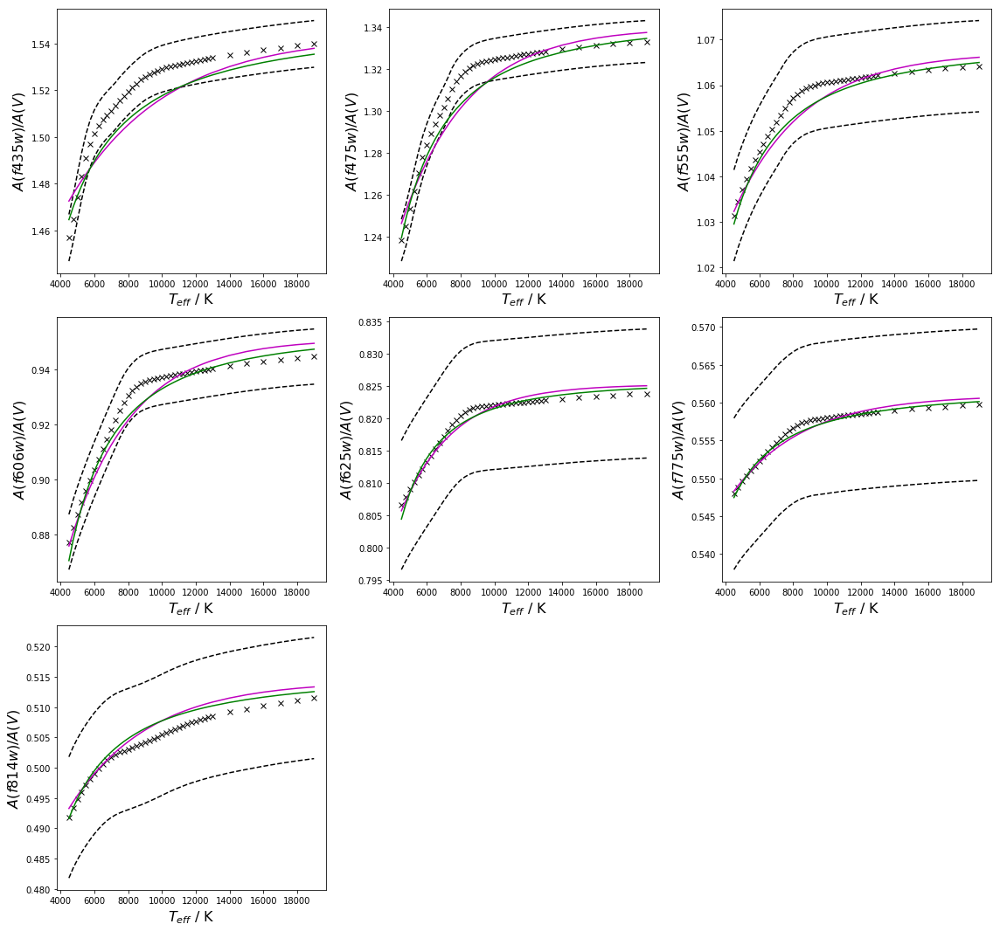


    Writing complete for log(g) = 2.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 2.0
Exponential fit coefficients (should be reused): 
[-0.1565 -1.7579  1.5435]
Standard deviations (should be reused): 
[ 0.0219  0.2264  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0332 -1.1946  1.5509]
Standard deviations (should be reused): 
[ 0.0055  0.1931  0.0042]
Logistic fit coefficients: 
[  5.2441e-18   2.1280e+00   1.5429e+00   1.2950e+00]
Standard deviations: 
[  1.5215e+04   9.1909e-01   2.0710e-03   5.2472e-01]
Teff log-normal fit coefficients: 
[-2.      0.6932  1.5121  1.476 ]
Standard deviations: 
[ 0.      0.1474  0.0015  0.005 ]



Deleting missing subplots - discrepancy between 7 and 9


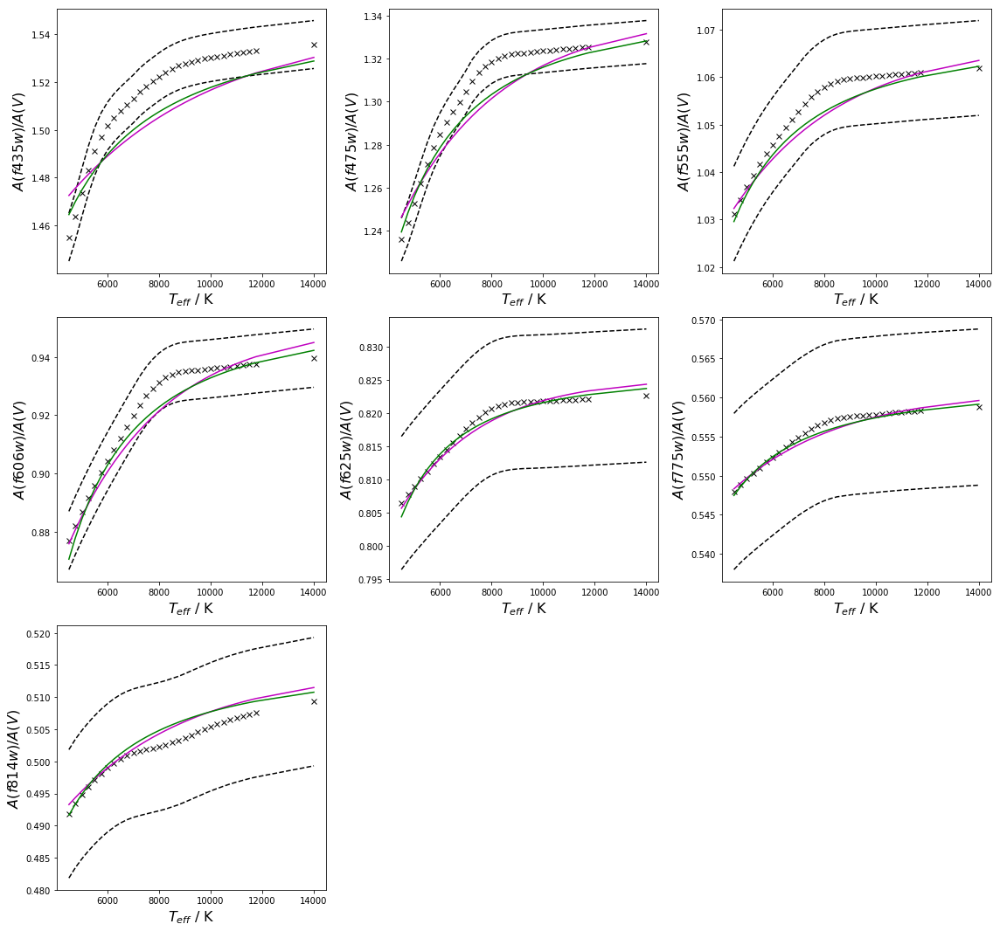


    Writing complete for log(g) = 2.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 1.5
Exponential fit coefficients (should be reused): 
[-0.1565 -1.7579  1.5435]
Standard deviations (should be reused): 
[ 0.0219  0.2264  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0332 -1.1946  1.5509]
Standard deviations (should be reused): 
[ 0.0055  0.1931  0.0042]
Logistic fit coefficients: 
[  5.2441e-18   2.1280e+00   1.5429e+00   1.2950e+00]
Standard deviations: 
[  1.5215e+04   9.1909e-01   2.0710e-03   5.2472e-01]
Teff log-normal fit coefficients: 
[-2.      0.6932  1.5121  1.476 ]
Standard deviations: 
[ 0.      0.1474  0.0015  0.005 ]



Deleting missing subplots - discrepancy between 7 and 9


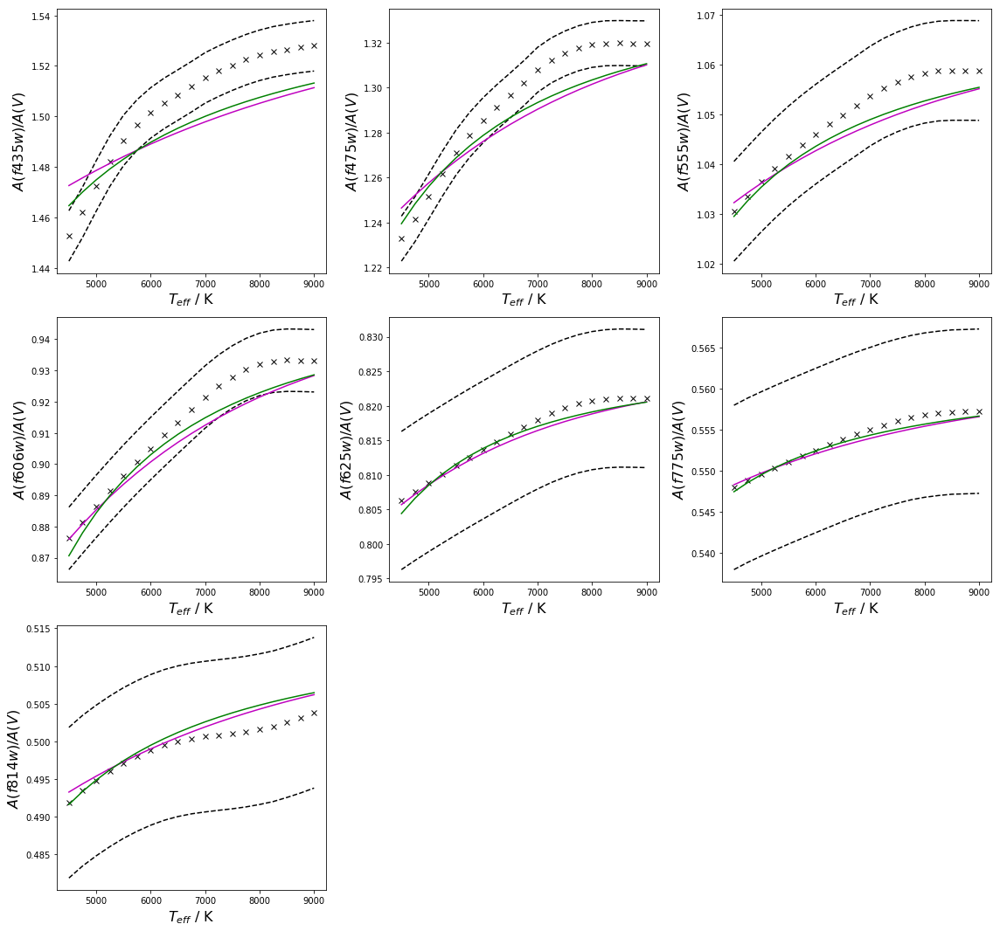


    Writing complete for log(g) = 1.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 1.0
Exponential fit coefficients (should be reused): 
[-0.1565 -1.7579  1.5435]
Standard deviations (should be reused): 
[ 0.0219  0.2264  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0332 -1.1946  1.5509]
Standard deviations (should be reused): 
[ 0.0055  0.1931  0.0042]
Logistic fit coefficients: 
[  5.2441e-18   2.1280e+00   1.5429e+00   1.2950e+00]
Standard deviations: 
[  1.5215e+04   9.1909e-01   2.0710e-03   5.2472e-01]
Teff log-normal fit coefficients: 
[-2.      0.6932  1.5121  1.476 ]
Standard deviations: 
[ 0.      0.1474  0.0015  0.005 ]



Deleting missing subplots - discrepancy between 7 and 9


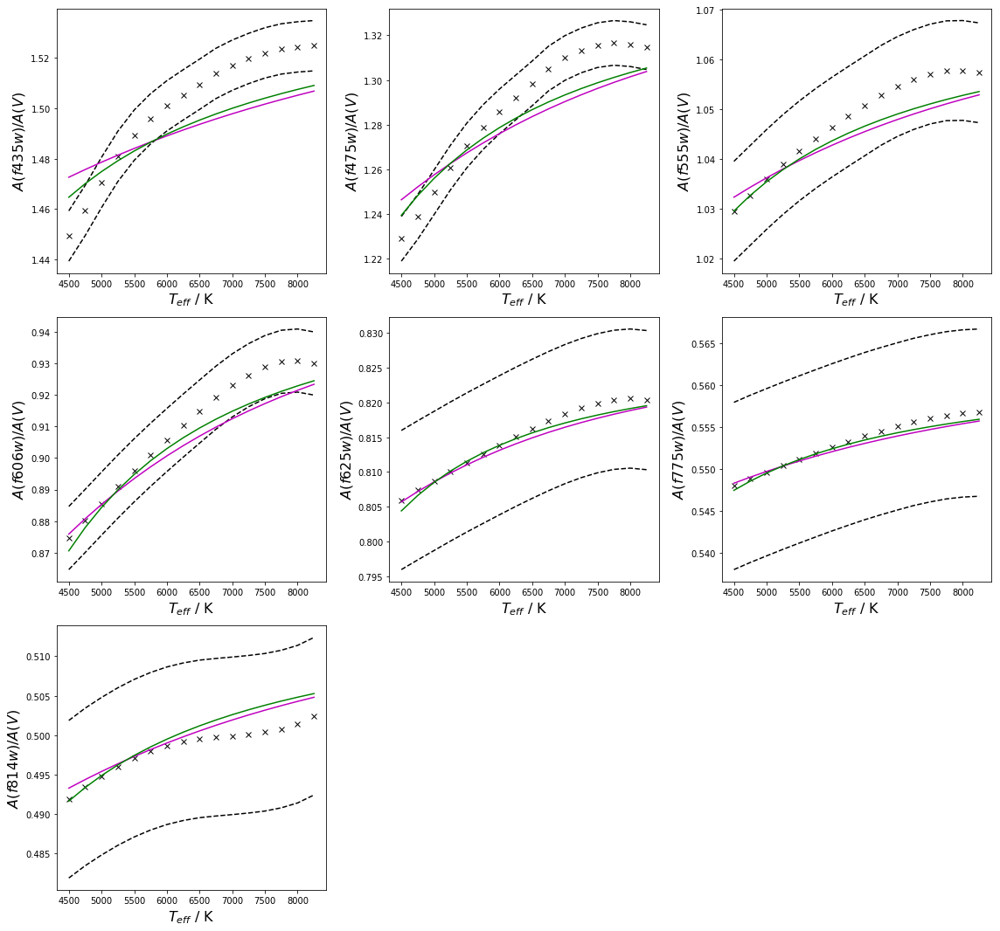


    Writing complete for log(g) = 1.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 0.5
Exponential fit coefficients (should be reused): 
[-0.1565 -1.7579  1.5435]
Standard deviations (should be reused): 
[ 0.0219  0.2264  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0332 -1.1946  1.5509]
Standard deviations (should be reused): 
[ 0.0055  0.1931  0.0042]
Logistic fit coefficients: 
[  5.2441e-18   2.1280e+00   1.5429e+00   1.2950e+00]
Standard deviations: 
[  1.5215e+04   9.1909e-01   2.0710e-03   5.2472e-01]
Teff log-normal fit coefficients: 
[-2.      0.6932  1.5121  1.476 ]
Standard deviations: 
[ 0.      0.1474  0.0015  0.005 ]



Deleting missing subplots - discrepancy between 7 and 9


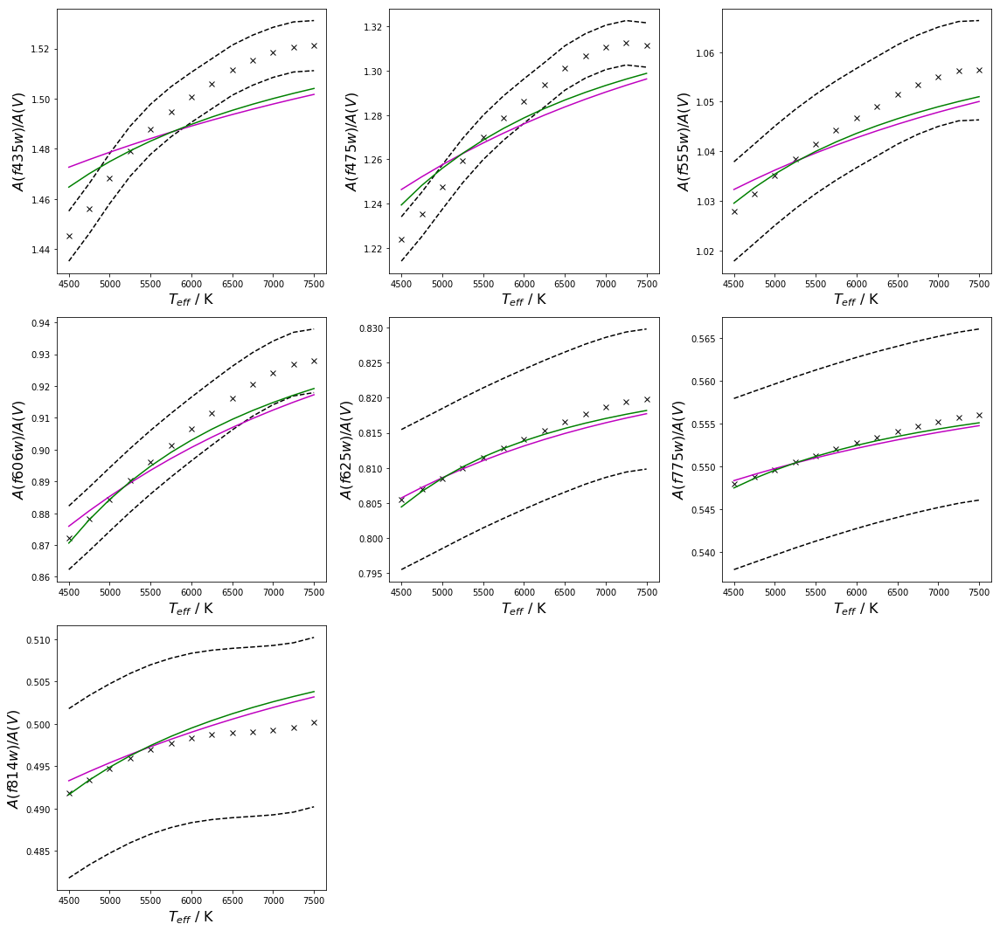


    Writing complete for log(g) = 0.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-1.0 , 0.0
Exponential fit coefficients (should be reused): 
[-0.1565 -1.7579  1.5435]
Standard deviations (should be reused): 
[ 0.0219  0.2264  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0332 -1.1946  1.5509]
Standard deviations (should be reused): 
[ 0.0055  0.1931  0.0042]
Logistic fit coefficients: 
[  5.2441e-18   2.1280e+00   1.5429e+00   1.2950e+00]
Standard deviations: 
[  1.5215e+04   9.1909e-01   2.0710e-03   5.2472e-01]
Teff log-normal fit coefficients: 
[-2.      0.6932  1.5121  1.476 ]
Standard deviations: 
[ 0.      0.1474  0.0015  0.005 ]



Deleting missing subplots - discrepancy between 7 and 9


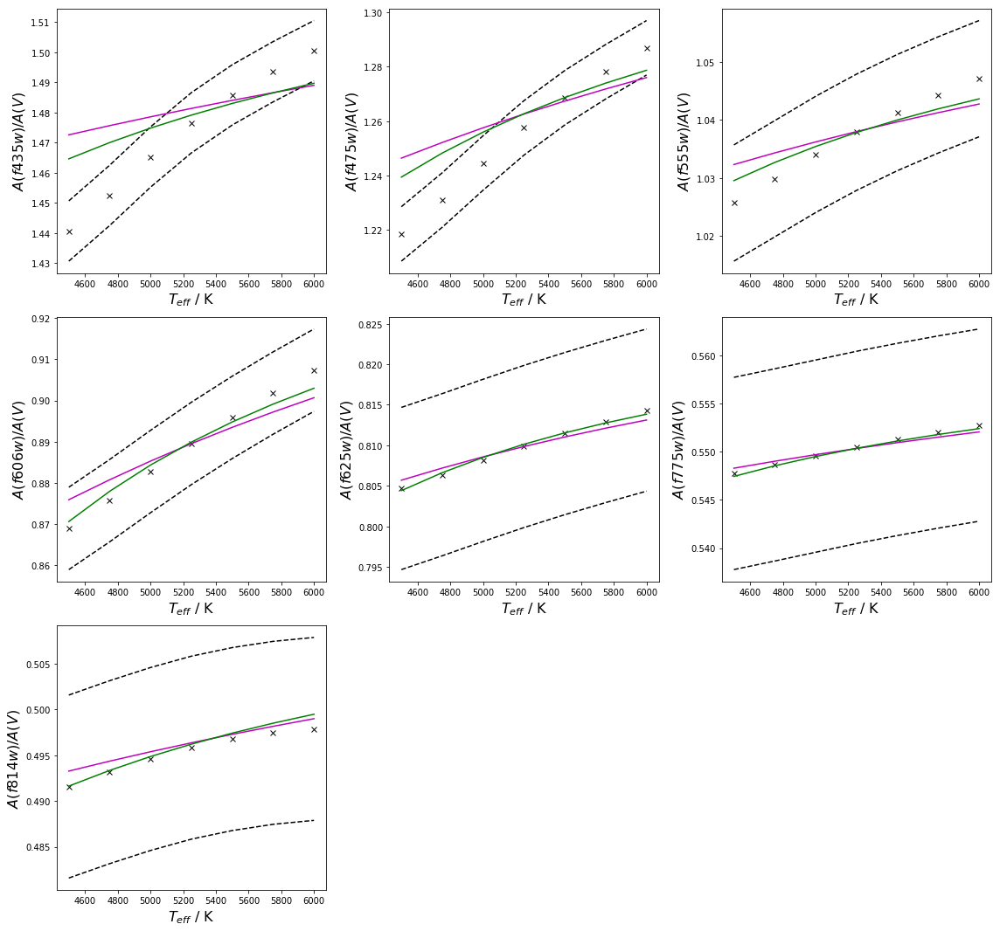


    Writing complete for log(g) = 0.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 5.0
Deleting missing subplots - discrepancy between 7 and 9


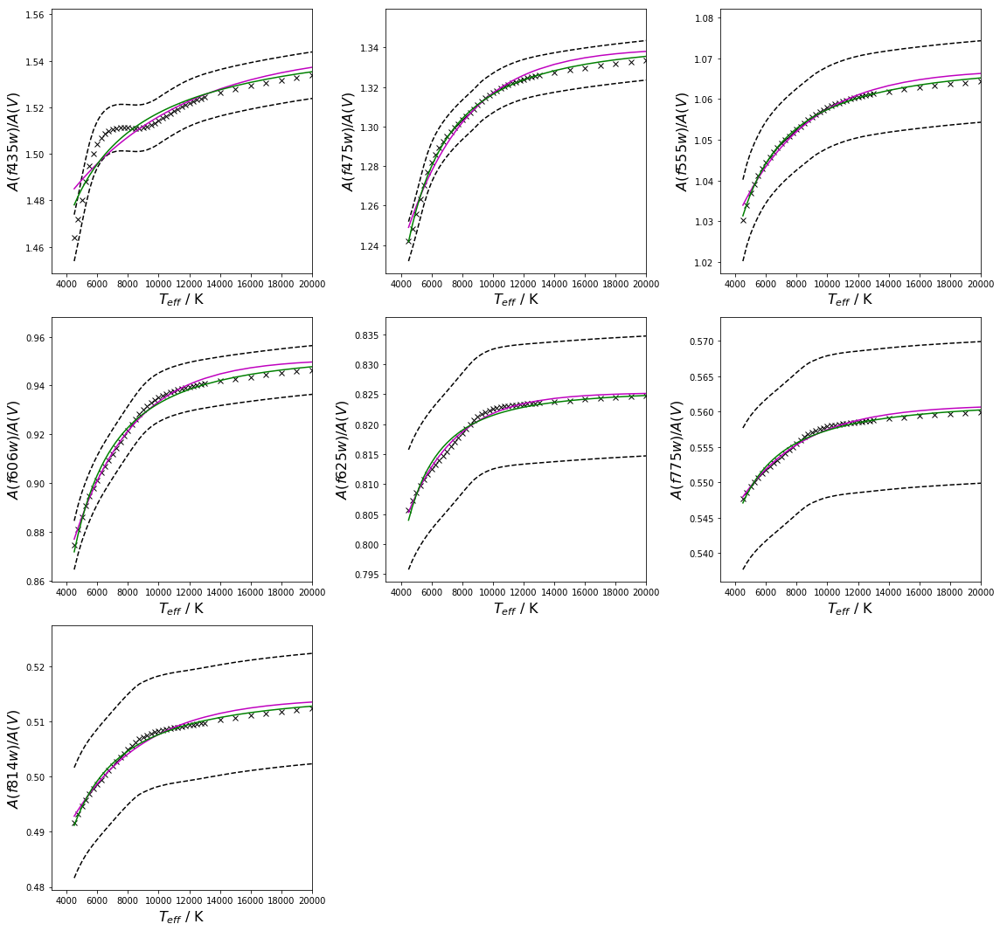


    Writing complete for log(g) = 5.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 4.5
Exponential fit coefficients (should be reused): 
[-0.1087 -1.3237  1.5449]
Standard deviations (should be reused): 
[ 0.0145  0.2132  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0387 -0.8816  1.5563]
Standard deviations (should be reused): 
[ 0.0083  0.2089  0.0071]
Logistic fit coefficients: 
[  2.4856e-16   1.6571e+00   1.5442e+00   1.3655e+00]
Standard deviations: 
[  1.8970e+04   8.5384e-01   2.4441e-03   3.4908e-01]
Teff log-normal fit coefficients: 
[-2.      0.8394  1.5141  1.4784]
Standard deviations: 
[ 0.      0.2291  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


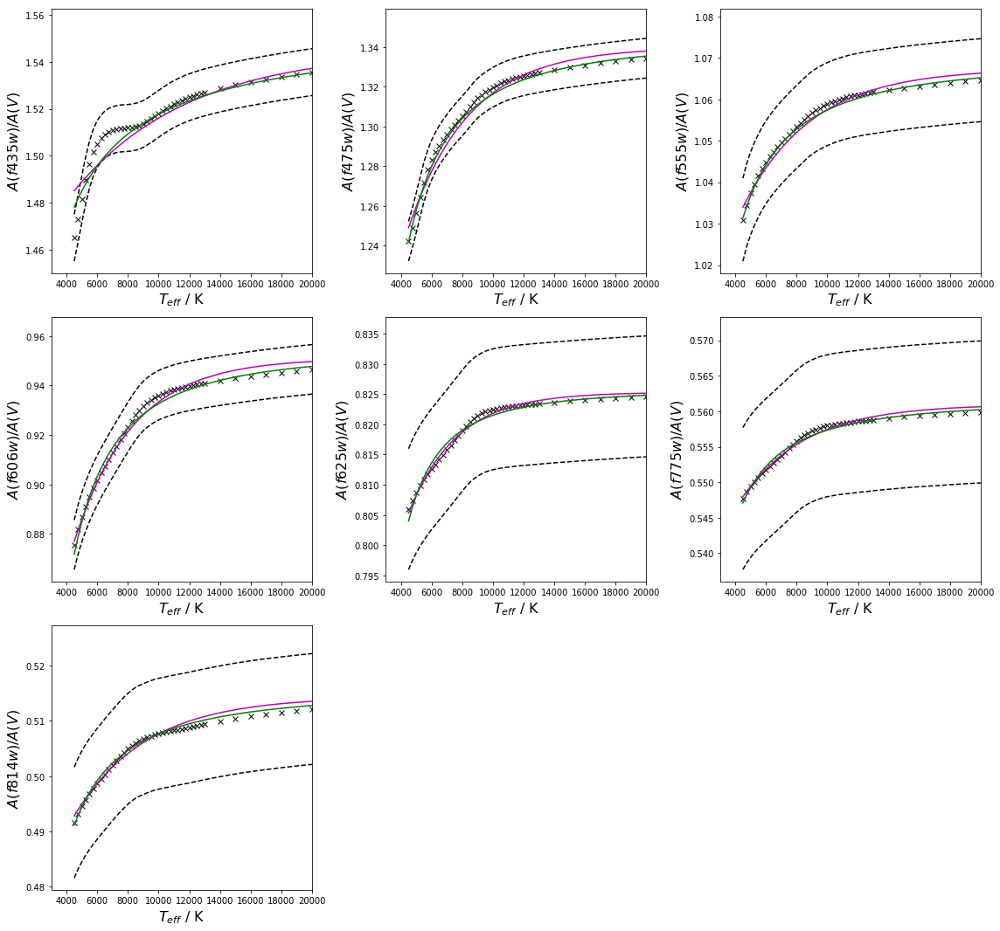


    Writing complete for log(g) = 4.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 4.0
Exponential fit coefficients (should be reused): 
[-0.1087 -1.3237  1.5449]
Standard deviations (should be reused): 
[ 0.0145  0.2132  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0387 -0.8816  1.5563]
Standard deviations (should be reused): 
[ 0.0083  0.2089  0.0071]
Logistic fit coefficients: 
[  2.4856e-16   1.6571e+00   1.5442e+00   1.3655e+00]
Standard deviations: 
[  1.8970e+04   8.5384e-01   2.4441e-03   3.4908e-01]
Teff log-normal fit coefficients: 
[-2.      0.8394  1.5141  1.4784]
Standard deviations: 
[ 0.      0.2291  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


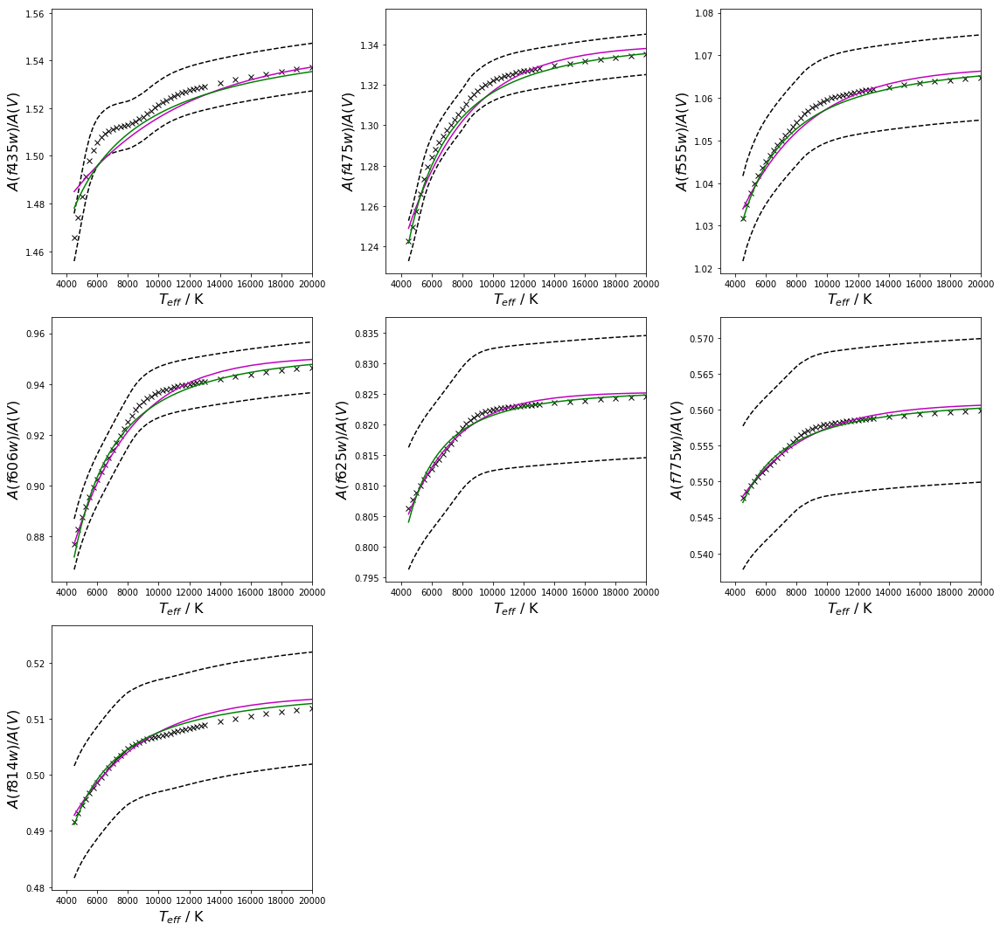


    Writing complete for log(g) = 4.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 3.5
Exponential fit coefficients (should be reused): 
[-0.1087 -1.3237  1.5449]
Standard deviations (should be reused): 
[ 0.0145  0.2132  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0387 -0.8816  1.5563]
Standard deviations (should be reused): 
[ 0.0083  0.2089  0.0071]
Logistic fit coefficients: 
[  2.4856e-16   1.6571e+00   1.5442e+00   1.3655e+00]
Standard deviations: 
[  1.8970e+04   8.5384e-01   2.4441e-03   3.4908e-01]
Teff log-normal fit coefficients: 
[-2.      0.8394  1.5141  1.4784]
Standard deviations: 
[ 0.      0.2291  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


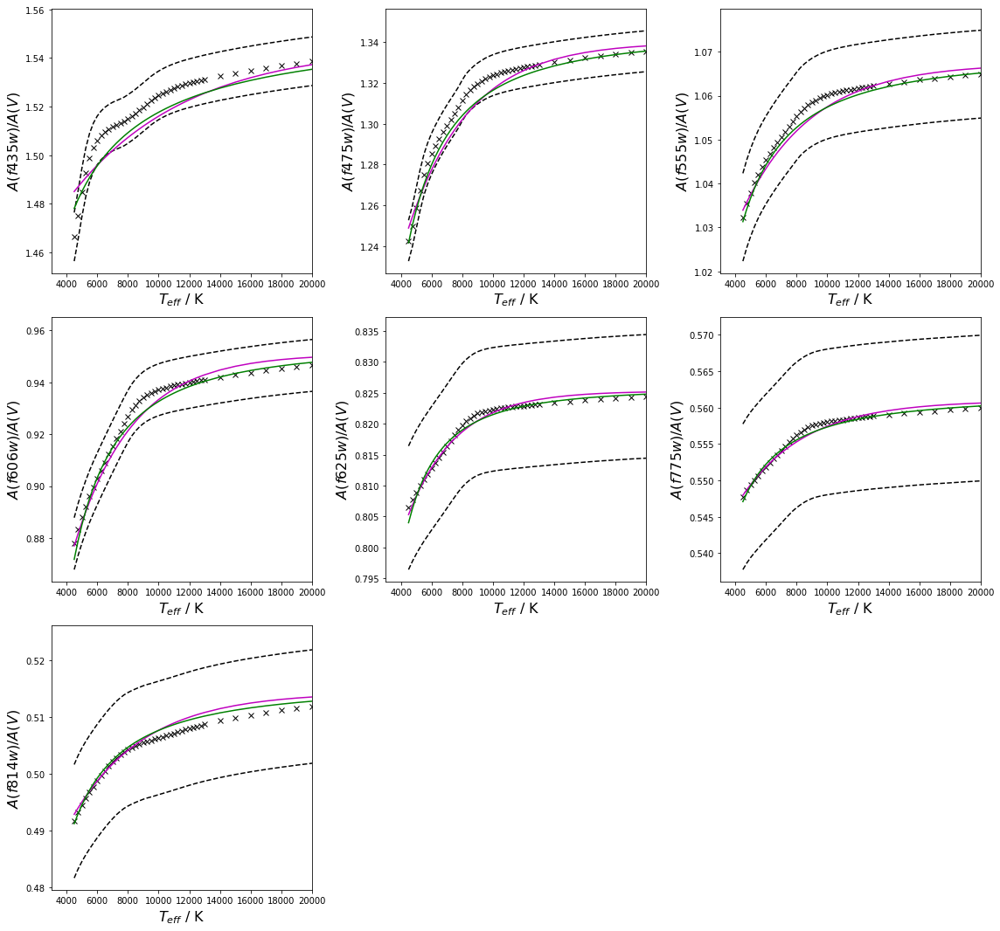


    Writing complete for log(g) = 3.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 3.0
Exponential fit coefficients (should be reused): 
[-0.1087 -1.3237  1.5449]
Standard deviations (should be reused): 
[ 0.0145  0.2132  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0387 -0.8816  1.5563]
Standard deviations (should be reused): 
[ 0.0083  0.2089  0.0071]
Logistic fit coefficients: 
[  2.4856e-16   1.6571e+00   1.5442e+00   1.3655e+00]
Standard deviations: 
[  1.8970e+04   8.5384e-01   2.4441e-03   3.4908e-01]
Teff log-normal fit coefficients: 
[-2.      0.8394  1.5141  1.4784]
Standard deviations: 
[ 0.      0.2291  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


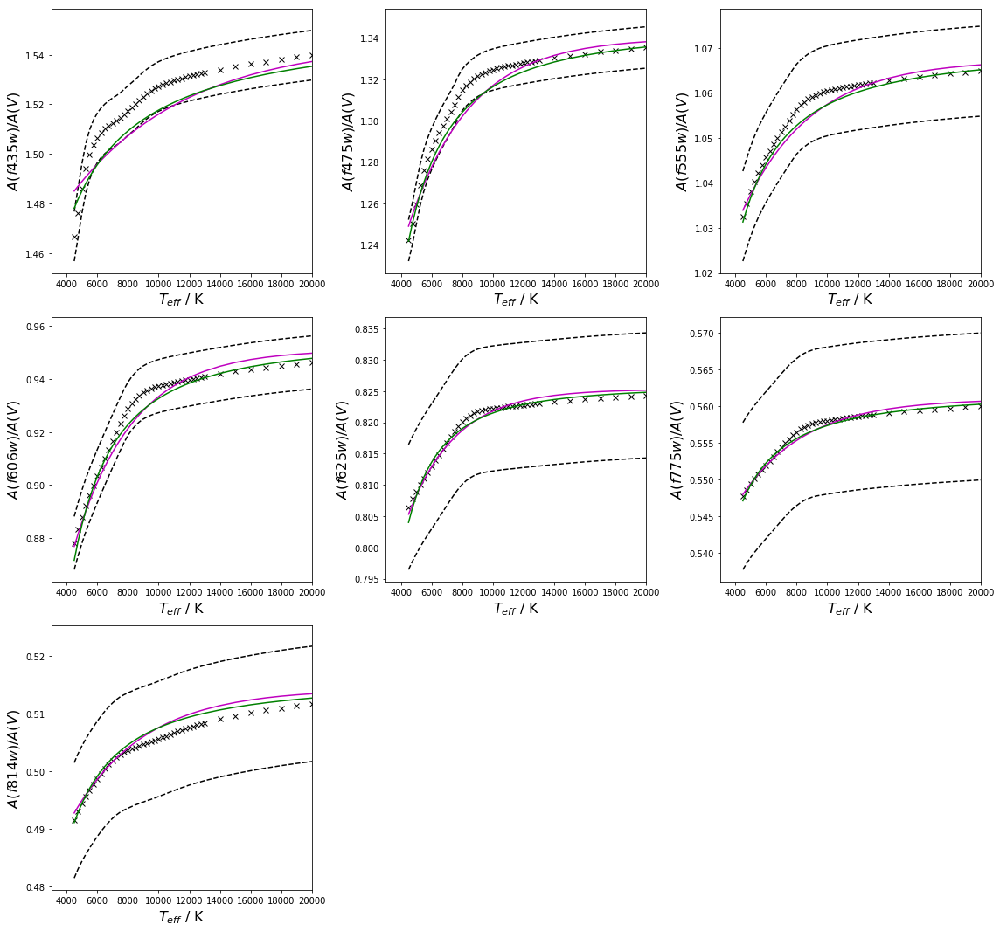


    Writing complete for log(g) = 3.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 2.5
Exponential fit coefficients (should be reused): 
[-0.1087 -1.3237  1.5449]
Standard deviations (should be reused): 
[ 0.0145  0.2132  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0387 -0.8816  1.5563]
Standard deviations (should be reused): 
[ 0.0083  0.2089  0.0071]
Logistic fit coefficients: 
[  2.4856e-16   1.6571e+00   1.5442e+00   1.3655e+00]
Standard deviations: 
[  1.8970e+04   8.5384e-01   2.4441e-03   3.4908e-01]
Teff log-normal fit coefficients: 
[-2.      0.8394  1.5141  1.4784]
Standard deviations: 
[ 0.      0.2291  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


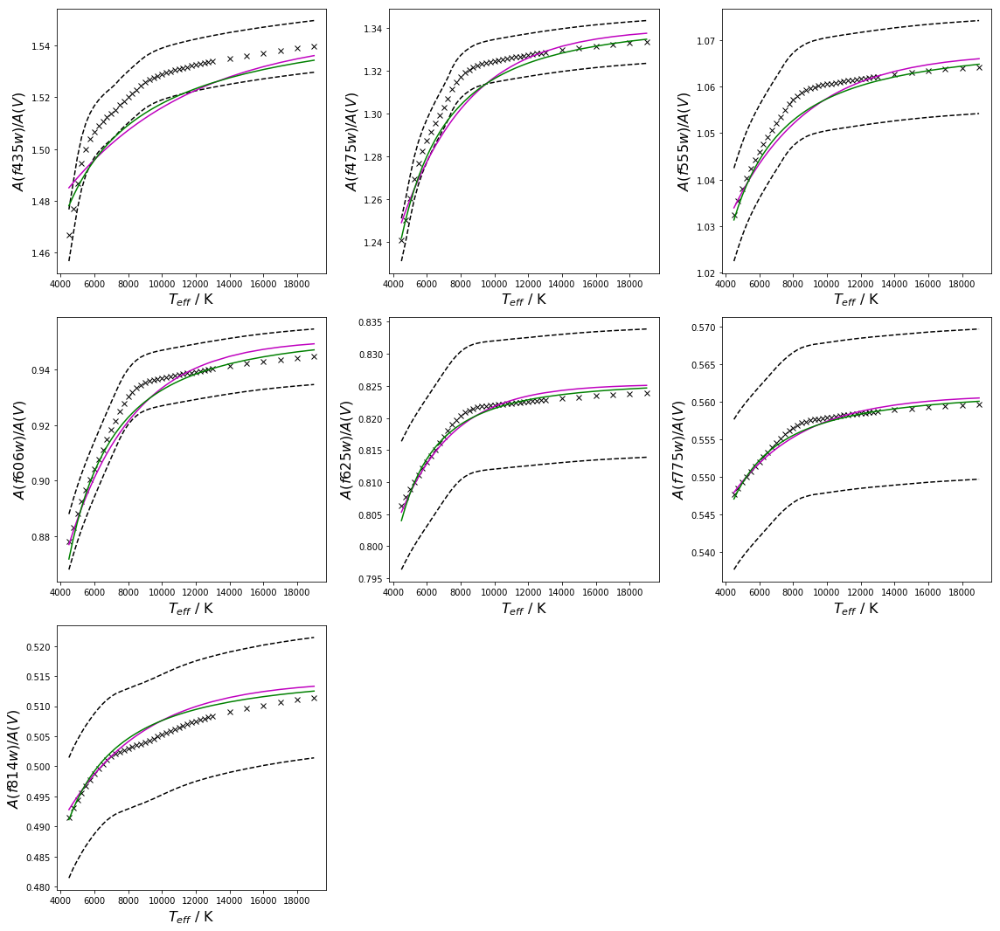


    Writing complete for log(g) = 2.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 2.0
Exponential fit coefficients (should be reused): 
[-0.1087 -1.3237  1.5449]
Standard deviations (should be reused): 
[ 0.0145  0.2132  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0387 -0.8816  1.5563]
Standard deviations (should be reused): 
[ 0.0083  0.2089  0.0071]
Logistic fit coefficients: 
[  2.4856e-16   1.6571e+00   1.5442e+00   1.3655e+00]
Standard deviations: 
[  1.8970e+04   8.5384e-01   2.4441e-03   3.4908e-01]
Teff log-normal fit coefficients: 
[-2.      0.8394  1.5141  1.4784]
Standard deviations: 
[ 0.      0.2291  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


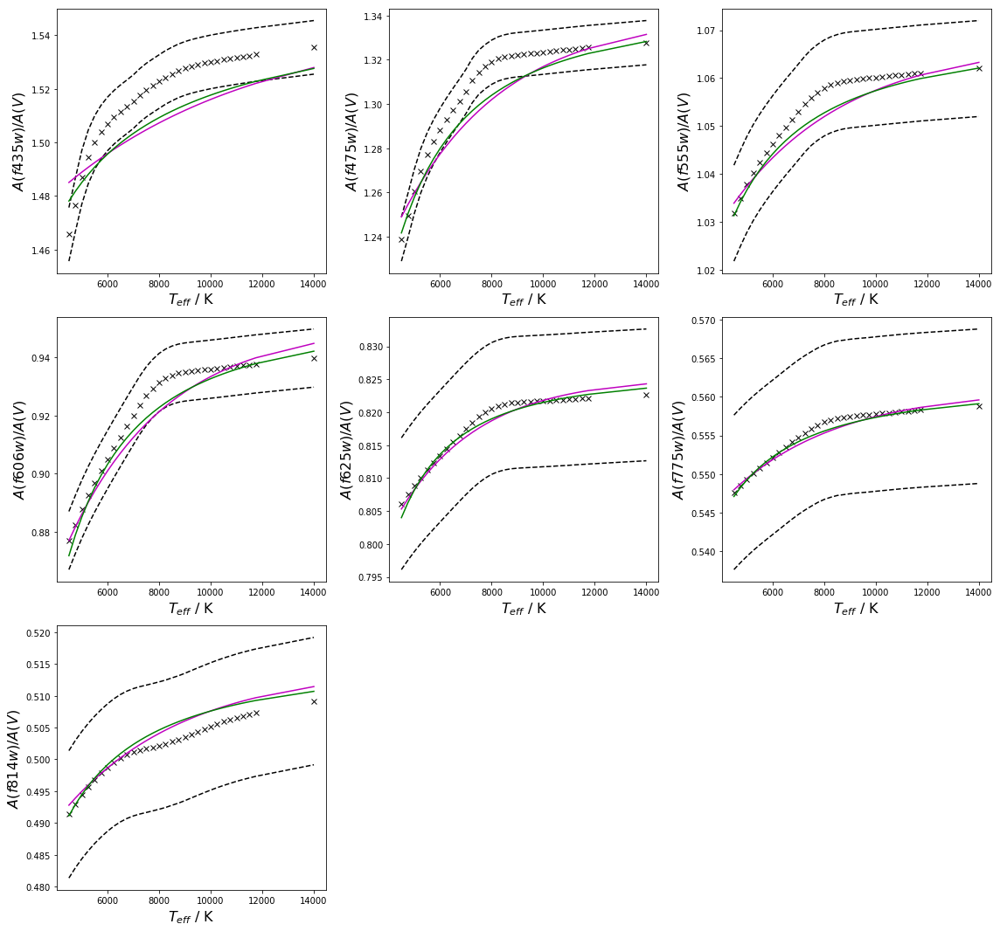


    Writing complete for log(g) = 2.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 1.5
Exponential fit coefficients (should be reused): 
[-0.1087 -1.3237  1.5449]
Standard deviations (should be reused): 
[ 0.0145  0.2132  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0387 -0.8816  1.5563]
Standard deviations (should be reused): 
[ 0.0083  0.2089  0.0071]
Logistic fit coefficients: 
[  2.4856e-16   1.6571e+00   1.5442e+00   1.3655e+00]
Standard deviations: 
[  1.8970e+04   8.5384e-01   2.4441e-03   3.4908e-01]
Teff log-normal fit coefficients: 
[-2.      0.8394  1.5141  1.4784]
Standard deviations: 
[ 0.      0.2291  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


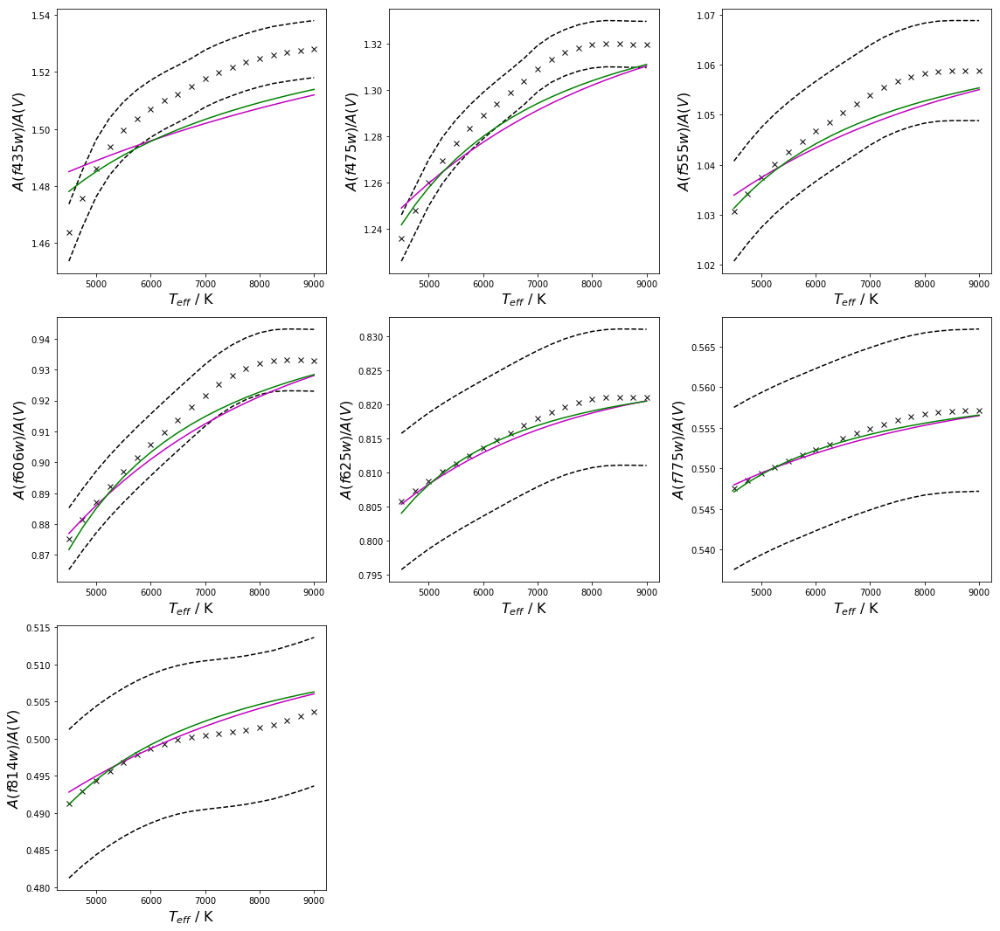


    Writing complete for log(g) = 1.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 1.0
Exponential fit coefficients (should be reused): 
[-0.1087 -1.3237  1.5449]
Standard deviations (should be reused): 
[ 0.0145  0.2132  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0387 -0.8816  1.5563]
Standard deviations (should be reused): 
[ 0.0083  0.2089  0.0071]
Logistic fit coefficients: 
[  2.4856e-16   1.6571e+00   1.5442e+00   1.3655e+00]
Standard deviations: 
[  1.8970e+04   8.5384e-01   2.4441e-03   3.4908e-01]
Teff log-normal fit coefficients: 
[-2.      0.8394  1.5141  1.4784]
Standard deviations: 
[ 0.      0.2291  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


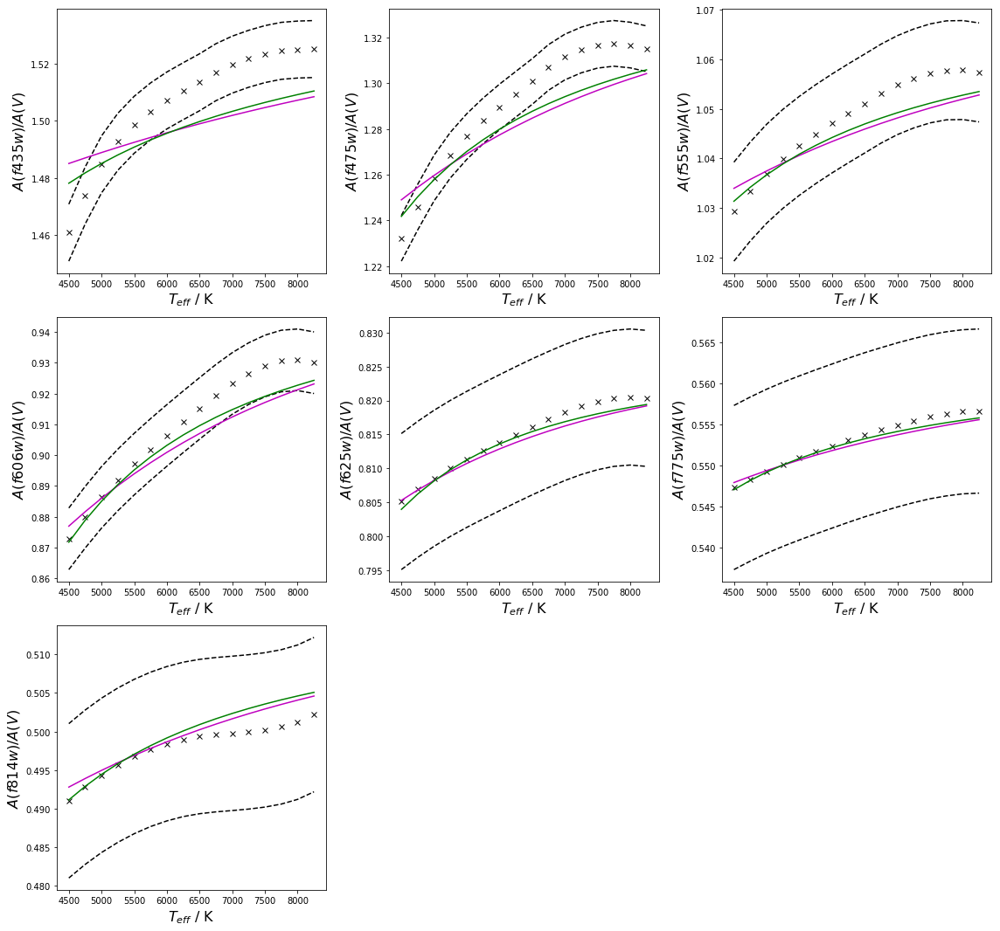


    Writing complete for log(g) = 1.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 0.5
Exponential fit coefficients (should be reused): 
[-0.1087 -1.3237  1.5449]
Standard deviations (should be reused): 
[ 0.0145  0.2132  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0387 -0.8816  1.5563]
Standard deviations (should be reused): 
[ 0.0083  0.2089  0.0071]
Logistic fit coefficients: 
[  2.4856e-16   1.6571e+00   1.5442e+00   1.3655e+00]
Standard deviations: 
[  1.8970e+04   8.5384e-01   2.4441e-03   3.4908e-01]
Teff log-normal fit coefficients: 
[-2.      0.8394  1.5141  1.4784]
Standard deviations: 
[ 0.      0.2291  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


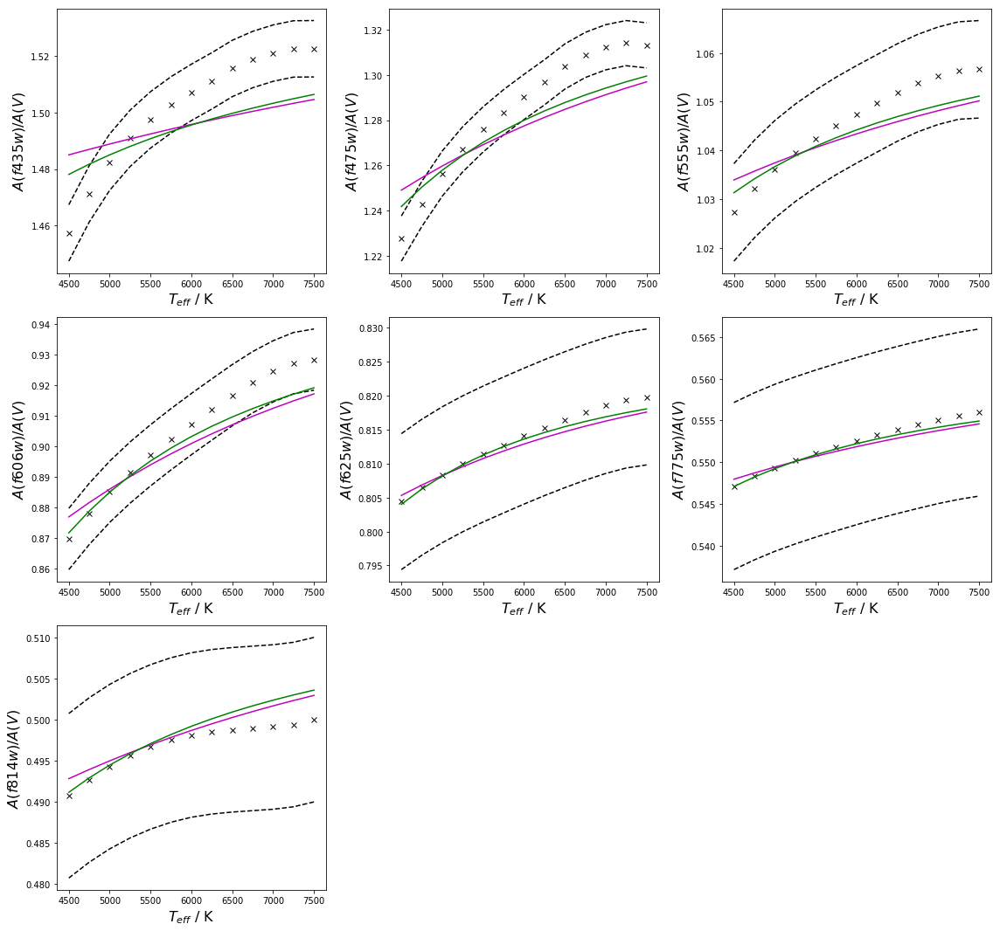


    Writing complete for log(g) = 0.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,-2.0 , 0.0
Exponential fit coefficients (should be reused): 
[-0.1087 -1.3237  1.5449]
Standard deviations (should be reused): 
[ 0.0145  0.2132  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0387 -0.8816  1.5563]
Standard deviations (should be reused): 
[ 0.0083  0.2089  0.0071]
Logistic fit coefficients: 
[  2.4856e-16   1.6571e+00   1.5442e+00   1.3655e+00]
Standard deviations: 
[  1.8970e+04   8.5384e-01   2.4441e-03   3.4908e-01]
Teff log-normal fit coefficients: 
[-2.      0.8394  1.5141  1.4784]
Standard deviations: 
[ 0.      0.2291  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


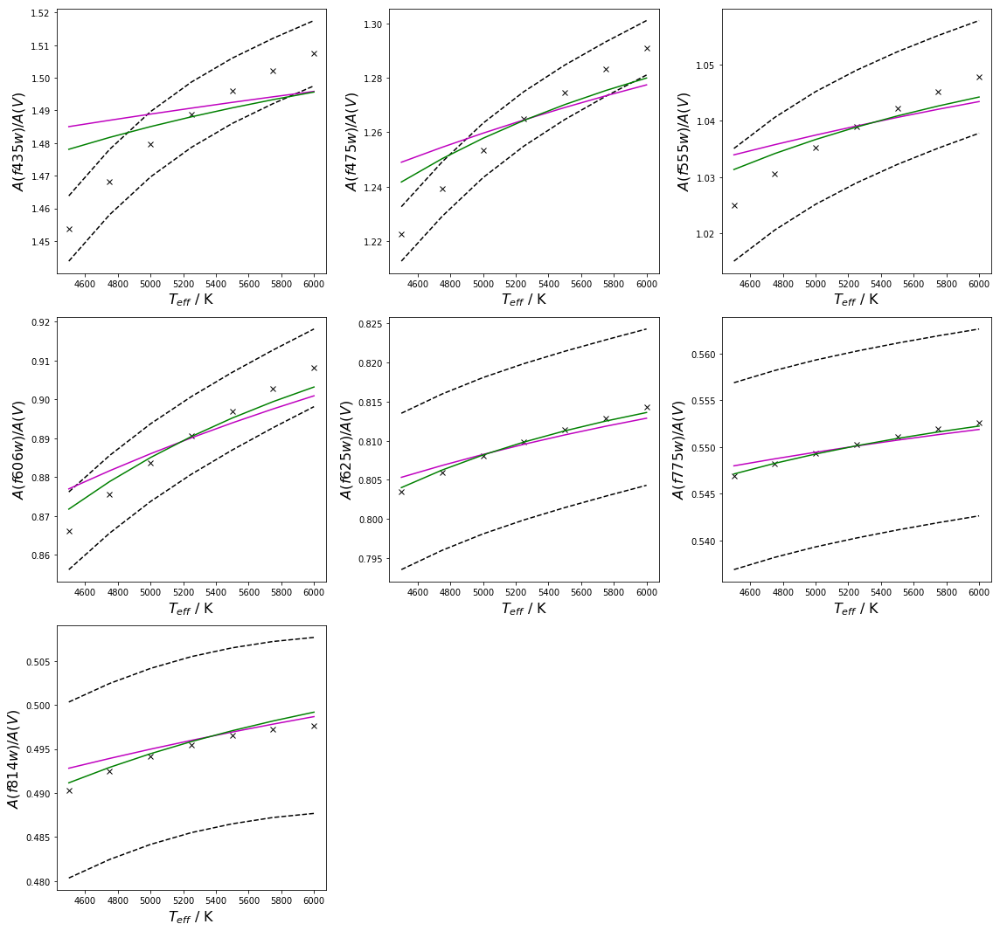


    Writing complete for log(g) = 0.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 5.0

    Writing log(g)=5.0, FeH = 0p0, Rv = 2p0 model for f435w ACS filter
Average fractional error for Exponential function of Teff, fitted = 0.080222190119
Average fractional error for Power law of Teff, fitted = 0.087014798171

    Writing log(g)=5.0, FeH = 0p0, Rv = 2p0 model for f475w ACS filter
Average fractional error for Exponential function of Teff, fitted = 0.0779761662258
Average fractional error for Power law of Teff, fitted = 0.0770741958426

    Writing log(g)=5.0, FeH = 0p0, Rv = 2p0 model for f555w ACS filter
Average fractional error for Exponential function of Teff, fitted = 0.198901006101
Average fractional error for Power law of Teff, fitted = 0.194274240277

    Writing log(g)=5.0, FeH = 0p0, Rv = 2p0 model for f606w ACS filter
Average fractional error for Exponential function of Teff, fitted = 0.102607109887
Average fractional error for Power law of Teff, fitted 

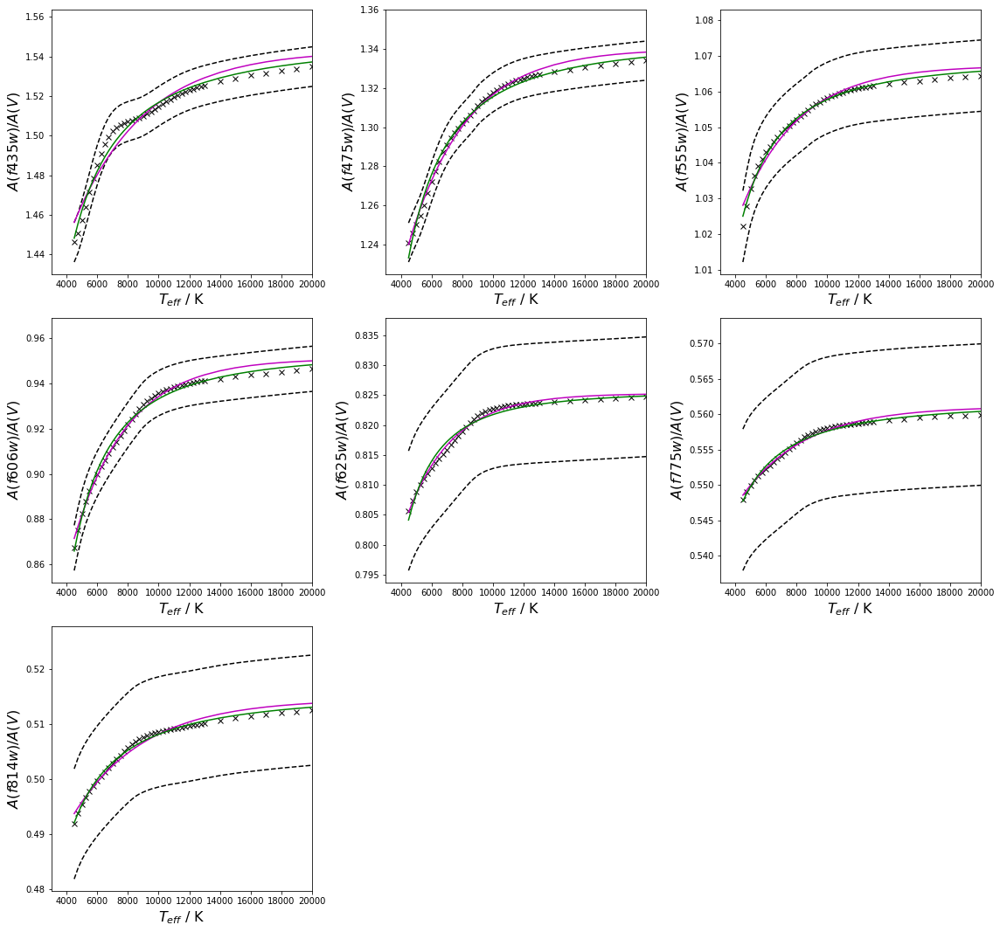


    Writing complete for log(g) = 5.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 4.5
Exponential fit coefficients (should be reused): 
[-0.2296 -2.1597  1.5431]
Standard deviations (should be reused): 
[ 0.031   0.2251  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0327 -1.4141  1.5495]
Standard deviations (should be reused): 
[ 0.0045  0.1731  0.0033]
Logistic fit coefficients: 
[  7.5643e-14   2.5462e+00   1.5425e+00   1.1908e+00]
Standard deviations: 
[  1.1997e+04   8.7159e-01   1.9129e-03   7.3385e-01]
Teff log-normal fit coefficients: 
[-2.      0.5602  1.5092  1.4712]
Standard deviations: 
[ 0.      0.0965  0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


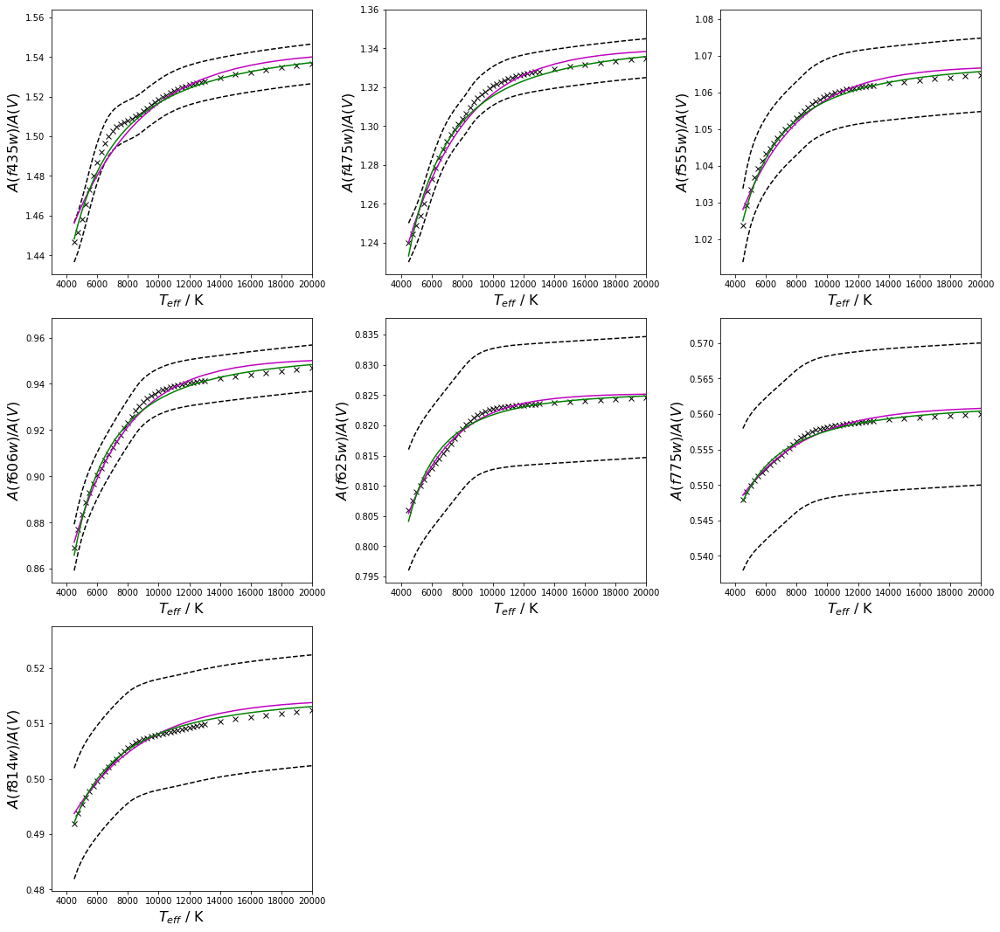


    Writing complete for log(g) = 4.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 4.0
Exponential fit coefficients (should be reused): 
[-0.2296 -2.1597  1.5431]
Standard deviations (should be reused): 
[ 0.031   0.2251  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0327 -1.4141  1.5495]
Standard deviations (should be reused): 
[ 0.0045  0.1731  0.0033]
Logistic fit coefficients: 
[  7.5643e-14   2.5462e+00   1.5425e+00   1.1908e+00]
Standard deviations: 
[  1.1997e+04   8.7159e-01   1.9129e-03   7.3385e-01]
Teff log-normal fit coefficients: 
[-2.      0.5602  1.5092  1.4712]
Standard deviations: 
[ 0.      0.0965  0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


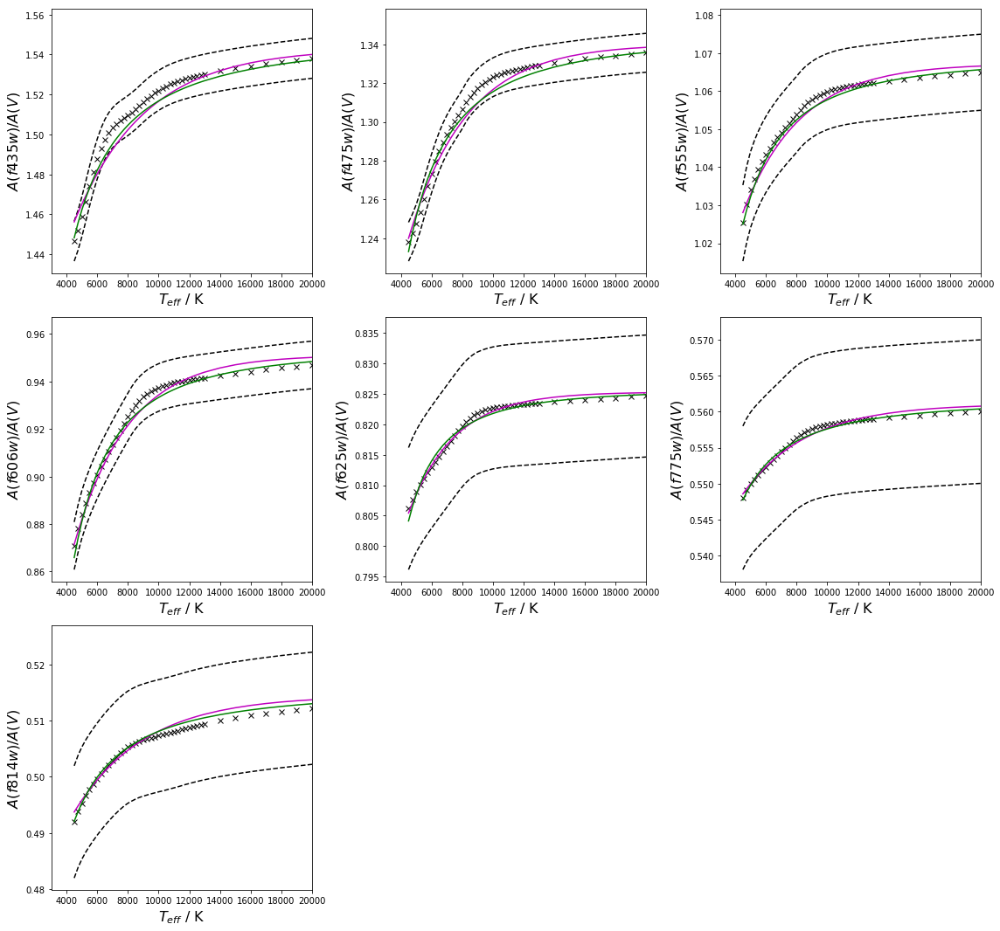


    Writing complete for log(g) = 4.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 3.5
Exponential fit coefficients (should be reused): 
[-0.2296 -2.1597  1.5431]
Standard deviations (should be reused): 
[ 0.031   0.2251  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0327 -1.4141  1.5495]
Standard deviations (should be reused): 
[ 0.0045  0.1731  0.0033]
Logistic fit coefficients: 
[  7.5643e-14   2.5462e+00   1.5425e+00   1.1908e+00]
Standard deviations: 
[  1.1997e+04   8.7159e-01   1.9129e-03   7.3385e-01]
Teff log-normal fit coefficients: 
[-2.      0.5602  1.5092  1.4712]
Standard deviations: 
[ 0.      0.0965  0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


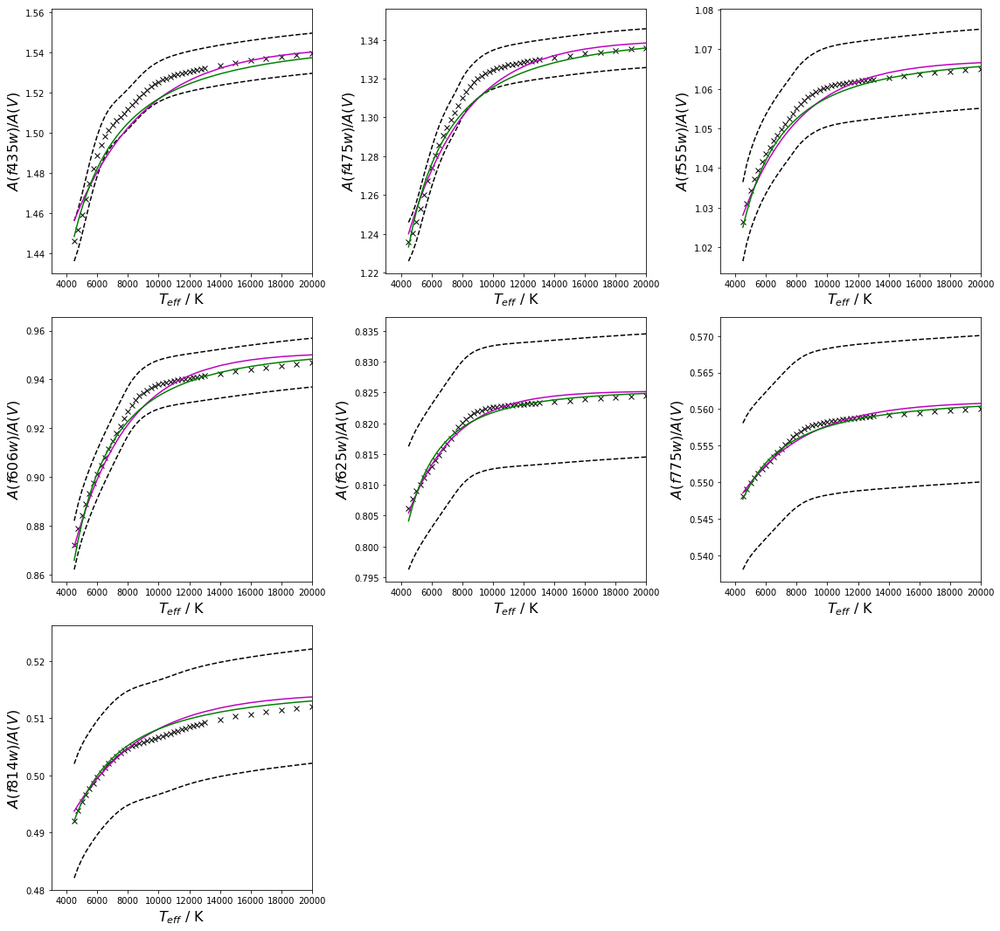


    Writing complete for log(g) = 3.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 3.0
Exponential fit coefficients (should be reused): 
[-0.2296 -2.1597  1.5431]
Standard deviations (should be reused): 
[ 0.031   0.2251  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0327 -1.4141  1.5495]
Standard deviations (should be reused): 
[ 0.0045  0.1731  0.0033]
Logistic fit coefficients: 
[  7.5643e-14   2.5462e+00   1.5425e+00   1.1908e+00]
Standard deviations: 
[  1.1997e+04   8.7159e-01   1.9129e-03   7.3385e-01]
Teff log-normal fit coefficients: 
[-2.      0.5602  1.5092  1.4712]
Standard deviations: 
[ 0.      0.0965  0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


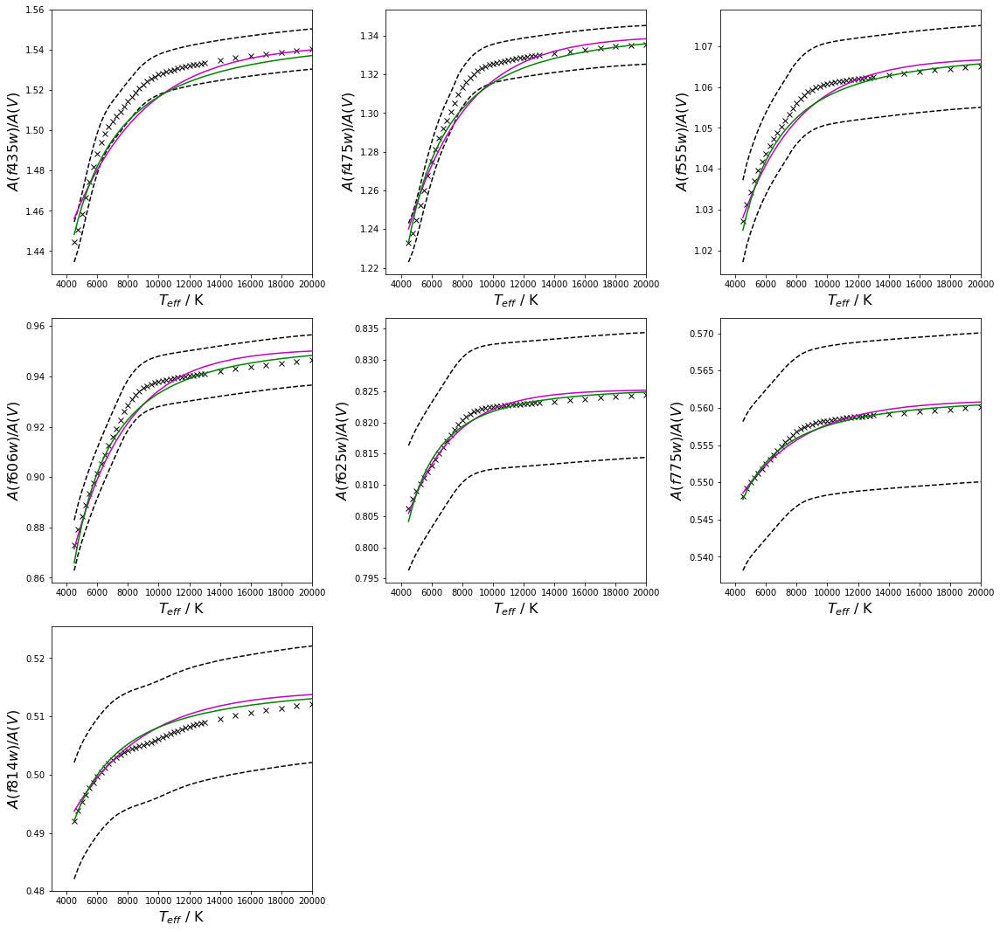


    Writing complete for log(g) = 3.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 2.5
Exponential fit coefficients (should be reused): 
[-0.2296 -2.1597  1.5431]
Standard deviations (should be reused): 
[ 0.031   0.2251  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0327 -1.4141  1.5495]
Standard deviations (should be reused): 
[ 0.0045  0.1731  0.0033]
Logistic fit coefficients: 
[  7.5643e-14   2.5462e+00   1.5425e+00   1.1908e+00]
Standard deviations: 
[  1.1997e+04   8.7159e-01   1.9129e-03   7.3385e-01]
Teff log-normal fit coefficients: 
[-2.      0.5602  1.5092  1.4712]
Standard deviations: 
[ 0.      0.0965  0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


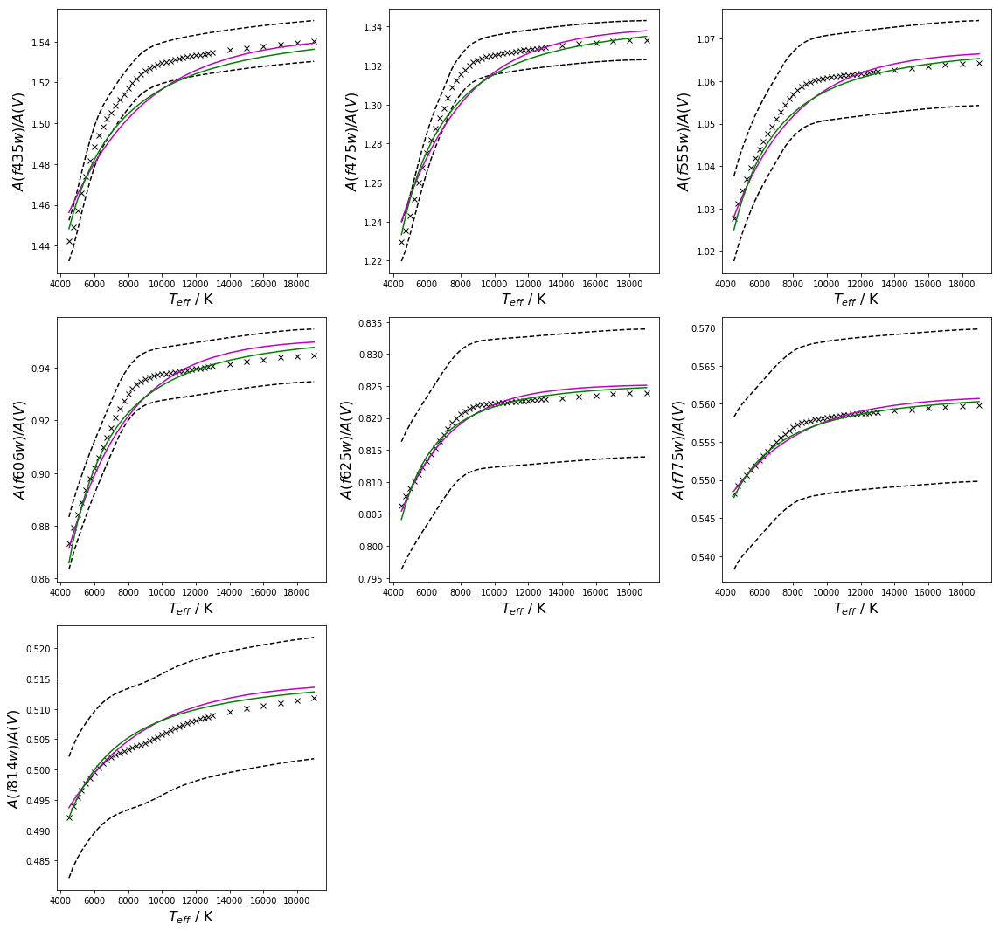


    Writing complete for log(g) = 2.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 2.0
Exponential fit coefficients (should be reused): 
[-0.2296 -2.1597  1.5431]
Standard deviations (should be reused): 
[ 0.031   0.2251  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0327 -1.4141  1.5495]
Standard deviations (should be reused): 
[ 0.0045  0.1731  0.0033]
Logistic fit coefficients: 
[  7.5643e-14   2.5462e+00   1.5425e+00   1.1908e+00]
Standard deviations: 
[  1.1997e+04   8.7159e-01   1.9129e-03   7.3385e-01]
Teff log-normal fit coefficients: 
[-2.      0.5602  1.5092  1.4712]
Standard deviations: 
[ 0.      0.0965  0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


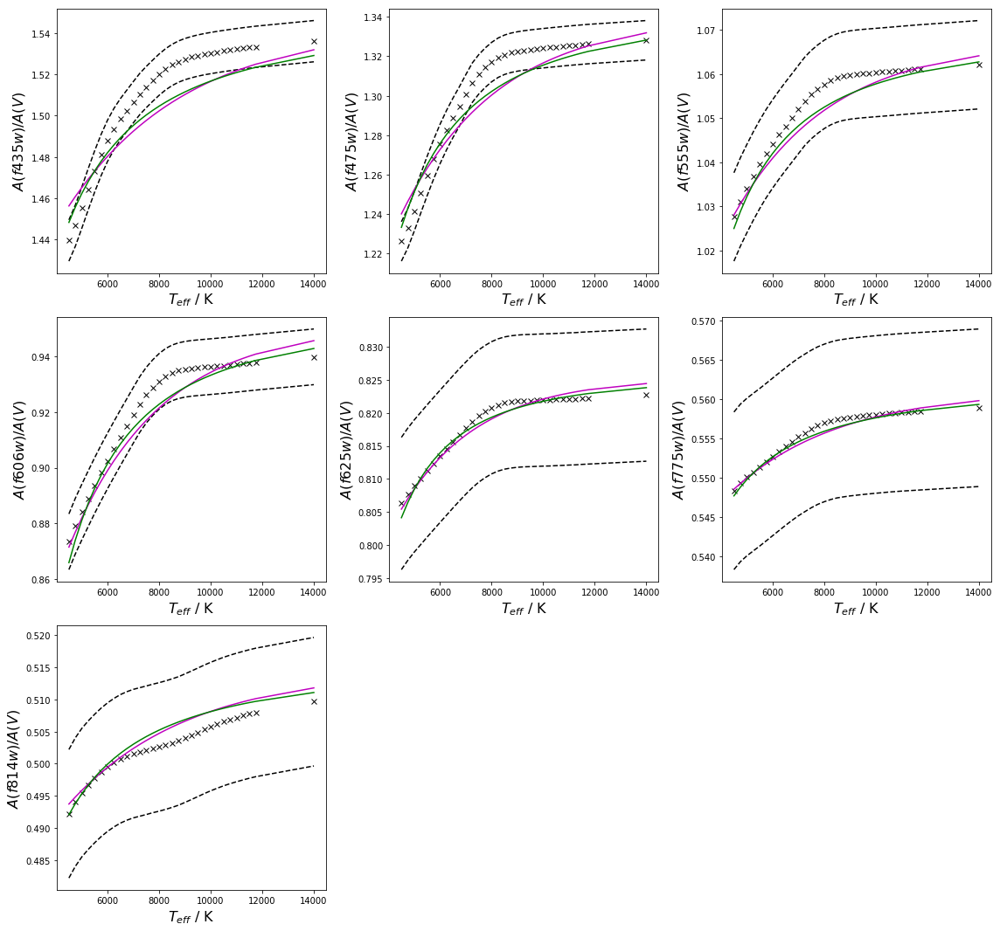


    Writing complete for log(g) = 2.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 1.5
Exponential fit coefficients (should be reused): 
[-0.2296 -2.1597  1.5431]
Standard deviations (should be reused): 
[ 0.031   0.2251  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0327 -1.4141  1.5495]
Standard deviations (should be reused): 
[ 0.0045  0.1731  0.0033]
Logistic fit coefficients: 
[  7.5643e-14   2.5462e+00   1.5425e+00   1.1908e+00]
Standard deviations: 
[  1.1997e+04   8.7159e-01   1.9129e-03   7.3385e-01]
Teff log-normal fit coefficients: 
[-2.      0.5602  1.5092  1.4712]
Standard deviations: 
[ 0.      0.0965  0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


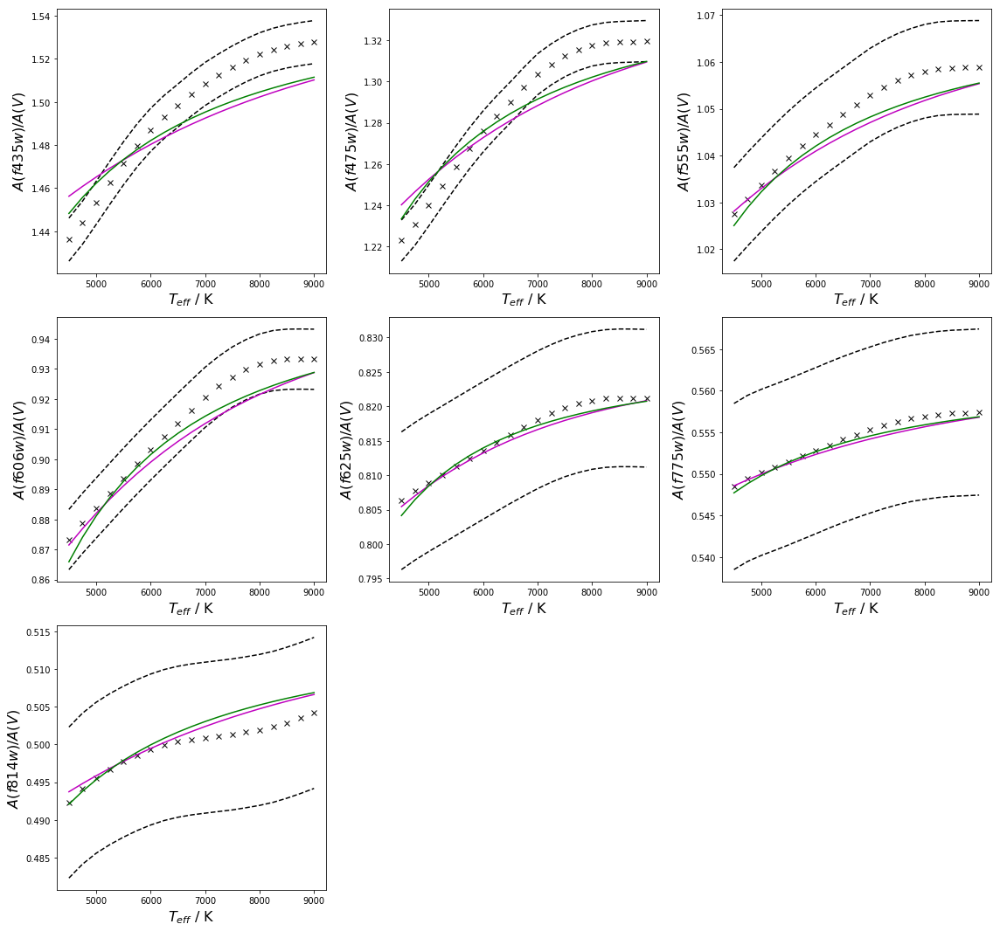


    Writing complete for log(g) = 1.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 1.0
Exponential fit coefficients (should be reused): 
[-0.2296 -2.1597  1.5431]
Standard deviations (should be reused): 
[ 0.031   0.2251  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0327 -1.4141  1.5495]
Standard deviations (should be reused): 
[ 0.0045  0.1731  0.0033]
Logistic fit coefficients: 
[  7.5643e-14   2.5462e+00   1.5425e+00   1.1908e+00]
Standard deviations: 
[  1.1997e+04   8.7159e-01   1.9129e-03   7.3385e-01]
Teff log-normal fit coefficients: 
[-2.      0.5602  1.5092  1.4712]
Standard deviations: 
[ 0.      0.0965  0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


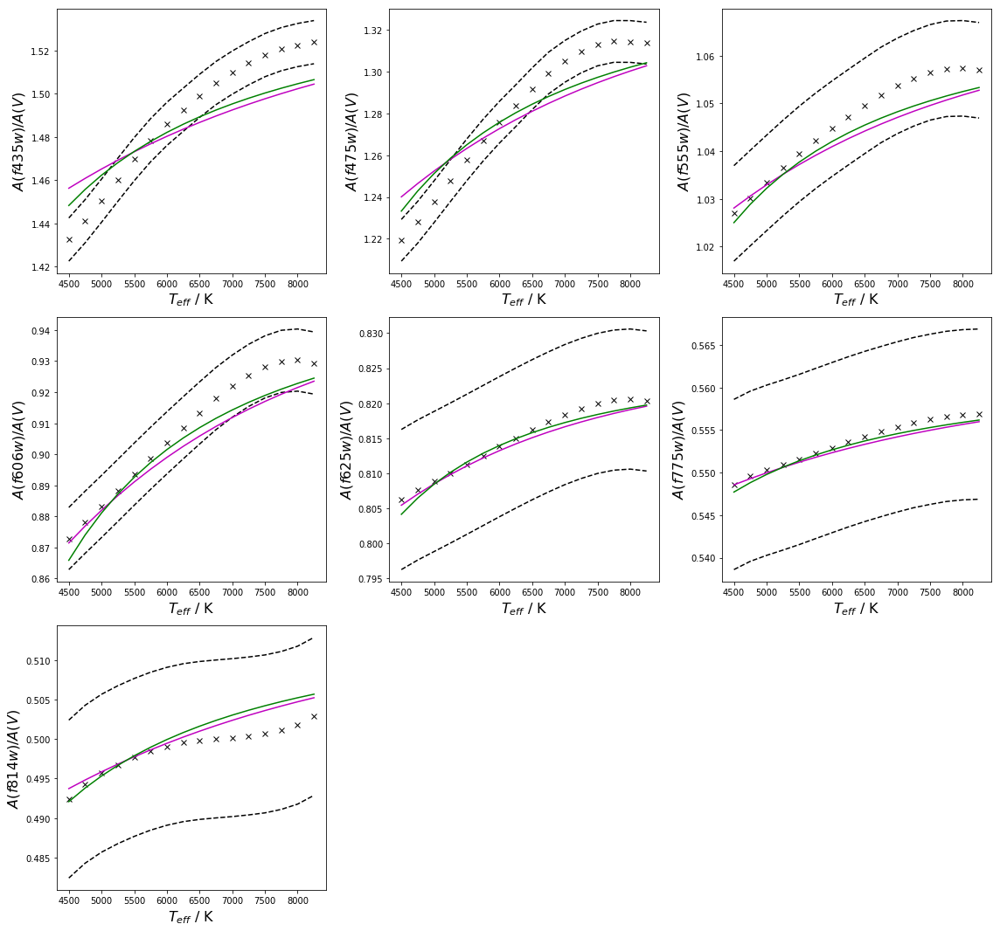


    Writing complete for log(g) = 1.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 0.5
Exponential fit coefficients (should be reused): 
[-0.2296 -2.1597  1.5431]
Standard deviations (should be reused): 
[ 0.031   0.2251  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0327 -1.4141  1.5495]
Standard deviations (should be reused): 
[ 0.0045  0.1731  0.0033]
Logistic fit coefficients: 
[  7.5643e-14   2.5462e+00   1.5425e+00   1.1908e+00]
Standard deviations: 
[  1.1997e+04   8.7159e-01   1.9129e-03   7.3385e-01]
Teff log-normal fit coefficients: 
[-2.      0.5602  1.5092  1.4712]
Standard deviations: 
[ 0.      0.0965  0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


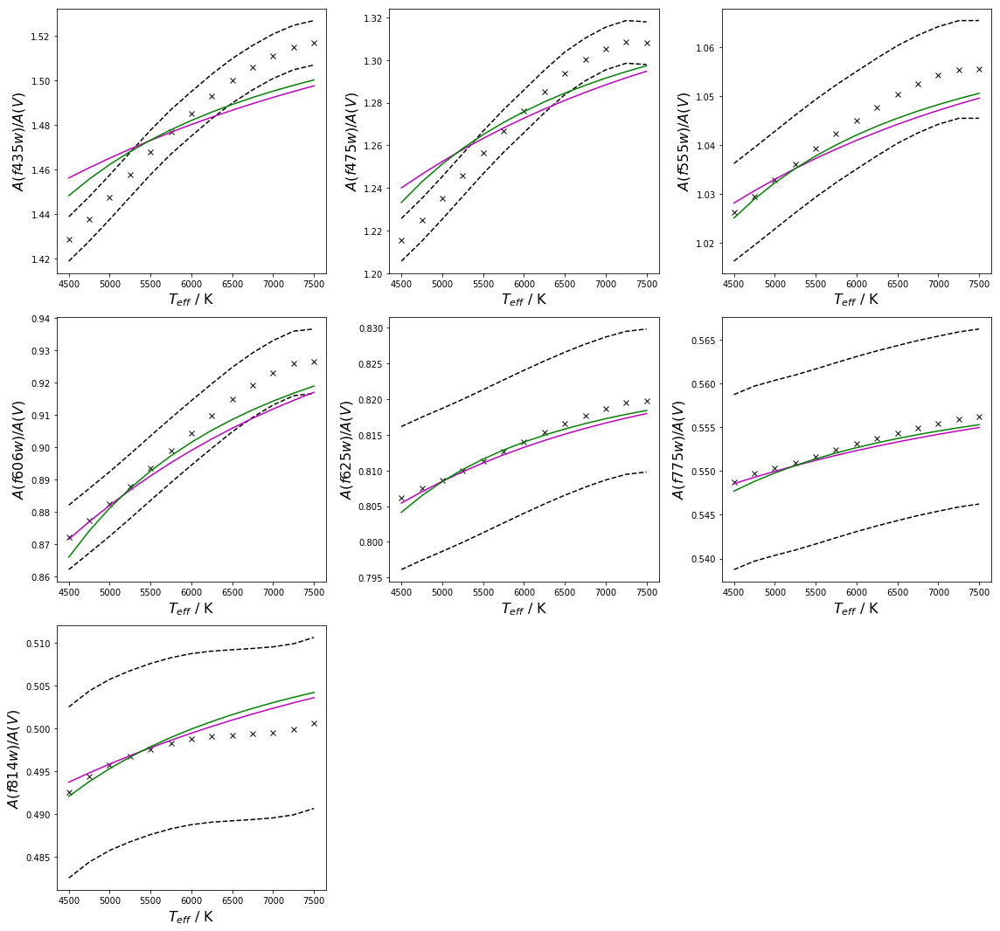


    Writing complete for log(g) = 0.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.0 , 0.0
Exponential fit coefficients (should be reused): 
[-0.2296 -2.1597  1.5431]
Standard deviations (should be reused): 
[ 0.031   0.2251  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0327 -1.4141  1.5495]
Standard deviations (should be reused): 
[ 0.0045  0.1731  0.0033]
Logistic fit coefficients: 
[  7.5643e-14   2.5462e+00   1.5425e+00   1.1908e+00]
Standard deviations: 
[  1.1997e+04   8.7159e-01   1.9129e-03   7.3385e-01]
Teff log-normal fit coefficients: 
[-2.      0.5602  1.5092  1.4712]
Standard deviations: 
[ 0.      0.0965  0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


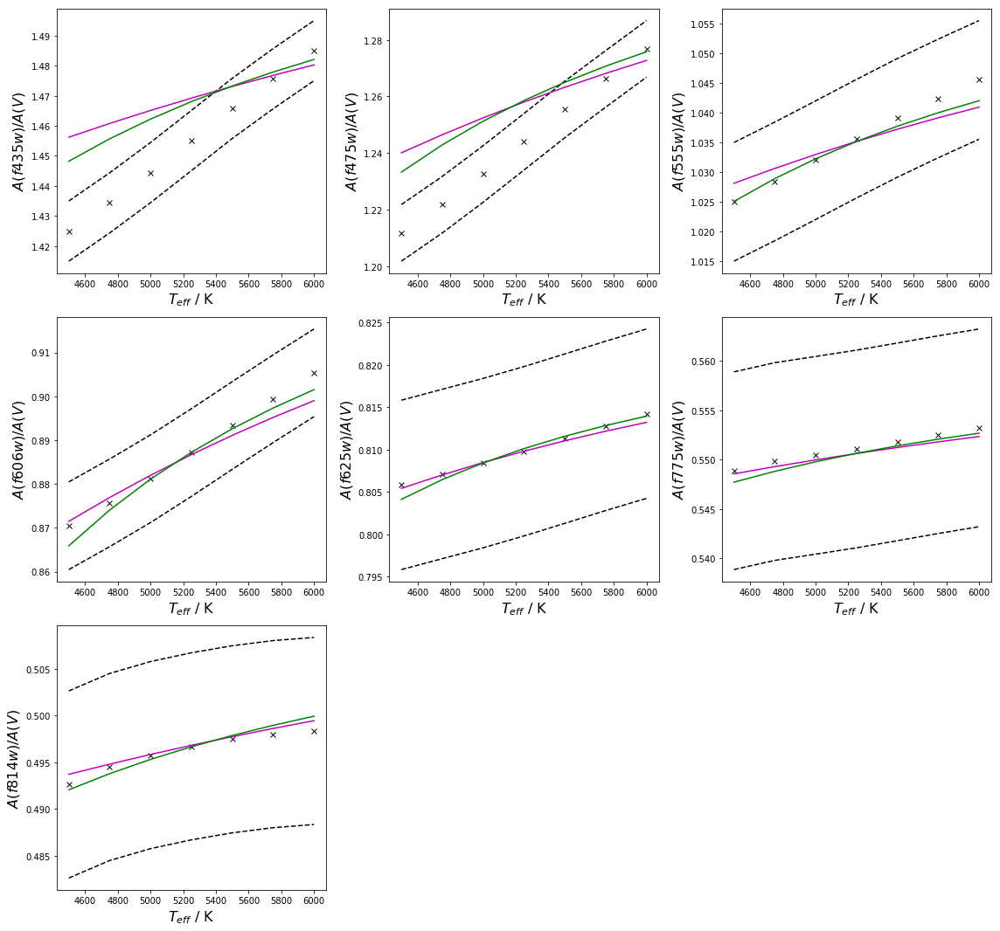


    Writing complete for log(g) = 0.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 5.0
Deleting missing subplots - discrepancy between 7 and 9


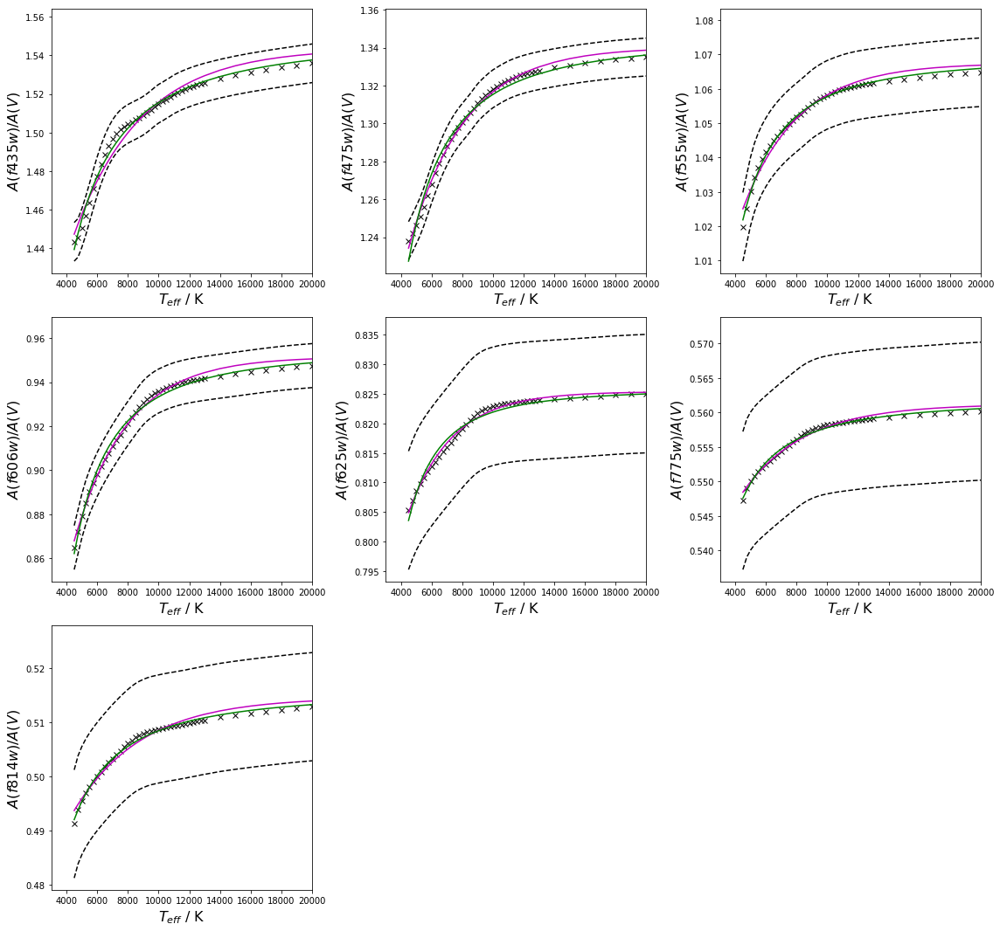


    Writing complete for log(g) = 5.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 4.5
Exponential fit coefficients (should be reused): 
[-0.2653 -2.255   1.5436]
Standard deviations (should be reused): 
[ 0.0336  0.2127  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0347 -1.4543  1.5502]
Standard deviations (should be reused): 
[ 0.0043  0.1601  0.0032]
Logistic fit coefficients: 
[  2.5535e-14   2.6372e+00   1.5430e+00   1.1407e+00]
Standard deviations: 
[  1.0612e+04   7.9940e-01   1.8865e-03   7.7557e-01]
Teff log-normal fit coefficients: 
[-2.      0.5     1.5074  1.4675]
Standard deviations: 
[ 0.      0.0787  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


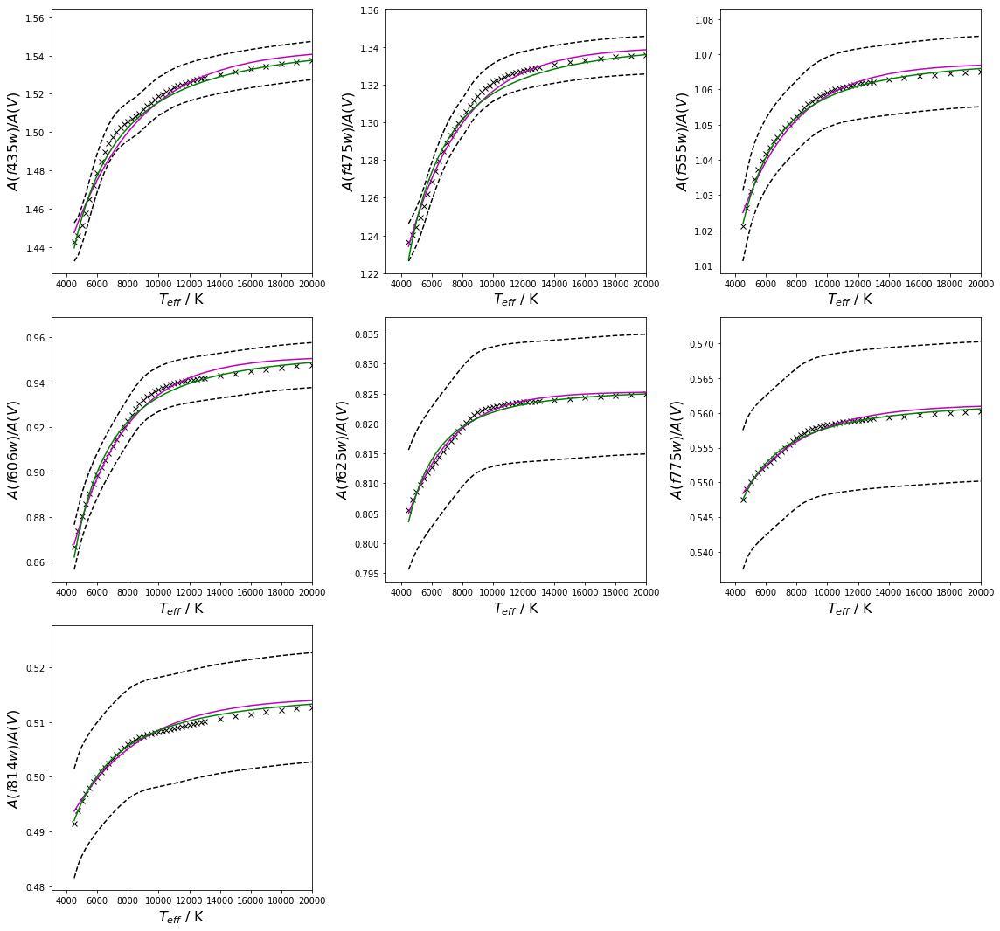


    Writing complete for log(g) = 4.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 4.0
Exponential fit coefficients (should be reused): 
[-0.2653 -2.255   1.5436]
Standard deviations (should be reused): 
[ 0.0336  0.2127  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0347 -1.4543  1.5502]
Standard deviations (should be reused): 
[ 0.0043  0.1601  0.0032]
Logistic fit coefficients: 
[  2.5535e-14   2.6372e+00   1.5430e+00   1.1407e+00]
Standard deviations: 
[  1.0612e+04   7.9940e-01   1.8865e-03   7.7557e-01]
Teff log-normal fit coefficients: 
[-2.      0.5     1.5074  1.4675]
Standard deviations: 
[ 0.      0.0787  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


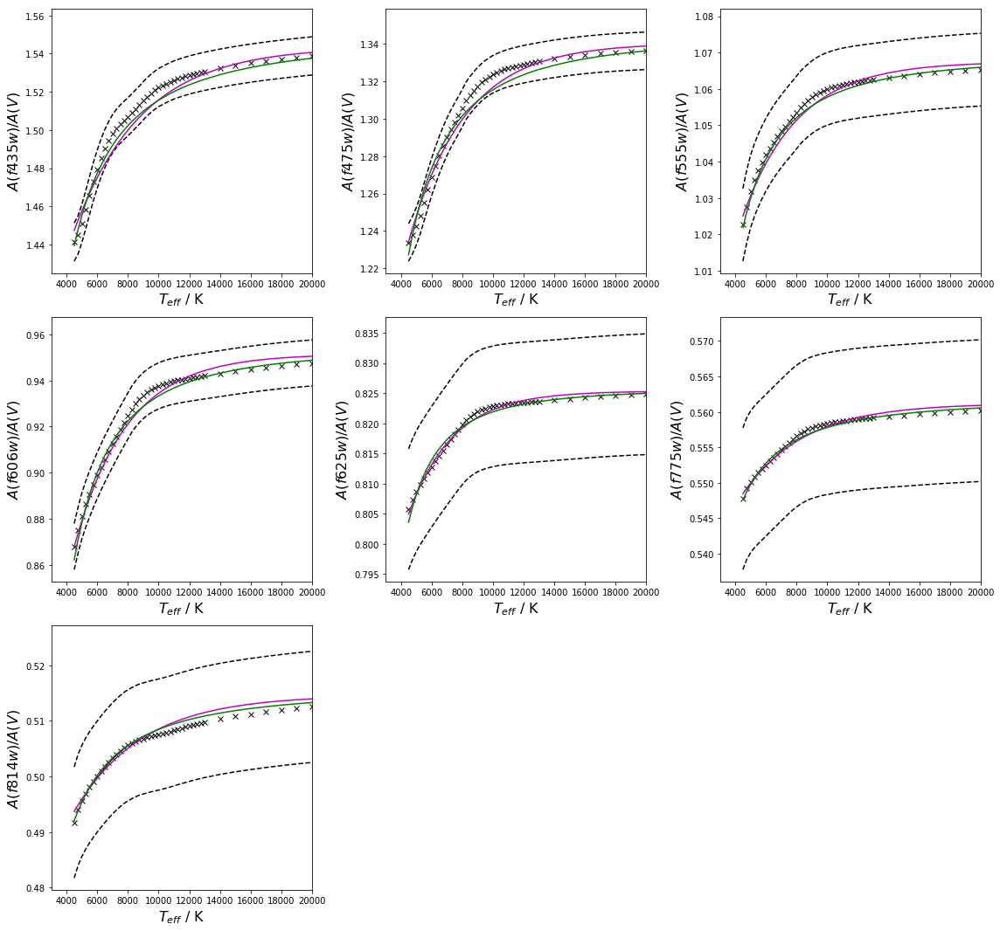


    Writing complete for log(g) = 4.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 3.5
Exponential fit coefficients (should be reused): 
[-0.2653 -2.255   1.5436]
Standard deviations (should be reused): 
[ 0.0336  0.2127  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0347 -1.4543  1.5502]
Standard deviations (should be reused): 
[ 0.0043  0.1601  0.0032]
Logistic fit coefficients: 
[  2.5535e-14   2.6372e+00   1.5430e+00   1.1407e+00]
Standard deviations: 
[  1.0612e+04   7.9940e-01   1.8865e-03   7.7557e-01]
Teff log-normal fit coefficients: 
[-2.      0.5     1.5074  1.4675]
Standard deviations: 
[ 0.      0.0787  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


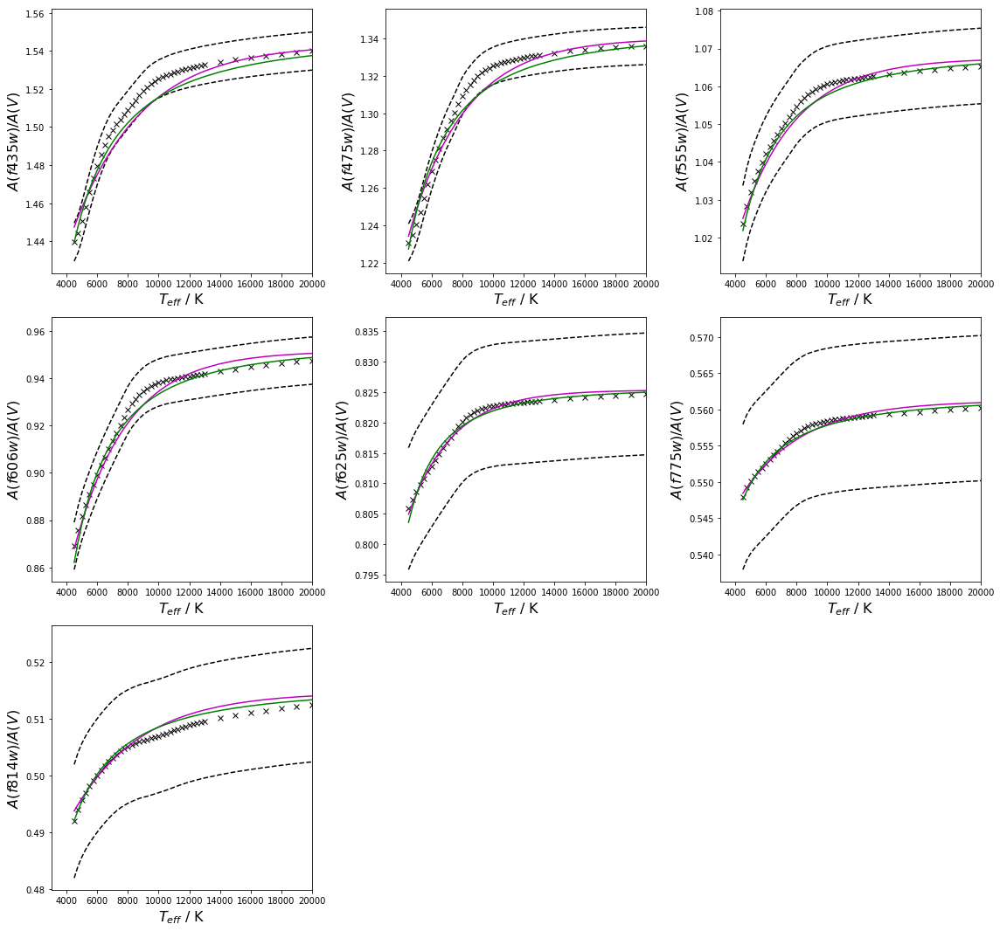


    Writing complete for log(g) = 3.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 3.0
Exponential fit coefficients (should be reused): 
[-0.2653 -2.255   1.5436]
Standard deviations (should be reused): 
[ 0.0336  0.2127  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0347 -1.4543  1.5502]
Standard deviations (should be reused): 
[ 0.0043  0.1601  0.0032]
Logistic fit coefficients: 
[  2.5535e-14   2.6372e+00   1.5430e+00   1.1407e+00]
Standard deviations: 
[  1.0612e+04   7.9940e-01   1.8865e-03   7.7557e-01]
Teff log-normal fit coefficients: 
[-2.      0.5     1.5074  1.4675]
Standard deviations: 
[ 0.      0.0787  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


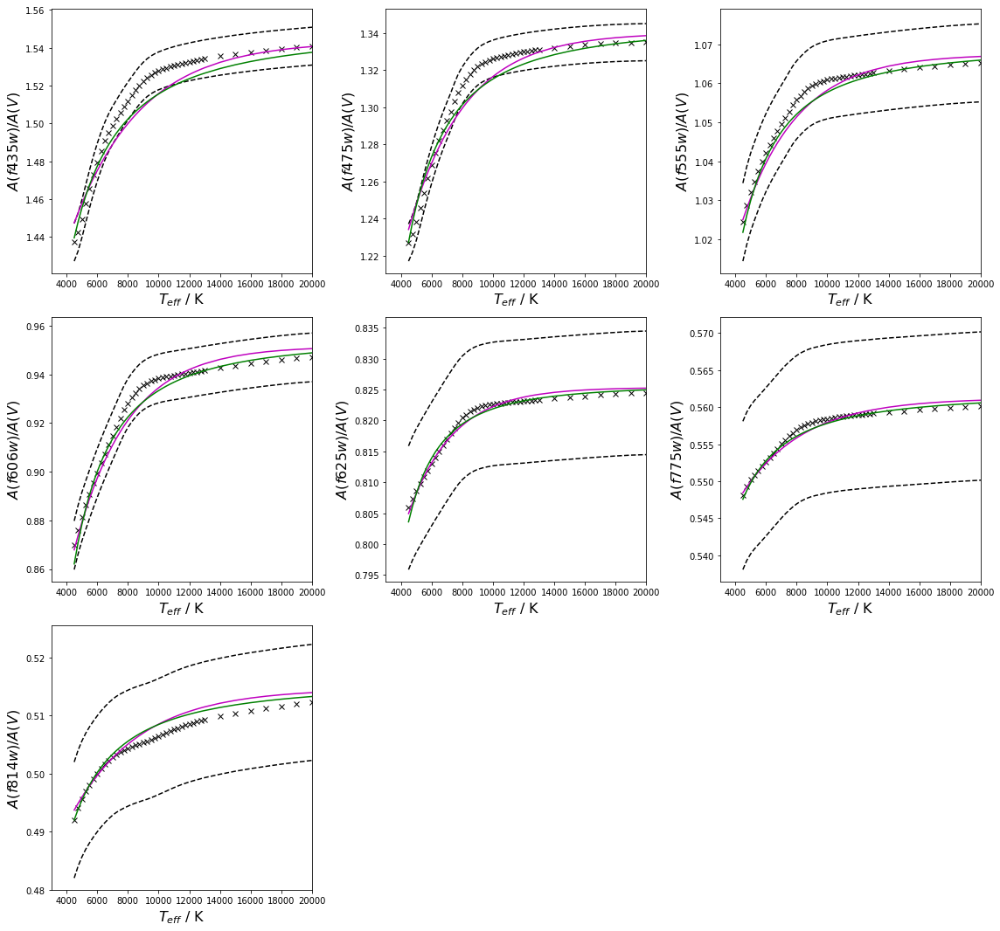


    Writing complete for log(g) = 3.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 2.5
Exponential fit coefficients (should be reused): 
[-0.2653 -2.255   1.5436]
Standard deviations (should be reused): 
[ 0.0336  0.2127  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0347 -1.4543  1.5502]
Standard deviations (should be reused): 
[ 0.0043  0.1601  0.0032]
Logistic fit coefficients: 
[  2.5535e-14   2.6372e+00   1.5430e+00   1.1407e+00]
Standard deviations: 
[  1.0612e+04   7.9940e-01   1.8865e-03   7.7557e-01]
Teff log-normal fit coefficients: 
[-2.      0.5     1.5074  1.4675]
Standard deviations: 
[ 0.      0.0787  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


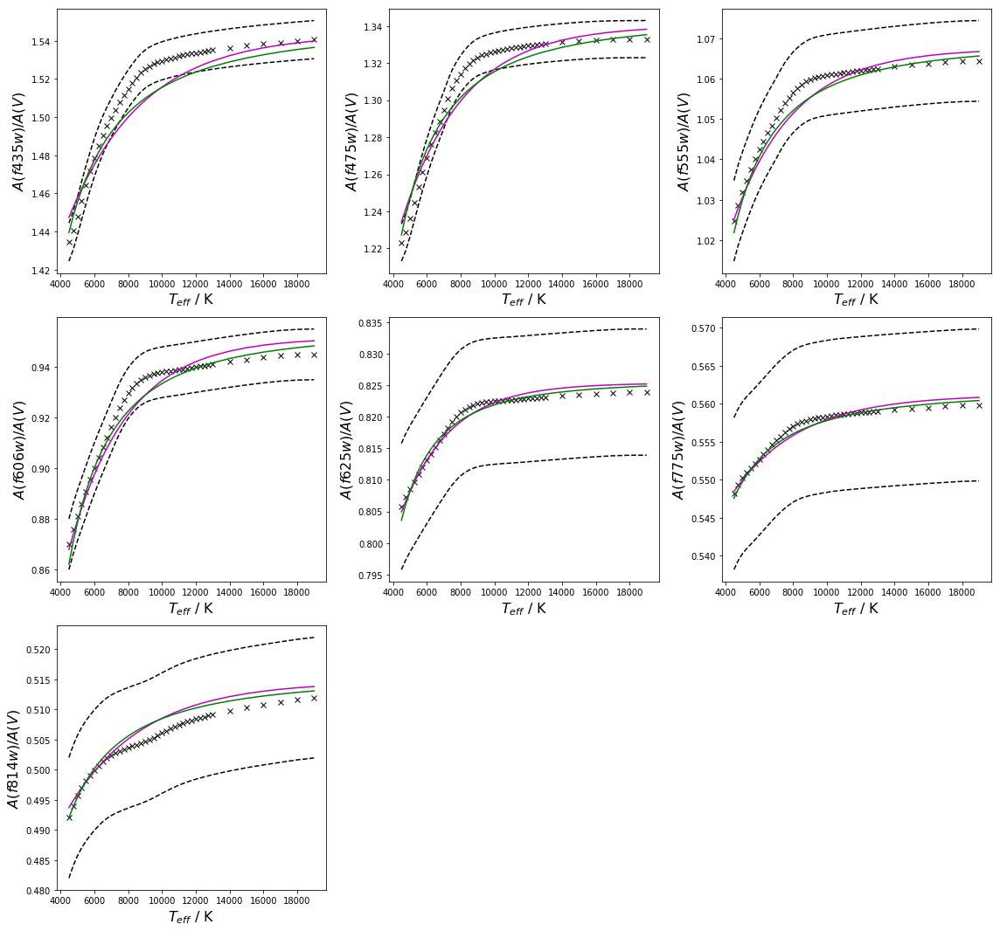


    Writing complete for log(g) = 2.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 2.0
Exponential fit coefficients (should be reused): 
[-0.2653 -2.255   1.5436]
Standard deviations (should be reused): 
[ 0.0336  0.2127  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0347 -1.4543  1.5502]
Standard deviations (should be reused): 
[ 0.0043  0.1601  0.0032]
Logistic fit coefficients: 
[  2.5535e-14   2.6372e+00   1.5430e+00   1.1407e+00]
Standard deviations: 
[  1.0612e+04   7.9940e-01   1.8865e-03   7.7557e-01]
Teff log-normal fit coefficients: 
[-2.      0.5     1.5074  1.4675]
Standard deviations: 
[ 0.      0.0787  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


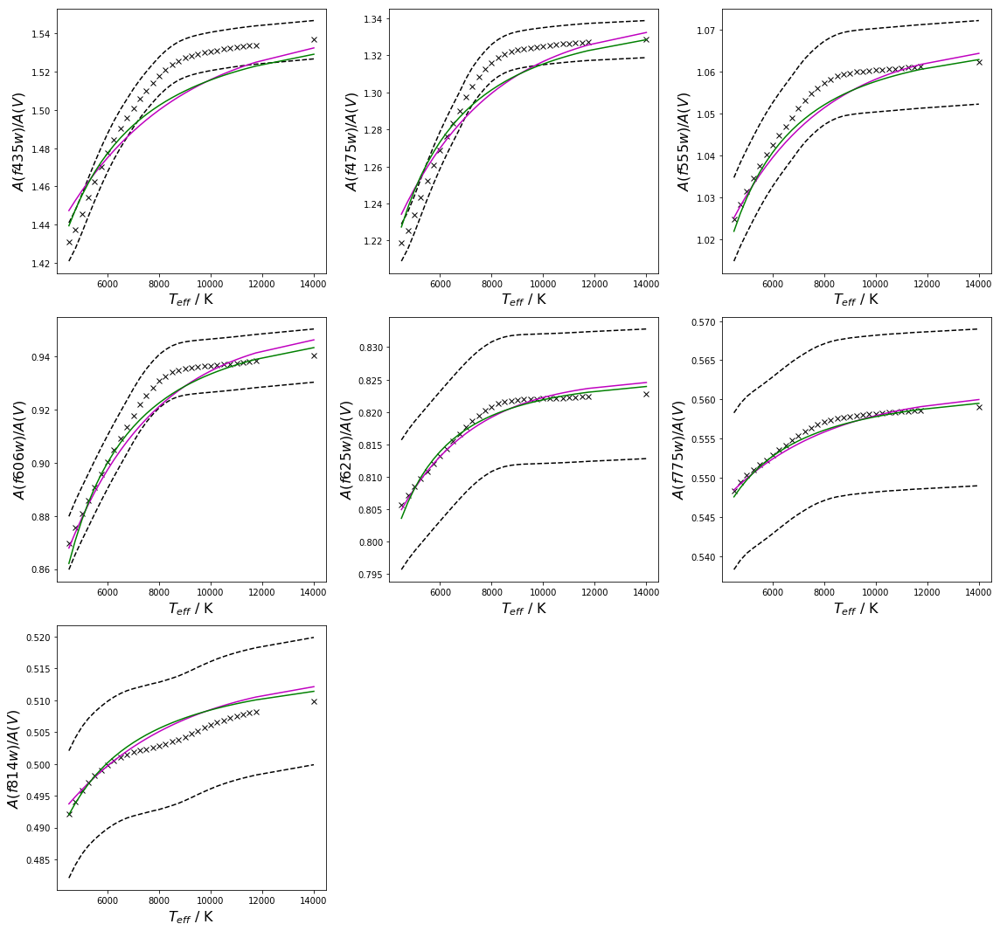


    Writing complete for log(g) = 2.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 1.5
Exponential fit coefficients (should be reused): 
[-0.2653 -2.255   1.5436]
Standard deviations (should be reused): 
[ 0.0336  0.2127  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0347 -1.4543  1.5502]
Standard deviations (should be reused): 
[ 0.0043  0.1601  0.0032]
Logistic fit coefficients: 
[  2.5535e-14   2.6372e+00   1.5430e+00   1.1407e+00]
Standard deviations: 
[  1.0612e+04   7.9940e-01   1.8865e-03   7.7557e-01]
Teff log-normal fit coefficients: 
[-2.      0.5     1.5074  1.4675]
Standard deviations: 
[ 0.      0.0787  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


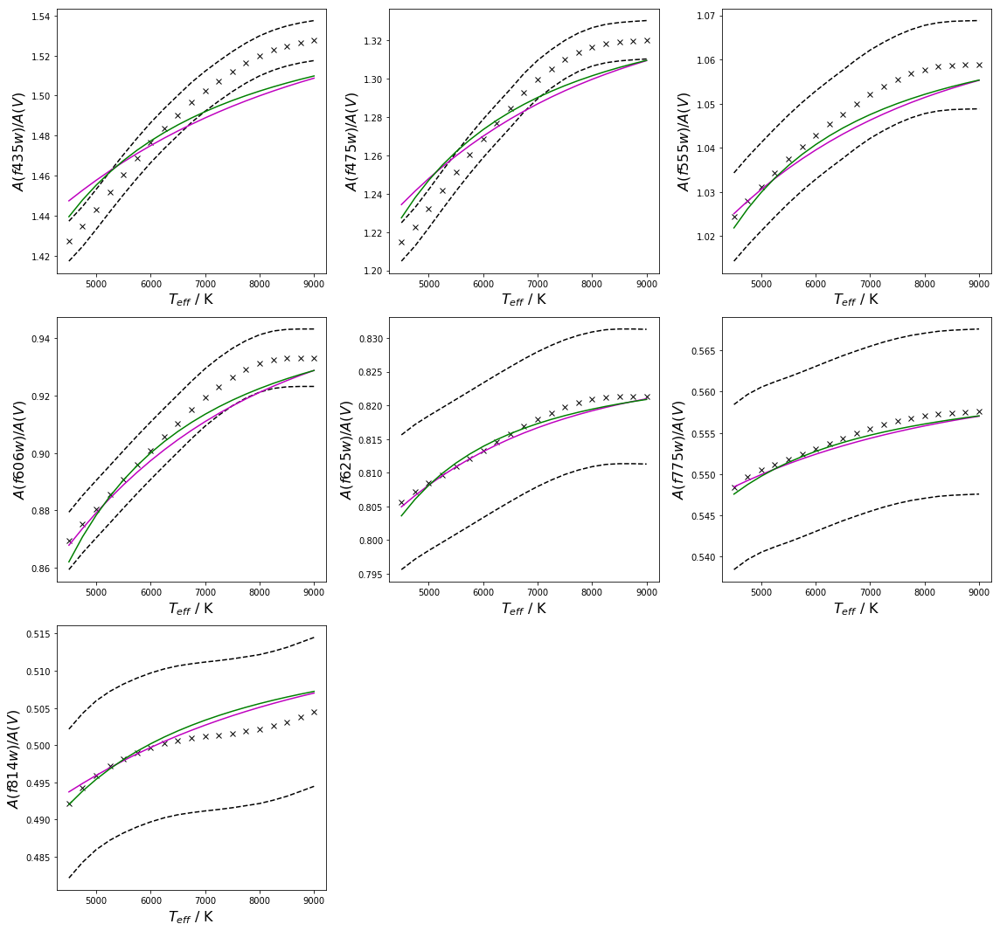


    Writing complete for log(g) = 1.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 1.0
Exponential fit coefficients (should be reused): 
[-0.2653 -2.255   1.5436]
Standard deviations (should be reused): 
[ 0.0336  0.2127  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0347 -1.4543  1.5502]
Standard deviations (should be reused): 
[ 0.0043  0.1601  0.0032]
Logistic fit coefficients: 
[  2.5535e-14   2.6372e+00   1.5430e+00   1.1407e+00]
Standard deviations: 
[  1.0612e+04   7.9940e-01   1.8865e-03   7.7557e-01]
Teff log-normal fit coefficients: 
[-2.      0.5     1.5074  1.4675]
Standard deviations: 
[ 0.      0.0787  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


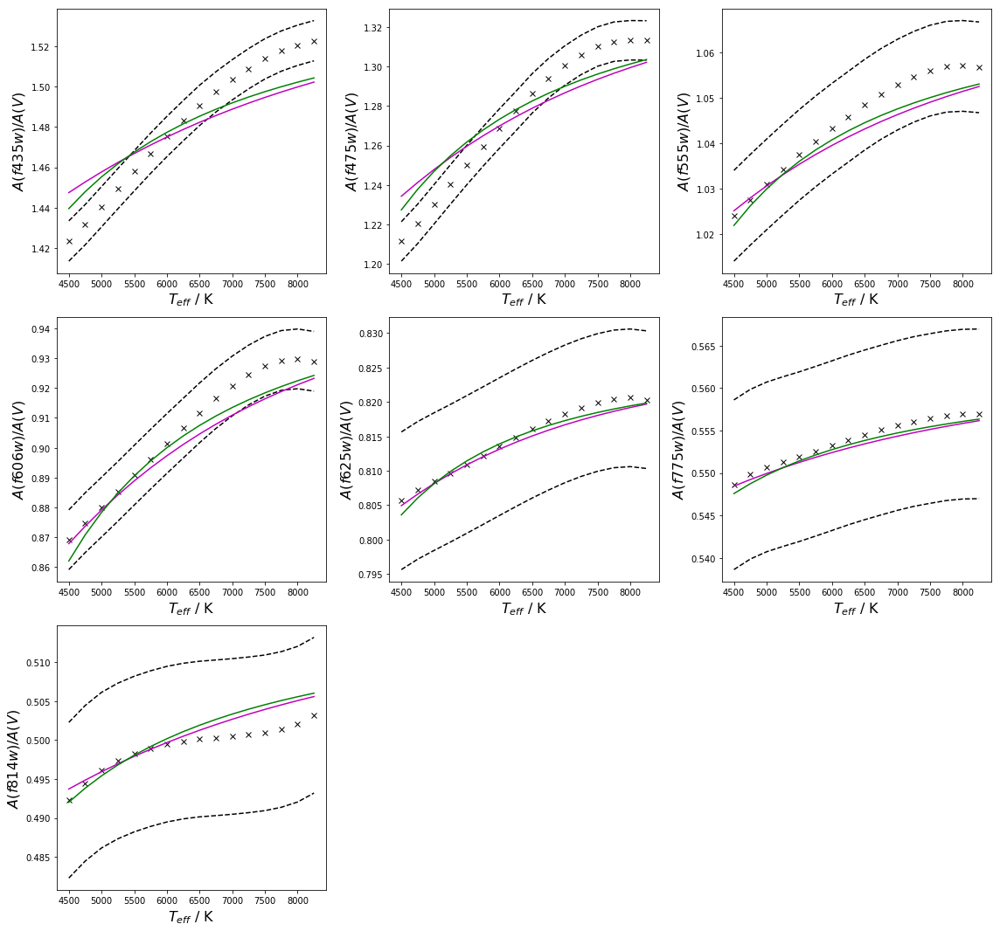


    Writing complete for log(g) = 1.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 0.5
Exponential fit coefficients (should be reused): 
[-0.2653 -2.255   1.5436]
Standard deviations (should be reused): 
[ 0.0336  0.2127  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0347 -1.4543  1.5502]
Standard deviations (should be reused): 
[ 0.0043  0.1601  0.0032]
Logistic fit coefficients: 
[  2.5535e-14   2.6372e+00   1.5430e+00   1.1407e+00]
Standard deviations: 
[  1.0612e+04   7.9940e-01   1.8865e-03   7.7557e-01]
Teff log-normal fit coefficients: 
[-2.      0.5     1.5074  1.4675]
Standard deviations: 
[ 0.      0.0787  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


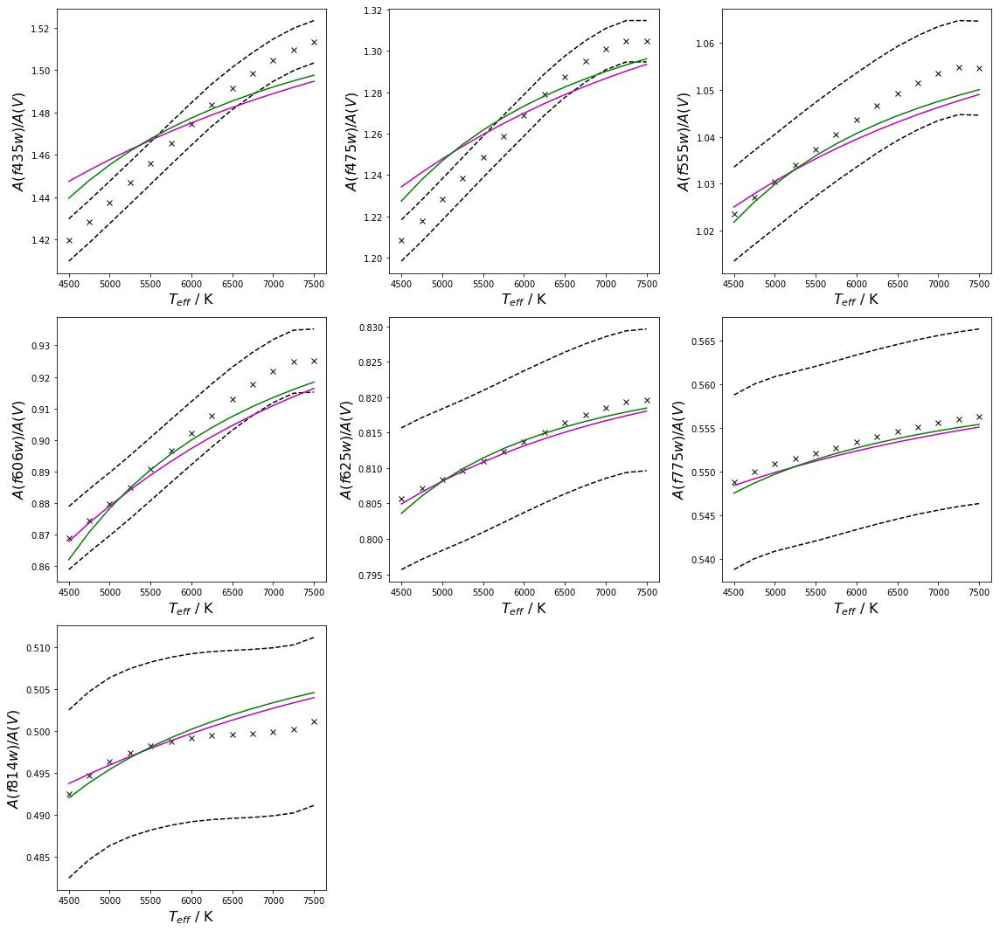


    Writing complete for log(g) = 0.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


2.0,0.5 , 0.0
Exponential fit coefficients (should be reused): 
[-0.2653 -2.255   1.5436]
Standard deviations (should be reused): 
[ 0.0336  0.2127  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0347 -1.4543  1.5502]
Standard deviations (should be reused): 
[ 0.0043  0.1601  0.0032]
Logistic fit coefficients: 
[  2.5535e-14   2.6372e+00   1.5430e+00   1.1407e+00]
Standard deviations: 
[  1.0612e+04   7.9940e-01   1.8865e-03   7.7557e-01]
Teff log-normal fit coefficients: 
[-2.      0.5     1.5074  1.4675]
Standard deviations: 
[ 0.      0.0787  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


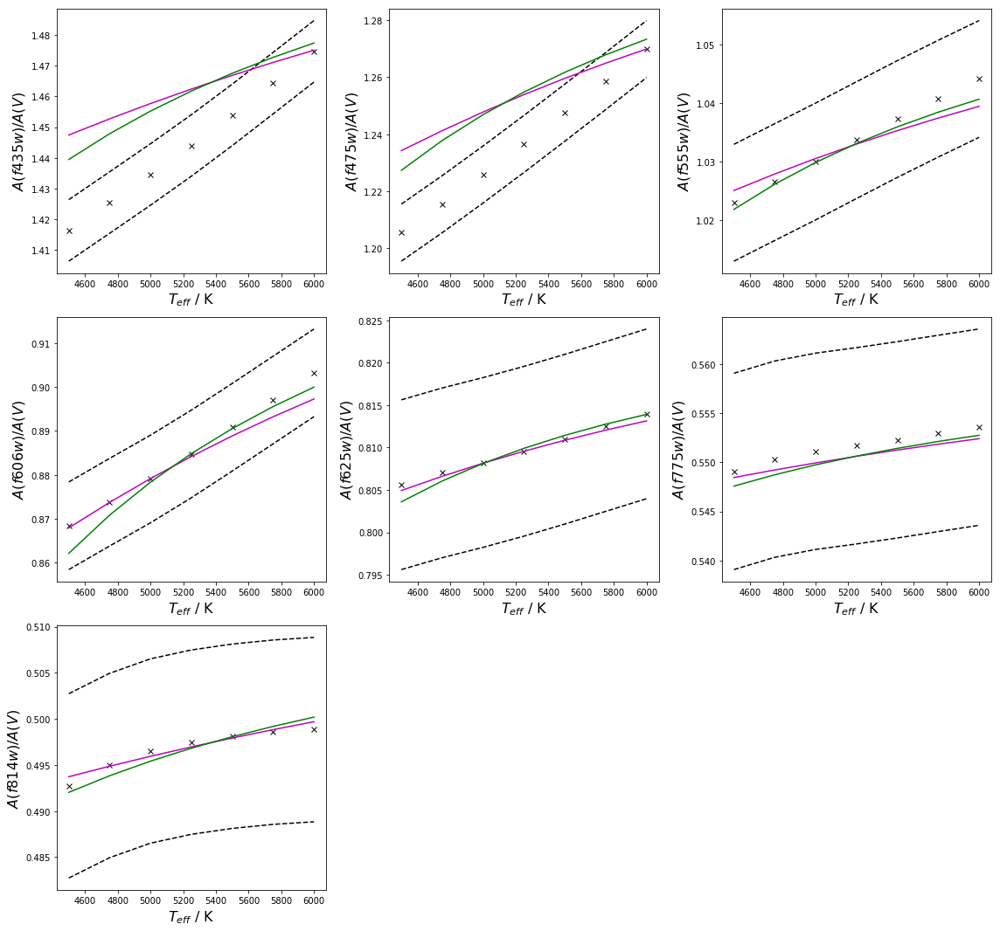


    Writing complete for log(g) = 0.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 5.0
Deleting missing subplots - discrepancy between 7 and 9


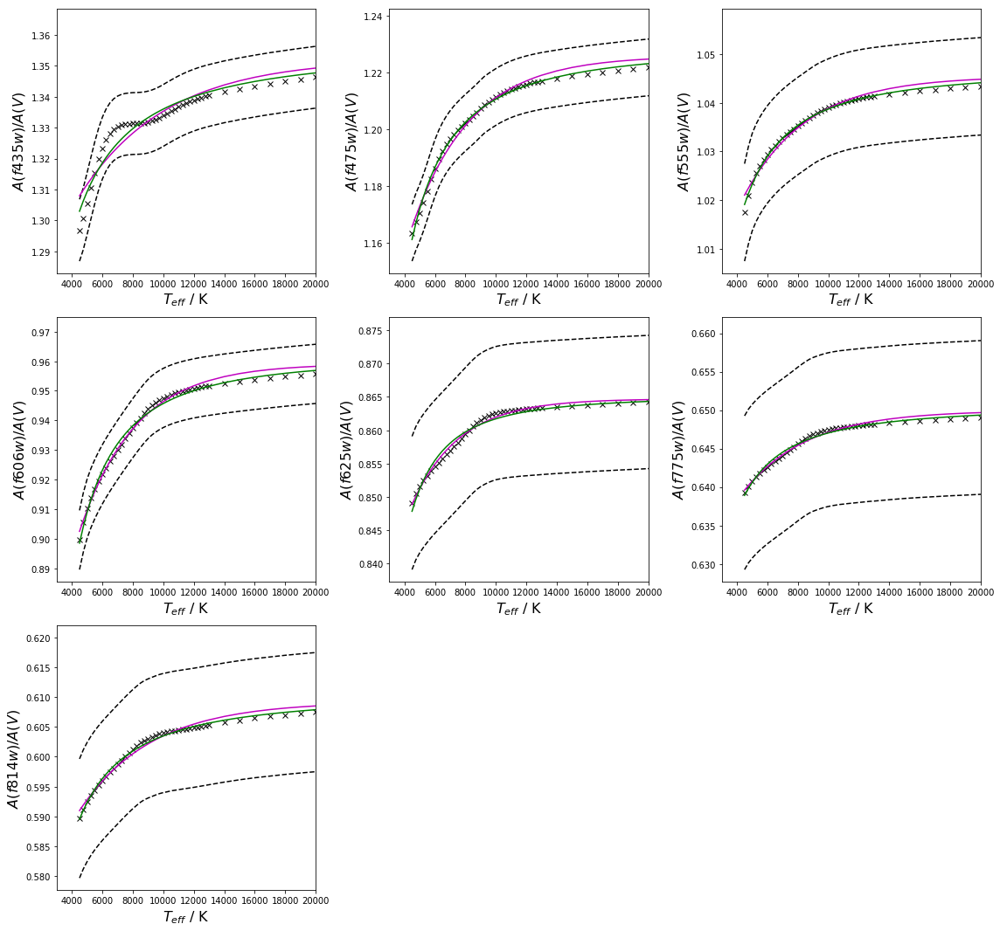


    Writing complete for log(g) = 5.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 4.5
Exponential fit coefficients (should be reused): 
[-0.0972 -1.7492  1.3522]
Standard deviations (should be reused): 
[ 0.0218  0.3612  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0208 -1.1905  1.3568]
Standard deviations (should be reused): 
[ 0.0055  0.3089  0.0042]
Logistic fit coefficients: 
[  8.3030e-17   2.1183e+00   1.3518e+00   1.1976e+00]
Standard deviations: 
[  2.4495e+04   1.4711e+00   2.0756e-03   5.2232e-01]
Teff log-normal fit coefficients: 
[-2.      0.6964  1.3325  1.31  ]
Standard deviations: 
[ 0.      0.2376  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


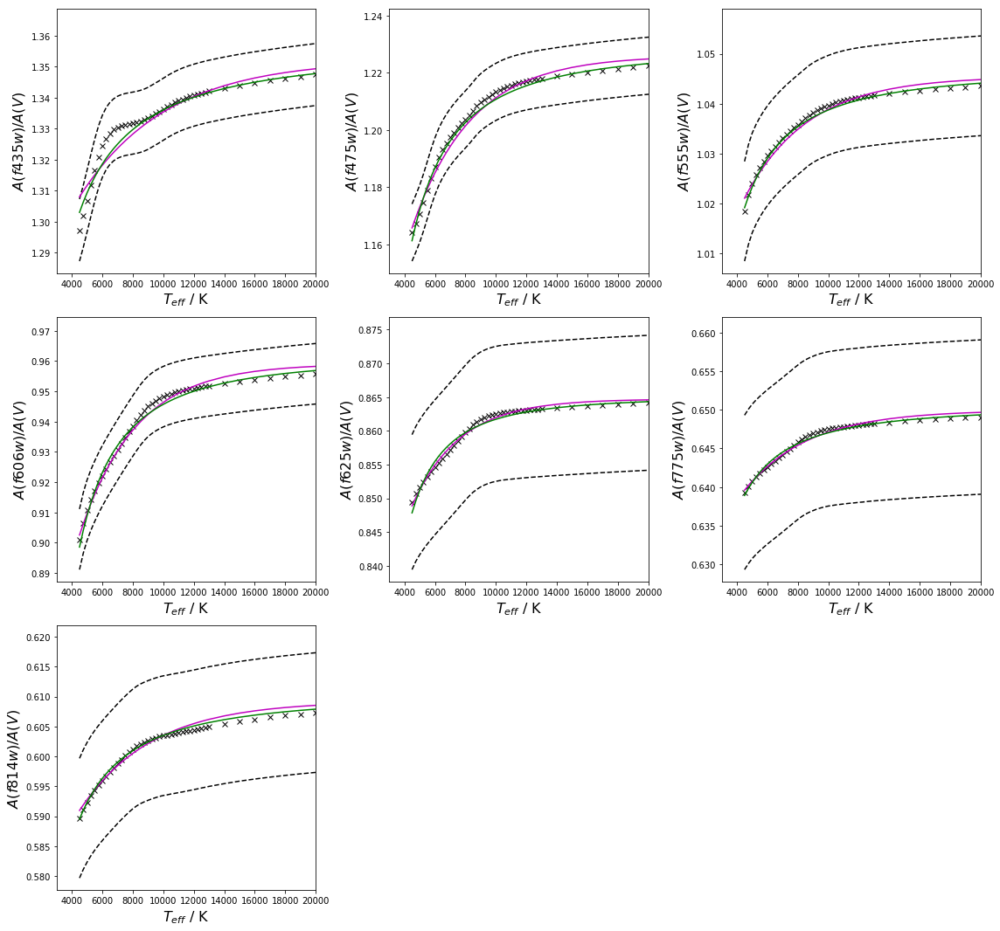


    Writing complete for log(g) = 4.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 4.0
Exponential fit coefficients (should be reused): 
[-0.0972 -1.7492  1.3522]
Standard deviations (should be reused): 
[ 0.0218  0.3612  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0208 -1.1905  1.3568]
Standard deviations (should be reused): 
[ 0.0055  0.3089  0.0042]
Logistic fit coefficients: 
[  8.3030e-17   2.1183e+00   1.3518e+00   1.1976e+00]
Standard deviations: 
[  2.4495e+04   1.4711e+00   2.0756e-03   5.2232e-01]
Teff log-normal fit coefficients: 
[-2.      0.6964  1.3325  1.31  ]
Standard deviations: 
[ 0.      0.2376  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


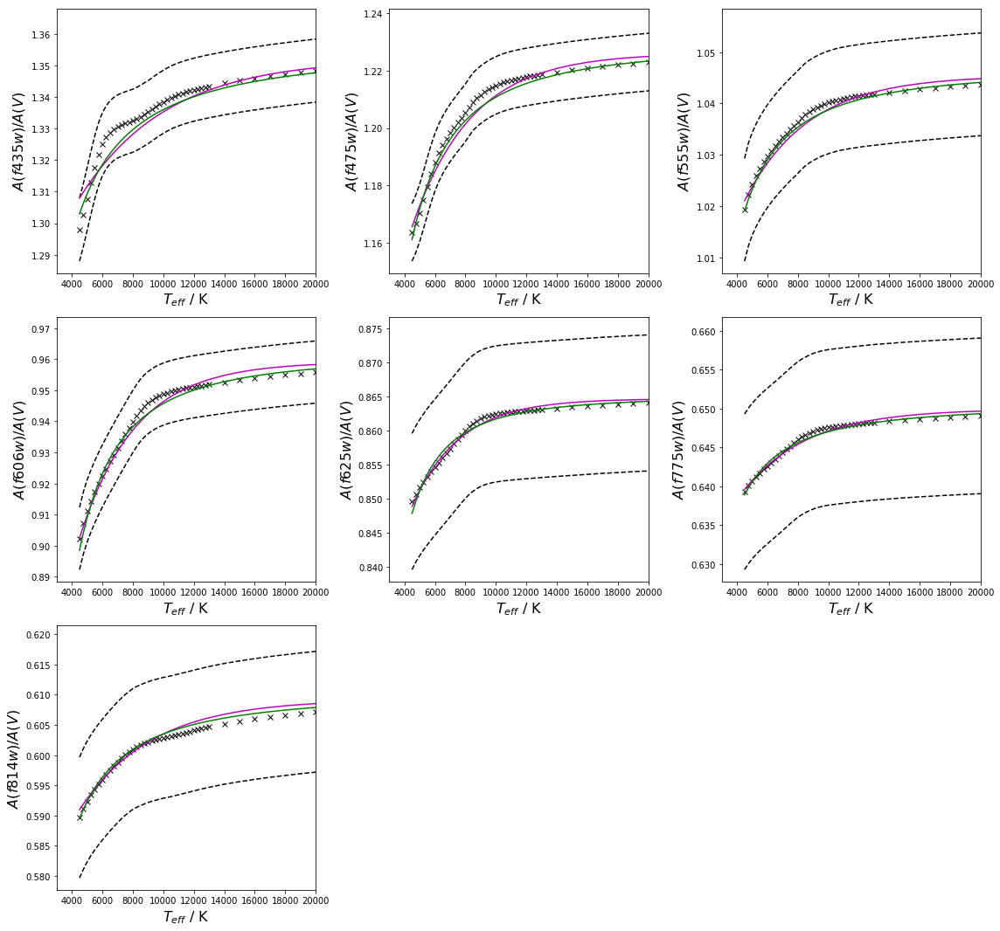


    Writing complete for log(g) = 4.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 3.5
Exponential fit coefficients (should be reused): 
[-0.0972 -1.7492  1.3522]
Standard deviations (should be reused): 
[ 0.0218  0.3612  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0208 -1.1905  1.3568]
Standard deviations (should be reused): 
[ 0.0055  0.3089  0.0042]
Logistic fit coefficients: 
[  8.3030e-17   2.1183e+00   1.3518e+00   1.1976e+00]
Standard deviations: 
[  2.4495e+04   1.4711e+00   2.0756e-03   5.2232e-01]
Teff log-normal fit coefficients: 
[-2.      0.6964  1.3325  1.31  ]
Standard deviations: 
[ 0.      0.2376  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


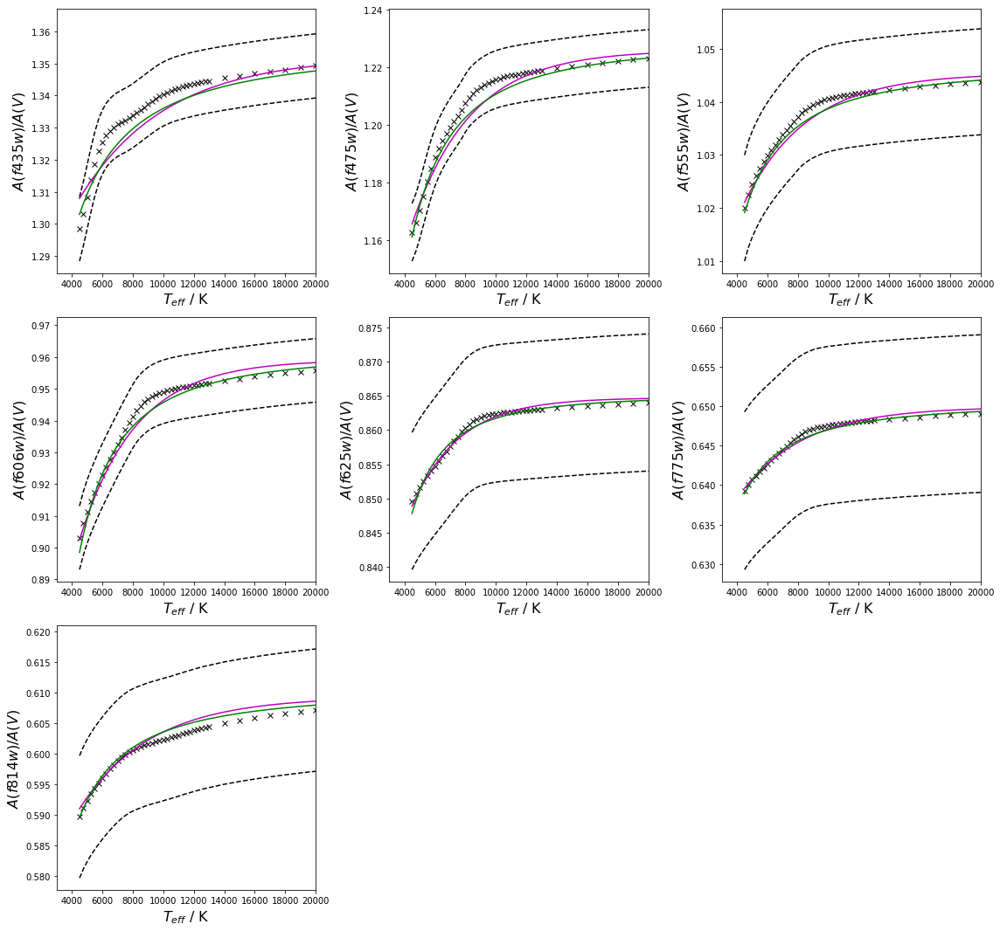


    Writing complete for log(g) = 3.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 3.0
Exponential fit coefficients (should be reused): 
[-0.0972 -1.7492  1.3522]
Standard deviations (should be reused): 
[ 0.0218  0.3612  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0208 -1.1905  1.3568]
Standard deviations (should be reused): 
[ 0.0055  0.3089  0.0042]
Logistic fit coefficients: 
[  8.3030e-17   2.1183e+00   1.3518e+00   1.1976e+00]
Standard deviations: 
[  2.4495e+04   1.4711e+00   2.0756e-03   5.2232e-01]
Teff log-normal fit coefficients: 
[-2.      0.6964  1.3325  1.31  ]
Standard deviations: 
[ 0.      0.2376  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


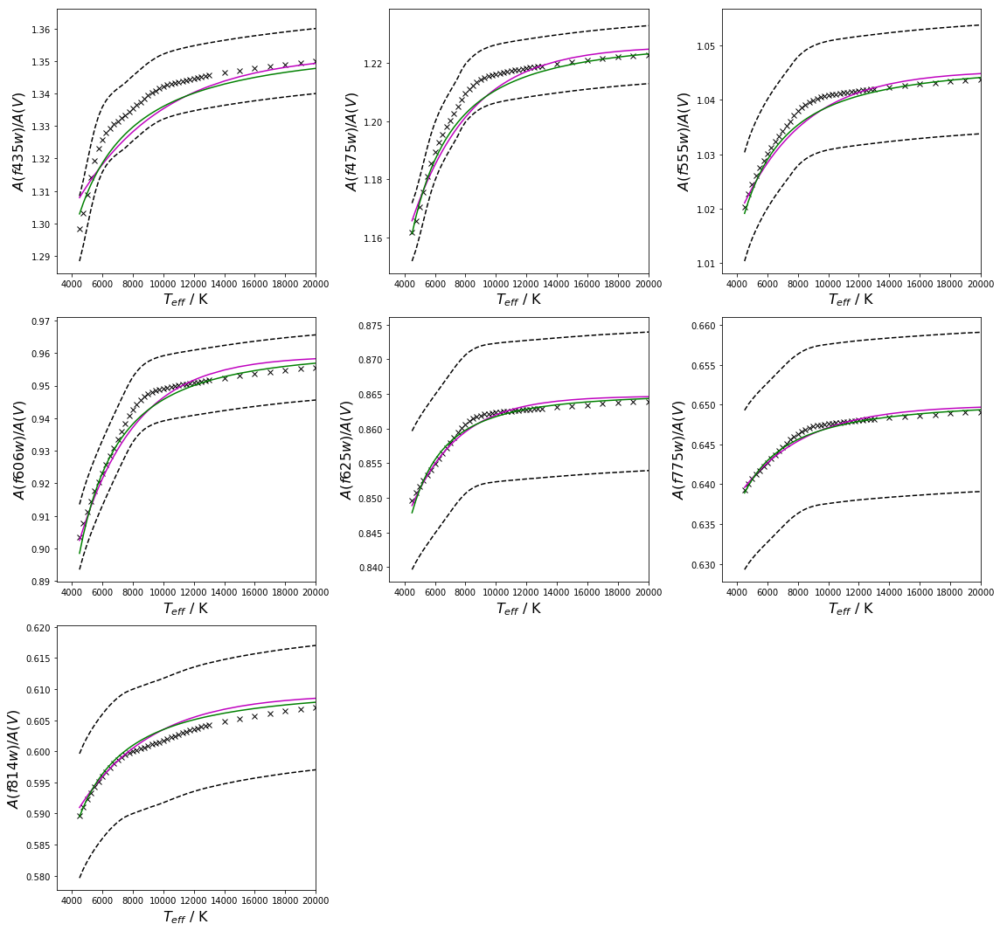


    Writing complete for log(g) = 3.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 2.5
Exponential fit coefficients (should be reused): 
[-0.0972 -1.7492  1.3522]
Standard deviations (should be reused): 
[ 0.0218  0.3612  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0208 -1.1905  1.3568]
Standard deviations (should be reused): 
[ 0.0055  0.3089  0.0042]
Logistic fit coefficients: 
[  8.3030e-17   2.1183e+00   1.3518e+00   1.1976e+00]
Standard deviations: 
[  2.4495e+04   1.4711e+00   2.0756e-03   5.2232e-01]
Teff log-normal fit coefficients: 
[-2.      0.6964  1.3325  1.31  ]
Standard deviations: 
[ 0.      0.2376  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


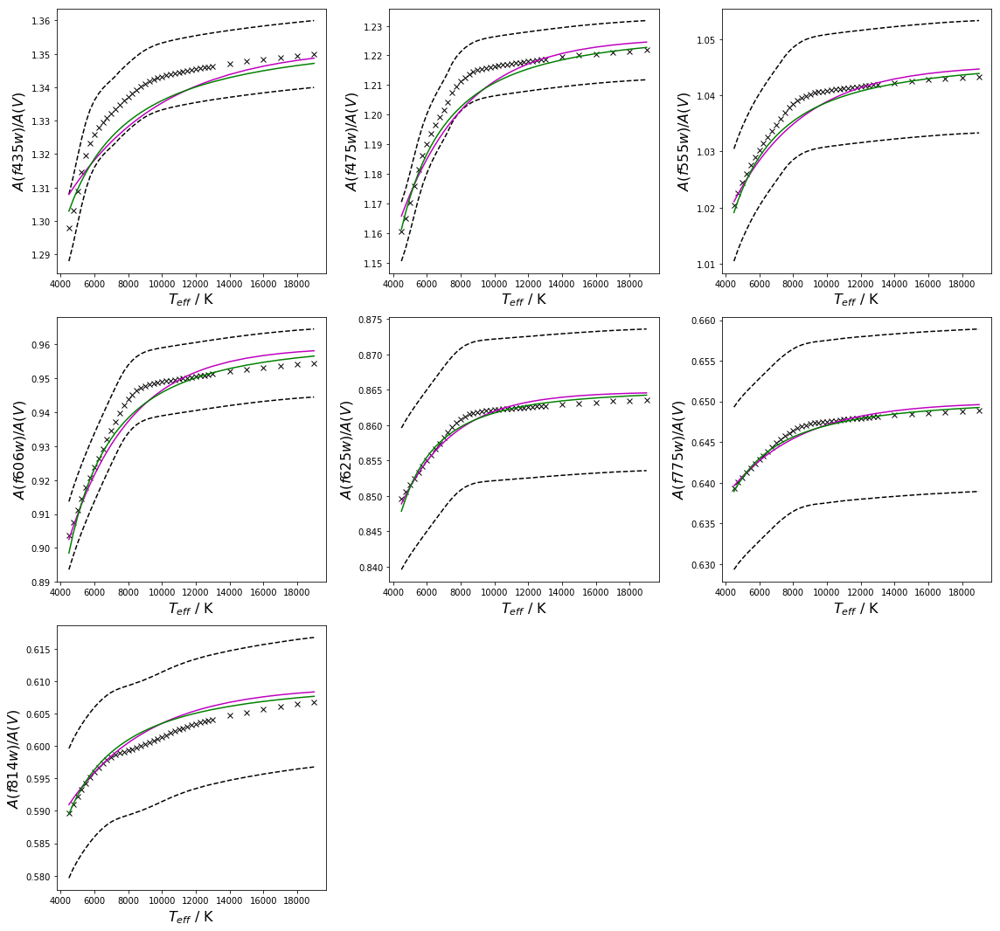


    Writing complete for log(g) = 2.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 2.0
Exponential fit coefficients (should be reused): 
[-0.0972 -1.7492  1.3522]
Standard deviations (should be reused): 
[ 0.0218  0.3612  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0208 -1.1905  1.3568]
Standard deviations (should be reused): 
[ 0.0055  0.3089  0.0042]
Logistic fit coefficients: 
[  8.3030e-17   2.1183e+00   1.3518e+00   1.1976e+00]
Standard deviations: 
[  2.4495e+04   1.4711e+00   2.0756e-03   5.2232e-01]
Teff log-normal fit coefficients: 
[-2.      0.6964  1.3325  1.31  ]
Standard deviations: 
[ 0.      0.2376  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


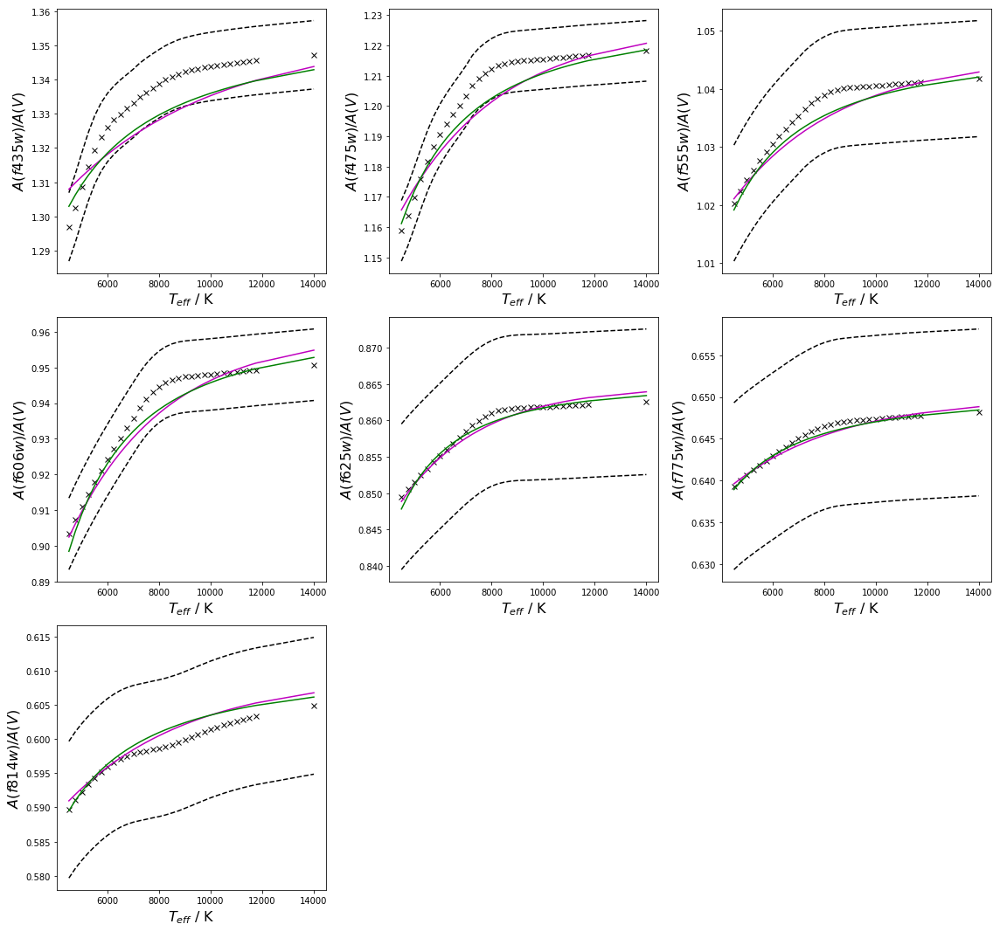


    Writing complete for log(g) = 2.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 1.5
Exponential fit coefficients (should be reused): 
[-0.0972 -1.7492  1.3522]
Standard deviations (should be reused): 
[ 0.0218  0.3612  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0208 -1.1905  1.3568]
Standard deviations (should be reused): 
[ 0.0055  0.3089  0.0042]
Logistic fit coefficients: 
[  8.3030e-17   2.1183e+00   1.3518e+00   1.1976e+00]
Standard deviations: 
[  2.4495e+04   1.4711e+00   2.0756e-03   5.2232e-01]
Teff log-normal fit coefficients: 
[-2.      0.6964  1.3325  1.31  ]
Standard deviations: 
[ 0.      0.2376  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


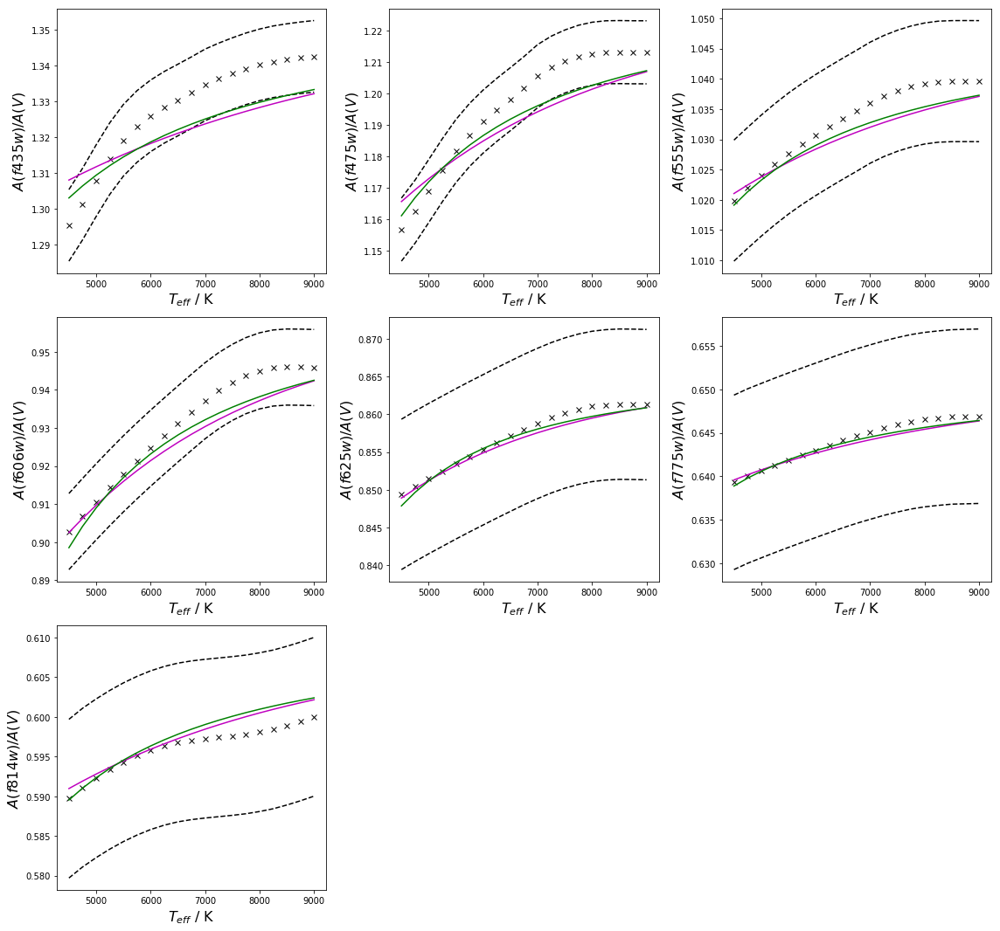


    Writing complete for log(g) = 1.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 1.0
Exponential fit coefficients (should be reused): 
[-0.0972 -1.7492  1.3522]
Standard deviations (should be reused): 
[ 0.0218  0.3612  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0208 -1.1905  1.3568]
Standard deviations (should be reused): 
[ 0.0055  0.3089  0.0042]
Logistic fit coefficients: 
[  8.3030e-17   2.1183e+00   1.3518e+00   1.1976e+00]
Standard deviations: 
[  2.4495e+04   1.4711e+00   2.0756e-03   5.2232e-01]
Teff log-normal fit coefficients: 
[-2.      0.6964  1.3325  1.31  ]
Standard deviations: 
[ 0.      0.2376  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


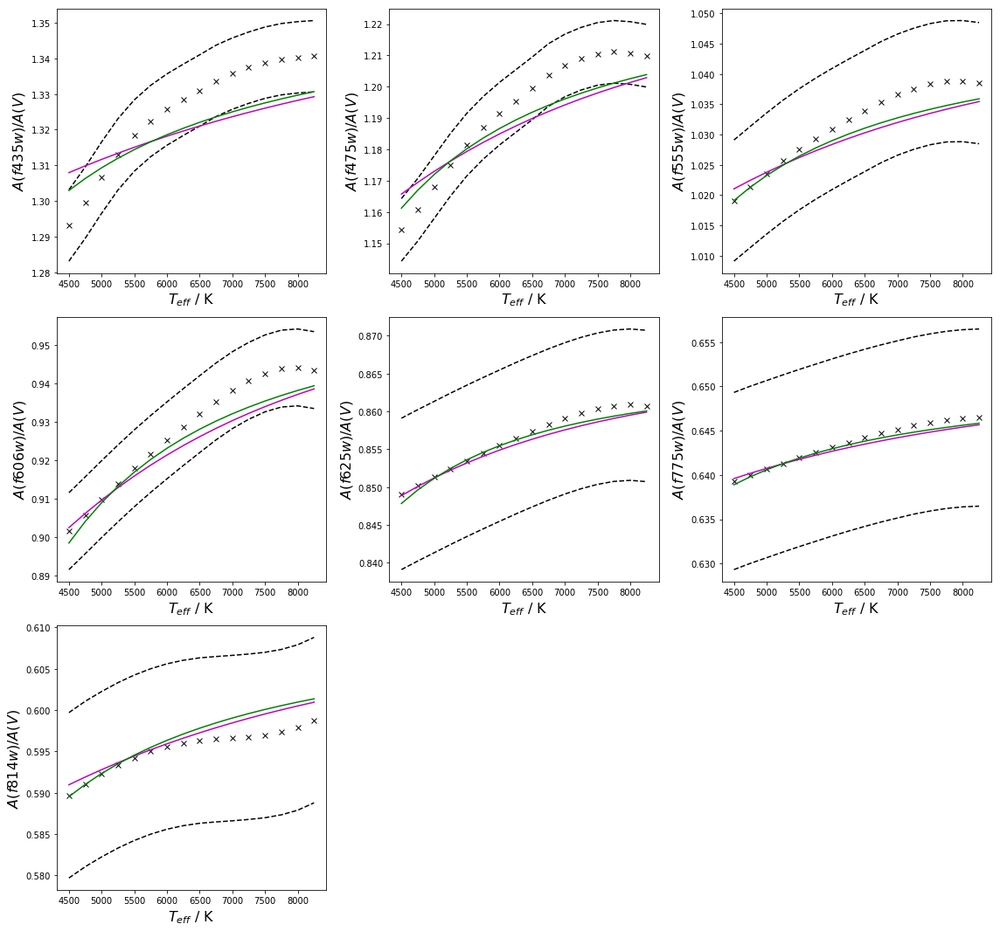


    Writing complete for log(g) = 1.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 0.5
Exponential fit coefficients (should be reused): 
[-0.0972 -1.7492  1.3522]
Standard deviations (should be reused): 
[ 0.0218  0.3612  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0208 -1.1905  1.3568]
Standard deviations (should be reused): 
[ 0.0055  0.3089  0.0042]
Logistic fit coefficients: 
[  8.3030e-17   2.1183e+00   1.3518e+00   1.1976e+00]
Standard deviations: 
[  2.4495e+04   1.4711e+00   2.0756e-03   5.2232e-01]
Teff log-normal fit coefficients: 
[-2.      0.6964  1.3325  1.31  ]
Standard deviations: 
[ 0.      0.2376  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


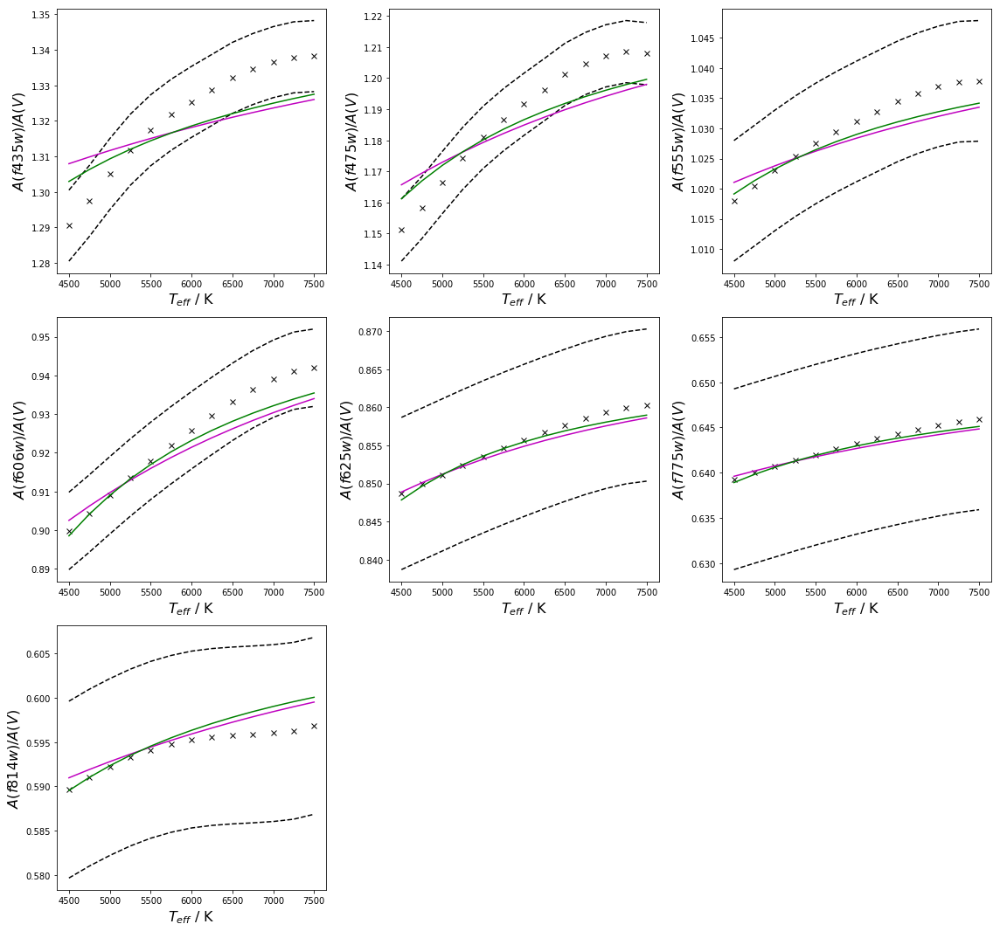


    Writing complete for log(g) = 0.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-1.0 , 0.0
Exponential fit coefficients (should be reused): 
[-0.0972 -1.7492  1.3522]
Standard deviations (should be reused): 
[ 0.0218  0.3612  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0208 -1.1905  1.3568]
Standard deviations (should be reused): 
[ 0.0055  0.3089  0.0042]
Logistic fit coefficients: 
[  8.3030e-17   2.1183e+00   1.3518e+00   1.1976e+00]
Standard deviations: 
[  2.4495e+04   1.4711e+00   2.0756e-03   5.2232e-01]
Teff log-normal fit coefficients: 
[-2.      0.6964  1.3325  1.31  ]
Standard deviations: 
[ 0.      0.2376  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


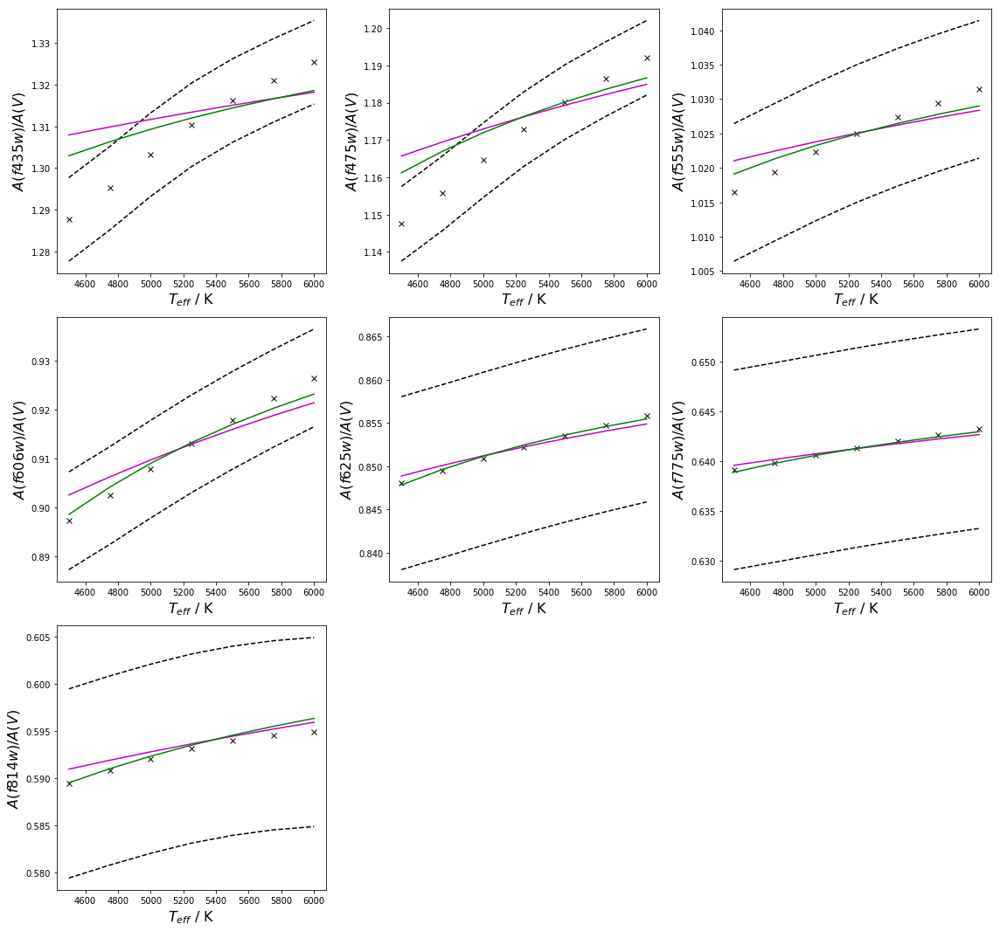


    Writing complete for log(g) = 0.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 5.0
Deleting missing subplots - discrepancy between 7 and 9


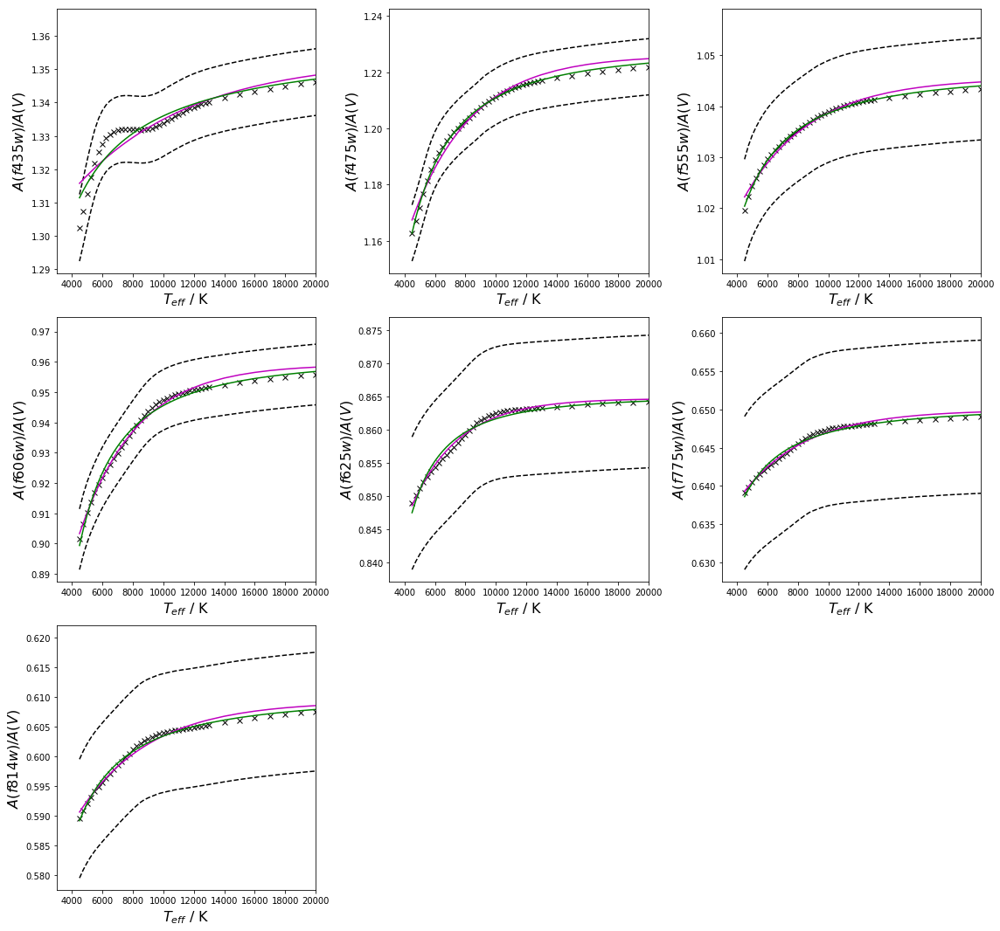


    Writing complete for log(g) = 5.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 4.5
Exponential fit coefficients (should be reused): 
[-0.0674 -1.3115  1.3531]
Standard deviations (should be reused): 
[ 0.0144  0.3399  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0244 -0.8723  1.3604]
Standard deviations (should be reused): 
[ 0.0085  0.3345  0.0072]
Logistic fit coefficients: 
[  1.9882e-16   1.6433e+00   1.3527e+00   1.2418e+00]
Standard deviations: 
[  3.0821e+04   1.3657e+00   2.4641e-03   3.4895e-01]
Teff log-normal fit coefficients: 
[-2.      0.8456  1.3338  1.3115]
Standard deviations: 
[ 0.      0.3722  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


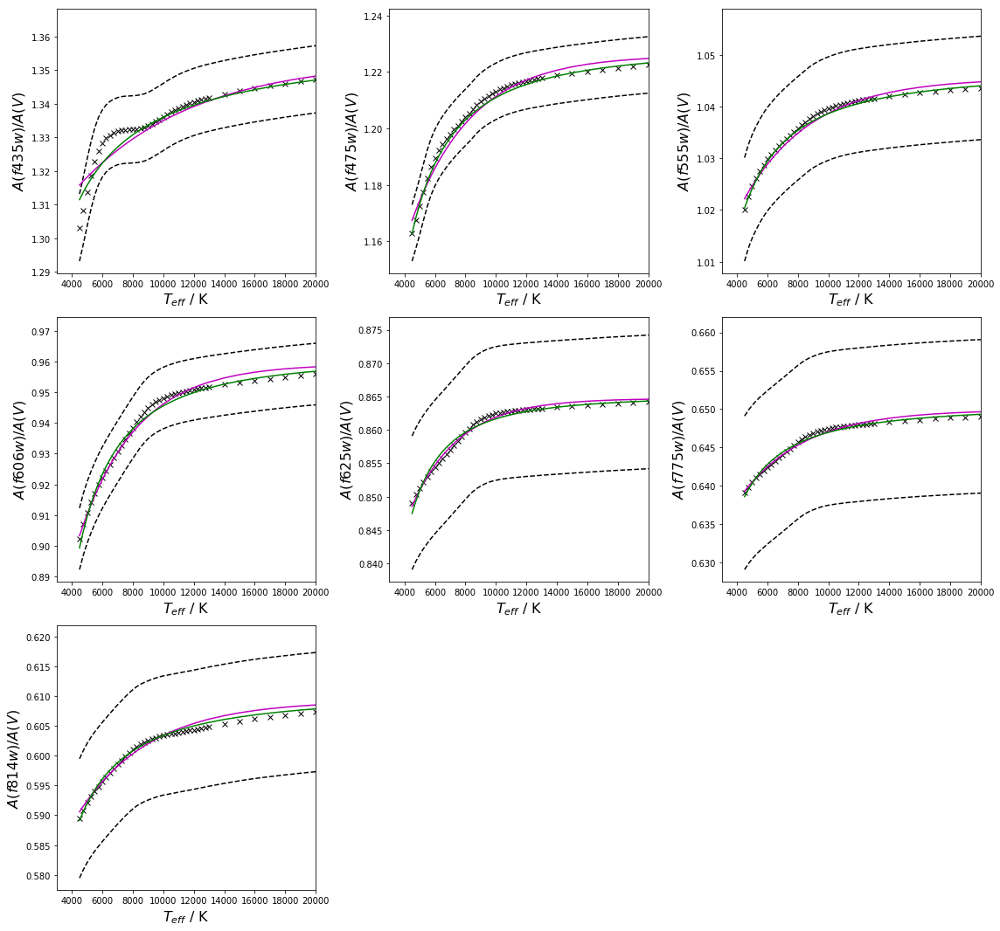


    Writing complete for log(g) = 4.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 4.0
Exponential fit coefficients (should be reused): 
[-0.0674 -1.3115  1.3531]
Standard deviations (should be reused): 
[ 0.0144  0.3399  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0244 -0.8723  1.3604]
Standard deviations (should be reused): 
[ 0.0085  0.3345  0.0072]
Logistic fit coefficients: 
[  1.9882e-16   1.6433e+00   1.3527e+00   1.2418e+00]
Standard deviations: 
[  3.0821e+04   1.3657e+00   2.4641e-03   3.4895e-01]
Teff log-normal fit coefficients: 
[-2.      0.8456  1.3338  1.3115]
Standard deviations: 
[ 0.      0.3722  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


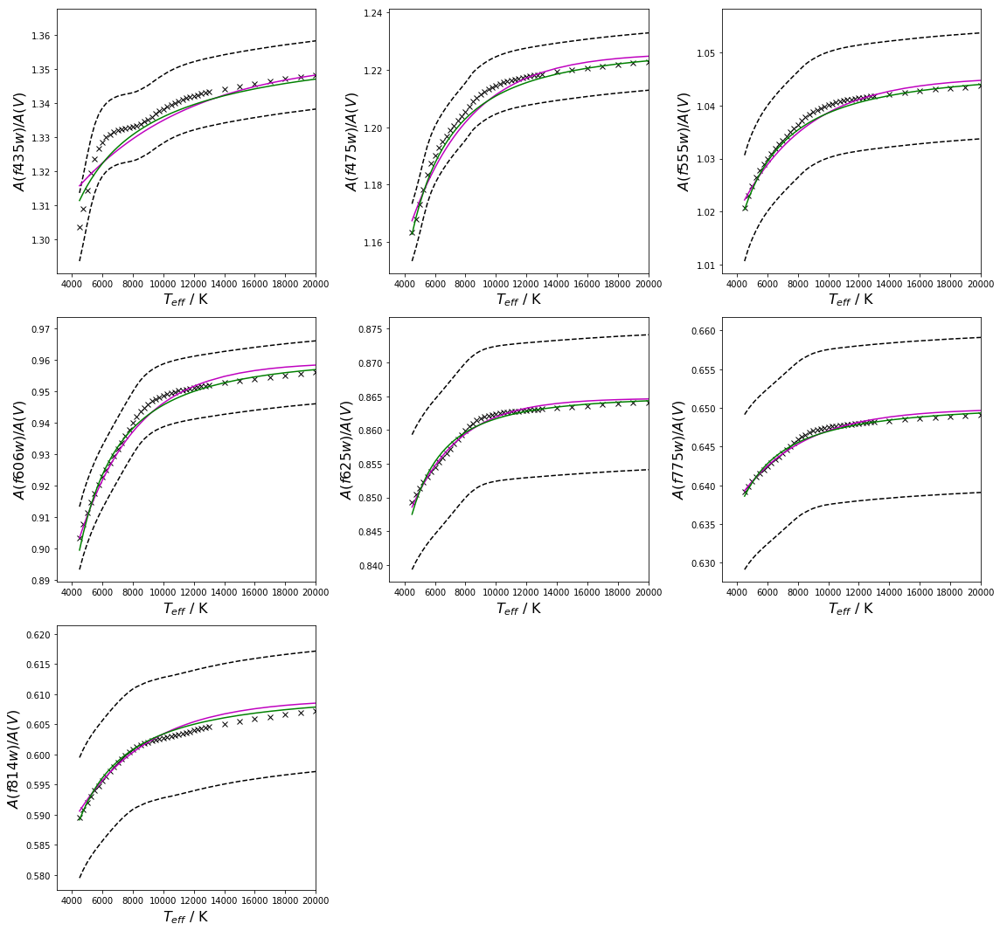


    Writing complete for log(g) = 4.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 3.5
Exponential fit coefficients (should be reused): 
[-0.0674 -1.3115  1.3531]
Standard deviations (should be reused): 
[ 0.0144  0.3399  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0244 -0.8723  1.3604]
Standard deviations (should be reused): 
[ 0.0085  0.3345  0.0072]
Logistic fit coefficients: 
[  1.9882e-16   1.6433e+00   1.3527e+00   1.2418e+00]
Standard deviations: 
[  3.0821e+04   1.3657e+00   2.4641e-03   3.4895e-01]
Teff log-normal fit coefficients: 
[-2.      0.8456  1.3338  1.3115]
Standard deviations: 
[ 0.      0.3722  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


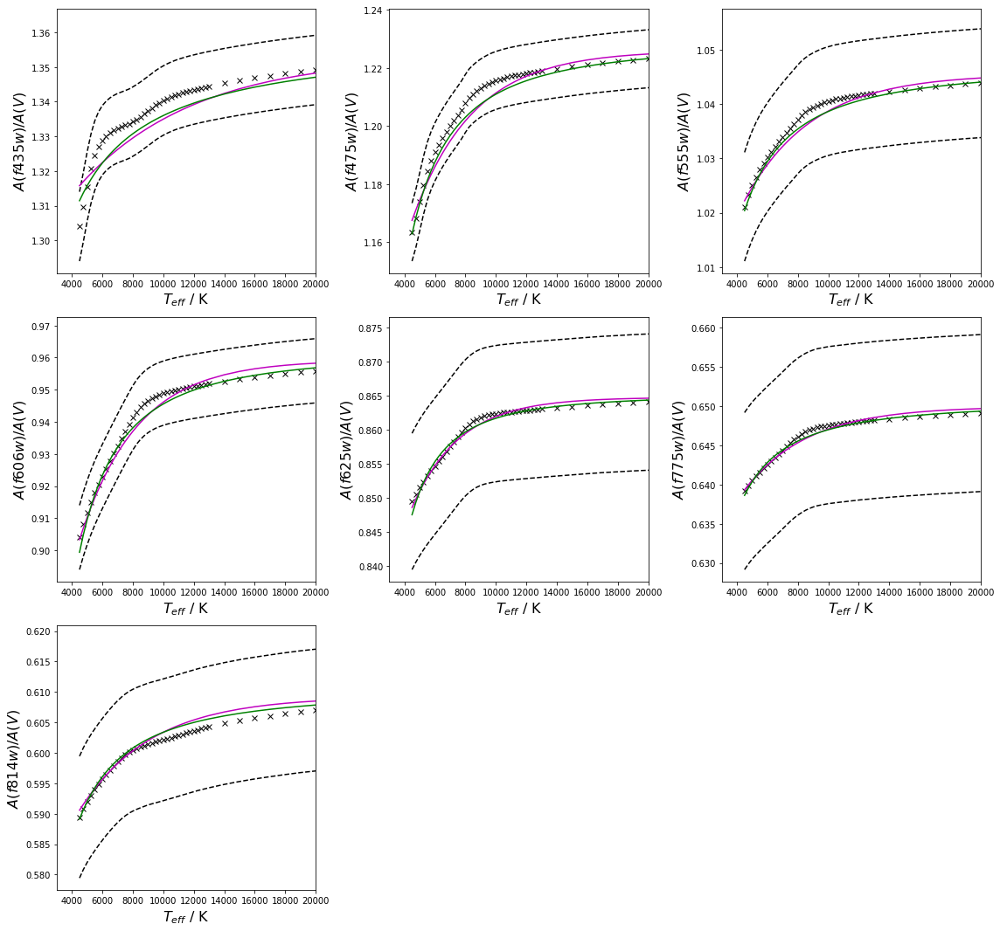


    Writing complete for log(g) = 3.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 3.0
Exponential fit coefficients (should be reused): 
[-0.0674 -1.3115  1.3531]
Standard deviations (should be reused): 
[ 0.0144  0.3399  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0244 -0.8723  1.3604]
Standard deviations (should be reused): 
[ 0.0085  0.3345  0.0072]
Logistic fit coefficients: 
[  1.9882e-16   1.6433e+00   1.3527e+00   1.2418e+00]
Standard deviations: 
[  3.0821e+04   1.3657e+00   2.4641e-03   3.4895e-01]
Teff log-normal fit coefficients: 
[-2.      0.8456  1.3338  1.3115]
Standard deviations: 
[ 0.      0.3722  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


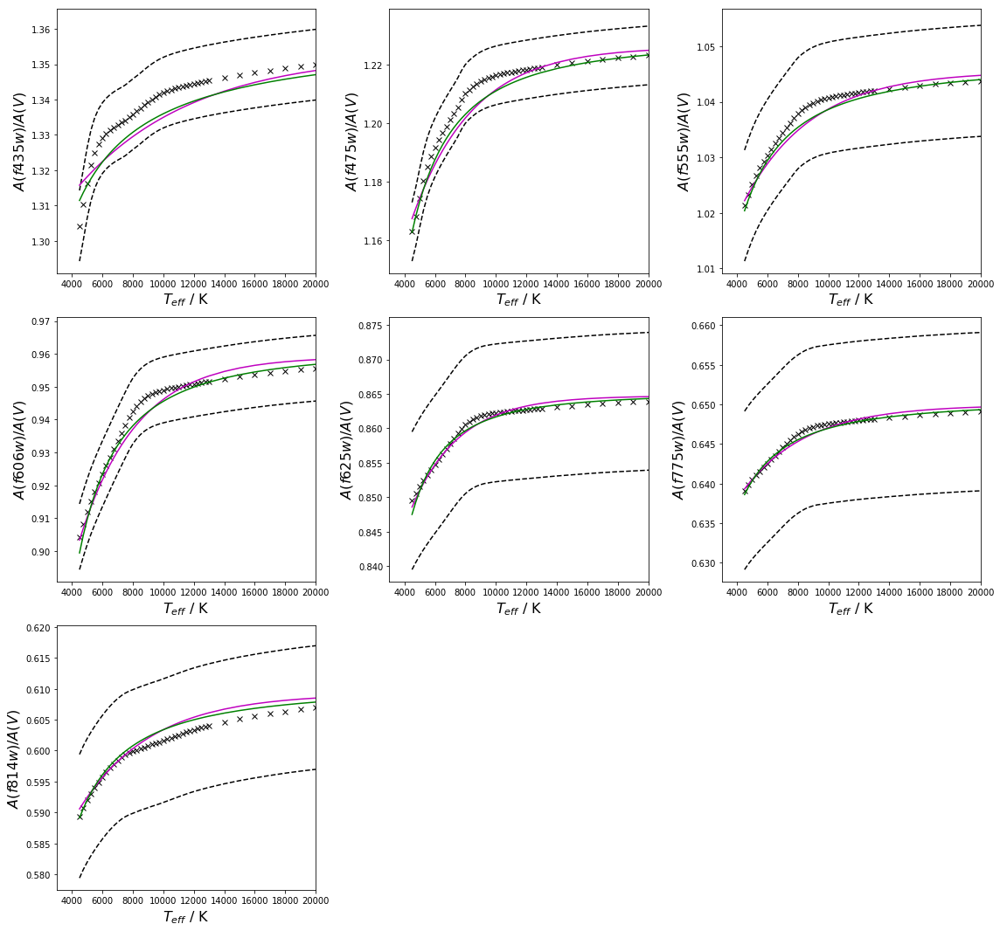


    Writing complete for log(g) = 3.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 2.5
Exponential fit coefficients (should be reused): 
[-0.0674 -1.3115  1.3531]
Standard deviations (should be reused): 
[ 0.0144  0.3399  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0244 -0.8723  1.3604]
Standard deviations (should be reused): 
[ 0.0085  0.3345  0.0072]
Logistic fit coefficients: 
[  1.9882e-16   1.6433e+00   1.3527e+00   1.2418e+00]
Standard deviations: 
[  3.0821e+04   1.3657e+00   2.4641e-03   3.4895e-01]
Teff log-normal fit coefficients: 
[-2.      0.8456  1.3338  1.3115]
Standard deviations: 
[ 0.      0.3722  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


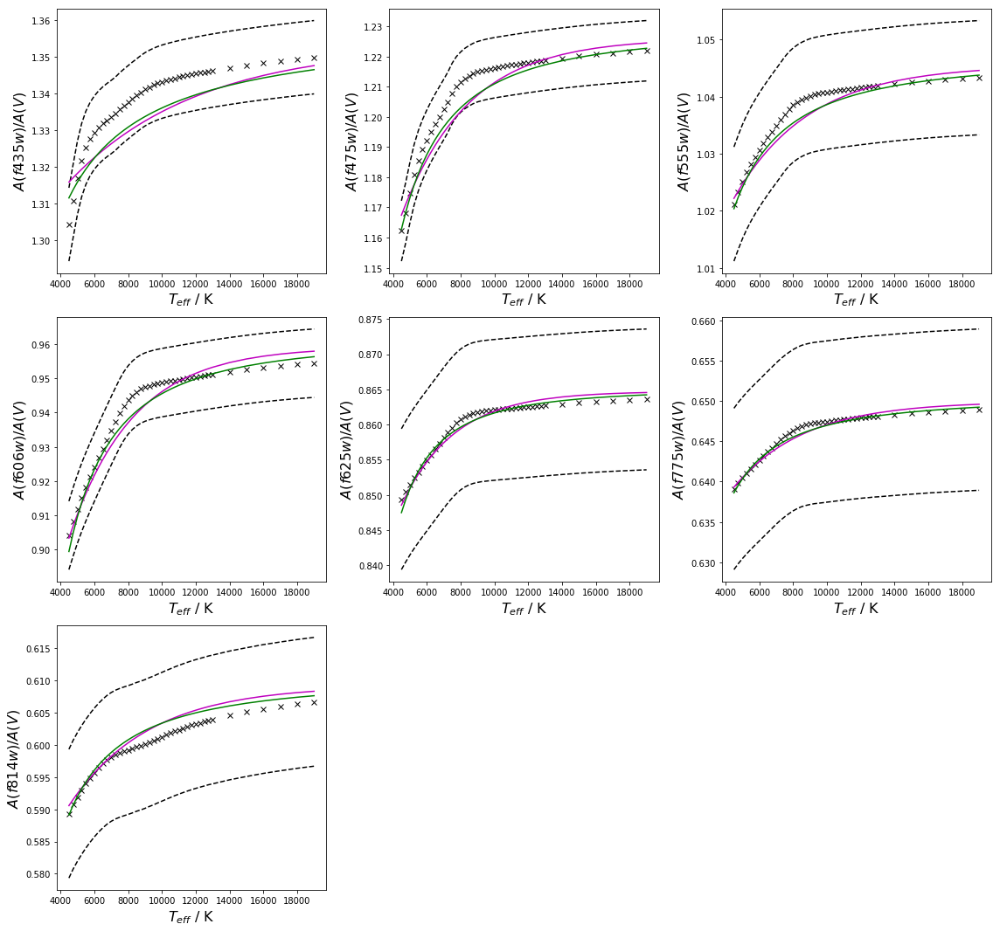


    Writing complete for log(g) = 2.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 2.0
Exponential fit coefficients (should be reused): 
[-0.0674 -1.3115  1.3531]
Standard deviations (should be reused): 
[ 0.0144  0.3399  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0244 -0.8723  1.3604]
Standard deviations (should be reused): 
[ 0.0085  0.3345  0.0072]
Logistic fit coefficients: 
[  1.9882e-16   1.6433e+00   1.3527e+00   1.2418e+00]
Standard deviations: 
[  3.0821e+04   1.3657e+00   2.4641e-03   3.4895e-01]
Teff log-normal fit coefficients: 
[-2.      0.8456  1.3338  1.3115]
Standard deviations: 
[ 0.      0.3722  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


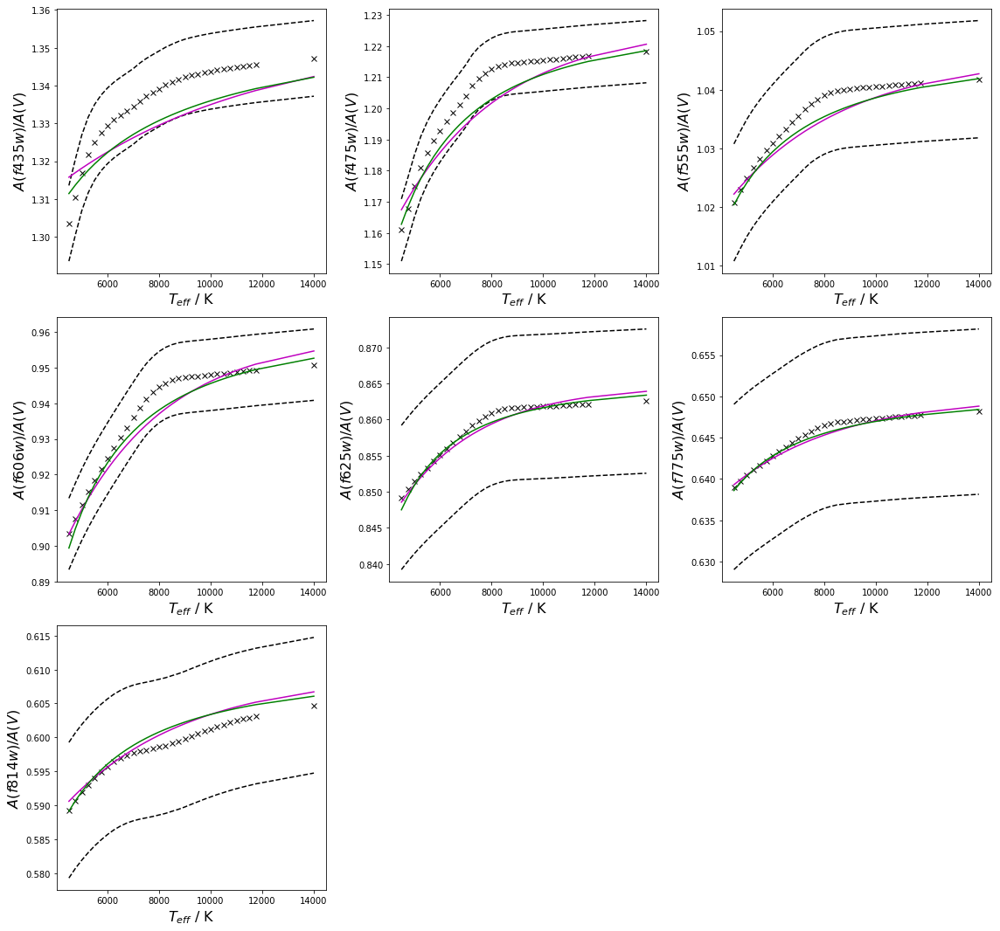


    Writing complete for log(g) = 2.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 1.5
Exponential fit coefficients (should be reused): 
[-0.0674 -1.3115  1.3531]
Standard deviations (should be reused): 
[ 0.0144  0.3399  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0244 -0.8723  1.3604]
Standard deviations (should be reused): 
[ 0.0085  0.3345  0.0072]
Logistic fit coefficients: 
[  1.9882e-16   1.6433e+00   1.3527e+00   1.2418e+00]
Standard deviations: 
[  3.0821e+04   1.3657e+00   2.4641e-03   3.4895e-01]
Teff log-normal fit coefficients: 
[-2.      0.8456  1.3338  1.3115]
Standard deviations: 
[ 0.      0.3722  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


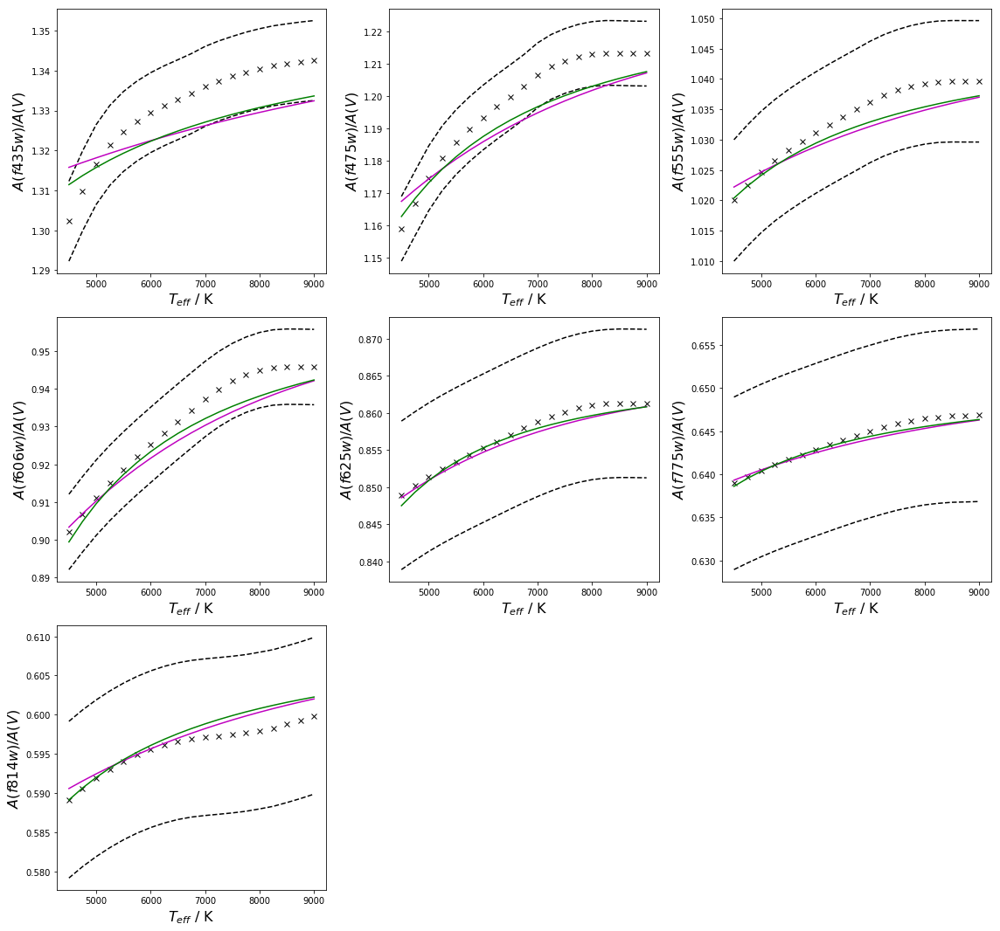


    Writing complete for log(g) = 1.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 1.0
Exponential fit coefficients (should be reused): 
[-0.0674 -1.3115  1.3531]
Standard deviations (should be reused): 
[ 0.0144  0.3399  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0244 -0.8723  1.3604]
Standard deviations (should be reused): 
[ 0.0085  0.3345  0.0072]
Logistic fit coefficients: 
[  1.9882e-16   1.6433e+00   1.3527e+00   1.2418e+00]
Standard deviations: 
[  3.0821e+04   1.3657e+00   2.4641e-03   3.4895e-01]
Teff log-normal fit coefficients: 
[-2.      0.8456  1.3338  1.3115]
Standard deviations: 
[ 0.      0.3722  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


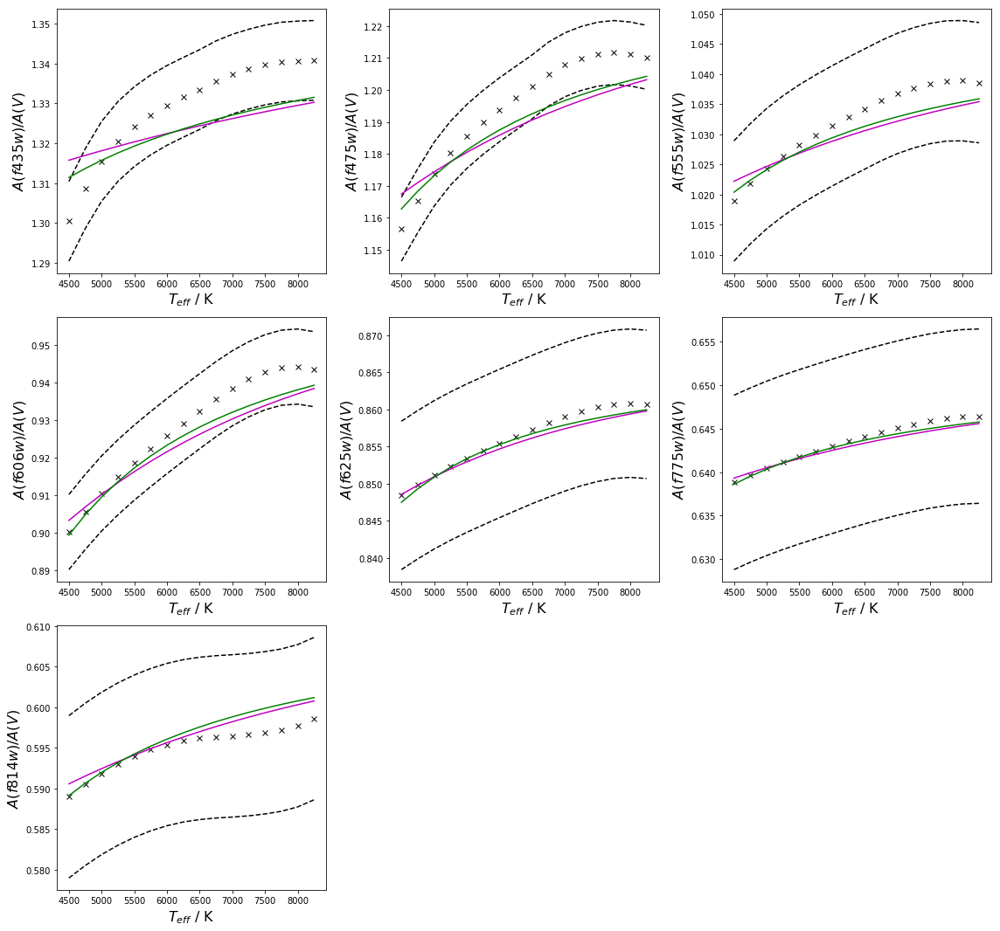


    Writing complete for log(g) = 1.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 0.5
Exponential fit coefficients (should be reused): 
[-0.0674 -1.3115  1.3531]
Standard deviations (should be reused): 
[ 0.0144  0.3399  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0244 -0.8723  1.3604]
Standard deviations (should be reused): 
[ 0.0085  0.3345  0.0072]
Logistic fit coefficients: 
[  1.9882e-16   1.6433e+00   1.3527e+00   1.2418e+00]
Standard deviations: 
[  3.0821e+04   1.3657e+00   2.4641e-03   3.4895e-01]
Teff log-normal fit coefficients: 
[-2.      0.8456  1.3338  1.3115]
Standard deviations: 
[ 0.      0.3722  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


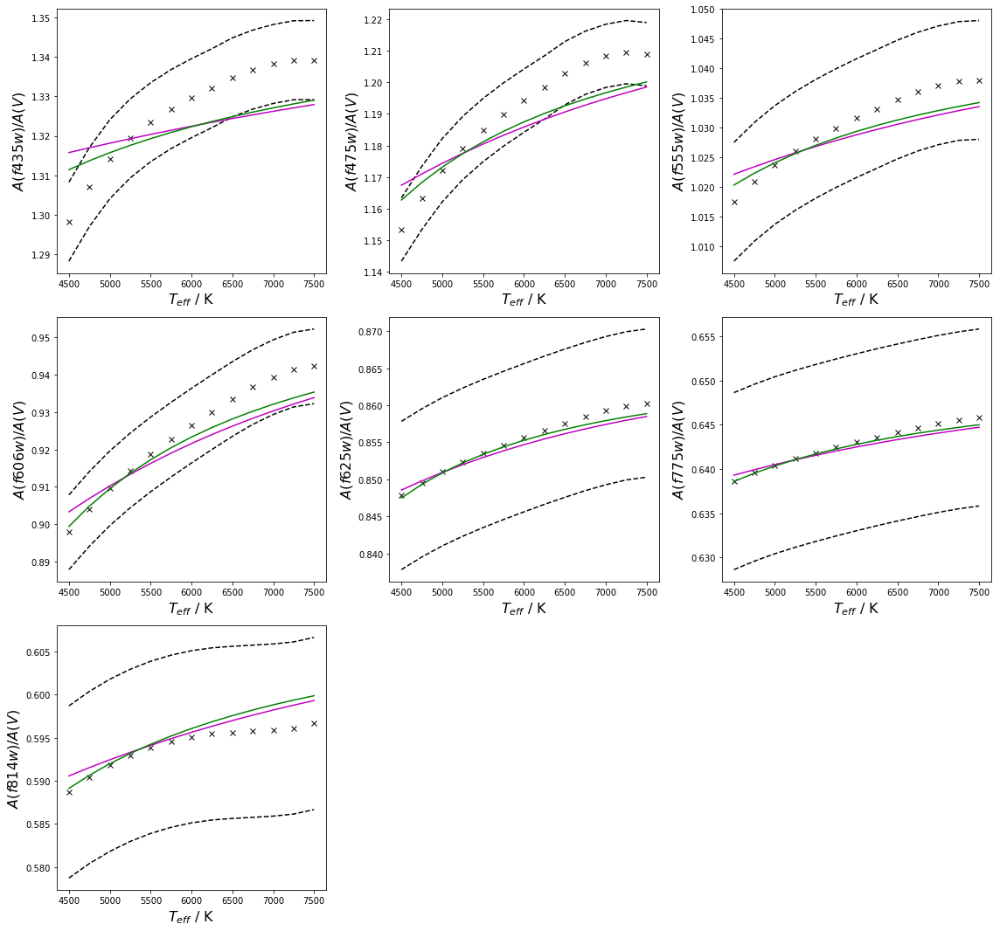


    Writing complete for log(g) = 0.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,-2.0 , 0.0
Exponential fit coefficients (should be reused): 
[-0.0674 -1.3115  1.3531]
Standard deviations (should be reused): 
[ 0.0144  0.3399  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0244 -0.8723  1.3604]
Standard deviations (should be reused): 
[ 0.0085  0.3345  0.0072]
Logistic fit coefficients: 
[  1.9882e-16   1.6433e+00   1.3527e+00   1.2418e+00]
Standard deviations: 
[  3.0821e+04   1.3657e+00   2.4641e-03   3.4895e-01]
Teff log-normal fit coefficients: 
[-2.      0.8456  1.3338  1.3115]
Standard deviations: 
[ 0.      0.3722  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


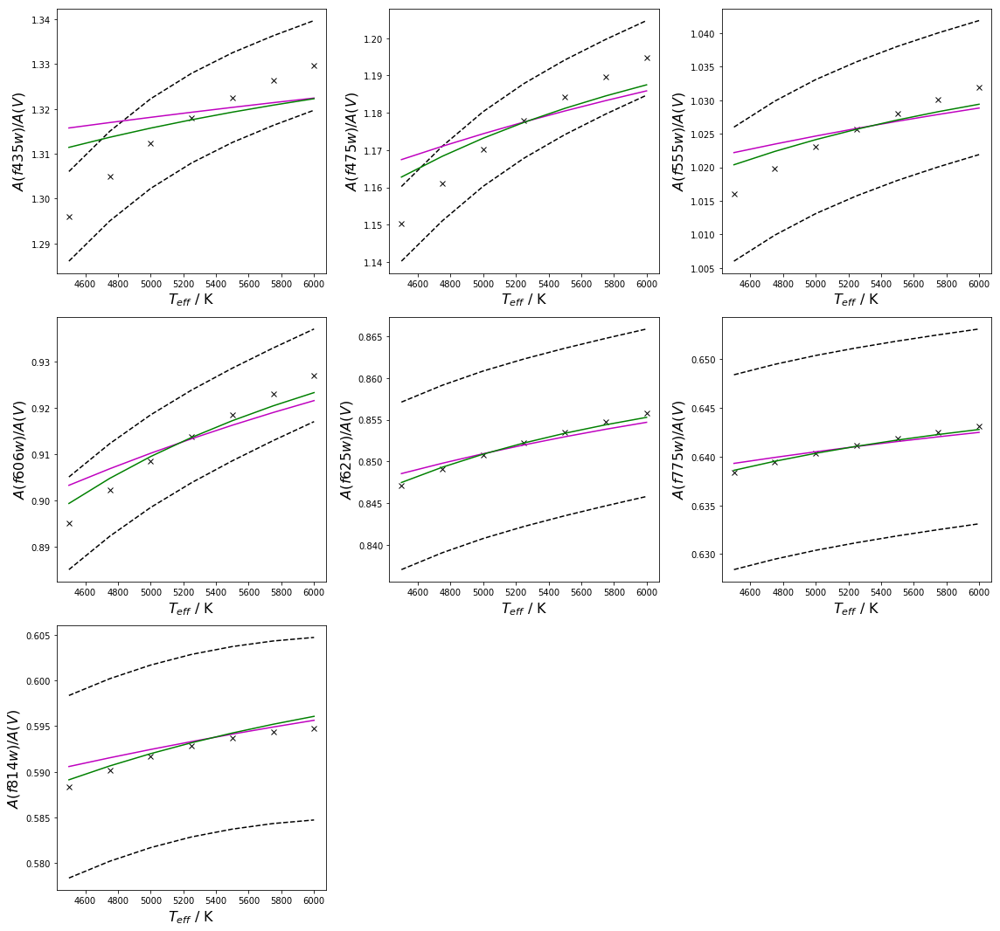


    Writing complete for log(g) = 0.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 5.0

    Writing log(g)=5.0, FeH = 0p0, Rv = 3p1 model for f435w ACS filter
Average fractional error for Exponential function of Teff, fitted = 0.128020821414
Average fractional error for Power law of Teff, fitted = 0.138690819527

    Writing log(g)=5.0, FeH = 0p0, Rv = 3p1 model for f475w ACS filter
Average fractional error for Exponential function of Teff, fitted = 0.121268933513
Average fractional error for Power law of Teff, fitted = 0.119228616659

    Writing log(g)=5.0, FeH = 0p0, Rv = 3p1 model for f555w ACS filter
Average fractional error for Exponential function of Teff, fitted = 0.286260756775
Average fractional error for Power law of Teff, fitted = 0.27798663117

    Writing log(g)=5.0, FeH = 0p0, Rv = 3p1 model for f606w ACS filter
Average fractional error for Exponential function of Teff, fitted = 0.136925620512
Average fractional error for Power law of Teff, fitted = 0

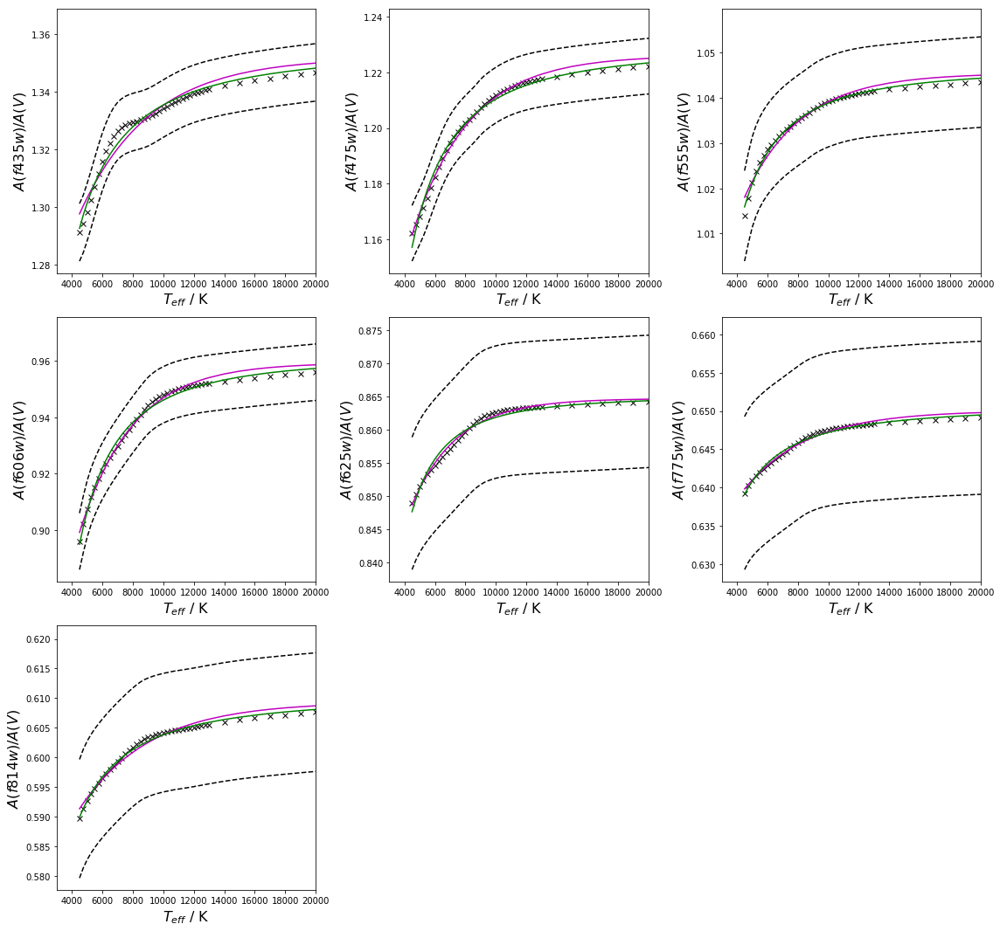


    Writing complete for log(g) = 5.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 4.5
Exponential fit coefficients (should be reused): 
[-0.1436 -2.1592  1.3519]
Standard deviations (should be reused): 
[ 0.031   0.3598  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0205 -1.4151  1.3559]
Standard deviations (should be reused): 
[ 0.0045  0.2767  0.0033]
Logistic fit coefficients: 
[  5.5534e-15   2.5456e+00   1.3516e+00   1.1315e+00]
Standard deviations: 
[  1.9117e+04   1.3873e+00   1.9096e-03   7.3078e-01]
Teff log-normal fit coefficients: 
[-2.      0.568   1.3307  1.3068]
Standard deviations: 
[ 0.      0.1567  0.0015  0.0042]



Deleting missing subplots - discrepancy between 7 and 9


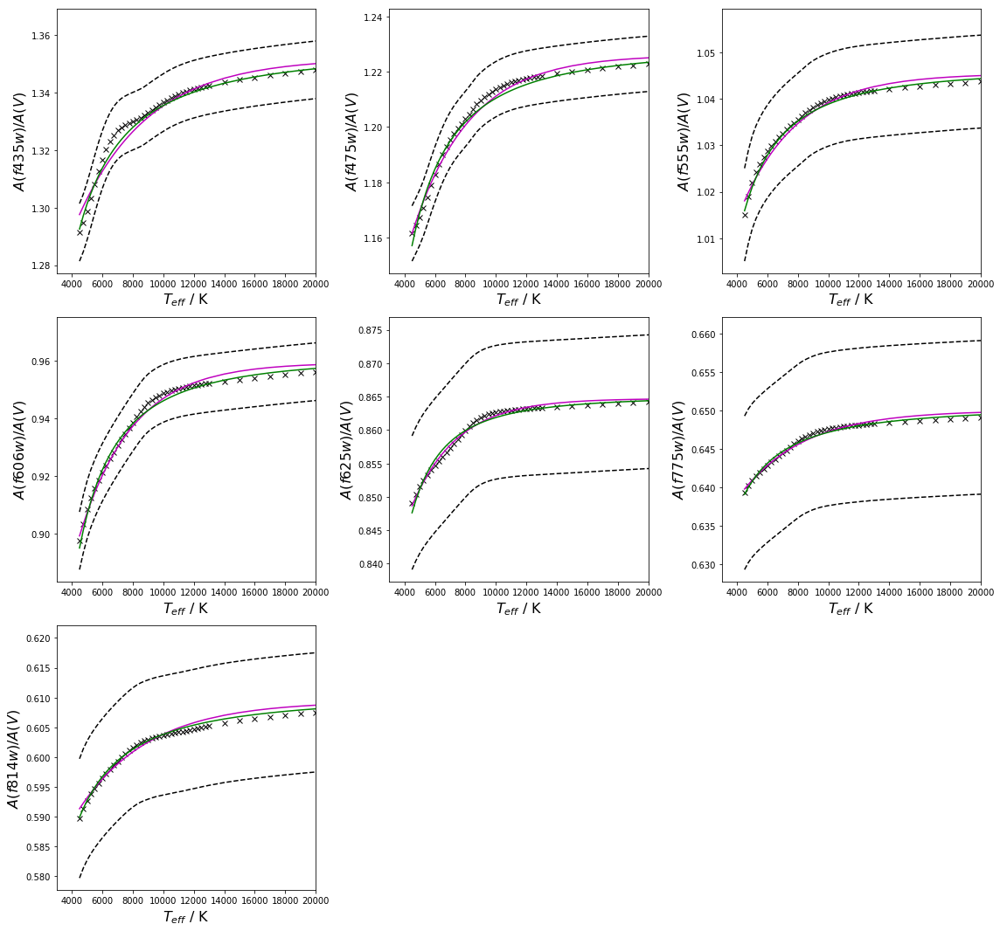


    Writing complete for log(g) = 4.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 4.0
Exponential fit coefficients (should be reused): 
[-0.1436 -2.1592  1.3519]
Standard deviations (should be reused): 
[ 0.031   0.3598  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0205 -1.4151  1.3559]
Standard deviations (should be reused): 
[ 0.0045  0.2767  0.0033]
Logistic fit coefficients: 
[  5.5534e-15   2.5456e+00   1.3516e+00   1.1315e+00]
Standard deviations: 
[  1.9117e+04   1.3873e+00   1.9096e-03   7.3078e-01]
Teff log-normal fit coefficients: 
[-2.      0.568   1.3307  1.3068]
Standard deviations: 
[ 0.      0.1567  0.0015  0.0042]



Deleting missing subplots - discrepancy between 7 and 9


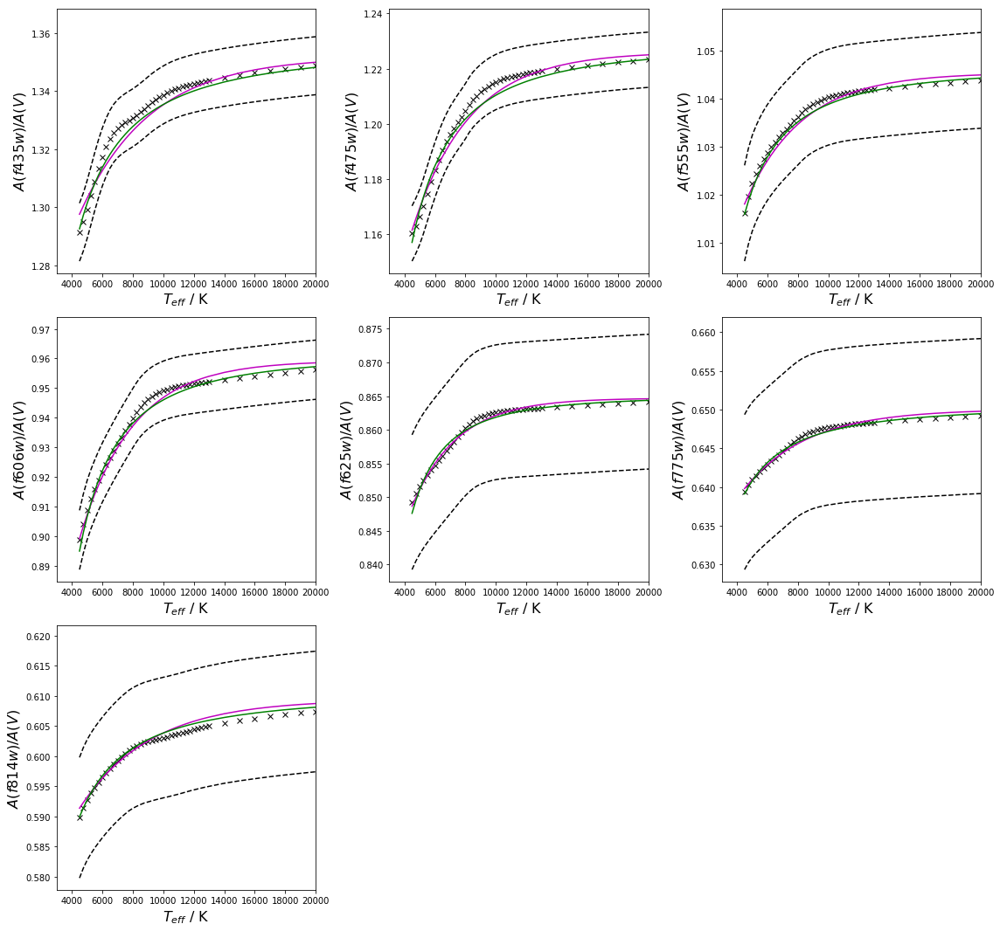


    Writing complete for log(g) = 4.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 3.5
Exponential fit coefficients (should be reused): 
[-0.1436 -2.1592  1.3519]
Standard deviations (should be reused): 
[ 0.031   0.3598  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0205 -1.4151  1.3559]
Standard deviations (should be reused): 
[ 0.0045  0.2767  0.0033]
Logistic fit coefficients: 
[  5.5534e-15   2.5456e+00   1.3516e+00   1.1315e+00]
Standard deviations: 
[  1.9117e+04   1.3873e+00   1.9096e-03   7.3078e-01]
Teff log-normal fit coefficients: 
[-2.      0.568   1.3307  1.3068]
Standard deviations: 
[ 0.      0.1567  0.0015  0.0042]



Deleting missing subplots - discrepancy between 7 and 9


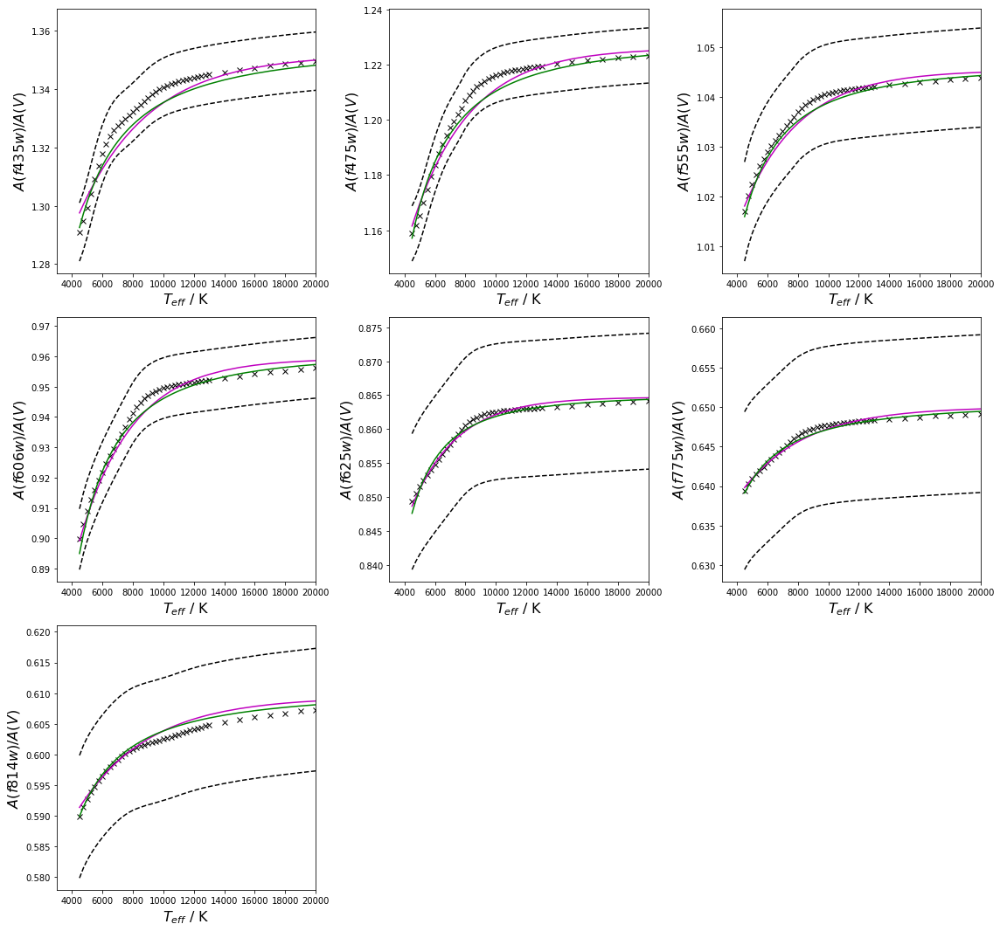


    Writing complete for log(g) = 3.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 3.0
Exponential fit coefficients (should be reused): 
[-0.1436 -2.1592  1.3519]
Standard deviations (should be reused): 
[ 0.031   0.3598  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0205 -1.4151  1.3559]
Standard deviations (should be reused): 
[ 0.0045  0.2767  0.0033]
Logistic fit coefficients: 
[  5.5534e-15   2.5456e+00   1.3516e+00   1.1315e+00]
Standard deviations: 
[  1.9117e+04   1.3873e+00   1.9096e-03   7.3078e-01]
Teff log-normal fit coefficients: 
[-2.      0.568   1.3307  1.3068]
Standard deviations: 
[ 0.      0.1567  0.0015  0.0042]



Deleting missing subplots - discrepancy between 7 and 9


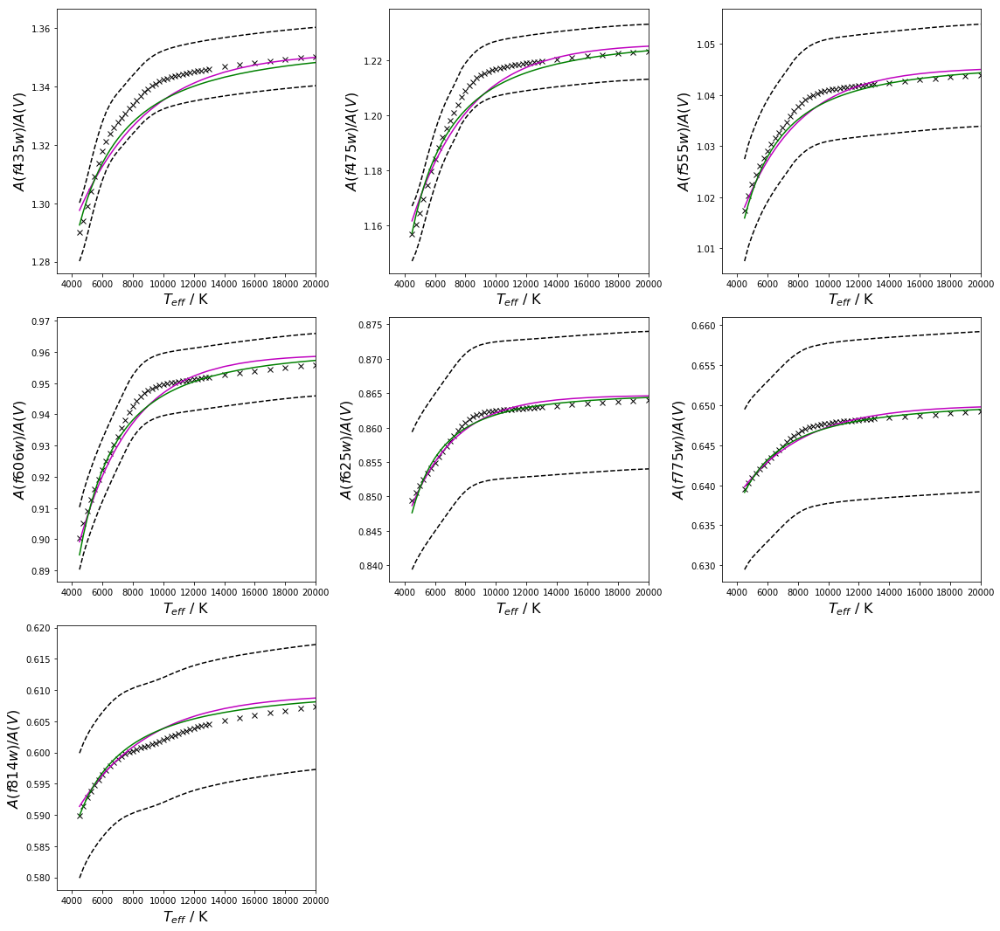


    Writing complete for log(g) = 3.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 2.5
Exponential fit coefficients (should be reused): 
[-0.1436 -2.1592  1.3519]
Standard deviations (should be reused): 
[ 0.031   0.3598  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0205 -1.4151  1.3559]
Standard deviations (should be reused): 
[ 0.0045  0.2767  0.0033]
Logistic fit coefficients: 
[  5.5534e-15   2.5456e+00   1.3516e+00   1.1315e+00]
Standard deviations: 
[  1.9117e+04   1.3873e+00   1.9096e-03   7.3078e-01]
Teff log-normal fit coefficients: 
[-2.      0.568   1.3307  1.3068]
Standard deviations: 
[ 0.      0.1567  0.0015  0.0042]



Deleting missing subplots - discrepancy between 7 and 9


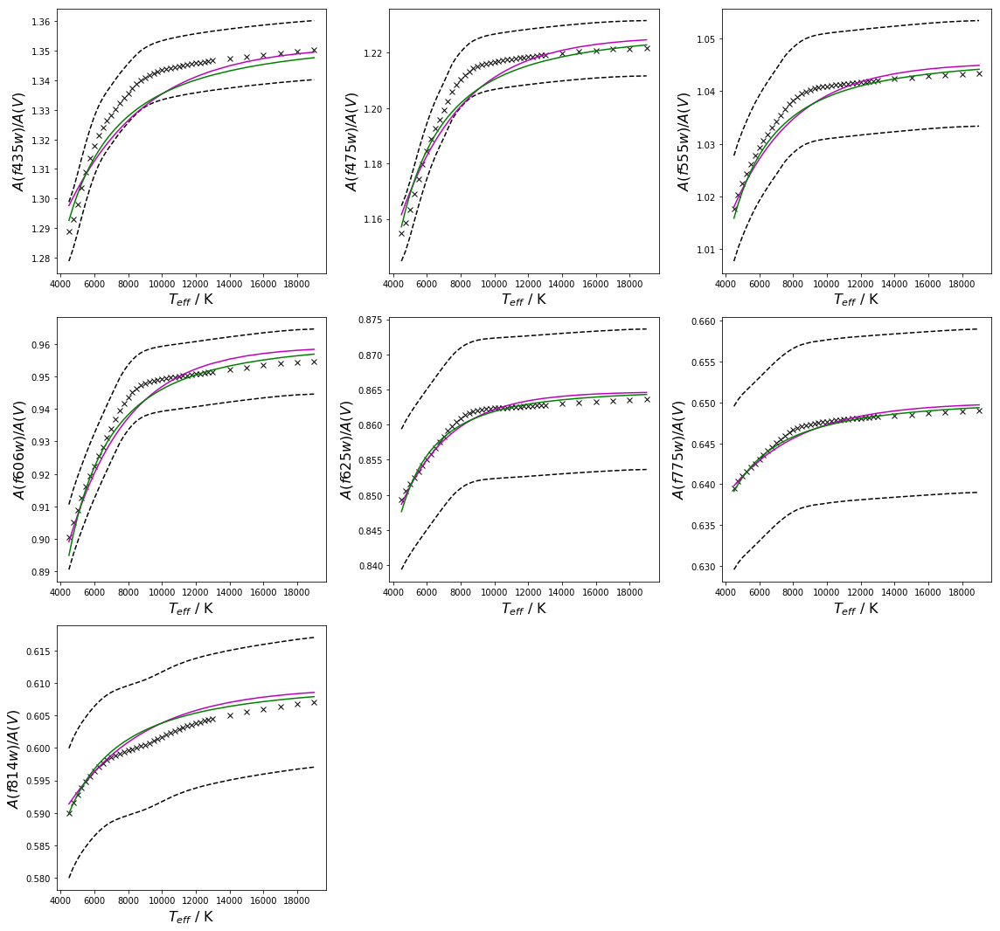


    Writing complete for log(g) = 2.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 2.0
Exponential fit coefficients (should be reused): 
[-0.1436 -2.1592  1.3519]
Standard deviations (should be reused): 
[ 0.031   0.3598  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0205 -1.4151  1.3559]
Standard deviations (should be reused): 
[ 0.0045  0.2767  0.0033]
Logistic fit coefficients: 
[  5.5534e-15   2.5456e+00   1.3516e+00   1.1315e+00]
Standard deviations: 
[  1.9117e+04   1.3873e+00   1.9096e-03   7.3078e-01]
Teff log-normal fit coefficients: 
[-2.      0.568   1.3307  1.3068]
Standard deviations: 
[ 0.      0.1567  0.0015  0.0042]



Deleting missing subplots - discrepancy between 7 and 9


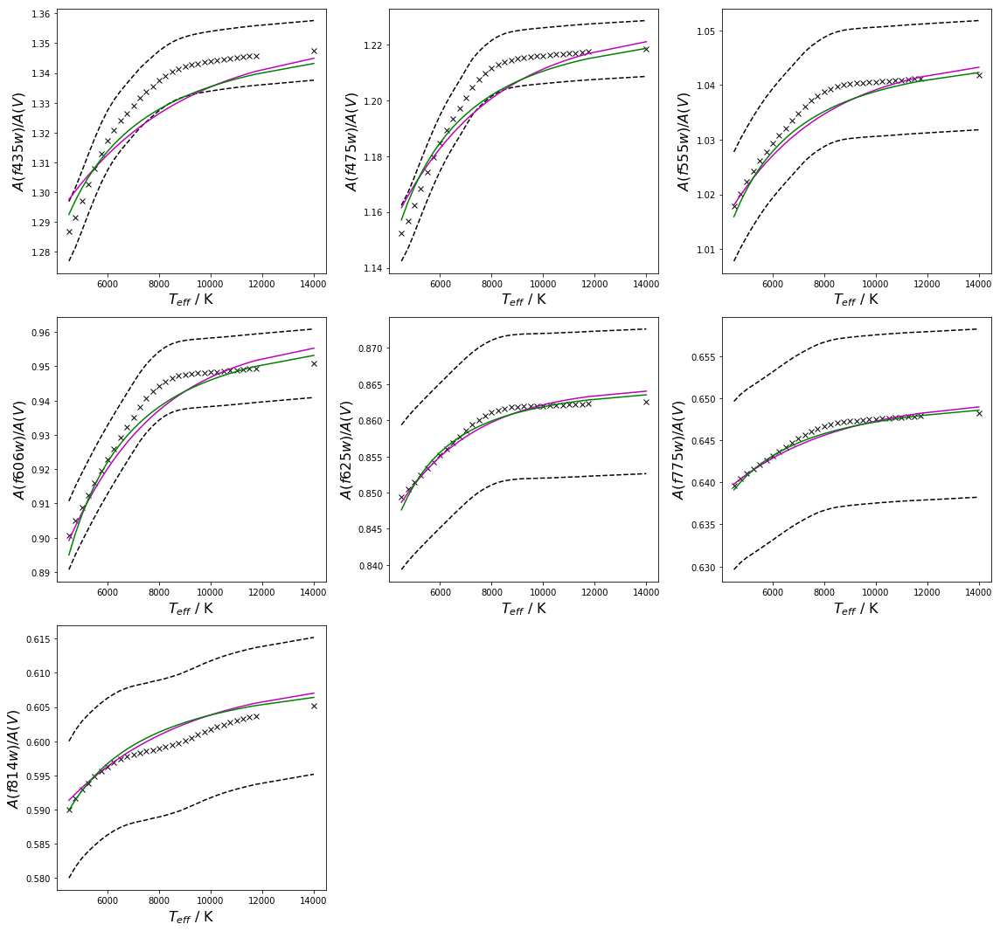


    Writing complete for log(g) = 2.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 1.5
Exponential fit coefficients (should be reused): 
[-0.1436 -2.1592  1.3519]
Standard deviations (should be reused): 
[ 0.031   0.3598  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0205 -1.4151  1.3559]
Standard deviations (should be reused): 
[ 0.0045  0.2767  0.0033]
Logistic fit coefficients: 
[  5.5534e-15   2.5456e+00   1.3516e+00   1.1315e+00]
Standard deviations: 
[  1.9117e+04   1.3873e+00   1.9096e-03   7.3078e-01]
Teff log-normal fit coefficients: 
[-2.      0.568   1.3307  1.3068]
Standard deviations: 
[ 0.      0.1567  0.0015  0.0042]



Deleting missing subplots - discrepancy between 7 and 9


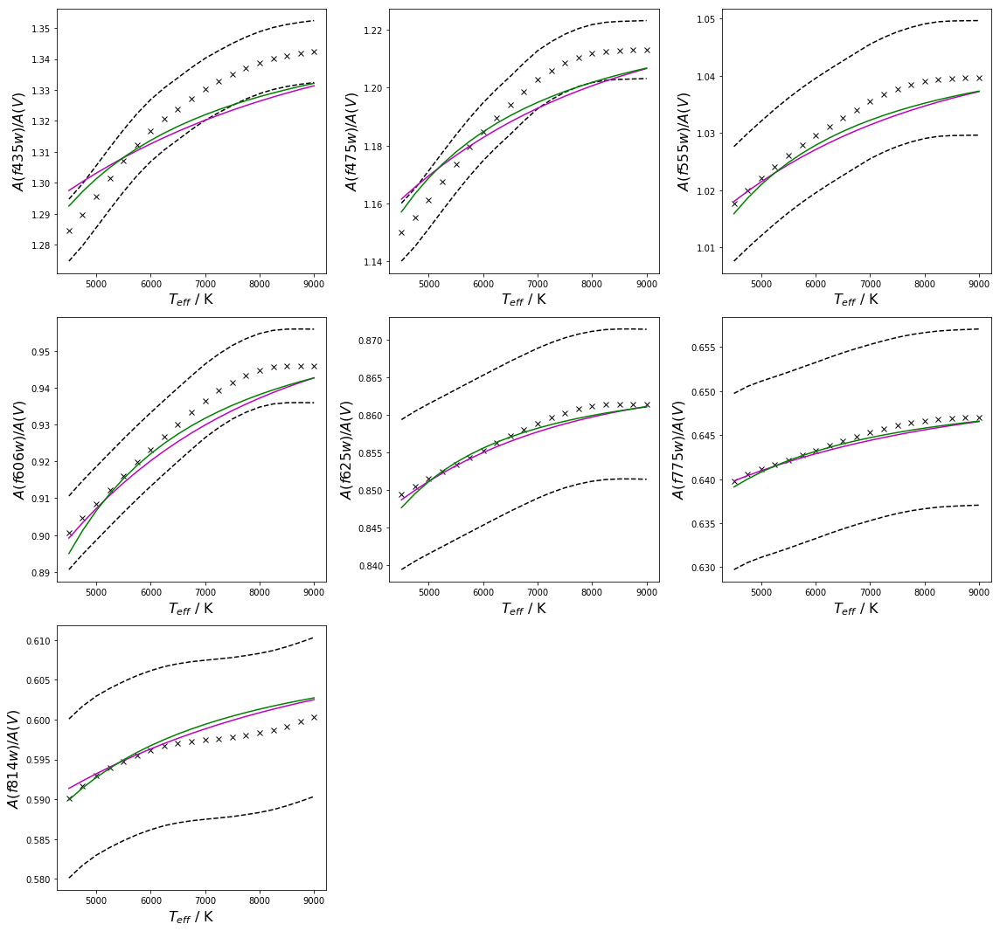


    Writing complete for log(g) = 1.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 1.0
Exponential fit coefficients (should be reused): 
[-0.1436 -2.1592  1.3519]
Standard deviations (should be reused): 
[ 0.031   0.3598  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0205 -1.4151  1.3559]
Standard deviations (should be reused): 
[ 0.0045  0.2767  0.0033]
Logistic fit coefficients: 
[  5.5534e-15   2.5456e+00   1.3516e+00   1.1315e+00]
Standard deviations: 
[  1.9117e+04   1.3873e+00   1.9096e-03   7.3078e-01]
Teff log-normal fit coefficients: 
[-2.      0.568   1.3307  1.3068]
Standard deviations: 
[ 0.      0.1567  0.0015  0.0042]



Deleting missing subplots - discrepancy between 7 and 9


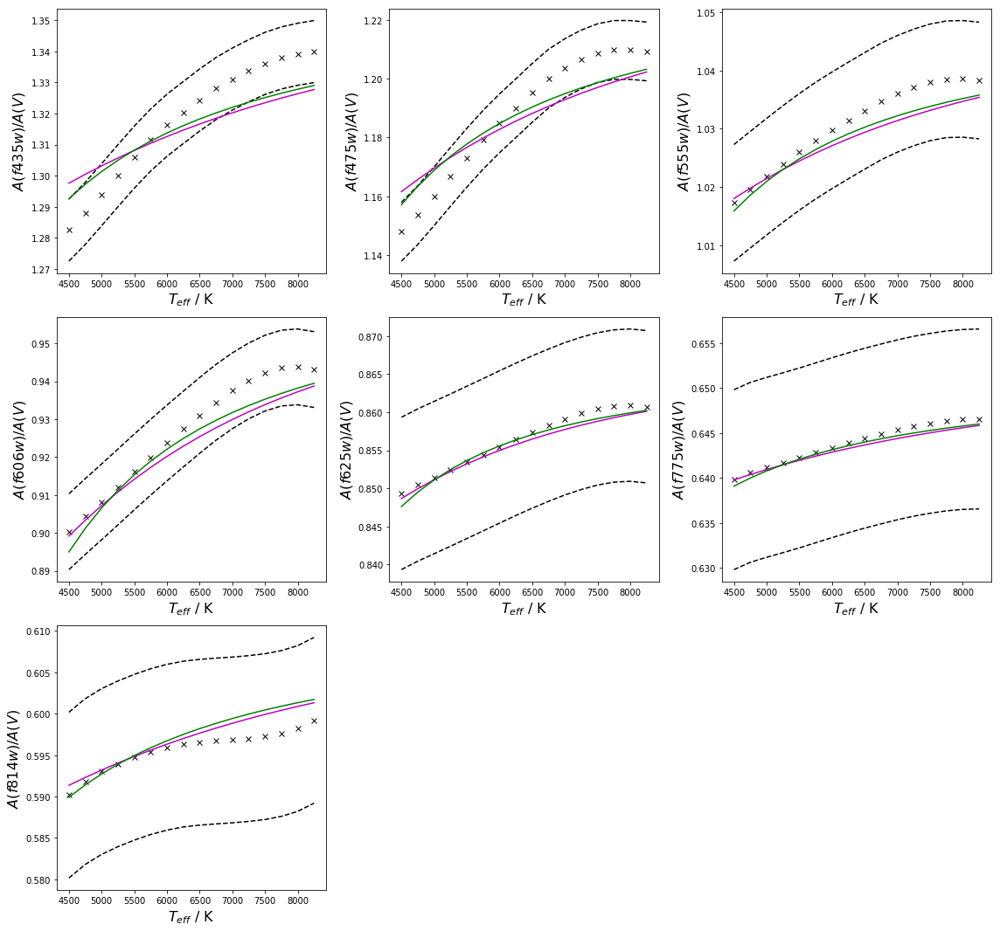


    Writing complete for log(g) = 1.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 0.5
Exponential fit coefficients (should be reused): 
[-0.1436 -2.1592  1.3519]
Standard deviations (should be reused): 
[ 0.031   0.3598  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0205 -1.4151  1.3559]
Standard deviations (should be reused): 
[ 0.0045  0.2767  0.0033]
Logistic fit coefficients: 
[  5.5534e-15   2.5456e+00   1.3516e+00   1.1315e+00]
Standard deviations: 
[  1.9117e+04   1.3873e+00   1.9096e-03   7.3078e-01]
Teff log-normal fit coefficients: 
[-2.      0.568   1.3307  1.3068]
Standard deviations: 
[ 0.      0.1567  0.0015  0.0042]



Deleting missing subplots - discrepancy between 7 and 9


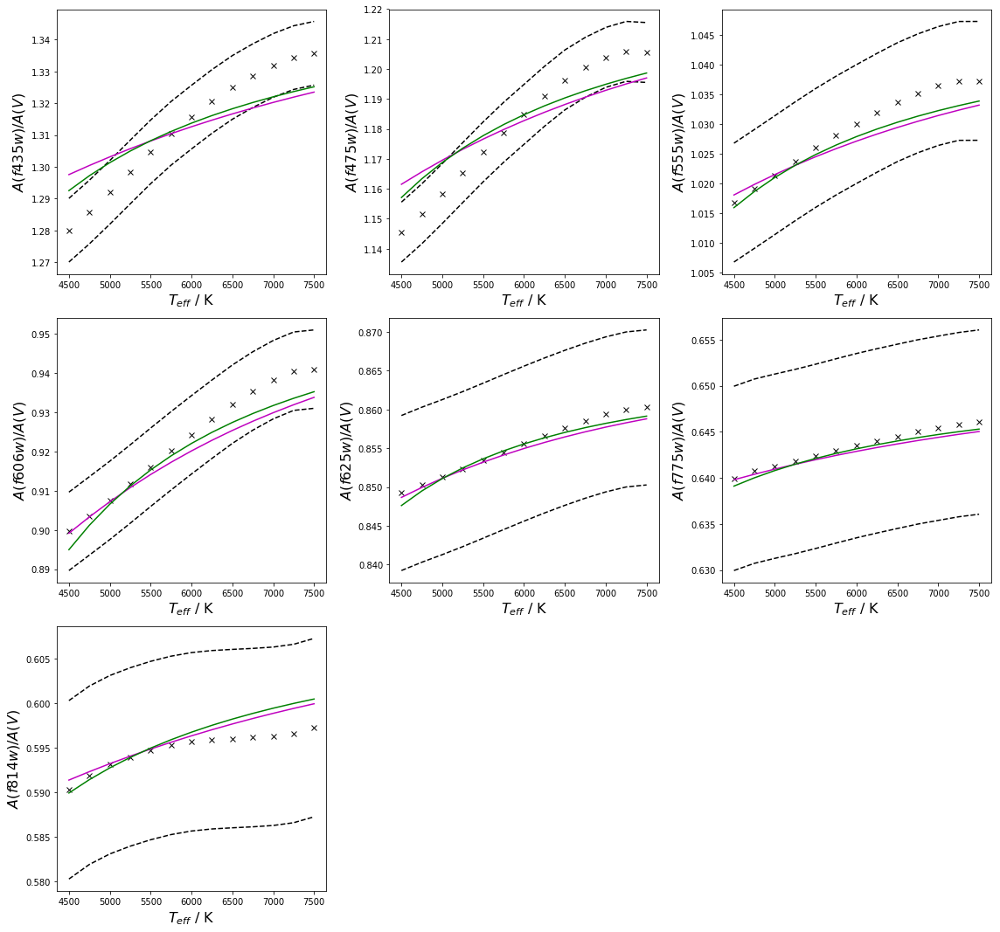


    Writing complete for log(g) = 0.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.0 , 0.0
Exponential fit coefficients (should be reused): 
[-0.1436 -2.1592  1.3519]
Standard deviations (should be reused): 
[ 0.031   0.3598  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0205 -1.4151  1.3559]
Standard deviations (should be reused): 
[ 0.0045  0.2767  0.0033]
Logistic fit coefficients: 
[  5.5534e-15   2.5456e+00   1.3516e+00   1.1315e+00]
Standard deviations: 
[  1.9117e+04   1.3873e+00   1.9096e-03   7.3078e-01]
Teff log-normal fit coefficients: 
[-2.      0.568   1.3307  1.3068]
Standard deviations: 
[ 0.      0.1567  0.0015  0.0042]



Deleting missing subplots - discrepancy between 7 and 9


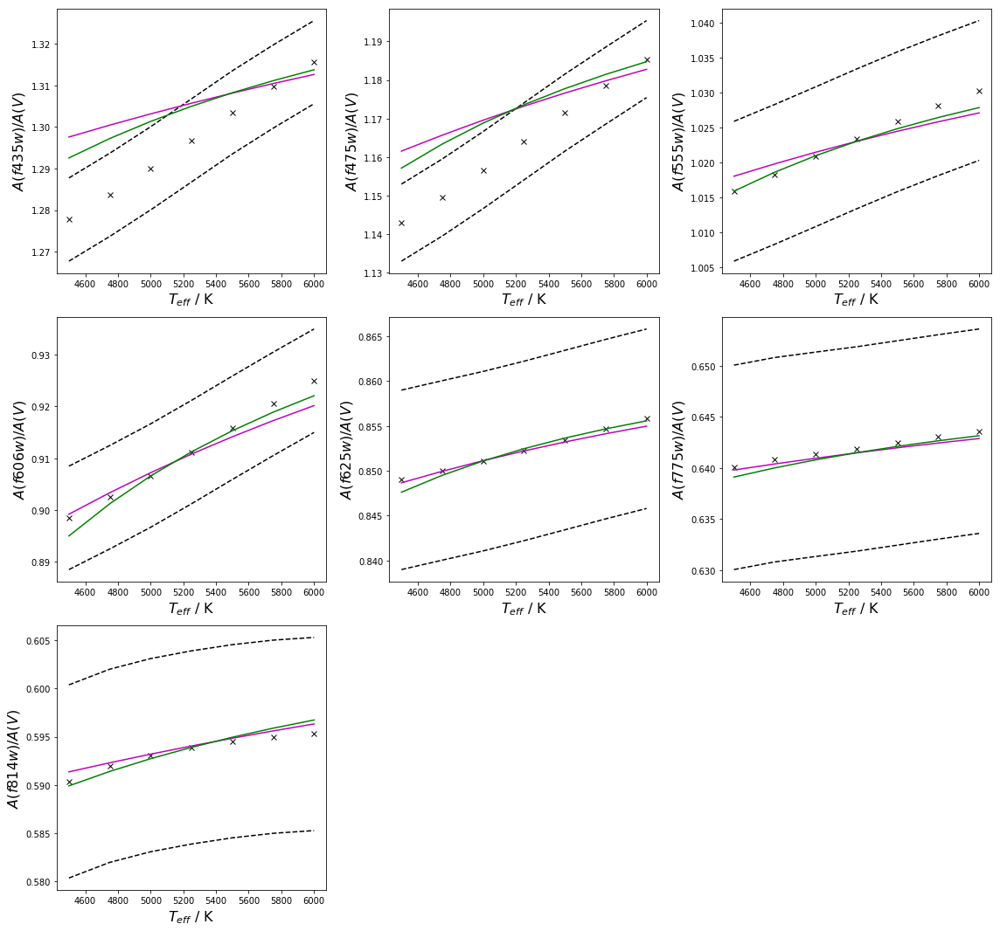


    Writing complete for log(g) = 0.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 5.0
Deleting missing subplots - discrepancy between 7 and 9


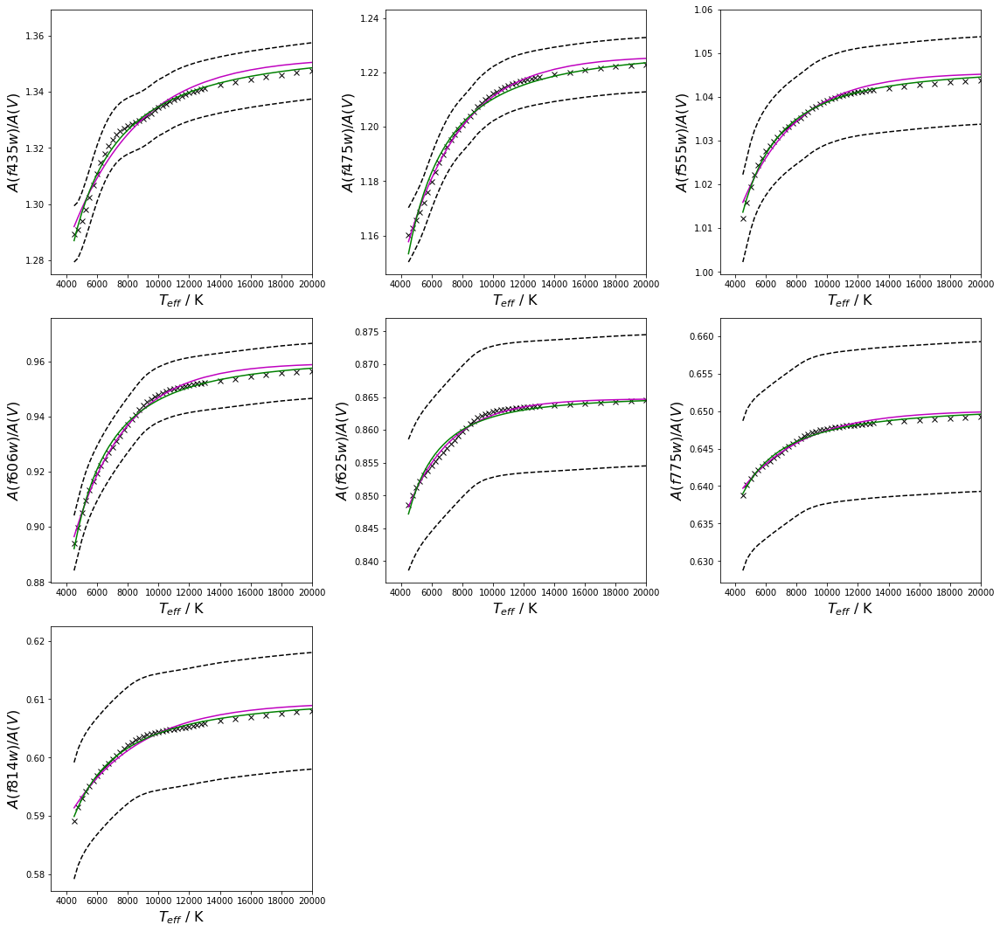


    Writing complete for log(g) = 5.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 4.5
Exponential fit coefficients (should be reused): 
[-0.1663 -2.2566  1.3522]
Standard deviations (should be reused): 
[ 0.0337  0.3398  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0217 -1.4563  1.3564]
Standard deviations (should be reused): 
[ 0.0043  0.2557  0.0032]
Logistic fit coefficients: 
[  1.0323e-11   2.6387e+00   1.3519e+00   1.0998e+00]
Standard deviations: 
[  1.6971e+04   1.2788e+00   1.8880e-03   7.7811e-01]
Teff log-normal fit coefficients: 
[-2.      0.5079  1.3296  1.3044]
Standard deviations: 
[ 0.      0.1276  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


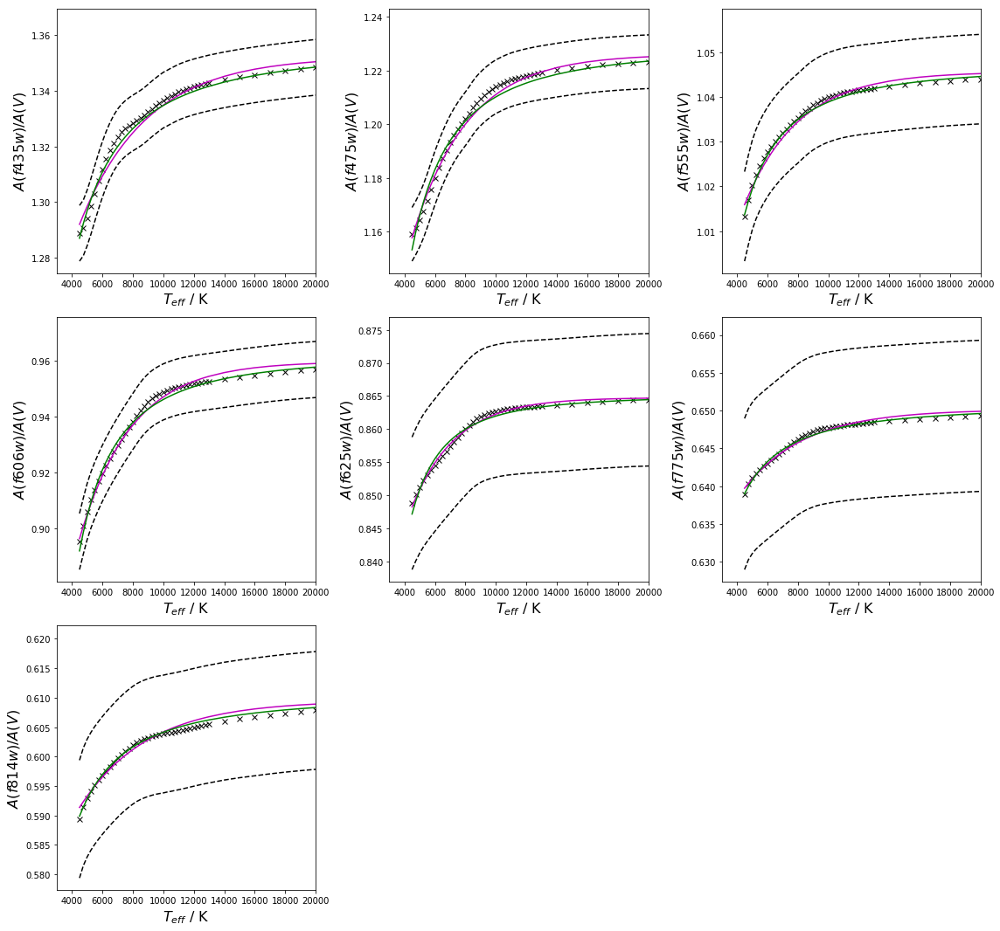


    Writing complete for log(g) = 4.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 4.0
Exponential fit coefficients (should be reused): 
[-0.1663 -2.2566  1.3522]
Standard deviations (should be reused): 
[ 0.0337  0.3398  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0217 -1.4563  1.3564]
Standard deviations (should be reused): 
[ 0.0043  0.2557  0.0032]
Logistic fit coefficients: 
[  1.0323e-11   2.6387e+00   1.3519e+00   1.0998e+00]
Standard deviations: 
[  1.6971e+04   1.2788e+00   1.8880e-03   7.7811e-01]
Teff log-normal fit coefficients: 
[-2.      0.5079  1.3296  1.3044]
Standard deviations: 
[ 0.      0.1276  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


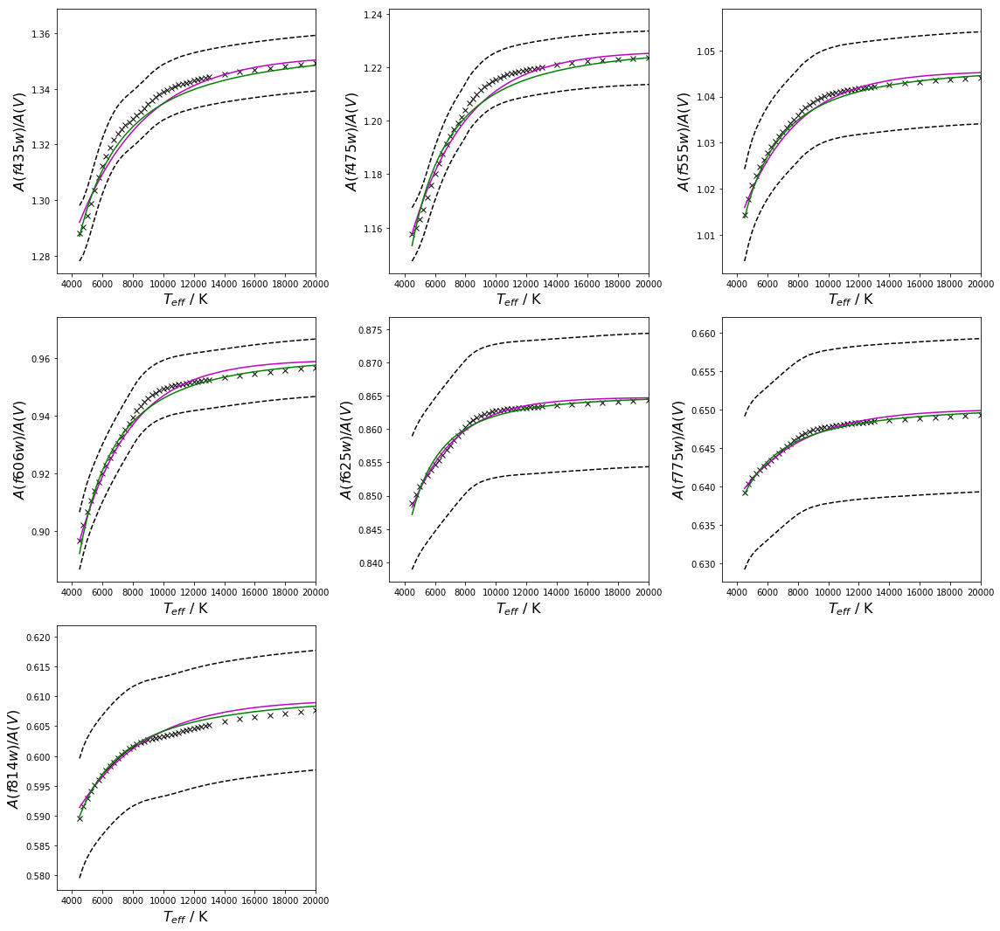


    Writing complete for log(g) = 4.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 3.5
Exponential fit coefficients (should be reused): 
[-0.1663 -2.2566  1.3522]
Standard deviations (should be reused): 
[ 0.0337  0.3398  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0217 -1.4563  1.3564]
Standard deviations (should be reused): 
[ 0.0043  0.2557  0.0032]
Logistic fit coefficients: 
[  1.0323e-11   2.6387e+00   1.3519e+00   1.0998e+00]
Standard deviations: 
[  1.6971e+04   1.2788e+00   1.8880e-03   7.7811e-01]
Teff log-normal fit coefficients: 
[-2.      0.5079  1.3296  1.3044]
Standard deviations: 
[ 0.      0.1276  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


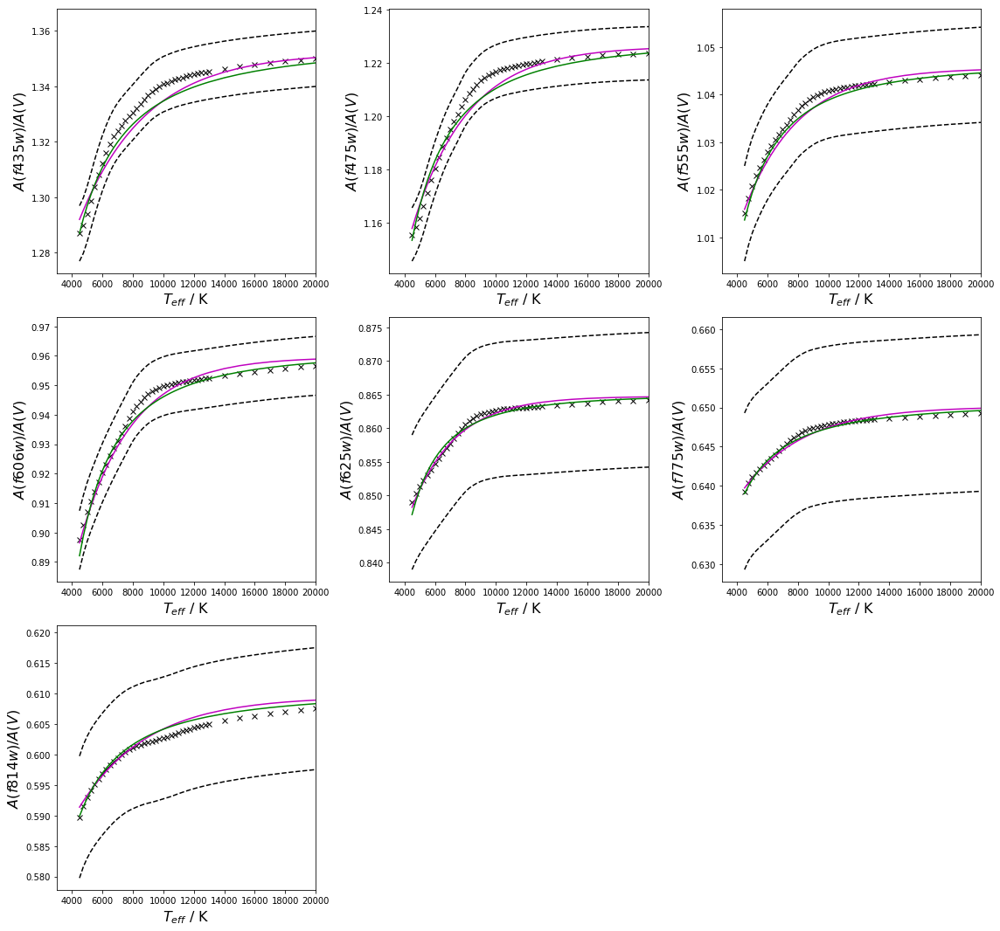


    Writing complete for log(g) = 3.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 3.0
Exponential fit coefficients (should be reused): 
[-0.1663 -2.2566  1.3522]
Standard deviations (should be reused): 
[ 0.0337  0.3398  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0217 -1.4563  1.3564]
Standard deviations (should be reused): 
[ 0.0043  0.2557  0.0032]
Logistic fit coefficients: 
[  1.0323e-11   2.6387e+00   1.3519e+00   1.0998e+00]
Standard deviations: 
[  1.6971e+04   1.2788e+00   1.8880e-03   7.7811e-01]
Teff log-normal fit coefficients: 
[-2.      0.5079  1.3296  1.3044]
Standard deviations: 
[ 0.      0.1276  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


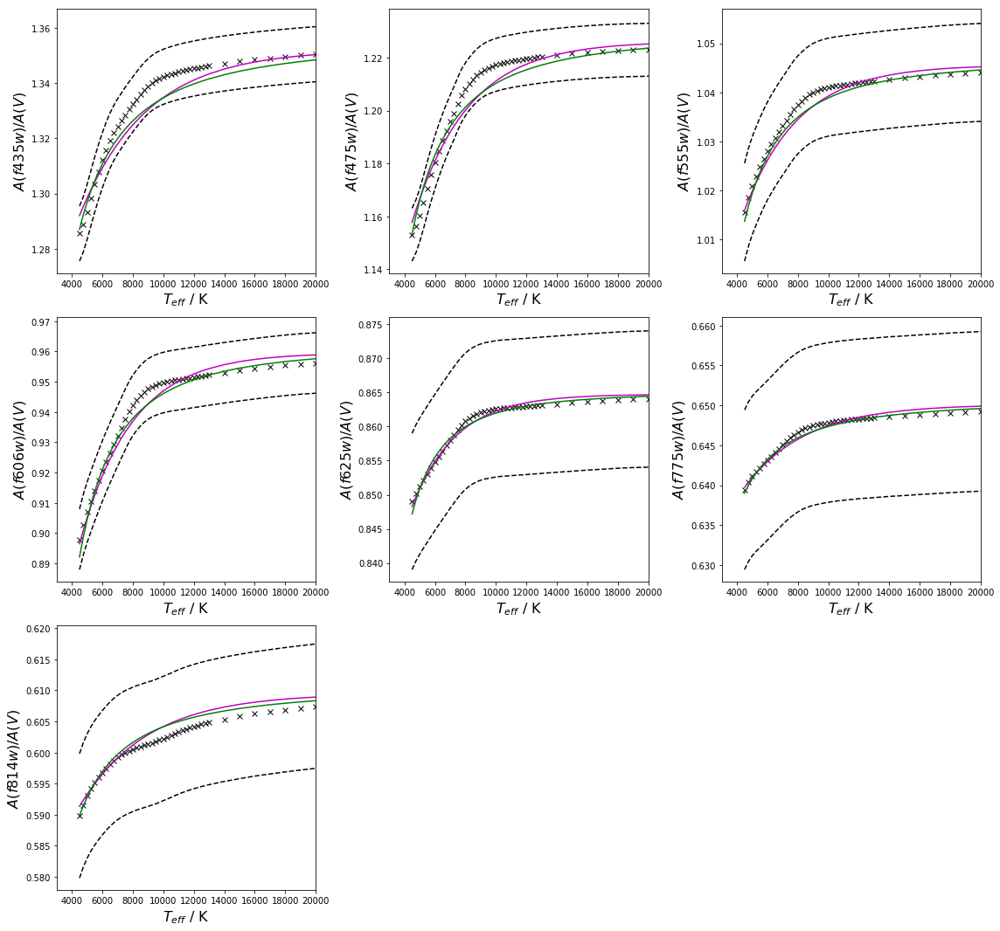


    Writing complete for log(g) = 3.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 2.5
Exponential fit coefficients (should be reused): 
[-0.1663 -2.2566  1.3522]
Standard deviations (should be reused): 
[ 0.0337  0.3398  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0217 -1.4563  1.3564]
Standard deviations (should be reused): 
[ 0.0043  0.2557  0.0032]
Logistic fit coefficients: 
[  1.0323e-11   2.6387e+00   1.3519e+00   1.0998e+00]
Standard deviations: 
[  1.6971e+04   1.2788e+00   1.8880e-03   7.7811e-01]
Teff log-normal fit coefficients: 
[-2.      0.5079  1.3296  1.3044]
Standard deviations: 
[ 0.      0.1276  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


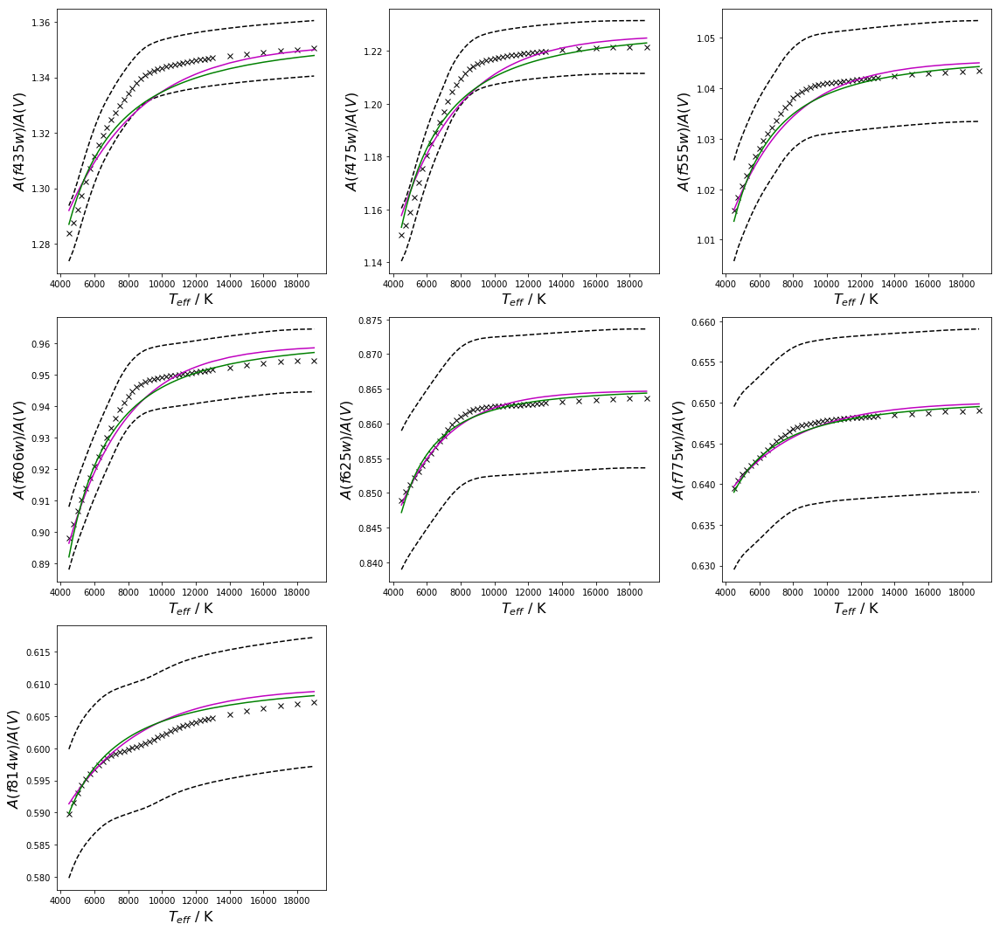


    Writing complete for log(g) = 2.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 2.0
Exponential fit coefficients (should be reused): 
[-0.1663 -2.2566  1.3522]
Standard deviations (should be reused): 
[ 0.0337  0.3398  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0217 -1.4563  1.3564]
Standard deviations (should be reused): 
[ 0.0043  0.2557  0.0032]
Logistic fit coefficients: 
[  1.0323e-11   2.6387e+00   1.3519e+00   1.0998e+00]
Standard deviations: 
[  1.6971e+04   1.2788e+00   1.8880e-03   7.7811e-01]
Teff log-normal fit coefficients: 
[-2.      0.5079  1.3296  1.3044]
Standard deviations: 
[ 0.      0.1276  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


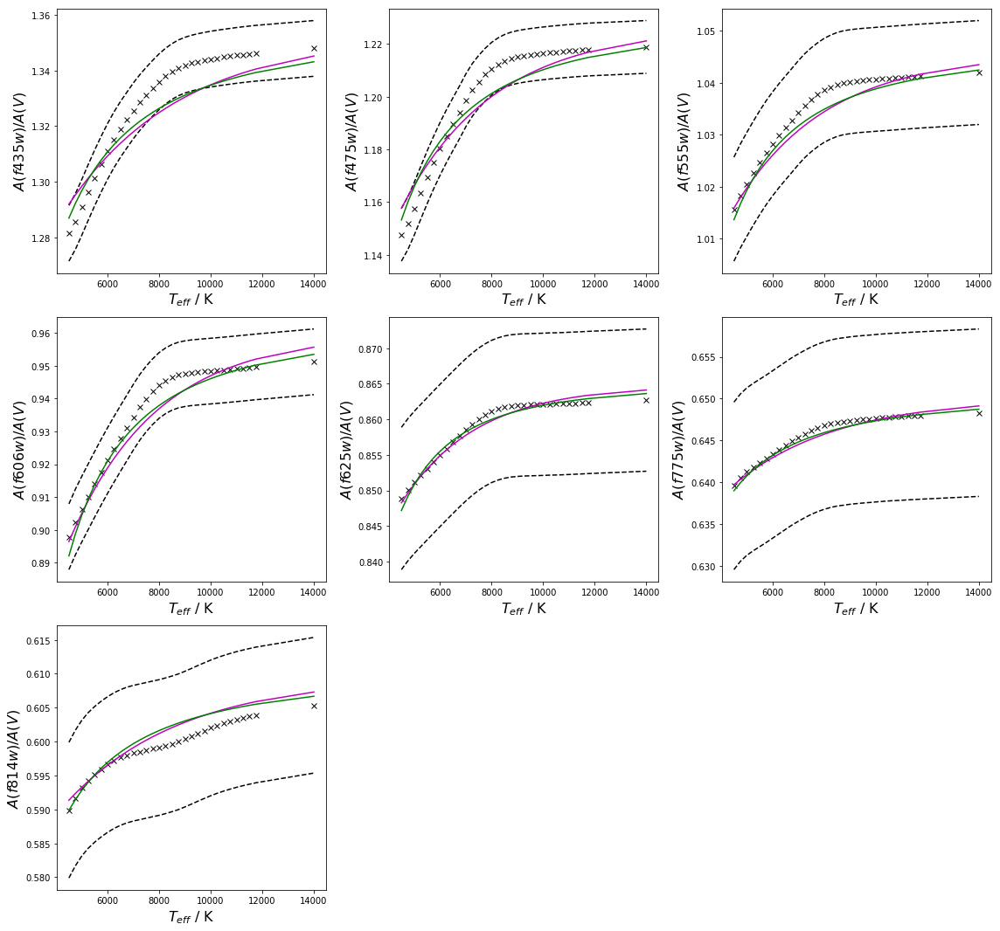


    Writing complete for log(g) = 2.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 1.5
Exponential fit coefficients (should be reused): 
[-0.1663 -2.2566  1.3522]
Standard deviations (should be reused): 
[ 0.0337  0.3398  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0217 -1.4563  1.3564]
Standard deviations (should be reused): 
[ 0.0043  0.2557  0.0032]
Logistic fit coefficients: 
[  1.0323e-11   2.6387e+00   1.3519e+00   1.0998e+00]
Standard deviations: 
[  1.6971e+04   1.2788e+00   1.8880e-03   7.7811e-01]
Teff log-normal fit coefficients: 
[-2.      0.5079  1.3296  1.3044]
Standard deviations: 
[ 0.      0.1276  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


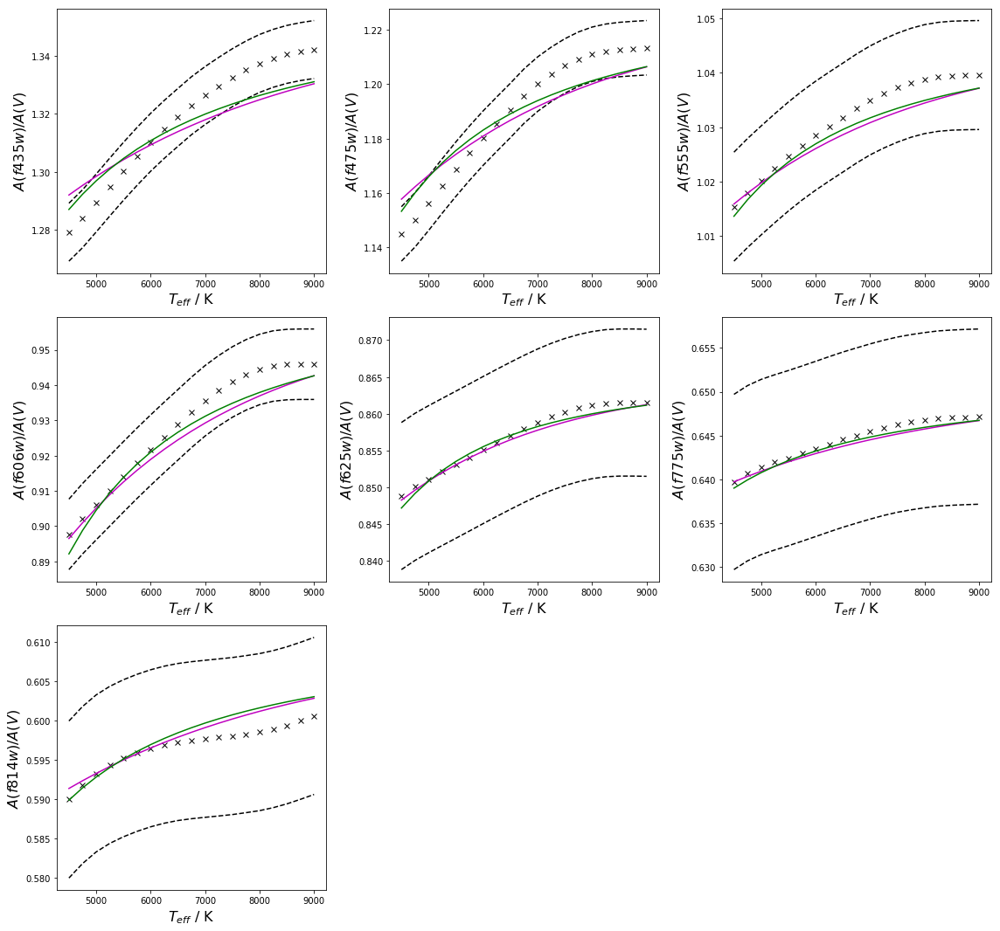


    Writing complete for log(g) = 1.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 1.0
Exponential fit coefficients (should be reused): 
[-0.1663 -2.2566  1.3522]
Standard deviations (should be reused): 
[ 0.0337  0.3398  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0217 -1.4563  1.3564]
Standard deviations (should be reused): 
[ 0.0043  0.2557  0.0032]
Logistic fit coefficients: 
[  1.0323e-11   2.6387e+00   1.3519e+00   1.0998e+00]
Standard deviations: 
[  1.6971e+04   1.2788e+00   1.8880e-03   7.7811e-01]
Teff log-normal fit coefficients: 
[-2.      0.5079  1.3296  1.3044]
Standard deviations: 
[ 0.      0.1276  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


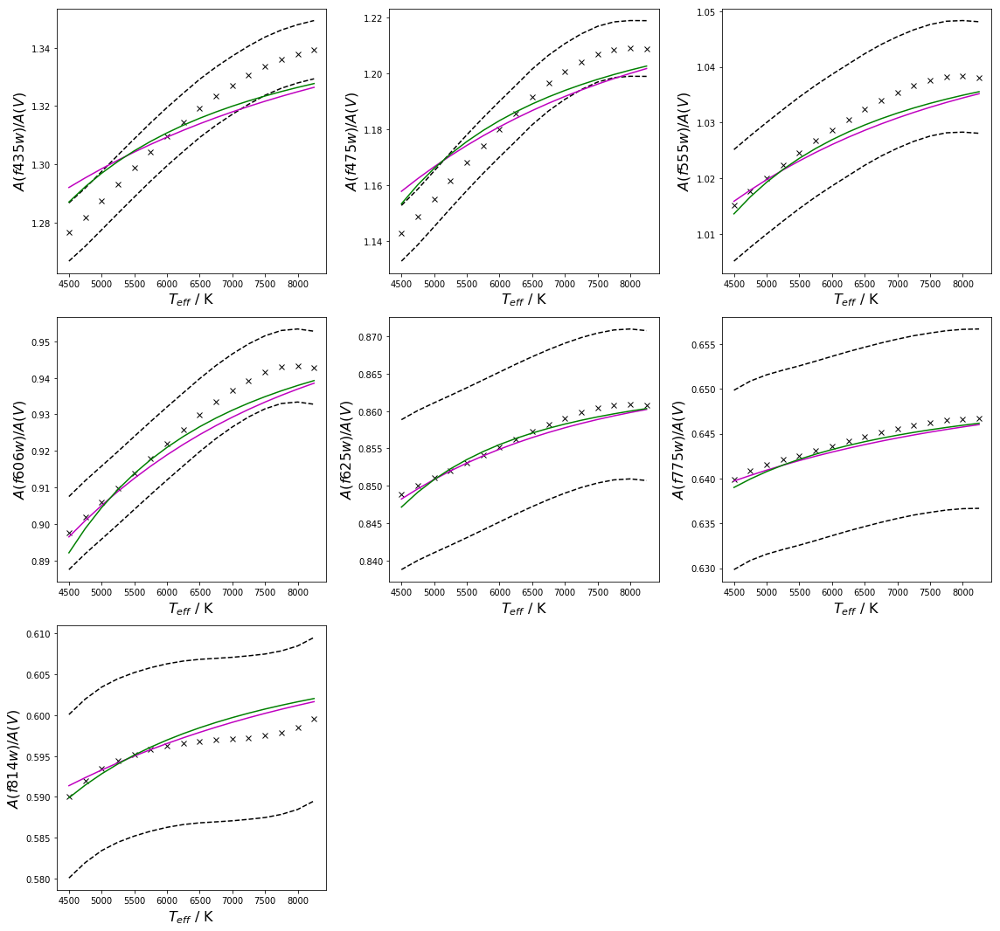


    Writing complete for log(g) = 1.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 0.5
Exponential fit coefficients (should be reused): 
[-0.1663 -2.2566  1.3522]
Standard deviations (should be reused): 
[ 0.0337  0.3398  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0217 -1.4563  1.3564]
Standard deviations (should be reused): 
[ 0.0043  0.2557  0.0032]
Logistic fit coefficients: 
[  1.0323e-11   2.6387e+00   1.3519e+00   1.0998e+00]
Standard deviations: 
[  1.6971e+04   1.2788e+00   1.8880e-03   7.7811e-01]
Teff log-normal fit coefficients: 
[-2.      0.5079  1.3296  1.3044]
Standard deviations: 
[ 0.      0.1276  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


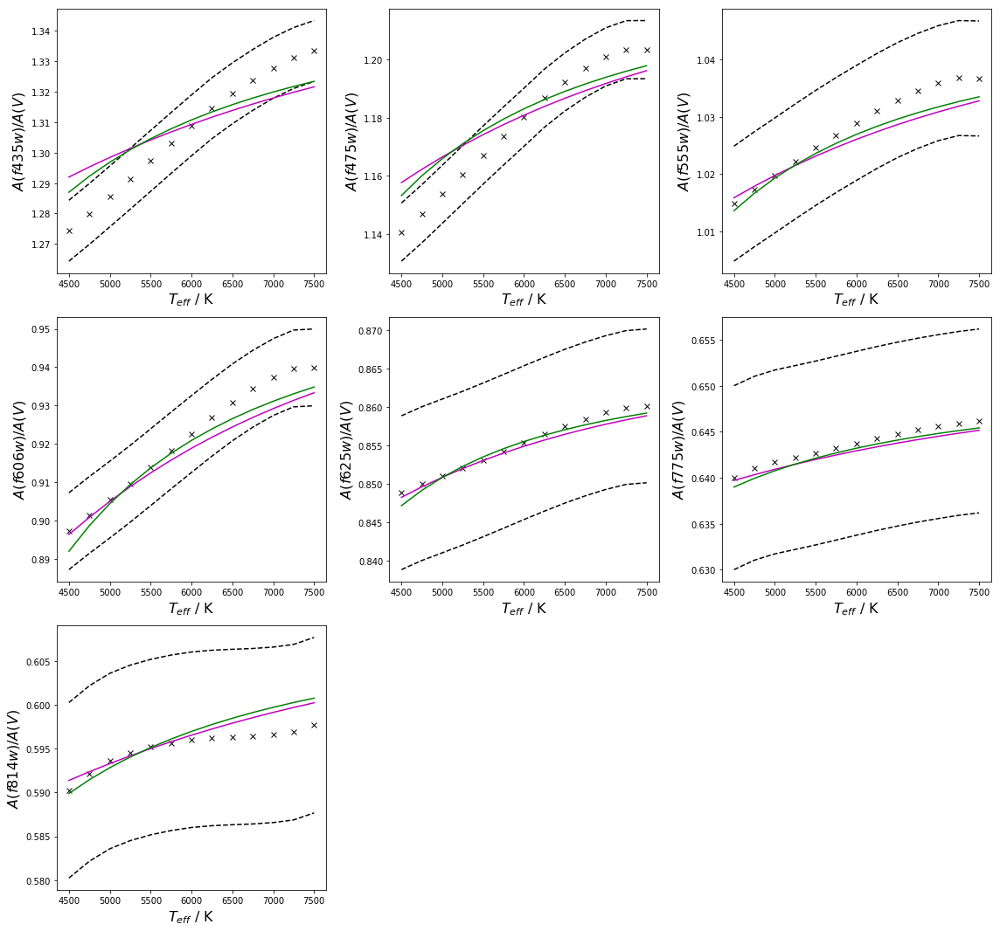


    Writing complete for log(g) = 0.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


3.1,0.5 , 0.0
Exponential fit coefficients (should be reused): 
[-0.1663 -2.2566  1.3522]
Standard deviations (should be reused): 
[ 0.0337  0.3398  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0217 -1.4563  1.3564]
Standard deviations (should be reused): 
[ 0.0043  0.2557  0.0032]
Logistic fit coefficients: 
[  1.0323e-11   2.6387e+00   1.3519e+00   1.0998e+00]
Standard deviations: 
[  1.6971e+04   1.2788e+00   1.8880e-03   7.7811e-01]
Teff log-normal fit coefficients: 
[-2.      0.5079  1.3296  1.3044]
Standard deviations: 
[ 0.      0.1276  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


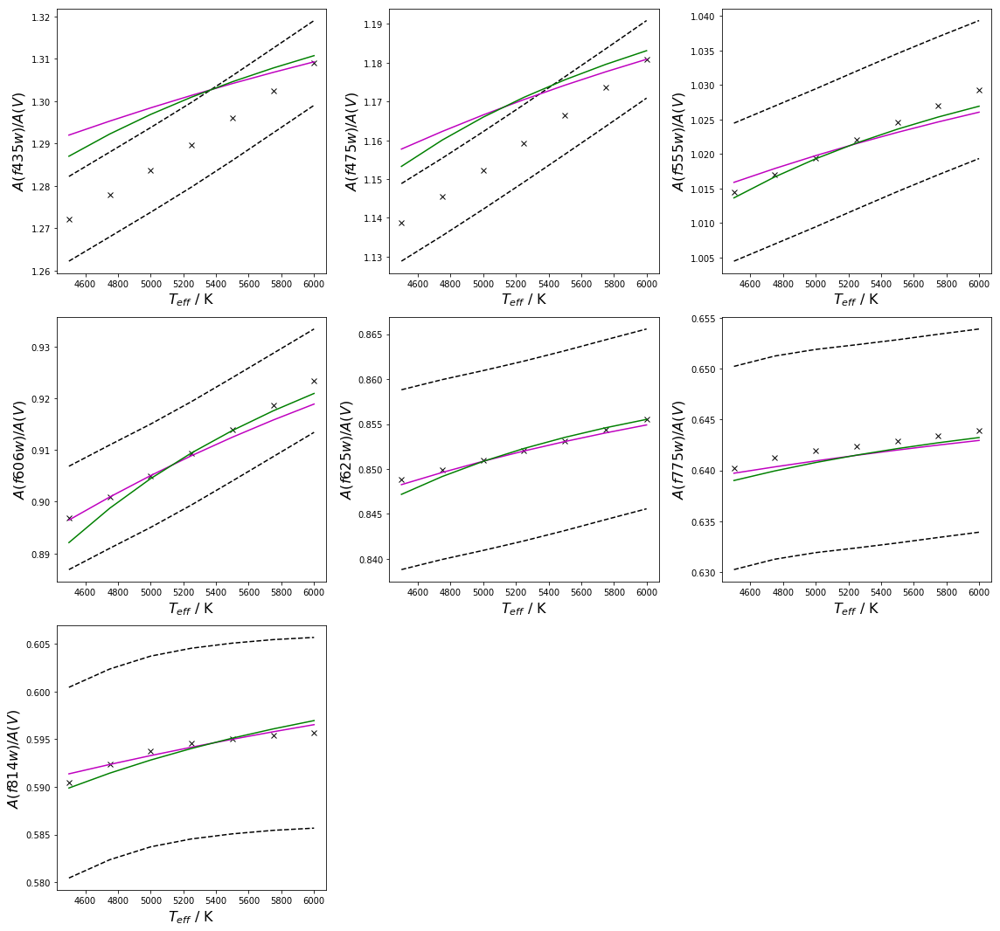


    Writing complete for log(g) = 0.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 5.0
Deleting missing subplots - discrepancy between 7 and 9


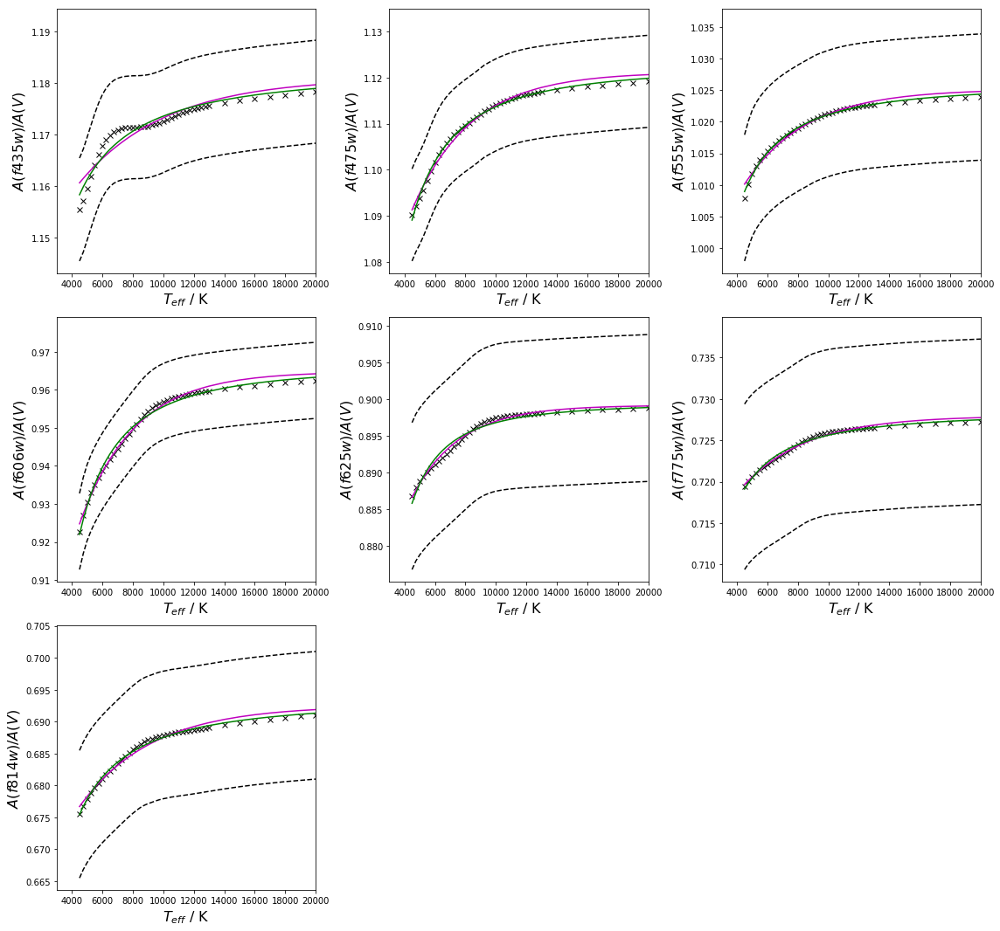


    Writing complete for log(g) = 5.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 4.5
Exponential fit coefficients (should be reused): 
[-0.0449 -1.7551  1.181 ]
Standard deviations (should be reused): 
[ 0.0219  0.7861  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0096 -1.1957  1.1831]
Standard deviations (should be reused): 
[ 0.0054  0.6713  0.0042]
Logistic fit coefficients: 
[  4.3054e-17   2.1242e+00   1.1809e+00   1.1097e+00]
Standard deviations: 
[  5.4573e+04   3.2714e+00   2.0815e-03   5.3970e-01]
Teff log-normal fit coefficients: 
[-2.      0.6961  1.172   1.1616]
Standard deviations: 
[ 0.      0.5156  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


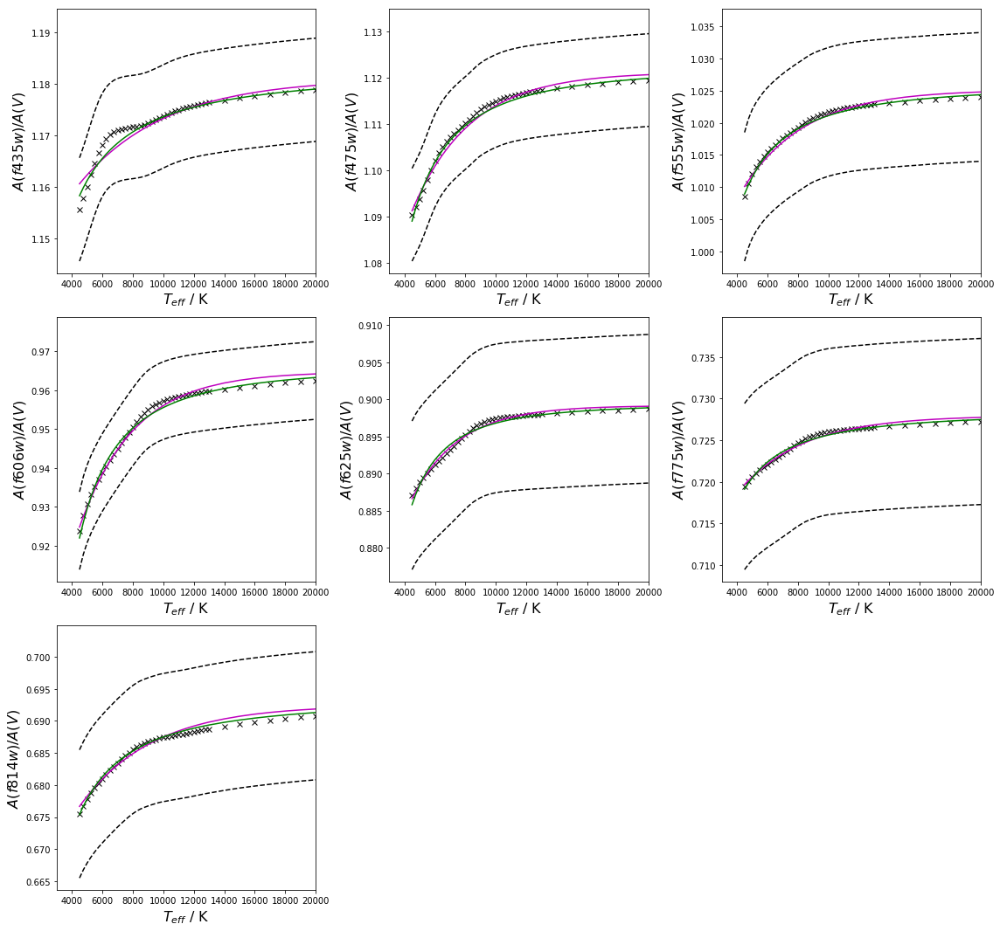


    Writing complete for log(g) = 4.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 4.0
Exponential fit coefficients (should be reused): 
[-0.0449 -1.7551  1.181 ]
Standard deviations (should be reused): 
[ 0.0219  0.7861  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0096 -1.1957  1.1831]
Standard deviations (should be reused): 
[ 0.0054  0.6713  0.0042]
Logistic fit coefficients: 
[  4.3054e-17   2.1242e+00   1.1809e+00   1.1097e+00]
Standard deviations: 
[  5.4573e+04   3.2714e+00   2.0815e-03   5.3970e-01]
Teff log-normal fit coefficients: 
[-2.      0.6961  1.172   1.1616]
Standard deviations: 
[ 0.      0.5156  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


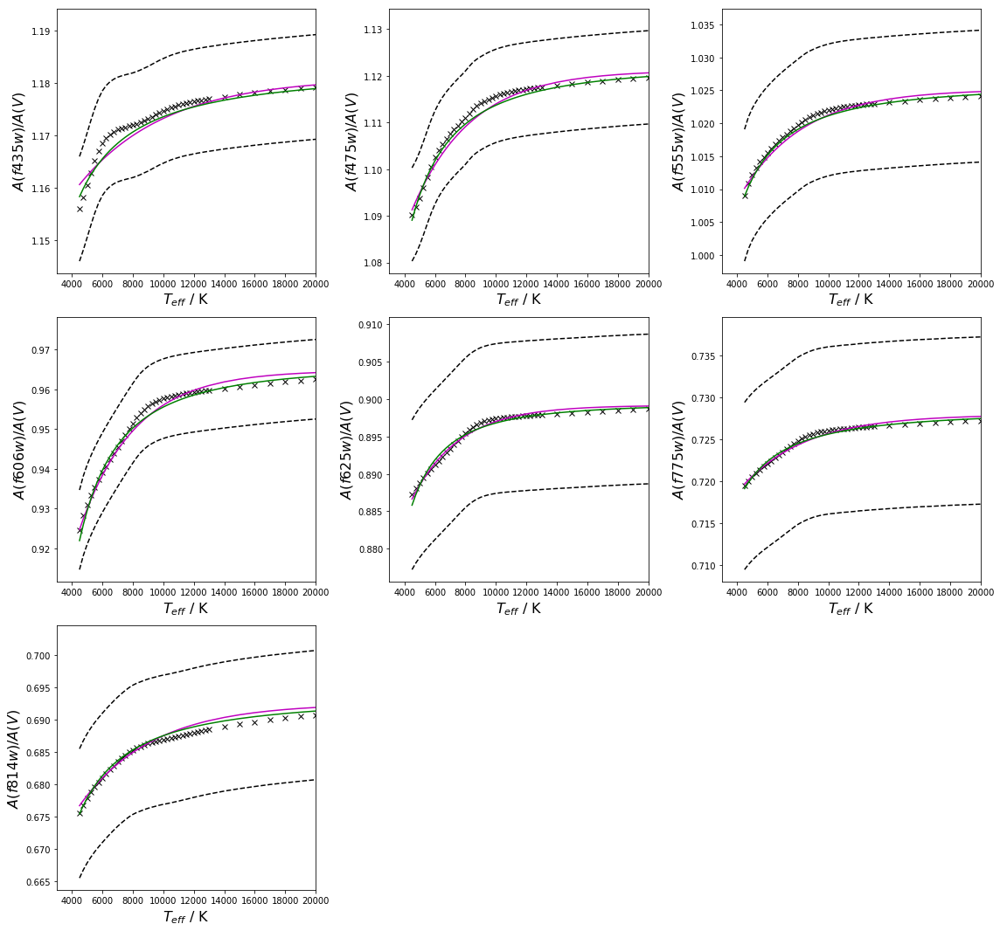


    Writing complete for log(g) = 4.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 3.5
Exponential fit coefficients (should be reused): 
[-0.0449 -1.7551  1.181 ]
Standard deviations (should be reused): 
[ 0.0219  0.7861  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0096 -1.1957  1.1831]
Standard deviations (should be reused): 
[ 0.0054  0.6713  0.0042]
Logistic fit coefficients: 
[  4.3054e-17   2.1242e+00   1.1809e+00   1.1097e+00]
Standard deviations: 
[  5.4573e+04   3.2714e+00   2.0815e-03   5.3970e-01]
Teff log-normal fit coefficients: 
[-2.      0.6961  1.172   1.1616]
Standard deviations: 
[ 0.      0.5156  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


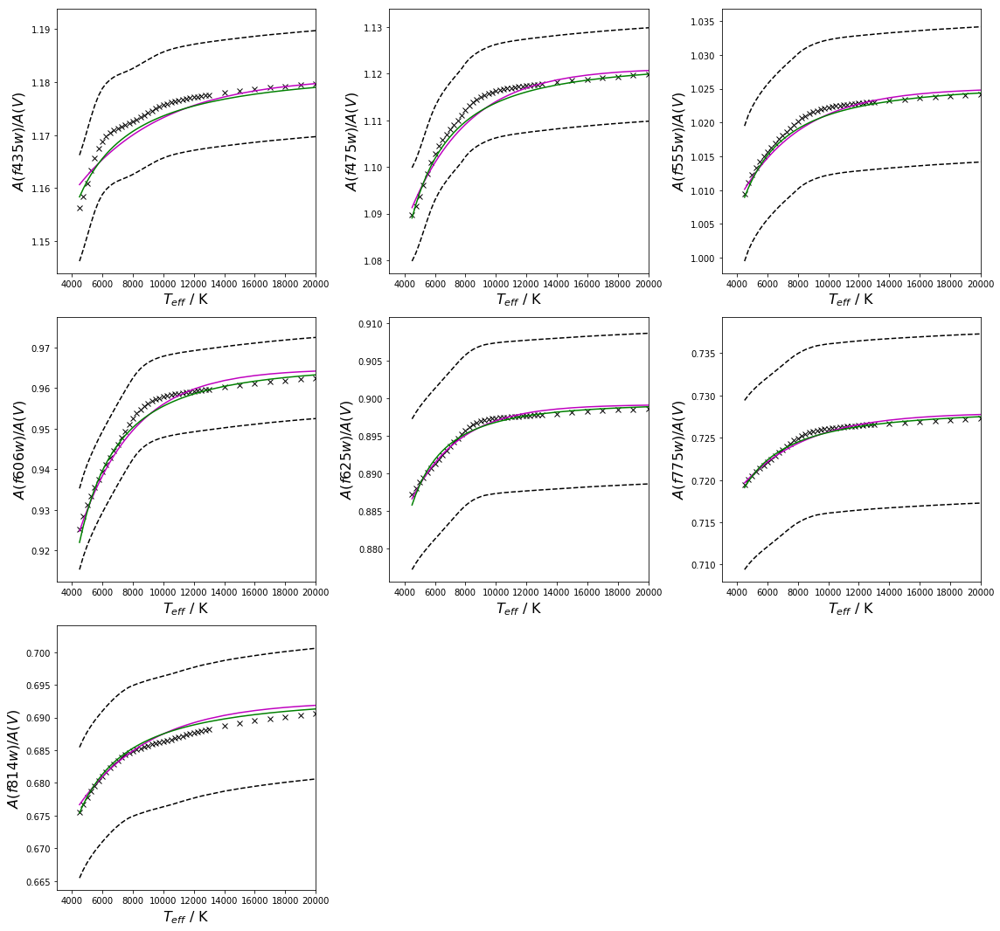


    Writing complete for log(g) = 3.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 3.0
Exponential fit coefficients (should be reused): 
[-0.0449 -1.7551  1.181 ]
Standard deviations (should be reused): 
[ 0.0219  0.7861  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0096 -1.1957  1.1831]
Standard deviations (should be reused): 
[ 0.0054  0.6713  0.0042]
Logistic fit coefficients: 
[  4.3054e-17   2.1242e+00   1.1809e+00   1.1097e+00]
Standard deviations: 
[  5.4573e+04   3.2714e+00   2.0815e-03   5.3970e-01]
Teff log-normal fit coefficients: 
[-2.      0.6961  1.172   1.1616]
Standard deviations: 
[ 0.      0.5156  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


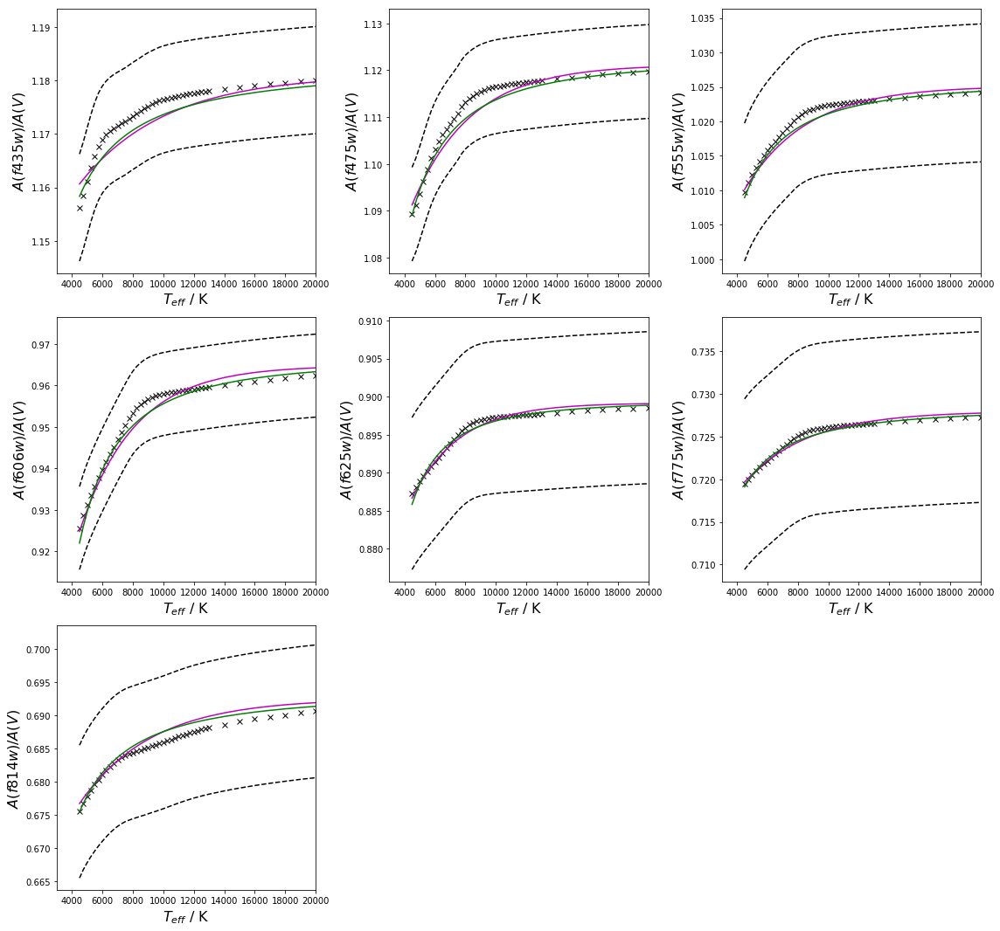


    Writing complete for log(g) = 3.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 2.5
Exponential fit coefficients (should be reused): 
[-0.0449 -1.7551  1.181 ]
Standard deviations (should be reused): 
[ 0.0219  0.7861  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0096 -1.1957  1.1831]
Standard deviations (should be reused): 
[ 0.0054  0.6713  0.0042]
Logistic fit coefficients: 
[  4.3054e-17   2.1242e+00   1.1809e+00   1.1097e+00]
Standard deviations: 
[  5.4573e+04   3.2714e+00   2.0815e-03   5.3970e-01]
Teff log-normal fit coefficients: 
[-2.      0.6961  1.172   1.1616]
Standard deviations: 
[ 0.      0.5156  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


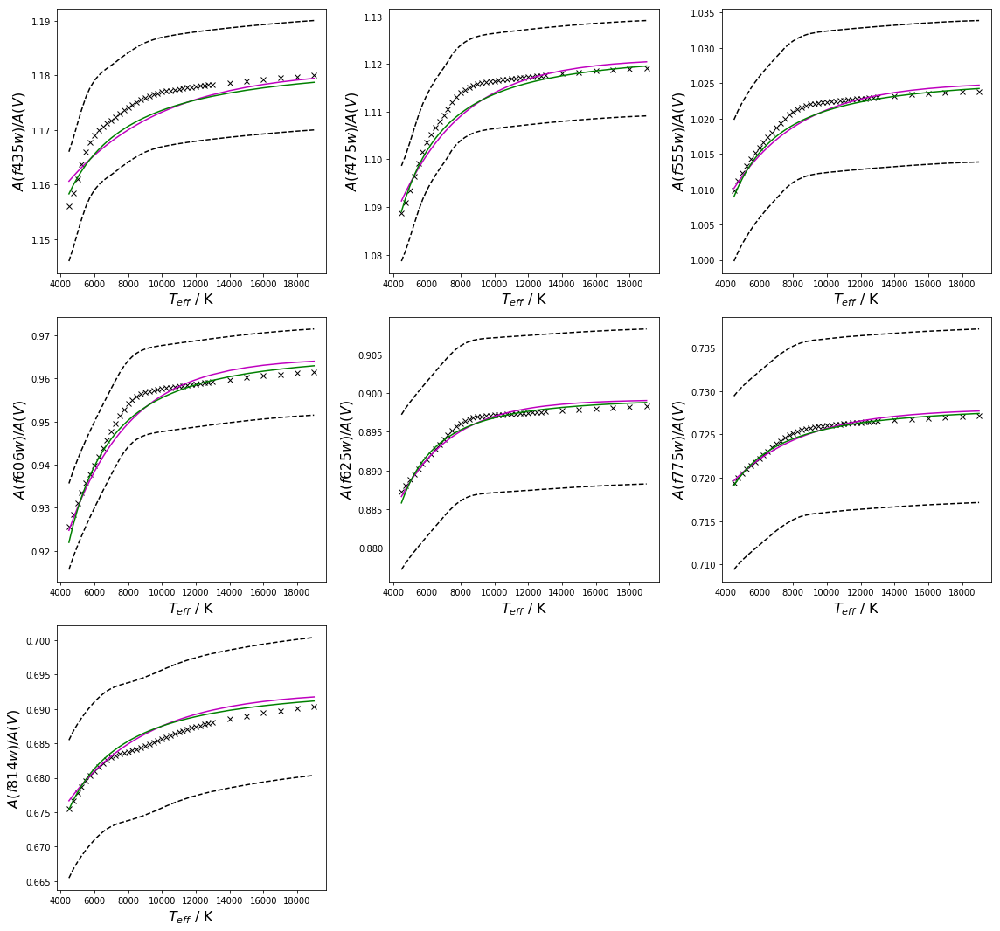


    Writing complete for log(g) = 2.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 2.0
Exponential fit coefficients (should be reused): 
[-0.0449 -1.7551  1.181 ]
Standard deviations (should be reused): 
[ 0.0219  0.7861  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0096 -1.1957  1.1831]
Standard deviations (should be reused): 
[ 0.0054  0.6713  0.0042]
Logistic fit coefficients: 
[  4.3054e-17   2.1242e+00   1.1809e+00   1.1097e+00]
Standard deviations: 
[  5.4573e+04   3.2714e+00   2.0815e-03   5.3970e-01]
Teff log-normal fit coefficients: 
[-2.      0.6961  1.172   1.1616]
Standard deviations: 
[ 0.      0.5156  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


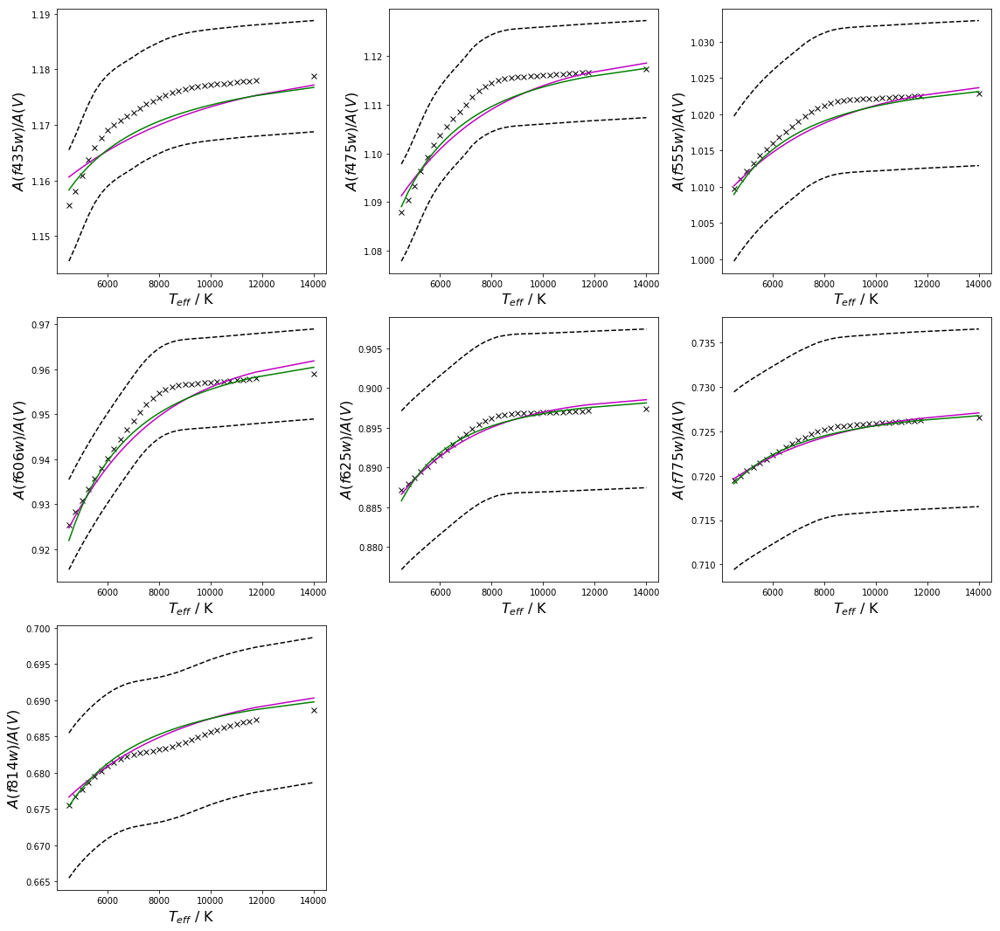


    Writing complete for log(g) = 2.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 1.5
Exponential fit coefficients (should be reused): 
[-0.0449 -1.7551  1.181 ]
Standard deviations (should be reused): 
[ 0.0219  0.7861  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0096 -1.1957  1.1831]
Standard deviations (should be reused): 
[ 0.0054  0.6713  0.0042]
Logistic fit coefficients: 
[  4.3054e-17   2.1242e+00   1.1809e+00   1.1097e+00]
Standard deviations: 
[  5.4573e+04   3.2714e+00   2.0815e-03   5.3970e-01]
Teff log-normal fit coefficients: 
[-2.      0.6961  1.172   1.1616]
Standard deviations: 
[ 0.      0.5156  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


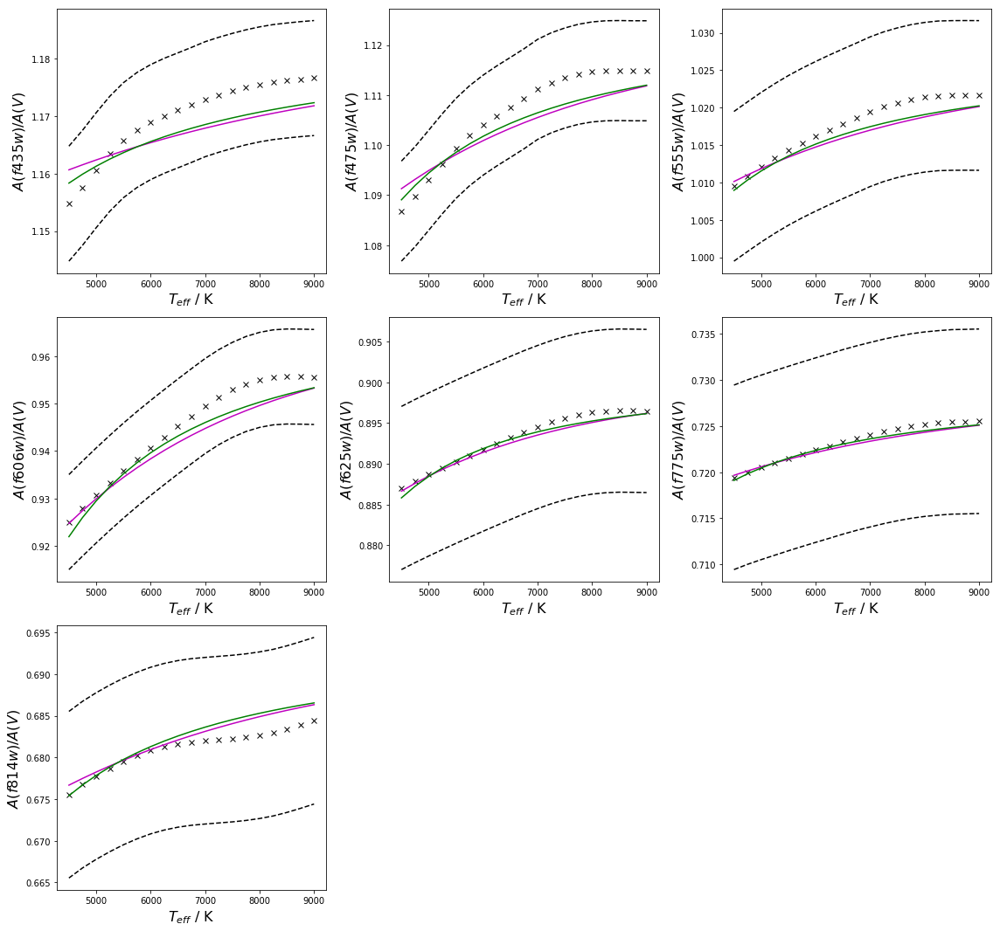


    Writing complete for log(g) = 1.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 1.0
Exponential fit coefficients (should be reused): 
[-0.0449 -1.7551  1.181 ]
Standard deviations (should be reused): 
[ 0.0219  0.7861  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0096 -1.1957  1.1831]
Standard deviations (should be reused): 
[ 0.0054  0.6713  0.0042]
Logistic fit coefficients: 
[  4.3054e-17   2.1242e+00   1.1809e+00   1.1097e+00]
Standard deviations: 
[  5.4573e+04   3.2714e+00   2.0815e-03   5.3970e-01]
Teff log-normal fit coefficients: 
[-2.      0.6961  1.172   1.1616]
Standard deviations: 
[ 0.      0.5156  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


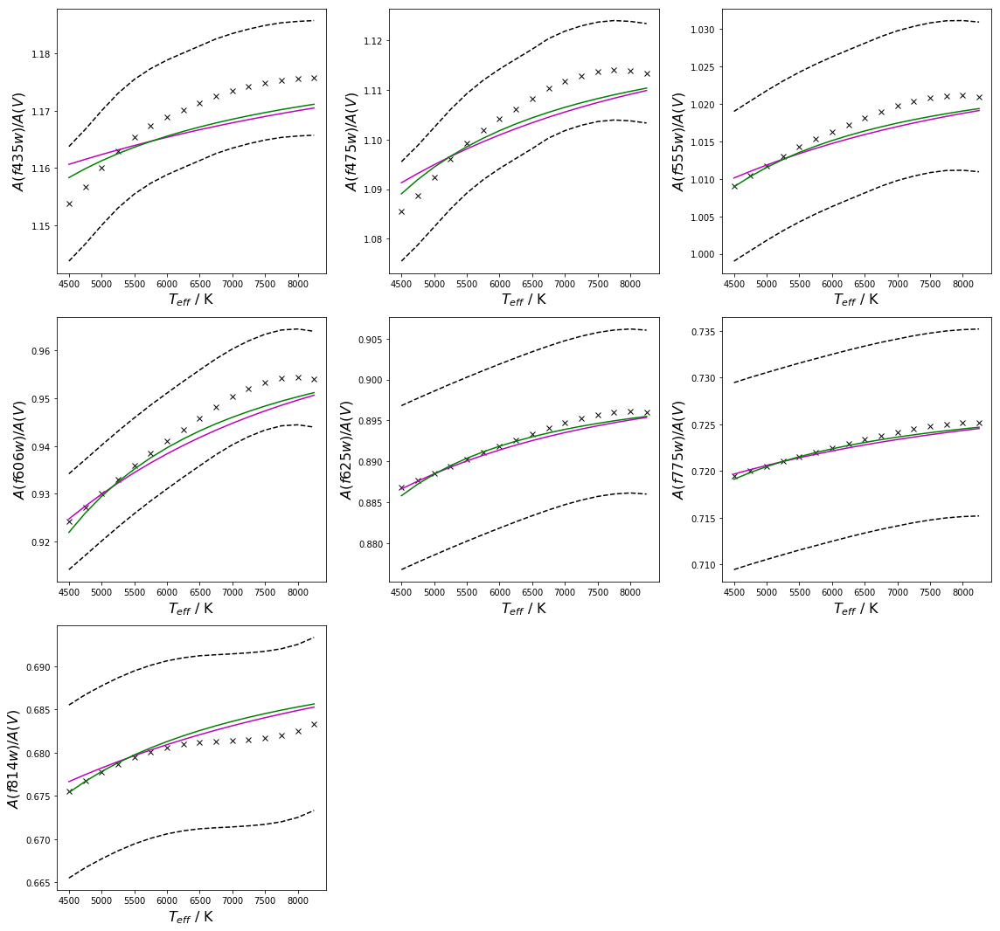


    Writing complete for log(g) = 1.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 0.5
Exponential fit coefficients (should be reused): 
[-0.0449 -1.7551  1.181 ]
Standard deviations (should be reused): 
[ 0.0219  0.7861  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0096 -1.1957  1.1831]
Standard deviations (should be reused): 
[ 0.0054  0.6713  0.0042]
Logistic fit coefficients: 
[  4.3054e-17   2.1242e+00   1.1809e+00   1.1097e+00]
Standard deviations: 
[  5.4573e+04   3.2714e+00   2.0815e-03   5.3970e-01]
Teff log-normal fit coefficients: 
[-2.      0.6961  1.172   1.1616]
Standard deviations: 
[ 0.      0.5156  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


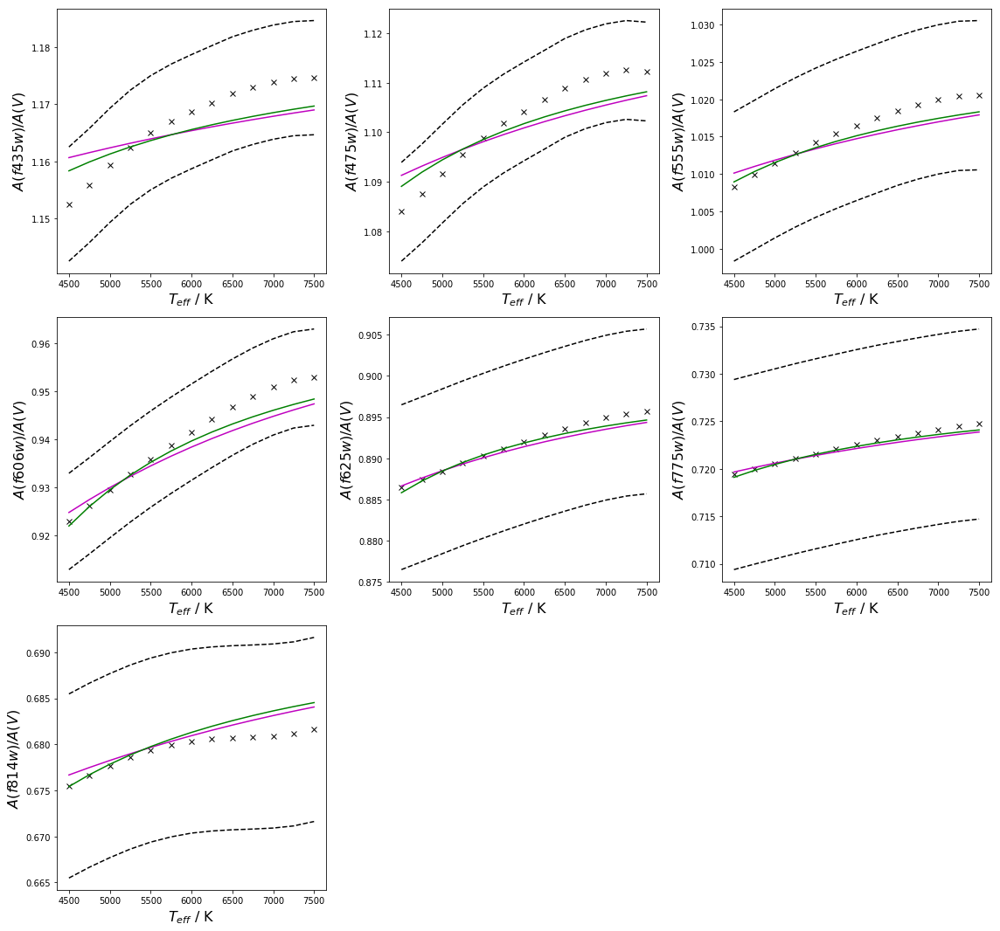


    Writing complete for log(g) = 0.5, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-1.0 , 0.0
Exponential fit coefficients (should be reused): 
[-0.0449 -1.7551  1.181 ]
Standard deviations (should be reused): 
[ 0.0219  0.7861  0.002 ]
Teff^(n) fit coefficients (should be reused): 
[-0.0096 -1.1957  1.1831]
Standard deviations (should be reused): 
[ 0.0054  0.6713  0.0042]
Logistic fit coefficients: 
[  4.3054e-17   2.1242e+00   1.1809e+00   1.1097e+00]
Standard deviations: 
[  5.4573e+04   3.2714e+00   2.0815e-03   5.3970e-01]
Teff log-normal fit coefficients: 
[-2.      0.6961  1.172   1.1616]
Standard deviations: 
[ 0.      0.5156  0.0015  0.0051]



Deleting missing subplots - discrepancy between 7 and 9


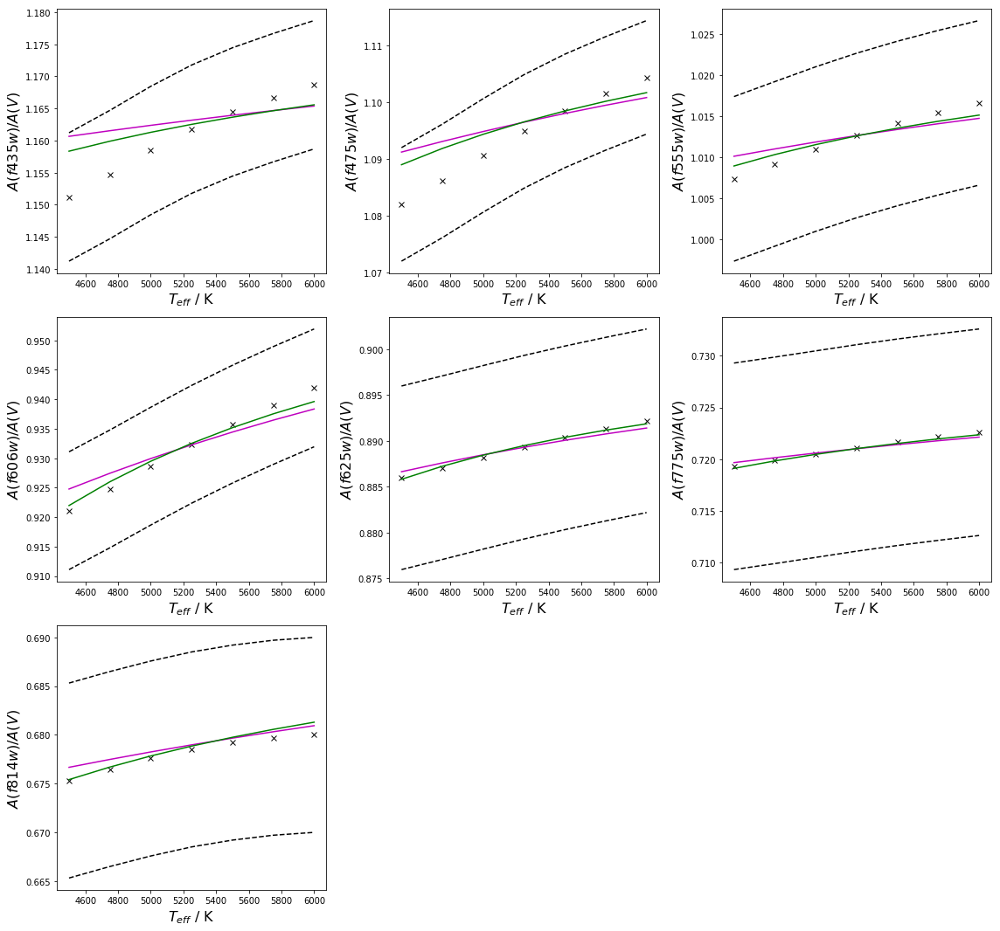


    Writing complete for log(g) = 0.0, Z = m1p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 5.0
Deleting missing subplots - discrepancy between 7 and 9


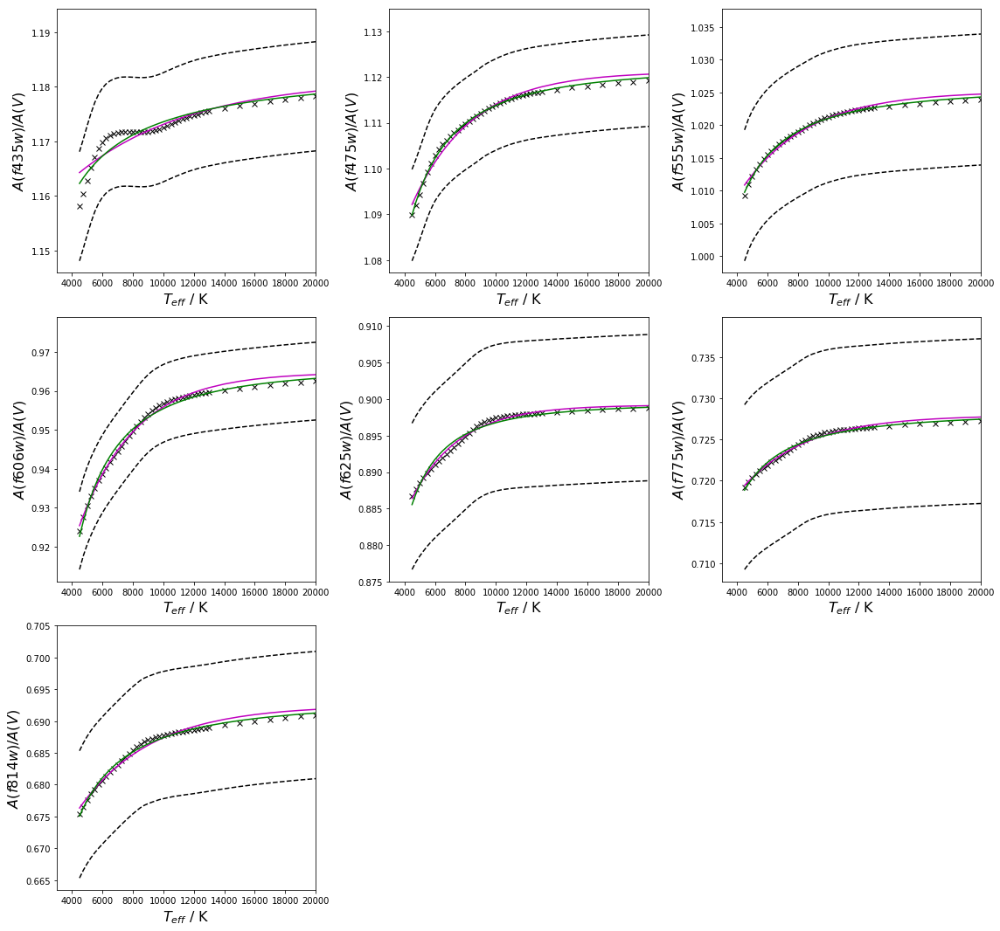


    Writing complete for log(g) = 5.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 4.5
Exponential fit coefficients (should be reused): 
[-0.031  -1.311   1.1815]
Standard deviations (should be reused): 
[ 0.0144  0.7387  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -0.8727  1.1848]
Standard deviations (should be reused): 
[ 0.0085  0.7272  0.0072]
Logistic fit coefficients: 
[  7.0881e-14   1.6424e+00   1.1813e+00   1.1303e+00]
Standard deviations: 
[  6.2977e+04   2.8026e+00   2.4002e-03   3.2758e-01]
Teff log-normal fit coefficients: 
[-2.      0.8463  1.1726  1.1623]
Standard deviations: 
[ 0.      0.8106  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


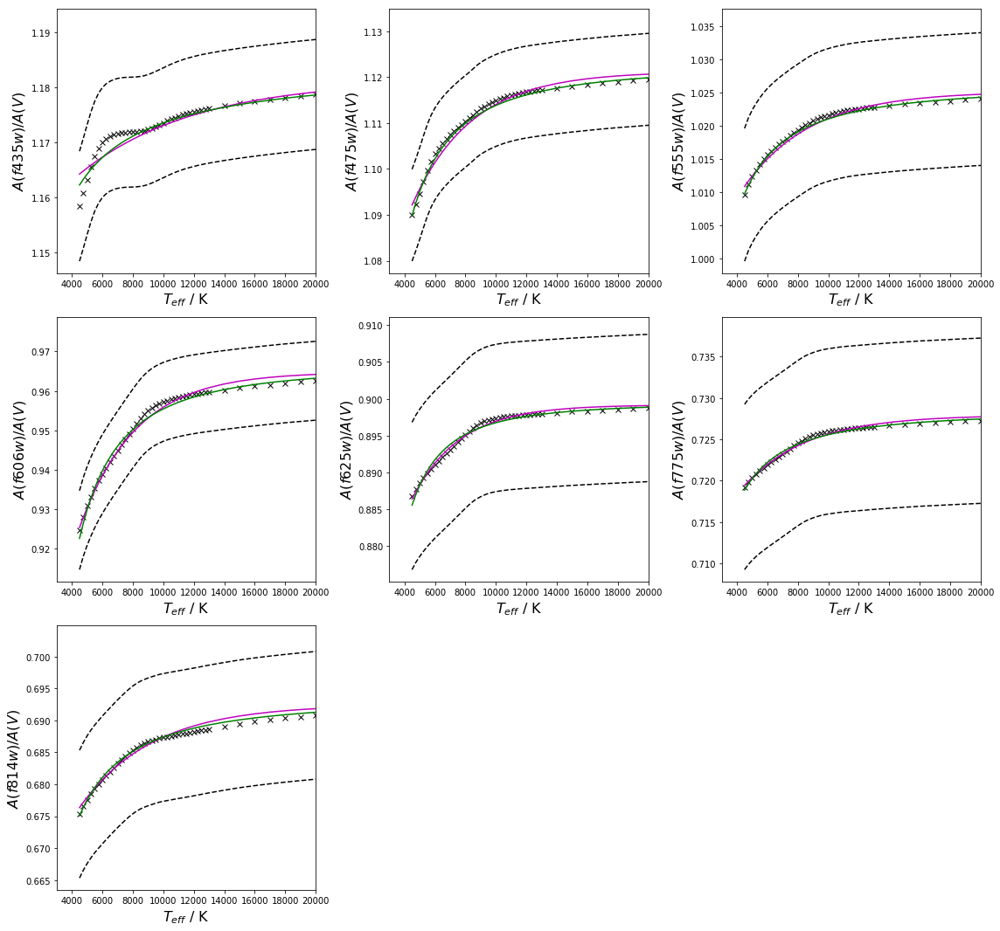


    Writing complete for log(g) = 4.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 4.0
Exponential fit coefficients (should be reused): 
[-0.031  -1.311   1.1815]
Standard deviations (should be reused): 
[ 0.0144  0.7387  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -0.8727  1.1848]
Standard deviations (should be reused): 
[ 0.0085  0.7272  0.0072]
Logistic fit coefficients: 
[  7.0881e-14   1.6424e+00   1.1813e+00   1.1303e+00]
Standard deviations: 
[  6.2977e+04   2.8026e+00   2.4002e-03   3.2758e-01]
Teff log-normal fit coefficients: 
[-2.      0.8463  1.1726  1.1623]
Standard deviations: 
[ 0.      0.8106  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


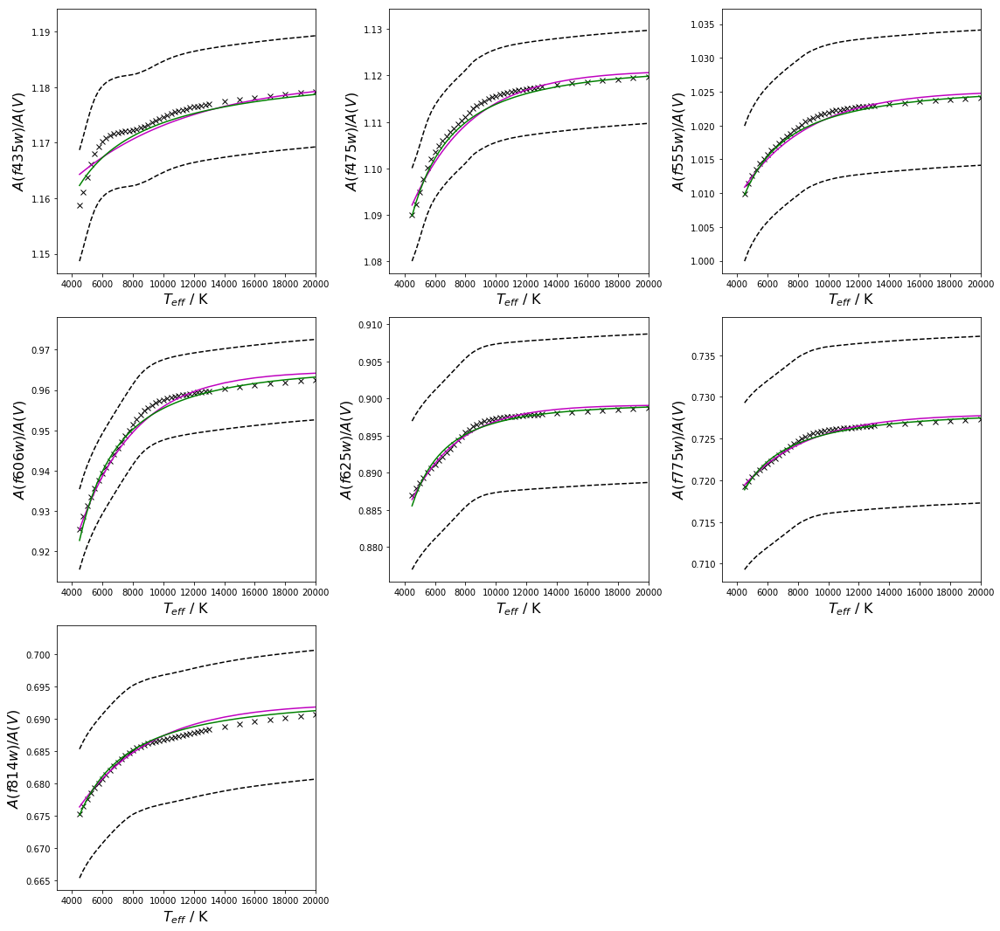


    Writing complete for log(g) = 4.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 3.5
Exponential fit coefficients (should be reused): 
[-0.031  -1.311   1.1815]
Standard deviations (should be reused): 
[ 0.0144  0.7387  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -0.8727  1.1848]
Standard deviations (should be reused): 
[ 0.0085  0.7272  0.0072]
Logistic fit coefficients: 
[  7.0881e-14   1.6424e+00   1.1813e+00   1.1303e+00]
Standard deviations: 
[  6.2977e+04   2.8026e+00   2.4002e-03   3.2758e-01]
Teff log-normal fit coefficients: 
[-2.      0.8463  1.1726  1.1623]
Standard deviations: 
[ 0.      0.8106  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


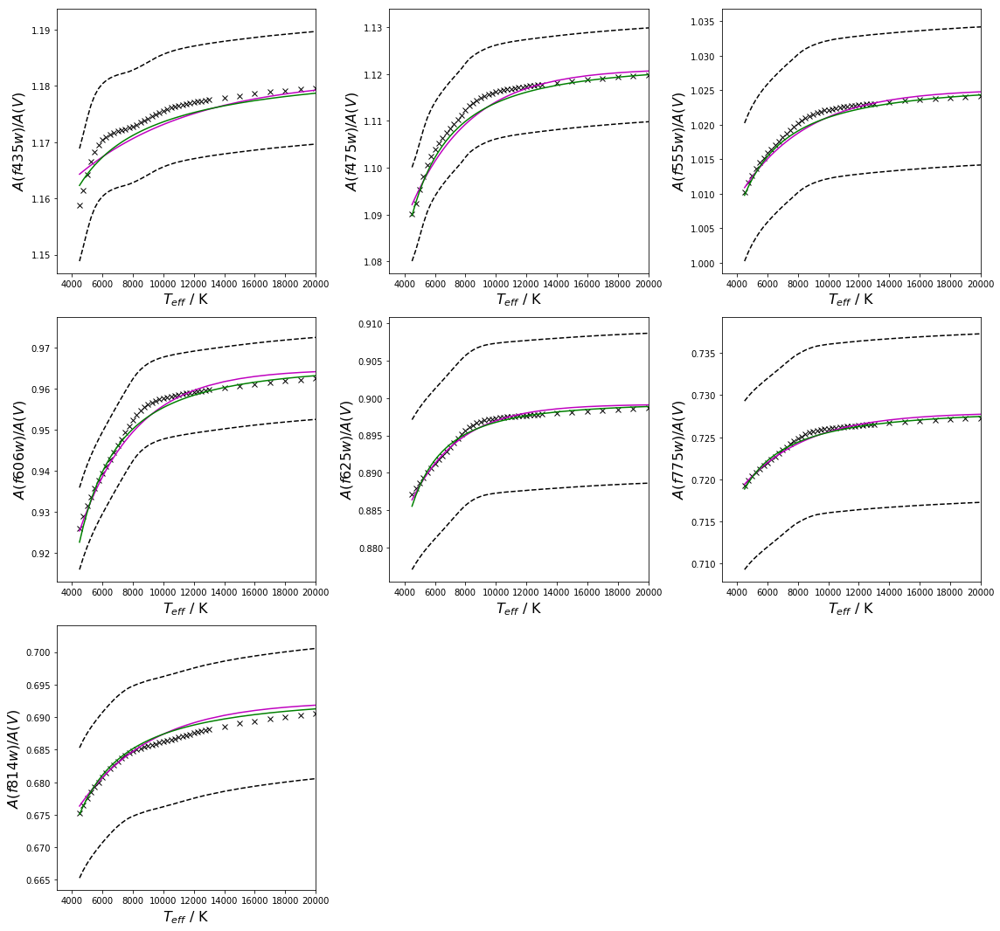


    Writing complete for log(g) = 3.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 3.0
Exponential fit coefficients (should be reused): 
[-0.031  -1.311   1.1815]
Standard deviations (should be reused): 
[ 0.0144  0.7387  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -0.8727  1.1848]
Standard deviations (should be reused): 
[ 0.0085  0.7272  0.0072]
Logistic fit coefficients: 
[  7.0881e-14   1.6424e+00   1.1813e+00   1.1303e+00]
Standard deviations: 
[  6.2977e+04   2.8026e+00   2.4002e-03   3.2758e-01]
Teff log-normal fit coefficients: 
[-2.      0.8463  1.1726  1.1623]
Standard deviations: 
[ 0.      0.8106  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


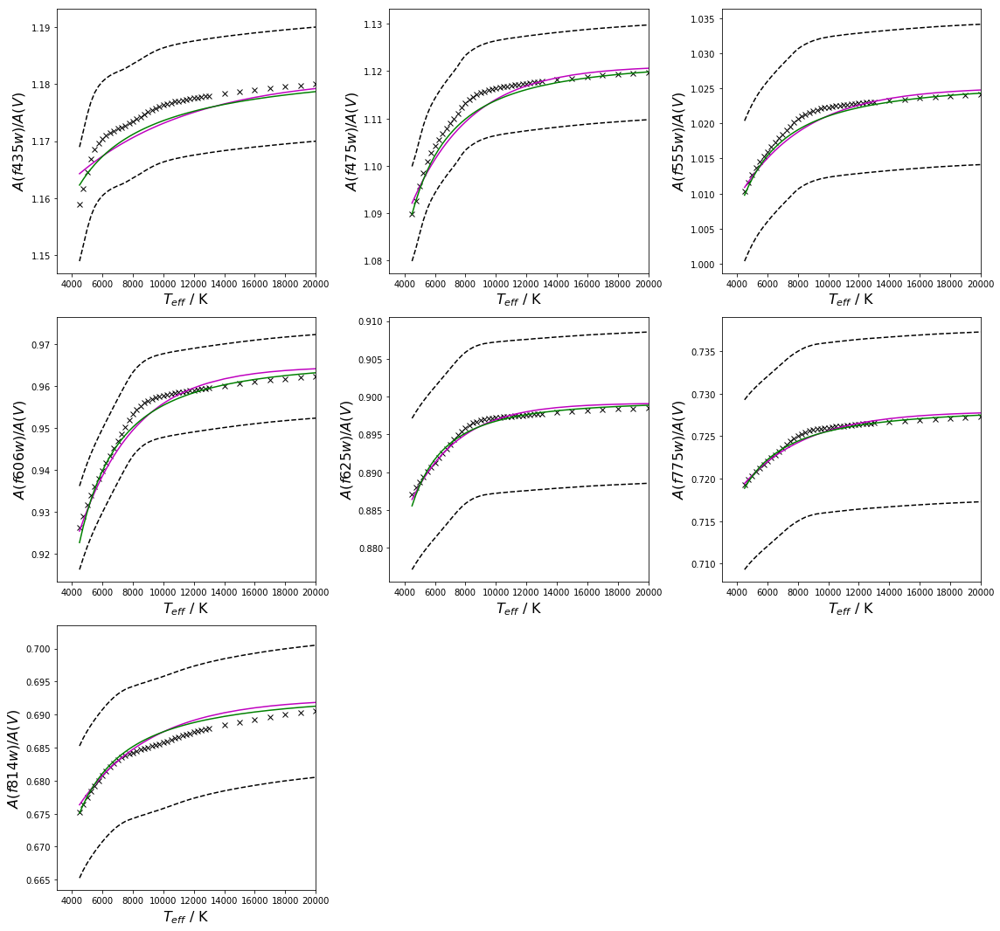


    Writing complete for log(g) = 3.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 2.5
Exponential fit coefficients (should be reused): 
[-0.031  -1.311   1.1815]
Standard deviations (should be reused): 
[ 0.0144  0.7387  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -0.8727  1.1848]
Standard deviations (should be reused): 
[ 0.0085  0.7272  0.0072]
Logistic fit coefficients: 
[  7.0881e-14   1.6424e+00   1.1813e+00   1.1303e+00]
Standard deviations: 
[  6.2977e+04   2.8026e+00   2.4002e-03   3.2758e-01]
Teff log-normal fit coefficients: 
[-2.      0.8463  1.1726  1.1623]
Standard deviations: 
[ 0.      0.8106  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


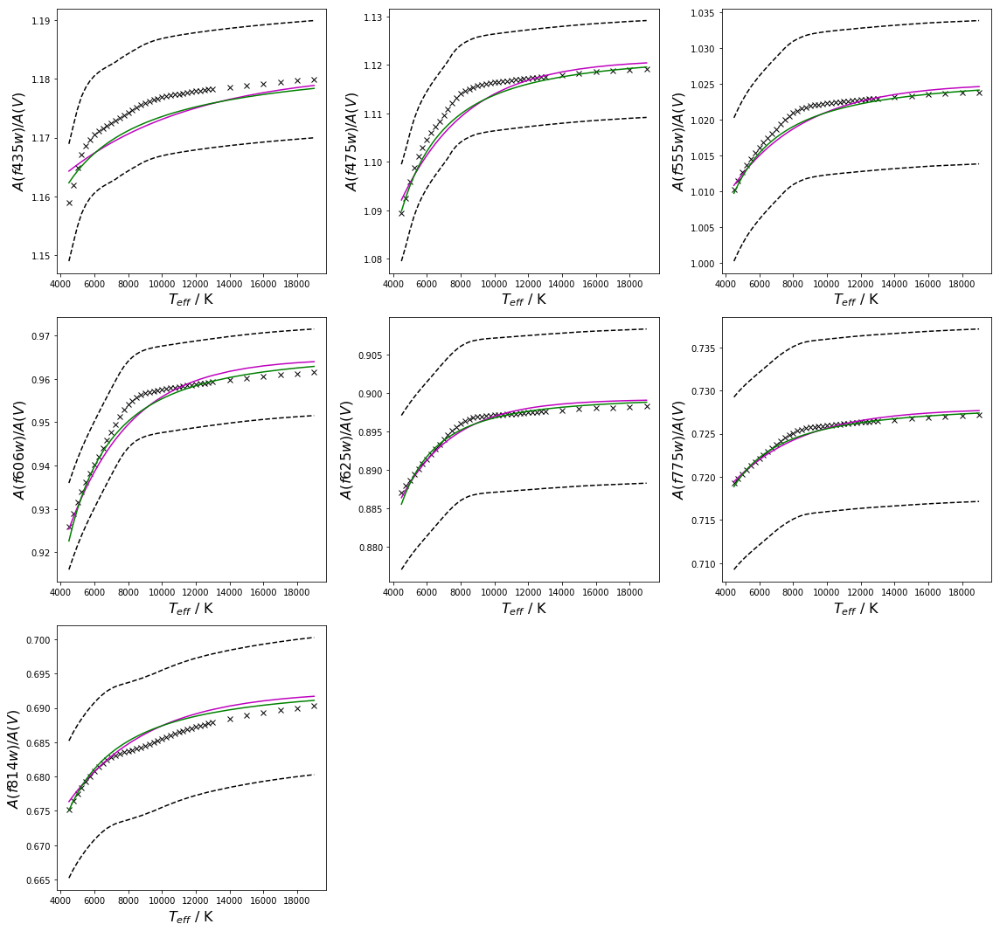


    Writing complete for log(g) = 2.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 2.0
Exponential fit coefficients (should be reused): 
[-0.031  -1.311   1.1815]
Standard deviations (should be reused): 
[ 0.0144  0.7387  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -0.8727  1.1848]
Standard deviations (should be reused): 
[ 0.0085  0.7272  0.0072]
Logistic fit coefficients: 
[  7.0881e-14   1.6424e+00   1.1813e+00   1.1303e+00]
Standard deviations: 
[  6.2977e+04   2.8026e+00   2.4002e-03   3.2758e-01]
Teff log-normal fit coefficients: 
[-2.      0.8463  1.1726  1.1623]
Standard deviations: 
[ 0.      0.8106  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


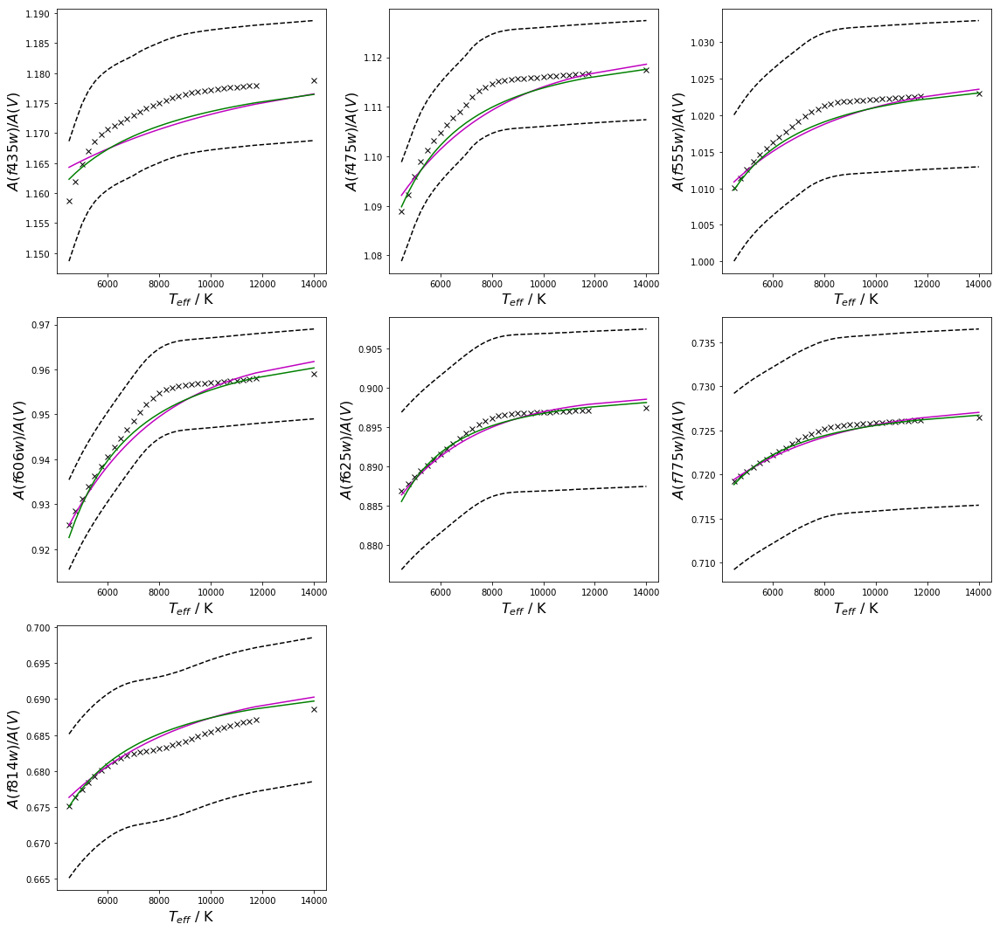


    Writing complete for log(g) = 2.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 1.5
Exponential fit coefficients (should be reused): 
[-0.031  -1.311   1.1815]
Standard deviations (should be reused): 
[ 0.0144  0.7387  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -0.8727  1.1848]
Standard deviations (should be reused): 
[ 0.0085  0.7272  0.0072]
Logistic fit coefficients: 
[  7.0881e-14   1.6424e+00   1.1813e+00   1.1303e+00]
Standard deviations: 
[  6.2977e+04   2.8026e+00   2.4002e-03   3.2758e-01]
Teff log-normal fit coefficients: 
[-2.      0.8463  1.1726  1.1623]
Standard deviations: 
[ 0.      0.8106  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


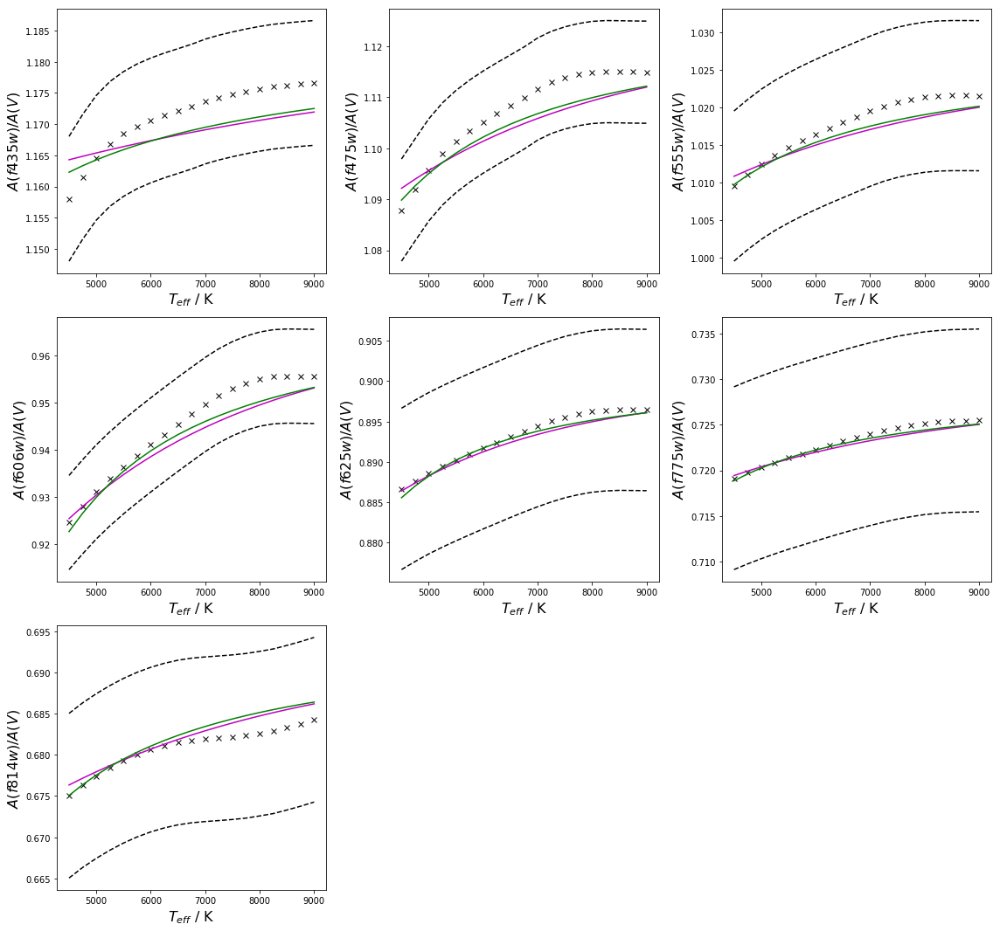


    Writing complete for log(g) = 1.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 1.0
Exponential fit coefficients (should be reused): 
[-0.031  -1.311   1.1815]
Standard deviations (should be reused): 
[ 0.0144  0.7387  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -0.8727  1.1848]
Standard deviations (should be reused): 
[ 0.0085  0.7272  0.0072]
Logistic fit coefficients: 
[  7.0881e-14   1.6424e+00   1.1813e+00   1.1303e+00]
Standard deviations: 
[  6.2977e+04   2.8026e+00   2.4002e-03   3.2758e-01]
Teff log-normal fit coefficients: 
[-2.      0.8463  1.1726  1.1623]
Standard deviations: 
[ 0.      0.8106  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


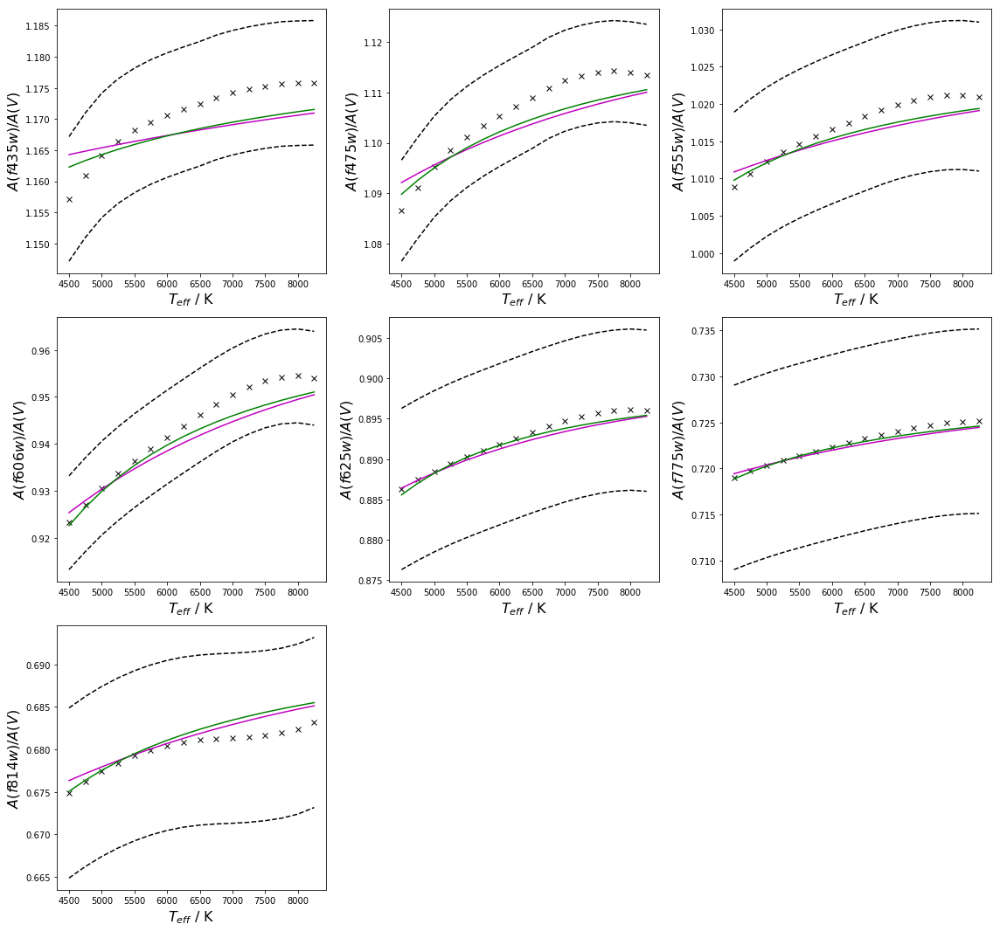


    Writing complete for log(g) = 1.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 0.5
Exponential fit coefficients (should be reused): 
[-0.031  -1.311   1.1815]
Standard deviations (should be reused): 
[ 0.0144  0.7387  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -0.8727  1.1848]
Standard deviations (should be reused): 
[ 0.0085  0.7272  0.0072]
Logistic fit coefficients: 
[  7.0881e-14   1.6424e+00   1.1813e+00   1.1303e+00]
Standard deviations: 
[  6.2977e+04   2.8026e+00   2.4002e-03   3.2758e-01]
Teff log-normal fit coefficients: 
[-2.      0.8463  1.1726  1.1623]
Standard deviations: 
[ 0.      0.8106  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


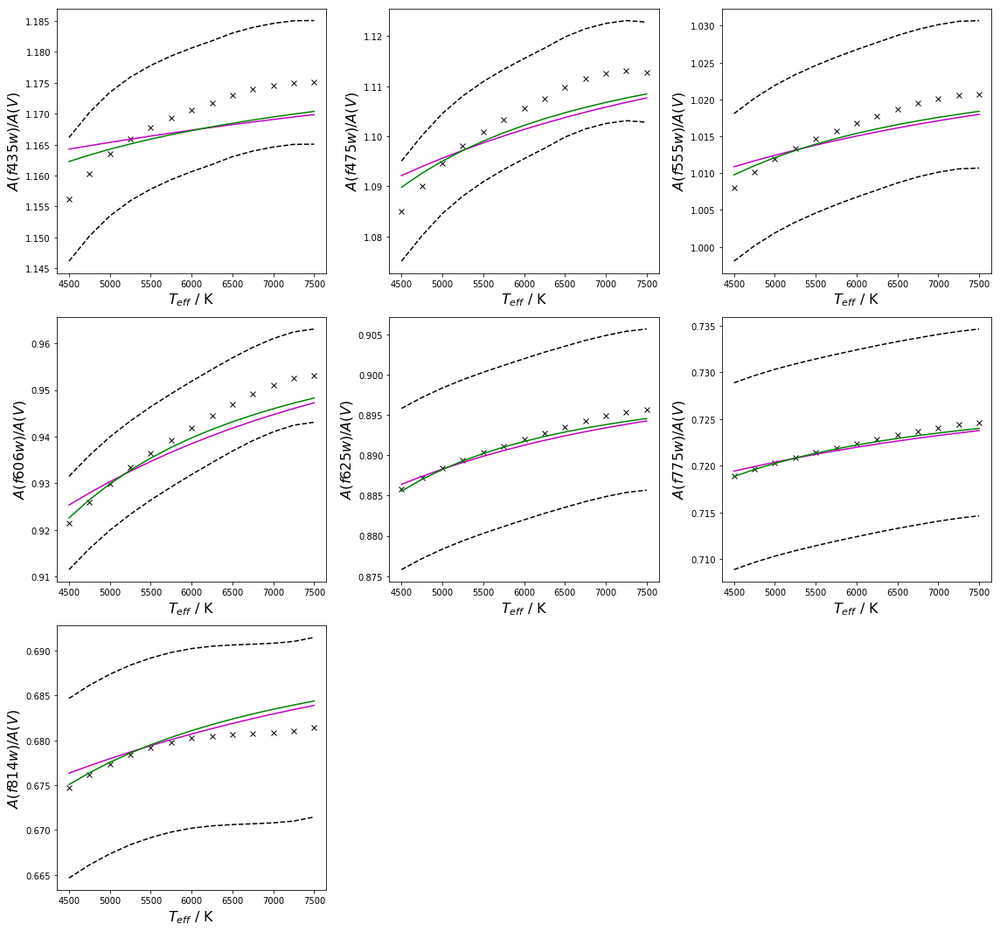


    Writing complete for log(g) = 0.5, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,-2.0 , 0.0
Exponential fit coefficients (should be reused): 
[-0.031  -1.311   1.1815]
Standard deviations (should be reused): 
[ 0.0144  0.7387  0.0023]
Teff^(n) fit coefficients (should be reused): 
[-0.0112 -0.8727  1.1848]
Standard deviations (should be reused): 
[ 0.0085  0.7272  0.0072]
Logistic fit coefficients: 
[  7.0881e-14   1.6424e+00   1.1813e+00   1.1303e+00]
Standard deviations: 
[  6.2977e+04   2.8026e+00   2.4002e-03   3.2758e-01]
Teff log-normal fit coefficients: 
[-2.      0.8463  1.1726  1.1623]
Standard deviations: 
[ 0.      0.8106  0.0014  0.0067]



Deleting missing subplots - discrepancy between 7 and 9


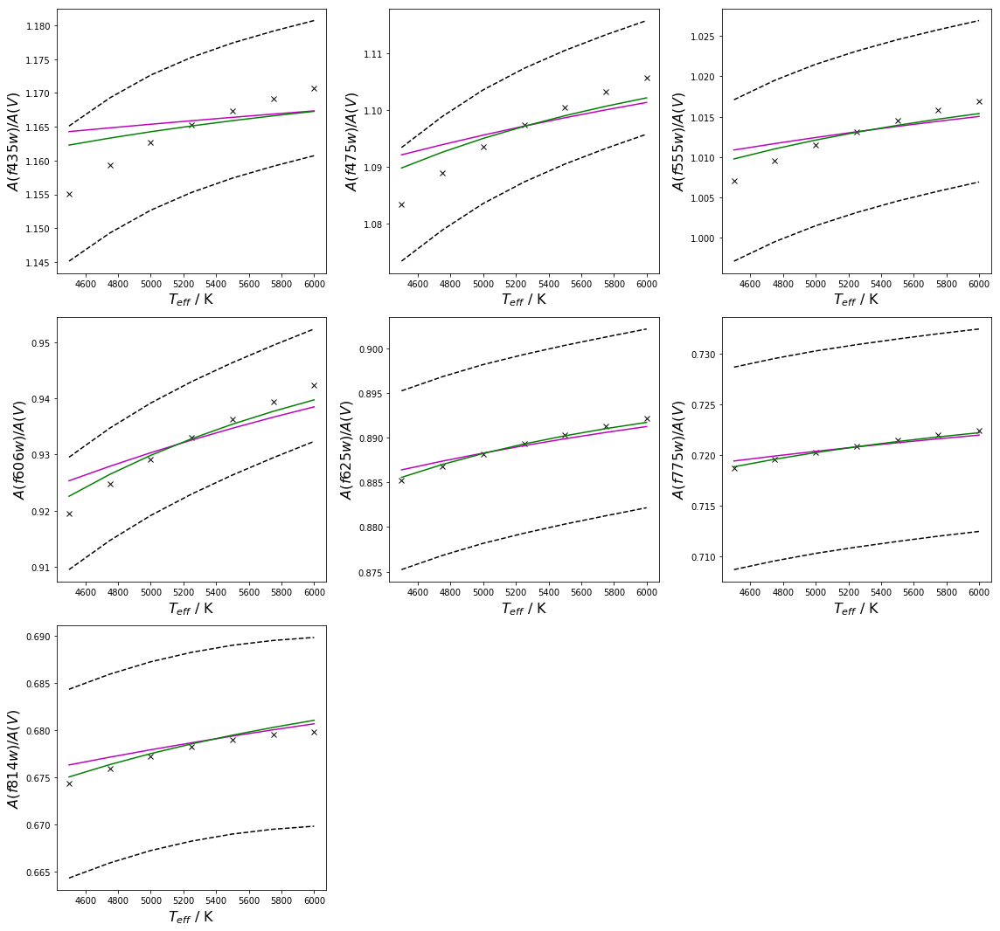


    Writing complete for log(g) = 0.0, Z = m2p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 5.0

    Writing log(g)=5.0, FeH = 0p0, Rv = 6p0 model for f435w ACS filter
Average fractional error for Exponential function of Teff, fitted = 0.277447062085
Average fractional error for Power law of Teff, fitted = 0.299229260547

    Writing log(g)=5.0, FeH = 0p0, Rv = 6p0 model for f475w ACS filter
Average fractional error for Exponential function of Teff, fitted = 0.245499394782
Average fractional error for Power law of Teff, fitted = 0.239801589255

    Writing log(g)=5.0, FeH = 0p0, Rv = 6p0 model for f555w ACS filter
Average fractional error for Exponential function of Teff, fitted = 0.470195224048
Average fractional error for Power law of Teff, fitted = 0.451087769302

    Writing log(g)=5.0, FeH = 0p0, Rv = 6p0 model for f606w ACS filter
Average fractional error for Exponential function of Teff, fitted = 0.196589075041
Average fractional error for Power law of Teff, fitted = 

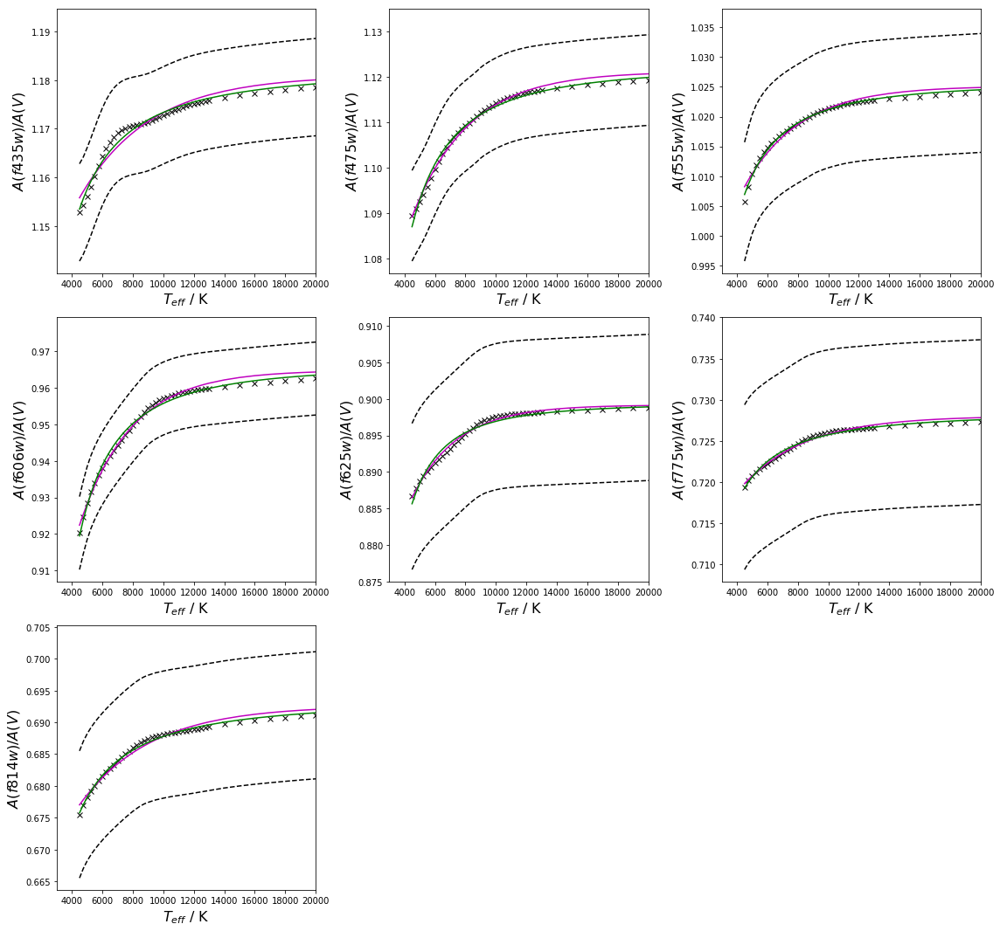


    Writing complete for log(g) = 5.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 4.5
Exponential fit coefficients (should be reused): 
[-0.0667 -2.1705  1.1809]
Standard deviations (should be reused): 
[ 0.0313  0.7832  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0094 -1.4231  1.1827]
Standard deviations (should be reused): 
[ 0.0044  0.6008  0.0033]
Logistic fit coefficients: 
[  1.1204e-14   2.5570e+00   1.1807e+00   1.0787e+00]
Standard deviations: 
[  4.1372e+04   3.0200e+00   1.8926e-03   7.3775e-01]
Teff log-normal fit coefficients: 
[-2.      0.5609  1.1711  1.1602]
Standard deviations: 
[ 0.      0.335   0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


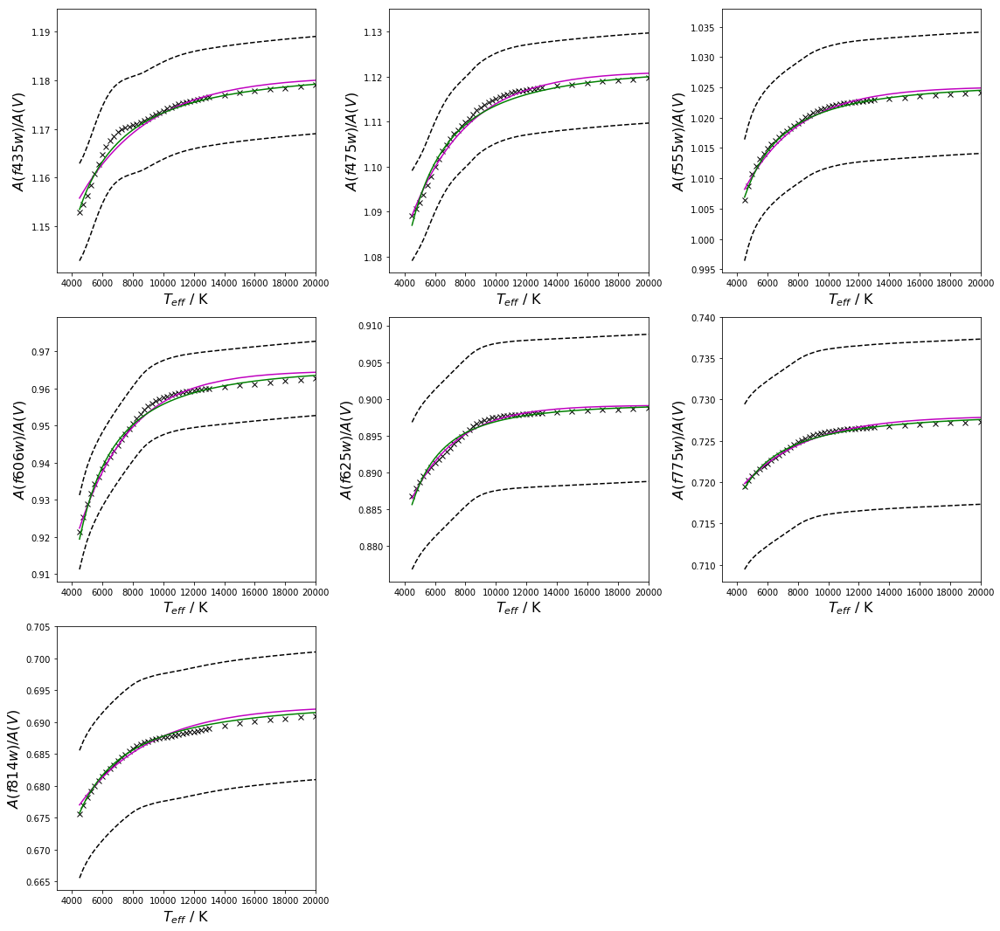


    Writing complete for log(g) = 4.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 4.0
Exponential fit coefficients (should be reused): 
[-0.0667 -2.1705  1.1809]
Standard deviations (should be reused): 
[ 0.0313  0.7832  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0094 -1.4231  1.1827]
Standard deviations (should be reused): 
[ 0.0044  0.6008  0.0033]
Logistic fit coefficients: 
[  1.1204e-14   2.5570e+00   1.1807e+00   1.0787e+00]
Standard deviations: 
[  4.1372e+04   3.0200e+00   1.8926e-03   7.3775e-01]
Teff log-normal fit coefficients: 
[-2.      0.5609  1.1711  1.1602]
Standard deviations: 
[ 0.      0.335   0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


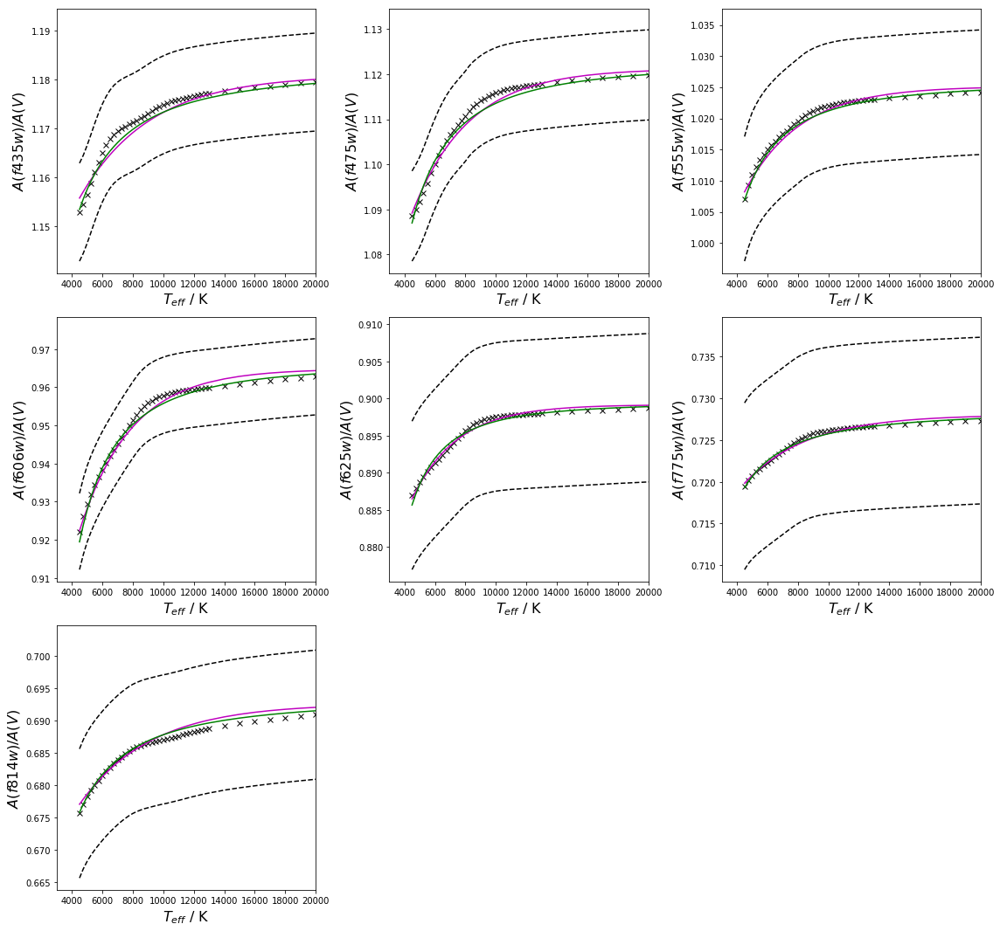


    Writing complete for log(g) = 4.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 3.5
Exponential fit coefficients (should be reused): 
[-0.0667 -2.1705  1.1809]
Standard deviations (should be reused): 
[ 0.0313  0.7832  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0094 -1.4231  1.1827]
Standard deviations (should be reused): 
[ 0.0044  0.6008  0.0033]
Logistic fit coefficients: 
[  1.1204e-14   2.5570e+00   1.1807e+00   1.0787e+00]
Standard deviations: 
[  4.1372e+04   3.0200e+00   1.8926e-03   7.3775e-01]
Teff log-normal fit coefficients: 
[-2.      0.5609  1.1711  1.1602]
Standard deviations: 
[ 0.      0.335   0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


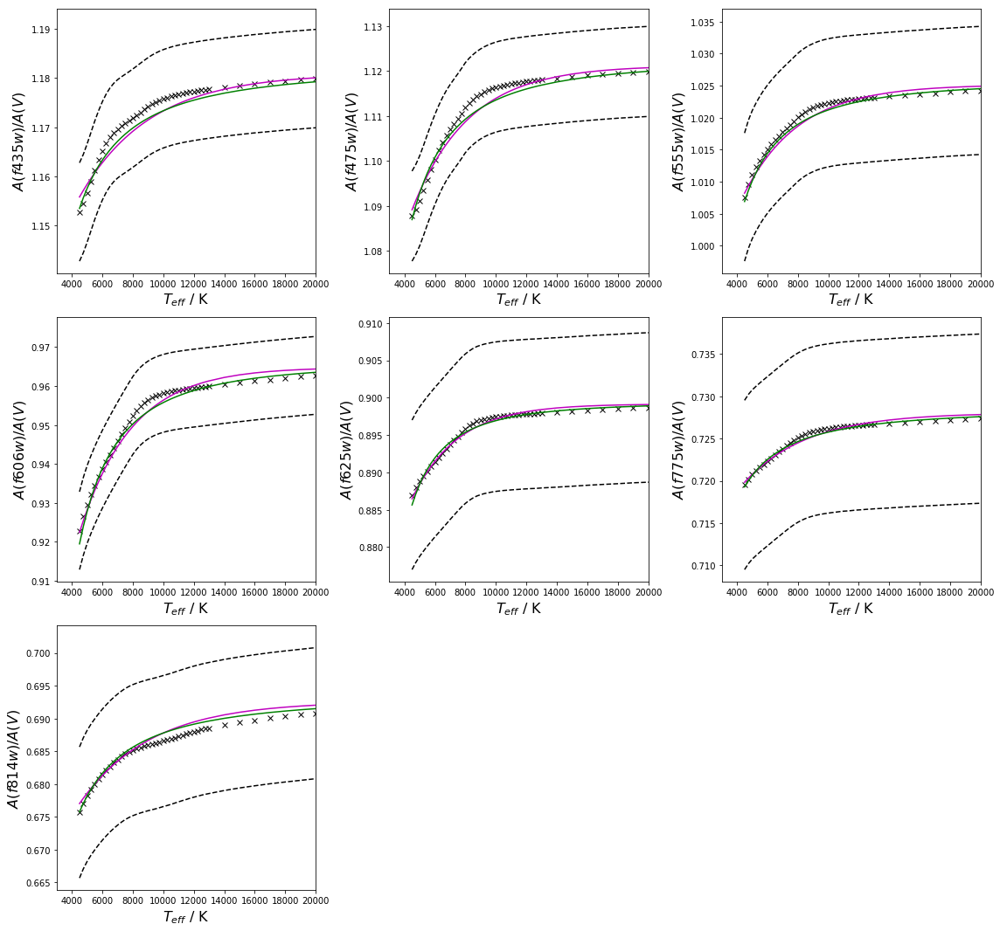


    Writing complete for log(g) = 3.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 3.0
Exponential fit coefficients (should be reused): 
[-0.0667 -2.1705  1.1809]
Standard deviations (should be reused): 
[ 0.0313  0.7832  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0094 -1.4231  1.1827]
Standard deviations (should be reused): 
[ 0.0044  0.6008  0.0033]
Logistic fit coefficients: 
[  1.1204e-14   2.5570e+00   1.1807e+00   1.0787e+00]
Standard deviations: 
[  4.1372e+04   3.0200e+00   1.8926e-03   7.3775e-01]
Teff log-normal fit coefficients: 
[-2.      0.5609  1.1711  1.1602]
Standard deviations: 
[ 0.      0.335   0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


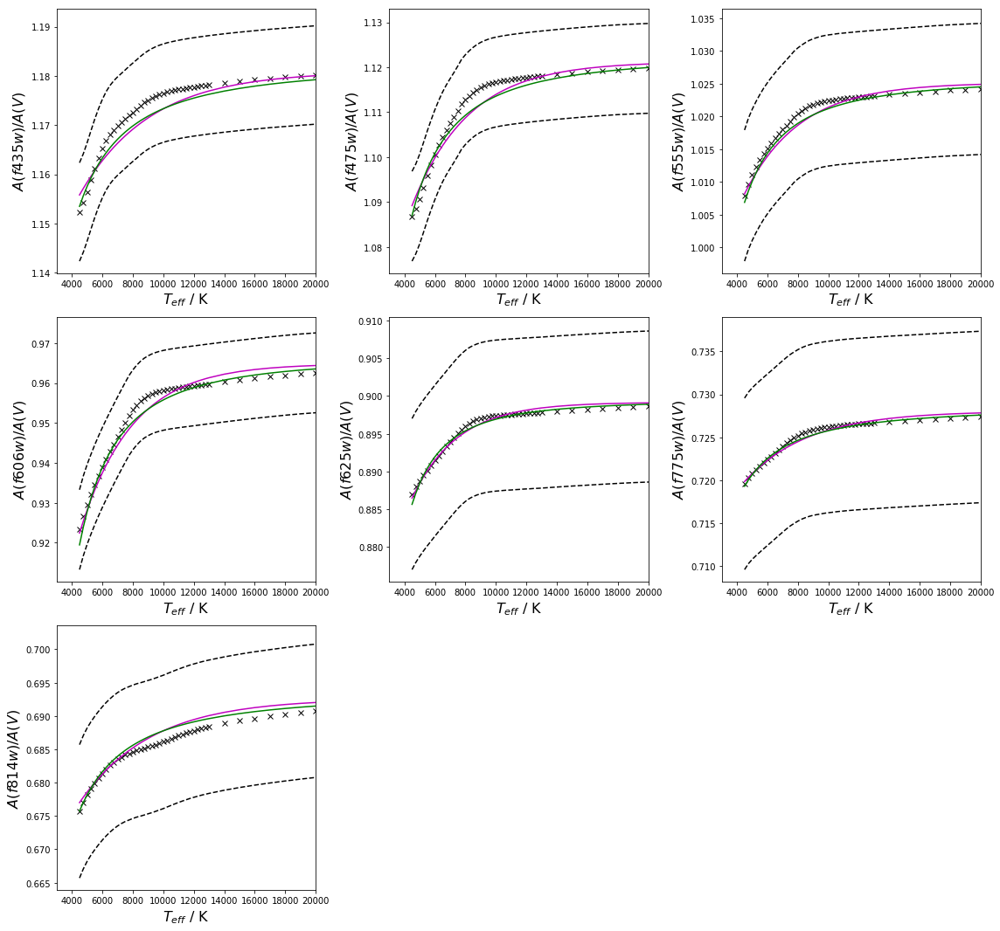


    Writing complete for log(g) = 3.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 2.5
Exponential fit coefficients (should be reused): 
[-0.0667 -2.1705  1.1809]
Standard deviations (should be reused): 
[ 0.0313  0.7832  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0094 -1.4231  1.1827]
Standard deviations (should be reused): 
[ 0.0044  0.6008  0.0033]
Logistic fit coefficients: 
[  1.1204e-14   2.5570e+00   1.1807e+00   1.0787e+00]
Standard deviations: 
[  4.1372e+04   3.0200e+00   1.8926e-03   7.3775e-01]
Teff log-normal fit coefficients: 
[-2.      0.5609  1.1711  1.1602]
Standard deviations: 
[ 0.      0.335   0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


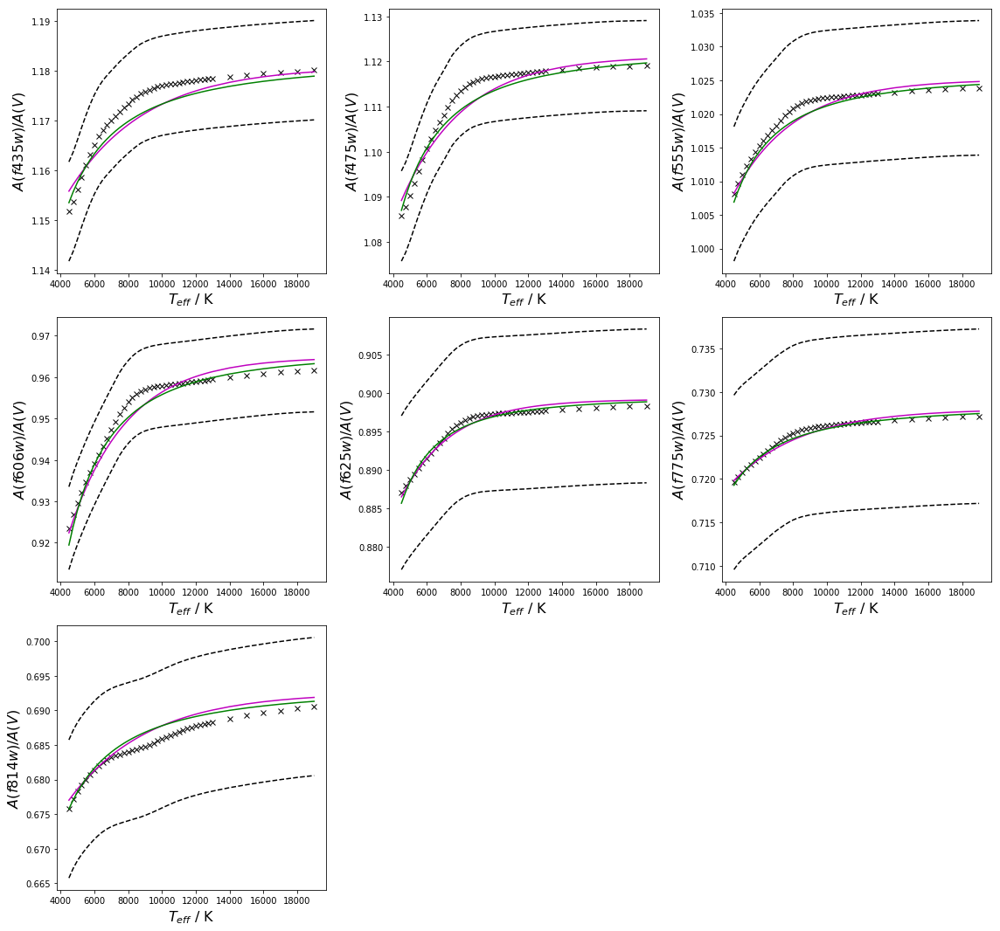


    Writing complete for log(g) = 2.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 2.0
Exponential fit coefficients (should be reused): 
[-0.0667 -2.1705  1.1809]
Standard deviations (should be reused): 
[ 0.0313  0.7832  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0094 -1.4231  1.1827]
Standard deviations (should be reused): 
[ 0.0044  0.6008  0.0033]
Logistic fit coefficients: 
[  1.1204e-14   2.5570e+00   1.1807e+00   1.0787e+00]
Standard deviations: 
[  4.1372e+04   3.0200e+00   1.8926e-03   7.3775e-01]
Teff log-normal fit coefficients: 
[-2.      0.5609  1.1711  1.1602]
Standard deviations: 
[ 0.      0.335   0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


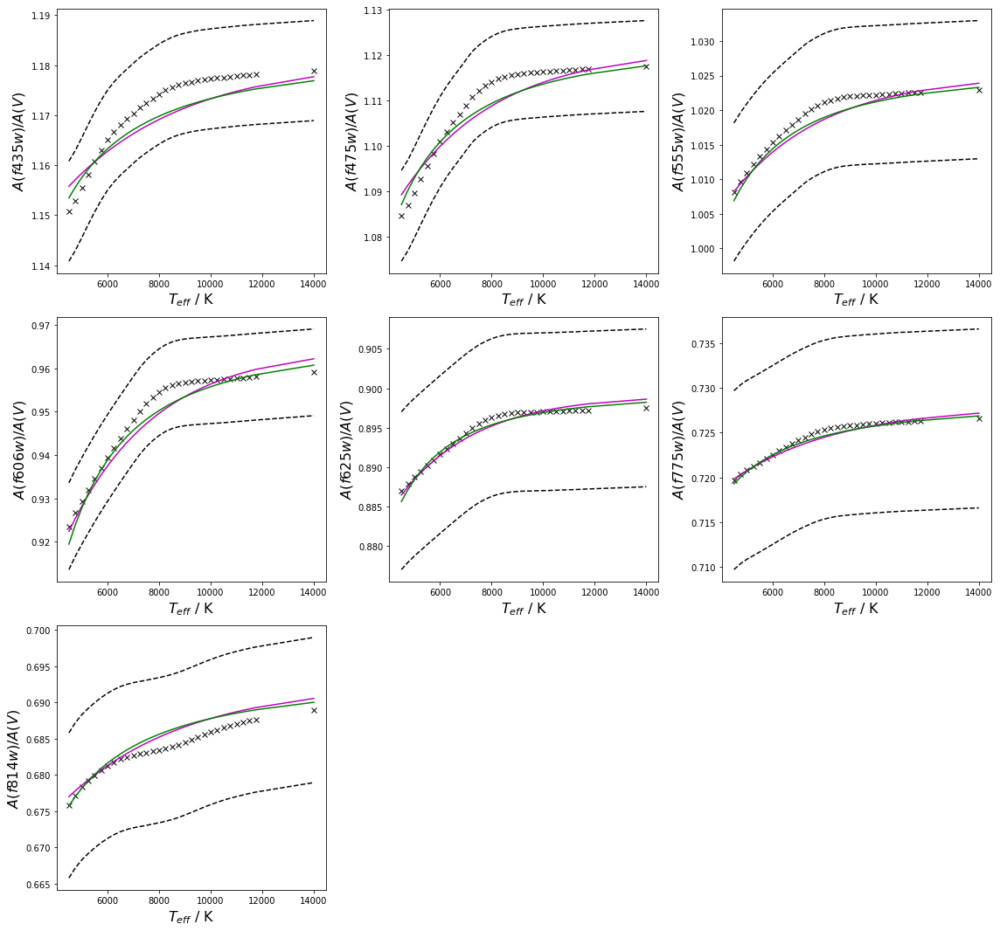


    Writing complete for log(g) = 2.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 1.5
Exponential fit coefficients (should be reused): 
[-0.0667 -2.1705  1.1809]
Standard deviations (should be reused): 
[ 0.0313  0.7832  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0094 -1.4231  1.1827]
Standard deviations (should be reused): 
[ 0.0044  0.6008  0.0033]
Logistic fit coefficients: 
[  1.1204e-14   2.5570e+00   1.1807e+00   1.0787e+00]
Standard deviations: 
[  4.1372e+04   3.0200e+00   1.8926e-03   7.3775e-01]
Teff log-normal fit coefficients: 
[-2.      0.5609  1.1711  1.1602]
Standard deviations: 
[ 0.      0.335   0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


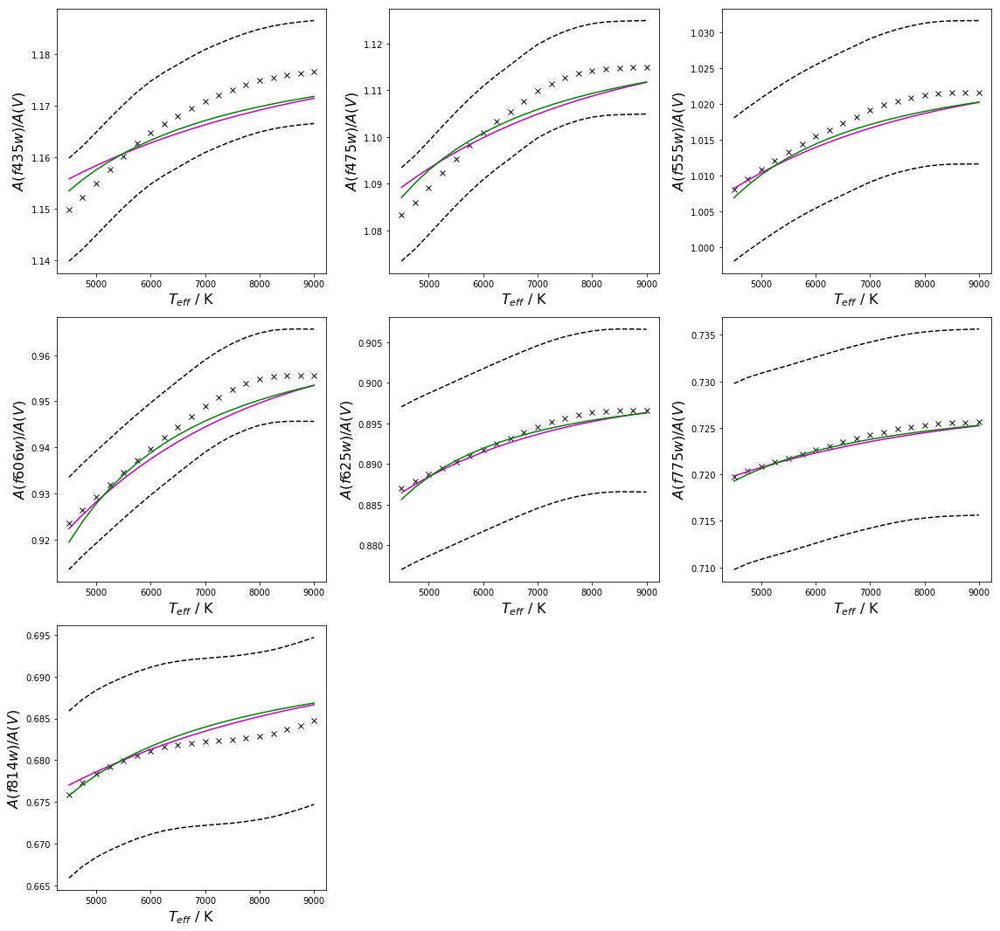


    Writing complete for log(g) = 1.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 1.0
Exponential fit coefficients (should be reused): 
[-0.0667 -2.1705  1.1809]
Standard deviations (should be reused): 
[ 0.0313  0.7832  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0094 -1.4231  1.1827]
Standard deviations (should be reused): 
[ 0.0044  0.6008  0.0033]
Logistic fit coefficients: 
[  1.1204e-14   2.5570e+00   1.1807e+00   1.0787e+00]
Standard deviations: 
[  4.1372e+04   3.0200e+00   1.8926e-03   7.3775e-01]
Teff log-normal fit coefficients: 
[-2.      0.5609  1.1711  1.1602]
Standard deviations: 
[ 0.      0.335   0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


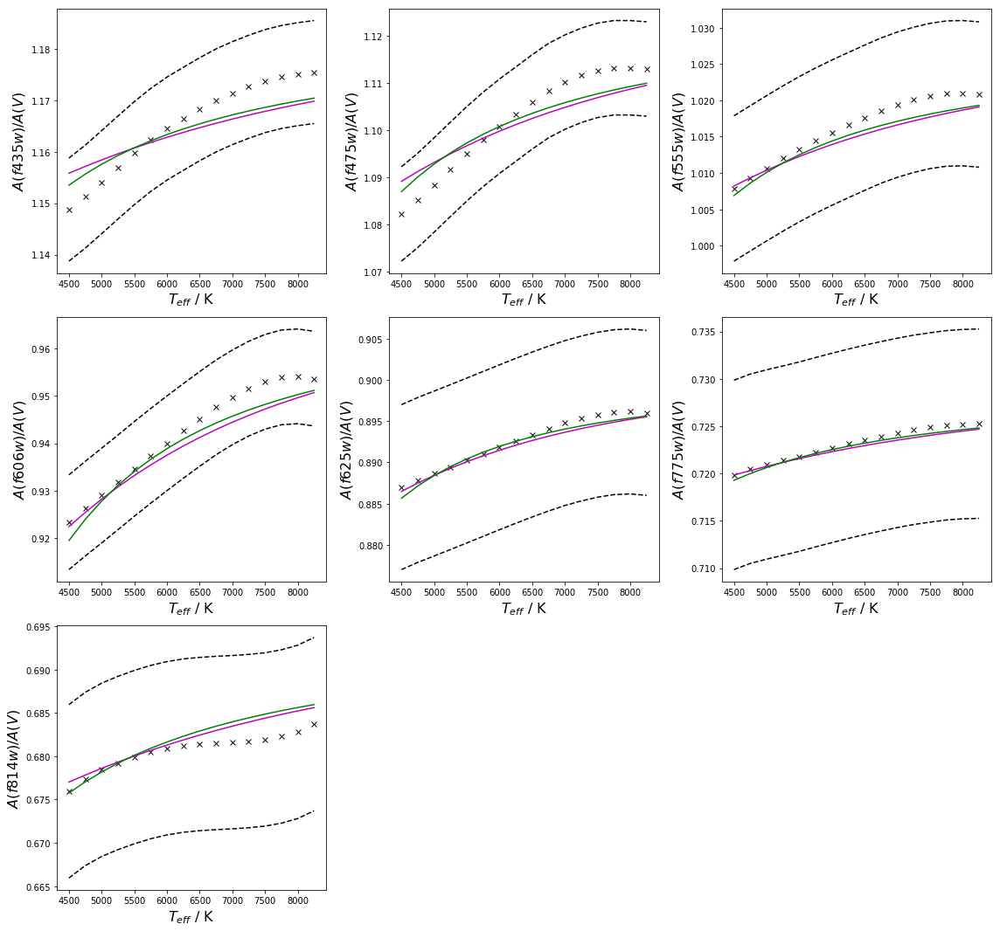


    Writing complete for log(g) = 1.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 0.5
Exponential fit coefficients (should be reused): 
[-0.0667 -2.1705  1.1809]
Standard deviations (should be reused): 
[ 0.0313  0.7832  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0094 -1.4231  1.1827]
Standard deviations (should be reused): 
[ 0.0044  0.6008  0.0033]
Logistic fit coefficients: 
[  1.1204e-14   2.5570e+00   1.1807e+00   1.0787e+00]
Standard deviations: 
[  4.1372e+04   3.0200e+00   1.8926e-03   7.3775e-01]
Teff log-normal fit coefficients: 
[-2.      0.5609  1.1711  1.1602]
Standard deviations: 
[ 0.      0.335   0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


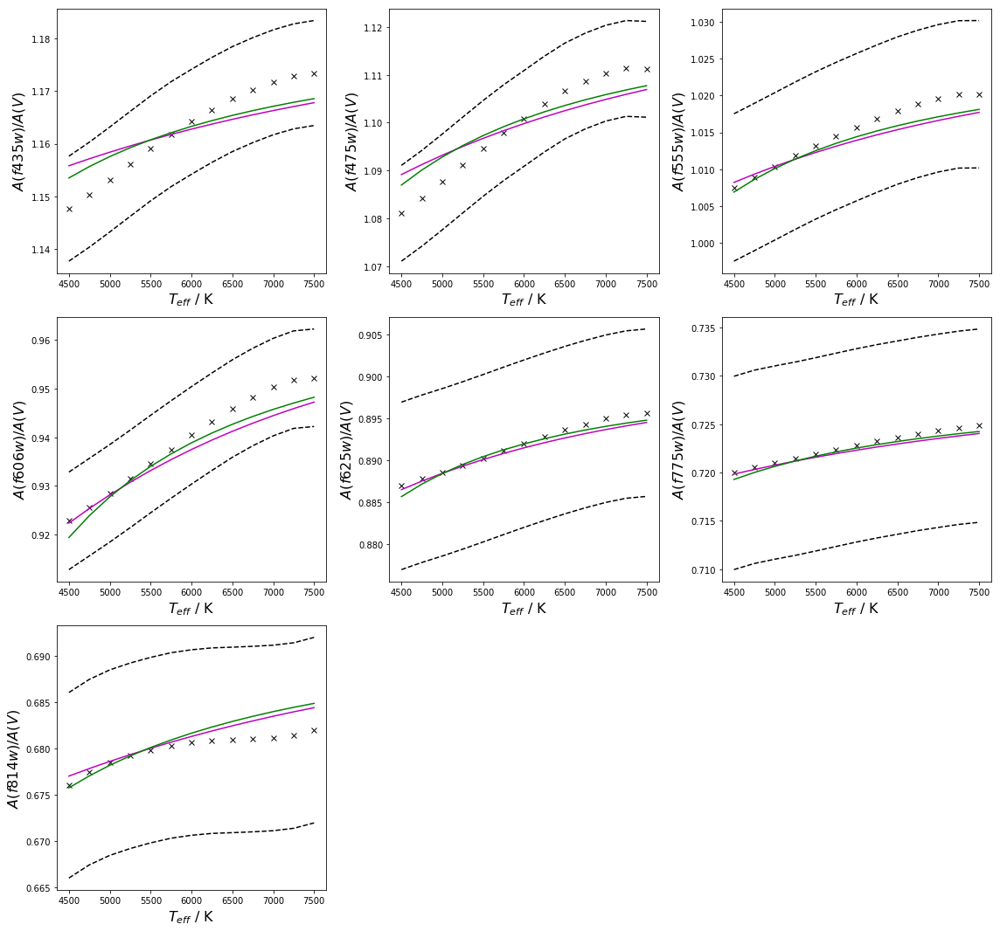


    Writing complete for log(g) = 0.5, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.0 , 0.0
Exponential fit coefficients (should be reused): 
[-0.0667 -2.1705  1.1809]
Standard deviations (should be reused): 
[ 0.0313  0.7832  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.0094 -1.4231  1.1827]
Standard deviations (should be reused): 
[ 0.0044  0.6008  0.0033]
Logistic fit coefficients: 
[  1.1204e-14   2.5570e+00   1.1807e+00   1.0787e+00]
Standard deviations: 
[  4.1372e+04   3.0200e+00   1.8926e-03   7.3775e-01]
Teff log-normal fit coefficients: 
[-2.      0.5609  1.1711  1.1602]
Standard deviations: 
[ 0.      0.335   0.0015  0.0041]



Deleting missing subplots - discrepancy between 7 and 9


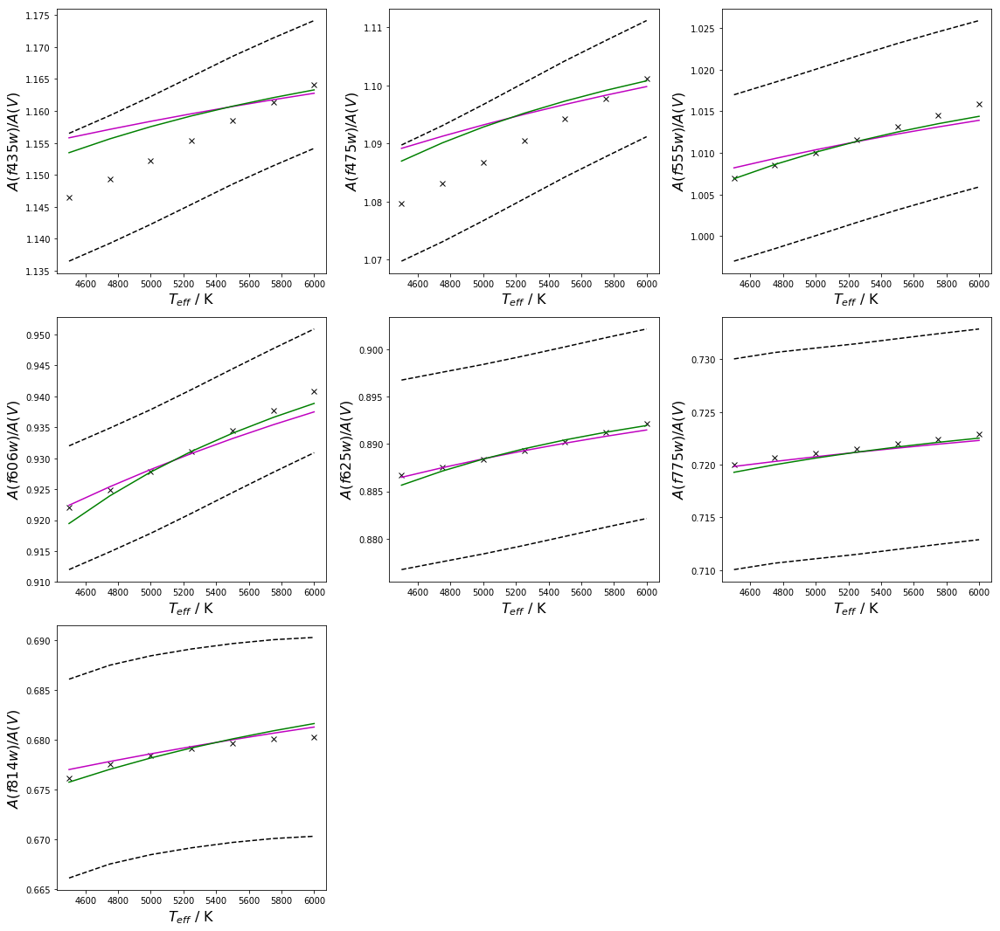


    Writing complete for log(g) = 0.0, Z = 0p0 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 5.0
Deleting missing subplots - discrepancy between 7 and 9


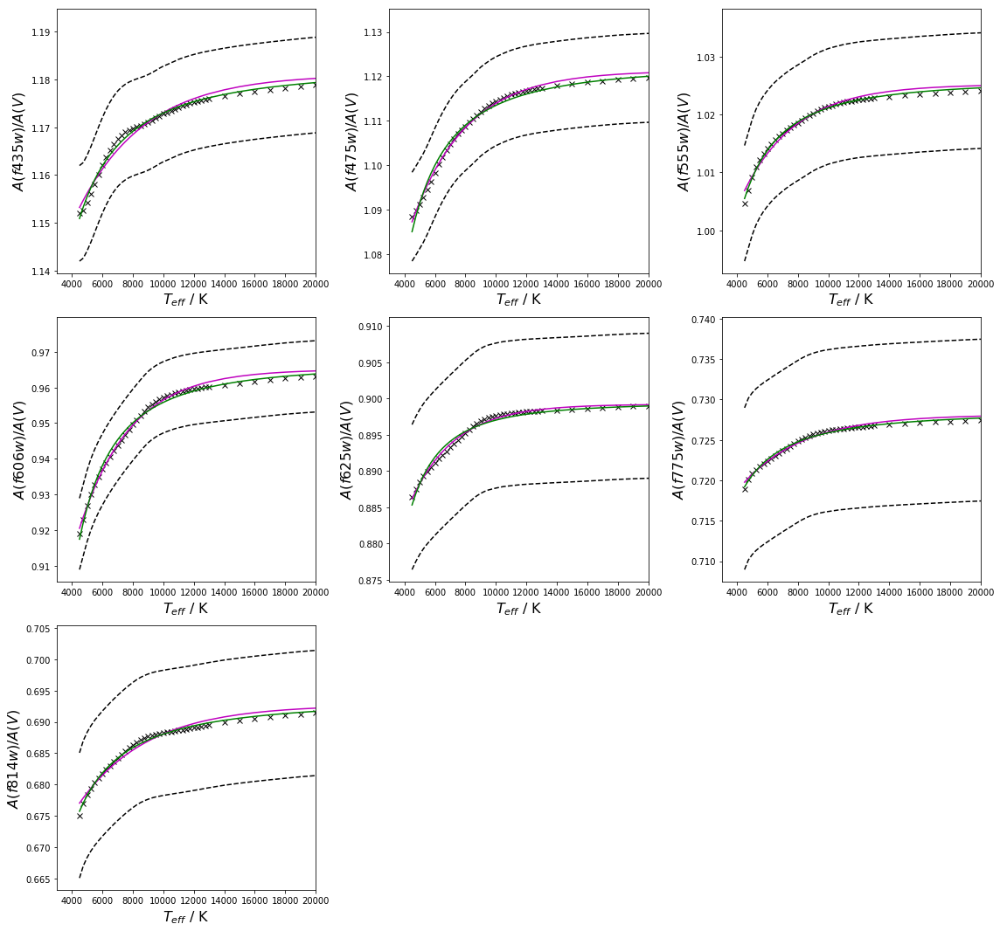


    Writing complete for log(g) = 5.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 4.5
Exponential fit coefficients (should be reused): 
[-0.0773 -2.2691  1.181 ]
Standard deviations (should be reused): 
[ 0.034   0.7394  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.01   -1.4647  1.1829]
Standard deviations (should be reused): 
[ 0.0043  0.555   0.0031]
Logistic fit coefficients: 
[  1.9081e-13   2.6512e+00   1.1809e+00   1.0638e+00]
Standard deviations: 
[  3.7343e+04   2.8162e+00   1.8804e-03   7.9985e-01]
Teff log-normal fit coefficients: 
[-2.      0.5125  1.1706  1.159 ]
Standard deviations: 
[ 0.      0.2789  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


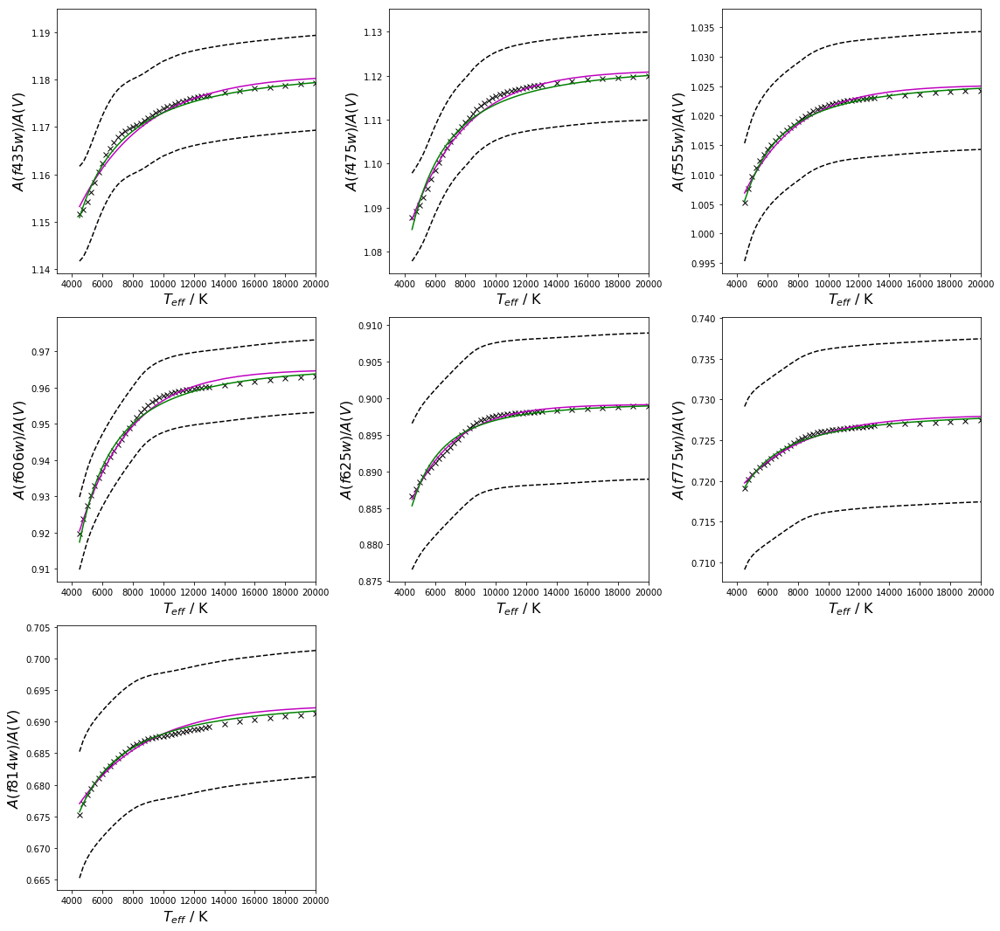


    Writing complete for log(g) = 4.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 4.0
Exponential fit coefficients (should be reused): 
[-0.0773 -2.2691  1.181 ]
Standard deviations (should be reused): 
[ 0.034   0.7394  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.01   -1.4647  1.1829]
Standard deviations (should be reused): 
[ 0.0043  0.555   0.0031]
Logistic fit coefficients: 
[  1.9081e-13   2.6512e+00   1.1809e+00   1.0638e+00]
Standard deviations: 
[  3.7343e+04   2.8162e+00   1.8804e-03   7.9985e-01]
Teff log-normal fit coefficients: 
[-2.      0.5125  1.1706  1.159 ]
Standard deviations: 
[ 0.      0.2789  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


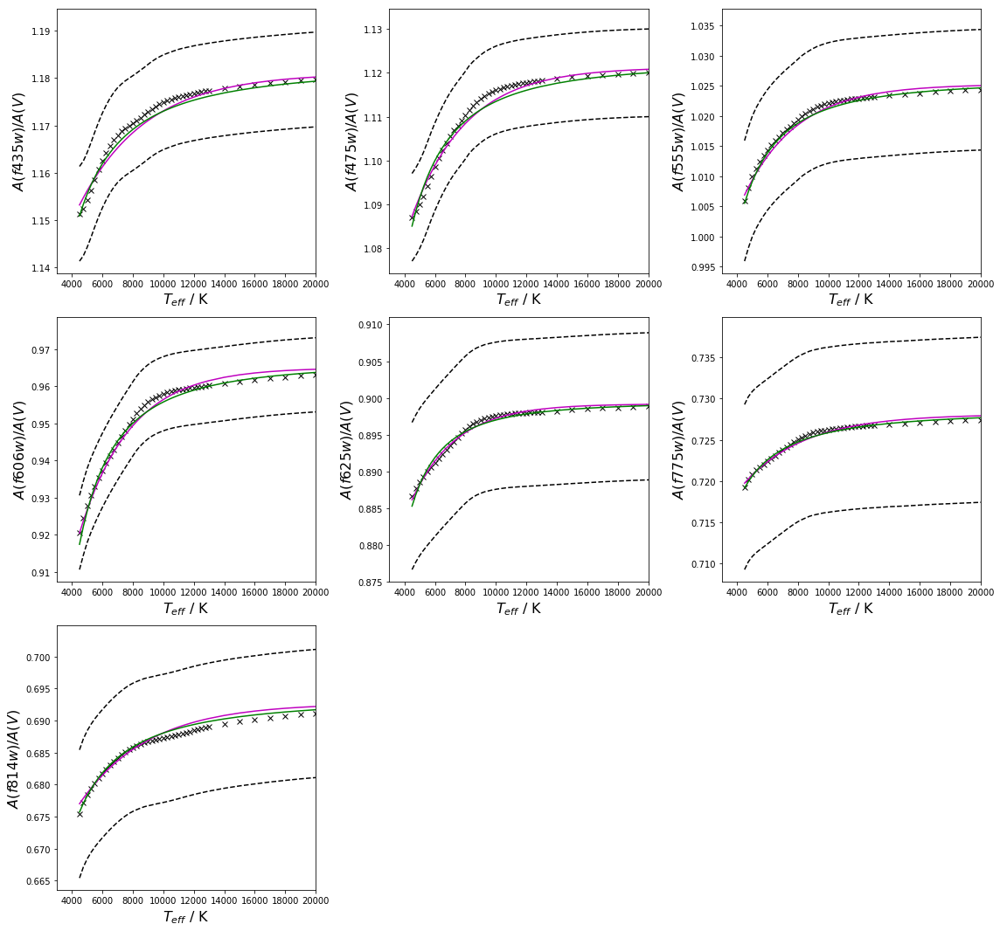


    Writing complete for log(g) = 4.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 3.5
Exponential fit coefficients (should be reused): 
[-0.0773 -2.2691  1.181 ]
Standard deviations (should be reused): 
[ 0.034   0.7394  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.01   -1.4647  1.1829]
Standard deviations (should be reused): 
[ 0.0043  0.555   0.0031]
Logistic fit coefficients: 
[  1.9081e-13   2.6512e+00   1.1809e+00   1.0638e+00]
Standard deviations: 
[  3.7343e+04   2.8162e+00   1.8804e-03   7.9985e-01]
Teff log-normal fit coefficients: 
[-2.      0.5125  1.1706  1.159 ]
Standard deviations: 
[ 0.      0.2789  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


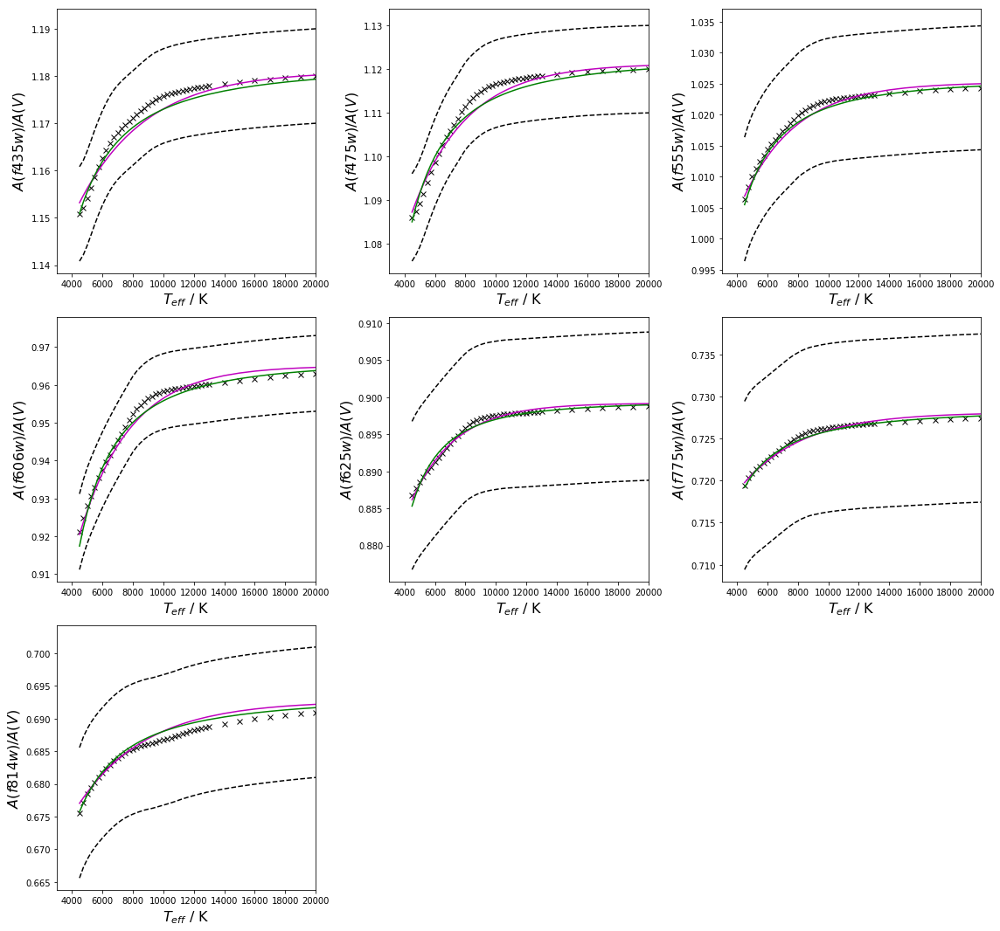


    Writing complete for log(g) = 3.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 3.0
Exponential fit coefficients (should be reused): 
[-0.0773 -2.2691  1.181 ]
Standard deviations (should be reused): 
[ 0.034   0.7394  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.01   -1.4647  1.1829]
Standard deviations (should be reused): 
[ 0.0043  0.555   0.0031]
Logistic fit coefficients: 
[  1.9081e-13   2.6512e+00   1.1809e+00   1.0638e+00]
Standard deviations: 
[  3.7343e+04   2.8162e+00   1.8804e-03   7.9985e-01]
Teff log-normal fit coefficients: 
[-2.      0.5125  1.1706  1.159 ]
Standard deviations: 
[ 0.      0.2789  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


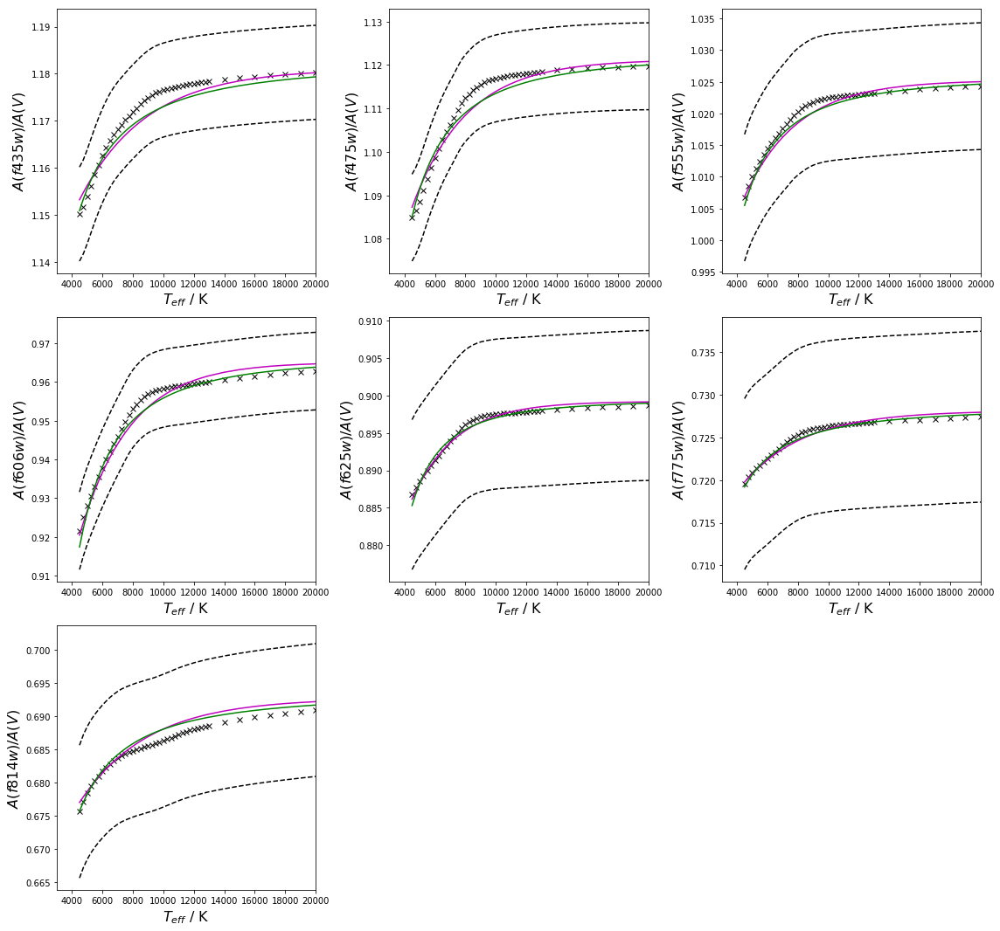


    Writing complete for log(g) = 3.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 2.5
Exponential fit coefficients (should be reused): 
[-0.0773 -2.2691  1.181 ]
Standard deviations (should be reused): 
[ 0.034   0.7394  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.01   -1.4647  1.1829]
Standard deviations (should be reused): 
[ 0.0043  0.555   0.0031]
Logistic fit coefficients: 
[  1.9081e-13   2.6512e+00   1.1809e+00   1.0638e+00]
Standard deviations: 
[  3.7343e+04   2.8162e+00   1.8804e-03   7.9985e-01]
Teff log-normal fit coefficients: 
[-2.      0.5125  1.1706  1.159 ]
Standard deviations: 
[ 0.      0.2789  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


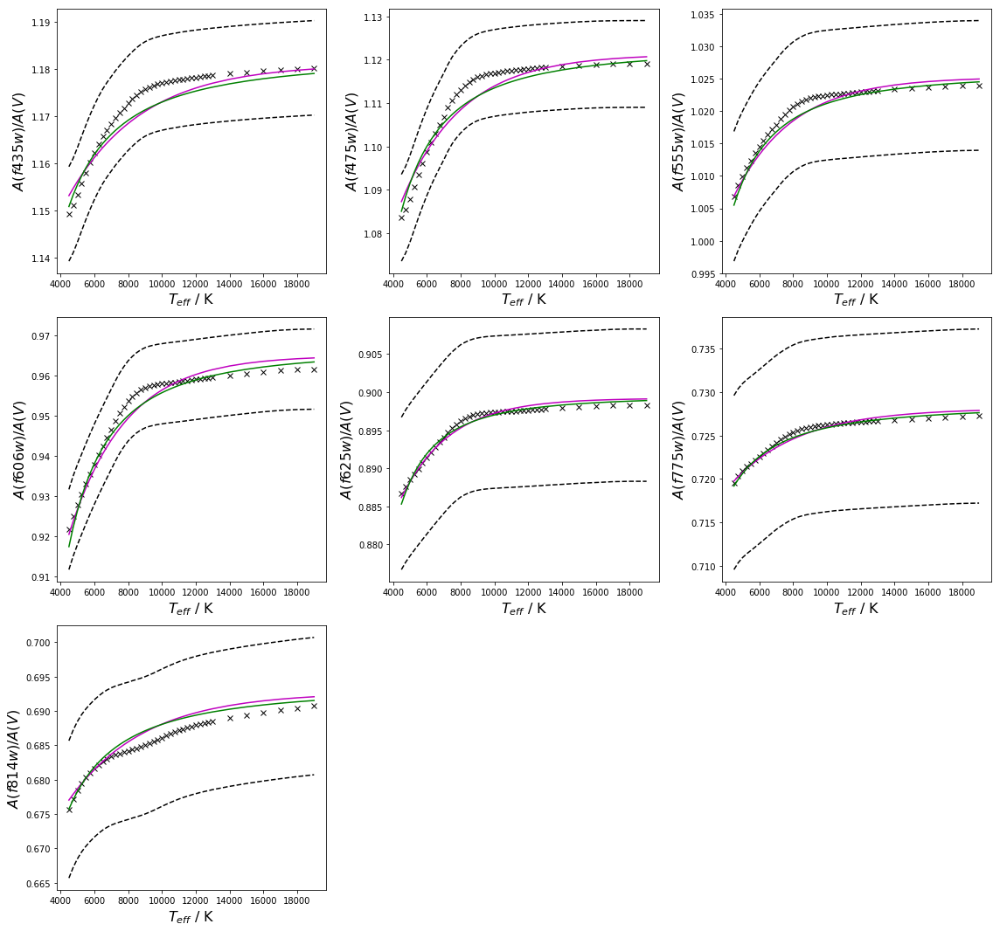


    Writing complete for log(g) = 2.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 2.0
Exponential fit coefficients (should be reused): 
[-0.0773 -2.2691  1.181 ]
Standard deviations (should be reused): 
[ 0.034   0.7394  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.01   -1.4647  1.1829]
Standard deviations (should be reused): 
[ 0.0043  0.555   0.0031]
Logistic fit coefficients: 
[  1.9081e-13   2.6512e+00   1.1809e+00   1.0638e+00]
Standard deviations: 
[  3.7343e+04   2.8162e+00   1.8804e-03   7.9985e-01]
Teff log-normal fit coefficients: 
[-2.      0.5125  1.1706  1.159 ]
Standard deviations: 
[ 0.      0.2789  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


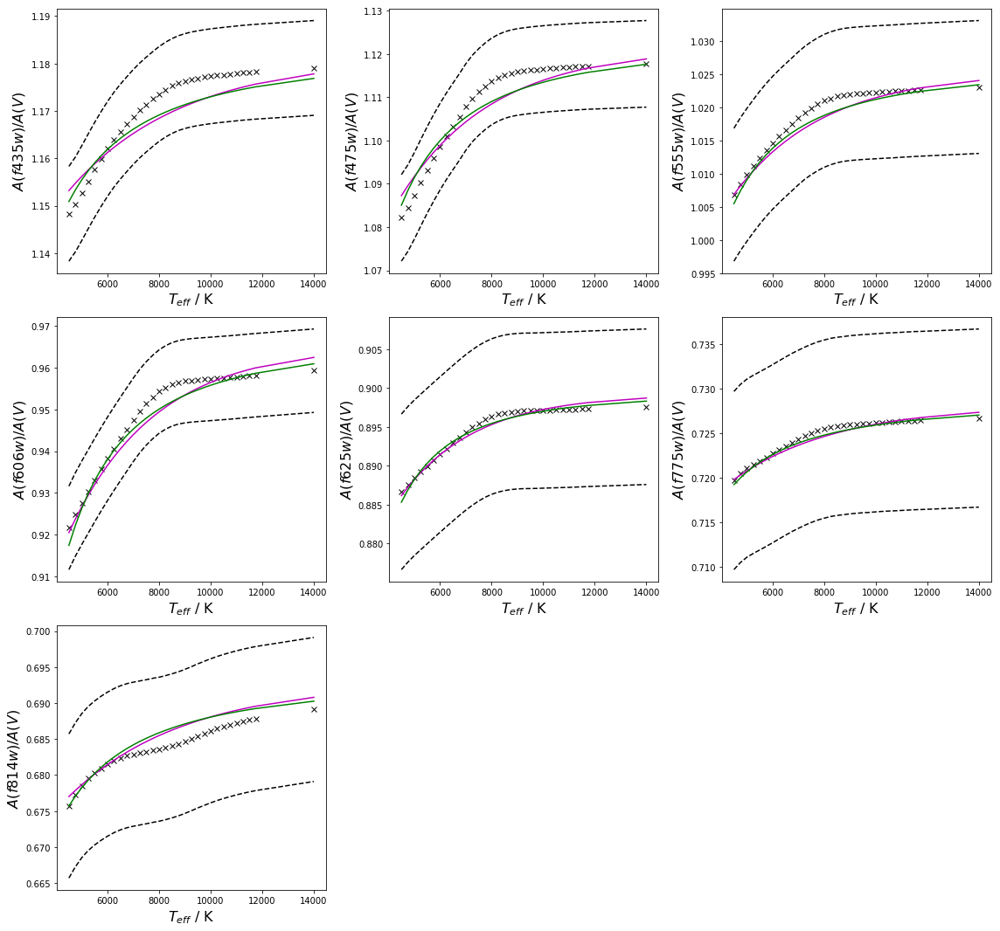


    Writing complete for log(g) = 2.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 1.5
Exponential fit coefficients (should be reused): 
[-0.0773 -2.2691  1.181 ]
Standard deviations (should be reused): 
[ 0.034   0.7394  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.01   -1.4647  1.1829]
Standard deviations (should be reused): 
[ 0.0043  0.555   0.0031]
Logistic fit coefficients: 
[  1.9081e-13   2.6512e+00   1.1809e+00   1.0638e+00]
Standard deviations: 
[  3.7343e+04   2.8162e+00   1.8804e-03   7.9985e-01]
Teff log-normal fit coefficients: 
[-2.      0.5125  1.1706  1.159 ]
Standard deviations: 
[ 0.      0.2789  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


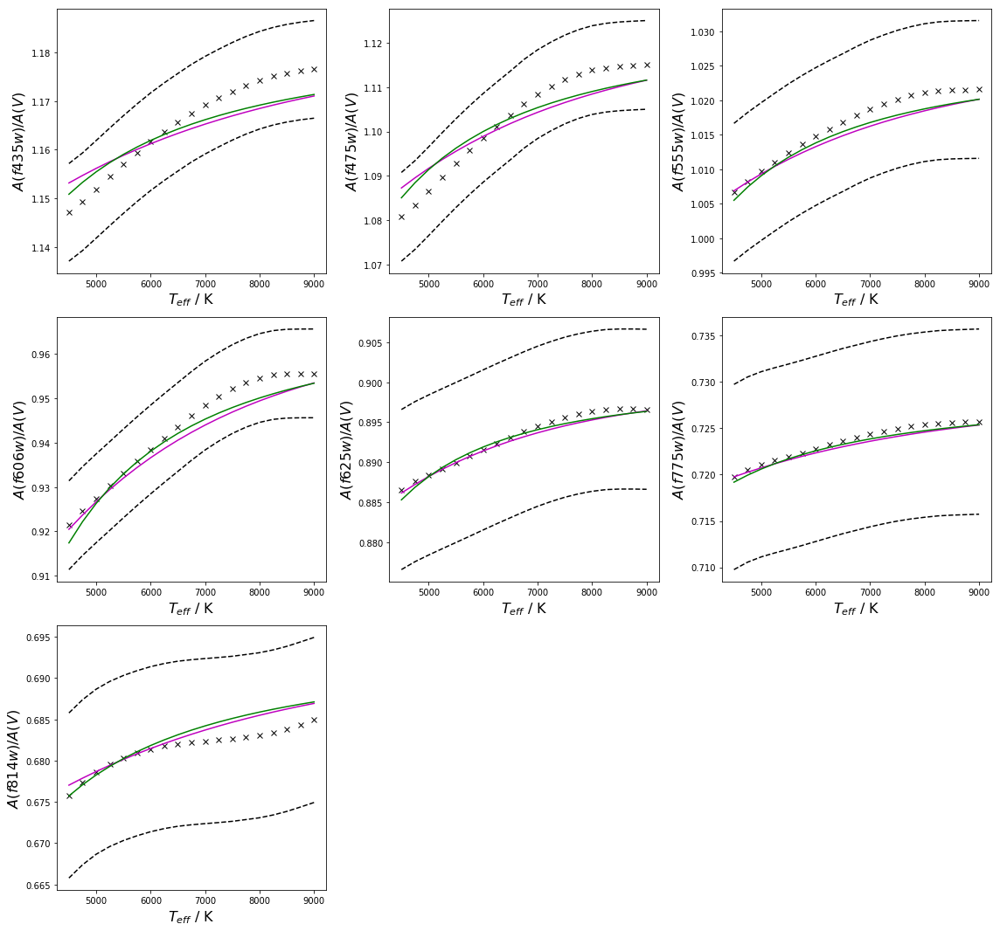


    Writing complete for log(g) = 1.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 1.0
Exponential fit coefficients (should be reused): 
[-0.0773 -2.2691  1.181 ]
Standard deviations (should be reused): 
[ 0.034   0.7394  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.01   -1.4647  1.1829]
Standard deviations (should be reused): 
[ 0.0043  0.555   0.0031]
Logistic fit coefficients: 
[  1.9081e-13   2.6512e+00   1.1809e+00   1.0638e+00]
Standard deviations: 
[  3.7343e+04   2.8162e+00   1.8804e-03   7.9985e-01]
Teff log-normal fit coefficients: 
[-2.      0.5125  1.1706  1.159 ]
Standard deviations: 
[ 0.      0.2789  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


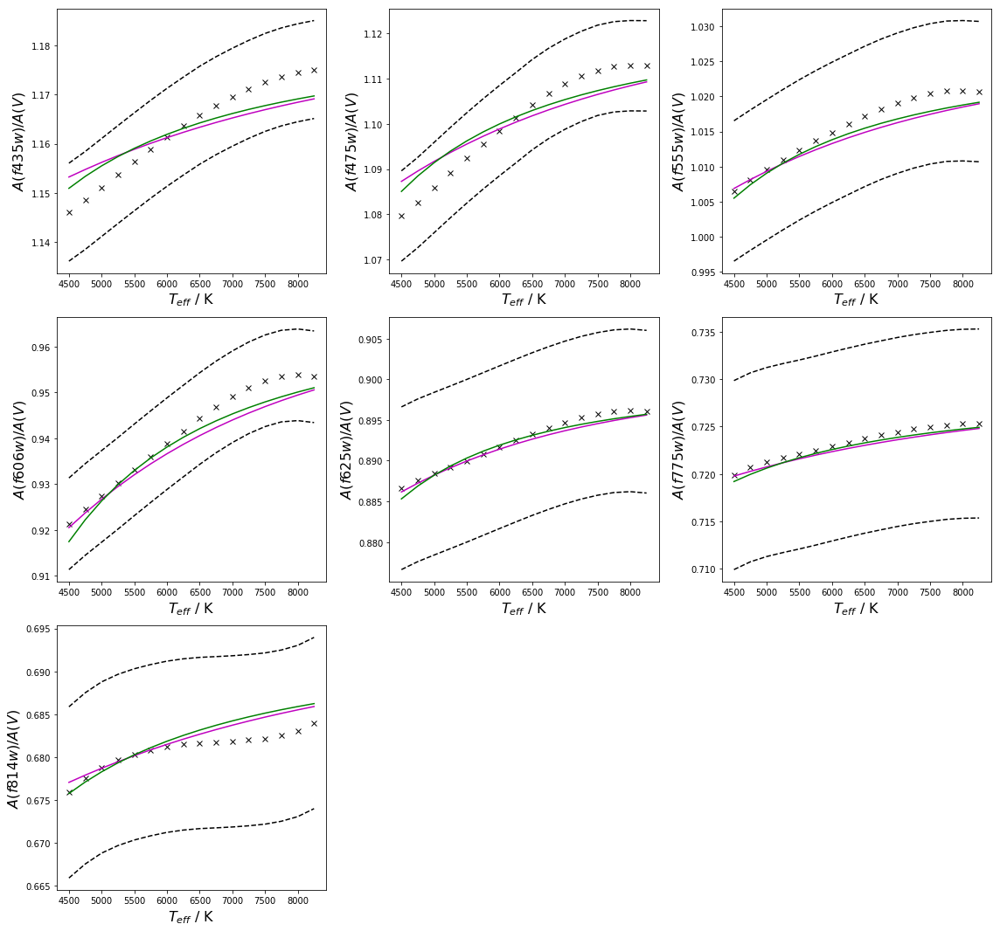


    Writing complete for log(g) = 1.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 0.5
Exponential fit coefficients (should be reused): 
[-0.0773 -2.2691  1.181 ]
Standard deviations (should be reused): 
[ 0.034   0.7394  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.01   -1.4647  1.1829]
Standard deviations (should be reused): 
[ 0.0043  0.555   0.0031]
Logistic fit coefficients: 
[  1.9081e-13   2.6512e+00   1.1809e+00   1.0638e+00]
Standard deviations: 
[  3.7343e+04   2.8162e+00   1.8804e-03   7.9985e-01]
Teff log-normal fit coefficients: 
[-2.      0.5125  1.1706  1.159 ]
Standard deviations: 
[ 0.      0.2789  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


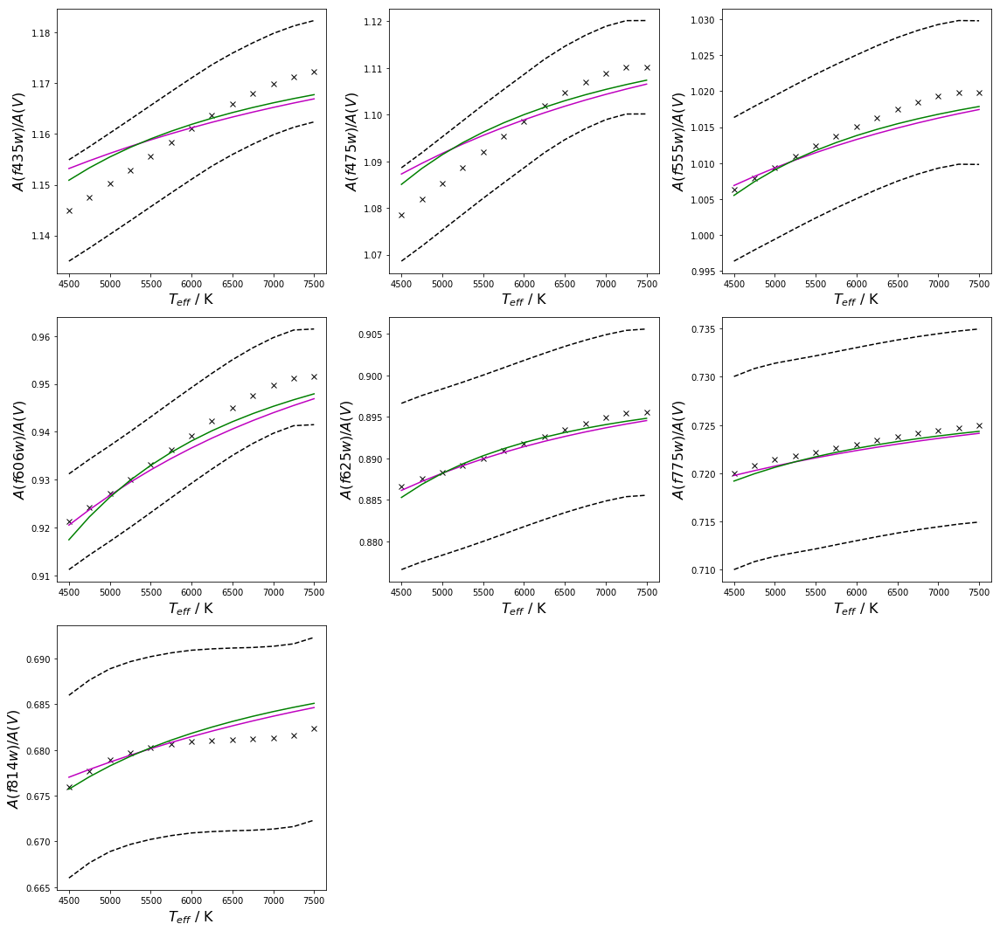


    Writing complete for log(g) = 0.5, Z = 0p5 configuration, END OF FUNCTION WRITING!!!


6.0,0.5 , 0.0
Exponential fit coefficients (should be reused): 
[-0.0773 -2.2691  1.181 ]
Standard deviations (should be reused): 
[ 0.034   0.7394  0.0018]
Teff^(n) fit coefficients (should be reused): 
[-0.01   -1.4647  1.1829]
Standard deviations (should be reused): 
[ 0.0043  0.555   0.0031]
Logistic fit coefficients: 
[  1.9081e-13   2.6512e+00   1.1809e+00   1.0638e+00]
Standard deviations: 
[  3.7343e+04   2.8162e+00   1.8804e-03   7.9985e-01]
Teff log-normal fit coefficients: 
[-2.      0.5125  1.1706  1.159 ]
Standard deviations: 
[ 0.      0.2789  0.0015  0.0039]



Deleting missing subplots - discrepancy between 7 and 9


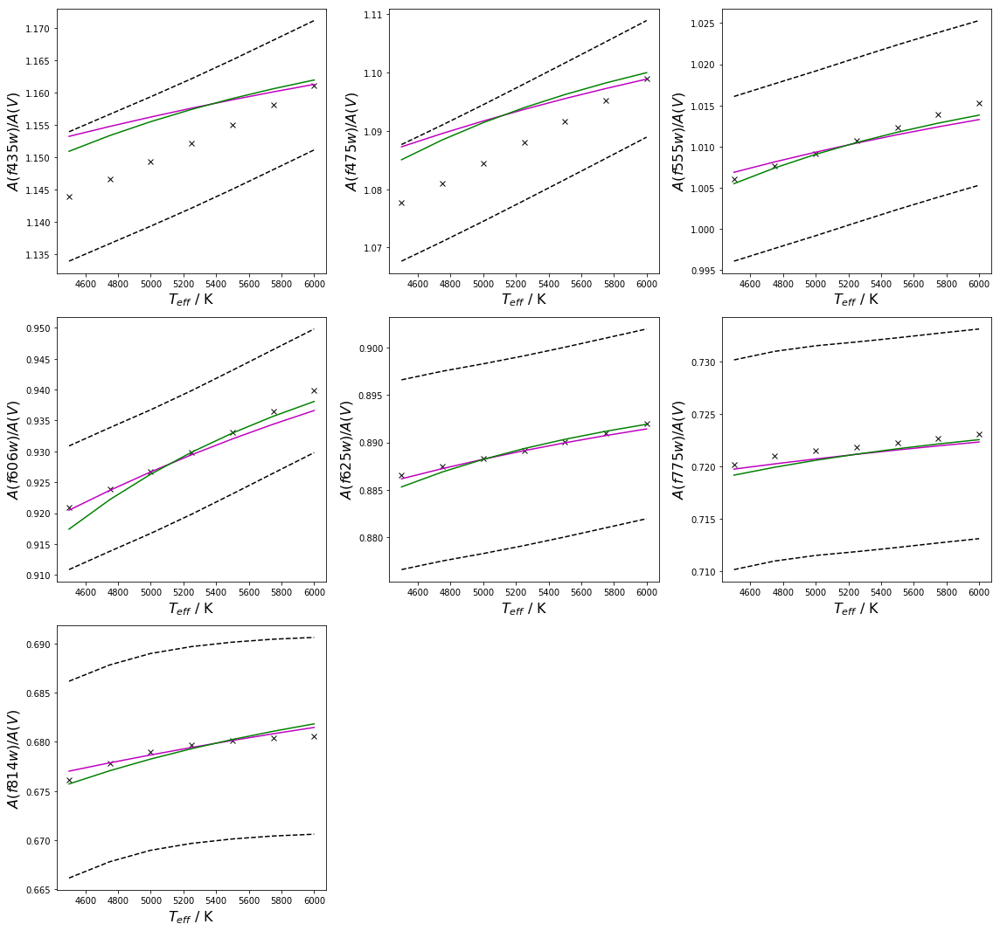


    Writing complete for log(g) = 0.0, Z = 0p5 configuration, END OF FUNCTION WRITING!!!
plotter writer complete


In [36]:
# If finished fitting (i.e. log(g) not equal to 5.0), DON'T run previous cell!!!

add_string = 'abs_sigmas_'+str(ACS_sigma_val)+'_0.01_bounds'
# 4500K_
# Test solar metallicity fit on ALL metallicity scenarios
for keyvals in sorted(ACS_Ax_Av_dict_4500K.iterkeys()):
    find_metal = re.search(',(.*)',keyvals)
    if find_metal:
        metal = str(find_metal.group(1))
    find_Rv = re.search('(.*),',keyvals)
    if find_Rv:
        Rv = str(find_Rv.group(1))
    for gkey in reversed(sorted(ACS_Ax_Av_dict_4500K[keyvals].iterkeys())):
        print '\n'
        print keyvals+' , '+gkey
        filter_curve_plot_write(ACS_Ax_Av_dict_4500K[keyvals],ACS_list_coef_stdev_zs_4500K[keyvals],gkey,Rv,metal,add_string,\
                                acs_filter_str,var_names_ACS,ACS_sigma_val,'Rv_varied/models_fit/ACS','','n','y',\
                                zoom_min=3000,zoom_max=20000,coef_cut='_4500',write_stuff='y')#,save_stuff='n')#,plot_diff='y')#
#  ,write_stuff='y'
#,4000,15000
#,4400,6000
print 'plotter writer complete'

In [5]:
# 4 input parameters (Teff,g,FeH,Rv)
all4pars_it = 0
npars = 4
big_data_arr = np.array([], dtype=np.float64).reshape(0,(16+npars))
print big_data_arr.shape
# Style of dictionaries: comb_Ax_Av_dict_4500K[found_Rv+','+found_metal]
for Rz_key in sorted(comb_Ax_Av_dict.iterkeys()):
    print Rz_key
    data_dict_zk = comb_Ax_Av_dict[Rz_key]
    
    find_Rv = re.search('(.*),',Rz_key)
    if find_Rv:
        Rv = str(find_Rv.group(1))
    find_metal = re.search(',(.*)',Rz_key)
    if find_metal:
        metal = str(find_metal.group(1))
    
    for gkey in sorted(data_dict_zk.iterkeys()):
        all4pars_it += 1
        data_dict_at_1g1z = data_dict_zk[gkey]
        test_arr = np.insert(data_dict_at_1g1z,2,float(metal),axis=1)
        #print test_arr.shape
        test_arr = np.insert(test_arr,3,float(Rv),axis=1)
        print test_arr.shape
        big_data_arr = np.concatenate((big_data_arr,test_arr),axis=0)
    #print big_data_arr.shape,'\n'
print all4pars_it
print big_data_arr.shape
print big_data_arr[0:8,:]

sigma_corr_log = np.full( (len(big_data_arr[:,0])) , 0.1 )
#sigma_corr2_45[0] = 0.01
print sigma_corr_log.shape
print sigma_corr_log[0:4]
print 'ready to run'

(0L, 20L)
2.0,-1.0
(11L, 20L)
(17L, 20L)
(20L, 20L)
(23L, 20L)
(35L, 20L)
(45L, 20L)
(52L, 20L)
(57L, 20L)
(65L, 20L)
(75L, 20L)
(76L, 20L)
2.0,-2.0
(11L, 20L)
(17L, 20L)
(20L, 20L)
(23L, 20L)
(35L, 20L)
(45L, 20L)
(52L, 20L)
(57L, 20L)
(65L, 20L)
(75L, 20L)
(76L, 20L)
2.0,0.0
(11L, 20L)
(17L, 20L)
(20L, 20L)
(23L, 20L)
(35L, 20L)
(45L, 20L)
(52L, 20L)
(57L, 20L)
(65L, 20L)
(75L, 20L)
(76L, 20L)
2.0,0.5
(11L, 20L)
(17L, 20L)
(20L, 20L)
(23L, 20L)
(35L, 20L)
(45L, 20L)
(52L, 20L)
(57L, 20L)
(65L, 20L)
(75L, 20L)
(76L, 20L)
3.1,-1.0
(11L, 20L)
(17L, 20L)
(20L, 20L)
(23L, 20L)
(35L, 20L)
(45L, 20L)
(52L, 20L)
(57L, 20L)
(65L, 20L)
(75L, 20L)
(76L, 20L)
3.1,-2.0
(11L, 20L)
(17L, 20L)
(20L, 20L)
(23L, 20L)
(35L, 20L)
(45L, 20L)
(52L, 20L)
(57L, 20L)
(65L, 20L)
(75L, 20L)
(76L, 20L)
3.1,0.0
(11L, 20L)
(17L, 20L)
(20L, 20L)
(23L, 20L)
(35L, 20L)
(45L, 20L)
(52L, 20L)
(57L, 20L)
(65L, 20L)
(75L, 20L)
(76L, 20L)
3.1,0.5
(11L, 20L)
(17L, 20L)
(20L, 20L)
(23L, 20L)
(35L, 20L)
(45L, 20L)
(52L, 20L

In [ ]:
# editing 'multi_param_plotter' from main stuff

# input data style comb_Ax_Av_dict['6.0,0.0']['0.0']

def all4param_plotter(all4params_dict,met_coeffs_filterwise,\
                        func,Tref,extras,label_extras,R1_diff_hline='n',save_fig='y',\
                        zoom_min=None,zoom_max=None,nfilters=4):
    if (zoom_min is not None and zoom_max is not None):
        extras += ('_zoom_' + str(int(zoom_min)) + '_' + str(int(zoom_max)))
    #keyval = '0.0'

    #nrows=4,ncols=4
    if (nfilters == 4):
        fig,dax = plt.subplots(nrows=2,ncols=2,figsize=(16, 16))
    elif (nfilters == 16):
        fig,dax = plt.subplots(nrows=4,ncols=4,figsize=(16, 16))
    else:
        fig,dax = plt.subplots(nrows=nfilters,ncols=1,figsize=(16, 16))
    dax = dax.ravel()
        # len(big_data_arr[0,:])

        for i in range(3,(3+nfilters)):
            coeffs_i = met_coeffs_filterwise[i-3]
            #  _exp   _exp_plg   _logg_x_exp   _2xexp
            #R2_Tmin R2_Tmax
            #result_curve_zs = weighted_damped_oscillator_gZ((zs_data_arr[:,0],zs_data_arr[:,1],zs_data_arr[:,2]), R2_Tmax, *coeffs_i)
            print comb_filter_str[i-3]+ ' filter:'
            print 'log(g) = '+keyval
            print '\n'
            
            result_curve_zs = func((zs_data_arr_45[:,0],zs_data_arr_45[:,1],zs_data_arr_45[:,2]),*coeffs_i)
            result_curve_z1 = func((z1_data_arr_45[:,0],z1_data_arr_45[:,1],z1_data_arr_45[:,2]),*coeffs_i)
            result_curve_z2 = func((z2_data_arr_45[:,0],z2_data_arr_45[:,1],z2_data_arr_45[:,2]),*coeffs_i)
            result_curve_zh = func((zh_data_arr_45[:,0],zh_data_arr_45[:,1],zh_data_arr_45[:,2]),*coeffs_i)
            
            if (R1_diff_hline == 'n'):
                dax[i-3].plot(zs_data_arr_45[:,0],result_curve_zs,'r',linestyle='--',label='[Fe/H]=0.0'+label_extras+' result')
                dax[i-3].plot(zs_data_arr_45[:,0],zs_data_arr_45[:,i],'r',marker='x',linestyle='',label='[Fe/H]=0.0 data')

                
                #dax[i-3].plot(zs_data_arr_45[:,0],zs_data_arr_45[:,i]+0.15,color='m',linestyle='--')
                #dax[i-3].plot(zs_data_arr_45[:,0],zs_data_arr_45[:,i]-0.15,color='m',linestyle='--')
                if (R2_model_follow == 'y'):
                    dax[i-3].plot(zs_data_arr_45[:,0],result_curve_zs + 0.1,color='m',linestyle='-.')
                    dax[i-3].plot(zs_data_arr_45[:,0],result_curve_zs - 0.1,color='m',linestyle='-.')
                else:
                    dax[i-3].axhline(y=0,color='k')
                    #dax[i-3].axhline(y=0.15,color='m',linestyle='--')
                    #dax[i-3].axhline(y=-0.15,color='m',linestyle='--')
                    dax[i-3].axhline(y=0.1,color='m',linestyle='-.')
                    dax[i-3].axhline(y=-0.1,color='m',linestyle='-.')
                dax[i-3].set_xlabel(var_names_comb[0])
                dax[i-3].set_ylabel(var_names_comb[i-1])
            else:
                dax[i-3].plot(zs_data_arr_45[:,0],zs_data_arr_45[:,i] - result_curve_zs,'r',marker='x',linestyle='',label='Zsolar data - exp result')
                dax[i-3].plot(z2_data_arr_45[:,0],z2_data_arr_45[:,i] - result_curve_z2,'g',marker='x',linestyle='',label='Zsolar/100 data - exp result')
                dax[i-3].plot(z1_data_arr_45[:,0],z1_data_arr_45[:,i] - result_curve_z1,'b',marker='x',linestyle='',label='Zsolar/10 data - exp result')
                dax[i-3].plot(zh_data_arr_45[:,0],zh_data_arr_45[:,i] - result_curve_zh,'y',marker='x',linestyle='',label='Zsolar*3 data - exp result')
                dax[i-3].set_xlabel(var_names_comb[0])
                dax[i-3].set_ylabel(var_names_comb[i-1] + ' - $A_{2}(T,g,Z)$')
                dax[i-3].axhline(y=0,color='k')
                #dax[i-3].axhline(y=0.15,color='m',linestyle='--')
                #dax[i-3].axhline(y=-0.15,color='m',linestyle='--')
                dax[i-3].axhline(y=0.1,color='m',linestyle='-.')
                dax[i-3].axhline(y=-0.1,color='m',linestyle='-.')
            if (zoom_min is not None and zoom_max is not None):
                if (max(z1_data_arr_45[:,0]) > zoom_max):
                    dax[i-3].set_xlim(zoom_min,zoom_max)
        plt.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0))
        plt.show()
        #weighted_   _exp_plg  _logg_x_exp  _2xexp
        if (save_fig=='y'):
            fig.savefig('results_metal_exp_R2/'+extras+'_plots_1st_4filters_logg_'+keyval+'_all_z.pdf')
    
print 'both metal exponential plus log(g) term loaded'